# VoltRelay Energy: what is really driving service failures, rider churn and margin erosion?
**Team Praise** · Shubham Suman & Durgesh Kumar · Gradient Learnings Data Analytics Hackathon · 15 November 2026

This notebook is the complete, reproducible analysis behind our report and video. It downloads the organisers' data,
cleans it with an audited pipeline, answers the six core questions plus five deep dives, and ends with our
recommendations for VoltRelay's next operating budget. **Runtime:** about 3 minutes of computation (≈10-15 minutes on a standard Colab CPU runtime, most of it downloading the 0.85 GB of data).

**How to read it:** every section opens with the question and the answer in plain words, then shows the evidence.
Charts are titled with their insight. Numbers quoted in the text are printed by the code cell above or below them.


## Executive summary

> **VoltRelay's growth is real, two of its three alarms are misread, and the third is real but fixable.** Completed swaps grew
> **2.43×** and revenue **2.63×** year on year. Like-for-like, service failures did **not** get worse, and new-rider retention did
> **not** fall: both move with the summer heat. Margin erosion **is** real, and one defective battery batch explains most of it.
> Two equipment problems, not growth, drive most of the damage.

| Leadership's alarm | What the evidence says | Key numbers |
|---|---|---|
| "Service failures rose faster than swaps" | **Seasonal artefact.** Same-season failures grew more slowly than swaps; at the same 90 stations the April–June rate is unchanged. The network average fell only because new stations dilute it. | H1 failure rate 7.04% → 6.06%; same stations 9.52% → 9.55% |
| "New-rider retention fell" | **Not structurally.** Same-season cohorts retain identically; the dip is summer-entry cohorts hit by early stockouts. | 86.3% vs 86.3% (p = 0.98) |
| "Per-swap profitability eroded" | **Real.** Kyron lots KY-2407/08/09 lose health 3.8× faster at the same price; their wear erased the July-2024 price gain. | cm1 +₹6.75 → −₹7.53 per swap; Kyron wear −₹16.8/swap |

**Primary drivers**
1. **Heat × Gen1 chargers → failures**: 36 Gen1 stations in Delhi NCR, Jaipur and Hyderabad produce 77–80% of excess failures in
   April–June. Above ~41 °C their charge time climbs steeply, nearly doubling by 50 °C (88 → ~168 min), and stockouts rise 5×.
2. **Early failures → churn**: 2+ failed swap attempts in a rider's first 14 days → 22.6% vs 13.1% not active in days 31–60 (OR 1.67).
3. **Defective battery lots → margin**: ≈ ₹16.8 per swap of extra wear; 122,204 swaps issued packs below end-of-life.

**Budget decision**: (a) more stations: **reject** as a service fix; (b) more batteries: **reject**, replace instead;
(c) network-wide peak pricing: **support** as a revenue measure (≈ ₹9.5 lakh a month); (d) ZipDrop exclusive: **reject** on current terms.
**Fund instead**: battery quality reset and fleet renewal, a Gen1 thermal fix (19–27K fewer failures per summer), new-rider failure
recovery and contract re-terms. The battery reset and the pricing and partner re-terms alone take **cm2 per swap from −₹18.5 to
about +₹6.8**; the Gen1 fix and new-rider recovery cut failures and churn.

*Data quality*: 26 checks, 13 issues the documentation does not mention. Every analysis was independently re-derived by a second
analyst with separate code before conclusions were drawn.


## Contents
0. Setup & data acquisition
1. Data understanding (inventory, profile, referential integrity)
2. Data cleaning (9 documented + 13 undocumented issues, each detected, quantified and decided)
3. Data-quality audit & anomalies (impact of every cleaning decision)
4. Problem framing (what changed in 18 months; hypothesis tree)
5. **Q1** Network performance over time
6. **Q2** Service failures & customer experience
7. **Q3** Station & geographic patterns (+ expansion-wave effectiveness, competitor entry)
8. **Q4** Battery & equipment performance
9. **Q5** Pricing & partner economics (+ fleet-partner value)
10. **Q6** Root-cause analysis of new-rider retention
11. Deep dive: support-ticket text (English + Hinglish)
12. Synthesis: primary vs secondary drivers, the budget decision, recommendations
13. Conclusions and recommendations


## 0. Setup & data acquisition

In [1]:
# Environment setup - works on Google Colab and locally
import sys, os, subprocess, importlib
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'polars>=1.30', 'lifelines', 'gdown', 'shap', 'lightgbm'], check=True)
    PROJECT_ROOT = Path('/content/voltrelay')
else:
    _here = Path(os.environ.get('VOLTRELAY_ROOT', Path.cwd()))
    # run from anywhere inside the project (e.g. deliverables/1_Colab_Notebook): walk up to the project root
    PROJECT_ROOT = next((c for c in [_here, *_here.parents] if (c / 'src' / 'common.py').exists() or (c / 'Hackathon Data Set _ Gradient').exists()), _here)
for sub in ['src', 'analysis', 'data/parquet', 'data/clean', 'outputs/figures', 'outputs/tables', 'outputs/findings', 'Hackathon Data Set _ Gradient']:
    (PROJECT_ROOT / sub).mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Project root: F:\Data Analytics Gradient Learning | Colab: False


### Shared module: paths, business constants, loaders and chart style
Every analysis below imports these definitions so that cleaning rules, the cost model and colours are identical across questions.

In [2]:
%%writefile src/common.py
"""Shared paths, constants, loaders and plotting style for the VoltRelay analysis.

Every analysis script imports from here so that definitions (cleaning, cost model, KPIs, colours) are identical
across all questions. Clean tables are produced by src/clean.py.
"""
from __future__ import annotations

import datetime as dt
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import polars as pl

ROOT = Path(__file__).resolve().parents[1]
RAW = ROOT / "Hackathon Data Set _ Gradient"
PARQ = ROOT / "data" / "parquet"
CLEAN = ROOT / "data" / "clean"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
FIND = ROOT / "outputs" / "findings"
for _p in (CLEAN, FIG, TAB, FIND):
    _p.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- business calendar / known interventions
WINDOW_START = dt.date(2024, 1, 1)
WINDOW_END = dt.date(2025, 6, 30)
BASE_PRICE_CHANGE = dt.date(2024, 7, 1)        # 2W list 60 -> 65, 3W list 100 -> 110 (all tariffs)
PILOT_START = dt.date(2024, 10, 1)             # peak / off-peak pricing pilot
PILOT_CITIES = ["Bengaluru", "Pune"]           # treated cities; other four are controls
ZIPDROP_ID = "FP-03"                           # ZipDrop: discount 12% -> 28% on 2024-11-01, peak surcharge NOT billable
ZIPDROP_AMEND = dt.date(2024, 11, 1)
COMPETITOR_ENTRY = dt.date(2025, 1, 15)        # 10 stations got a competitor within 1.5 km
FW_BUG_START = dt.datetime(2025, 3, 10, 0, 0, 0)
FW_BUG_END = dt.datetime(2025, 4, 15, 0, 0, 0)  # exclusive; logged ts in [start, end) on v3.2.0 are shifted
FW_BUG_SHIFT = "5h30m"
EOL_SOH = 70.0                                 # all retired packs have SoH < 70; all active packs >= 70
CITIES = ["Bengaluru", "Delhi NCR", "Hyderabad", "Pune", "Mumbai", "Jaipur"]
CITY_CODE = {"BLR": "Bengaluru", "DEL": "Delhi NCR", "HYD": "Hyderabad", "PUN": "Pune", "MUM": "Mumbai", "JAI": "Jaipur"}
EVENT_TYPES = ["swap_completed", "failed_no_charged_battery", "abandoned_queue", "cancelled_by_rider",
               "failed_system_error"]
FAIL_TYPES = ["failed_no_charged_battery", "abandoned_queue", "failed_system_error"]  # service failures
# Indian seasons (IMD-style): Winter Dec-Feb, Summer Mar-May, Monsoon Jun-Sep, Post-monsoon Oct-Nov
SEASON_OF_MONTH = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
                   6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}

# ---------------------------------------------------------------- loaders (lazy, projection-friendly)

def events(cols: list[str] | None = None) -> pl.LazyFrame:
    """Clean swap events (test stations removed, timestamps fixed, outliers flagged, costs attached)."""
    lf = pl.scan_parquet(CLEAN / "events.parquet")
    return lf.select(cols) if cols else lf


def hourly(cols: list[str] | None = None) -> pl.LazyFrame:
    lf = pl.scan_parquet(CLEAN / "station_hourly.parquet")
    return lf.select(cols) if cols else lf


def stations() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "stations.parquet")


def riders() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "riders.parquet")


def batteries() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "batteries.parquet")


def tickets() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "tickets.parquet")


def city_daily() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "city_daily.parquet")


def partners() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "fleet_partners.parquet")


def station_month() -> pl.DataFrame:
    return pl.read_parquet(CLEAN / "station_month.parquet")


# ---------------------------------------------------------------- plotting style
PALETTE = {
    "primary": "#1F4E79",   # deep blue  - main series
    "accent": "#E4572E",    # warm red   - problems / failures
    "good": "#2E8B57",      # green      - improvements
    "warn": "#F2A541",      # amber      - caution
    "muted": "#8C8C8C",     # grey       - context
    "light": "#D9E2EC",
}
SERIES = ["#1F4E79", "#E4572E", "#2E8B57", "#F2A541", "#6C4F9E", "#17A2B8", "#8C8C8C", "#B5651D"]
CITY_COLORS = dict(zip(CITIES, SERIES))
SUPPLIER_COLORS = {"Cellora": "#1F4E79", "Amptek": "#2E8B57", "Kyron": "#E4572E"}


def set_style():
    matplotlib.use("Agg")
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "font.family": "DejaVu Sans", "font.size": 10.5,
        "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelsize": 10.5, "axes.labelcolor": "#333333",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.edgecolor": "#888888", "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES),
        "legend.frameon": False, "legend.fontsize": 9.5,
        "xtick.color": "#555555", "ytick.color": "#555555",
    })


def save_fig(fig, name: str, subtitle: str | None = None, source: str | None = "Source: VoltRelay operational data, Jan 2024 - Jun 2025"):
    """Save a figure to outputs/figures/<name>.png with an optional source footnote."""
    if source:
        fig.text(0.01, -0.02, source, fontsize=8, color="#777777", ha="left", va="top")
    path = FIG / f"{name}.png"
    fig.savefig(path)
    plt.close(fig)
    try:  # inside a notebook, also display a light (palette-quantized) copy inline; no effect in plain scripts
        from IPython import get_ipython
        if get_ipython() is not None:
            import io as _io
            from PIL import Image as _PIL
            from IPython.display import Image as _Img, display as _disp
            _im = _PIL.open(path).convert("RGB"); _im.thumbnail((1300, 1300))
            _im = _im.quantize(colors=128, method=_PIL.Quantize.MEDIANCUT, dither=_PIL.Dither.NONE)
            _buf = _io.BytesIO(); _im.save(_buf, format="PNG", optimize=True)
            _disp(_Img(data=_buf.getvalue(), width=900))
    except Exception:
        pass
    return path


def fmt_inr(x: float) -> str:
    """Indian-style compact currency: 1.2 Cr, 3.4 L, 5.6K."""
    a = abs(x)
    if a >= 1e7:
        return f"₹{x/1e7:.2f} Cr"
    if a >= 1e5:
        return f"₹{x/1e5:.1f} L"
    if a >= 1e3:
        return f"₹{x/1e3:.1f}K"
    return f"₹{x:.0f}"


Overwriting src/common.py


In [3]:
import importlib, common
importlib.reload(common)
from common import *
set_style()
print('common loaded; clean dir =', CLEAN)

common loaded; clean dir = F:\Data Analytics Gradient Learning\data\clean


## 1. Data acquisition
The organisers' Google Drive folder is public. On Colab the eight CSVs (~0.85 GB) are downloaded with `gdown`; locally the existing copy is used. The raw CSVs are then converted once to typed, compressed Parquet (the 728 MB swap table becomes ~93 MB) so every later step reads only the columns it needs.

In [4]:
RAW_FILES = ['batteries.csv', 'city_daily_context.csv', 'fleet_partners.csv', 'riders.csv', 'station_hourly_status.csv',
             'stations.csv', 'support_tickets.csv', 'swap_events.csv']
DRIVE_FOLDER = 'https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df'
missing = [f for f in RAW_FILES if not (RAW / f).exists() and not (RAW / (f + '.gz')).exists()]
if missing:
    print('Downloading', missing)
    try:
        import gdown
        gdown.download_folder(DRIVE_FOLDER, output=str(RAW), quiet=False, remaining_ok=True)
    except Exception as e:
        print('Automatic download failed (Google Drive sometimes rate-limits large files):', e)
        print('Fallback: open the Drive folder link above -> Organize -> Add shortcut to My Drive, then run:')
        print("    from google.colab import drive; drive.mount('/content/drive')")
        print('and copy the 8 CSV files into', RAW, '(or upload them there with the Files panel). Then re-run this cell.')
        raise
# accept either .csv or .csv.gz deliveries
import gzip, shutil
for f in RAW_FILES:
    gz = RAW / (f + '.gz')
    if not (RAW / f).exists() and gz.exists():
        with gzip.open(gz, 'rb') as src, open(RAW / f, 'wb') as dst:
            shutil.copyfileobj(src, dst)
for f in RAW_FILES:
    p = RAW / f
    print(f'{f:28s} {p.stat().st_size/1e6:8.1f} MB')

batteries.csv                     0.6 MB
city_daily_context.csv            0.2 MB
fleet_partners.csv                0.0 MB
riders.csv                        2.1 MB
station_hourly_status.csv       108.4 MB
stations.csv                      0.0 MB
support_tickets.csv               6.5 MB
swap_events.csv                 728.7 MB


## 2. Data understanding
Eight related tables describe 18 months (Jan-2024 to Jun-2025) of a simulated battery-swapping network in six Indian cities.
We first convert the raw CSVs to typed Parquet (fast, column-projected reads), then profile every table and check that the
documented relationships actually hold before trusting any join.

In [5]:
import json, time, datetime as dt
import polars as pl
import sys
from pathlib import Path
from common import *

pl.Config.set_tbl_rows(25); pl.Config.set_tbl_cols(25); pl.Config.set_tbl_width_chars(200); pl.Config.set_fmt_str_lengths(50)

SWAP_SCHEMA = {
    "event_id": pl.Utf8, "rider_id": pl.Utf8, "station_id": pl.Utf8, "event_ts": pl.Utf8, "event_type": pl.Utf8,
    "attempt_seq": pl.Int16, "queue_wait_sec": pl.Int32, "battery_in_id": pl.Utf8, "battery_out_id": pl.Utf8,
    "soc_in_pct": pl.Float32, "soh_in_pct": pl.Float32, "soc_out_pct": pl.Float32, "soh_out_pct": pl.Float32,
    "km_since_last_swap": pl.Float32, "tariff_code": pl.Utf8, "list_price_inr": pl.Float32, "discount_inr": pl.Float32,
    "amount_charged_inr": pl.Float32, "payment_mode": pl.Utf8, "energy_to_recharge_kwh": pl.Float32,
    "station_firmware": pl.Utf8, "sync_mode": pl.Utf8}
HOURLY_SCHEMA = {
    "station_id": pl.Utf8, "hour_start": pl.Utf8, "charged_2w_avg": pl.Float32, "charged_2w_min": pl.Float32,
    "charged_3w_min": pl.Float32, "packs_charging": pl.Float32, "packs_quarantined": pl.Float32, "chargers_online": pl.Float32,
    "ambient_temp_c": pl.Float32, "cabinet_temp_c": pl.Float32, "avg_charge_minutes": pl.Float32, "outage_minutes": pl.Float32,
    "grid_kwh": pl.Float32, "telemetry_status": pl.Utf8}

def to_parquet_big(name, schema, ts_col):
    lf = pl.scan_csv(RAW / f"{name}.csv", schema=schema).with_columns(
        pl.col(ts_col).str.strptime(pl.Datetime("us"), "%Y-%m-%d %H:%M:%S", strict=False))
    lf.sink_parquet(PARQ / f"{name}.parquet", compression="zstd")

def to_parquet_small(name, date_cols=(), ts_cols=()):
    df = pl.read_csv(RAW / f"{name}.csv", infer_schema_length=None)
    for c in date_cols:
        df = df.with_columns(pl.col(c).cast(pl.Utf8).str.strptime(pl.Date, "%Y-%m-%d", strict=False))
    for c in ts_cols:
        df = df.with_columns(pl.col(c).cast(pl.Utf8).str.strptime(pl.Datetime("us"), "%Y-%m-%d %H:%M:%S", strict=False))
    df.write_parquet(PARQ / f"{name}.parquet", compression="zstd")

t = time.time()
PARQ.mkdir(parents=True, exist_ok=True)
to_parquet_small("stations", ["commissioned_date", "decommissioned_date", "firmware_updated_date", "competitor_within_1_5km_since"])
to_parquet_small("fleet_partners", ["contract_start_date", "amendment_date"])
to_parquet_small("riders", ["signup_date"])
to_parquet_small("batteries", ["manufacture_date", "commission_date", "retired_date"])
to_parquet_small("support_tickets", ts_cols=["created_ts"])
to_parquet_small("city_daily_context", ["date"])
to_parquet_big("station_hourly_status", HOURLY_SCHEMA, "hour_start")
to_parquet_big("swap_events", SWAP_SCHEMA, "event_ts")
print(f"CSV -> Parquet in {time.time()-t:.1f}s")
for f in sorted(PARQ.glob("*.parquet")):
    print(f"{f.name:32s} {f.stat().st_size/1e6:7.1f} MB")

CSV -> Parquet in 1.3s
batteries.parquet                    0.1 MB
city_daily_context.parquet           0.0 MB
fleet_partners.parquet               0.0 MB
riders.parquet                       0.1 MB
station_hourly_status.parquet       15.5 MB
stations.parquet                     0.0 MB
support_tickets.parquet              0.7 MB
swap_events.parquet                 92.8 MB


### 2.1 Table inventory
Row counts, grain and date coverage match the data dictionary (3,877,013 swap attempts; 1,487,712 station-hours;
20,000 riders; 6,500 batteries; 44,000 tickets; 152 stations; 3,282 city-days; 12 fleet partners).

In [6]:
TABLES = {"swap_events": "event_ts", "station_hourly_status": "hour_start", "riders": "signup_date", "batteries": "commission_date",
          "support_tickets": "created_ts", "stations": "commissioned_date", "city_daily_context": "date", "fleet_partners": "contract_start_date"}
inv = []
for name, dcol in TABLES.items():
    lf = pl.scan_parquet(PARQ / f"{name}.parquet")
    s = lf.select(pl.len().alias("rows"), pl.col(dcol).min().alias("min"), pl.col(dcol).max().alias("max")).collect()
    inv.append({"table": name, "rows": s["rows"][0], "columns": len(lf.collect_schema()), "date_field": dcol,
                "from": str(s["min"][0])[:10], "to": str(s["max"][0])[:10]})
inventory = pl.DataFrame(inv)
inventory

table,rows,columns,date_field,from,to
str,i64,i64,str,str,str
"""swap_events""",3877013,22,"""event_ts""","""2024-01-01""","""2025-06-30"""
"""station_hourly_status""",1487712,14,"""hour_start""","""2024-01-01""","""2025-06-30"""
"""riders""",20000,12,"""signup_date""","""2023-03-08""","""2025-06-30"""
"""batteries""",6500,13,"""commission_date""","""2023-03-01""","""2025-06-15"""
"""support_tickets""",44000,12,"""created_ts""","""2023-03-09""","""2025-07-01"""
"""stations""",152,22,"""commissioned_date""","""2023-06-01""","""2025-04-28"""
"""city_daily_context""",3282,12,"""date""","""2024-01-01""","""2025-06-30"""
"""fleet_partners""",12,12,"""contract_start_date""","""2023-04-01""","""2024-04-01"""


### 2.2 Column profile (nulls, cardinality, ranges)
Nulls are expected and informative here: battery fields are only populated for attempts where a pack was inserted /
issued, telemetry blanks follow `telemetry_status`, and CSAT is mostly missing.

In [7]:
def profile(name, max_rows=None):
    df = pl.read_parquet(PARQ / f"{name}.parquet") if name not in ("swap_events", "station_hourly_status") else \
        pl.scan_parquet(PARQ / f"{name}.parquet").collect()
    rows = []
    for c in df.columns:
        s = df[c]
        r = {"table": name, "column": c, "dtype": str(s.dtype), "null_%": round(100 * s.null_count() / len(s), 2)}
        if s.dtype == pl.Utf8:
            r["distinct"] = s.n_unique()
            vc = s.value_counts(sort=True).head(4)
            r["top_values"] = ", ".join(f"{a}({b})" for a, b in vc.iter_rows())
        elif s.dtype.is_numeric():
            nn = s.drop_nulls()
            if len(nn):
                r["distinct"] = nn.n_unique()
                r["top_values"] = f"min {nn.min():.4g} | median {float(nn.median()):.4g} | max {nn.max():.4g}"
        rows.append(r)
    del df
    return pl.DataFrame(rows)

prof = pl.concat([profile(n) for n in TABLES], how="diagonal_relaxed")
prof.write_csv(TAB / "q0_column_profile.csv")
print(prof.filter(pl.col("table") == "swap_events"))
print(prof.filter(pl.col("null_%") > 0).select("table", "column", "null_%").sort("null_%", descending=True))

shape: (22, 6)
┌─────────────┬────────────────────────┬──────────────────────────────────────────┬────────┬──────────┬─────────────────────────────────────────────────────┐
│ table       ┆ column                 ┆ dtype                                    ┆ null_% ┆ distinct ┆ top_values                                          │
│ ---         ┆ ---                    ┆ ---                                      ┆ ---    ┆ ---      ┆ ---                                                 │
│ str         ┆ str                    ┆ str                                      ┆ f64    ┆ i64      ┆ str                                                 │
╞═════════════╪════════════════════════╪══════════════════════════════════════════╪════════╪══════════╪═════════════════════════════════════════════════════╡
│ swap_events ┆ event_id               ┆ String                                   ┆ 0.0    ┆ 3877013  ┆ SW-000000001(1), SW-000000002(1), SW-000000003(1),… │
│ swap_events ┆ rider_id             

### 2.3 Do the documented relationships hold?
Before any join we test referential integrity (every foreign key must match a parent row), vehicle-class consistency
between riders and the packs they swap, and temporal integrity (no activity before sign-up / commissioning).

In [8]:
sw = pl.scan_parquet(PARQ / "swap_events.parquet")
rd0 = pl.read_parquet(PARQ / "riders.parquet"); st0 = pl.read_parquet(PARQ / "stations.parquet")
bt0 = pl.read_parquet(PARQ / "batteries.parquet"); tk0 = pl.read_parquet(PARQ / "support_tickets.parquet")
fp0 = pl.read_parquet(PARQ / "fleet_partners.parquet"); hr0 = pl.scan_parquet(PARQ / "station_hourly_status.parquet")

def fk_check(child, col, parent, pcol, label):
    c = (child.select(pl.col(col).drop_nulls()).collect() if isinstance(child, pl.LazyFrame) else child.select(pl.col(col).drop_nulls()))
    ok = int(c[col].is_in(parent[pcol].implode()).sum())
    return {"relationship": label, "child_rows_with_key": c.height, "matched": ok, "match_%": round(100 * ok / max(c.height, 1), 3)}

fk = pl.DataFrame([
    fk_check(sw, "rider_id", rd0, "rider_id", "swap_events.rider_id -> riders"),
    fk_check(sw, "station_id", st0, "station_id", "swap_events.station_id -> stations"),
    fk_check(sw, "battery_in_id", bt0, "battery_id", "swap_events.battery_in_id -> batteries"),
    fk_check(sw, "battery_out_id", bt0, "battery_id", "swap_events.battery_out_id -> batteries"),
    fk_check(rd0, "partner_id", fp0, "partner_id", "riders.partner_id -> fleet_partners"),
    fk_check(tk0, "rider_id", rd0, "rider_id", "support_tickets.rider_id -> riders"),
    fk_check(tk0, "station_id", st0, "station_id", "support_tickets.station_id -> stations"),
    fk_check(tk0, "battery_id", bt0, "battery_id", "support_tickets.battery_id -> batteries"),
    fk_check(hr0, "station_id", st0, "station_id", "station_hourly_status.station_id -> stations"),
])
vc = (sw.select("rider_id", "battery_in_id", "battery_out_id").join(rd0.lazy().select("rider_id", "vehicle_class"), on="rider_id")
      .select((pl.col("battery_in_id").str.slice(4, 2) != pl.col("vehicle_class")).sum().alias("returned_pack_class_mismatch"),
              (pl.col("battery_out_id").str.slice(4, 2) != pl.col("vehicle_class")).sum().alias("issued_pack_class_mismatch")).collect())
tmp = (sw.select("rider_id", "station_id", "event_ts").join(rd0.lazy().select("rider_id", "signup_date"), on="rider_id")
       .join(st0.lazy().select("station_id", "commissioned_date", "decommissioned_date"), on="station_id")
       .select((pl.col("event_ts").dt.date() < pl.col("signup_date")).sum().alias("events_before_rider_signup"),
               (pl.col("event_ts").dt.date() < pl.col("commissioned_date")).sum().alias("events_before_station_commissioning"),
               (pl.col("event_ts").dt.date() > pl.col("decommissioned_date")).sum().alias("events_after_decommissioning")).collect())
grid = (hr0.group_by("station_id").agg(pl.len().alias("rows"), pl.col("hour_start").min().alias("a"), pl.col("hour_start").max().alias("b")).collect()
        .with_columns(((pl.col("b") - pl.col("a")).dt.total_hours() + 1).alias("expected")))
print(fk)
print(vc)
print(tmp)
print("station-hour grid: stations with missing hours =", grid.filter(pl.col("rows") != pl.col("expected")).height)
fk.write_csv(TAB / "q0_referential_integrity.csv")

shape: (9, 4)
┌──────────────────────────────────────────────┬─────────────────────┬─────────┬─────────┐
│ relationship                                 ┆ child_rows_with_key ┆ matched ┆ match_% │
│ ---                                          ┆ ---                 ┆ ---     ┆ ---     │
│ str                                          ┆ i64                 ┆ i64     ┆ f64     │
╞══════════════════════════════════════════════╪═════════════════════╪═════════╪═════════╡
│ swap_events.rider_id -> riders               ┆ 3877013             ┆ 3877013 ┆ 100.0   │
│ swap_events.station_id -> stations           ┆ 3877013             ┆ 3877013 ┆ 100.0   │
│ swap_events.battery_in_id -> batteries       ┆ 3848731             ┆ 3848731 ┆ 100.0   │
│ swap_events.battery_out_id -> batteries      ┆ 3645809             ┆ 3645809 ┆ 100.0   │
│ riders.partner_id -> fleet_partners          ┆ 12372               ┆ 12372   ┆ 100.0   │
│ support_tickets.rider_id -> riders           ┆ 44000               ┆ 44000

**Result:** all nine foreign keys match 100%, issued/returned packs always match the rider's vehicle class, and the
hourly telemetry grid has no missing hours. The raw export shows 6 events before the rider's sign-up date and 24 before
the station's commissioning date, but **all 30 are evening events inside the firmware-bug window (12 Mar - 13 Apr 2025)**:
the 5h30m clock error dated them to the previous calendar day. After the timestamp fix in section 3.3 every integrity
check passes (0 violations), which independently confirms the correction. The joins can be trusted.

## 3. Data cleaning
Each issue below is (1) detected from the data, (2) quantified, (3) handled with an explicit, reversible decision.
Every decision is written to an audit log (`outputs/tables/data_quality_log.json`).

In [9]:
T0 = time.time()
LOG = {"steps": []}

def log_step(name, **kw):
    LOG["steps"].append({"step": name, **kw})
    print(f"[{name}]", {k: v for k, v in kw.items() if k != "note"})

st = st0.with_columns(pl.col("station_id").str.starts_with("STN-TST").alias("is_test"))
log_step("stations", total=st.height, test_stations=int(st["is_test"].sum()), test_ids=st.filter("is_test")["station_id"].to_list(),
         decommissioned=st.filter(pl.col("decommissioned_date").is_not_null())["station_id"].to_list(),
         competitor_nearby=int(st["competitor_within_1_5km_since"].is_not_null().sum()))
st.write_parquet(CLEAN / "stations.parquet")
st_real = st.filter(~pl.col("is_test"))

[stations] {'total': 152, 'test_stations': 2, 'test_ids': ['STN-TST-01', 'STN-TST-02'], 'decommissioned': ['STN-DEL-051'], 'competitor_nearby': 10}


### 3.1 Inconsistent city spellings (riders.home_city)
21 raw spellings (e.g. *Bombay, MUM, Bangalore, bengaluru␣, Gurgaon, New Delhi, Hyd*) map to the 6 operating cities.
We validate the mapping against the city prefix of `home_zone` (BLR/DEL/HYD/PUN/MUM/JAI): zero mismatches.

In [10]:
CITY_MAP = {"bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru", "delhi ncr": "Delhi NCR", "new delhi": "Delhi NCR",
            "delhi": "Delhi NCR", "gurgaon": "Delhi NCR", "gurugram": "Delhi NCR", "noida": "Delhi NCR", "del": "Delhi NCR",
            "mumbai": "Mumbai", "bombay": "Mumbai", "mum": "Mumbai", "pune": "Pune", "pun": "Pune",
            "hyderabad": "Hyderabad", "hyd": "Hyderabad", "jaipur": "Jaipur", "jai": "Jaipur"}
rd = rd0.with_columns(
    pl.col("home_city").str.strip_chars().str.to_lowercase().replace_strict(CITY_MAP, default=None).alias("home_city_clean"),
    pl.col("home_zone").str.slice(0, 3).replace_strict(CITY_CODE, default=None).alias("zone_city"),
    pl.col("partner_id").is_null().alias("is_independent"))
city_before_after = (rd.group_by("home_city_clean", "home_city").len().sort("home_city_clean", "len", descending=[False, True]))
log_step("riders_city_standardisation", raw_variants=rd0["home_city"].n_unique(), clean_cities=rd["home_city_clean"].n_unique(),
         rows_recoded=int((rd["home_city"] != rd["home_city_clean"]).sum()),
         city_vs_zone_mismatch=rd.filter(pl.col("home_city_clean") != pl.col("zone_city")).height)
city_before_after

[riders_city_standardisation] {'raw_variants': 21, 'clean_cities': 6, 'rows_recoded': 585, 'city_vs_zone_mismatch': 0}


home_city_clean,home_city,len
str,str,u32
"""Bengaluru""","""Bengaluru""",4175
"""Bengaluru""","""BLR""",53
"""Bengaluru""","""bengaluru """,50
"""Bengaluru""","""Bangalore""",32
"""Delhi NCR""","""Delhi NCR""",3783
"""Delhi NCR""","""New Delhi""",42
"""Delhi NCR""","""Gurgaon""",36
"""Delhi NCR""","""Delhi""",25
"""Hyderabad""","""Hyderabad""",3396


### 3.2 Test stations (STN-TST-01/02)
The documentation describes "a small number of zero-value transactions at unusual hours". The export actually holds
**62,031 attempts incl. 59,134 paid swaps (₹3.93M)** at the two test stations, spread over normal demand hours -
a discrepancy worth flagging to the data owners. They are internal test assets (round-number coordinates and costs,
outside the real zone network), so we exclude them from all network KPIs and keep them in a separate audit file.

In [11]:
ev = pl.scan_parquet(PARQ / "swap_events.parquet").join(st.lazy().select("station_id", "is_test"), on="station_id", how="left")
n_raw = ev.select(pl.len()).collect().item()
test_ev = ev.filter(pl.col("is_test")).collect()
test_ev.write_parquet(CLEAN / "test_station_events.parquet")
log_step("exclude_test_stations", raw_events=n_raw, test_events=test_ev.height,
         test_completed=int((test_ev["event_type"] == "swap_completed").sum()),
         test_revenue_inr=round(float(test_ev["amount_charged_inr"].sum()), 0),
         test_zero_value_events=int((test_ev["amount_charged_inr"] == 0).sum()))
print(test_ev.with_columns(pl.col("event_ts").dt.hour().alias("hour")).group_by("hour").len().sort("hour").transpose(include_header=False))
ev = ev.filter(~pl.col("is_test")).drop("is_test")

[exclude_test_stations] {'raw_events': 3877013, 'test_events': 62031, 'test_completed': 59134, 'test_revenue_inr': 3930760.0, 'test_zero_value_events': 2897}
shape: (2, 24)
┌────────┬────────┬────────┬────────┬────────┬────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ column ┆ column ┆ column ┆ column ┆ column ┆ column ┆ column ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum ┆ colum │
│ _0     ┆ _1     ┆ _2     ┆ _3     ┆ _4     ┆ _5     ┆ _6     ┆ n_7   ┆ n_8   ┆ n_9   ┆ n_10  ┆ n_11  ┆ n_12  ┆ n_13  ┆ n_14  ┆ n_15  ┆ n_16  ┆ n_17  ┆ n_18  ┆ n_19  ┆ n_20  ┆ n_21  ┆ n_22  ┆ n_23  │
│ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ i64    ┆ i64    ┆ i64

### 3.3 Firmware v3.2.0 timezone bug
Detection: during 10-Mar-2025 to 14-Apr-2025 the mean logged event hour at v3.2.0 stations drops from ~15.1 to ~10.4
while v3.2.1 stations stay at ~15.2 - a clean 5h30m (IST vs UTC) shift that starts and ends exactly on those dates.
Fix: add 5h30m to logged timestamps in that window at v3.2.0 stations (the raw value is kept in `event_ts_raw`).

In [12]:
daily_fw = (ev.filter(pl.col("event_ts").dt.date().is_between(pl.date(2025, 3, 1), pl.date(2025, 4, 25)))
            .group_by(pl.col("event_ts").dt.date().alias("date"), "station_firmware")
            .agg(pl.col("event_ts").dt.hour().mean().round(2).alias("mean_logged_hour")).collect()
            .pivot(on="station_firmware", index="date", values="mean_logged_hour").sort("date"))
print(daily_fw.filter(pl.col("date").is_in([dt.date(2025, 3, 9), dt.date(2025, 3, 10), dt.date(2025, 4, 14), dt.date(2025, 4, 15)])))
bug = (pl.col("station_firmware") == "v3.2.0") & (pl.col("event_ts") >= FW_BUG_START) & (pl.col("event_ts") < FW_BUG_END)
ev = ev.with_columns(bug.alias("ts_corrected"), pl.col("event_ts").alias("event_ts_raw"),
                     pl.when(bug).then(pl.col("event_ts").dt.offset_by(FW_BUG_SHIFT)).otherwise(pl.col("event_ts")).alias("event_ts")).collect()
chk = (ev.filter(pl.col("event_ts_raw").dt.date().is_between(pl.date(2025, 3, 10), pl.date(2025, 4, 14)))
       .group_by("station_firmware").agg(pl.col("event_ts_raw").dt.hour().mean().round(2).alias("mean_hour_raw"),
                                         pl.col("event_ts").dt.hour().mean().round(2).alias("mean_hour_fixed")))
log_step("firmware_timestamp_fix", events_shifted=int(ev["ts_corrected"].sum()), check=chk.to_dicts())

shape: (4, 3)
┌────────────┬────────┬────────┐
│ date       ┆ v3.2.0 ┆ v3.2.1 │
│ ---        ┆ ---    ┆ ---    │
│ date       ┆ f64    ┆ f64    │
╞════════════╪════════╪════════╡
│ 2025-03-09 ┆ 15.39  ┆ 15.23  │
│ 2025-03-10 ┆ 10.54  ┆ 15.18  │
│ 2025-04-14 ┆ 10.05  ┆ 15.21  │
│ 2025-04-15 ┆ 15.14  ┆ 14.98  │
└────────────┴────────┴────────┘


[firmware_timestamp_fix] {'events_shifted': 139490, 'check': [{'station_firmware': 'v3.2.0', 'mean_hour_raw': 10.4, 'mean_hour_fixed': 15.13}, {'station_firmware': 'v3.2.1', 'mean_hour_raw': 15.18, 'mean_hour_fixed': 15.18}]}


### 3.4 Near-duplicate offline-sync records
Documented pattern: same rider, station and batteries, seconds to minutes apart, `sync_mode = offline_batch`.
We test it explicitly. Under the documented definition **no duplicates exist** in this export, and even a loose
definition finds only a handful of candidates, so the 591K `offline_batch` rows are legitimate events and are kept.
(The rule stays in the pipeline so a future export with retries would be de-duplicated automatically.)

In [13]:
k = (ev.select("event_id", "rider_id", "station_id", "event_ts", "event_type", "battery_in_id", "battery_out_id", "sync_mode")
     .sort("rider_id", "event_ts")
     .with_columns(pl.col("event_ts").diff().over("rider_id").dt.total_seconds().alias("gap_s"),
                   *[pl.col(c).shift(1).over("rider_id").alias(c + "_prev") for c in ["station_id", "event_type", "battery_in_id", "battery_out_id", "sync_mode"]]))
same = ((pl.col("station_id") == pl.col("station_id_prev")) & (pl.col("event_type") == pl.col("event_type_prev"))
        & pl.col("battery_in_id").eq_missing(pl.col("battery_in_id_prev")) & pl.col("battery_out_id").eq_missing(pl.col("battery_out_id_prev"))
        & (pl.col("gap_s") <= 180) & ((pl.col("sync_mode") == "offline_batch") | (pl.col("sync_mode_prev") == "offline_batch")))
dups = k.filter(same.fill_null(False))
loose = k.filter(((pl.col("station_id") == pl.col("station_id_prev")) & (pl.col("battery_in_id") == pl.col("battery_in_id_prev")) & (pl.col("gap_s") <= 300)).fill_null(False))
log_step("near_duplicate_detection", duplicates_found=dups.height, loose_candidates_same_battery_in_300s=loose.height,
         offline_batch_rows=int((ev["sync_mode"] == "offline_batch").sum()))
ev = ev.join(dups.select("event_id"), on="event_id", how="anti")
del k

[near_duplicate_detection] {'duplicates_found': 0, 'loose_candidates_same_battery_in_300s': 3, 'offline_batch_rows': 591114}


### 3.5 Outliers: odometer resets and sensor drift
`km_since_last_swap` has negative values (down to -20 km) and a separate cluster at 330-420 km, with **no readings
between 200 and 330 km** (2W p99 = 83 km, 3W p99 = 118 km). Values < 0 or > 200 km are set to null (flagged).
SoC/SoH readings slightly above 100% (calibration drift) are clipped to 100 and flagged.

In [14]:
km = pl.col("km_since_last_swap")
km_bad = (km < 0) | (km > 200)
n_neg, n_hi = int((ev["km_since_last_swap"] < 0).sum()), int((ev["km_since_last_swap"] > 200).sum())
ev = ev.with_columns(km_bad.fill_null(False).alias("km_invalid"), pl.when(km_bad).then(None).otherwise(km).alias("km_since_last_swap"))
READ = ["soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct"]
clip_counts = {c: int((ev[c] > 100).sum()) for c in READ}
ev = ev.with_columns(pl.any_horizontal([pl.col(c) > 100 for c in READ]).fill_null(False).alias("reading_clipped"),
                     *[pl.col(c).clip(upper_bound=100.0) for c in READ])
log_step("outliers", km_negative=n_neg, km_gt_200=n_hi, readings_above_100_clipped=clip_counts)

[outliers] {'km_negative': 7687, 'km_gt_200': 7600, 'readings_above_100_clipped': {'soc_in_pct': 0, 'soh_in_pct': 3298, 'soc_out_pct': 3634, 'soh_out_pct': 2752}}


### 3.6 Constant / reserved fields
`attempt_seq` is always 1 (reserved). `payment_mode` is **'partner_invoice' on 100% of rows - including pay-as-you-go
riders** - so it cannot be used for segment checks (an undocumented issue). Price exposure is taken from
`riders.plan_type` and `tariff_code` instead.

In [15]:
log_step("drop_constant_fields", values={c: ev[c].unique().to_list() for c in ["attempt_seq", "payment_mode"]})
ev = ev.drop("attempt_seq", "payment_mode")

[drop_constant_fields] {'values': {'attempt_seq': [1], 'payment_mode': ['partner_invoice']}}


### 3.7 Battery wear model and battery-metadata consistency
Battery IDs in the swap log are not tracked physically (the same pack is issued in two cities minutes apart), but each
pack's **SoH trajectory is internally consistent**, so we estimate every pack's SoH loss per charge cycle (OLS slope of
issued-pack SoH on cycle index). Wear cost per swap = purchase cost x loss per cycle / (initial SoH - 70% end-of-life).
We also find that `batteries.csv` commission dates contradict usage for 5,154 packs (used before "commissioning"),
so pack age is measured from first appearance in the swap log.

In [16]:
bt = bt0
issued = (ev.filter(pl.col("event_type") == "swap_completed").select("battery_out_id", "event_ts", "soh_out_pct")
          .sort("battery_out_id", "event_ts").with_columns(pl.int_range(1, pl.len() + 1).over("battery_out_id").alias("cycle")))
slopes = (issued.group_by("battery_out_id").agg(
    pl.len().alias("n_cycles"), pl.col("event_ts").min().alias("first_issued"), pl.col("event_ts").max().alias("last_issued"),
    pl.col("soh_out_pct").first().alias("soh_first_obs"), pl.col("soh_out_pct").last().alias("soh_last_obs"),
    ((pl.col("cycle") * pl.col("soh_out_pct")).mean() - pl.col("cycle").mean() * pl.col("soh_out_pct").mean()).alias("cov"),
    ((pl.col("cycle") ** 2).mean() - pl.col("cycle").mean() ** 2).alias("var"))
    .with_columns((-(pl.col("cov") / pl.col("var"))).alias("soh_loss_per_cycle")).rename({"battery_out_id": "battery_id"}).drop("cov", "var"))
seen_in = (ev.filter(pl.col("battery_in_id").is_not_null()).group_by("battery_in_id")
           .agg(pl.col("event_ts").min().alias("first_returned"), pl.len().alias("n_returns")).rename({"battery_in_id": "battery_id"}))
bt = (bt.join(slopes, on="battery_id", how="left").join(seen_in, on="battery_id", how="left")
      .with_columns(pl.min_horizontal("first_issued", "first_returned").alias("first_seen")))
grp_med = bt.filter(pl.col("n_cycles") >= 50).group_by("supplier", "pack_type").agg(pl.col("soh_loss_per_cycle").median().alias("grp_loss"))
bt = (bt.join(grp_med, on=["supplier", "pack_type"], how="left")
      .with_columns(pl.when((pl.col("n_cycles") >= 50) & (pl.col("soh_loss_per_cycle") > 0)).then(pl.col("soh_loss_per_cycle"))
                    .otherwise(pl.col("grp_loss")).alias("loss_per_cycle_used"))
      .with_columns((pl.col("purchase_cost_inr") * pl.col("loss_per_cycle_used") / (pl.col("initial_soh_pct") - EOL_SOH)).alias("wear_cost_per_cycle"),
                    ((pl.col("initial_soh_pct") - EOL_SOH) / pl.col("loss_per_cycle_used")).alias("expected_cycles_to_eol"),
                    (pl.col("first_seen").dt.date() < pl.col("commission_date")).alias("used_before_commission"),
                    pl.col("battery_id").str.slice(4, 2).alias("vehicle_class")))
wear_summary = bt.group_by("supplier", "pack_type").agg(
    pl.len().alias("packs"), pl.col("loss_per_cycle_used").median().round(4).alias("soh_loss_per_cycle"),
    pl.col("expected_cycles_to_eol").median().round(0).alias("cycles_to_eol"),
    pl.col("wear_cost_per_cycle").median().round(2).alias("wear_inr_per_swap"),
    pl.col("used_before_commission").mean().round(3).alias("share_used_before_commission")).sort("pack_type", "supplier")
log_step("battery_wear_model", packs_used_before_recorded_commission=int(bt["used_before_commission"].fill_null(False).sum()))
bt.write_parquet(CLEAN / "batteries.parquet")
wear_summary

[battery_wear_model] {'packs_used_before_recorded_commission': 5154}


supplier,pack_type,packs,soh_loss_per_cycle,cycles_to_eol,wear_inr_per_swap,share_used_before_commission
str,str,u32,f64,f64,f64,f64
"""Amptek""","""2W_2.1kWh""",1098,0.0291,1004.0,31.83,1.0
"""Cellora""","""2W_2.1kWh""",3035,0.029,1005.0,31.84,0.618
"""Kyron""","""2W_2.1kWh""",1385,0.0947,308.0,103.69,0.989
"""Amptek""","""3W_4.8kWh""",209,0.0329,888.0,76.39,1.0
"""Cellora""","""3W_4.8kWh""",520,0.0326,892.0,76.14,0.669
"""Kyron""","""3W_4.8kWh""",253,0.034,860.0,79.24,1.0


### 3.8 Enrichment and the per-swap cost model
Every completed swap gets: revenue (`amount_charged_inr`), energy cost (kWh to recharge x station tariff), battery wear
cost (above) and an allocation of the station's rent + maintenance (pro-rated by active days, spread over that
station-month's swaps). **cm1 = revenue - energy - wear** (variable contribution margin) and **cm2 = cm1 - station fixed
cost**. Non-completed attempts carry zero revenue and cost.

In [17]:
st_attr = st_real.select("station_id", "city", "zone", "location_type", "host_type", "expansion_wave", "charger_generation", "connectivity_tier",
                         "grid_tariff_inr_kwh", "commissioned_date", pl.col("competitor_within_1_5km_since").alias("competitor_since"))
rd_attr = rd.select("rider_id", "partner_id", pl.col("vehicle_class").alias("rider_vehicle_class"), "plan_type", "signup_date", "signup_channel",
                    pl.col("home_city_clean").alias("rider_home_city"), "is_independent")
ev = (ev.join(st_attr, on="station_id", how="left").join(rd_attr, on="rider_id", how="left")
      .join(bt.select(pl.col("battery_id").alias("battery_out_id"), pl.col("supplier").alias("supplier_out"), pl.col("wear_cost_per_cycle").alias("wear_cost_out")), on="battery_out_id", how="left")
      .join(bt.select(pl.col("battery_id").alias("battery_in_id"), pl.col("supplier").alias("supplier_in")), on="battery_in_id", how="left"))
ev = ev.with_columns(
    pl.col("event_ts").dt.date().alias("date"), pl.col("event_ts").dt.hour().alias("hour"), pl.col("event_ts").dt.weekday().alias("dow"),
    pl.col("event_ts").dt.truncate("1mo").dt.date().alias("month"), pl.col("event_ts").dt.truncate("1w").dt.date().alias("week"),
    pl.col("event_ts").dt.month().replace_strict(SEASON_OF_MONTH).alias("season"),
    (pl.col("event_type") == "swap_completed").alias("is_completed"), (pl.col("event_type") == "failed_no_charged_battery").alias("is_stockout"),
    (pl.col("event_type") == "abandoned_queue").alias("is_abandoned"), (pl.col("event_type") == "failed_system_error").alias("is_system_error"),
    (pl.col("event_type") == "cancelled_by_rider").alias("is_cancelled"),
    pl.col("event_type").is_in(["failed_no_charged_battery", "abandoned_queue", "failed_system_error"]).alias("is_service_failure"),
    pl.coalesce(pl.col("battery_in_id").str.slice(4, 2), pl.col("rider_vehicle_class")).alias("vehicle_class"),
    ((pl.col("competitor_since").is_not_null()) & (pl.col("event_ts").dt.date() >= pl.col("competitor_since"))).alias("competitor_active"))
ev = ev.with_columns(
    pl.when(pl.col("is_completed")).then(pl.col("amount_charged_inr")).otherwise(0.0).alias("revenue"),
    pl.when(pl.col("is_completed")).then(pl.col("energy_to_recharge_kwh") * pl.col("grid_tariff_inr_kwh")).otherwise(0.0).alias("energy_cost"),
    pl.when(pl.col("is_completed")).then(pl.col("wear_cost_out")).otherwise(0.0).alias("wear_cost")).drop("wear_cost_out")

months = pl.DataFrame({"month": pl.date_range(WINDOW_START, WINDOW_END, "1mo", eager=True)})
sm = (st_real.select("station_id", "city", "commissioned_date", "decommissioned_date", "monthly_rent_inr", "monthly_maintenance_inr", "slots_2w", "slots_3w",
                     "expansion_wave", "charger_generation", "location_type", "host_type", "connectivity_tier")
      .join(months, how="cross").with_columns(pl.col("month").dt.month_end().alias("month_end"))
      .with_columns(pl.max_horizontal("commissioned_date", "month").alias("a_start"),
                    pl.min_horizontal(pl.col("decommissioned_date").fill_null(WINDOW_END), "month_end").alias("a_end"))
      .with_columns(((pl.col("a_end") - pl.col("a_start")).dt.total_days() + 1).clip(lower_bound=0).alias("active_days"),
                    pl.col("month_end").dt.day().alias("days_in_month"))
      .with_columns(((pl.col("monthly_rent_inr") + pl.col("monthly_maintenance_inr")) * pl.col("active_days") / pl.col("days_in_month")).alias("fixed_cost"))
      .filter(pl.col("active_days") > 0).drop("a_start", "a_end", "month_end"))
ev_sm = ev.group_by("station_id", "month").agg(
    pl.len().alias("attempts"), pl.col("is_completed").sum().alias("completed"), pl.col("is_stockout").sum().alias("stockouts"),
    pl.col("is_abandoned").sum().alias("abandoned"), pl.col("is_system_error").sum().alias("system_errors"), pl.col("is_cancelled").sum().alias("cancelled"),
    pl.col("queue_wait_sec").filter(pl.col("is_completed")).mean().alias("q_wait_completed_mean"),
    pl.col("queue_wait_sec").filter(pl.col("is_completed")).quantile(0.9).alias("q_wait_completed_p90"),
    pl.col("revenue").sum(), pl.col("energy_cost").sum(), pl.col("wear_cost").sum(), pl.col("rider_id").n_unique().alias("unique_riders"))
sm = (sm.join(ev_sm, on=["station_id", "month"], how="left").with_columns(pl.col("completed").fill_null(0), pl.col("attempts").fill_null(0))
      .with_columns(pl.when(pl.col("completed") > 0).then(pl.col("fixed_cost") / pl.col("completed")).alias("fixed_cost_per_swap"),
                    (pl.col("completed") / (pl.col("active_days") * (pl.col("slots_2w") + pl.col("slots_3w")))).alias("swaps_per_slot_day"),
                    (pl.col("revenue") - pl.col("energy_cost") - pl.col("wear_cost")).alias("cm1"))
      .with_columns((pl.col("cm1") - pl.col("fixed_cost")).alias("cm2")))
sm.write_parquet(CLEAN / "station_month.parquet")
ev = (ev.join(sm.select("station_id", "month", "fixed_cost_per_swap"), on=["station_id", "month"], how="left")
      .with_columns(pl.when(pl.col("is_completed")).then(pl.col("fixed_cost_per_swap")).otherwise(0.0).alias("fixed_cost")).drop("fixed_cost_per_swap")
      .with_columns((pl.col("revenue") - pl.col("energy_cost") - pl.col("wear_cost")).alias("cm1"))
      .with_columns((pl.col("cm1") - pl.col("fixed_cost")).alias("cm2")))
comp = ev.filter("is_completed")
log_step("cost_model", completed_swaps=comp.height, **{f"{c}_per_swap": round(float(comp[c].mean()), 2) for c in ["revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2"]})

first = ["event_id", "rider_id", "station_id", "event_ts", "event_ts_raw", "ts_corrected", "date", "month", "week", "hour", "dow", "season",
         "event_type", "is_completed", "is_stockout", "is_abandoned", "is_system_error", "is_cancelled", "is_service_failure", "queue_wait_sec",
         "vehicle_class", "city", "zone"]
ev = ev.select(first + [c for c in ev.columns if c not in first]).sort("event_ts")
ev.write_parquet(CLEAN / "events.parquet", compression="zstd", row_group_size=250_000)
log_step("events_written", rows=ev.height, cols=ev.width)

[cost_model] {'completed_swaps': 3586675, 'revenue_per_swap': 63.9, 'energy_cost_per_swap': 19.49, 'wear_cost_per_swap': 48.47, 'fixed_cost_per_swap': 13.2, 'cm1_per_swap': -4.06, 'cm2_per_swap': -17.26}


[events_written] {'rows': 3814982, 'cols': 63}


### 3.9 Riders, telemetry, tickets and context tables
Riders get their first/last activity; telemetry keeps blanks as **null** (never zero) with `telemetry_status`; tickets
get window and CSAT-response flags. CSAT is missing for 65.6% of tickets and the response rate falls from ~44% for the
fastest-resolved quartile to ~28% for the slowest - a missing-not-at-random pattern handled later with inverse-probability weighting.

In [18]:
ract = ev.group_by("rider_id").agg(
    pl.col("event_ts").min().alias("first_attempt_ts"), pl.col("event_ts").max().alias("last_attempt_ts"),
    pl.col("event_ts").filter(pl.col("is_completed")).min().alias("first_swap_ts"), pl.col("event_ts").filter(pl.col("is_completed")).max().alias("last_swap_ts"),
    pl.len().alias("n_attempts"), pl.col("is_completed").sum().alias("n_swaps"))
rd = rd.join(ract, on="rider_id", how="left")
rd.write_parquet(CLEAN / "riders.parquet")
del ev, comp

hr = (pl.scan_parquet(PARQ / "station_hourly_status.parquet")
      .join(st.lazy().select("station_id", "is_test", "city", "charger_generation", "expansion_wave", "connectivity_tier", "location_type",
                             "slots_2w", "slots_3w", "inventory_target_2w", "inventory_target_3w"), on="station_id", how="left").collect())
tele = hr.group_by("connectivity_tier", "telemetry_status").len().pivot(on="telemetry_status", index="connectivity_tier", values="len").sort("connectivity_tier")
hr = hr.filter(~pl.col("is_test")).drop("is_test").with_columns(
    pl.col("hour_start").dt.date().alias("date"), pl.col("hour_start").dt.hour().alias("hour"),
    pl.col("hour_start").dt.truncate("1mo").dt.date().alias("month"), pl.col("hour_start").dt.month().replace_strict(SEASON_OF_MONTH).alias("season"))
hr.write_parquet(CLEAN / "station_hourly.parquet", compression="zstd")
log_step("hourly_telemetry", rows_clean=hr.height, telemetry_by_connectivity=tele.to_dicts())
del hr

tk = (tk0.join(st.select("station_id", "is_test", pl.col("city").alias("station_city")), on="station_id", how="left")
      .with_columns(pl.col("is_test").fill_null(False), pl.col("created_ts").dt.date().alias("created_date"),
                    pl.col("created_ts").dt.truncate("1mo").dt.date().alias("month"),
                    pl.col("created_ts").is_between(pl.datetime(2024, 1, 1), pl.datetime(2025, 6, 30, 23, 59, 59)).alias("in_window"),
                    pl.col("csat_score").is_not_null().alias("has_csat")))
tk.write_parquet(CLEAN / "tickets.parquet")
log_step("tickets", total=tk.height, outside_window=int((~tk["in_window"]).sum()), csat_missing_share=round(float(tk["csat_score"].null_count() / tk.height), 3))
pl.read_parquet(PARQ / "city_daily_context.parquet").write_parquet(CLEAN / "city_daily.parquet")
fp0.write_parquet(CLEAN / "fleet_partners.parquet")
(TAB / "data_quality_log.json").write_text(json.dumps(LOG, indent=2, default=str), encoding="utf-8")
print(f"cleaning finished in {time.time()-T0:.1f}s")
tele

[hourly_telemetry] {'rows_clean': 1461456, 'telemetry_by_connectivity': [{'connectivity_tier': 'fair', 'missing': None, 'partial': 11004, 'ok': 267660}, {'connectivity_tier': 'good', 'missing': None, 'partial': 9790, 'ok': 964682}, {'connectivity_tier': 'poor', 'missing': 9384, 'partial': 16193, 'ok': 208999}]}
[tickets] {'total': 44000, 'outside_window': 86, 'csat_missing_share': 0.656}
cleaning finished in 6.1s


connectivity_tier,missing,partial,ok
str,u32,u32,u32
"""fair""",null,11004,267660
"""good""",null,9790,964682
"""poor""",9384,16193,208999


In [19]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 42 objects


## 3. Data-quality audit & anomalies

# Q7 · Data-quality audit, cleaning impact and anomalies

**Why this matters.** Cleaning & analytical rigour is 20% of the score, and every other question's numbers rest on
the decisions taken in `src/clean.py`. This notebook
1. independently re-tests each documented cleaning decision and sizes how far each issue would move headline KPIs
   if it were left untreated (before vs after),
2. hunts for **undocumented** issues (physically impossible battery movements, retired packs still issued, tariff
   arithmetic, slot metadata, ...),
3. flags anomalous stations (funnel plot, controlled for city x month x vehicle class), battery lots and time
   windows, plus firmware/connectivity irregularities.

Deliverable: `outputs/tables/q7_data_quality_scorecard.csv` (issue | detection | rows | % | decision | KPI impact).
Conventions: *raw* = `data/parquet` as delivered, *clean* = `data/clean` after `src/clean.py`.
Every number quoted in `outputs/findings/q7.md` is printed by this script.

In [20]:
from __future__ import annotations

import datetime as dt
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats

try:
    ROOT = PROJECT_ROOT
except NameError:                       # inside a notebook
    ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401,F403  (paths, loaders, constants, palette, set_style, save_fig)

set_style()
T0 = time.time()
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(220); pl.Config.set_fmt_str_lengths(70)
RAW_EV = PARQ / "swap_events.parquet"
LOG = {s["step"]: s for s in json.loads((TAB / "data_quality_log.json").read_text(encoding="utf-8"))["steps"]}
N_RAW = int(LOG["exclude_test_stations"]["raw_events"])
N_EV = events(["event_id"]).select(pl.len()).collect().item()
SC: list[dict] = []                     # scorecard rows


def add_issue(issue, kind, method, rows, denom, unit, decision, impact, short, severity):
    SC.append(dict(issue=issue, kind=kind, detection_method=method, rows_affected=int(rows), unit=unit,
                   denominator=int(denom), pct_of_data=round(100 * rows / denom, 4) if denom else np.nan,
                   decision=decision, impact_on_kpis=impact, impact_short=short, severity=severity))


def hdr(t):
    print(f"\n{'=' * 110}\n{t}   [{time.time() - T0:5.1f}s]\n{'=' * 110}", flush=True)


def as_i32(col, start):                 # 'RD-1000123' -> 1000123 etc. (memory-light keys)
    return pl.col(col).str.slice(start).cast(pl.Int32)


print(f"raw attempts {N_RAW:,} | clean attempts {N_EV:,}")

raw attempts 3,877,013 | clean attempts 3,814,982


## 1 · Firmware v3.2.0 timestamp bug — does the +5h30m fix restore the true hour-of-day profile?
Test 1: inside the bug window the corrected profile of v3.2.0 stations should match v3.2.1 stations (same weeks,
unaffected). Test 2 (independent field): the pilot tariff engine bills on *true* local time. We read its schedule off
the data (modal tariff code by corrected hour; Q5 documents the same bands): PEAK 12:00–13:59 and 19:00–22:59,
OFFPEAK 23:00–05:59 and 14:00–16:59, STD otherwise. After the fix, the code of every v3.2.0 pilot-city row must
match the schedule at its corrected hour. Test 3: window edges — compare v3.2.0 vs v3.2.1 volumes in 30-min bins
around the start and end of the window, then identify mis-timed rows one by one with the tariff schedule.


1. Firmware v3.2.0 timestamp fix   [  0.2s]


events shifted by clean.py: 139,490 = 3.66% of clean attempts (v3.2.0 attempts in window 139,490; v3.2.1 215,808)
v3.2.0 share of attempts at 00-05h: raw 18.6% -> fixed 3.5% (v3.2.1 reference 3.7%)
v3.2.0 mean event hour: raw 10.40 -> fixed 15.13 (reference 15.18)
v3.2.0 share in 12:00-22:59 (pricing peak window): raw 48.9% -> fixed 76.2% (reference 76.6%)
v3.2.0 busiest hour: raw 14h (11.8%) -> fixed 19h (11.9%); reference 19h (12.1%)
total-variation distance to reference: raw 50.8 pts vs fixed 1.07 pts (chi2 p: raw 0, fixed 2.4e-06)
NETWORK (all stations) in window: 00-05h share raw 9.6% -> 3.6%; 12-22h share raw 65.7% -> 76.4%; TVD 19.8 pts
v3.2.0 worst failure-rate hour (>=1,000 attempts): raw 10h (5.8%) vs fixed 16h (5.5%)
(coarse check) PEAK-coded attempts at v3.2.0 pilot stations in window n=8,863: inside 12-22h on raw clock 65.7% vs corrected clock 100.0% -- 12:00-22:59 is NOT the tariff window, see the true schedule below
TRUE tariff schedule (modal code by corrected hour; pil

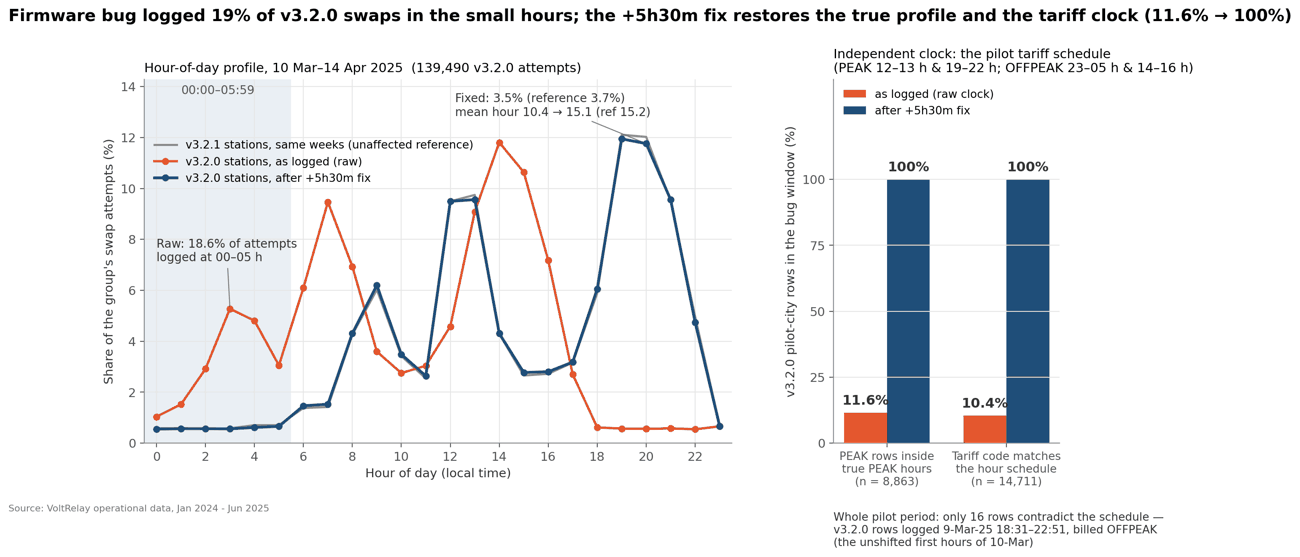

In [21]:
hdr("1. Firmware v3.2.0 timestamp fix")
BUG_A, BUG_B = dt.date(2025, 3, 10), dt.date(2025, 4, 14)
fw = (events(["station_firmware", "event_ts_raw", "hour", "city", "tariff_code", "ts_corrected", "is_service_failure"])
      .filter(pl.col("event_ts_raw").dt.date().is_between(BUG_A, BUG_B))
      .with_columns(pl.col("event_ts_raw").dt.hour().alias("hour_raw"))
      .collect())
n_shift = int(fw["ts_corrected"].sum())
v0 = fw.filter(pl.col("station_firmware") == "v3.2.0")
v1 = fw.filter(pl.col("station_firmware") == "v3.2.1")
H = np.arange(24)


def hcounts(df, col):
    c = df.group_by(col).len()
    out = np.zeros(24)
    out[c[col].to_numpy().astype(int)] = c["len"].to_numpy()
    return out


def night(p): return 100 * p[:6].sum()
def peakwin(p): return 100 * p[12:23].sum()
def meanh(p): return float((H * p).sum())
def tvd(p, q): return 100 * 0.5 * np.abs(p - q).sum()


n_raw, n_fix, n_ref = hcounts(v0, "hour_raw"), hcounts(v0, "hour"), hcounts(v1, "hour")
p_raw, p_fix, p_ref = n_raw / n_raw.sum(), n_fix / n_fix.sum(), n_ref / n_ref.sum()
chi_fix = stats.chi2_contingency(np.vstack([n_fix, n_ref]))
chi_raw = stats.chi2_contingency(np.vstack([n_raw, n_ref]))
na_raw, na_fix = hcounts(fw, "hour_raw"), hcounts(fw, "hour")
pa_raw, pa_fix = na_raw / na_raw.sum(), na_fix / na_fix.sum()
fr_raw = v0.group_by("hour_raw").agg(pl.len().alias("n"), pl.col("is_service_failure").mean().alias("r")).filter(pl.col("n") >= 1000).sort("r", descending=True)
fr_fix = v0.group_by("hour").agg(pl.len().alias("n"), pl.col("is_service_failure").mean().alias("r")).filter(pl.col("n") >= 1000).sort("r", descending=True)
pk = v0.filter((pl.col("tariff_code") == "PEAK") & pl.col("city").is_in(PILOT_CITIES))
pk_in_raw = 100 * pk["hour_raw"].is_between(12, 22).mean()
pk_in_fix = 100 * pk["hour"].is_between(12, 22).mean()
print(f"events shifted by clean.py: {n_shift:,} = {100 * n_shift / N_EV:.2f}% of clean attempts "
      f"(v3.2.0 attempts in window {v0.height:,}; v3.2.1 {v1.height:,})")
print(f"v3.2.0 share of attempts at 00-05h: raw {night(p_raw):.1f}% -> fixed {night(p_fix):.1f}% (v3.2.1 reference {night(p_ref):.1f}%)")
print(f"v3.2.0 mean event hour: raw {meanh(p_raw):.2f} -> fixed {meanh(p_fix):.2f} (reference {meanh(p_ref):.2f})")
print(f"v3.2.0 share in 12:00-22:59 (pricing peak window): raw {peakwin(p_raw):.1f}% -> fixed {peakwin(p_fix):.1f}% (reference {peakwin(p_ref):.1f}%)")
print(f"v3.2.0 busiest hour: raw {int(np.argmax(p_raw))}h ({100 * p_raw.max():.1f}%) -> fixed {int(np.argmax(p_fix))}h "
      f"({100 * p_fix.max():.1f}%); reference {int(np.argmax(p_ref))}h ({100 * p_ref.max():.1f}%)")
print(f"total-variation distance to reference: raw {tvd(p_raw, p_ref):.1f} pts vs fixed {tvd(p_fix, p_ref):.2f} pts "
      f"(chi2 p: raw {chi_raw.pvalue:.2g}, fixed {chi_fix.pvalue:.2g})")
print(f"NETWORK (all stations) in window: 00-05h share raw {night(pa_raw):.1f}% -> {night(pa_fix):.1f}%; "
      f"12-22h share raw {peakwin(pa_raw):.1f}% -> {peakwin(pa_fix):.1f}%; TVD {tvd(pa_raw, pa_fix):.1f} pts")
print(f"v3.2.0 worst failure-rate hour (>=1,000 attempts): raw {fr_raw['hour_raw'][0]}h ({100 * fr_raw['r'][0]:.1f}%) "
      f"vs fixed {fr_fix['hour'][0]}h ({100 * fr_fix['r'][0]:.1f}%)")
print(f"(coarse check) PEAK-coded attempts at v3.2.0 pilot stations in window n={pk.height:,}: inside 12-22h on raw clock "
      f"{pk_in_raw:.1f}% vs corrected clock {pk_in_fix:.1f}% -- 12:00-22:59 is NOT the tariff window, see the true schedule below")

# The TRUE pilot tariff schedule, read off the data: modal tariff_code by corrected hour for independent riders in the
# pilot cities after 1-Oct-2024 (partners are billed under PARTNER, see section 8).
tzl = (events(["city", "date", "hour", "event_ts_raw", "tariff_code", "is_independent", "station_firmware"])
       .filter(pl.col("city").is_in(PILOT_CITIES) & (pl.col("date") >= PILOT_START) & pl.col("is_independent"))
       .with_columns(pl.col("hour").cast(pl.Int32)))
hb = (tzl.group_by("hour", "tariff_code").len().collect()
      .pivot(on="tariff_code", index="hour", values="len").fill_null(0).sort("hour"))
TCODES = [c for c in ["PEAK", "OFFPEAK", "STD"] if c in hb.columns]
modal = {int(r["hour"]): max(TCODES, key=lambda c: r[c]) for r in hb.iter_rows(named=True)}
purity = {int(r["hour"]): max(r[c] for c in TCODES) / sum(r[c] for c in TCODES) for r in hb.iter_rows(named=True)}
PKH = sorted(h for h, c in modal.items() if c == "PEAK")
OPH = sorted(h for h, c in modal.items() if c == "OFFPEAK")
STH = sorted(h for h, c in modal.items() if c == "STD")
print(f"TRUE tariff schedule (modal code by corrected hour; pilot-city independents, post-pilot): PEAK {PKH}; OFFPEAK {OPH}; STD {STH}; "
      f"lowest single-hour purity {100 * min(purity.values()):.3f}%")


def sched(h):
    return pl.when(h.is_in(PKH)).then(pl.lit("PEAK")).when(h.is_in(OPH)).then(pl.lit("OFFPEAK")).otherwise(pl.lit("STD"))


contra = (tzl.filter(sched(pl.col("hour")) != pl.col("tariff_code"))
          .select("station_firmware", "date", "event_ts_raw", "tariff_code", "hour").collect())
print(f"ROW-LEVEL EDGE PROOF: tariff/clock contradictions in the whole post-pilot period (corrected clock): {contra.height}; "
      f"firmware {sorted(contra['station_firmware'].unique().to_list())}; dates {sorted(str(d) for d in contra['date'].unique().to_list())}; "
      f"logged {contra['event_ts_raw'].min()} .. {contra['event_ts_raw'].max()} (true time +5h30m: "
      f"{contra['event_ts_raw'].min() + dt.timedelta(hours=5, minutes=30)} .. {contra['event_ts_raw'].max() + dt.timedelta(hours=5, minutes=30)}); "
      f"billed {sorted(contra['tariff_code'].unique().to_list())}")
win_t = (tzl.filter(pl.col("event_ts_raw").dt.date().is_between(BUG_A, BUG_B) & (pl.col("station_firmware") == "v3.2.0"))
         .with_columns(sched(pl.col("event_ts_raw").dt.hour().cast(pl.Int32)).alias("exp_raw"), sched(pl.col("hour")).alias("exp_fix")).collect())
agree_raw = 100 * float((win_t["exp_raw"] == win_t["tariff_code"]).mean())
agree_fix = 100 * float((win_t["exp_fix"] == win_t["tariff_code"]).mean())
pk_t = win_t.filter(pl.col("tariff_code") == "PEAK")
pkt_raw = 100 * float(pk_t["event_ts_raw"].dt.hour().cast(pl.Int32).is_in(PKH).mean())
pkt_fix = 100 * float(pk_t["hour"].is_in(PKH).mean())
print(f"TARIFF CLOCK on the true bands (v3.2.0 pilot-city independents in the bug window): PEAK rows inside true PEAK hours raw {pkt_raw:.1f}% "
      f"vs fixed {pkt_fix:.1f}% (n={pk_t.height:,}); tariff code agrees with the hour schedule raw {agree_raw:.1f}% vs fixed {agree_fix:.1f}% "
      f"(n={win_t.height:,})")

# window edges: is the bug window defined on logged or on true time?
bd = (events(["station_firmware", "event_ts_raw", "event_ts"])
      .filter(pl.col("event_ts_raw").is_between(dt.datetime(2025, 3, 1), dt.datetime(2025, 3, 10, 23, 59, 59))
              | pl.col("event_ts_raw").is_between(dt.datetime(2025, 4, 14), dt.datetime(2025, 4, 15, 23, 59, 59)))
      .with_columns((pl.col("event_ts_raw").dt.hour().cast(pl.Int32) * 60 + pl.col("event_ts_raw").dt.minute().cast(pl.Int32)).alias("mod_raw"),
                    pl.col("event_ts_raw").dt.date().alias("d_raw"))
      .collect())


def nfw(df, f): return df.filter(pl.col("station_firmware") == f).height


EVE = 18 * 60 + 30                      # 18:30 = 24:00 - 5h30m
pre_eve = bd.filter(pl.col("d_raw").is_between(dt.date(2025, 3, 1), dt.date(2025, 3, 8)) & (pl.col("mod_raw") >= EVE))
r_eve = nfw(pre_eve, "v3.2.0") / nfw(pre_eve, "v3.2.1")
eve9 = bd.filter((pl.col("d_raw") == dt.date(2025, 3, 9)) & (pl.col("mod_raw") >= EVE))
obs_eve9, exp_eve9 = nfw(eve9, "v3.2.0"), r_eve * nfw(eve9, "v3.2.1")
pre_ngt = bd.filter(pl.col("d_raw").is_between(dt.date(2025, 3, 2), dt.date(2025, 3, 9)) & (pl.col("mod_raw") < 330))
r_ngt = nfw(pre_ngt, "v3.2.0") / nfw(pre_ngt, "v3.2.1")
gap10 = bd.filter(pl.col("event_ts").is_between(dt.datetime(2025, 3, 10, 0, 0), dt.datetime(2025, 3, 10, 5, 29, 59)))
obs_gap, exp_gap = nfw(gap10, "v3.2.0"), r_ngt * nfw(gap10, "v3.2.1")
end14 = bd.filter(pl.col("event_ts_raw").is_between(dt.datetime(2025, 4, 14, 18, 30), dt.datetime(2025, 4, 14, 23, 59, 59)))
obs_end, exp_end = nfw(end14, "v3.2.0"), r_eve * nfw(end14, "v3.2.1")
edge_excess = obs_eve9 - exp_eve9
print(f"EDGE start: v3.2.0 attempts logged 2025-03-09 18:30-23:59 = {obs_eve9:,} vs expected {exp_eve9:,.0f} from v3.2.1 volume "
      f"(excess {edge_excess:+,.0f}, z = {edge_excess / np.sqrt(exp_eve9):.1f})")
print(f"EDGE start: v3.2.0 attempts at corrected 2025-03-10 00:00-05:29 = {obs_gap:,} vs expected {exp_gap:,.0f}  -> "
      f"the first ~5.5 h of 10-Mar were logged on 9-Mar evening and NOT shifted by clean.py")
print(f"EDGE end: v3.2.0 attempts logged 2025-04-14 18:30-23:59 = {obs_end:,} vs expected {exp_end:,.0f} if the window were on "
      f"logged time -> window is defined on TRUE local date (10-Mar..14-Apr); clean.py end edge is handled correctly")
print(f"EDGE impact: ~{edge_excess:.0f} mis-timed attempts = {100 * edge_excess / N_EV:.4f}% of clean attempts; {contra.height} of them are "
      f"identifiable row by row (pilot-city independents whose tariff code contradicts the logged hour)")
pd.DataFrame({"hour": H, "v320_raw_share": p_raw, "v320_fixed_share": p_fix, "v321_reference_share": p_ref,
              "network_raw_share": pa_raw, "network_fixed_share": pa_fix}).to_csv(TAB / "q7_firmware_hour_profile.csv", index=False)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.6, 1], "wspace": 0.25})
ymax = 100 * max(p_raw.max(), p_fix.max(), p_ref.max()) * 1.18
ax.axvspan(-0.5, 5.5, color=PALETTE["light"], alpha=0.55, lw=0, zorder=0)
ax.text(2.5, ymax * 0.985, "00:00–05:59", ha="center", va="top", fontsize=10, color="#555555")
ax.plot(H, 100 * p_ref, color=PALETTE["muted"], lw=1.8, label="v3.2.1 stations, same weeks (unaffected reference)", zorder=2)
ax.plot(H, 100 * p_raw, color=PALETTE["accent"], lw=2, marker="o", ms=5, label="v3.2.0 stations, as logged (raw)", zorder=3)
ax.plot(H, 100 * p_fix, color=PALETTE["primary"], lw=2.4, marker="o", ms=5, label="v3.2.0 stations, after +5h30m fix", zorder=4)
ax.set_ylim(0, ymax); ax.set_xlim(-0.5, 23.5); ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day (local time)"); ax.set_ylabel("Share of the group's swap attempts (%)")
ax.set_title(f"Hour-of-day profile, {BUG_A:%d %b}–{BUG_B:%d %b %Y}  ({v0.height:,} v3.2.0 attempts)", fontsize=11, fontweight="normal")
ax.annotate(f"Raw: {night(p_raw):.1f}% of attempts\nlogged at 00–05 h", xy=(3, 100 * p_raw[3]), xytext=(0.0, ymax * 0.50),
            fontsize=10, color="#333333", arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8))
ax.annotate(f"Fixed: {night(p_fix):.1f}% (reference {night(p_ref):.1f}%)\nmean hour {meanh(p_raw):.1f} → {meanh(p_fix):.1f} (ref {meanh(p_ref):.1f})",
            xy=(20, 100 * p_fix[20]), xytext=(12.2, ymax * 0.90), fontsize=10, color="#333333",
            arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8))
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.86), fontsize=9.5)
xg, wb = np.arange(2), 0.36
raw_v, fix_v = [pkt_raw, agree_raw], [pkt_fix, agree_fix]
b_raw = ax2.bar(xg - wb / 2, raw_v, width=wb, color=PALETTE["accent"], label="as logged (raw clock)")
b_fix = ax2.bar(xg + wb / 2, fix_v, width=wb, color=PALETTE["primary"], label="after +5h30m fix")
for b, v in list(zip(b_raw, raw_v)) + list(zip(b_fix, fix_v)):
    ax2.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.1f}%" if v < 99.95 else "100%", ha="center", va="bottom", fontsize=11.5,
             fontweight="bold", color="#333333")
ax2.set_xticks(xg, [f"PEAK rows inside\ntrue PEAK hours\n(n = {pk_t.height:,})", f"Tariff code matches\nthe hour schedule\n(n = {win_t.height:,})"], fontsize=9.5)
ax2.set_ylim(0, 138); ax2.set_yticks([0, 25, 50, 75, 100]); ax2.set_ylabel("v3.2.0 pilot-city rows in the bug window (%)")
ax2.legend(loc="upper left", fontsize=9.5)
ax2.set_title("Independent clock: the pilot tariff schedule\n(PEAK 12–13 h & 19–22 h; OFFPEAK 23–05 h & 14–16 h)", fontsize=11, fontweight="normal")
ax2.grid(axis="x", visible=False)
ax2.text(0.0, -0.19, f"Whole pilot period: only {contra.height} rows contradict the schedule —\nv3.2.0 rows logged 9-Mar-25 "
         f"{contra['event_ts_raw'].min():%H:%M}–{contra['event_ts_raw'].max():%H:%M}, billed OFFPEAK\n(the unshifted first hours of 10-Mar)",
         transform=ax2.transAxes, ha="left", va="top", fontsize=9.5, color="#333333")
fig.suptitle(f"Firmware bug logged {night(p_raw):.0f}% of v3.2.0 swaps in the small hours; the +5h30m fix restores the true profile "
             f"and the tariff clock ({pkt_raw:.1f}% → {pkt_fix:.0f}%)", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_fig(fig, "q7_01_firmware_hour_profile")
add_issue("Firmware v3.2.0 timestamp bug (10-Mar..14-Apr-2025)", "documented",
          "Hour profile vs v3.2.1 stations in same weeks; true pilot tariff schedule as independent clock; 30-min edge bins; row-level tariff contradictions",
          n_shift, N_EV, "attempts", "Shift +5h30m (clean.py)",
          f"Untreated: {night(p_raw):.1f}% of v3.2.0 attempts at 00-05h (true {night(p_fix):.1f}%); network 12-22h share "
          f"{peakwin(pa_raw):.1f}% vs {peakwin(pa_fix):.1f}% in window; PEAK rows inside true PEAK hours (12-13h, 19-22h) {pkt_raw:.1f}% raw vs "
          f"{pkt_fix:.1f}% fixed; code-schedule agreement {agree_raw:.1f}% vs {agree_fix:.1f}%. Edge: ~{max(edge_excess, 0):.0f} attempts of "
          f"10-Mar 00:00-05:29 left unshifted, {contra.height} of them identified row by row (logged 9-Mar evening, billed OFFPEAK).",
          f"00-05h share {night(p_raw):.1f}%→{night(p_fix):.1f}%; tariff clock {pkt_raw:.1f}%→{pkt_fix:.0f}%", "high")

## 2 · Test stations STN-TST-01/02 — what would keeping them do to Bengaluru and network KPIs?

In [22]:
hdr("2. Test stations")
tst = pl.read_parquet(CLEAN / "test_station_events.parquet", columns=["station_id", "rider_id", "event_ts", "event_type", "amount_charged_inr"])
t_att, t_comp = tst.height, int((tst["event_type"] == "swap_completed").sum())
t_fail = int(tst["event_type"].is_in(FAIL_TYPES).sum()); t_rev = float(tst["amount_charged_inr"].sum())
t_zero = int((tst["amount_charged_inr"] == 0).sum()); t_zero_comp = int(((tst["amount_charged_inr"] == 0) & (tst["event_type"] == "swap_completed")).sum())
t_night = 100 * float((tst["event_ts"].dt.hour() < 6).mean())
agg = [pl.len().alias("att"), pl.col("is_completed").sum().alias("comp"), pl.col("is_service_failure").sum().alias("fail"),
       pl.col("revenue").sum().alias("rev"), (pl.col("event_ts").dt.hour() < 6).mean().alias("night")]
ev2 = events(["city", "month", "is_completed", "is_service_failure", "revenue", "event_ts"])
blr = ev2.filter(pl.col("city") == "Bengaluru").select(agg).collect().row(0, named=True)
net = ev2.select(agg).collect().row(0, named=True)
blr_m = ev2.filter(pl.col("city") == "Bengaluru").group_by("month").agg(pl.col("is_completed").sum().alias("comp"), pl.col("revenue").sum().alias("rev")).collect()
tst_m = (tst.filter(pl.col("event_type") == "swap_completed").group_by(pl.col("event_ts").dt.truncate("1mo").dt.date().alias("month"))
         .agg(pl.len().alias("t_comp"), pl.col("amount_charged_inr").sum().alias("t_rev")))
bm = blr_m.join(tst_m, on="month", how="left").fill_null(0).sort("month")
g0 = bm.filter(pl.col("month") == dt.date(2024, 1, 1)).row(0, named=True); g1 = bm.filter(pl.col("month") == dt.date(2025, 6, 1)).row(0, named=True)
growth_wo, growth_w = g1["comp"] / g0["comp"], (g1["comp"] + g1["t_comp"]) / (g0["comp"] + g0["t_comp"])
n_blr_st = stations().filter((pl.col("city") == "Bengaluru") & ~pl.col("is_test")).height
sm_blr = station_month().filter(pl.col("city") == "Bengaluru")
blr_st_month = float(sm_blr["completed"].sum() / sm_blr.height)
tst_st_month = t_comp / (2 * 18)
rows = []
for k, lab in [("att", "attempts"), ("comp", "completed swaps"), ("rev", "revenue (INR)")]:
    tv = {"att": t_att, "comp": t_comp, "rev": t_rev}[k]
    rows.append(dict(kpi=f"Bengaluru {lab}", without_test=blr[k], with_test=blr[k] + tv, pct_change=100 * tv / blr[k]))
    rows.append(dict(kpi=f"Network {lab}", without_test=net[k], with_test=net[k] + tv, pct_change=100 * tv / net[k]))
fr_b0, fr_b1 = 100 * blr["fail"] / blr["att"], 100 * (blr["fail"] + t_fail) / (blr["att"] + t_att)
rows += [dict(kpi="Bengaluru service-failure rate (%)", without_test=fr_b0, with_test=fr_b1, pct_change=fr_b1 - fr_b0),
         dict(kpi="Bengaluru revenue per swap (INR)", without_test=blr["rev"] / blr["comp"], with_test=(blr["rev"] + t_rev) / (blr["comp"] + t_comp),
              pct_change=100 * ((blr["rev"] + t_rev) / (blr["comp"] + t_comp) / (blr["rev"] / blr["comp"]) - 1)),
         dict(kpi="Bengaluru swaps growth Jun-25 / Jan-24 (x)", without_test=growth_wo, with_test=growth_w, pct_change=100 * (growth_w / growth_wo - 1))]
tsi = pd.DataFrame(rows); tsi.to_csv(TAB / "q7_test_station_impact.csv", index=False)
rdx = riders().select("rider_id", "n_attempts", "last_attempt_ts")
tr = tst.group_by("rider_id").agg(pl.len().alias("n_tst"), pl.col("event_ts").max().alias("last_tst")).join(rdx, on="rider_id", how="left")
tr_only = int(tr["n_attempts"].is_null().sum())
tr_later = tr.filter(pl.col("last_tst") > pl.col("last_attempt_ts") + pl.duration(days=30)).height
tr_share = float(tr["n_tst"].sum() / (tr["n_tst"].sum() + tr["n_attempts"].fill_null(0).sum()))
print(f"test stations: {t_att:,} attempts, {t_comp:,} completed, revenue INR {t_rev:,.0f}, zero-value rows {t_zero:,} "
      f"(of which completed {t_zero_comp:,}); failures {t_fail:,} ({100 * t_fail / t_att:.1f}%)")
print(f"share of attempts at 00-05h: test {t_night:.1f}% vs network {100 * net['night']:.1f}% -> NOT 'unusual hours'")
print(f"test-station completed swaps per station-month {tst_st_month:,.0f} vs Bengaluru real-station average {blr_st_month:,.0f} "
      f"({n_blr_st} real Bengaluru stations)")
print(tsi.round(3).to_string(index=False))
print(f"riders seen at test stations: {tr.height:,}; test-only riders {tr_only}; their attempts at test stations = {100 * tr_share:.1f}% of their total; "
      f"riders whose last test-station visit is >30 d after their last real attempt: {tr_later}")
rev_b = tsi.loc[tsi.kpi == "Bengaluru revenue (INR)", "pct_change"].iloc[0]
rev_n = tsi.loc[tsi.kpi == "Network revenue (INR)", "pct_change"].iloc[0]
add_issue("Test stations STN-TST-01/02 hold full paid activity", "documented",
          "station_id prefix; compare value/hours vs documentation", t_att, N_RAW, "attempts",
          "Exclude from all KPIs (kept in test_station_events.parquet)",
          f"Kept in: Bengaluru revenue +{rev_b:.1f}%, network revenue +{rev_n:.1f}% (INR {t_rev / 1e6:.2f}M), Bengaluru failure rate "
          f"{fr_b0:.2f}%→{fr_b1:.2f}%, Bengaluru growth {growth_wo:.2f}x→{growth_w:.2f}x; only {t_zero:,} zero-value rows (all non-completed) and "
          f"a normal night share ({t_night:.1f}%) — they behave like a real Bengaluru station ({tst_st_month:,.0f} vs {blr_st_month:,.0f} swaps/station-month) "
          f"used by {tr.height:,} real riders, so the exclusion is a labelled-asset decision, not an obvious-junk one.",
          f"Bengaluru revenue +{rev_b:.1f}%, network +{rev_n:.1f}% (₹{t_rev / 1e6:.1f}M)", "high")


2. Test stations   [  0.8s]


test stations: 62,031 attempts, 59,134 completed, revenue INR 3,930,760, zero-value rows 2,897 (of which completed 0); failures 2,643 (4.3%)
share of attempts at 00-05h: test 3.8% vs network 3.6% -> NOT 'unusual hours'
test-station completed swaps per station-month 1,643 vs Bengaluru real-station average 1,656 (32 real Bengaluru stations)
                                       kpi  without_test    with_test  pct_change
                        Bengaluru attempts  7.632960e+05 8.253270e+05       8.127
                          Network attempts  3.814982e+06 3.877013e+06       1.626
                 Bengaluru completed swaps  7.285630e+05 7.876970e+05       8.117
                   Network completed swaps  3.586675e+06 3.645809e+06       1.649
                   Bengaluru revenue (INR)  4.802399e+07 5.195475e+07       8.185
                     Network revenue (INR)  2.291953e+08 2.331261e+08       1.715
        Bengaluru service-failure rate (%)  4.109000e+00 4.121000e+00       0.011
   

## 3 · km_since_last_swap outliers — delivered-range statistics with vs without the null rule (<0 or >200 km)

In [23]:
hdr("3. km outliers")
bt = batteries()
assert bt["battery_id"].str.slice(7).n_unique() == bt.height, "battery numeric ids not unique"
bmap = bt.select(as_i32("battery_id", 7).alias("bid"), "supplier")
km = (pl.scan_parquet(RAW_EV)
      .filter(~pl.col("station_id").str.starts_with("STN-TST") & pl.col("km_since_last_swap").is_not_null())
      .select(pl.col("km_since_last_swap").cast(pl.Float64).alias("km"), pl.col("battery_in_id").str.slice(4, 2).alias("vc"),
              as_i32("battery_in_id", 7).alias("bid"), as_i32("rider_id", 3).alias("r"))
      .collect()
      .join(bmap, on="bid", how="left")
      .with_columns(((pl.col("km") < 0) | (pl.col("km") > 200)).alias("bad")))


def kstats(df):
    return (df.group_by("vc").agg(pl.len().alias("n"), pl.col("km").mean().alias("mean"), pl.col("km").median().alias("median"),
                                  pl.col("km").std().alias("sd"), pl.col("km").quantile(0.99).alias("p99"),
                                  pl.col("km").min().alias("min"), pl.col("km").max().alias("max")).sort("vc"))


k_all = kstats(km).with_columns(pl.lit("raw (with outliers)").alias("version"))
k_val = kstats(km.filter(~pl.col("bad"))).with_columns(pl.lit("clean (0-200 km)").alias("version"))
kt = pl.concat([k_all, k_val]).to_pandas(); kt.to_csv(TAB / "q7_km_outlier_impact.csv", index=False)
n_neg, n_hi = int((km["km"] < 0).sum()), int((km["km"] > 200).sum())
neg_rng = (float(km.filter(pl.col("km") < 0)["km"].min()), float(km.filter(pl.col("km") < 0)["km"].max()))
hi_rng = (float(km.filter(pl.col("km") > 200)["km"].min()), float(km.filter(pl.col("km") > 200)["km"].max()))
val_rng = (float(km.filter(~pl.col("bad"))["km"].min()), float(km.filter(~pl.col("bad"))["km"].max()))
n_zero_km = int((km["km"] == 0).sum())
pr = km.group_by("r").agg(pl.len().alias("n"), pl.col("bad").sum().alias("b"))
p_bad = float(km["bad"].mean()); e_b = pr["n"] * p_bad
disp_km = float((((pr["b"] - e_b) ** 2) / (e_b * (1 - p_bad))).sum() / (pr.height - 1))
sup_km = (km.filter(pl.col("vc") == "2W").group_by("supplier")
          .agg(pl.col("bad").mean().alias("bad_share"), pl.col("km").mean().alias("mean_raw"),
               pl.col("km").filter(~pl.col("bad")).mean().alias("mean_clean"), pl.col("km").filter(~pl.col("bad")).median().alias("median_clean"))
          .sort("supplier"))
print(f"invalid km: {n_neg:,} negative (range {neg_rng[0]:.0f}..{neg_rng[1]:.0f}) + {n_hi:,} >200 km (range {hi_rng[0]:.0f}..{hi_rng[1]:.0f}) "
      f"= {n_neg + n_hi:,} of {km.height:,} non-null readings ({100 * (n_neg + n_hi) / km.height:.2f}%)")
print(f"valid readings span {val_rng[0]:.1f}-{val_rng[1]:.1f} km; outliers are {neg_rng[0]:.0f}..{neg_rng[1]:.0f} km and {hi_rng[0]:.0f}..{hi_rng[1]:.0f} km; "
      f"no readings between {val_rng[1]:.1f} and {hi_rng[0]:.0f} km and none in [0, {val_rng[0]:.1f}) (exact zeros: {n_zero_km}) -> "
      f"the <0 / >200 cut sits in empty gaps, so the rule is not arbitrary")
print(kt.round(2).to_string(index=False))
print(f"rider dispersion index of invalid readings = {disp_km:.2f} (1.0 = random across riders; >>1 = vehicle-specific odometer faults)")
print(sup_km.to_pandas().round(3).to_string(index=False))
m2 = {r["vc"]: r for r in k_all.iter_rows(named=True)}; c2 = {r["vc"]: r for r in k_val.iter_rows(named=True)}
add_issue("km_since_last_swap outliers (odometer resets)", "documented",
          "Value range; empty gap 120-330 km; rider dispersion test", n_neg + n_hi, km.height, "readings",
          "Set to null (<0 or >200 km), flag km_invalid",
          f"2W mean {m2['2W']['mean']:.1f}→{c2['2W']['mean']:.1f} km, sd {m2['2W']['sd']:.1f}→{c2['2W']['sd']:.1f}; 3W mean "
          f"{m2['3W']['mean']:.1f}→{c2['3W']['mean']:.1f}; medians unchanged; spread evenly across riders (dispersion {disp_km:.2f}) and suppliers.",
          f"2W mean range {m2['2W']['mean']:.1f}→{c2['2W']['mean']:.1f} km; sd {m2['2W']['sd']:.0f}→{c2['2W']['sd']:.0f}", "medium")
del km


3. km outliers   [  1.0s]


invalid km: 7,687 negative (range -20..-1) + 7,600 >200 km (range 320..420) = 15,287 of 3,787,124 non-null readings (0.40%)
valid readings span 22.1-136.7 km; outliers are -20..-1 km and 320..420 km; no readings between 136.7 and 320 km and none in [0, 22.1) (exact zeros: 0) -> the <0 / >200 cut sits in empty gaps, so the rule is not arbitrary
vc       n  mean  median    sd   p99   min   max             version
2W 3374775 58.54    58.2 17.99  82.7 -20.0 420.0 raw (with outliers)
3W  412349 89.93    89.2 17.75 117.9 -20.0 420.0 raw (with outliers)
2W 3361105 58.05    58.2 10.83  82.0  22.1  98.8    clean (0-200 km)
3W  410732 89.56    89.2 11.62 117.0  43.8 136.7    clean (0-200 km)
rider dispersion index of invalid readings = 0.97 (1.0 = random across riders; >>1 = vehicle-specific odometer faults)
supplier  bad_share  mean_raw  mean_clean  median_clean
  Amptek      0.004    61.286      60.812          60.6
 Cellora      0.004    61.279      60.808          60.5
   Kyron      0.004   

## 4 · SoC/SoH readings above 100% (sensor drift) — clip at 100?

In [24]:
hdr("4. SoC/SoH > 100%")
RC = ["soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct"]
raw_nt = pl.scan_parquet(RAW_EV).filter(~pl.col("station_id").str.starts_with("STN-TST"))
cl = raw_nt.select(*[(pl.col(c) > 100).sum().alias(f"{c}|n") for c in RC], *[pl.col(c).max().alias(f"{c}|max") for c in RC],
                   *[pl.col(c).mean().alias(f"{c}|mean_raw") for c in RC], *[pl.col(c).clip(upper_bound=100).mean().alias(f"{c}|mean_clip") for c in RC],
                   *[pl.col(c).count().alias(f"{c}|nn") for c in RC],
                   pl.any_horizontal([pl.col(c) > 100 for c in RC]).sum().alias("rows_any")).collect().row(0, named=True)
n_read_over = sum(cl[f"{c}|n"] for c in RC); n_read = sum(cl[f"{c}|nn"] for c in RC)
for c in RC:
    print(f"{c:12s}: >100 = {cl[f'{c}|n']:>5,} of {cl[f'{c}|nn']:,} (max {cl[f'{c}|max']:.1f}); mean raw {cl[f'{c}|mean_raw']:.4f} -> clipped {cl[f'{c}|mean_clip']:.4f}")
sc4 = raw_nt.group_by("station_id").agg(pl.len().alias("n"), pl.any_horizontal([pl.col(c) > 100 for c in RC]).sum().alias("over")).collect()
p4 = sc4["over"].sum() / sc4["n"].sum(); e4 = sc4["n"] * p4
disp4 = float((((sc4["over"] - e4) ** 2) / (e4 * (1 - p4))).sum() / (sc4.height - 1))
over_m = (raw_nt.group_by(pl.col("event_ts").dt.truncate("1mo").alias("m"))
          .agg(pl.len().alias("n"), pl.any_horizontal([pl.col(c) > 100 for c in RC]).sum().alias("over")).collect().sort("m")
          .with_columns((100 * pl.col("over") / pl.col("n")).alias("pct")))
sc4q1 = (raw_nt.filter(pl.col("event_ts") < dt.datetime(2024, 4, 1)).group_by("station_id")
         .agg(pl.len().alias("n"), pl.any_horizontal([pl.col(c) > 100 for c in RC]).sum().alias("over")).collect())
p4q = sc4q1["over"].sum() / sc4q1["n"].sum(); e4q = sc4q1["n"] * p4q
disp4q = float((((sc4q1["over"] - e4q) ** 2) / (e4q * (1 - p4q))).sum() / (sc4q1.height - 1))
print(f"readings >100: {n_read_over:,} of {n_read:,} readings ({100 * n_read_over / n_read:.3f}%) on {cl['rows_any']:,} attempts; "
      f"station dispersion index {disp4:.2f} over the full period")
print(f"share of attempts with a >100 reading by month: {over_m['pct'][0]:.2f}% ({over_m['m'][0]:%b-%y}) -> {over_m['pct'][-1]:.2f}% ({over_m['m'][-1]:%b-%y}); "
      f"within Jan-Mar 2024 only, station dispersion index = {disp4q:.2f} -> concentration reflects pack age (new packs read >100), not faulty cabinets")
d_soh = cl["soh_out_pct|mean_raw"] - cl["soh_out_pct|mean_clip"]
add_issue("SoC/SoH readings >100% (sensor drift)", "documented", "Range check (max 103.0%); by-month share; station dispersion within a fixed period",
          n_read_over, n_read, "readings", "Clip at 100, flag reading_clipped",
          f"Mean issued-pack SoH moves by {d_soh:.4f} pts. Readings >100 fade from {over_m['pct'][0]:.2f}% of attempts ({over_m['m'][0]:%b-%y}) to "
          f"{over_m['pct'][-1]:.2f}% ({over_m['m'][-1]:%b-%y}) as packs age; within Q1-2024 they are spread across stations like chance "
          f"(dispersion {disp4q:.2f}) -> drift on new packs, no faulty cabinets, no KPI impact.",
          f"mean SoH shift {d_soh:.4f} pts (negligible)", "low")


4. SoC/SoH > 100%   [  1.4s]


soc_in_pct  : >100 =     0 of 3,787,124 (max 28.4); mean raw 9.2825 -> clipped 9.2825
soh_in_pct  : >100 = 3,298 of 3,787,124 (max 101.4); mean raw 88.1409 -> clipped 88.1407
soc_out_pct : >100 = 3,634 of 3,586,675 (max 103.0); mean raw 96.6645 -> clipped 96.6627
soh_out_pct : >100 = 2,752 of 3,586,675 (max 101.3); mean raw 88.3845 -> clipped 88.3843


readings >100: 9,684 of 14,747,598 readings (0.066%) on 9,592 attempts; station dispersion index 6.60 over the full period
share of attempts with a >100 reading by month: 4.65% (Jan-24) -> 0.09% (Jun-25); within Jan-Mar 2024 only, station dispersion index = 1.06 -> concentration reflects pack age (new packs read >100), not faulty cabinets


## 5 · riders.home_city spellings — city counts before vs after standardisation

In [25]:
hdr("5. home_city standardisation")
rr = pl.read_parquet(PARQ / "riders.parquet").select("rider_id", "home_city").join(riders().select("rider_id", "home_city_clean", "zone_city"), on="rider_id")
raw_exact = rr.group_by("home_city").len().rename({"home_city": "city", "len": "raw_exact_match"})
clean_ct = rr.group_by("home_city_clean").len().rename({"home_city_clean": "city", "len": "clean"})
variants = (rr.filter(pl.col("home_city") != pl.col("home_city_clean")).group_by("home_city_clean")
            .agg(pl.col("home_city").unique().sort().alias("v")).with_columns(pl.col("v").list.eval(pl.element().map_elements(repr, return_dtype=pl.String)).list.join(", "))
            .rename({"home_city_clean": "city", "v": "variants_absorbed"}))
ct = (pl.DataFrame({"city": CITIES}).join(raw_exact, on="city", how="left").join(clean_ct, on="city", how="left").join(variants, on="city", how="left")
      .with_columns((100 * (pl.col("clean") / pl.col("raw_exact_match") - 1)).round(2).alias("pct_undercount_if_raw")))
ct.write_csv(TAB / "q7_city_standardisation.csv")
n_recode = int((rr["home_city"] != rr["home_city_clean"]).sum()); n_var = rr["home_city"].n_unique()
mism = int((rr["home_city_clean"] != rr["zone_city"]).sum())
print(ct.to_pandas().to_string(index=False))
print(f"raw spellings {n_var} -> 6 cities; riders recoded {n_recode:,} ({100 * n_recode / rr.height:.2f}%); mismatch vs home_zone prefix: {mism}")
add_issue("riders.home_city inconsistent spellings", "documented", "Value list; cross-check vs home_zone prefix (0 mismatches)",
          n_recode, rr.height, "riders", "Map 21 spellings → 6 cities",
          f"Raw exact-match counts undercount cities by {ct['pct_undercount_if_raw'].min():.1f}–{ct['pct_undercount_if_raw'].max():.1f}%; "
          f"{n_recode} riders would fall into 15 phantom 'cities'.",
          f"city rider counts +{ct['pct_undercount_if_raw'].min():.1f}% to +{ct['pct_undercount_if_raw'].max():.1f}%", "medium")


5. home_city standardisation   [  1.7s]


     city  raw_exact_match  clean                variants_absorbed  pct_undercount_if_raw
Bengaluru             4175   4310 'BLR', 'Bangalore', 'bengaluru '                   3.23
Delhi NCR             3783   3886  'Delhi', 'Gurgaon', 'New Delhi'                   2.72
Hyderabad             3396   3485        'HYD', 'Hyd', 'hyderabad'                   2.62
     Pune             2843   2929                    'PUN', 'pune'                   3.02
   Mumbai             2772   2874                  'Bombay', 'MUM'                   3.68
   Jaipur             2446   2516                  'JAI', 'jaipur'                   2.86
raw spellings 21 -> 6 cities; riders recoded 585 (2.92%); mismatch vs home_zone prefix: 0


## 6 · Telemetry blanks — where are they, and what would zero-filling do to stock levels and stockout-hours?
A "stockout-hour" = a station-hour whose minimum charged 2W packs is 0. Zero-filling a blank would silently turn every
missing hour into a stockout-hour. We also test whether blank hours are *informative* (MNAR): do riders see more
failures in the hours when the cabinet failed to report?


6. Telemetry missingness   [  1.7s]


connectivity_tier  station_hours  missing  partial  stockout_hours_nullaware  avg_charged_2w_nullaware  avg_charged_2w_zerofill  stockout_hours_zerofill  missing_pct  partial_pct  stockout_hour_rate_nullaware  stockout_hour_rate_zerofill  stock_level_bias_pct
             fair         278664        0    11004                      4363                     8.546                    8.546                     4363          0.0        3.949                         1.566                        1.566                   0.0
             good         948216        0     9550                     11438                     8.690                    8.690                    11438          0.0        1.007                         1.206                        1.206                   0.0
             poor         234576     9384    16193                      2729                     9.356                    8.981                    12113          4.0        6.903                         1.212            

poor tier missing share by firmware: {'v3.2.0': 3.93, 'v3.2.1': 4.05}
monthly missing share range: 0.56%..0.76%


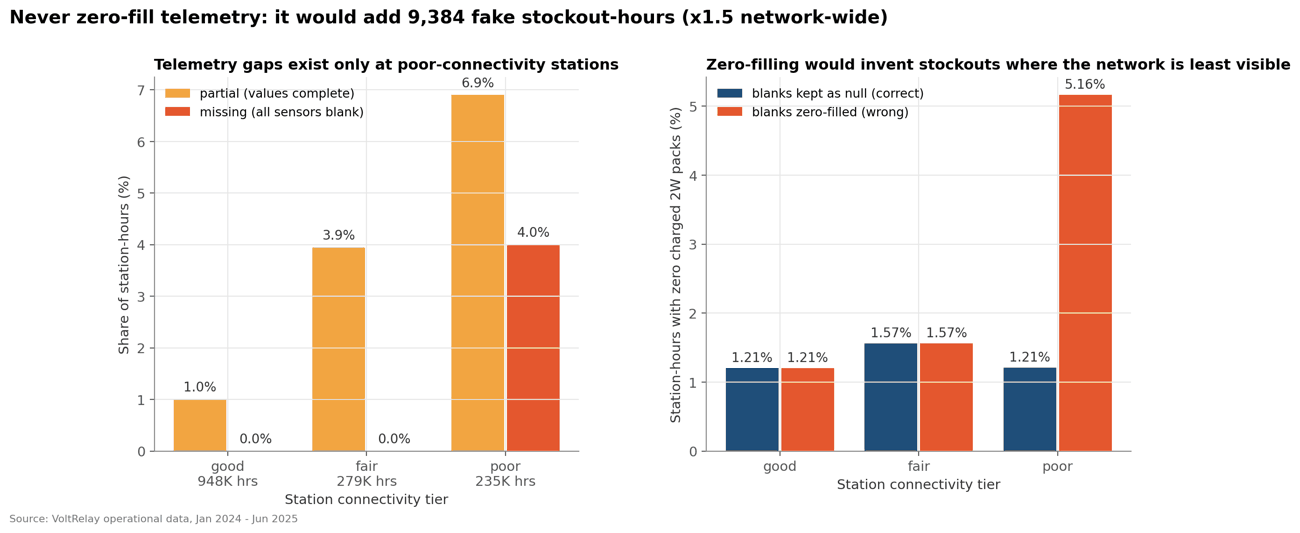

In [26]:
hdr("6. Telemetry missingness")
st_all = stations()
hr_raw = (pl.scan_parquet(PARQ / "station_hourly_status.parquet")
          .select("station_id", "telemetry_status", "charged_2w_min", "charged_2w_avg", "hour_start")
          .join(st_all.lazy().select("station_id", "connectivity_tier", "firmware_version", "is_test"), on="station_id")
          .filter(~pl.col("is_test")))
tele = (hr_raw.group_by("connectivity_tier").agg(
    pl.len().alias("station_hours"), (pl.col("telemetry_status") == "missing").sum().alias("missing"),
    (pl.col("telemetry_status") == "partial").sum().alias("partial"),
    (pl.col("charged_2w_min") == 0).sum().alias("stockout_hours_nullaware"),
    pl.col("charged_2w_avg").mean().alias("avg_charged_2w_nullaware"), pl.col("charged_2w_avg").fill_null(0).mean().alias("avg_charged_2w_zerofill"))
    .collect().sort("connectivity_tier")
    .with_columns((pl.col("stockout_hours_nullaware") + pl.col("missing")).alias("stockout_hours_zerofill"))
    .with_columns((100 * pl.col("missing") / pl.col("station_hours")).alias("missing_pct"),
                  (100 * pl.col("partial") / pl.col("station_hours")).alias("partial_pct"),
                  (100 * pl.col("stockout_hours_nullaware") / (pl.col("station_hours") - pl.col("missing"))).alias("stockout_hour_rate_nullaware"),
                  (100 * pl.col("stockout_hours_zerofill") / pl.col("station_hours")).alias("stockout_hour_rate_zerofill"),
                  (100 * (pl.col("avg_charged_2w_zerofill") / pl.col("avg_charged_2w_nullaware") - 1)).alias("stock_level_bias_pct")))
tele.write_csv(TAB / "q7_telemetry_zero_fill_bias.csv")
print(tele.to_pandas().round(3).to_string(index=False))
tot_h, tot_miss = int(tele["station_hours"].sum()), int(tele["missing"].sum())
so_na, so_zf = int(tele["stockout_hours_nullaware"].sum()), int(tele["stockout_hours_zerofill"].sum())
poor = tele.filter(pl.col("connectivity_tier") == "poor").row(0, named=True)
print(f"missing station-hours {tot_miss:,} of {tot_h:,} ({100 * tot_miss / tot_h:.2f}%); share at poor-tier stations "
      f"{100 * poor['missing'] / tot_miss:.1f}%; 'partial' rows carry complete values (no blanks)")
print(f"stockout-hours network: null-aware {so_na:,} -> zero-filled {so_zf:,} (x{so_zf / so_na:.2f}); poor tier "
      f"{poor['stockout_hours_nullaware']:,} -> {poor['stockout_hours_zerofill']:,} (x{poor['stockout_hours_zerofill'] / poor['stockout_hours_nullaware']:.2f})")
# is missingness informative? (poor-tier stations only, event outcomes in the same station-hour)
eh = (events(["station_id", "date", "hour", "is_stockout", "is_service_failure", "connectivity_tier"])
      .filter(pl.col("connectivity_tier") == "poor")
      .group_by("station_id", "date", pl.col("hour").cast(pl.Int32))
      .agg(pl.len().alias("att"), pl.col("is_stockout").sum().alias("so"), pl.col("is_service_failure").sum().alias("fail")).collect())
hp = (hourly(["station_id", "date", "hour", "telemetry_status", "connectivity_tier", "month"]).filter(pl.col("connectivity_tier") == "poor")
      .with_columns(pl.col("hour").cast(pl.Int32)).collect())
mh = hp.join(eh, on=["station_id", "date", "hour"], how="left").with_columns(pl.col("att").fill_null(0), pl.col("so").fill_null(0), pl.col("fail").fill_null(0))
mnar = (mh.group_by("telemetry_status").agg(pl.len().alias("hours"), pl.col("att").mean().alias("attempts_per_hour"),
                                             (pl.col("so").sum() / pl.col("att").sum() * 100).alias("stockout_rate_pct"),
                                             (pl.col("fail").sum() / pl.col("att").sum() * 100).alias("failure_rate_pct")).sort("telemetry_status"))
print("poor-tier stations — event outcomes by telemetry status of the same station-hour:")
print(mnar.to_pandas().round(3).to_string(index=False))
mm = mh.with_columns((pl.col("telemetry_status") == "missing").alias("miss"))
ct_m = mm.group_by("miss").agg(pl.col("so").sum(), pl.col("att").sum()).sort("miss")
tab_m = np.array([[r["so"], r["att"] - r["so"]] for r in ct_m.iter_rows(named=True)])
chi_m = stats.chi2_contingency(tab_m)
print(f"chi2 test stockout rate missing vs reported hours: p = {chi_m.pvalue:.3g}")
miss_fw = (hr_raw.filter(pl.col("connectivity_tier") == "poor").group_by("firmware_version")
           .agg((pl.col("telemetry_status") == "missing").mean().alias("missing_share"), pl.len()).collect())
miss_month = (hr_raw.group_by(pl.col("hour_start").dt.truncate("1mo").alias("m")).agg((pl.col("telemetry_status") == "missing").mean().alias("missing_share"))
              .collect().sort("m"))
print("poor tier missing share by firmware:", {r["firmware_version"]: round(100 * r["missing_share"], 2) for r in miss_fw.iter_rows(named=True)})
print(f"monthly missing share range: {100 * miss_month['missing_share'].min():.2f}%..{100 * miss_month['missing_share'].max():.2f}%")
mrow = {r["telemetry_status"]: r for r in mnar.iter_rows(named=True)}
add_issue("Telemetry blanks (telemetry_status = missing)", "documented",
          "Null profile by status x connectivity tier; zero-fill simulation; outcome test in blank hours",
          tot_miss, tot_h, "station-hours", "Keep null; null-aware means; report coverage",
          f"All blanks at poor-tier stations ({100 * poor['missing'] / tot_miss:.0f}%). Zero-fill would add {tot_miss:,} fake stockout-hours "
          f"(network x{so_zf / so_na:.2f}, poor tier x{poor['stockout_hours_zerofill'] / poor['stockout_hours_nullaware']:.2f}) and cut poor-tier "
          f"stock level by {abs(poor['stock_level_bias_pct']):.1f}%. Blank hours are not worse for riders (stockout "
          f"{mrow['missing']['stockout_rate_pct']:.2f}% vs {mrow['ok']['stockout_rate_pct']:.2f}% when reported).",
          f"zero-fill → stockout-hours x{so_zf / so_na:.1f} (poor tier x{poor['stockout_hours_zerofill'] / poor['stockout_hours_nullaware']:.1f})", "high")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"wspace": 0.3})
tiers = ["good", "fair", "poor"]
td = {r["connectivity_tier"]: r for r in tele.iter_rows(named=True)}
xs = np.arange(3)
axa.bar(xs - 0.2, [td[t]["partial_pct"] for t in tiers], width=0.38, color=PALETTE["warn"], label="partial (values complete)")
axa.bar(xs + 0.2, [td[t]["missing_pct"] for t in tiers], width=0.38, color=PALETTE["accent"], label="missing (all sensors blank)")
for i, t in enumerate(tiers):
    axa.text(i + 0.2, td[t]["missing_pct"] + 0.1, f"{td[t]['missing_pct']:.1f}%", ha="center", va="bottom", fontsize=10, color="#333333")
    axa.text(i - 0.2, td[t]["partial_pct"] + 0.1, f"{td[t]['partial_pct']:.1f}%", ha="center", va="bottom", fontsize=10, color="#333333")
axa.set_xticks(xs, [f"{t}\n{td[t]['station_hours'] / 1e3:.0f}K hrs" for t in tiers])
axa.set_ylabel("Share of station-hours (%)"); axa.set_xlabel("Station connectivity tier")
axa.set_title("Telemetry gaps exist only at poor-connectivity stations", fontsize=11.5)
axa.legend(loc="upper left")
axb.bar(xs - 0.2, [td[t]["stockout_hour_rate_nullaware"] for t in tiers], width=0.38, color=PALETTE["primary"], label="blanks kept as null (correct)")
axb.bar(xs + 0.2, [td[t]["stockout_hour_rate_zerofill"] for t in tiers], width=0.38, color=PALETTE["accent"], label="blanks zero-filled (wrong)")
for i, t in enumerate(tiers):
    axb.text(i - 0.2, td[t]["stockout_hour_rate_nullaware"] + 0.05, f"{td[t]['stockout_hour_rate_nullaware']:.2f}%", ha="center", va="bottom", fontsize=10, color="#333333")
    axb.text(i + 0.2, td[t]["stockout_hour_rate_zerofill"] + 0.05, f"{td[t]['stockout_hour_rate_zerofill']:.2f}%", ha="center", va="bottom", fontsize=10, color="#333333")
axb.set_xticks(xs, tiers); axb.set_xlabel("Station connectivity tier")
axb.set_ylabel("Station-hours with zero charged 2W packs (%)")
axb.set_title("Zero-filling would invent stockouts where the network is least visible", fontsize=11.5)
axb.legend(loc="upper left")
fig.suptitle(f"Never zero-fill telemetry: it would add {tot_miss:,} fake stockout-hours (x{so_zf / so_na:.1f} network-wide)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "q7_04_telemetry_zero_fill_bias")
del hp, mh, eh

## 7 · Near-duplicate offline-sync retries — confirm the documented rule and stress-test looser definitions
Consecutive attempts of the same rider (sorted by time). If sync retries were duplicated, gaps between repeat
records at the same station would pile up at a few seconds–2 minutes and be over-represented in offline_batch rows.


7. Near-duplicates   [  2.3s]


consecutive same-rider pairs in data: 3,795,041; pairs <=600 s apart: 34,194
                                                                 definition  pairs  pct_of_attempts  share_offline_involved
D0 documented: same station+type+both batteries, <=180 s, >=1 offline_batch      0           0.0000                     NaN
       D1 ignore battery IDs: same station+type, <=180 s, >=1 offline_batch   1368           0.0359                  1.0000
                               D2 any sync mode: same station+type, <=180 s   5633           0.1477                  0.2429
                                   D3 any event type: same station, <=180 s   6373           0.1671                  0.2409
                   D4 same returned pack (battery_in), <=300 s, any station      6           0.0002                  0.0000
                                           D5 identical timestamp (0 s gap)     33           0.0009                  0.1212
                                 D6 wide window: same s

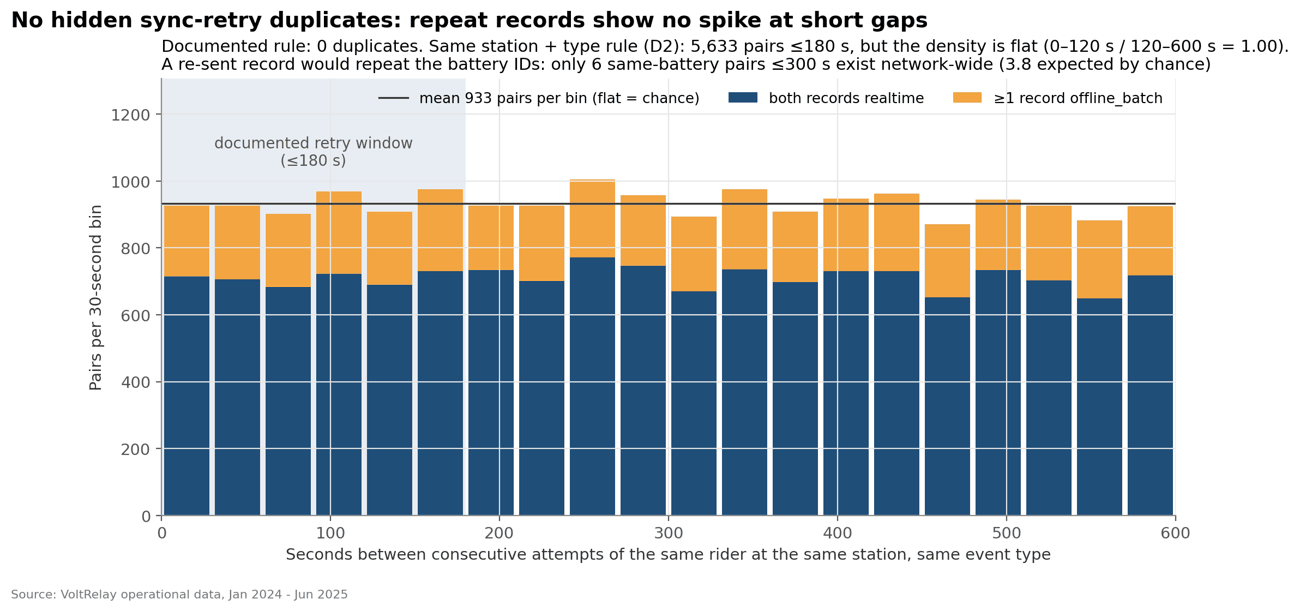

In [27]:
hdr("7. Near-duplicates")
DUPC = ["r", "s", "event_ts", "et", "bi", "bo", "off"]
pairs = (events(["event_id", "rider_id", "station_id", "event_ts", "event_type", "battery_in_id", "battery_out_id", "sync_mode", "vehicle_class"])
         .select(as_i32("rider_id", 3).alias("r"), pl.col("station_id").cast(pl.Categorical).alias("s"), "event_ts",
                 pl.col("event_type").cast(pl.Categorical).alias("et"), as_i32("battery_in_id", 7).alias("bi"),
                 as_i32("battery_out_id", 7).alias("bo"), (pl.col("sync_mode") == "offline_batch").alias("off"),
                 (pl.col("vehicle_class") == "3W").alias("w3"), pl.col("event_id").str.slice(3).cast(pl.Int64).alias("eid"))
         .sort("r", "event_ts", "eid")                      # event_id breaks timestamp ties -> deterministic pairs
         .with_columns([pl.col(c).shift(1).alias(c + "_p") for c in DUPC])
         .filter(pl.col("r") == pl.col("r_p"))
         .with_columns((pl.col("event_ts") - pl.col("event_ts_p")).dt.total_seconds().alias("gap"))
         .filter(pl.col("gap") <= 600)
         .collect())
n_consec = N_EV - riders().filter(pl.col("n_attempts").is_not_null()).height
same_s, same_t = pl.col("s") == pl.col("s_p"), pl.col("et") == pl.col("et_p")
same_b = pl.col("bi").eq_missing(pl.col("bi_p")) & pl.col("bo").eq_missing(pl.col("bo_p"))
any_off = pl.col("off") | pl.col("off_p")
g = pl.col("gap")
DEFS = {
    "D0 documented: same station+type+both batteries, <=180 s, >=1 offline_batch": same_s & same_t & same_b & (g <= 180) & any_off,
    "D1 ignore battery IDs: same station+type, <=180 s, >=1 offline_batch": same_s & same_t & (g <= 180) & any_off,
    "D2 any sync mode: same station+type, <=180 s": same_s & same_t & (g <= 180),
    "D3 any event type: same station, <=180 s": same_s & (g <= 180),
    "D4 same returned pack (battery_in), <=300 s, any station": (pl.col("bi") == pl.col("bi_p")) & (g <= 300),
    "D5 identical timestamp (0 s gap)": g == 0,
    "D6 wide window: same station+type, <=600 s": same_s & same_t,
}
dup_rows = []
for name, expr in DEFS.items():
    sub = pairs.filter(expr.fill_null(False))
    dup_rows.append(dict(definition=name, pairs=sub.height, pct_of_attempts=100 * sub.height / N_EV,
                         share_offline_involved=float(sub.select((pl.col("off") | pl.col("off_p")).mean()).item()) if sub.height else np.nan))
dupt = pd.DataFrame(dup_rows); dupt.to_csv(TAB / "q7_near_duplicate_definitions.csv", index=False)
print(f"consecutive same-rider pairs in data: {n_consec:,}; pairs <=600 s apart: {pairs.height:,}")
print(dupt.round(4).to_string(index=False))
st_off = events(["station_id", "sync_mode"]).group_by("station_id").agg((pl.col("sync_mode") == "offline_batch").mean().alias("p")).collect()
d2 = (pairs.filter((same_s & same_t & (g <= 180)).fill_null(False)).with_columns(pl.col("s").cast(pl.String).alias("station_id"))
      .join(st_off, on="station_id", how="left"))
exp_off = float((1 - (1 - d2["p"]) ** 2).mean()); obs_off = float(d2.select((pl.col("off") | pl.col("off_p")).mean()).item())
edges = np.arange(0, 601, 30)
ss = pairs.filter((same_s & same_t).fill_null(False))
h_off, _ = np.histogram(ss.filter(any_off)["gap"].to_numpy(), bins=edges)
h_rt, _ = np.histogram(ss.filter(~any_off)["gap"].to_numpy(), bins=edges)
h_all = h_off + h_rt
chi_u = stats.chisquare(h_all)
dens_short, dens_long = h_all[:4].mean(), h_all[4:].mean()
seq = (pairs.filter((same_s & (g <= 180)).fill_null(False)).group_by(pl.col("et_p").cast(pl.String).alias("previous"), pl.col("et").cast(pl.String).alias("next"))
       .len().sort("len", descending=True))
d2_types = d2.group_by(pl.col("et").cast(pl.String).alias("later_record_type")).len()
d2_comp = int(d2_types.filter(pl.col("later_record_type") == "swap_completed")["len"].sum())
d2_fail = int(d2_types.filter(pl.col("later_record_type").is_in(FAIL_TYPES))["len"].sum())
base_fail = events(["is_service_failure"]).select(pl.col("is_service_failure").sum()).collect().item()
fr_before, fr_after = 100 * base_fail / N_EV, 100 * (base_fail - d2_fail) / (N_EV - d2.height)
print(f"D2 pairs: offline_batch involved {100 * obs_off:.1f}% vs {100 * exp_off:.1f}% expected from station offline shares (no excess)")
print(f"if the later record of every D2 pair were dropped: completed swaps -{d2_comp:,} ({100 * d2_comp / 3586675:.2f}%), "
      f"service-failure rate {fr_before:.3f}% -> {fr_after:.3f}%")
print(f"gap histogram (same station+type, 30-s bins): density 0-120 s = {dens_short:.0f}/bin vs 120-600 s = {dens_long:.0f}/bin "
      f"(ratio {dens_short / dens_long:.2f}); chi2 uniformity p = {chi_u.pvalue:.3g}")
print("same-station pairs <=180 s by sequence:"); print(seq.head(8))
# A sync retry re-sends the SAME record, so it would carry the same battery IDs: the documented rule can see retries.
# Check the battery-ID signature directly: same (non-null) battery_in within 300 s, any station, vs chance coincidence.
n_pack = {w3_: int(bt.filter(pl.col("pack_type").str.starts_with("3W" if w3_ else "2W")).height) for w3_ in (False, True)}
p300 = pairs.filter((g <= 300) & pl.col("bi").is_not_null() & pl.col("bi_p").is_not_null())
d4_obs = int(p300.filter(pl.col("bi") == pl.col("bi_p")).height)
d4_exp = sum(int((p300["w3"] == w3_).sum()) / n_pack[w3_] for w3_ in (False, True))
print(f"same non-null battery_in within 300 s (any station): {d4_obs} pairs network-wide vs {d4_exp:.1f} expected by chance "
      f"({p300.height:,} same-rider pairs <=300 s with both packs recorded; {n_pack[False]:,} 2W / {n_pack[True]:,} 3W packs) "
      f"-> no record was re-sent: there are no retries under any rule, so the documented rule is adequate")
d0n = int(dupt.iloc[0]["pairs"])
add_issue("Near-duplicate offline-sync retries", "documented",
          "Documented rule + 6 looser definitions; gap-distribution, offline-share and same-battery tests", d0n, N_EV, "attempts",
          "None removed (rule applied, 0 hits)",
          f"0 duplicates under the documented rule and none under any looser rule: the same station + type rule (D2) finds "
          f"{int(dupt.iloc[2]['pairs']):,} pairs ({dupt.iloc[2]['pct_of_attempts']:.3f}%) with a flat gap density (0-120 s vs 120-600 s ratio "
          f"{dens_short / dens_long:.2f}) and no offline_batch excess ({100 * obs_off:.1f}% vs {100 * exp_off:.1f}% expected); only {d4_obs} "
          f"same-battery_in pairs ≤300 s exist network-wide ({d4_exp:.1f} expected by chance) -> chance coincidences, not retries. Dropping D2 "
          f"pairs anyway would cut swaps by {100 * d2_comp / 3586675:.2f}% and move the failure rate {fr_before:.3f}%→{fr_after:.3f}%.",
          f"0 duplicates; looser rules ≤{dupt.iloc[3]['pct_of_attempts']:.2f}% & look like chance", "low")

fig, ax = plt.subplots(figsize=(12, 5.2))
centers = edges[:-1] + 15
ax.bar(centers, h_rt, width=27, color=PALETTE["primary"], label="both records realtime")
ax.bar(centers, h_off, width=27, bottom=h_rt, color=PALETTE["warn"], label="≥1 record offline_batch")
ax.axvspan(0, 180, color=PALETTE["light"], alpha=0.6, lw=0, zorder=0)
ax.text(90, max(h_all) * 1.13, "documented retry window\n(≤180 s)", ha="center", va="top", fontsize=10, color="#555555")
ax.axhline(h_all.mean(), color="#333333", lw=1.2, label=f"mean {h_all.mean():.0f} pairs per bin (flat = chance)")
ax.set_ylim(0, max(h_all) * 1.3); ax.set_xlim(0, 600)
ax.set_xlabel("Seconds between consecutive attempts of the same rider at the same station, same event type")
ax.set_ylabel("Pairs per 30-second bin")
ax.legend(loc="upper right", ncol=3, fontsize=9.5)
ax.set_title(f"Documented rule: 0 duplicates. Same station + type rule (D2): {int(dupt.iloc[2]['pairs']):,} pairs ≤180 s, but the density is flat "
             f"(0–120 s / 120–600 s = {dens_short / dens_long:.2f}).\nA re-sent record would repeat the battery IDs: only {d4_obs} same-battery pairs "
             f"≤300 s exist network-wide ({d4_exp:.1f} expected by chance)", fontsize=11, fontweight="normal")
fig.suptitle("No hidden sync-retry duplicates: repeat records show no spike at short gaps", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
save_fig(fig, "q7_05_near_duplicate_gap_test")
del pairs, ss, d2, p300

## 8 · Revenue logic — non-completed attempts and tariff arithmetic
Non-completed attempts carry list_price/discount/tariff_code but amount_charged = 0. We size the error from using
list − discount, then test the identity amount = list − discount (+15 PEAK, −8 OFFPEAK) row by row.

In [28]:
hdr("8. Revenue logic & tariff arithmetic")
rv = (events(["event_id", "rider_id", "event_ts", "is_completed", "tariff_code", "list_price_inr", "discount_inr", "amount_charged_inr",
              "partner_id", "plan_type", "city", "date", "hour"])
      .with_columns((pl.col("amount_charged_inr") - (pl.col("list_price_inr") - pl.col("discount_inr"))).round(1).alias("res")))
rsum = rv.group_by("is_completed").agg(pl.len().alias("n"), pl.col("list_price_inr").is_not_null().sum().alias("list_populated"),
                                       pl.col("amount_charged_inr").sum().alias("amount"), (pl.col("list_price_inr") - pl.col("discount_inr")).sum().alias("list_minus_disc")).collect()
rc_ = {r["is_completed"]: r for r in rsum.iter_rows(named=True)}
rev_true, naive_extra = rc_[True]["amount"], rc_[False]["list_minus_disc"]
print(f"non-completed attempts {rc_[False]['n']:,}: list price populated {rc_[False]['list_populated']:,}, amount charged sum {rc_[False]['amount']:.0f}")
print(f"revenue (amount on completed) INR {rev_true:,.0f}; using list-discount on ALL attempts would add INR {naive_extra:,.0f} (+{100 * naive_extra / rev_true:.1f}%)")
fp = partners().select("partner_id", "peak_surcharge_billable")
cmp_ = rv.filter(pl.col("is_completed")).join(fp.lazy(), on="partner_id", how="left")
expl = (pl.when(pl.col("tariff_code") == "PEAK").then(pl.col("res") == 15).when(pl.col("tariff_code") == "OFFPEAK").then(pl.col("res") == -8)
        .when(pl.col("tariff_code") == "PARTNER").then(pl.col("res").is_in([0.0, 15.0, -8.0])).otherwise(pl.col("res") == 0))
tar = (cmp_.with_columns(expl.alias("explained"))
       .group_by("tariff_code").agg(pl.len().alias("n"), (pl.col("res").abs() > 0.01).sum().alias("amount_ne_list_minus_disc"),
                                    (~pl.col("explained")).sum().alias("unexplained"), pl.col("res").filter(~pl.col("explained")).sum().alias("unexpl_net_inr"),
                                    pl.col("res").filter(~pl.col("explained")).abs().sum().alias("unexpl_gross_inr"),
                                    (pl.col("res") == 15).sum().alias("plus15"), (pl.col("res") == -8).sum().alias("minus8"))
       .collect().sort("tariff_code"))
print(tar.to_pandas().to_string(index=False))
hid = (cmp_.filter(pl.col("tariff_code") == "PARTNER")
       .group_by("peak_surcharge_billable", pl.col("city").is_in(PILOT_CITIES).alias("pilot_city"), (pl.col("date") >= PILOT_START).alias("post_pilot"))
       .agg(pl.len().alias("n"), (pl.col("res") == 15).sum().alias("plus15"), (pl.col("res") == -8).sum().alias("minus8"))
       .collect().sort("peak_surcharge_billable", "pilot_city", "post_pilot"))
print("PARTNER rows with hidden peak (+15) / off-peak (-8) adjustments:"); print(hid)
n_p15 = int(tar.filter(pl.col("tariff_code") == "PARTNER")["plus15"].item()); n_m8 = int(tar.filter(pl.col("tariff_code") == "PARTNER")["minus8"].item())
partner_pilot = int(hid.filter(pl.col("pilot_city") & pl.col("post_pilot"))["n"].sum())
n_unexpl, net_unexpl, gross_unexpl = int(tar["unexplained"].sum()), float(tar["unexpl_net_inr"].sum()), float(tar["unexpl_gross_inr"].sum())
n_comp = int(tar["n"].sum())
print(f"hidden partner adjustments: +15 on {n_p15:,} and -8 on {n_m8:,} PARTNER swaps = {100 * (n_p15 + n_m8) / partner_pilot:.1f}% of "
      f"post-pilot partner swaps in pilot cities ({partner_pilot:,}); net INR {15 * n_p15 - 8 * n_m8:,.0f}")
# denominators: how much pilot exposure does tariff_code miss?
partner_pilot_y = int(hid.filter(pl.col("pilot_city") & pl.col("post_pilot") & (pl.col("peak_surcharge_billable") == "Y"))["n"].sum())
n_coded_pilot = int(tar.filter(pl.col("tariff_code").is_in(["PEAK", "OFFPEAK"]))["n"].sum())
n_coded_partner = int(cmp_.filter(pl.col("tariff_code").is_in(["PEAK", "OFFPEAK"]) & pl.col("partner_id").is_not_null()).select(pl.len()).collect().item())
n_pilot_all = n_coded_pilot + n_p15 + n_m8
on_sched = (cmp_.filter((pl.col("tariff_code") == "PARTNER") & pl.col("res").is_in([15.0, -8.0]))
            .group_by("res").agg(pl.len().alias("n"), pl.when(pl.col("res") == 15).then(pl.col("hour").cast(pl.Int32).is_in(PKH))
                                 .otherwise(pl.col("hour").cast(pl.Int32).is_in(OPH)).mean().alias("on_schedule"))
            .collect())
osd = {float(r["res"]): 100 * r["on_schedule"] for r in on_sched.iter_rows(named=True)}
print(f"tariff_code labels {n_coded_partner} partner swaps PEAK/OFFPEAK -> it misses 100% of the {n_p15 + n_m8:,} pilot-priced partner swaps. "
      f"They are {100 * (n_p15 + n_m8) / partner_pilot:.1f}% of {partner_pilot:,} post-pilot partner swaps in Bengaluru/Pune, "
      f"{100 * (n_p15 + n_m8) / partner_pilot_y:.1f}% of the {partner_pilot_y:,} by Y-flag partners, and {100 * (n_p15 + n_m8) / n_pilot_all:.1f}% "
      f"of all {n_pilot_all:,} pilot-priced completed swaps ({n_coded_pilot:,} coded PEAK/OFFPEAK + {n_p15 + n_m8:,} hidden)")
print(f"hidden +15 rows on true PEAK hours: {osd[15.0]:.2f}%; hidden -8 rows on true OFFPEAK hours: {osd[-8.0]:.2f}% -> they ARE the pilot schedule")
print(f"unexplained +-5/+-10 deviations: {n_unexpl:,} swaps ({100 * n_unexpl / n_comp:.3f}%), net INR {net_unexpl:,.0f}, gross INR {gross_unexpl:,.0f}")
# do unexplained deviations trigger billing disputes? (same rider, ticket within 7 days after the swap)
bdt = tickets().filter(pl.col("category") == "billing_dispute").select("rider_id", "created_ts")
devs = cmp_.filter(~expl).select("event_id", "rider_id", "event_ts").collect()
base = cmp_.filter(expl & (pl.col("event_id").hash(7) % 40 == 0)).select("event_id", "rider_id", "event_ts").collect()


def dispute_rate(df):
    j = (df.join(bdt, on="rider_id", how="inner")
         .filter((pl.col("created_ts") >= pl.col("event_ts")) & (pl.col("created_ts") <= pl.col("event_ts") + pl.duration(days=7))))
    return j["event_id"].n_unique() / df.height, j["event_id"].n_unique()


dr_dev, k_dev = dispute_rate(devs); dr_base, k_base = dispute_rate(base)
z_bd = stats.chi2_contingency(np.array([[k_dev, devs.height - k_dev], [k_base, base.height - k_base]]))
print(f"billing-dispute ticket within 7 d: after unexplained deviation {100 * dr_dev:.2f}% (n={devs.height:,}) vs normal swaps "
      f"{100 * dr_base:.2f}% (sample n={base.height:,}); chi2 p = {z_bd.pvalue:.3g}")
pp = (cmp_.group_by("plan_type", "tariff_code").agg(pl.len().alias("n"), pl.col("amount_charged_inr").mean().alias("mean_amount"),
                                                    pl.col("discount_inr").mean().alias("mean_discount")).collect().sort("plan_type", "tariff_code"))
print(pp)
raw_codes = pl.scan_parquet(RAW_EV).group_by("tariff_code").len().collect()
raw_pm = pl.scan_parquet(RAW_EV).group_by("payment_mode").len().collect()
n_prepaid = int(pp.filter(pl.col("plan_type") == "prepaid_pack")["n"].sum())
print(f"tariff codes present in raw: {sorted(raw_codes['tariff_code'].to_list())}; PREPAID rows 0, PROMO_FREE rows 0")
print(f"payment_mode values: {raw_pm.to_dicts()}")
print(f"prepaid_pack riders' completed swaps: {n_prepaid:,} ({100 * n_prepaid / n_comp:.1f}%), all billed at STD/PEAK/OFFPEAK with discount 0")
add_issue("Price fields populated on non-completed attempts", "documented", "amount vs list/discount by event_type",
          rc_[False]["n"], N_EV, "attempts", "Revenue = amount_charged on completed swaps only",
          f"Using list − discount on every attempt would overstate revenue by INR {naive_extra / 1e6:.1f}M (+{100 * naive_extra / rev_true:.1f}%).",
          f"list-based revenue would be +{100 * naive_extra / rev_true:.1f}% (₹{naive_extra / 1e6:.1f}M)", "medium")
add_issue("Peak/off-peak adjustments hidden inside PARTNER tariff code", "undocumented",
          "Row identity amount = list − discount; residual +15/−8 by partner flag, city, period",
          n_p15 + n_m8, n_comp, "swaps", "Derive pilot exposure from the residual, not tariff_code",
          f"{n_p15:,} partner swaps carry the +15 surcharge and {n_m8:,} the −8 discount, on the true PEAK/OFFPEAK hours "
          f"{osd[15.0]:.0f}%/{osd[-8.0]:.2f}% of the time, while coded PARTNER: tariff_code labels none of them (misses 100% of partner "
          f"exposure). They are {100 * (n_p15 + n_m8) / partner_pilot:.1f}% of post-pilot partner swaps in Bengaluru/Pune "
          f"({100 * (n_p15 + n_m8) / partner_pilot_y:.1f}% of Y-flag partners' swaps) and {100 * (n_p15 + n_m8) / n_pilot_all:.1f}% of all "
          f"{n_pilot_all:,} pilot-priced swaps; N-flag partners never charged. Net INR {(15 * n_p15 - 8 * n_m8) / 1e6:.2f}M.",
          f"tariff_code hides {100 * (n_p15 + n_m8) / n_pilot_all:.0f}% of pilot-priced swaps ({n_p15 + n_m8:,}; ₹{(15 * n_p15 - 8 * n_m8) / 1e6:.2f}M)", "high")
add_issue("Unexplained ±₹5/±₹10 billing deviations", "undocumented", "Residual after documented tariff rules",
          n_unexpl, n_comp, "swaps", "Keep amount_charged as revenue; flag for billing audit",
          f"Net INR {net_unexpl:,.0f} (gross INR {gross_unexpl:,.0f}); billing-dispute ticket within 7 d {100 * dr_dev:.2f}% vs {100 * dr_base:.2f}% for normal swaps.",
          f"net ₹{net_unexpl / 1e3:.0f}K; disputes {100 * dr_dev:.1f}% vs {100 * dr_base:.1f}%", "low")
add_issue("PREPAID / PROMO_FREE tariff codes absent; prepaid riders pay standard tariffs", "undocumented",
          "Code inventory vs data dictionary; tariff by plan_type", n_prepaid, n_comp, "swaps",
          "Treat plan_type as a label; no prepaid discount modelled",
          f"{n_prepaid:,} prepaid_pack swaps billed exactly like pay-as-you-go (same tariffs, discount 0) — prepaid revenue cannot be separated.",
          "prepaid pricing not observable", "medium")
add_issue("payment_mode constant ('partner_invoice' on 100%)", "undocumented", "Distinct values (also for pay-as-you-go riders)",
          int(raw_pm["len"].sum()), N_RAW, "attempts", "Drop field; use plan_type/tariff", "No payment-channel analysis possible.",
          "field unusable", "low")


8. Revenue logic & tariff arithmetic   [  3.1s]


non-completed attempts 228,307: list price populated 228,307, amount charged sum 0
revenue (amount on completed) INR 229,195,296; using list-discount on ALL attempts would add INR 15,049,697 (+6.6%)
tariff_code       n  amount_ne_list_minus_disc  unexplained  unexpl_net_inr  unexpl_gross_inr  plus15  minus8
    OFFPEAK   34833                      34833           99          -697.0             809.0       0   34734
    PARTNER 2368154                     237967         4703          3963.0           37865.0  163312   69952
       PEAK  163922                     163922          310          4715.0            4715.0  163612       0
        STD 1019766                       2082         2082           -20.0           15660.0       0       0


PARTNER rows with hidden peak (+15) / off-peak (-8) adjustments:
shape: (8, 6)
┌─────────────────────────┬────────────┬────────────┬────────┬────────┬────────┐
│ peak_surcharge_billable ┆ pilot_city ┆ post_pilot ┆ n      ┆ plus15 ┆ minus8 │
│ ---                     ┆ ---        ┆ ---        ┆ ---    ┆ ---    ┆ ---    │
│ str                     ┆ bool       ┆ bool       ┆ u32    ┆ u32    ┆ u32    │
╞═════════════════════════╪════════════╪════════════╪════════╪════════╪════════╡
│ N                       ┆ false      ┆ false      ┆ 159925 ┆ 0      ┆ 0      │
│ N                       ┆ false      ┆ true       ┆ 343961 ┆ 0      ┆ 0      │
│ N                       ┆ true       ┆ false      ┆ 101217 ┆ 0      ┆ 0      │
│ N                       ┆ true       ┆ true       ┆ 181919 ┆ 0      ┆ 0      │
│ Y                       ┆ false      ┆ false      ┆ 334201 ┆ 0      ┆ 0      │
│ Y                       ┆ false      ┆ true       ┆ 692406 ┆ 0      ┆ 0      │
│ Y                       ┆ tr

billing-dispute ticket within 7 d: after unexplained deviation 0.83% (n=7,194) vs normal swaps 0.87% (sample n=89,826); chi2 p = 0.784
shape: (7, 5)
┌────────────────┬─────────────┬─────────┬─────────────┬───────────────┐
│ plan_type      ┆ tariff_code ┆ n       ┆ mean_amount ┆ mean_discount │
│ ---            ┆ ---         ┆ ---     ┆ ---         ┆ ---           │
│ str            ┆ str         ┆ u32     ┆ f32         ┆ f32           │
╞════════════════╪═════════════╪═════════╪═════════════╪═══════════════╡
│ partner_billed ┆ PARTNER     ┆ 2368154 ┆ 61.685081   ┆ 8.815023      │
│ pay_as_you_go  ┆ OFFPEAK     ┆ 23662   ┆ 59.690392   ┆ 0.0           │
│ pay_as_you_go  ┆ PEAK        ┆ 111970  ┆ 82.643745   ┆ 0.0           │
│ pay_as_you_go  ┆ STD         ┆ 710806  ┆ 66.248741   ┆ 0.0           │
│ prepaid_pack   ┆ OFFPEAK     ┆ 11171   ┆ 59.036076   ┆ 0.0           │
│ prepaid_pack   ┆ PEAK        ┆ 51952   ┆ 82.194237   ┆ 0.0           │
│ prepaid_pack   ┆ STD         ┆ 308960  ┆ 66.12

## 9 · CSAT — naive mean vs inverse-probability-weighted (IPW) mean
CSAT is missing for 65.6% of tickets and response depends on resolution speed and status (MNAR w.r.t. the naive
mean). We model P(response | speed decile, category, channel, priority) on resolved tickets, re-weight responders by
1/p, and bound the unobservable part (unresolved tickets have 0% response).


9. CSAT naive vs IPW   [  3.7s]


shape: (3, 3)
┌───────────────────┬───────┬───────────────┐
│ resolution_status ┆ n     ┆ response_rate │
│ ---               ┆ ---   ┆ ---           │
│ str               ┆ u32   ┆ f64           │
╞═══════════════════╪═══════╪═══════════════╡
│ duplicate         ┆ 937   ┆ 0.0           │
│ resolved          ┆ 37814 ┆ 0.399191      │
│ unresolved        ┆ 5163  ┆ 0.0           │
└───────────────────┴───────┴───────────────┘


 speed_decile    n  response_rate  csat_mean  hours_median
            1 3829          0.436      3.562           4.5
            2 3767          0.437      3.530           6.7
            3 3846          0.431      3.558           8.6
            4 3722          0.445      3.518          10.3
            5 3876          0.447      3.536          12.2
            6 3706          0.437      3.529          14.3
            7 3777          0.439      3.602          16.8
            8 3743          0.435      3.633          20.2
            9 3769          0.272      3.535          25.3
           10 3779          0.213      3.626          36.7
            category    n  response_rate  csat_mean
           app_issue 4978          0.390      3.539
     billing_dispute 4079          0.396      3.569
          long_queue 4952          0.402      3.506
           low_range 5708          0.406      3.533
no_battery_available 9976          0.400      3.603
               other 8121          0.39

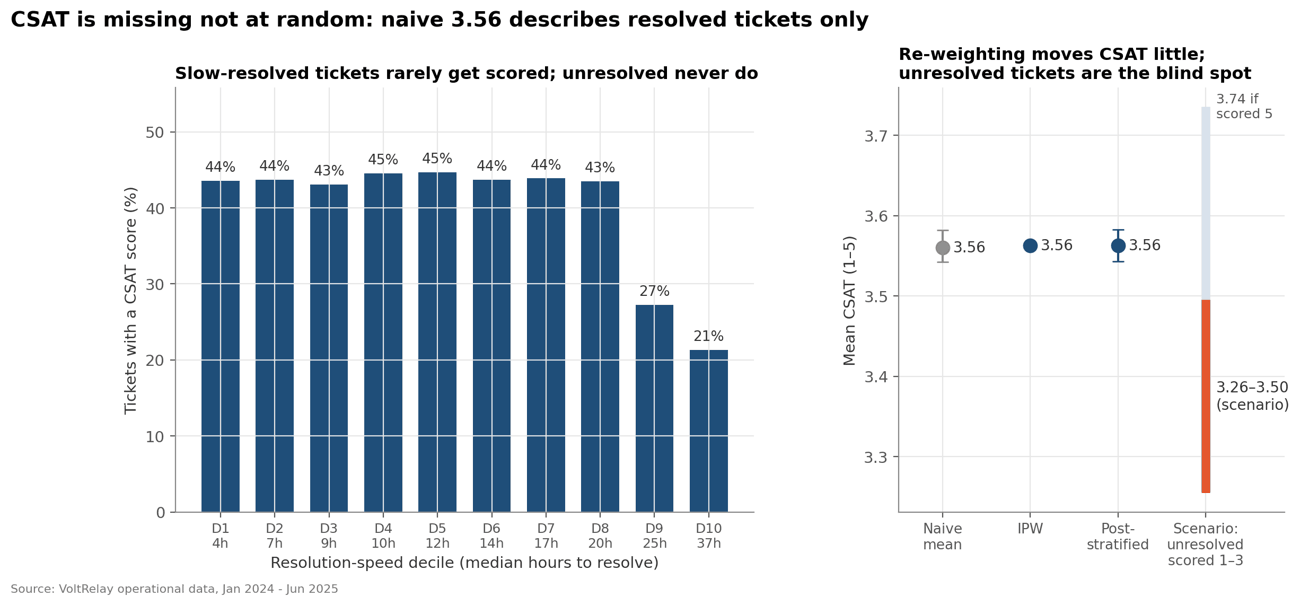

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q7_06_csat_ipw.png')

In [29]:
hdr("9. CSAT naive vs IPW")
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402

tk = tickets()
tkw = tk.filter(pl.col("in_window"))
st_resp = tkw.group_by("resolution_status").agg(pl.len().alias("n"), pl.col("has_csat").mean().alias("response_rate")).sort("resolution_status")
print(st_resp)
res = tkw.filter(pl.col("resolution_status") == "resolved").select("resolution_hours", "category", "channel", "priority", "has_csat", "csat_score").to_pandas()
res["speed_decile"] = pd.qcut(res["resolution_hours"], 10, labels=False) + 1
y = res["has_csat"].to_numpy()
X = pd.get_dummies(res[["speed_decile", "category", "channel", "priority"]].astype(str), drop_first=True).astype(float)
lr = LogisticRegression(max_iter=3000).fit(X, y)
ph = lr.predict_proba(X)[:, 1]
auc = roc_auc_score(y, ph)
sc_ = res["csat_score"].to_numpy()
naive = float(np.nanmean(sc_[y]))
w = 1 / ph[y]
ipw = float(np.sum(w * sc_[y]) / w.sum())
cells = res["speed_decile"].astype(str) + "|" + res["category"] + "|" + res["channel"]
codes, _u = pd.factorize(cells)
K = codes.max() + 1
s0 = np.where(y, sc_, 0.0)


def poststrat(idx):
    Nc = np.bincount(codes[idx], minlength=K); Rc = np.bincount(codes[idx], weights=y[idx], minlength=K)
    Sc = np.bincount(codes[idx], weights=s0[idx], minlength=K)
    ok = Rc > 0
    return float(np.sum(Nc[ok] * Sc[ok] / Rc[ok]) / Nc[ok].sum())


rng = np.random.default_rng(59500)
n_res = len(res)
ps = poststrat(np.arange(n_res))
boot = np.array([poststrat(rng.integers(0, n_res, n_res)) for _ in range(400)])
ci_ps = np.percentile(boot, [2.5, 97.5])
boot_naive = np.array([np.mean(rng.choice(sc_[y], y.sum())) for _ in range(400)])
ci_nv = np.percentile(boot_naive, [2.5, 97.5])
by_dec = res.groupby("speed_decile").agg(n=("has_csat", "size"), response_rate=("has_csat", "mean"), csat_mean=("csat_score", "mean"),
                                         hours_median=("resolution_hours", "median")).reset_index()
by_cat = res.groupby("category").agg(n=("has_csat", "size"), response_rate=("has_csat", "mean"), csat_mean=("csat_score", "mean")).reset_index()
n_unres = int(tkw.filter(pl.col("resolution_status") == "unresolved").height)
pop = n_res + n_unres
bounds = {s: (n_res * ipw + n_unres * s) / pop for s in (1.0, 2.0, 3.0, 4.0, 5.0)}
print(by_dec.round(3).to_string(index=False)); print(by_cat.round(3).to_string(index=False))
print(f"response model AUC = {auc:.3f} (resolved tickets, n={n_res:,})")
print(f"CSAT naive mean {naive:.3f} (95% CI {ci_nv[0]:.3f}-{ci_nv[1]:.3f}); IPW {ipw:.3f}; post-stratified {ps:.3f} (95% CI {ci_ps[0]:.3f}-{ci_ps[1]:.3f})")
print(f"unresolved tickets {n_unres:,} ({100 * n_unres / pop:.1f}% of resolved+unresolved) have 0% response. SCENARIO: if they would score "
      f"1/2/3 the ticket-population CSAT would be {bounds[1.0]:.2f}/{bounds[2.0]:.2f}/{bounds[3.0]:.2f}; the unrestricted range "
      f"(any score 1-5) is {bounds[1.0]:.2f}-{bounds[5.0]:.2f}")
csat_tab = pd.DataFrame([dict(estimator="naive mean of responders", value=naive, ci_low=ci_nv[0], ci_high=ci_nv[1]),
                         dict(estimator="IPW (logistic response model, resolved tickets)", value=ipw, ci_low=np.nan, ci_high=np.nan),
                         dict(estimator="post-stratified (speed decile x category x channel)", value=ps, ci_low=ci_ps[0], ci_high=ci_ps[1])]
                        + [dict(estimator=f"scenario: all resolved+unresolved if unresolved scored {s:.0f}", value=v, ci_low=np.nan, ci_high=np.nan) for s, v in bounds.items()])
csat_tab.to_csv(TAB / "q7_csat_estimates.csv", index=False)
n_csat_miss = int(tk["csat_score"].null_count())
add_issue("CSAT mostly missing, not at random", "documented", "Response rate by speed decile/status; logistic response model; IPW + post-stratification",
          n_csat_miss, tk.height, "tickets", "Report IPW/post-stratified CSAT for resolved tickets + bound for unresolved",
          f"Naive {naive:.2f} vs IPW {ipw:.2f} (post-strat {ps:.2f}, CI {ci_ps[0]:.2f}-{ci_ps[1]:.2f}): re-weighting barely moves it because scores "
          f"vary little with speed; the real gap is the {n_unres:,} unresolved tickets with 0% response (scenario: population CSAT "
          f"{bounds[1.0]:.2f}-{bounds[3.0]:.2f} if they scored 1-3; unrestricted range {bounds[1.0]:.2f}-{bounds[5.0]:.2f}).",
          f"naive {naive:.2f} vs IPW {ipw:.2f}; scenario with unresolved {bounds[1.0]:.2f}–{bounds[3.0]:.2f}", "medium")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.3})
axa.bar(by_dec["speed_decile"], 100 * by_dec["response_rate"], color=PALETTE["primary"], width=0.7)
for _, r in by_dec.iterrows():
    axa.text(r["speed_decile"], 100 * r["response_rate"] + 0.8, f"{100 * r['response_rate']:.0f}%", ha="center", va="bottom", fontsize=9.5, color="#333333")
axa.set_xticks(by_dec["speed_decile"], [f"D{int(d)}\n{h:.0f}h" for d, h in zip(by_dec["speed_decile"], by_dec["hours_median"])], fontsize=9)
axa.set_xlabel("Resolution-speed decile (median hours to resolve)"); axa.set_ylabel("Tickets with a CSAT score (%)")
axa.set_ylim(0, 100 * by_dec["response_rate"].max() * 1.25)
axa.set_title("Slow-resolved tickets rarely get scored; unresolved never do", fontsize=11.5)
labels = ["Naive mean", "IPW", "Post-stratified"]
vals = [naive, ipw, ps]
axb.errorbar([0], [naive], yerr=[[naive - ci_nv[0]], [ci_nv[1] - naive]], fmt="o", color=PALETTE["muted"], ms=9, capsize=4)
axb.plot([1], [ipw], "o", color=PALETTE["primary"], ms=9)
axb.errorbar([2], [ps], yerr=[[ps - ci_ps[0]], [ci_ps[1] - ps]], fmt="o", color=PALETTE["primary"], ms=9, capsize=4)
axb.vlines(3, bounds[1.0], bounds[5.0], color=PALETTE["light"], lw=6)
axb.vlines(3, bounds[1.0], bounds[3.0], color=PALETTE["accent"], lw=6)
axb.text(3.12, (bounds[1.0] + bounds[3.0]) / 2, f"{bounds[1.0]:.2f}–{bounds[3.0]:.2f}\n(scenario)", va="center", fontsize=10, color="#333333")
axb.text(3.12, bounds[5.0], f"{bounds[5.0]:.2f} if\nscored 5", va="center", fontsize=9, color="#555555")
for i, v in enumerate(vals):
    axb.text(i + 0.12, v, f"{v:.2f}", va="center", fontsize=10, color="#333333")
axb.set_xticks([0, 1, 2, 3], ["Naive\nmean", "IPW", "Post-\nstratified", "Scenario:\nunresolved\nscored 1–3"], fontsize=9.5)
axb.set_xlim(-0.5, 3.9); axb.set_ylabel("Mean CSAT (1–5)")
axb.set_title("Re-weighting moves CSAT little;\nunresolved tickets are the blind spot", fontsize=11.5)
fig.suptitle(f"CSAT is missing not at random: naive {naive:.2f} describes resolved tickets only", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "q7_06_csat_ipw")

## 10 · Undocumented issues
Physical plausibility (battery IDs, retirement, commissioning), metadata consistency (3W slots, firmware field),
integrity checks (sign-up / commissioning / decommissioning dates), tickets, queue caps and energy accounting.

In [30]:
hdr("10. Undocumented issues")
# 10a battery IDs are not physically tracked
bp = (events(["event_id", "rider_id", "event_ts", "battery_in_id", "battery_out_id", "city", "is_completed"]).filter(pl.col("is_completed"))
      .select(as_i32("rider_id", 3).alias("r"), "event_ts", as_i32("battery_in_id", 7).alias("bi"), as_i32("battery_out_id", 7).alias("bo"),
              pl.col("city").cast(pl.Categorical).alias("c"), pl.col("event_id").str.slice(3).cast(pl.Int64).alias("eid")))
chain = (bp.sort("r", "event_ts", "eid").with_columns(pl.col("r").shift(1).alias("r_p"), pl.col("bo").shift(1).alias("bo_p"))
         .filter(pl.col("r") == pl.col("r_p")).select((pl.col("bi") == pl.col("bo_p")).mean().alias("match"), pl.len().alias("n")).collect().row(0, named=True))
packc = (bp.sort("bo", "event_ts", "eid")                    # event_id breaks timestamp ties -> deterministic pairs
         .with_columns(pl.col("bo").shift(1).alias("bo_p"), pl.col("c").shift(1).alias("c_p"), pl.col("event_ts").shift(1).alias("ts_p"))
         .filter(pl.col("bo") == pl.col("bo_p"))
         .with_columns((pl.col("event_ts") - pl.col("ts_p")).dt.total_seconds().alias("gs"))   # strict seconds (total_minutes truncates)
         .select(pl.len().alias("pairs"), (pl.col("c") != pl.col("c_p")).sum().alias("diff_city"),
                 ((pl.col("c") != pl.col("c_p")) & (pl.col("gs") <= 3600)).sum().alias("diff_city_60"),
                 ((pl.col("c") != pl.col("c_p")) & (pl.col("gs") <= 600)).sum().alias("diff_city_10"),
                 (pl.col("gs") <= 3600).sum().alias("any_60"), (pl.col("gs").median() / 60).alias("median_gap_min")).collect().row(0, named=True))
print(f"returned pack == pack issued to the same rider last time: {100 * chain['match']:.3f}% of {chain['n']:,} consecutive swaps (physical tracking would give ~100%)")
print(f"consecutive issues of the same pack: {packc['pairs']:,}; in a different city {packc['diff_city']:,} ({100 * packc['diff_city'] / packc['pairs']:.1f}%); "
      f"different city within 60 min {packc['diff_city_60']:,} ({100 * packc['diff_city_60'] / packc['pairs']:.1f}%), within 10 min {packc['diff_city_10']:,}; "
      f"re-issued within 60 min anywhere {packc['any_60']:,}; median gap {packc['median_gap_min']:.0f} min")
add_issue("Battery IDs not physically tracked (packs 'teleport' between cities)", "undocumented",
          "Same pack issued in 2 cities ≤60 min apart; returned pack vs last issued pack per rider",
          packc["diff_city_60"], packc["pairs"], "pack re-issues", "Per-pack SoH valid; per-pack location / rotation / turnaround NOT valid",
          f"{packc['diff_city_60']:,} re-issues of a pack in another city within 60 min ({packc['diff_city_10']:,} within 10 min); riders return "
          f"the pack they were last given only {100 * chain['match']:.2f}% of the time.",
          f"{packc['diff_city_60']:,} impossible cross-city re-issues ≤60 min", "high")

# 10b commissioning / manufacture dates vs usage
btx = bt.with_columns((pl.col("commission_date") - pl.col("first_seen").dt.date()).dt.total_days().alias("days_before_commission"),
                      (pl.col("first_seen").dt.date() < pl.col("manufacture_date")).alias("used_before_manufacture"))
ubc = btx.filter(pl.col("used_before_commission").fill_null(False))
ubc_sup = btx.group_by("supplier").agg(pl.len().alias("packs"), pl.col("used_before_commission").fill_null(False).mean().alias("share_used_before_commission"),
                                       pl.col("used_before_manufacture").fill_null(False).mean().alias("share_used_before_manufacture")).sort("supplier")
n_ubm = int(btx["used_before_manufacture"].fill_null(False).sum())
print(f"packs used before recorded commission_date: {ubc.height:,} of {bt.height:,} ({100 * ubc.height / bt.height:.1f}%); median {ubc['days_before_commission'].median():.0f} days early; "
      f"used before manufacture_date: {n_ubm:,}")
print(ubc_sup)
add_issue("Packs used before recorded commission date", "undocumented", "first_seen in swaps vs batteries.commission_date / manufacture_date",
          ubc.height, bt.height, "packs", "Age from first_seen; ignore commission_date",
          f"{100 * ubc.height / bt.height:.0f}% of packs used a median {ubc['days_before_commission'].median():.0f} days before commissioning "
          f"({n_ubm:,} even before manufacture) — commission-based age would be negative.",
          f"pack age from commission_date wrong for {100 * ubc.height / bt.height:.0f}% of packs", "medium")

# 10c retired packs still issued
ret = bt.filter(pl.col("retired_date").is_not_null()).select(as_i32("battery_id", 7).alias("bo"), "retired_date")
sub70 = (events(["battery_out_id", "date", "soh_out_pct", "supplier_out", "is_completed"]).filter(pl.col("is_completed"))
         .select(as_i32("battery_out_id", 7).alias("bo"), "date", "soh_out_pct", "supplier_out")
         .join(ret.lazy(), on="bo", how="left")
         .select((pl.col("date") > pl.col("retired_date")).sum().alias("after_retire"),
                 pl.col("bo").filter(pl.col("date") > pl.col("retired_date")).n_unique().alias("packs_after"),
                 pl.col("soh_out_pct").filter(pl.col("date") > pl.col("retired_date")).median().alias("soh_after"),
                 (pl.col("soh_out_pct") < EOL_SOH).sum().alias("issued_below_eol"),
                 pl.col("date").filter(pl.col("soh_out_pct") < EOL_SOH).min().alias("first_below_eol"),
                 (pl.col("supplier_out") == "Kyron").filter(pl.col("soh_out_pct") < EOL_SOH).mean().alias("kyron_share_below_eol"))
         .collect().row(0, named=True))
print(f"swaps issuing a pack AFTER its recorded retirement (2025-06-15): {sub70['after_retire']:,} ({sub70['packs_after']:,} packs, median SoH {sub70['soh_after']:.1f}%)")
print(f"swaps issuing a pack below 70% SoH (EOL): {sub70['issued_below_eol']:,} ({100 * sub70['issued_below_eol'] / n_comp:.2f}% of {n_comp:,} completed), "
      f"first on {sub70['first_below_eol']}, Kyron share {100 * sub70['kyron_share_below_eol']:.1f}%")
# Cost-model consequence: wear charged on packs that are already past the 70% end of life. Under the brief's usage-based
# book depreciation (70% EOL, no salvage) such a pack is fully written off, so this charge is a sensitivity, not a fact:
# a replacement-cost view would keep it. (Cross-question: Q1 cm1 trend, Q4 Kyron economics.)
wm = (events(["month", "is_completed", "soh_out_pct", "wear_cost", "cm1"]).filter(pl.col("is_completed"))
      .group_by("month").agg(pl.len().alias("swaps"), (pl.col("soh_out_pct") < EOL_SOH).sum().alias("sub70_swaps"),
                             pl.col("wear_cost").filter(pl.col("soh_out_pct") < EOL_SOH).sum().alias("wear_past_eol_inr"),
                             pl.col("cm1").sum().alias("cm1_inr"))
      .with_columns((pl.col("cm1_inr") / pl.col("swaps")).alias("cm1_per_swap"),
                    ((pl.col("cm1_inr") + pl.col("wear_past_eol_inr")) / pl.col("swaps")).alias("cm1_per_swap_no_wear_past_eol"),
                    (pl.col("wear_past_eol_inr") / pl.col("swaps")).alias("wear_past_eol_per_swap"))
      .collect().sort("month"))
wm.write_csv(TAB / "q7_wear_past_eol_sensitivity.csv")
w_tot = float(wm["wear_past_eol_inr"].sum()); w_n = int(wm["sub70_swaps"].sum())
w_mean = float(events(["is_completed", "soh_out_pct", "wear_cost"]).filter(pl.col("is_completed") & (pl.col("soh_out_pct") < EOL_SOH))
               .select(pl.col("wear_cost").mean()).collect().item())
wmd = {(r["month"].year, r["month"].month): r for r in wm.iter_rows(named=True)}
print(f"WEAR PAST EOL: the cost model charges INR {w_tot:,.0f} of wear (INR {w_mean:.1f}/swap) on the {w_n:,} swaps that issued a pack already below 70% SoH")
print(wm.filter(pl.col("month") >= dt.date(2025, 3, 1)).select("month", "swaps", "sub70_swaps", "wear_past_eol_inr", "wear_past_eol_per_swap", "cm1_per_swap",
                                                             "cm1_per_swap_no_wear_past_eol").to_pandas().round(2).to_string(index=False))
print(f"sensitivity (70%-EOL, no-salvage book depreciation -> no wear past EOL): cm1/swap Apr-25 {wmd[(2025, 4)]['cm1_per_swap']:+.1f} -> "
      f"{wmd[(2025, 4)]['cm1_per_swap_no_wear_past_eol']:+.1f}, May-25 {wmd[(2025, 5)]['cm1_per_swap']:+.1f} -> {wmd[(2025, 5)]['cm1_per_swap_no_wear_past_eol']:+.1f}, "
      f"Jun-25 {wmd[(2025, 6)]['cm1_per_swap']:+.1f} -> {wmd[(2025, 6)]['cm1_per_swap_no_wear_past_eol']:+.1f} INR; wear past EOL = INR "
      f"{wmd[(2025, 5)]['wear_past_eol_per_swap']:.1f} per May-25 swap and INR {wmd[(2025, 6)]['wear_past_eol_per_swap']:.1f} per Jun-25 swap")
add_issue("Packs below the 70% EOL SoH still issued (incl. 'retired' packs after 15-Jun-2025)", "undocumented",
          "SoH of issued packs vs 70% EOL; join issued pack to retired_date; wear cost charged on those swaps", sub70["issued_below_eol"], n_comp, "swaps",
          "Keep (real swaps); flag; treat retirement record as administrative; size wear-past-EOL as a cm1 sensitivity",
          f"{sub70['issued_below_eol']:,} swaps issued sub-70% packs (first {sub70['first_below_eol']}, all Kyron); {sub70['after_retire']:,} came after "
          f"retirement, using {sub70['packs_after']:,} 'retired' packs at median SoH {sub70['soh_after']:.1f}%. The cost model charges INR "
          f"{w_tot / 1e6:.1f}M of wear on them (INR {w_mean:.1f}/swap); without it cm1/swap would be {wmd[(2025, 5)]['cm1_per_swap_no_wear_past_eol']:+.1f} "
          f"(May-25) and {wmd[(2025, 6)]['cm1_per_swap_no_wear_past_eol']:+.1f} (Jun-25) instead of {wmd[(2025, 5)]['cm1_per_swap']:+.1f} / "
          f"{wmd[(2025, 6)]['cm1_per_swap']:+.1f}.",
          f"{sub70['issued_below_eol']:,} sub-EOL swaps; ₹{w_tot / 1e6:.1f}M wear charged past EOL", "high")

# 10d 3W swaps at stations with no 3W slots
s3 = st_all.filter(~pl.col("is_test")).select("station_id", "slots_3w")
e3 = (events(["station_id", "vehicle_class", "is_stockout"]).join(s3.lazy(), on="station_id")
      .group_by((pl.col("slots_3w") == 0).alias("no_3w_slots"), "vehicle_class")
      .agg(pl.len().alias("attempts"), pl.col("is_stockout").mean().alias("stockout_rate"), pl.col("station_id").n_unique().alias("stations"))
      .collect().sort("no_3w_slots", "vehicle_class"))
print(e3)
n3_bad = int(e3.filter(pl.col("no_3w_slots") & (pl.col("vehicle_class") == "3W"))["attempts"].item())
n_st0 = s3.filter(pl.col("slots_3w") == 0).height
sh3 = {r["no_3w_slots"]: r["attempts"] for r in e3.filter(pl.col("vehicle_class") == "3W").iter_rows(named=True)}
tot3 = {k: int(e3.filter(pl.col("no_3w_slots") == k)["attempts"].sum()) for k in (True, False)}
print(f"3W attempts at the {n_st0} stations with slots_3w = 0: {n3_bad:,} ({100 * n3_bad / N_EV:.1f}% of attempts); 3W share there "
      f"{100 * sh3[True] / tot3[True]:.1f}% vs {100 * sh3[False] / tot3[False]:.1f}% at stations with 3W slots")
add_issue("3W swaps at stations with zero 3W slots", "undocumented", "Event vehicle class vs stations.slots_3w",
          n3_bad, N_EV, "attempts", "Flag; do not use slots_3w / inventory_target_3w for 3W capacity",
          f"{n_st0} stations list 0 3W slots yet serve {n3_bad:,} 3W attempts (3W share {100 * sh3[True] / tot3[True]:.1f}% vs "
          f"{100 * sh3[False] / tot3[False]:.1f}% elsewhere, same stockout rate) — slot metadata does not constrain 3W activity; "
          f"swaps_per_slot_day and 3W capacity metrics are unreliable.",
          f"{n3_bad / 1e3:.0f}K 3W attempts at 0-slot stations; capacity metrics unreliable", "medium")

# 10e firmware field is a static station attribute, not the firmware at event time
fws = events(["station_id", "station_firmware", "date"]).group_by("station_id").agg(pl.col("station_firmware").n_unique().alias("n_fw")).collect()
pre_fw = events(["station_firmware", "date"]).filter((pl.col("station_firmware") == "v3.2.0") & (pl.col("date") < BUG_A)).select(pl.len()).collect().item()
print(f"stations whose events show >1 firmware value: {int((fws['n_fw'] > 1).sum())} of {fws.height}; v3.2.0-labelled attempts dated before the "
      f"v3.2.0 install (10-Mar-2025): {pre_fw:,}")
add_issue("station_firmware is static per station (not 'firmware at event time')", "undocumented",
          "Distinct firmware per station over time vs stations.firmware_updated_date", pre_fw, N_EV, "attempts",
          "Use only as station attribute; no pre/post firmware comparisons",
          f"All {fws.height} stations carry one value for 18 months; {pre_fw:,} attempts are labelled v3.2.0 before it was installed.",
          "firmware field cannot date firmware changes", "low")

# 10f integrity checks that PASS
integ = (events(["date", "signup_date", "commissioned_date", "station_id", "battery_in_id", "rider_vehicle_class"])
         .join(st_all.lazy().select("station_id", "decommissioned_date"), on="station_id", how="left")
         .select((pl.col("date") < pl.col("signup_date")).sum().alias("before_signup"),
                 (pl.col("date") < pl.col("commissioned_date")).sum().alias("before_commissioning"),
                 (pl.col("date") > pl.col("decommissioned_date")).sum().alias("after_decommissioning"),
                 (pl.col("battery_in_id").str.slice(4, 2) != pl.col("rider_vehicle_class")).sum().alias("pack_vs_rider_class_mismatch"))
         .collect().row(0, named=True))
print("integrity checks (violations):", integ)
add_issue("Integrity checks: events before sign-up / commissioning, after decommissioning, pack-vs-vehicle class", "check passed",
          "Date and class cross-checks on every attempt", sum(integ.values()), N_EV, "attempts", "No action",
          "0 violations in all four checks — rider/station timelines are consistent.", "0 violations (4 checks)", "pass")

# 10g tickets
rdt = riders().select("rider_id", "signup_date", "first_attempt_ts")
tki = tk.join(rdt, on="rider_id", how="left")
t_out, t_test = int((~tk["in_window"]).sum()), int(tk["is_test"].sum())
t_bs = int((tki["created_date"] < tki["signup_date"]).sum()); t_bf = int((tki["created_ts"] < tki["first_attempt_ts"]).sum())
t_other = int((tk["category"] == "other").sum())
other_cm = tk.filter(pl.col("category") == "other")["rider_comment"].unique().sort().to_list()
print(f"tickets: outside window {t_out}, referencing test stations {t_test}, created before rider sign-up {t_bs}, before rider's first attempt {t_bf}")
print(f"category 'other' = {t_other:,} tickets ({100 * t_other / tk.height:.1f}%), consisting only of {len(other_cm)} vehicle-blaming templates: {other_cm}")
add_issue("Tickets outside window / at test stations / before sign-up", "undocumented", "created_ts vs window, station is_test, rider signup",
          t_out + t_test + t_bs, tk.height, "tickets", "Exclude from in-window ticket KPIs (flags in_window, is_test)",
          f"{t_out} outside Jan-24..Jun-25, {t_test} at test stations, {t_bs} before the rider signed up ({t_bf} before first attempt).",
          f"{t_out + t_test + t_bs} tickets to exclude/flag", "low")
add_issue("Ticket category 'other' hides vehicle/battery complaints", "documented", "Distinct comment templates per category",
          t_other, tk.height, "tickets", "Re-classify via comment text (ticket-text analysis)",
          f"All {t_other:,} 'other' tickets are 3 vehicle-blaming templates ('{other_cm[0]}', ...) — likely range/battery issues mis-filed.",
          f"{100 * t_other / tk.height:.0f}% of tickets in an uninformative 'other' bucket", "medium")

# 10h queue-wait caps
qc = (events(["event_type", "queue_wait_sec"]).group_by("event_type")
      .agg(pl.col("queue_wait_sec").max().alias("max_s"), (pl.col("queue_wait_sec") == pl.col("queue_wait_sec").max()).sum().alias("at_max"),
           pl.len().alias("n"), pl.col("queue_wait_sec").quantile(0.99).alias("p99"), pl.col("queue_wait_sec").mean().alias("mean"))
      .collect().sort("event_type"))
print(qc)
n_cap = int(qc.filter(pl.col("event_type").is_in(["swap_completed", "abandoned_queue"]))["at_max"].sum())
cap_c = qc.filter(pl.col("event_type") == "swap_completed").row(0, named=True); cap_a = qc.filter(pl.col("event_type") == "abandoned_queue").row(0, named=True)
add_issue("queue_wait_sec hard caps (1,800 s completed / 2,400 s abandoned)", "undocumented", "Point mass at the maximum by event type",
          n_cap, N_EV, "attempts", "Keep; treat as right-censored; report medians/p90",
          f"{cap_c['at_max']} completed swaps at exactly {cap_c['max_s']} s and {cap_a['at_max']} abandons at {cap_a['max_s']} s; p99 waits "
          f"({cap_c['p99']:.0f}/{cap_a['p99']:.0f} s) sit below the caps, so means/p90 are unaffected.", "negligible (censoring only)", "low")

# 10i energy accounting
en = (events(["energy_to_recharge_kwh", "soc_in_pct", "soh_in_pct", "battery_in_id", "is_completed", "charger_generation"])
      .filter(pl.col("is_completed"))
      .with_columns(pl.when(pl.col("battery_in_id").str.slice(4, 2) == "3W").then(4.8).otherwise(2.1).alias("cap"))
      .with_columns(((100 - pl.col("soc_in_pct")) / 100 * pl.col("cap") * pl.col("soh_in_pct") / 100).alias("need"))
      .with_columns((pl.col("energy_to_recharge_kwh") / pl.col("need")).alias("k")))
ek = en.select(pl.col("k").quantile(0.01).alias("p01"), pl.col("k").median().alias("median"), pl.col("k").quantile(0.99).alias("p99"),
               ((pl.col("k") < 0.7) | (pl.col("k") > 1.6)).sum().alias("implausible"), pl.corr("energy_to_recharge_kwh", "need").alias("r"),
               pl.len().alias("n")).collect().row(0, named=True)
ekg = en.group_by("charger_generation").agg(pl.col("k").median().alias("grid_kwh_per_kwh_needed")).collect().sort("charger_generation")
egd = {r["charger_generation"]: r["grid_kwh_per_kwh_needed"] for r in ekg.iter_rows(named=True)}
print(f"grid kWh per kWh needed to refill to 100% (= (100-SoC_in) x capacity x SoH): p01 {ek['p01']:.3f}, median {ek['median']:.3f}, p99 {ek['p99']:.3f}; "
      f"rows outside 0.7-1.6 (implausible) {ek['implausible']:,}; corr(energy, need) = {ek['r']:.3f}")
print(ekg)
print(f"Gen1 chargers draw {100 * (egd['Gen1'] / egd['Gen3'] - 1):.1f}% more grid energy per kWh delivered than Gen3")
add_issue("Energy-to-recharge vs SoC/SoH/capacity consistency", "check passed", "Ratio of grid kWh to kWh needed per swap; by charger generation",
          ek["implausible"], ek["n"], "swaps", "No action (energy cost per swap trustworthy)",
          f"r = {ek['r']:.3f}; median {ek['median']:.2f} grid kWh per kWh needed (p01–p99 {ek['p01']:.2f}–{ek['p99']:.2f}); {ek['implausible']:,} rows outside 0.7–1.6. "
          f"Efficiency rises with charger generation (Gen1 {egd['Gen1']:.3f}, Gen2 {egd['Gen2']:.3f}, Gen3 {egd['Gen3']:.3f}).",
          f"consistent (r = {ek['r']:.2f}); Gen1 uses {100 * (egd['Gen1'] / egd['Gen3'] - 1):.0f}% more energy than Gen3", "pass")

# 10j KYC
rk = riders().select("rider_id", "kyc_verified", "n_attempts", "n_swaps")
kyc_r = int((~rk["kyc_verified"]).sum()); kyc_ev = int(rk.filter(~pl.col("kyc_verified"))["n_attempts"].fill_null(0).sum())
kyc_sw = int(rk.filter(~pl.col("kyc_verified"))["n_swaps"].fill_null(0).sum())
print(f"KYC-unverified riders: {kyc_r} riders with {kyc_ev:,} attempts / {kyc_sw:,} completed swaps ({100 * kyc_ev / N_EV:.1f}% of attempts)")
add_issue("Riders without KYC verification swapping", "undocumented", "riders.kyc_verified vs activity", kyc_ev, N_EV, "attempts",
          "Keep; flag for compliance", f"{kyc_r} unverified riders made {kyc_sw:,} completed swaps.", "compliance flag, no KPI effect", "low")


10. Undocumented issues   [  4.7s]


returned pack == pack issued to the same rider last time: 0.032% of 3,566,737 consecutive swaps (physical tracking would give ~100%)
consecutive issues of the same pack: 3,580,175; in a different city 2,912,202 (81.3%); different city within 60 min 239,049 (6.7%), within 10 min 44,274; re-issued within 60 min anywhere 294,264; median gap 895 min
packs used before recorded commission_date: 5,154 of 6,500 (79.3%); median 191 days early; used before manufacture_date: 4,506
shape: (3, 4)
┌──────────┬───────┬──────────────────────────────┬───────────────────────────────┐
│ supplier ┆ packs ┆ share_used_before_commission ┆ share_used_before_manufacture │
│ ---      ┆ ---   ┆ ---                          ┆ ---                           │
│ str      ┆ u32   ┆ f64                          ┆ f64                           │
╞══════════╪═══════╪══════════════════════════════╪═══════════════════════════════╡
│ Amptek   ┆ 1307  ┆ 1.0                          ┆ 1.0                           │
│ Cello

shape: (4, 5)
┌─────────────┬───────────────┬──────────┬───────────────┬──────────┐
│ no_3w_slots ┆ vehicle_class ┆ attempts ┆ stockout_rate ┆ stations │
│ ---         ┆ ---           ┆ ---      ┆ ---           ┆ ---      │
│ bool        ┆ str           ┆ u32      ┆ f64           ┆ u32      │
╞═════════════╪═══════════════╪══════════╪═══════════════╪══════════╡
│ false       ┆ 2W            ┆ 1478814  ┆ 0.03065       ┆ 67       │
│ false       ┆ 3W            ┆ 178104   ┆ 0.064373      ┆ 67       │
│ true        ┆ 2W            ┆ 1920754  ┆ 0.031652      ┆ 83       │
│ true        ┆ 3W            ┆ 237310   ┆ 0.064051      ┆ 83       │
└─────────────┴───────────────┴──────────┴───────────────┴──────────┘
3W attempts at the 83 stations with slots_3w = 0: 237,310 (6.2% of attempts); 3W share there 11.0% vs 10.7% at stations with 3W slots
stations whose events show >1 firmware value: 0 of 150; v3.2.0-labelled attempts dated before the v3.2.0 install (10-Mar-2025): 1,083,456
integrity chec

shape: (5, 6)
┌───────────────────────────┬───────┬────────┬─────────┬────────┬────────────┐
│ event_type                ┆ max_s ┆ at_max ┆ n       ┆ p99    ┆ mean       │
│ ---                       ┆ ---   ┆ ---    ┆ ---     ┆ ---    ┆ ---        │
│ str                       ┆ i32   ┆ u32    ┆ u32     ┆ f64    ┆ f64        │
╞═══════════════════════════╪═══════╪════════╪═════════╪════════╪════════════╡
│ abandoned_queue           ┆ 2400  ┆ 34     ┆ 67663   ┆ 1642.0 ┆ 702.789161 │
│ cancelled_by_rider        ┆ 89    ┆ 197    ┆ 16458   ┆ 89.0   ┆ 44.583424  │
│ failed_no_charged_battery ┆ 59    ┆ 2241   ┆ 132786  ┆ 59.0   ┆ 29.49631   │
│ failed_system_error       ┆ 89    ┆ 130    ┆ 11400   ┆ 89.0   ┆ 44.425877  │
│ swap_completed            ┆ 1800  ┆ 143    ┆ 3586675 ┆ 754.0  ┆ 243.718015 │
└───────────────────────────┴───────┴────────┴─────────┴────────┴────────────┘


grid kWh per kWh needed to refill to 100% (= (100-SoC_in) x capacity x SoH): p01 0.855, median 1.098, p99 1.383; rows outside 0.7-1.6 (implausible) 719; corr(energy, need) = 0.982
shape: (3, 2)
┌────────────────────┬─────────────────────────┐
│ charger_generation ┆ grid_kwh_per_kwh_needed │
│ ---                ┆ ---                     │
│ str                ┆ f64                     │
╞════════════════════╪═════════════════════════╡
│ Gen1               ┆ 1.127578                │
│ Gen2               ┆ 1.077359                │
│ Gen3               ┆ 1.044268                │
└────────────────────┴─────────────────────────┘
Gen1 chargers draw 8.0% more grid energy per kWh delivered than Gen3
KYC-unverified riders: 746 riders with 149,851 attempts / 139,764 completed swaps (3.9% of attempts)


## 11 · Anomalies
### 11a Stations with extreme service-failure rates — funnel plot controlled for city x month x vehicle class
Expected failures for each station = Σ attempts x peer failure rate of the same city, month and vehicle class
(peers exclude the station itself), i.e. indirect standardisation; this removes seasonality, city mix and the timing of
commissioning (Wave-2 sites only lived through the hot months). Limits are widened for over-dispersion
(Spiegelhalter 2005: φ from 10%-winsorised z-scores). Stage 2 asks whether the excess spread is explained by station
design. Q2/Q3 show Gen1 chargers derate in heat, so the design effect may be heat-conditional: we fit the additive
design model (spec A) and one with a charger-generation x hot-city interaction (spec B; hot = Delhi NCR, Jaipur,
Hyderabad), and only call a station anomalous if it sits outside the limits of the better-specified model.


11a. Station failure-rate funnel   [  5.9s]


stations 150; overdispersion phi = 35.68; beyond 99.8% limits: Poisson 41 high / 39 low; after overdispersion 0 high / 3 low
Spearman rho(z_adj, swaps per slot-day) = -0.12 (p = 0.13)
 station_id      city expansion_wave charger_generation     location_type connectivity_tier  inventory_target_2w  swaps_per_slot_day  attempts  observed  expected  smr  z_adj
STN-JAI-150    Jaipur   Wave2_2025H1               Gen3            market              good                   20                7.44     11485       557   1207.10 0.46  -3.13
STN-DEL-058 Delhi NCR   Wave2_2025H1               Gen3 highway_fuel_pump              good                    9                9.19     14793       778   1757.48 0.44  -3.91
STN-JAI-148    Jaipur   Wave2_2025H1               Gen3 highway_fuel_pump              good                    6               20.98     26552      1250   2527.38 0.49  -4.25
charger_generation  stations  high  pooled_smr
              Gen1        51     0       1.143
              Gen2    

stage 2 spec A (design + load, no heat term): residual scale 15.44; deviance explained 78.2%; 99.8% band at the median station +/-34%; stations outside: 0 []
stage 2 spec B (+ generation x hot city)     : residual scale 4.31; deviance explained 93.8%; 99.8% band at the median station +/-18%; stations outside: 1 ['STN-HYD-081']
robustness: spec B with attempts per active day as load (no slot metadata): residual scale 4.26; deviance explained 93.9%; 99.8% band at the median station +/-18%; stations outside: 0 []
spec A leaves 17 small stations (fitted failures < 300; 16 Wave2, 15 in cool cities) at pooled observed/fit 1.41; spec B fits the same stations at 1.06
stations by wave x generation (Wave2 is all Gen3; only the Wave1 Gen3 sites separate the Gen3 and Wave2 terms):
charger_generation  Gen1  Gen2  Gen3
expansion_wave                      
Launch                51    39     0
Wave1_2024H2           0    23     7
Wave2_2025H1           0     0    30
                       model       

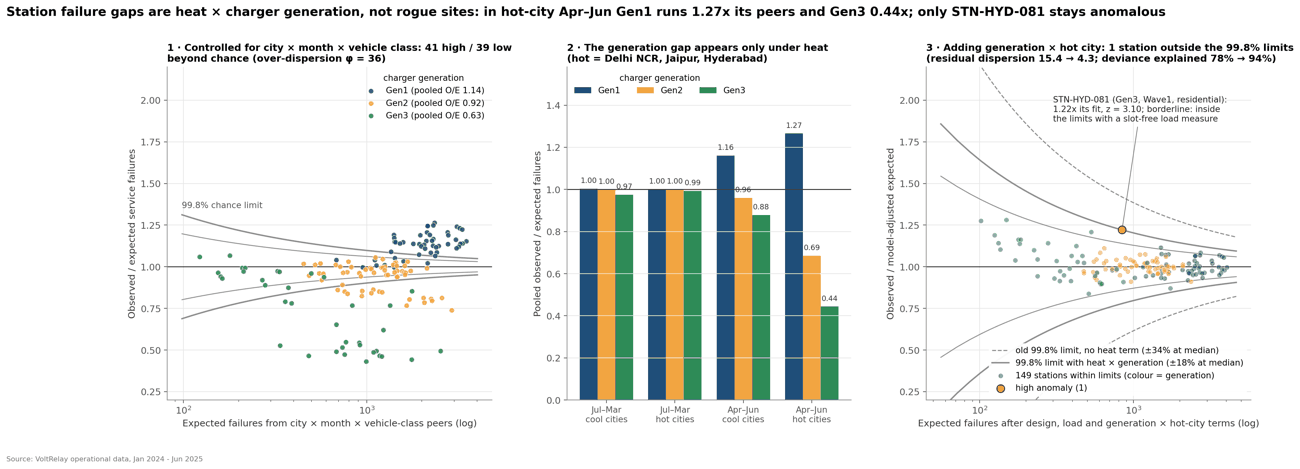

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q7_03_station_failure_funnel.png')

In [31]:
hdr("11a. Station failure-rate funnel")
smv = (events(["station_id", "city", "month", "vehicle_class", "is_service_failure"])
       .group_by("station_id", "city", "month", "vehicle_class").agg(pl.len().alias("att"), pl.col("is_service_failure").sum().alias("fail")).collect())
cellv = smv.group_by("city", "month", "vehicle_class").agg(pl.col("att").sum().alias("c_att"), pl.col("fail").sum().alias("c_fail"))
smv = (smv.join(cellv, on=["city", "month", "vehicle_class"])
       .with_columns(((pl.col("c_fail") - pl.col("fail")) / (pl.col("c_att") - pl.col("att"))).fill_nan(None).alias("peer"))
       .with_columns((pl.col("att") * pl.col("peer")).alias("exp")))
fun = (smv.group_by("station_id").agg(pl.col("att").sum().alias("attempts"), pl.col("fail").sum().alias("observed"), pl.col("exp").sum().alias("expected"))
       .with_columns((pl.col("observed") / pl.col("expected")).alias("smr"), ((pl.col("observed") - pl.col("expected")) / pl.col("expected").sqrt()).alias("z")))
zz = fun["z"].to_numpy(); lo, hi = np.percentile(zz, [10, 90])
phi = float(np.mean(np.clip(zz, lo, hi) ** 2))
fun = fun.with_columns((pl.col("z") / np.sqrt(max(phi, 1.0))).alias("z_adj"))
sm_util = station_month().group_by("station_id").agg(pl.col("swaps_per_slot_day").mean().alias("swaps_per_slot_day"))
fun = (fun.join(st_all.select("station_id", "city", "expansion_wave", "charger_generation", "location_type", "host_type", "connectivity_tier",
                              "slots_2w", "slots_3w", "inventory_target_2w", "competitor_within_1_5km_since", "firmware_version"), on="station_id", how="left")
       .join(sm_util, on="station_id", how="left")
       .with_columns(pl.when(pl.col("z_adj") > 3.09).then(pl.lit("high outlier")).when(pl.col("z_adj") < -3.09).then(pl.lit("low outlier"))
                     .otherwise(pl.lit("within limits")).alias("flag"))
       .sort("z_adj", descending=True))
n_hi_raw, n_lo_raw = int((fun["z"] > 3.09).sum()), int((fun["z"] < -3.09).sum())
n_hi, n_lo = int((fun["flag"] == "high outlier").sum()), int((fun["flag"] == "low outlier").sum())
rho = stats.spearmanr(fun["z_adj"].to_numpy(), fun["swaps_per_slot_day"].to_numpy(), nan_policy="omit")
print(f"stations {fun.height}; overdispersion phi = {phi:.2f}; beyond 99.8% limits: Poisson {n_hi_raw} high / {n_lo_raw} low; "
      f"after overdispersion {n_hi} high / {n_lo} low")
print(f"Spearman rho(z_adj, swaps per slot-day) = {rho.statistic:.2f} (p = {rho.pvalue:.2g})")
show = ["station_id", "city", "expansion_wave", "charger_generation", "location_type", "connectivity_tier", "inventory_target_2w",
        "swaps_per_slot_day", "attempts", "observed", "expected", "smr", "z_adj"]
print(fun.filter(pl.col("flag") != "within limits").select(show).to_pandas().round(2).to_string(index=False))
for col in ["charger_generation", "expansion_wave", "location_type", "connectivity_tier"]:
    t_ = (fun.group_by(col).agg(pl.len().alias("stations"), (pl.col("flag") == "high outlier").sum().alias("high"),
                                (pl.col("observed").sum() / pl.col("expected").sum()).alias("pooled_smr")).sort(col))
    print(t_.to_pandas().round(3).to_string(index=False))

# Is the generation effect constant, or does it exist only under heat? (Q2/Q3: Gen1 derates above ~41 C cabinet temp.)
# Stage-1 pooled O/E by hot city x Apr-Jun x charger generation.
HOT = ["Delhi NCR", "Jaipur", "Hyderabad"]               # the three cities with the Apr-Jun heat regime (Q2/Q3)
GENS = ["Gen1", "Gen2", "Gen3"]
smv_g = (smv.join(st_all.select("station_id", "charger_generation"), on="station_id", how="left")
         .with_columns(pl.col("city").is_in(HOT).alias("hot_city"), pl.col("month").dt.month().is_in([4, 5, 6]).alias("apr_jun")))
oe_ctx = (smv_g.group_by("hot_city", "apr_jun", "charger_generation")
          .agg((pl.col("fail").sum() / pl.col("exp").sum()).alias("pooled_oe"), pl.col("att").sum().alias("attempts"),
               pl.col("station_id").n_unique().alias("stations"))
          .sort("hot_city", "apr_jun", "charger_generation"))
oe_ctx.write_csv(TAB / "q7_station_oe_heat_generation.csv")
oed = {(r["hot_city"], r["apr_jun"], r["charger_generation"]): r["pooled_oe"] for r in oe_ctx.iter_rows(named=True)}
oe_out = [v for (h_, s_, g_), v in oed.items() if not s_]
print("stage-1 pooled O/E by hot city x Apr-Jun x charger generation:")
print(oe_ctx.pivot(on="charger_generation", index=["hot_city", "apr_jun"], values="pooled_oe").sort("hot_city", "apr_jun")
      .to_pandas().round(3).to_string(index=False))
print(f"outside Apr-Jun every generation sits at O/E {min(oe_out):.2f}-{max(oe_out):.2f}; Apr-Jun hot cities Gen1/Gen2/Gen3 = "
      f"{oed[(True, True, 'Gen1')]:.2f}/{oed[(True, True, 'Gen2')]:.2f}/{oed[(True, True, 'Gen3')]:.2f}; Apr-Jun cool cities = "
      f"{oed[(False, True, 'Gen1')]:.2f}/{oed[(False, True, 'Gen2')]:.2f}/{oed[(False, True, 'Gen3')]:.2f}")

# Stage 2: quasi-Poisson GLM with the stage-1 expectation as offset + station design & load.
# Spec A (original): additive design terms. Spec B: + charger generation x hot city (the heat-conditional design effect).
import statsmodels.api as sm  # noqa: E402
import statsmodels.formula.api as smf  # noqa: E402

fd = fun.to_pandas()
fd["hot"] = fd["city"].isin(HOT)
fd["log_util"] = np.log(fd["swaps_per_slot_day"]); fd["log_E"] = np.log(fd["expected"])
apd = station_month().group_by("station_id").agg((pl.col("attempts").sum() / pl.col("active_days").sum()).alias("apd"))
fd["log_apd"] = np.log(fd["station_id"].map(dict(zip(apd["station_id"].to_list(), apd["apd"].to_list()))))
SPEC_A = "observed ~ C(charger_generation) + C(expansion_wave) + C(location_type) + C(connectivity_tier) + log_util"
SPEC_B = "observed ~ C(charger_generation) * hot + C(expansion_wave) + C(location_type) + C(connectivity_tier) + log_util"


def fit_stage2(spec):
    m = smf.glm(spec, data=fd, family=sm.families.Poisson(), offset=fd["log_E"]).fit(scale="X2")
    mu_ = m.fittedvalues
    return m, mu_, (fd["observed"] - mu_) / np.sqrt(mu_ * m.scale)


def describe_fit(lab, m, mu_, z_):
    out = dict(model=lab, scale=float(m.scale), dev_expl=100 * (1 - m.deviance / m.null_deviance),
               band_pct=100 * 3.09 * np.sqrt(m.scale / np.median(mu_)), outside=fd.loc[np.abs(z_) > 3.09, "station_id"].tolist())
    print(f"{lab}: residual scale {out['scale']:.2f}; deviance explained {out['dev_expl']:.1f}%; 99.8% band at the median station "
          f"+/-{out['band_pct']:.0f}%; stations outside: {len(out['outside'])} {out['outside']}")
    return out


glmA, muA, zA = fit_stage2(SPEC_A)
glmB, muB, zB = fit_stage2(SPEC_B)
glmC, muC, zC = fit_stage2(SPEC_B.replace("log_util", "log_apd"))
fitA = describe_fit("stage 2 spec A (design + load, no heat term)", glmA, muA, zA)
fitB = describe_fit("stage 2 spec B (+ generation x hot city)     ", glmB, muB, zB)
fitC = describe_fit("robustness: spec B with attempts per active day as load (no slot metadata)", glmC, muC, zC)
smallA = (muA < 300).to_numpy()
n_small, n_small_w2 = int(smallA.sum()), int((fd.loc[smallA, "expansion_wave"] == "Wave2_2025H1").sum())
n_small_cool, oe_smallA = int((~fd.loc[smallA, "hot"]).sum()), float(fd.loc[smallA, "observed"].sum() / muA[smallA].sum())
oe_smallB = float(fd.loc[smallA, "observed"].sum() / muB[smallA].sum())
print(f"spec A leaves {n_small} small stations (fitted failures < 300; {n_small_w2} Wave2, {n_small_cool} in cool cities) at pooled "
      f"observed/fit {oe_smallA:.2f}; spec B fits the same stations at {oe_smallB:.2f}")
xt = pd.crosstab(fd["expansion_wave"], fd["charger_generation"])
print("stations by wave x generation (Wave2 is all Gen3; only the Wave1 Gen3 sites separate the Gen3 and Wave2 terms):")
print(xt.to_string())


def rr_table(m, lab):
    ci = m.conf_int()
    return pd.DataFrame({"model": lab, "term": m.params.index, "rate_ratio": np.exp(m.params.values), "p": m.pvalues.values,
                         "ci_low": np.exp(ci[0].values), "ci_high": np.exp(ci[1].values)})


rr_tab = pd.concat([rr_table(glmA, "A design + load"), rr_table(glmB, "B + generation x hot city"),
                    rr_table(glmC, "C = B with attempts/day load")], ignore_index=True)
rr_tab.to_csv(TAB / "q7_station_failure_glm.csv", index=False)
print(rr_tab.round(3).to_string(index=False))
pB = glmB.params
gen_rr = {(g_, h_): float(np.exp(pB.get(f"C(charger_generation)[T.{g_}]", 0.0) + (pB.get(f"C(charger_generation)[T.{g_}]:hot[T.True]", 0.0) if h_ else 0.0)))
          for g_ in ["Gen2", "Gen3"] for h_ in (False, True)}
print(f"spec B rate ratios vs Gen1 (same city-month peers): cool cities Gen2 {gen_rr[('Gen2', False)]:.2f}, Gen3 {gen_rr[('Gen3', False)]:.2f}; "
      f"hot cities Gen2 {gen_rr[('Gen2', True)]:.2f}, Gen3 {gen_rr[('Gen3', True)]:.2f}")
rrA = rr_tab[rr_tab.model == "A design + load"].set_index("term")
print(f"spec A (heat-averaged) rate ratios: Gen3 {rrA.loc['C(charger_generation)[T.Gen3]', 'rate_ratio']:.2f} "
      f"({rrA.loc['C(charger_generation)[T.Gen3]', 'ci_low']:.2f}-{rrA.loc['C(charger_generation)[T.Gen3]', 'ci_high']:.2f}), "
      f"Wave2 {rrA.loc['C(expansion_wave)[T.Wave2_2025H1]', 'rate_ratio']:.2f} "
      f"({rrA.loc['C(expansion_wave)[T.Wave2_2025H1]', 'ci_low']:.2f}-{rrA.loc['C(expansion_wave)[T.Wave2_2025H1]', 'ci_high']:.2f})")

# primary stage-2 model = spec B
glm, scale2 = glmB, float(glmB.scale)
fd["mu_A"], fd["z_A"] = muA, zA
fd["mu"] = muB
fd["ratio_struct"] = fd["observed"] / fd["mu"]
fd["z_struct"] = zB
fd["flag_struct"] = np.where(fd["z_struct"] > 3.09, "high anomaly", np.where(fd["z_struct"] < -3.09, "low anomaly", "within limits"))
fd.sort_values("z_struct", ascending=False).to_csv(TAB / "q7_station_failure_funnel.csv", index=False)
n_hi2, n_lo2 = int((fd["flag_struct"] == "high anomaly").sum()), int((fd["flag_struct"] == "low anomaly").sum())
dev_share = 1 - glmB.deviance / glmB.null_deviance
print(f"stage 2 (spec B): residual scale {scale2:.2f} (vs {phi:.1f} at stage 1 and {fitA['scale']:.2f} under spec A); deviance explained "
      f"{100 * dev_share:.1f}%; anomalies beyond 99.8%: {n_hi2} high / {n_lo2} low")
fd["mu_C"], fd["z_C"] = muC, zC
anom = fd.loc[fd.flag_struct != "within limits"]
print(anom[["station_id", "city", "expansion_wave", "charger_generation", "location_type", "host_type", "connectivity_tier",
            "swaps_per_slot_day", "observed", "expected", "mu", "ratio_struct", "z_struct", "z_A", "z_C"]].round(2).to_string(index=False))
cellfit = (fd.groupby(["expansion_wave", "charger_generation", "hot"])
           .apply(lambda d: pd.Series({"stations": len(d), "obs_over_fit_B": d["observed"].sum() / d["mu"].sum(),
                                       "obs_over_fit_A": d["observed"].sum() / d["mu_A"].sum()}), include_groups=False).reset_index())
print("pooled observed / fit by wave x generation x hot city (a well-specified model gives ~1.00 in every cell):")
print(cellfit.round(3).to_string(index=False))
for sid in anom["station_id"]:
    s_ = (smv_g.filter(pl.col("station_id") == sid).group_by("apr_jun")
          .agg((pl.col("fail").sum() / pl.col("exp").sum()).alias("oe"), pl.col("att").sum().alias("attempts")).sort("apr_jun"))
    peers_ = oe_ctx.filter(pl.col("hot_city") == bool(anom.loc[anom.station_id == sid, "hot"].iloc[0]))
    g_sid = anom.loc[anom.station_id == sid, "charger_generation"].iloc[0]
    print(f"{sid}: stage-1 O/E Jul-Mar {s_.filter(~pl.col('apr_jun'))['oe'].item():.2f}, Apr-Jun {s_.filter(pl.col('apr_jun'))['oe'].item():.2f} "
          f"(its generation x city-heat peers: Jul-Mar {peers_.filter(~pl.col('apr_jun') & (pl.col('charger_generation') == g_sid))['pooled_oe'].item():.2f}, "
          f"Apr-Jun {peers_.filter(pl.col('apr_jun') & (pl.col('charger_generation') == g_sid))['pooled_oe'].item():.2f})")

GEN_COLORS = {"Gen1": SERIES[0], "Gen2": SERIES[3], "Gen3": SERIES[2]}
fig, (axL, axM, axR) = plt.subplots(1, 3, figsize=(22, 6.8), gridspec_kw={"width_ratios": [1.2, 1.05, 1.2], "wspace": 0.24})
ex = np.linspace(fd["expected"].min() * 0.8, fd["expected"].max() * 1.15, 300)
for zc, lw_ in [(1.96, 1.0), (3.09, 1.6)]:
    axL.plot(ex, 1 + zc / np.sqrt(ex), color=PALETTE["muted"], lw=lw_); axL.plot(ex, 1 - zc / np.sqrt(ex), color=PALETTE["muted"], lw=lw_)
axL.text(ex[0], 1 + 3.09 / np.sqrt(ex[0]) + 0.03, "99.8% chance limit", ha="left", va="bottom", fontsize=9.5, color="#555555")
axL.axhline(1, color="#333333", lw=1)
for gname, gc in GEN_COLORS.items():
    d_ = fd[fd["charger_generation"] == gname]
    axL.scatter(d_["expected"], d_["smr"], s=34, color=gc, alpha=0.85, edgecolor="white", linewidth=0.5,
                label=f"{gname} (pooled O/E {d_['observed'].sum() / d_['expected'].sum():.2f})", zorder=3)
axL.set_xscale("log"); axL.set_ylim(0.2, max(2.2, fd["smr"].max() * 1.08))
axL.set_xlabel("Expected failures from city × month × vehicle-class peers (log)")
axL.set_ylabel("Observed / expected service failures")
axL.legend(loc="upper right", title="charger generation", fontsize=9.5, title_fontsize=9.5)
axL.set_title(f"1 · Controlled for city × month × vehicle class: {n_hi_raw} high / {n_lo_raw} low\nbeyond chance (over-dispersion φ = {phi:.0f})",
              fontsize=11)
ctx_lab = [("Jul–Mar\ncool cities", False, False), ("Jul–Mar\nhot cities", True, False), ("Apr–Jun\ncool cities", False, True),
           ("Apr–Jun\nhot cities", True, True)]
xc, bw = np.arange(len(ctx_lab)), 0.26
for j, g_ in enumerate(GENS):
    vals_ = [oed.get((h_, s_, g_), np.nan) for _, h_, s_ in ctx_lab]
    bars_ = axM.bar(xc + (j - 1) * bw, vals_, width=bw, color=GEN_COLORS[g_], label=g_)
    for b_, v_ in zip(bars_, vals_):
        axM.text(b_.get_x() + b_.get_width() / 2, v_ + 0.02, f"{v_:.2f}", ha="center", va="bottom", fontsize=8.3, color="#333333")
axM.axhline(1, color="#333333", lw=1)
axM.set_xticks(xc, [c_[0] for c_ in ctx_lab], fontsize=9.5)
axM.set_ylabel("Pooled observed / expected failures")
axM.set_ylim(0, max(float(oe_ctx["pooled_oe"].max()) * 1.25, 1.45))
axM.legend(loc="upper left", title="charger generation", fontsize=9.5, title_fontsize=9.5, ncol=3)
axM.set_title("2 · The generation gap appears only under heat\n(hot = Delhi NCR, Jaipur, Hyderabad)", fontsize=11)
axM.grid(axis="x", visible=False)
ex2 = np.linspace(min(fd["mu"].min(), fd["mu_A"].min()) * 0.8, fd["mu"].max() * 1.15, 300)
axR.plot(ex2, 1 + 3.09 * np.sqrt(glmA.scale / ex2), color=PALETTE["muted"], lw=1.2, ls="--",
         label=f"old 99.8% limit, no heat term (±{fitA['band_pct']:.0f}% at median)")
axR.plot(ex2, 1 - 3.09 * np.sqrt(glmA.scale / ex2), color=PALETTE["muted"], lw=1.2, ls="--")
for zc, lw_ in [(1.96, 1.0), (3.09, 1.6)]:
    axR.plot(ex2, 1 + zc * np.sqrt(scale2 / ex2), color=PALETTE["muted"], lw=lw_,
             label=f"99.8% limit with heat × generation (±{fitB['band_pct']:.0f}% at median)" if zc > 3 else None)
    axR.plot(ex2, 1 - zc * np.sqrt(scale2 / ex2), color=PALETTE["muted"], lw=lw_)
axR.axhline(1, color="#333333", lw=1)
for k_, (gname, gc) in enumerate(GEN_COLORS.items()):
    d_ = fd[(fd["charger_generation"] == gname) & (fd.flag_struct == "within limits")]
    axR.scatter(d_["mu"], d_["ratio_struct"], s=30, color=gc, alpha=0.6, edgecolor="white", linewidth=0.5, zorder=3,
                label=f"{int((fd.flag_struct == 'within limits').sum())} stations within limits (colour = generation)" if k_ == 0 else None)
for fl_name, col_ in [("high anomaly", PALETTE["accent"]), ("low anomaly", PALETTE["good"])]:
    d_ = fd[fd.flag_struct == fl_name]
    if len(d_):
        axR.scatter(d_["mu"], d_["ratio_struct"], s=80, color=col_, edgecolor="#333333", linewidth=0.9, label=f"{fl_name} ({len(d_)})", zorder=4)
    for _, r in d_.iterrows():
        extra = "; borderline: inside\nthe limits with a slot-free load measure" if abs(r["z_C"]) <= 3.09 else ""
        axR.annotate(f"{r['station_id']} ({r['charger_generation']}, {r['expansion_wave'].split('_')[0]}, {r['location_type'].replace('_', ' ')}):\n"
                     f"{r['ratio_struct']:.2f}x its fit, z = {r['z_struct']:.2f}{extra}", (r["mu"], r["ratio_struct"]),
                     xytext=(300, 1.86 if fl_name.startswith("high") else 0.3), textcoords="data", va="bottom", fontsize=9.5, color="#222222",
                     arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8))
top_ex = fd.reindex(fd["z_struct"].abs().sort_values(ascending=False).index).head(4)
print("most extreme stations under spec B:")
print(top_ex[["station_id", "city", "expansion_wave", "charger_generation", "location_type", "observed", "mu", "ratio_struct", "z_struct"]].round(2).to_string(index=False))
axR.set_xscale("log"); axR.set_ylim(axL.get_ylim())
axR.set_xlabel("Expected failures after design, load and generation × hot-city terms (log)")
axR.set_ylabel("Observed / model-adjusted expected")
axR.legend(loc="lower right", fontsize=9.5, frameon=True, facecolor="white", edgecolor="none", framealpha=0.95)
axR.set_title(f"3 · Adding generation × hot city: {n_hi2 + n_lo2} station{'s' if n_hi2 + n_lo2 != 1 else ''} outside the 99.8% limits\n(residual dispersion {fitA['scale']:.1f} → "
              f"{scale2:.1f}; deviance explained {fitA['dev_expl']:.0f}% → {100 * dev_share:.0f}%)", fontsize=11)
fig.suptitle(f"Station failure gaps are heat × charger generation, not rogue sites: in hot-city Apr–Jun Gen1 runs {oed[(True, True, 'Gen1')]:.2f}x "
             f"its peers and Gen3 {oed[(True, True, 'Gen3')]:.2f}x; " + (f"only {', '.join(anom['station_id'])} stays anomalous" if len(anom) else "no station stays anomalous"),
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
save_fig(fig, "q7_03_station_failure_funnel")

### 11b Battery cohorts — manufacturing lots with unusual degradation; does BMS firmware matter?
Per-pack SoH loss per cycle (from clean.py's per-pack OLS slope, packs with ≥50 cycles) compared with the pack's own
supplier x pack-type peers (Mann–Whitney, Benjamini–Hochberg). Lot codes are also checked against usage dates.

In [32]:
hdr("11b. Battery lots & BMS firmware")
bl = bt.filter((pl.col("n_cycles") >= 50) & pl.col("soh_loss_per_cycle").is_not_null()).with_columns(
    pl.col("manufacturing_lot").str.slice(3, 4).alias("lot_yymm"))
lot_rows = []
for (sup, pt), grp in bl.group_by(["supplier", "pack_type"]):
    for lot, lg in grp.group_by("manufacturing_lot"):
        lot = lot[0] if isinstance(lot, tuple) else lot
        rest = grp.filter(pl.col("manufacturing_lot") != lot)["soh_loss_per_cycle"].to_numpy()
        x_ = lg["soh_loss_per_cycle"].to_numpy()
        p_ = stats.mannwhitneyu(x_, rest).pvalue if len(x_) >= 5 and len(rest) >= 5 else np.nan
        lot_rows.append(dict(supplier=sup, pack_type=pt, lot=lot, packs=len(x_), lot_median=float(np.median(x_)), peer_median=float(np.median(rest)),
                             rel_diff_pct=100 * (np.median(x_) / np.median(rest) - 1), p=p_,
                             first_seen=lg["first_seen"].min(), lot_code_month=lg["lot_yymm"][0]))
lots = pd.DataFrame(lot_rows).sort_values(["supplier", "pack_type", "lot"])
pv = lots["p"].to_numpy(); ok = ~np.isnan(pv)
q = np.full(len(pv), np.nan)
if ok.sum():
    order = np.argsort(pv[ok]); m_ = ok.sum(); ranked = pv[ok][order] * m_ / (np.arange(m_) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]; tmp = np.empty(m_); tmp[order] = np.minimum(ranked, 1); q[ok] = tmp
lots["q_bh"] = q
lots["flag"] = np.where((lots["q_bh"] < 0.01) & (lots["rel_diff_pct"].abs() > 10), "unusual", "")
lots.to_csv(TAB / "q7_battery_lot_anomalies.csv", index=False)
print(lots.round(4).to_string(index=False))
n_lot_flag = int((lots["flag"] == "unusual").sum())
lot_dt = (bt.with_columns(pl.col("manufacturing_lot").str.slice(3, 2).cast(pl.Int32).alias("yy"), pl.col("manufacturing_lot").str.slice(5, 2).cast(pl.Int32).alias("mm"))
          .with_columns(pl.when(pl.col("mm").is_between(1, 12)).then(pl.date(2000 + pl.col("yy"), pl.col("mm").clip(1, 12), 1)).alias("lot_month")))
n_lot_bad = int(lot_dt.filter(pl.col("lot_month").is_null())["manufacturing_lot"].n_unique())
bad_lots = sorted(lot_dt.filter(pl.col("lot_month").is_null())["manufacturing_lot"].unique().to_list())
lv = lot_dt.filter(pl.col("lot_month").is_not_null() & pl.col("first_seen").is_not_null())
lot_before = float(lv.select((pl.col("first_seen").dt.date() < pl.col("lot_month")).mean()).item())
mfg_match = float(lv.select((pl.col("manufacture_date").dt.truncate("1mo") == pl.col("lot_month")).mean()).item())
ret_lot = (bt.filter(pl.col("supplier") == "Kyron").group_by("pack_type", "manufacturing_lot")
           .agg(pl.len().alias("packs"), pl.col("retired_date").is_not_null().sum().alias("retired"), pl.col("current_soh_pct").median().alias("soh_now"))
           .sort("pack_type", "manufacturing_lot"))
print(f"lots flagged unusual vs own supplier x pack peers (BH q<0.01 and |diff|>10%): {n_lot_flag} of {len(lots)}: "
      f"{lots.loc[lots.flag == 'unusual', 'lot'].tolist()} ({lots.loc[lots.flag == 'unusual', 'pack_type'].tolist()})")
print(f"lot codes that are not a valid yymm: {n_lot_bad} ({bad_lots}); for valid codes, code month == manufacture month for "
      f"{100 * mfg_match:.1f}% of packs and {100 * lot_before:.1f}% of packs were first used before their lot-code month")
print("Kyron lots — packs, retired on 15-Jun-2025, median current SoH:"); print(ret_lot)
fl_lots = lots.loc[lots.flag == "unusual", "lot"].tolist()
still = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "3W_4.8kWh") & pl.col("manufacturing_lot").is_in(fl_lots) & pl.col("retired_date").is_null())
print(f"packs from the fast-degrading Kyron 3W lots still in service on 30-Jun-2025: {still.height} (current SoH {still['current_soh_pct'].min():.1f}-"
      f"{still['current_soh_pct'].max():.1f}%, median loss/cycle {still['soh_loss_per_cycle'].median():.4f})")
bms_rows = []
for (sup, pt), grp in bl.group_by(["supplier", "pack_type"]):
    arrs = [g_["soh_loss_per_cycle"].to_numpy() for _, g_ in grp.group_by("bms_firmware")]
    meds = {k_[0] if isinstance(k_, tuple) else k_: float(np.median(g_["soh_loss_per_cycle"].to_numpy())) for k_, g_ in grp.group_by("bms_firmware")}
    kw = stats.kruskal(*arrs)
    bms_rows.append(dict(supplier=sup, pack_type=pt, packs=grp.height, kruskal_p=kw.pvalue, **{f"median_{k}": v for k, v in sorted(meds.items())}))
bms = pd.DataFrame(bms_rows).sort_values(["pack_type", "supplier"])
bms.to_csv(TAB / "q7_bms_firmware_test.csv", index=False)
print(bms.round(4).to_string(index=False))
kyr = bl.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "2W_2.1kWh"))["soh_loss_per_cycle"]
oth = bl.filter((pl.col("supplier") != "Kyron") & (pl.col("pack_type") == "2W_2.1kWh"))["soh_loss_per_cycle"]
print(f"Kyron 2W median loss/cycle {kyr.median():.4f} vs Cellora+Amptek 2W {oth.median():.4f} (x{kyr.median() / oth.median():.2f}); "
      f"Kyron 2W lot medians range {lots[(lots.supplier == 'Kyron') & (lots.pack_type == '2W_2.1kWh')]['lot_median'].min():.4f}-"
      f"{lots[(lots.supplier == 'Kyron') & (lots.pack_type == '2W_2.1kWh')]['lot_median'].max():.4f}")
# Supplier-wide or lot cohort? Kyron 2W packs come only from the lot codes that are also the fast-fading Kyron 3W lots.
k2_lots = sorted(bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "2W_2.1kWh"))["manufacturing_lot"].unique().to_list())
n_k2 = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "2W_2.1kWh")).height
k3_all = lots[(lots.supplier == "Kyron") & (lots.pack_type == "3W_4.8kWh")]
k3_late = k3_all[~k3_all["lot"].isin(k2_lots)]
k3_fast = k3_all[k3_all["lot"].isin(k2_lots)]
late_med = float(bl.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "3W_4.8kWh") & ~pl.col("manufacturing_lot").is_in(k2_lots))["soh_loss_per_cycle"].median())
print(f"all {n_k2:,} Kyron 2W packs come from lots {k2_lots}; the Kyron 3W lots flagged as fast are {sorted(fl_lots)} (same codes: "
      f"{set(k2_lots) == set(fl_lots)}). Kyron 3W lots with those codes fade {k3_fast['lot_median'].min():.4f}-{k3_fast['lot_median'].max():.4f} "
      f"pts/cycle; the later Kyron 3W lots ({k3_late['lot'].min()}..{k3_late['lot'].max()}, {int(k3_late['packs'].sum())} packs) fade normally "
      f"({k3_late['lot_median'].min():.4f}-{k3_late['lot_median'].max():.4f}; pooled median {late_med:.4f}) -> a 2407-09 cohort defect; "
      f"'supplier-wide' cannot be tested for 2W because no later Kyron 2W lot exists")
# Exposure-matched check for the Kyron 3W lots: is the fast fade an artefact of different exposure (cycles, calendar)?
k3ids = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "3W_4.8kWh")).select(pl.col("battery_id").alias("battery_out_id"), "manufacturing_lot")
trj = (events(["battery_out_id", "event_ts", "soh_out_pct", "is_completed"]).filter(pl.col("is_completed"))
       .join(k3ids.lazy(), on="battery_out_id").collect()
       .sort("battery_out_id", "event_ts").with_columns(pl.int_range(1, pl.len() + 1).over("battery_out_id").alias("cyc")))
e150 = (trj.filter(pl.col("cyc") <= 150).group_by("battery_out_id", "manufacturing_lot")
        .agg(pl.len().alias("n"), (-pl.cov("cyc", "soh_out_pct") / pl.col("cyc").var()).alias("slope"), pl.col("event_ts").min().alias("t0"))
        .filter(pl.col("n") == 150).with_columns(pl.col("manufacturing_lot").is_in(k2_lots).alias("cohort_2407_09"))
        .group_by("cohort_2407_09").agg(pl.len().alias("packs"), pl.col("slope").median().alias("slope_first150"), pl.col("t0").median().alias("median_first_use"))
        .sort("cohort_2407_09"))
h125 = (trj.filter(pl.col("event_ts") >= dt.datetime(2025, 1, 1)).with_columns(pl.int_range(1, pl.len() + 1).over("battery_out_id").alias("c2"))
        .group_by("battery_out_id", "manufacturing_lot").agg(pl.len().alias("n"), (-pl.cov("c2", "soh_out_pct") / pl.col("c2").var()).alias("slope"))
        .filter(pl.col("n") >= 50).with_columns(pl.col("manufacturing_lot").is_in(k2_lots).alias("cohort_2407_09"))
        .group_by("cohort_2407_09").agg(pl.len().alias("packs"), pl.col("slope").median().alias("slope_jan_jun_2025")).sort("cohort_2407_09"))
e1 = {r["cohort_2407_09"]: r for r in e150.iter_rows(named=True)}; h1d = {r["cohort_2407_09"]: r for r in h125.iter_rows(named=True)}
print(f"exposure-matched Kyron 3W check: SoH-loss slope over each pack's first 150 cycles {e1[True]['slope_first150']:.4f} (KY-2407/08/09, "
      f"{e1[True]['packs']} packs) vs {e1[False]['slope_first150']:.4f} (later lots, {e1[False]['packs']} packs; median first use "
      f"{e1[True]['median_first_use']:%d-%b-%Y} vs {e1[False]['median_first_use']:%d-%b-%Y}); same calendar window Jan-Jun 2025: "
      f"{h1d[True]['slope_jan_jun_2025']:.4f} vs {h1d[False]['slope_jan_jun_2025']:.4f}")
pd.concat([e150.to_pandas().assign(check="first 150 cycles"), h125.to_pandas().assign(check="Jan-Jun 2025 swaps only")]).to_csv(
    TAB / "q7_kyron3w_exposure_check.csv", index=False)
del trj


11b. Battery lots & BMS firmware   [  7.7s]


supplier pack_type     lot  packs  lot_median  peer_median  rel_diff_pct      p          first_seen lot_code_month   q_bh    flag
  Amptek 2W_2.1kWh AM-2403     69      0.0289       0.0291       -0.6919 0.5389 2024-01-01 01:24:50           2403 0.8574        
  Amptek 2W_2.1kWh AM-2404     61      0.0292       0.0291        0.2145 0.7230 2024-01-01 06:41:57           2404 0.8724        
  Amptek 2W_2.1kWh AM-2405     76      0.0297       0.0291        2.0812 0.0800 2024-01-01 08:03:15           2405 0.3802        
  Amptek 2W_2.1kWh AM-2406     79      0.0291       0.0291        0.0946 0.8867 2024-01-01 06:11:22           2406 0.9527        
  Amptek 2W_2.1kWh AM-2407     75      0.0292       0.0291        0.1854 0.6757 2024-01-01 06:41:57           2407 0.8574        
  Amptek 2W_2.1kWh AM-2408     74      0.0290       0.0291       -0.3166 0.5903 2024-01-01 00:09:46           2408 0.8574        
  Amptek 2W_2.1kWh AM-2409     83      0.0287       0.0291       -1.3829 0.3979 2024-01-01

### 11c Time windows — month-boundary failure steps vs temperature, the 1-Jul-2024 price-vs-heat contrast, heat/flood days,
Kyron retirement, competitor entry, firmware window. Temperature comes from two independent sources (city weather and
station telemetry); the 1-Jul-2024 base-price rise hit every city on the same day, so a cross-city contrast separates price from heat.


11c. Time-window anomalies   [  8.1s]


days flagged (rate > rolling-29d median + 3.5 robust SD): 5
      date  att   rate    med       z  heat_cities  flood_cities events  max_temp
2024-04-01 4053 0.0782 0.0453 11.1360            0             0             37.6
2024-04-02 4165 0.0951 0.0456  8.4999            0             0             38.0
2024-05-30 4647 0.1386 0.1086  4.0695            2             0             48.9
2024-06-29 5312 0.1071 0.0828  4.3545            0             0             40.6
2024-06-30 5099 0.0994 0.0819  4.1287            0             0             39.7


1st-of-month steps (7-day means), failure rate and temperature:
     pivot  before  after  step_pts  tmax_before  tmax_after  tmax_step_c  amb_step_c  att_step_pct
2024-02-01    3.88   4.14      0.26        14.78       17.33         2.55        1.91          1.11
2024-03-01    3.99   3.99     -0.00        17.24       23.90         6.66        4.72          1.02
2024-04-01    4.01   6.47      2.47        24.12       32.86         8.74        6.36          8.28
2024-05-01    7.25  11.82      4.57        33.15       39.66         6.51        4.61          2.38
2024-06-01   12.16   9.78     -2.39        39.74       35.63        -4.10       -2.87          0.70
2024-07-01    9.56   3.72     -5.83        35.64       23.93       -11.71       -8.05         -2.09
2024-08-01    3.93   3.69     -0.24        23.97       22.74        -1.23       -0.91          3.41
2024-09-01    3.83   4.14      0.31        22.99       25.41         2.41        1.40          1.49
2024-10-01    3.99   3.94     -0.05 

1-Jul-2024 (base-price rise everywhere), 7 days before vs after, by city:
     city  hot_city  tmax_before  tmax_after  tmax_change_c  fail_pct_before  fail_pct_after  fail_change_pts  att_day_before  att_day_after
   Jaipur      True        40.77       23.39         -17.39            18.63            3.45           -15.18          642.43         606.57
Delhi NCR      True        39.34       22.47         -16.87            15.94            3.92           -12.02          947.00         917.43
Hyderabad      True        36.81       25.40         -11.41            11.71            3.76            -7.95          879.00         877.14
Bengaluru     False        32.17       24.46          -7.71             4.12            3.76            -0.36         1033.00        1060.14
   Mumbai     False        31.09       25.09          -6.00             4.10            3.34            -0.76          689.57         639.14
     Pune     False        33.67       22.79         -10.89             3.85    

shape: (6, 5)
┌──────────────────┬────────────────────────┬────────┬─────────┬─────────────┐
│ station_firmware ┆ period                 ┆ att    ┆ sys_err ┆ sys_err_pct │
│ ---              ┆ ---                    ┆ ---    ┆ ---     ┆ ---         │
│ str              ┆ str                    ┆ u32    ┆ u32     ┆ f64         │
╞══════════════════╪════════════════════════╪════════╪═════════╪═════════════╡
│ v3.2.0           ┆ 1 pre (1 Feb-9 Mar)    ┆ 143416 ┆ 400     ┆ 0.278909    │
│ v3.2.0           ┆ 2 bug window           ┆ 139490 ┆ 428     ┆ 0.306832    │
│ v3.2.0           ┆ 3 post (15 Apr-19 May) ┆ 151239 ┆ 462     ┆ 0.305477    │
│ v3.2.1           ┆ 1 pre (1 Feb-9 Mar)    ┆ 208449 ┆ 625     ┆ 0.299834    │
│ v3.2.1           ┆ 2 bug window           ┆ 215808 ┆ 654     ┆ 0.303047    │
│ v3.2.1           ┆ 3 post (15 Apr-19 May) ┆ 220281 ┆ 632     ┆ 0.286906    │
└──────────────────┴────────────────────────┴────────┴─────────┴─────────────┘
system-error DiD (v3.2.0 vs v3.2.1, bu

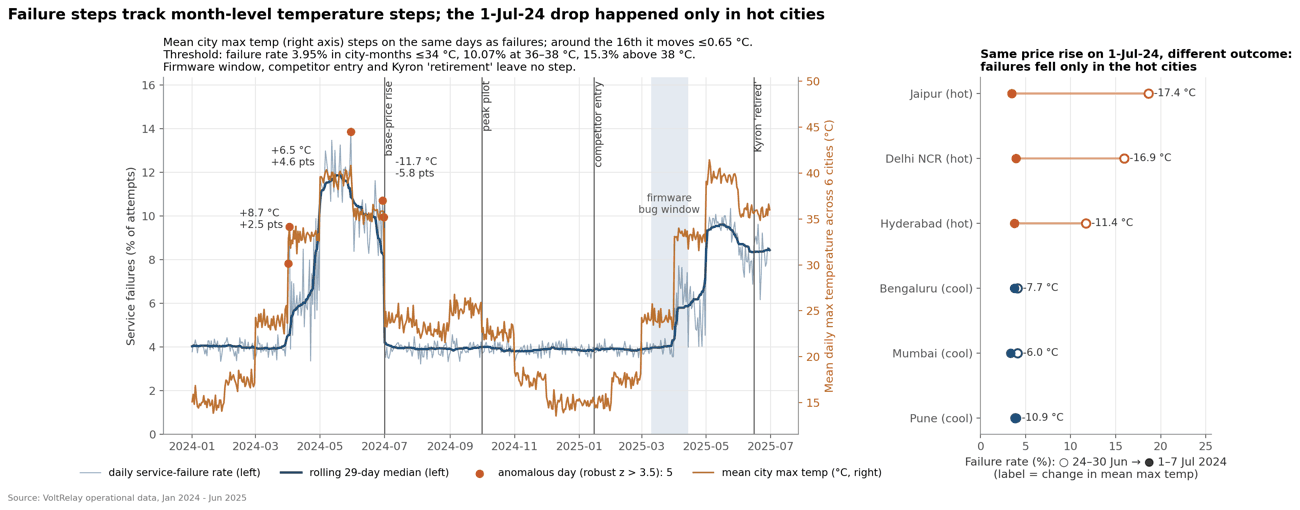

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q7_07_time_window_anomalies.png')

In [33]:
hdr("11c. Time-window anomalies")
dn = (events(["date", "is_service_failure"]).group_by("date")
      .agg(pl.len().alias("att"), pl.col("is_service_failure").mean().alias("rate")).collect().sort("date"))
cdd = city_daily()
# two independent temperature sources: city weather (mean over the 6 cities) and station telemetry (cabinet ambient)
t_city = cdd.group_by("date").agg(pl.col("max_temp_c").mean().alias("tmax_city"))
t_amb = hourly(["date", "ambient_temp_c"]).group_by("date").agg(pl.col("ambient_temp_c").mean().alias("amb_station")).collect()
dn = dn.join(t_city, on="date", how="left").join(t_amb, on="date", how="left").to_pandas()
dn["med"] = dn["rate"].rolling(29, center=True, min_periods=15).median()
dn["mad"] = (dn["rate"] - dn["med"]).abs().rolling(29, center=True, min_periods=15).median() * 1.4826
dn["z"] = (dn["rate"] - dn["med"]) / dn["mad"]
ctx = (cdd.group_by("date").agg(pl.col("heat_alert").sum().alias("heat_cities"), pl.col("flood_disruption").sum().alias("flood_cities"),
                                pl.col("festival_or_event").drop_nulls().unique().str.join(", ").alias("events"),
                                pl.col("grid_outage_hours").mean().alias("grid_outage_h"), pl.col("max_temp_c").max().alias("max_temp"))
       .to_pandas())
dn = dn.merge(ctx, on="date", how="left")
flag_days = dn[dn["z"] > 3.5].copy()
print(f"days flagged (rate > rolling-29d median + 3.5 robust SD): {len(flag_days)}")
print(flag_days[["date", "att", "rate", "med", "z", "heat_cities", "flood_cities", "events", "max_temp"]].round(4).to_string(index=False))
# regime shifts: 7-day mean after vs before each 1st of month, against the same contrast around the 16th (control),
# with the temperature step over the same 7+7 days
dts = pd.to_datetime(dn["date"])
step_rows = []
for m0 in pd.date_range("2024-02-01", "2025-06-01", freq="MS"):
    for lab, pivot in [("1st of month", m0), ("16th (control)", m0 + pd.Timedelta(days=15))]:
        bm_, am_ = (dts >= pivot - pd.Timedelta(days=7)) & (dts < pivot), (dts >= pivot) & (dts < pivot + pd.Timedelta(days=7))
        step_rows.append(dict(pivot=pivot.date(), kind=lab, before=100 * dn.loc[bm_, "rate"].mean(), after=100 * dn.loc[am_, "rate"].mean(),
                              step_pts=100 * (dn.loc[am_, "rate"].mean() - dn.loc[bm_, "rate"].mean()),
                              tmax_before=dn.loc[bm_, "tmax_city"].mean(), tmax_after=dn.loc[am_, "tmax_city"].mean(),
                              tmax_step_c=dn.loc[am_, "tmax_city"].mean() - dn.loc[bm_, "tmax_city"].mean(),
                              amb_before=dn.loc[bm_, "amb_station"].mean(), amb_after=dn.loc[am_, "amb_station"].mean(),
                              amb_step_c=dn.loc[am_, "amb_station"].mean() - dn.loc[bm_, "amb_station"].mean(),
                              att_step_pct=100 * (dn.loc[am_, "att"].mean() / dn.loc[bm_, "att"].mean() - 1)))
steps = pd.DataFrame(step_rows)
steps.to_csv(TAB / "q7_failure_regime_steps.csv", index=False)
st1 = steps[steps["kind"] == "1st of month"]
st16 = steps[steps["kind"] == "16th (control)"]
big = st1[st1["step_pts"].abs() > 1]
ctrl_max, ctrl_tmax = st16["step_pts"].abs().max(), st16["tmax_step_c"].abs().max()
print("1st-of-month steps (7-day means), failure rate and temperature:")
print(st1[["pivot", "before", "after", "step_pts", "tmax_before", "tmax_after", "tmax_step_c", "amb_step_c", "att_step_pct"]].round(2).to_string(index=False))
print(f"around the 16th (control): largest |failure step| {ctrl_max:.2f} pts, largest |city max-temp step| {ctrl_tmax:.2f} C; "
      f"on the 1st: largest |temp step| {st1['tmax_step_c'].abs().max():.2f} C")
sx = {(r["pivot"], r["kind"]): r for _, r in steps.iterrows()}
jul_step = sx[(dt.date(2024, 7, 1), "1st of month")]
mar24, mar25 = sx[(dt.date(2024, 3, 1), "1st of month")], sx[(dt.date(2025, 3, 1), "1st of month")]
print(f"1-Jul-2024: failures {jul_step['before']:.2f}% -> {jul_step['after']:.2f}%, mean city max temp {jul_step['tmax_before']:.1f} -> "
      f"{jul_step['tmax_after']:.1f} C ({jul_step['tmax_step_c']:+.1f}), station ambient {jul_step['amb_before']:.1f} -> {jul_step['amb_after']:.1f} C, "
      f"network attempts/day {jul_step['att_step_pct']:+.1f}%")
print(f"March control: 1-Mar-24 temp {mar24['tmax_step_c']:+.1f} C -> failure step {mar24['step_pts']:+.2f} pts; 1-Mar-25 temp {mar25['tmax_step_c']:+.1f} C -> "
      f"{mar25['step_pts']:+.2f} pts (both months stay below the heat threshold)")
mrate = (events(["month", "is_service_failure"]).group_by("month").agg(pl.len().alias("att"), (100 * pl.col("is_service_failure").mean()).alias("fail_pct"))
         .collect().sort("month").with_columns(pl.col("month").dt.month().replace_strict(SEASON_OF_MONTH).alias("season_label")))
print(mrate.to_pandas().round(2).to_string(index=False))
mis_att = int(mrate.filter(pl.col("month").dt.month().is_in([3, 6]))["att"].sum())
mr = {(r["month"].year, r["month"].month): r["fail_pct"] for r in mrate.iter_rows(named=True)}
print(f"season-label mismatch: March is 'Summer' but runs {mr[(2024, 3)]:.2f}%/{mr[(2025, 3)]:.2f}% (2024/2025), June is 'Monsoon' but runs "
      f"{mr[(2024, 6)]:.2f}%/{mr[(2025, 6)]:.2f}%; attempts in Mar+Jun = {mis_att:,}")

# city level: threshold, within-month variation, and the 1-Jul-2024 cross-city contrast (same price rise everywhere)
cdy = (events(["city", "date", "is_service_failure"]).group_by("city", "date").agg(pl.len().alias("att"), pl.col("is_service_failure").mean().alias("rate")).collect()
       .join(cdd.select("city", "date", "heat_alert", "flood_disruption", "max_temp_c"), on=["city", "date"], how="left")
       .with_columns(pl.col("date").dt.truncate("1mo").alias("m")))
cmt = (cdy.group_by("city", "m").agg(pl.col("max_temp_c").mean().alias("tmax"), pl.col("rate").mean().alias("rate"), pl.col("att").sum().alias("att"))
       .to_pandas())
cmt["band"] = pd.cut(cmt["tmax"], [-np.inf, 34, 36, 38, np.inf], labels=["<=34 C", "34-36 C", "36-38 C", ">38 C"])
thr = (cmt.groupby("band", observed=False).agg(city_months=("rate", "size"), fail_pct=("rate", lambda s: 100 * s.mean()),
                                               tmax_mean=("tmax", "mean")).reset_index())
thr.to_csv(TAB / "q7_failure_temperature_threshold.csv", index=False)
thd = {r["band"]: r for _, r in thr.iterrows()}
sd_within = float(cdy.with_columns((pl.col("max_temp_c") - pl.col("max_temp_c").mean().over("city", "m")).alias("d"))["d"].std())
r_cm = float(np.corrcoef(cmt["tmax"], cmt["rate"])[0, 1])
print("city-month failure rate (mean of daily rates) by city-month mean max temp:"); print(thr.round(2).to_string(index=False))
print(f"corr(city-month mean max temp, failure rate) = {r_cm:.3f} over {len(cmt)} city-months; within a city-month the SD of daily max temp is "
      f"only {sd_within:.2f} C -> the weather varies at month level, so day-level heat tests cannot separate heat from month")
P0 = BASE_PRICE_CHANGE
jul = (cdy.filter(pl.col("date").is_between(P0 - dt.timedelta(days=7), P0 + dt.timedelta(days=6)))
       .group_by("city", (pl.col("date") >= P0).alias("post"))
       .agg(pl.col("max_temp_c").mean().alias("tmax"), (100 * pl.col("rate").mean()).alias("fail_pct"), pl.col("att").mean().alias("att_day"))
       .to_pandas())
jw = jul.pivot(index="city", columns="post", values=["tmax", "fail_pct", "att_day"])
jw.columns = [f"{a}_{'after' if b else 'before'}" for a, b in jw.columns]
jw = jw.reset_index()
jw["hot_city"] = jw["city"].isin(HOT)
jw["tmax_change_c"] = jw["tmax_after"] - jw["tmax_before"]
jw["fail_change_pts"] = jw["fail_pct_after"] - jw["fail_pct_before"]
jw = jw.sort_values(["hot_city", "fail_pct_before"], ascending=[False, False]).reset_index(drop=True)
jw.to_csv(TAB / "q7_jul24_cross_city.csv", index=False)
print("1-Jul-2024 (base-price rise everywhere), 7 days before vs after, by city:")
print(jw[["city", "hot_city", "tmax_before", "tmax_after", "tmax_change_c", "fail_pct_before", "fail_pct_after", "fail_change_pts",
          "att_day_before", "att_day_after"]].round(2).to_string(index=False))
hot_j, cool_j = jw[jw.hot_city], jw[~jw.hot_city]
print(f"hot cities: failures fell {hot_j['fail_change_pts'].min():+.2f} to {hot_j['fail_change_pts'].max():+.2f} pts with max temp "
      f"{hot_j['tmax_change_c'].min():+.1f} to {hot_j['tmax_change_c'].max():+.1f} C; cool cities under the same price rise: "
      f"{cool_j['fail_change_pts'].min():+.2f} to {cool_j['fail_change_pts'].max():+.2f} pts (temp {cool_j['tmax_change_c'].min():+.1f} to "
      f"{cool_j['tmax_change_c'].max():+.1f} C) -> the July drop is heat-driven, not price-driven")
add_issue("Season labels (Summer = Mar–May) misaligned with the Apr–Jun heat regime", "analysis trap",
          "Daily failure rate; 7-day steps at month boundaries vs mid-month control; city weather and station ambient temperature; cross-city contrast",
          mis_att, N_EV, "attempts",
          "Control seasonality with city-month temperature (or city x month effects), not SEASON_OF_MONTH",
          f"Failure rate steps on the 1st of Apr/May/Jun/Jul because the weather is month-level: mean city max temp steps "
          f"{sx[(dt.date(2024, 4, 1), '1st of month')]['tmax_step_c']:+.1f}/{sx[(dt.date(2024, 5, 1), '1st of month')]['tmax_step_c']:+.1f}/"
          f"{sx[(dt.date(2024, 6, 1), '1st of month')]['tmax_step_c']:+.1f}/{jul_step['tmax_step_c']:+.1f} C on the same days (≤{ctrl_tmax:.2f} C around the 16th). "
          f"The 1-Jul-24 drop ({jul_step['before']:.1f}%→{jul_step['after']:.1f}%) happened only in hot cities; cool cities under the same price rise "
          f"moved {cool_j['fail_change_pts'].min():+.1f} to {cool_j['fail_change_pts'].max():+.1f} pts -> heat, not price. March ('Summer') runs "
          f"{mr[(2024, 3)]:.1f}%, June ('Monsoon') {mr[(2024, 6)]:.1f}%: season dummies blur the regime.",
          "failures track month-level heat (>~34–36 °C), not season labels", "medium")
# heat-alert days within a city-month: structurally weak test (weather barely varies within a month)
h1 = cdy.filter(pl.col("heat_alert")).group_by("city", "m").agg(pl.col("rate").mean().alias("r_heat"), pl.len().alias("d_heat"))
h0 = cdy.filter(~pl.col("heat_alert")).group_by("city", "m").agg(pl.col("rate").mean().alias("r_no"), pl.len().alias("d_no"))
hh = h1.join(h0, on=["city", "m"], how="inner").with_columns((pl.col("r_heat") - pl.col("r_no")).alias("diff")).to_pandas()
tt = stats.ttest_1samp(hh["diff"], 0)
ci_h = stats.t.interval(0.95, len(hh) - 1, loc=hh["diff"].mean(), scale=stats.sem(hh["diff"]))
heat_eff = float(hh["diff"].mean())
print(f"heat-alert days vs other days in the same city-month: {100 * heat_eff:+.2f} pts (unweighted mean of {len(hh)} city-months, 95% CI "
      f"{100 * ci_h[0]:+.2f}..{100 * ci_h[1]:+.2f}, p = {tt.pvalue:.2g}) -> uninformative: within-month temperature SD is {sd_within:.2f} C")
fl = cdy.filter(pl.col("flood_disruption")).select("city", "date", "rate").to_pandas()
fl_diffs = []
for _, r in fl.iterrows():
    ref = cdy.filter((pl.col("city") == r["city"]) & (pl.col("date") - r["date"]).dt.total_days().abs().is_between(1, 7) & ~pl.col("flood_disruption"))
    fl_diffs.append(r["rate"] - ref["rate"].mean())
print(f"flood days ({len(fl)}): failure rate vs same city +-7 days: mean diff {100 * np.mean(fl_diffs):+.2f} pts (range {100 * min(fl_diffs):+.2f}..{100 * max(fl_diffs):+.2f})")
RET = dt.date(2025, 6, 15)
kr = (events(["date", "is_stockout", "is_completed", "supplier_out"])
      .filter(pl.col("date").is_between(RET - dt.timedelta(days=7), RET + dt.timedelta(days=7)) & (pl.col("date") != RET))
      .group_by((pl.col("date") > RET).alias("post"))
      .agg(pl.len().alias("att"), pl.col("is_stockout").mean().alias("stockout_rate"),
           (pl.col("supplier_out") == "Kyron").filter(pl.col("is_completed")).mean().alias("kyron_share_issued")).collect().sort("post"))
print("Kyron 'retirement' 15-Jun-2025, 7 days before vs after:"); print(kr)
CE = COMPETITOR_ENTRY
cp = (events(["date", "station_id", "competitor_since", "is_service_failure"])
      .filter(pl.col("date").is_between(CE - dt.timedelta(days=56), CE + dt.timedelta(days=55)))
      .with_columns(pl.col("competitor_since").is_not_null().alias("treated"), (pl.col("date") >= CE).alias("post"))
      .group_by("treated", "post").agg(pl.len().alias("att"), pl.struct("station_id", "date").n_unique().alias("station_days"),
                                       pl.col("is_service_failure").mean().alias("fail_rate"))
      .with_columns((pl.col("att") / pl.col("station_days")).alias("att_per_station_day")).collect().sort("treated", "post"))
cpd = {(r["treated"], r["post"]): r for r in cp.iter_rows(named=True)}
did_vol = (cpd[(True, True)]["att_per_station_day"] / cpd[(True, False)]["att_per_station_day"]) / (cpd[(False, True)]["att_per_station_day"] / cpd[(False, False)]["att_per_station_day"])
print(cp); print(f"competitor entry DiD (8 weeks pre/post): attempts per station-day ratio-of-ratios = {did_vol:.3f}")
fe = (events(["date", "station_firmware", "is_system_error"])
      .filter(pl.col("date").is_between(dt.date(2025, 2, 1), dt.date(2025, 5, 19)))
      .with_columns(pl.when(pl.col("date") < BUG_A).then(pl.lit("1 pre (1 Feb-9 Mar)")).when(pl.col("date") <= BUG_B).then(pl.lit("2 bug window"))
                    .otherwise(pl.lit("3 post (15 Apr-19 May)")).alias("period"))
      .group_by("station_firmware", "period").agg(pl.len().alias("att"), pl.col("is_system_error").sum().alias("sys_err"))
      .with_columns((100 * pl.col("sys_err") / pl.col("att")).alias("sys_err_pct")).collect().sort("station_firmware", "period"))
print(fe)
fed = {(r["station_firmware"], r["period"][0]): r for r in fe.iter_rows(named=True)}
did_fw = (fed[("v3.2.0", "2")]["sys_err_pct"] - fed[("v3.2.0", "1")]["sys_err_pct"]) - (fed[("v3.2.1", "2")]["sys_err_pct"] - fed[("v3.2.1", "1")]["sys_err_pct"])
print(f"system-error DiD (v3.2.0 vs v3.2.1, bug window minus pre): {did_fw:+.3f} pts")
twc = pd.DataFrame([
    dict(check="1-Jul-24 hot cities: failure change 7d after - before (pts, mean of 3)", effect=hot_j["fail_change_pts"].mean(),
         low=hot_j["fail_change_pts"].min(), high=hot_j["fail_change_pts"].max(), p=np.nan, n=len(hot_j), note="range over cities; same price rise"),
    dict(check="1-Jul-24 cool cities: failure change 7d after - before (pts, mean of 3)", effect=cool_j["fail_change_pts"].mean(),
         low=cool_j["fail_change_pts"].min(), high=cool_j["fail_change_pts"].max(), p=np.nan, n=len(cool_j), note="range over cities; same price rise"),
    dict(check="heat-alert day vs same city-month (pts, unweighted)", effect=100 * heat_eff, low=100 * ci_h[0], high=100 * ci_h[1], p=tt.pvalue,
         n=len(hh), note=f"95% CI; uninformative: within city-month temp SD {sd_within:.2f} C"),
    dict(check="flood day vs same city +-7 d (pts)", effect=100 * np.mean(fl_diffs), low=100 * min(fl_diffs), high=100 * max(fl_diffs), p=np.nan,
         n=len(fl), note="range over flood days"),
    dict(check="Kyron retirement: stockout rate 7d after - before (pts)", effect=100 * (kr["stockout_rate"][1] - kr["stockout_rate"][0]), low=np.nan,
         high=np.nan, p=np.nan, n=int(kr["att"].sum()), note=""),
    dict(check="competitor entry DiD attempts/station-day (ratio)", effect=did_vol, low=np.nan, high=np.nan, p=np.nan, n=int(cp["att"].sum()), note=""),
    dict(check="firmware window DiD system-error rate (pts)", effect=did_fw, low=np.nan, high=np.nan, p=np.nan, n=int(fe["att"].sum()), note="")])
twc.to_csv(TAB / "q7_time_window_checks.csv", index=False)

TEMP_C = SERIES[7]
fig, (ax, axr) = plt.subplots(1, 2, figsize=(17.5, 6.0), gridspec_kw={"width_ratios": [2.75, 1], "wspace": 0.42})
ax.axvspan(pd.Timestamp(BUG_A), pd.Timestamp(BUG_B), color=PALETTE["light"], alpha=0.7, lw=0, zorder=0)
ax.plot(dts, 100 * dn["rate"], color=PALETTE["primary"], lw=0.9, alpha=0.5, label="daily service-failure rate (left)")
ax.plot(dts, 100 * dn["med"], color=PALETTE["primary"], lw=2.2, label="rolling 29-day median (left)")
ax.scatter(pd.to_datetime(flag_days["date"]), 100 * flag_days["rate"], s=46, color=PALETTE["accent"], zorder=4,
           label=f"anomalous day (robust z > 3.5): {len(flag_days)}")
ymax_t = 100 * dn["rate"].max() * 1.18
axt = ax.twinx()
axt.plot(dts, dn["tmax_city"], color=TEMP_C, lw=1.5, alpha=0.9, label="mean city max temp (°C, right)")
axt.spines["right"].set_visible(True); axt.grid(False)
axt.set_ylabel("Mean daily max temperature across 6 cities (°C)", color=TEMP_C)
axt.tick_params(axis="y", colors=TEMP_C)
axt.set_ylim(dn["tmax_city"].min() - 2, dn["tmax_city"].max() + 9)
for pv in [dt.date(2024, 4, 1), dt.date(2024, 5, 1), dt.date(2024, 7, 1)]:
    r_ = sx[(pv, "1st of month")]
    axt.annotate(f"{r_['tmax_step_c']:+.1f} °C\n{r_['step_pts']:+.1f} pts", xy=(pd.Timestamp(pv), r_["tmax_after"] if r_["tmax_step_c"] > 0 else r_["tmax_before"]),
                 xytext=(-46, 10) if r_["tmax_step_c"] > 0 else (10, 34), textcoords="offset points", fontsize=9.5, color="#333333")
for d_, lab in [(BASE_PRICE_CHANGE, "base-price rise"), (PILOT_START, "peak pilot"), (CE, "competitor entry"), (RET, "Kyron 'retired'")]:
    ax.axvline(pd.Timestamp(d_), color="#555555", lw=1)
    ax.text(pd.Timestamp(d_), ymax_t * 0.99, f" {lab}", rotation=90, va="top", ha="left", fontsize=9.5, color="#333333")
ax.text(pd.Timestamp(BUG_A) + pd.Timedelta(days=17), ymax_t * 0.62, "firmware\nbug window", ha="center", fontsize=9.5, color="#555555")
ax.set_ylim(0, ymax_t); ax.set_ylabel("Service failures (% of attempts)"); ax.set_xlabel("")
h_a, l_a = ax.get_legend_handles_labels(); h_b, l_b = axt.get_legend_handles_labels()
ax.legend(h_a + h_b, l_a + l_b, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, fontsize=9.5)
ax.set_title(f"Mean city max temp (right axis) steps on the same days as failures; around the 16th it moves ≤{ctrl_tmax:.2f} °C.\n"
             f"Threshold: failure rate {thd['<=34 C']['fail_pct']:.2f}% in city-months ≤34 °C, {thd['36-38 C']['fail_pct']:.2f}% at 36–38 °C, "
             f"{thd['>38 C']['fail_pct']:.1f}% above 38 °C.\nFirmware window, competitor entry and Kyron 'retirement' leave no step.",
             fontsize=10.5, fontweight="normal")
yy = np.arange(len(jw))
for i_, r_ in jw.iterrows():
    col_ = PALETTE["accent"] if r_["hot_city"] else PALETTE["primary"]
    axr.plot([r_["fail_pct_before"], r_["fail_pct_after"]], [i_, i_], color=col_, lw=2, alpha=0.6, zorder=2)
    axr.scatter([r_["fail_pct_before"]], [i_], s=60, facecolor="white", edgecolor=col_, linewidth=1.8, zorder=3)
    axr.scatter([r_["fail_pct_after"]], [i_], s=60, color=col_, zorder=4)
    axr.text(max(r_["fail_pct_before"], r_["fail_pct_after"]) + 0.6, i_, f"{r_['tmax_change_c']:+.1f} °C", va="center", fontsize=9.5, color="#333333")
axr.set_yticks(yy, [f"{c_} ({'hot' if h_ else 'cool'})" for c_, h_ in zip(jw["city"], jw["hot_city"])])
axr.invert_yaxis(); axr.set_xlim(0, jw[["fail_pct_before", "fail_pct_after"]].max().max() + 7)
axr.set_xlabel("Failure rate (%): ○ 24–30 Jun → ● 1–7 Jul 2024\n(label = change in mean max temp)")
axr.set_title("Same price rise on 1-Jul-24, different outcome:\nfailures fell only in the hot cities", fontsize=11)
axr.grid(axis="y", visible=False)
fig.suptitle("Failure steps track month-level temperature steps; the 1-Jul-24 drop happened only in hot cities", x=0.01, ha="left",
             fontsize=14, fontweight="bold", y=1.03)
save_fig(fig, "q7_07_time_window_anomalies")

### 11d Firmware- and connectivity-linked irregularities


11d. Connectivity / firmware irregularities   [  9.0s]


shape: (3, 6)
┌───────────────────┬──────────┬───────────────────┬──────────────────┬─────────────────────┬─────────────┐
│ connectivity_tier ┆ attempts ┆ offline_batch_pct ┆ system_error_pct ┆ service_failure_pct ┆ missing_pct │
│ ---               ┆ ---      ┆ ---               ┆ ---              ┆ ---                 ┆ ---         │
│ str               ┆ u32      ┆ f64               ┆ f64              ┆ f64                 ┆ f64         │
╞═══════════════════╪══════════╪═══════════════════╪══════════════════╪═════════════════════╪═════════════╡
│ fair              ┆ 669686   ┆ 45.08053          ┆ 0.296706         ┆ 5.872603            ┆ 0.0         │
│ good              ┆ 2503439  ┆ 0.0               ┆ 0.300547         ┆ 5.399053            ┆ 0.0         │
│ poor              ┆ 641857   ┆ 45.059258         ┆ 0.294302         ┆ 5.820455            ┆ 4.000409    │
└───────────────────┴──────────┴───────────────────┴──────────────────┴─────────────────────┴─────────────┘
shape: (2, 4)


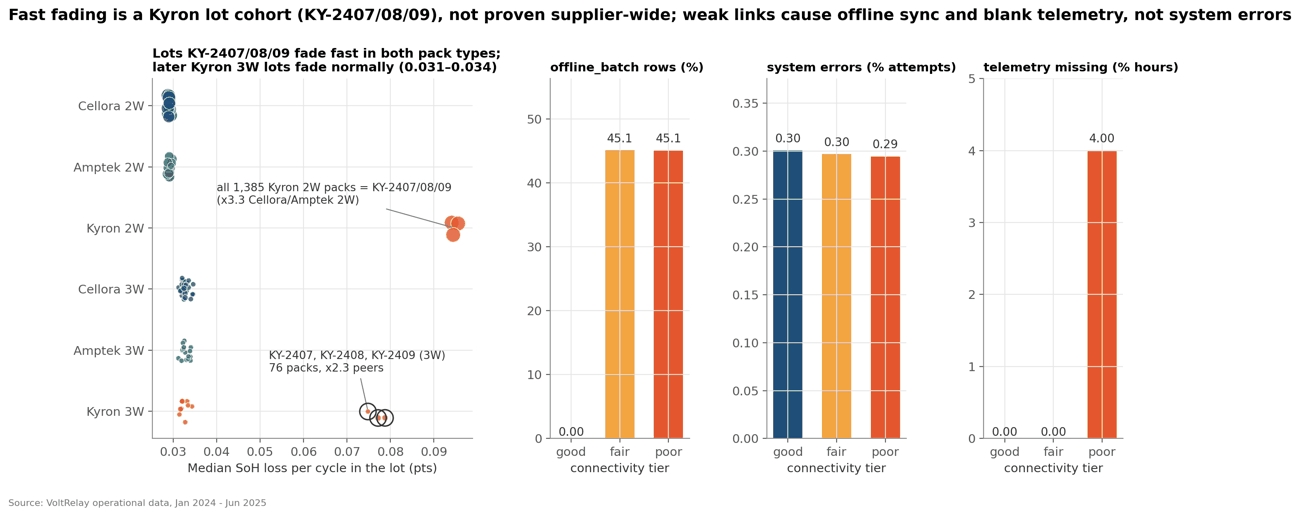

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q7_08_battery_lots_connectivity.png')

In [34]:
hdr("11d. Connectivity / firmware irregularities")
ctier = (events(["connectivity_tier", "sync_mode", "is_system_error", "is_service_failure"]).group_by("connectivity_tier")
         .agg(pl.len().alias("attempts"), (100 * (pl.col("sync_mode") == "offline_batch").mean()).alias("offline_batch_pct"),
              (100 * pl.col("is_system_error").mean()).alias("system_error_pct"), (100 * pl.col("is_service_failure").mean()).alias("service_failure_pct"))
         .collect().join(tele.select("connectivity_tier", "missing_pct"), on="connectivity_tier").sort("connectivity_tier"))
cfw = (events(["station_firmware", "sync_mode", "is_system_error"]).group_by("station_firmware")
       .agg(pl.len().alias("attempts"), (100 * (pl.col("sync_mode") == "offline_batch").mean()).alias("offline_batch_pct"),
            (100 * pl.col("is_system_error").mean()).alias("system_error_pct")).collect().sort("station_firmware"))
csync = (events(["sync_mode", "is_system_error", "connectivity_tier"]).group_by("connectivity_tier", "sync_mode")
         .agg(pl.len().alias("attempts"), (100 * pl.col("is_system_error").mean()).alias("system_error_pct")).collect().sort("connectivity_tier", "sync_mode"))
print(ctier); print(cfw); print(csync)
pd.concat([ctier.to_pandas().assign(group="connectivity_tier"), cfw.to_pandas().assign(group="firmware")]).to_csv(TAB / "q7_connectivity_firmware.csv", index=False)
tab_se = ctier.select("attempts", "system_error_pct").to_numpy()
cnt_se = np.column_stack([tab_se[:, 0] * tab_se[:, 1] / 100, tab_se[:, 0] * (1 - tab_se[:, 1] / 100)])
chi_se = stats.chi2_contingency(cnt_se)
print(f"system-error rate differs by tier: chi2 p = {chi_se.pvalue:.3g}")

fig = plt.figure(figsize=(15, 5.6))
gs = fig.add_gridspec(1, 4, width_ratios=[2.3, 1, 1, 1], wspace=0.42)
axl = fig.add_subplot(gs[0, 0])
grp_order = [("Cellora", "2W_2.1kWh"), ("Amptek", "2W_2.1kWh"), ("Kyron", "2W_2.1kWh"), ("Cellora", "3W_4.8kWh"), ("Amptek", "3W_4.8kWh"), ("Kyron", "3W_4.8kWh")]
for i, (sup, pt) in enumerate(grp_order):
    d_ = lots[(lots.supplier == sup) & (lots.pack_type == pt)]
    jit = np.random.default_rng(i).uniform(-0.18, 0.18, len(d_))
    axl.scatter(d_["lot_median"], i + jit, s=np.clip(d_["packs"], 20, 160), color=SUPPLIER_COLORS[sup], alpha=0.8, edgecolor="white", linewidth=0.6, zorder=3)
    fl_ = d_[d_["flag"] == "unusual"]
    axl.scatter(fl_["lot_median"], i + jit[(d_["flag"] == "unusual").to_numpy()], s=200, facecolor="none", edgecolor="#333333", linewidth=1.2, zorder=4)
axl.set_yticks(range(len(grp_order)), [f"{s} {p[:2]}" for s, p in grp_order]); axl.invert_yaxis()
axl.set_xlabel("Median SoH loss per cycle in the lot (pts)")
ul = lots[lots["flag"] == "unusual"]
axl.annotate(f"{', '.join(ul['lot'])} (3W)\n{ul['packs'].sum()} packs, x{(ul['lot_median'] / ul['peer_median']).mean():.1f} peers",
             xy=(ul["lot_median"].min(), 5), xytext=(0.052, 4.35), fontsize=9.5, color="#333333",
             arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8))
axl.annotate(f"all {n_k2:,} Kyron 2W packs = KY-2407/08/09\n(x{kyr.median() / oth.median():.1f} Cellora/Amptek 2W)",
             xy=(float(kyr.median()), 2), xytext=(0.040, 1.45), va="center", fontsize=9.5, color="#333333",
             arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8))
axl.set_title(f"Lots KY-2407/08/09 fade fast in both pack types;\nlater Kyron 3W lots fade normally "
              f"({k3_late['lot_median'].min():.3f}–{k3_late['lot_median'].max():.3f})", fontsize=11)
for j, (col, lab) in enumerate([("offline_batch_pct", "offline_batch rows (%)"), ("system_error_pct", "system errors (% attempts)"), ("missing_pct", "telemetry missing (% hours)")]):
    a_ = fig.add_subplot(gs[0, j + 1])
    vals_ = [ctier.filter(pl.col("connectivity_tier") == t)[col].item() for t in tiers]
    a_.bar(tiers, vals_, color=[PALETTE["primary"], PALETTE["warn"], PALETTE["accent"]], width=0.6)
    for k_, v_ in enumerate(vals_):
        a_.text(k_, v_ * 1.02 + 1e-6, f"{v_:.2f}" if v_ < 10 else f"{v_:.1f}", ha="center", va="bottom", fontsize=10, color="#333333")
    a_.set_title(lab, fontsize=10.5); a_.set_ylim(0, max(vals_) * 1.25 + 1e-6); a_.set_xlabel("connectivity tier")
fig.suptitle("Fast fading is a Kyron lot cohort (KY-2407/08/09), not proven supplier-wide; weak links cause offline sync and blank telemetry, not system errors",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.03)
save_fig(fig, "q7_08_battery_lots_connectivity")

## 12 · Data-quality scorecard (deliverable) and its visual


12. Scorecard   [  9.9s]


  id                                                                                                 issue          kind  rows_affected           unit  pct_of_data severity                                                     impact_short
DQ01                                  Battery IDs not physically tracked (packs 'teleport' between cities)  undocumented         239049 pack re-issues       6.6770     high                  239,049 impossible cross-city re-issues ≤60 min
DQ02                                           Peak/off-peak adjustments hidden inside PARTNER tariff code  undocumented         233264          swaps       6.5036     high    tariff_code hides 54% of pilot-priced swaps (233,264; ₹1.89M)
DQ03                                                   Firmware v3.2.0 timestamp bug (10-Mar..14-Apr-2025)    documented         139490       attempts       3.6564     high                 00-05h share 18.6%→3.5%; tariff clock 11.6%→100%
DQ04                    Packs below the 70% EOL 

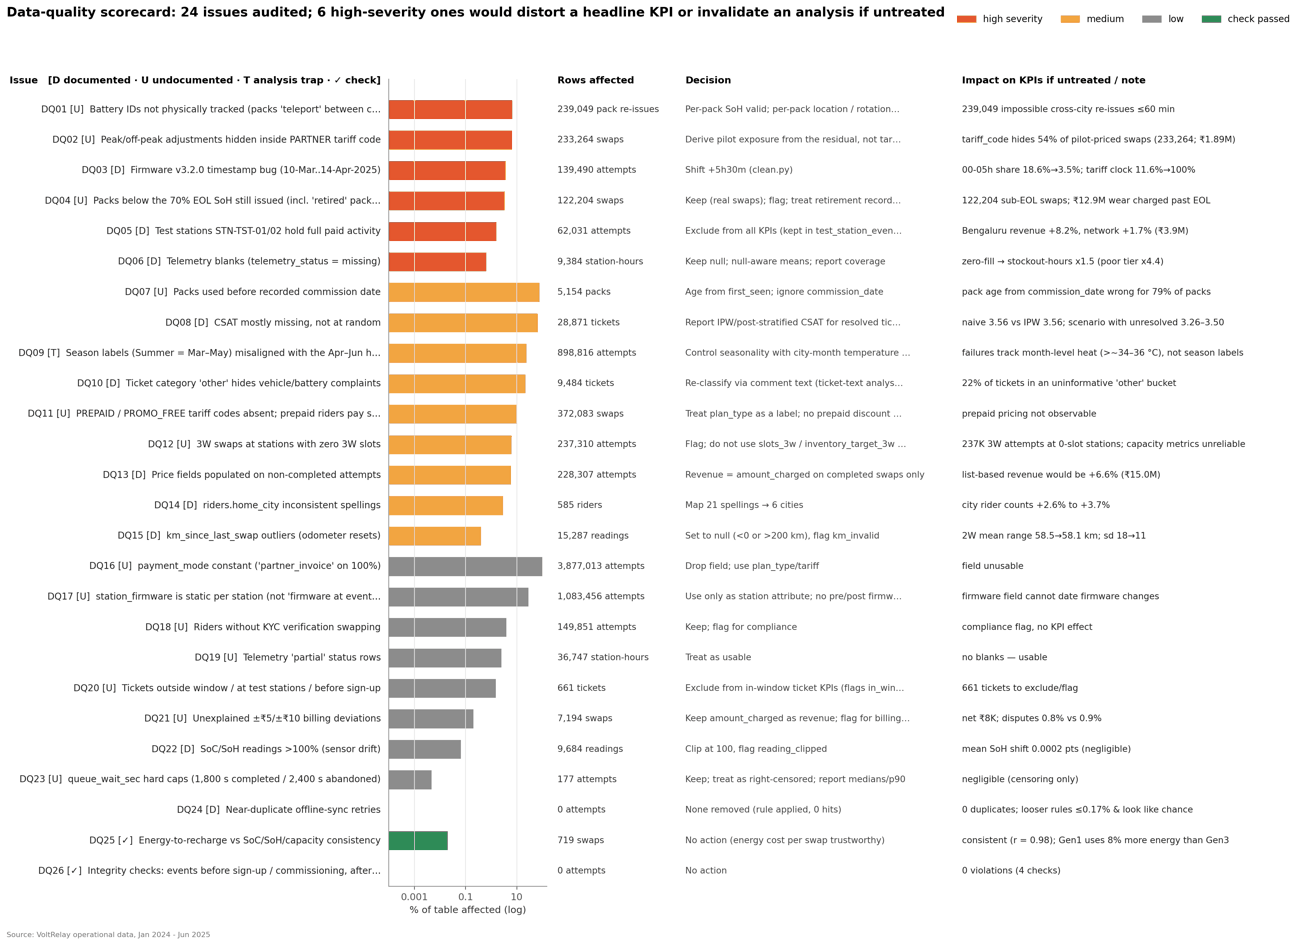

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q7_02_dq_scorecard.png')

In [35]:
hdr("12. Scorecard")
add_issue("Telemetry 'partial' status rows", "undocumented", "Null profile by telemetry_status", int(tele["partial"].sum()), tot_h, "station-hours",
          "Treat as usable", f"{int(tele['partial'].sum()):,} 'partial' rows have every field populated; only 'missing' rows are blank.",
          "no blanks — usable", "low")
sev_rank = {"high": 0, "medium": 1, "low": 2, "pass": 3}
scd = pd.DataFrame(SC)
scd["sev_rank"] = scd["severity"].map(sev_rank)
scd = scd.sort_values(["sev_rank", "pct_of_data"], ascending=[True, False]).drop(columns="sev_rank").reset_index(drop=True)
scd.insert(0, "id", [f"DQ{i + 1:02d}" for i in range(len(scd))])
scd.to_csv(TAB / "q7_data_quality_scorecard.csv", index=False)
print(scd[["id", "issue", "kind", "rows_affected", "unit", "pct_of_data", "severity", "impact_short"]].to_string(index=False))
print(f"issues: {len(scd)} ({(scd.kind == 'documented').sum()} documented, {(scd.kind == 'undocumented').sum()} undocumented, "
      f"{(scd.kind == 'analysis trap').sum()} analysis trap, {(scd.kind == 'check passed').sum()} checks passed); high severity {(scd.severity == 'high').sum()}")

n = len(scd)
fig = plt.figure(figsize=(20, 0.46 * n + 1.8))
AX0, AXW = 0.30, 0.12                              # bar axis position/width in figure fraction
ax = fig.add_axes([AX0, 0.03, AXW, 0.89])


def fx(f):                                         # figure-fraction x -> bar-axis fraction (for blended transforms)
    return (f - AX0) / AXW


sev_col = {"high": PALETTE["accent"], "medium": PALETTE["warn"], "low": PALETTE["muted"], "pass": PALETTE["good"]}
pcts = scd["pct_of_data"].to_numpy(dtype=float)
for i, r in scd.iterrows():
    if r["rows_affected"] > 0:
        ax.barh(i, max(pcts[i], 1e-4), color=sev_col[r["severity"]], height=0.62, left=1e-4)
ax.set_xscale("log"); ax.set_xlim(1e-4, 150); ax.set_ylim(n - 0.5, -1.0)
ax.set_yticks([]); ax.set_xticks([1e-3, 1e-1, 10], ["0.001", "0.1", "10"])
ax.set_xlabel("% of table affected (log)")
ax.grid(axis="y", visible=False)
trans = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
tag = {"documented": "D", "undocumented": "U", "check passed": "✓", "analysis trap": "T"}
COLS = {"rows": fx(0.428), "decision": fx(0.525), "impact": fx(0.735)}
for i, r in scd.iterrows():
    lab = r["issue"] if len(r["issue"]) <= 64 else r["issue"][:62] + "…"
    ax.text(-0.05, i, f"{r['id']} [{tag[r['kind']]}]  {lab}", transform=trans, ha="right", va="center", fontsize=10, color="#222222")
    ax.text(COLS["rows"], i, f"{r['rows_affected']:,} {r['unit']}", transform=trans, ha="left", va="center", fontsize=9.6, color="#333333")
    dec = r["decision"] if len(r["decision"]) <= 50 else r["decision"][:48] + "…"
    ax.text(COLS["decision"], i, dec, transform=trans, ha="left", va="center", fontsize=9.6, color="#444444")
    imp = r["impact_short"] if len(r["impact_short"]) <= 64 else r["impact_short"][:62] + "…"
    ax.text(COLS["impact"], i, imp, transform=trans, ha="left", va="center", fontsize=9.6, color="#222222")
hy = -0.95
ax.text(-0.05, hy, "Issue   [D documented · U undocumented · T analysis trap · ✓ check]", transform=trans, ha="right", va="center", fontsize=10.5, fontweight="bold")
ax.text(COLS["rows"], hy, "Rows affected", transform=trans, ha="left", va="center", fontsize=10.5, fontweight="bold")
ax.text(COLS["decision"], hy, "Decision", transform=trans, ha="left", va="center", fontsize=10.5, fontweight="bold")
ax.text(COLS["impact"], hy, "Impact on KPIs if untreated / note", transform=trans, ha="left", va="center", fontsize=10.5, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=sev_col[s]) for s in ["high", "medium", "low", "pass"]]
fig.legend(handles, ["high severity", "medium", "low", "check passed"], loc="upper right", ncol=4, bbox_to_anchor=(0.99, 1.0), fontsize=10)
n_issue = int((scd.kind != "check passed").sum()); n_high = int((scd.severity == "high").sum())
print(f"scorecard figure: {n_issue} issues audited (excluding passed checks), {n_high} high severity; Poisson funnel outliers total {n_hi_raw + n_lo_raw}")
fig.suptitle(f"Data-quality scorecard: {n_issue} issues audited; {n_high} high-severity ones would distort a headline KPI or invalidate an analysis if untreated",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
save_fig(fig, "q7_02_dq_scorecard")

## Summary of figures and tables

In [36]:
hdr("Done")
for f_ in sorted(FIG.glob("q7_*.png")):
    print("figure:", f_.relative_to(ROOT))
for f_ in sorted(TAB.glob("q7_*.csv")):
    print("table :", f_.relative_to(ROOT))
print(f"runtime {time.time() - T0:.1f}s")


Done   [ 10.7s]


figure: outputs\figures\q7_01_firmware_hour_profile.png
figure: outputs\figures\q7_02_dq_scorecard.png
figure: outputs\figures\q7_03_station_failure_funnel.png
figure: outputs\figures\q7_04_telemetry_zero_fill_bias.png
figure: outputs\figures\q7_05_near_duplicate_gap_test.png
figure: outputs\figures\q7_06_csat_ipw.png
figure: outputs\figures\q7_07_time_window_anomalies.png
figure: outputs\figures\q7_08_battery_lots_connectivity.png
table : outputs\tables\q7_battery_lot_anomalies.csv
table : outputs\tables\q7_bms_firmware_test.csv
table : outputs\tables\q7_city_standardisation.csv
table : outputs\tables\q7_connectivity_firmware.csv
table : outputs\tables\q7_csat_estimates.csv
table : outputs\tables\q7_data_quality_scorecard.csv
table : outputs\tables\q7_failure_regime_steps.csv
table : outputs\tables\q7_failure_temperature_threshold.csv
table : outputs\tables\q7_firmware_hour_profile.csv
table : outputs\tables\q7_jul24_cross_city.csv
table : outputs\tables\q7_km_outlier_impact.csv
table

In [37]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 259 objects


## 4. Problem framing

## What changed during the 18 months?
Eight business changes and external shocks overlap with the growth curve. Any analysis that compares "before" and
"after" must know when each one happened, otherwise effects get attributed to the wrong cause (e.g. a summer heat spike
read as a pricing effect).

shape: (18, 3)
┌────────────┬────────┬───────────┐
│ month      ┆ swaps  ┆ fail_pct  │
│ ---        ┆ ---    ┆ ---       │
│ date       ┆ u32    ┆ f64       │
╞════════════╪════════╪═══════════╡
│ 2024-01-01 ┆ 103508 ┆ 3.996195  │
│ 2024-02-01 ┆ 104437 ┆ 4.005637  │
│ 2024-03-01 ┆ 116148 ┆ 3.946924  │
│ 2024-04-01 ┆ 120117 ┆ 6.484949  │
│ 2024-05-01 ┆ 125454 ┆ 11.928989 │
│ 2024-06-01 ┆ 130880 ┆ 9.853304  │
│ 2024-07-01 ┆ 148611 ┆ 3.924219  │
│ 2024-08-01 ┆ 161688 ┆ 3.828301  │
│ 2024-09-01 ┆ 184051 ┆ 3.953678  │
│ 2024-10-01 ┆ 216551 ┆ 3.934504  │
│ 2024-11-01 ┆ 224857 ┆ 3.817834  │
│ 2024-12-01 ┆ 248954 ┆ 3.94897   │
│ 2025-01-01 ┆ 265834 ┆ 3.888235  │
│ 2025-02-01 ┆ 252750 ┆ 3.85064   │
│ 2025-03-01 ┆ 286630 ┆ 3.932539  │
│ 2025-04-01 ┆ 289261 ┆ 5.887705  │
│ 2025-05-01 ┆ 303748 ┆ 9.540775  │
│ 2025-06-01 ┆ 303196 ┆ 8.161426  │
└────────────┴────────┴───────────┘


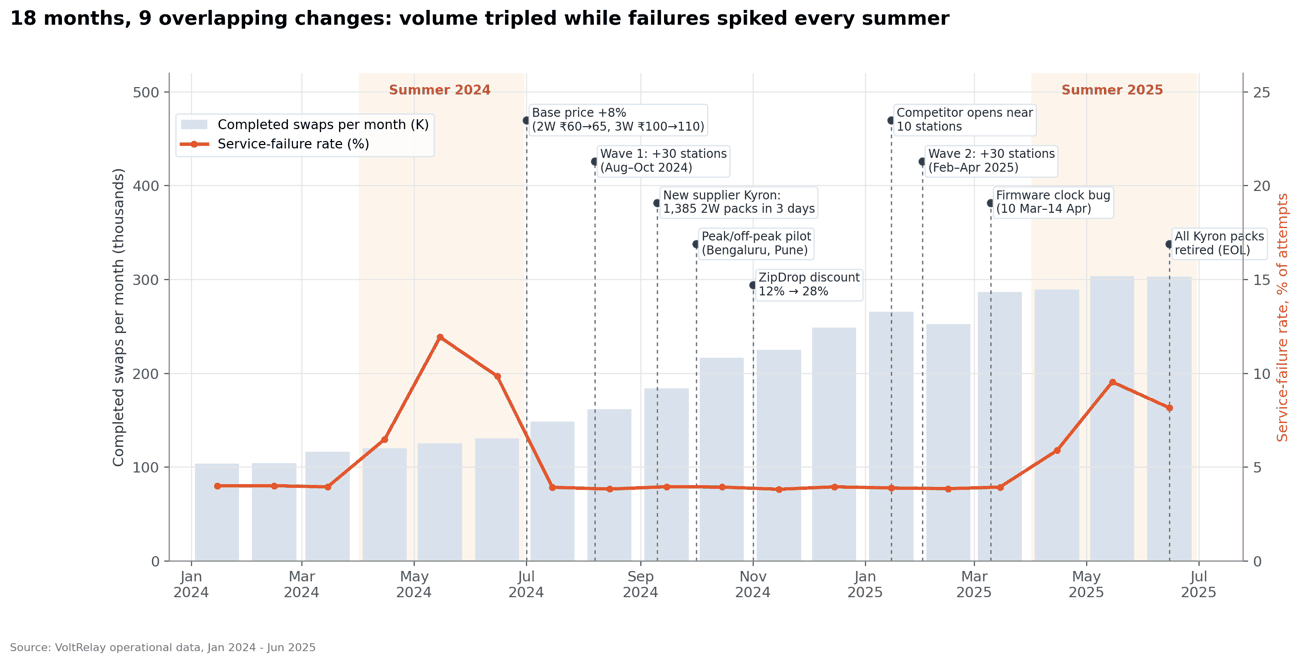

timeline drawn


In [38]:
import sys, datetime as dt
from pathlib import Path
import polars as pl
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
try:
    from common import events, set_style, save_fig, PALETTE
except ImportError:
    sys.path.insert(0, str(Path.cwd() / "src")); from common import events, set_style, save_fig, PALETTE

set_style()
m = (events(["month", "is_completed", "is_service_failure"]).group_by("month")
     .agg(pl.col("is_completed").sum().alias("swaps"), (pl.col("is_service_failure").mean() * 100).alias("fail_pct"))
     .sort("month").collect())
print(m)

EVENTS = [  # (date, label, lane)
    (dt.date(2024, 7, 1), "Base price +8%\n(2W ₹60→65, 3W ₹100→110)", 0),
    (dt.date(2024, 8, 7), "Wave 1: +30 stations\n(Aug–Oct 2024)", 1),
    (dt.date(2024, 9, 10), "New supplier Kyron:\n1,385 2W packs in 3 days", 2),
    (dt.date(2024, 10, 1), "Peak/off-peak pilot\n(Bengaluru, Pune)", 3),
    (dt.date(2024, 11, 1), "ZipDrop discount\n12% → 28%", 4),
    (dt.date(2025, 1, 15), "Competitor opens near\n10 stations", 0),
    (dt.date(2025, 2, 1), "Wave 2: +30 stations\n(Feb–Apr 2025)", 1),
    (dt.date(2025, 3, 10), "Firmware clock bug\n(10 Mar–14 Apr)", 2),
    (dt.date(2025, 6, 15), "All Kyron packs\nretired (EOL)", 3),
]

fig, ax = plt.subplots(figsize=(14, 6.4))
x = [d + dt.timedelta(days=14) for d in m["month"].to_list()]
for yr in (2024, 2025):
    ax.axvspan(dt.date(yr, 4, 1), dt.date(yr, 6, 30), color=PALETTE["warn"], alpha=0.10, lw=0)
    ax.text(dt.date(yr, 5, 15), 508, f"Summer {yr}", ha="center", va="top", fontsize=9.5, color="#b7791f", fontweight="bold")
ax.bar(x, [v / 1000 for v in m["swaps"]], width=24, color=PALETTE["light"], edgecolor="none", label="Completed swaps per month (K)")
ax.set_ylabel("Completed swaps per month (thousands)")
ax.set_ylim(0, 520)
ax2 = ax.twinx()
ax2.plot(x, m["fail_pct"].to_list(), color=PALETTE["accent"], lw=2.4, marker="o", ms=4, label="Service-failure rate (%)")
ax2.set_ylabel("Service-failure rate, % of attempts", color=PALETTE["accent"])
ax2.set_ylim(0, 26); ax2.grid(False); ax2.spines["right"].set_visible(True)
for d, label, lane in EVENTS:
    y = 470 - lane * 44
    ax.plot([d, d], [0, y], color="#5b6b7b", lw=0.9, ls=(0, (3, 3)))
    ax.plot(d, y, marker="o", color=PALETTE["primary"], ms=5)
    ax.text(d + dt.timedelta(days=3), y, label, fontsize=8.6, va="center", ha="left", color="#1d2733",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#D9E2EC", lw=0.8))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_xlim(dt.date(2023, 12, 20), dt.date(2025, 7, 25))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", bbox_to_anchor=(0.0, 0.93), ncol=1, frameon=True, facecolor="white", edgecolor="#D9E2EC")
fig.suptitle("18 months, 9 overlapping changes: volume tripled while failures spiked every summer", x=0.01, ha="left", fontsize=14, fontweight="bold")
save_fig(fig, "q0_02_timeline")
print("timeline drawn")

## Problem framing: hypothesis tree
Leadership's question is decomposed into the three outcomes that moved the wrong way, and each outcome into testable
hypotheses tied to a specific data source and method. Status colours are filled in from the verified findings.

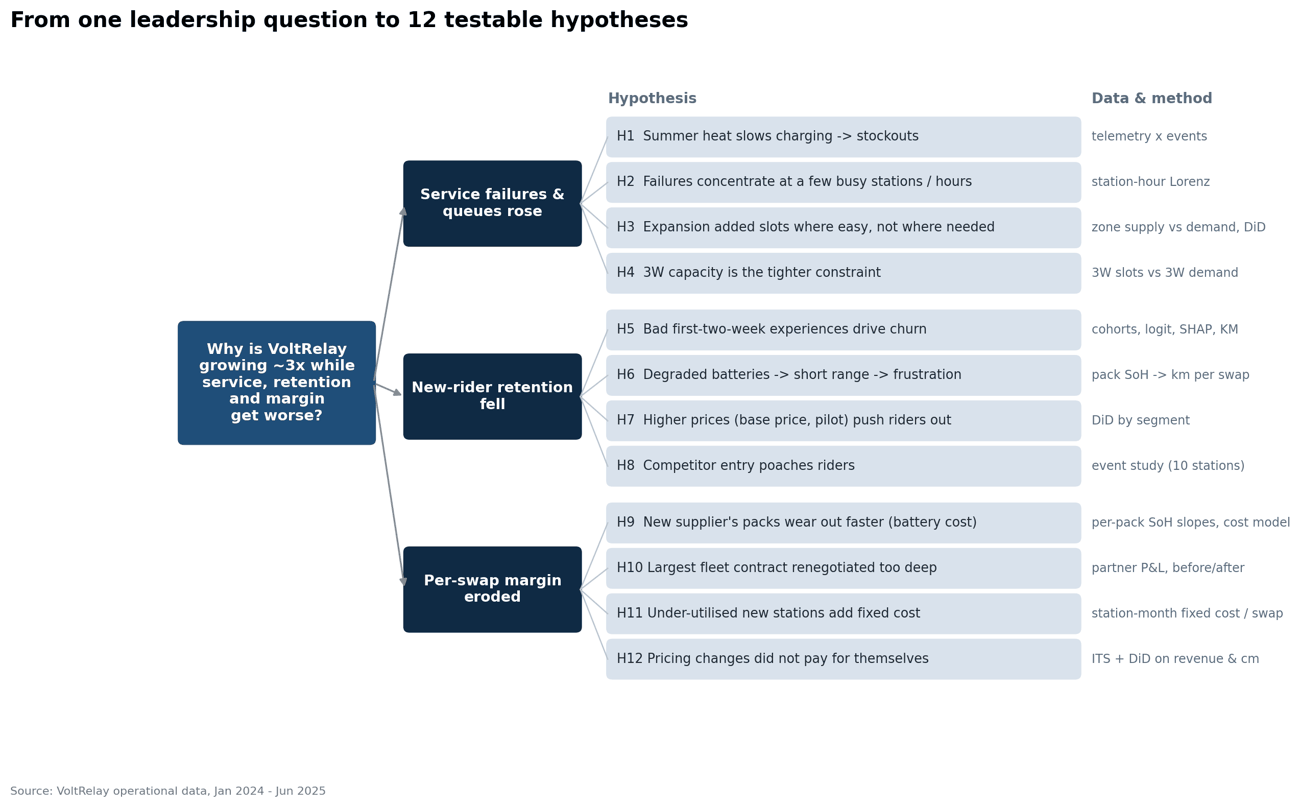

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q0_01_issue_tree.png')

In [39]:
import sys
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
try:
    from common import set_style, save_fig, PALETTE
except ImportError:
    sys.path.insert(0, str(Path.cwd() / "src")); from common import set_style, save_fig, PALETTE

set_style()
# status: None = to test, "yes" = supported (primary), "part" = supported (secondary / partial), "no" = not supported
TREE = [
    ("Service failures &\nqueues rose", [
        ("H1  Summer heat slows charging -> stockouts", "telemetry x events", None),
        ("H2  Failures concentrate at a few busy stations / hours", "station-hour Lorenz", None),
        ("H3  Expansion added slots where easy, not where needed", "zone supply vs demand, DiD", None),
        ("H4  3W capacity is the tighter constraint", "3W slots vs 3W demand", None),
    ]),
    ("New-rider retention\nfell", [
        ("H5  Bad first-two-week experiences drive churn", "cohorts, logit, SHAP, KM", None),
        ("H6  Degraded batteries -> short range -> frustration", "pack SoH -> km per swap", None),
        ("H7  Higher prices (base price, pilot) push riders out", "DiD by segment", None),
        ("H8  Competitor entry poaches riders", "event study (10 stations)", None),
    ]),
    ("Per-swap margin\neroded", [
        ("H9  New supplier's packs wear out faster (battery cost)", "per-pack SoH slopes, cost model", None),
        ("H10 Largest fleet contract renegotiated too deep", "partner P&L, before/after", None),
        ("H11 Under-utilised new stations add fixed cost", "station-month fixed cost / swap", None),
        ("H12 Pricing changes did not pay for themselves", "ITS + DiD on revenue & cm", None),
    ]),
]
COL = {None: "#D9E2EC", "yes": "#E4572E", "part": "#F2A541", "sup": "#9EC1E0", "no": "#E3E7EB"}
LBL = {None: "", "yes": "PRIMARY", "part": "SECONDARY", "sup": "SUPPORTED", "no": "NOT SUPPORTED"}
ROOT_Q = "Why is VoltRelay\ngrowing ~3x while\nservice, retention\nand margin\nget worse?"


def draw(tree, name="q0_01_issue_tree", title="From one leadership question to 12 testable hypotheses"):
    fig, ax = plt.subplots(figsize=(14, 7.6))
    ax.set_xlim(0, 14.2); ax.set_ylim(0.35, 8.25); ax.axis("off")

    def box(x, y, w, h, text, fc, fs=10, bold=False, color="#1d2733", ha="center"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="none"))
        ax.text(x + (w / 2 if ha == "center" else 0.12), y + h / 2, text, ha=ha, va="center", fontsize=fs,
                fontweight="bold" if bold else "normal", color=color)

    box(0.06, 3.55, 2.5, 1.6, ROOT_Q, PALETTE["primary"], fs=10.5, bold=True, color="white")
    ys = [5.55, 3.0, 0.45]
    for (outcome, hyps), y0 in zip(tree, ys):
        box(2.95, y0 + 0.62, 2.25, 1.1, outcome, "#0f2a44", fs=10.2, bold=True, color="white")
        ax.annotate("", xy=(2.95, y0 + 1.17), xytext=(2.55, 4.35), arrowprops=dict(arrowstyle="-|>", color="#8C8C8C", lw=1.2))
        for i, (h, method, status) in enumerate(hyps):
            yy = y0 + 1.80 - i * 0.6
            box(5.55, yy, 6.05, 0.5, h, COL[status], fs=9.2, ha="left", color="white" if status == "yes" else "#1d2733")
            ax.text(11.75, yy + 0.25, method, fontsize=8.6, color="#5b6b7b", va="center")
            if status:
                ax.text(11.52, yy + 0.25, LBL[status], fontsize=7.2, color="white" if status == "yes" else "#1d2733",
                        va="center", ha="right", fontweight="bold")
            ax.plot([5.2, 5.55], [y0 + 1.17, yy + 0.25], color="#B8C4CF", lw=0.9)
    ax.text(5.55, 8.05, "Hypothesis", fontsize=10, fontweight="bold", color="#5b6b7b")
    ax.text(11.75, 8.05, "Data & method", fontsize=10, fontweight="bold", color="#5b6b7b")
    fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    return save_fig(fig, name)


draw(TREE)

### The same tree after testing
Status from the verified analyses (Q1-Q8): red = primary driver, amber = secondary / contributing, blue = supported
description, grey = not supported by the evidence.

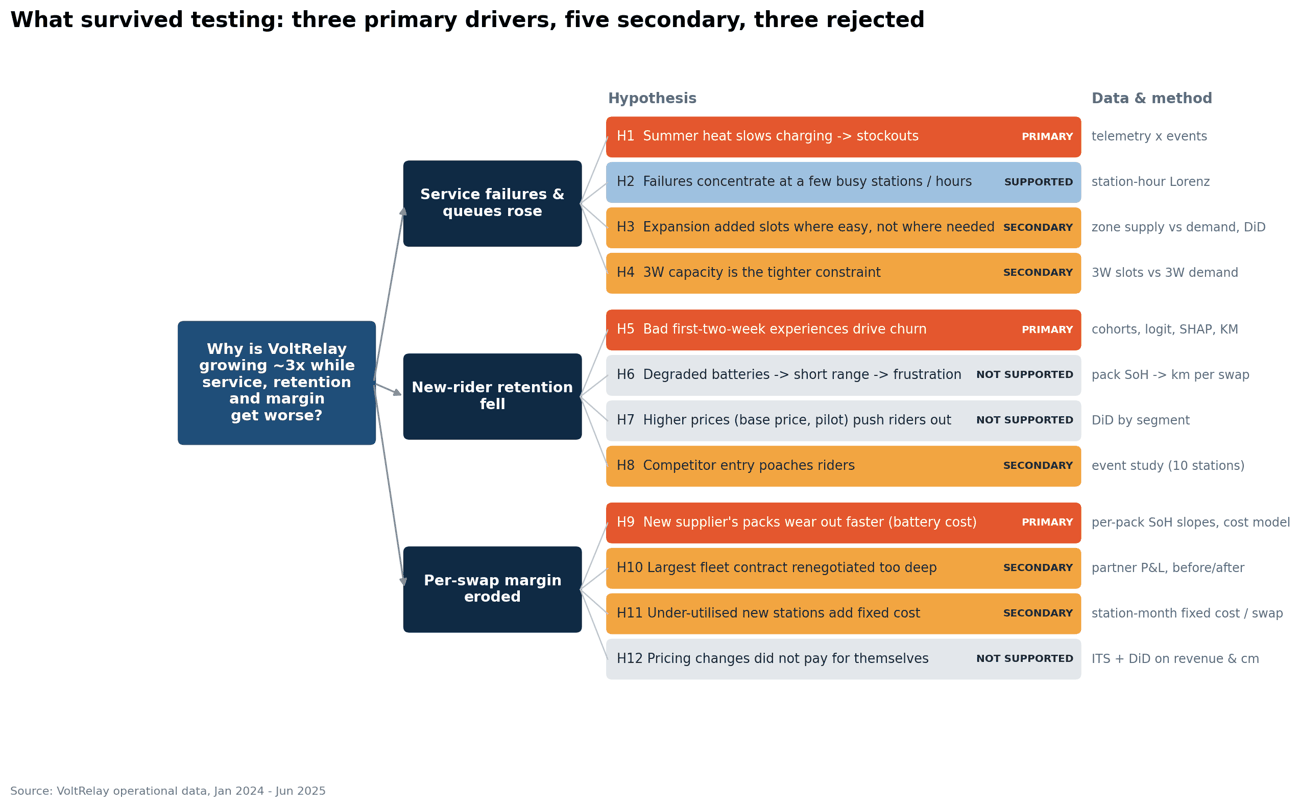

issue tree drawn


In [40]:
RESULT = {"H1": "yes", "H2": "sup", "H3": "part", "H4": "part", "H5": "yes", "H6": "no", "H7": "no", "H8": "part",
          "H9": "yes", "H10": "part", "H11": "part", "H12": "no"}
tree_res = [(o, [(h, m, RESULT[h.split()[0]]) for h, m, _ in hs]) for o, hs in TREE]
draw(tree_res, name="q0_03_hypothesis_results", title="What survived testing: three primary drivers, five secondary, three rejected")
print("issue tree drawn")

In [41]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 1 objects


## 5. Q1 · Network performance over time

# Q1 - Network performance over time (Jan-2024 to Jun-2025)

**Question.** How have completed swaps, revenue, service-failure rates and contribution margin per swap trended,
and do they tell the same story or diverge?

**Approach.**
1. Monthly KPI panel from the clean event table (one row per swap attempt, test stations excluded).
2. Indexed divergence chart (H1-2024 monthly average = 100) for scale metrics, plus failure rate and Rs/swap economics.
3. Test the leadership claim *"service failures rose faster than swaps"*: naive start-vs-end vs same-season comparison,
   then a fixed panel of Launch stations and station-demand deciles (dilution by new stations / Simpson's paradox).
4. Exact shift-share bridge (waterfall) of cm1 per swap H1-24 -> Jul-Aug-24 -> Oct-24..Mar-25, plus the same-season
   Q1-24 -> Q1-25 bridge. Neither window contains a pack issued below the 70% end of life (EOL); see step 5.
5. Internal-consistency check of the wear model (section 5b): the per-cycle wear keeps being charged on Kyron packs
   issued below 70% EOL (Apr-Jun-25 only), so their lifetime wear exceeds their purchase cost. Two consistent
   variants: (a) wear stops at EOL; (b) post-EOL issues cost the Cellora wear of the same class.
6. Counterfactual: Kyron packs with Cellora-like wear. 7. Sensitivity of margin levels to the wear assumption.

Shared cost model (src/clean.py): cm1 = revenue - energy - battery wear; cm2 = cm1 - station fixed cost.
Levels depend on the battery-wear assumption, so they are quoted "under our usage-based battery-depreciation
assumption". The analysis focuses on trends and differences, anchored in windows with no post-EOL issues, and
section 7 shows which of them survive other assumptions.

In [42]:
import sys
import time
from datetime import date
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from matplotlib.ticker import FuncFormatter
from scipy import stats

try:
    ROOT = PROJECT_ROOT
except NameError:  # running inside a notebook opened at the project root
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F403  (paths, constants, loaders, plotting style)

set_style()
T0 = time.time()
RNG = np.random.default_rng(59500)
RNG2 = np.random.default_rng(59501)   # separate stream for the paired network bootstrap, so earlier CIs stay reproducible
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(230)
pl.Config.set_float_precision(3)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RS = "₹"          # rupee sign
MINUS = "−"


def M(y, m):
    return date(y, m, 1)


PER = {
    "Jan-24": (M(2024, 1), M(2024, 1)), "May-24": (M(2024, 5), M(2024, 5)), "Jun-24": (M(2024, 6), M(2024, 6)),
    "May-25": (M(2025, 5), M(2025, 5)), "Jun-25": (M(2025, 6), M(2025, 6)),
    "Q1-24": (M(2024, 1), M(2024, 3)), "Q2-24": (M(2024, 4), M(2024, 6)),
    "Q1-25": (M(2025, 1), M(2025, 3)), "Q2-25": (M(2025, 4), M(2025, 6)),
    "H1-24": (M(2024, 1), M(2024, 6)), "Jul-Aug-24": (M(2024, 7), M(2024, 8)), "H1-25": (M(2025, 1), M(2025, 6)),
    # after the price rise, the Kyron ramp and the pilot, and before any pack was issued below 70% EOL (section 5b)
    "Oct-24..Mar-25": (M(2024, 10), M(2025, 3)),
}
DISP = {"Oct-24..Mar-25": "Oct-24 to Mar-25"}   # display names for figure labels


def in_per(p, col="month"):
    a, b = PER[p]
    return pl.col(col).is_between(a, b)


def rs(v, d=1, sign=True):
    """Rupee label with a real minus sign, e.g. '+Rs4.9' / '-Rs15.3'."""
    s = f"{abs(v):,.{d}f}"
    if not sign:
        return (MINUS if v < 0 else "") + RS + s
    return ("+" if v >= 0 else MINUS) + RS + s


def title_block(fig, title, subtitle, top=0.86):
    fig.subplots_adjust(top=top)
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=15, fontweight="bold", color="#111111")
    fig.text(0.01, 0.995 - 0.045 * (11 / fig.get_figheight()), subtitle, ha="left", va="top", fontsize=11, color="#555555")


def month_axis(ax, every=2):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(axis="x", labelsize=10)


print(f"[setup] ROOT={ROOT}")

[setup] ROOT=F:\Data Analytics Gradient Learning


## 1. Monthly KPI panel
One narrow, streamed scan per family of metrics (memory rule): counts and rupee sums; distinct riders/stations;
queue wait of completed swaps (mean and p90). Per-swap metrics are always ratio-of-sums (swap-weighted).

*Definitions.* Attempt = any swap event. Service failure = stockout (no charged battery) + abandoned queue + system
error; **cancelled by rider is shown separately** (a rider choice, not a service failure). Active rider/station = at
least one completed swap in the month. Queue wait = arrival-to-completion seconds of completed swaps.

In [43]:
c = pl.col("is_completed")
# post-EOL issue: a completed swap that handed out a pack already below the 70% end of life (see section 5b)
pe = c & (pl.col("soh_out_pct") < EOL_SOH)
mon = (events(["month", "is_completed", "is_stockout", "is_abandoned", "is_system_error", "is_cancelled",
               "is_service_failure", "revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2",
               "energy_to_recharge_kwh", "vehicle_class", "supplier_out", "partner_id", "city", "soh_out_pct"])
       .group_by("month").agg(
           pl.len().alias("attempts"), c.sum().alias("completed"),
           pl.col("is_service_failure").sum().alias("failures"), pl.col("is_stockout").sum().alias("stockouts"),
           pl.col("is_abandoned").sum().alias("abandoned"), pl.col("is_system_error").sum().alias("system_errors"),
           pl.col("is_cancelled").sum().alias("cancelled"),
           *[pl.col(x).cast(pl.Float64).sum().alias(x) for x in ["revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2"]],
           pl.col("energy_to_recharge_kwh").filter(c).cast(pl.Float64).sum().alias("kwh"),
           (c & (pl.col("supplier_out") == "Kyron")).sum().alias("kyron_swaps"),
           (c & (pl.col("vehicle_class") == "3W")).sum().alias("swaps_3w"),
           (c & (pl.col("partner_id") == ZIPDROP_ID)).sum().alias("zipdrop_swaps"),
           (c & pl.col("partner_id").is_not_null()).sum().alias("partner_swaps"),
           (c & pl.col("city").is_in(PILOT_CITIES)).sum().alias("pilot_city_swaps"),
           (c & (pl.col("supplier_out") == "Kyron") & (pl.col("vehicle_class") == "2W")).sum().alias("kyron_2w_swaps"),
           pe.sum().alias("post_eol_swaps"), (pe & (pl.col("vehicle_class") == "2W")).sum().alias("post_eol_2w"),
           (pe & (pl.col("vehicle_class") == "3W")).sum().alias("post_eol_3w"),
           pl.col("wear_cost").filter(pe).cast(pl.Float64).sum().alias("post_eol_wear"))
       .sort("month").collect(engine="streaming"))

uni = (events(["month", "is_completed", "rider_id", "station_id"]).filter(c)
       .group_by("month").agg(pl.col("rider_id").n_unique().alias("active_riders"),
                              pl.col("station_id").n_unique().alias("active_stations"))
       .sort("month").collect(engine="streaming"))

# queue wait of completed swaps: keep a narrow frame (month, Launch flag, seconds) for exact period quantiles
qw = (events(["month", "is_completed", "queue_wait_sec", "expansion_wave"]).filter(c)
      .select("month", (pl.col("expansion_wave") == "Launch").alias("is_launch"),
              pl.col("queue_wait_sec").cast(pl.Float32))
      .collect(engine="streaming"))
qm = qw.group_by("month").agg(pl.col("queue_wait_sec").mean().alias("qwait_mean_s"),
                              pl.col("queue_wait_sec").quantile(0.9).alias("qwait_p90_s")).sort("month")
print(f"[scan] completed swaps in queue-wait frame: {qw.height:,}; null queue waits: {qw['queue_wait_sec'].null_count():,}")

# 2W pack health at return (explains energy per swap): SoH / SoC of the returned pack, kWh to recharge, km since last swap
# also: what riders pay per km (amount charged / km since last swap, swaps with a valid km reading) and the health of
# returned non-Kyron packs (fleet ageing outside the Kyron cohort)
h2w = (events(["month", "is_completed", "vehicle_class", "soh_in_pct", "soc_in_pct", "energy_to_recharge_kwh", "km_since_last_swap",
               "supplier_in", "amount_charged_inr"])
       .filter(c & (pl.col("vehicle_class") == "2W"))
       .group_by("month").agg(pl.col("soh_in_pct").mean().alias("soh_in_2w"), pl.col("soc_in_pct").mean().alias("soc_in_2w"),
                              pl.col("energy_to_recharge_kwh").mean().alias("kwh_2w"), pl.col("km_since_last_swap").mean().alias("km_2w"),
                              pl.col("soh_in_pct").filter(pl.col("supplier_in") != "Kyron").mean().alias("soh_in_2w_nonkyron"),
                              pl.col("amount_charged_inr").filter(pl.col("km_since_last_swap").is_not_null()).cast(pl.Float64).sum().alias("rev_km_2w"),
                              pl.col("km_since_last_swap").cast(pl.Float64).sum().alias("km_sum_2w"))
       .sort("month").collect(engine="streaming"))

mon = mon.join(uni, on="month").join(qm, on="month").join(h2w, on="month").sort("month").with_columns(
    (pl.col("failures") / pl.col("attempts")).alias("fail_rate"),
    (pl.col("stockouts") / pl.col("attempts")).alias("stockout_rate"),
    (pl.col("abandoned") / pl.col("attempts")).alias("abandoned_rate"),
    (pl.col("system_errors") / pl.col("attempts")).alias("syserr_rate"),
    (pl.col("cancelled") / pl.col("attempts")).alias("cancel_rate"),
    (pl.col("completed") / pl.col("active_riders")).alias("swaps_per_rider"),
    (pl.col("completed") / pl.col("active_stations")).alias("swaps_per_station"),
    *[(pl.col(x) / pl.col("completed")).alias(f"{x}_ps") for x in ["revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2", "kwh"]],
    ((pl.col("energy_cost") + pl.col("wear_cost")) / pl.col("completed")).alias("varcost_ps"),
    (pl.col("kyron_swaps") / pl.col("completed")).alias("kyron_share"),
    (pl.col("swaps_3w") / pl.col("completed")).alias("share_3w"),
    (pl.col("zipdrop_swaps") / pl.col("completed")).alias("zipdrop_share"),
    (pl.col("partner_swaps") / pl.col("completed")).alias("partner_share"),
    (pl.col("pilot_city_swaps") / pl.col("completed")).alias("pilot_city_share"),
    (pl.col("qwait_mean_s") / 60).alias("qwait_mean_min"), (pl.col("qwait_p90_s") / 60).alias("qwait_p90_min"),
    (pl.col("kyron_2w_swaps") / (pl.col("completed") - pl.col("swaps_3w"))).alias("kyron_share_2w"),
    ((pl.col("kyron_swaps") - pl.col("kyron_2w_swaps")) / pl.col("swaps_3w")).alias("kyron_share_3w"),
    # wear-consistent variant (a): no wear on post-EOL issues (lifetime depreciation = purchase cost)
    (pl.col("post_eol_wear") / pl.col("completed")).alias("post_eol_ps"),
    ((pl.col("cm1") + pl.col("post_eol_wear")) / pl.col("completed")).alias("cm1_cap_ps"),
    ((pl.col("cm2") + pl.col("post_eol_wear")) / pl.col("completed")).alias("cm2_cap_ps"),
    ((pl.col("energy_cost") + pl.col("wear_cost") - pl.col("post_eol_wear")) / pl.col("completed")).alias("varcost_cap_ps"),
    (pl.col("post_eol_swaps") / pl.col("kyron_swaps")).alias("post_eol_share_of_kyron"),
    (pl.col("rev_km_2w") / pl.col("km_sum_2w")).alias("rs_per_km_2w"),
)
mon.write_csv(TAB / "q1_monthly_kpis.csv")
show = mon.select("month", "attempts", "completed", "active_riders", "active_stations",
                  pl.col("swaps_per_rider").round(1), (pl.col("revenue") / 1e6).round(2).alias("revenue_M"),
                  (pl.col("fail_rate") * 100).round(2).alias("fail%"), (pl.col("stockout_rate") * 100).round(2).alias("stockout%"),
                  (pl.col("abandoned_rate") * 100).round(2).alias("aband%"), (pl.col("syserr_rate") * 100).round(2).alias("syserr%"),
                  (pl.col("cancel_rate") * 100).round(2).alias("cancel%"), pl.col("qwait_mean_min").round(2).alias("q_mean_min"),
                  pl.col("qwait_p90_min").round(2).alias("q_p90_min"))
print("\n[1] Monthly KPI panel - volume and service")
print(show)
show2 = mon.select("month", *[pl.col(f"{x}_ps").round(2).alias(x.replace("_cost", "") + "_ps") for x in ["revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2"]],
                   pl.col("kwh_ps").round(3), (pl.col("cm1") / 1e6).round(2).alias("cm1_M"), (pl.col("cm2") / 1e6).round(2).alias("cm2_M"),
                   (pl.col("kyron_share") * 100).round(1).alias("kyron%"), (pl.col("zipdrop_share") * 100).round(1).alias("zipdrop%"),
                   (pl.col("partner_share") * 100).round(1).alias("partner%"), (pl.col("share_3w") * 100).round(1).alias("3W%"),
                   (pl.col("pilot_city_share") * 100).round(1).alias("pilotcity%"))
print("\n[1] Monthly KPI panel - unit economics (Rs per completed swap) and drivers")
print(show2)
print("\n[1] 2W pack health at return vs energy per swap (completed 2W swaps)")
print(mon.select("month", pl.col("soh_in_2w").round(1), pl.col("soc_in_2w").round(2), pl.col("kwh_2w").round(3), pl.col("km_2w").round(1)))
f0, f1 = mon.row(0, named=True), mon.row(-1, named=True)
print(f"[1] Jan-24 -> Jun-25: swaps x{f1['completed'] / f0['completed']:.2f}, revenue x{f1['revenue'] / f0['revenue']:.2f} "
      f"({f0['revenue'] / 1e6:.2f}M -> {f1['revenue'] / 1e6:.2f}M), active riders x{f1['active_riders'] / f0['active_riders']:.2f}, "
      f"active stations {f0['active_stations']} -> {f1['active_stations']}")
print(f"[1] 2W kWh/swap {f0['kwh_2w']:.3f} -> {f1['kwh_2w']:.3f} ({(f1['kwh_2w'] / f0['kwh_2w'] - 1) * 100:+.1f}%); returned-pack SoH "
      f"{f0['soh_in_2w']:.1f}% -> {f1['soh_in_2w']:.1f}%; SoC at return {f0['soc_in_2w']:.2f}% -> {f1['soc_in_2w']:.2f}%; km since last swap "
      f"{f0['km_2w']:.1f} -> {f1['km_2w']:.1f} ({(f1['km_2w'] / f0['km_2w'] - 1) * 100:+.1f}%)")
print(f"[1] ZipDrop share of completed swaps H1-25: {mon.filter(in_per('H1-25'))['zipdrop_swaps'].sum() / mon.filter(in_per('H1-25'))['completed'].sum() * 100:.1f}% "
      f"(= {mon.filter(in_per('H1-25'))['zipdrop_swaps'].sum() / mon.filter(in_per('H1-25'))['partner_swaps'].sum() * 100:.1f}% of partner-billed swaps)")


def rs_per_km(p):
    d = mon.filter(in_per(p))
    return d["rev_km_2w"].sum() / d["km_sum_2w"].sum()


print(f"[1] 2W price per km (amount charged / km since last swap, completed 2W swaps with a valid km reading): Jan-24 "
      f"{f0['rs_per_km_2w']:.3f} -> Jun-25 {f1['rs_per_km_2w']:.3f} Rs/km ({(f1['rs_per_km_2w'] / f0['rs_per_km_2w'] - 1) * 100:+.1f}%); "
      f"same season H1-24 {rs_per_km('H1-24'):.3f} -> H1-25 {rs_per_km('H1-25'):.3f} ({(rs_per_km('H1-25') / rs_per_km('H1-24') - 1) * 100:+.1f}%)")

ADD = ["attempts", "completed", "failures", "stockouts", "abandoned", "system_errors", "cancelled", "revenue",
       "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2", "kwh", "kyron_swaps", "swaps_3w", "zipdrop_swaps",
       "partner_swaps", "pilot_city_swaps", "post_eol_swaps", "post_eol_2w", "post_eol_3w", "post_eol_wear"]


def pagg(p):
    """Period totals (sums over months) and swap-weighted ratios."""
    d = mon.filter(in_per(p)).select([pl.col(x).sum() for x in ADD] + [pl.col("active_riders").mean(), pl.len().alias("n_months")]).row(0, named=True)
    n = d["completed"]
    d.update({f"{x}_ps": d[x] / n for x in ["revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2", "kwh"]})
    d["fail_rate"] = d["failures"] / d["attempts"]
    d["swaps_per_month"] = n / d["n_months"]
    d["post_eol_ps"] = d["post_eol_wear"] / n            # wear charged on packs issued below 70% EOL, per network swap
    d["cm1_cap_ps"] = d["cm1_ps"] + d["post_eol_ps"]     # variant (a): wear stops at EOL
    d["cm2_cap_ps"] = d["cm2_ps"] + d["post_eol_ps"]
    return d


P = {p: pagg(p) for p in PER}
print("\n[1] Period unit economics (Rs per completed swap; ratio of sums). post-EOL = wear charged on packs issued below 70% EOL")
for p in ["H1-24", "Q1-24", "Q2-24", "Jul-Aug-24", "Oct-24..Mar-25", "Q1-25", "Q2-25", "H1-25"]:
    d = P[p]
    print(f"  {p:<14} swaps/month={d['swaps_per_month']:>9,.0f}  rev/swap={d['revenue_ps']:6.2f}  energy={d['energy_cost_ps']:6.2f}  "
          f"wear={d['wear_cost_ps']:6.2f} (post-EOL {d['post_eol_ps']:5.2f})  fixed={d['fixed_cost_ps']:6.2f}  cm1={d['cm1_ps']:6.2f}  cm2={d['cm2_ps']:6.2f}  "
          f"cm1 total/month={d['cm1'] / d['n_months'] / 1e6:6.2f}M  cm2 total/month={d['cm2'] / d['n_months'] / 1e6:6.2f}M  fail={d['fail_rate'] * 100:5.2f}%")

[scan] completed swaps in queue-wait frame: 3,586,675; null queue waits: 0

[1] Monthly KPI panel - volume and service
shape: (18, 14)
┌────────────┬──────────┬───────────┬───────────────┬─────────────────┬─────────────────┬───────────┬────────┬───────────┬────────┬─────────┬─────────┬────────────┬───────────┐
│ month      ┆ attempts ┆ completed ┆ active_riders ┆ active_stations ┆ swaps_per_rider ┆ revenue_M ┆ fail%  ┆ stockout% ┆ aband% ┆ syserr% ┆ cancel% ┆ q_mean_min ┆ q_p90_min │
│ ---        ┆ ---      ┆ ---       ┆ ---           ┆ ---             ┆ ---             ┆ ---       ┆ ---    ┆ ---       ┆ ---    ┆ ---     ┆ ---     ┆ ---        ┆ ---       │
│ date       ┆ u32      ┆ u32       ┆ u32           ┆ u32             ┆ f64             ┆ f64       ┆ f64    ┆ f64       ┆ f64    ┆ f64     ┆ f64     ┆ f32        ┆ f32       │
╞════════════╪══════════╪═══════════╪═══════════════╪═════════════════╪═════════════════╪═══════════╪════════╪═══════════╪════════╪═════════╪═════════╪══════

## 2. Do the metrics tell the same story? Indexed divergence (hero figure 1)
Scale metrics are indexed to their H1-2024 monthly average (=100). cm1 per swap cannot be indexed (its H1-2024 base
is close to Rs 0, so an index would explode), so the bottom panel shows revenue per swap against variable cost per
swap (energy + wear) in rupees; the shaded gap between them *is* cm1 per swap.

[2] station_month vs event scan attempts difference: 0 (should be 0)
shape: (18, 7)
┌────────────┬──────────────────┬───────────────┬─────────────────┬──────────────┬─────────────────┬──────────────┐
│ month      ┆ fail_rate_Launch ┆ fail_rate_New ┆ attempts_Launch ┆ attempts_New ┆ stations_Launch ┆ stations_New │
│ ---        ┆ ---              ┆ ---           ┆ ---             ┆ ---          ┆ ---             ┆ ---          │
│ date       ┆ f64              ┆ f64           ┆ u32             ┆ u32          ┆ u32             ┆ u32          │
╞════════════╪══════════════════╪═══════════════╪═════════════════╪══════════════╪═════════════════╪══════════════╡
│ 2024-01-01 ┆ 4.000            ┆ null          ┆ 108278          ┆ null         ┆ 90              ┆ null         │
│ 2024-02-01 ┆ 4.010            ┆ null          ┆ 109271          ┆ null         ┆ 90              ┆ null         │
│ 2024-03-01 ┆ 3.950            ┆ null          ┆ 121487          ┆ null         ┆ 90              ┆ nul

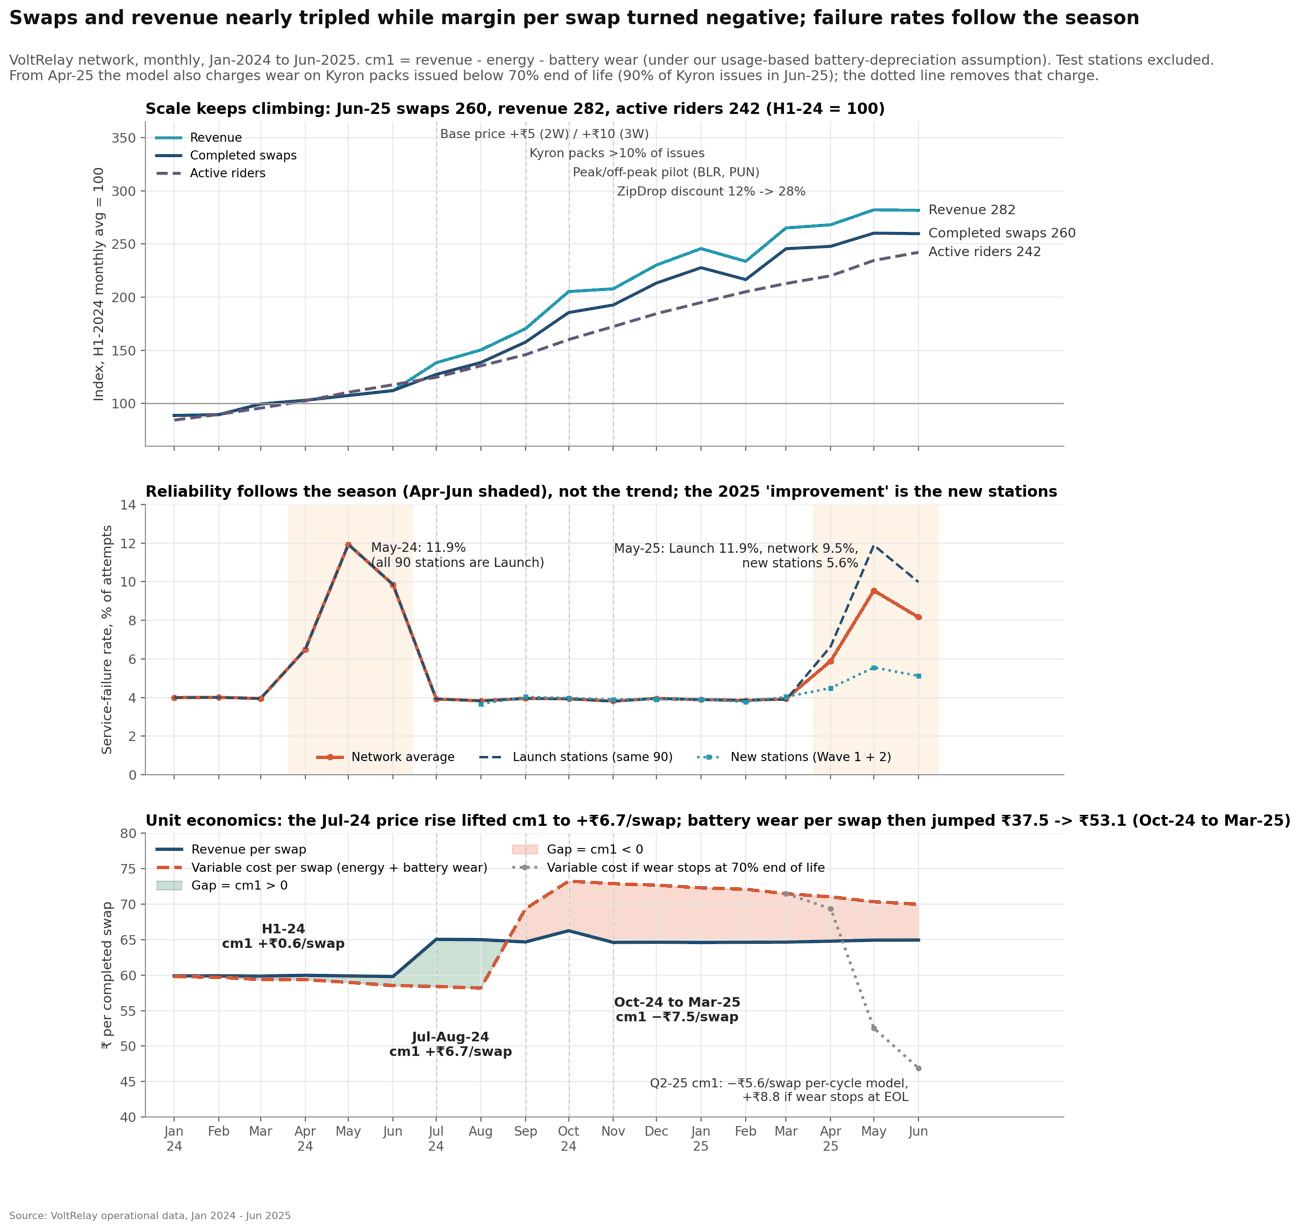

[fig] q1_01_kpi_divergence saved


In [44]:
sm = station_month().with_columns(
    (pl.col("stockouts") + pl.col("abandoned") + pl.col("system_errors")).alias("failures"),
    pl.when(pl.col("expansion_wave") == "Launch").then(pl.lit("Launch")).otherwise(pl.lit("New")).alias("grp"))
chk_att = sm["attempts"].sum() - mon["attempts"].sum()
print(f"[2] station_month vs event scan attempts difference: {chk_att} (should be 0)")
grp_m = (sm.group_by("month", "grp").agg(pl.col("attempts").sum(), pl.col("failures").sum(), pl.col("completed").sum(),
                                        pl.col("station_id").n_unique().alias("stations"))
         .with_columns((pl.col("failures") / pl.col("attempts")).alias("fail_rate")).sort("month", "grp"))
print(grp_m.with_columns((pl.col("fail_rate") * 100).round(2)).pivot(on="grp", index="month", values=["fail_rate", "attempts", "stations"]))

base = mon.filter(in_per("H1-24")).select([pl.col(x).mean() for x in ["completed", "revenue", "active_riders", "failures", "attempts", "revenue_ps", "varcost_ps"]]).row(0, named=True)
mon = mon.with_columns(*[(pl.col(x) / base[x] * 100).alias(f"idx_{x}") for x in ["completed", "revenue", "active_riders", "failures", "attempts"]])
last = mon.row(-1, named=True)
kyron_ramp = mon.filter(pl.col("kyron_share") >= 0.10)["month"].min()
print(f"[2] Index (H1-24 avg = 100) in Jun-25: swaps {last['idx_completed']:.0f}, revenue {last['idx_revenue']:.0f}, "
      f"active riders {last['idx_active_riders']:.0f}, failures {last['idx_failures']:.0f}, attempts {last['idx_attempts']:.0f}")
print(f"[2] Kyron share of issued packs first >=10% in {kyron_ramp}; Kyron share by month (%): "
      + ", ".join(f"{m:%b-%y}={v * 100:.1f}" for m, v in zip(mon['month'], mon['kyron_share'])))
print("[2] Kyron share of 2W issues by month (%): " + ", ".join(f"{m:%b-%y}={v * 100:.1f}" for m, v in zip(mon['month'], mon['kyron_share_2w'])))
print("[2] Kyron share of 3W issues by month (%): " + ", ".join(f"{m:%b-%y}={v * 100:.1f}" for m, v in zip(mon['month'], mon['kyron_share_3w'])))

pdm = mon.to_pandas()
pdm["month"] = pd.to_datetime(pdm["month"])
gm = grp_m.to_pandas()
gm["month"] = pd.to_datetime(gm["month"])
fig, axes = plt.subplots(3, 1, figsize=(13, 13), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1.05]})
ax = axes[0]
lines = [("idx_revenue", "Revenue", SERIES[5], "-"), ("idx_completed", "Completed swaps", PALETTE["primary"], "-"),
         ("idx_active_riders", "Active riders", SERIES[4], "--")]
for col, lab, colr, ls in lines:
    ax.plot(pdm["month"], pdm[col], color=colr, lw=2.4, ls=ls, label=lab)
    ax.annotate(f"{lab} {pdm[col].iloc[-1]:.0f}", (pdm["month"].iloc[-1], pdm[col].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10.5, color="#333333")
ax.axhline(100, color="#999999", lw=1)
ax.set_ylabel("Index, H1-2024 monthly avg = 100")
ax.set_ylim(60, 365)
ax.set_title(f"Scale keeps climbing: Jun-25 swaps {last['idx_completed']:.0f}, revenue {last['idx_revenue']:.0f}, "
             f"active riders {last['idx_active_riders']:.0f} (H1-24 = 100)", fontsize=12, loc="left")
ax.legend(loc="upper left")
events_lab = [(BASE_PRICE_CHANGE, f"Base price +{RS}5 (2W) / +{RS}10 (3W)"), (kyron_ramp, "Kyron packs >10% of issues"),
              (PILOT_START, "Peak/off-peak pilot (BLR, PUN)"), (ZIPDROP_AMEND, "ZipDrop discount 12% -> 28%")]
for k, (mth_d, lab) in enumerate(events_lab):
    for a in axes:
        a.axvline(pd.Timestamp(mth_d), color="#777777", lw=0.9, ls=(0, (3, 3)), zorder=0)
    ax.text(pd.Timestamp(mth_d), 358 - k * 18, " " + lab, fontsize=9.8, color="#444444", va="top", ha="left")
ax = axes[1]
net = pdm[["month", "fail_rate"]]
la = gm[gm.grp == "Launch"]
nw = gm[gm.grp == "New"]
for yr in (2024, 2025):
    ax.axvspan(pd.Timestamp(yr, 3, 20), pd.Timestamp(yr, 6, 15), color=PALETTE["warn"], alpha=0.13, lw=0)
ax.plot(net["month"], net["fail_rate"] * 100, color=PALETTE["accent"], lw=2.6, label="Network average", marker="o", ms=4)
ax.plot(la["month"], la["fail_rate"] * 100, color=PALETTE["primary"], lw=1.9, ls="--", label="Launch stations (same 90)")
ax.plot(nw["month"], nw["fail_rate"] * 100, color=SERIES[5], lw=1.9, ls=":", label="New stations (Wave 1 + 2)", marker="s", ms=3)
v = {p: (float(net.loc[net.month == pd.Timestamp(PER[p][0]), "fail_rate"].iloc[0]) * 100,
         float(la.loc[la.month == pd.Timestamp(PER[p][0]), "fail_rate"].iloc[0]) * 100) for p in ("May-24", "May-25")}
v_new25 = float(nw.loc[nw.month == pd.Timestamp(PER["May-25"][0]), "fail_rate"].iloc[0]) * 100
ax.annotate(f"May-24: {v['May-24'][0]:.1f}%\n(all 90 stations are Launch)", (pd.Timestamp(PER["May-24"][0]), v["May-24"][0]),
            xytext=(18, 2), textcoords="offset points", fontsize=10, va="top", color="#222222")
ax.annotate(f"May-25: Launch {v['May-25'][1]:.1f}%, network {v['May-25'][0]:.1f}%,\nnew stations {v_new25:.1f}%",
            (pd.Timestamp(PER["May-25"][0]), v["May-25"][1]), xytext=(-12, 2), textcoords="offset points", fontsize=10, va="top",
            ha="right", color="#222222")
ax.set_ylabel("Service-failure rate, % of attempts")
ax.set_ylim(0, 14)
ax.set_title("Reliability follows the season (Apr-Jun shaded), not the trend; the 2025 'improvement' is the new stations",
             fontsize=12, loc="left")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3)
ax = axes[2]
ax.plot(pdm["month"], pdm["revenue_ps"], color=PALETTE["primary"], lw=2.6, label="Revenue per swap")
ax.plot(pdm["month"], pdm["varcost_ps"], color=PALETTE["accent"], lw=2.6, ls="--", label="Variable cost per swap (energy + battery wear)")
ax.fill_between(pdm["month"], pdm["revenue_ps"], pdm["varcost_ps"], where=pdm["revenue_ps"] >= pdm["varcost_ps"],
                color=PALETTE["good"], alpha=0.25, interpolate=True, label="Gap = cm1 > 0")
ax.fill_between(pdm["month"], pdm["revenue_ps"], pdm["varcost_ps"], where=pdm["revenue_ps"] < pdm["varcost_ps"],
                color=PALETTE["accent"], alpha=0.22, interpolate=True, label="Gap = cm1 < 0")
capm = pdm[pdm.month >= pd.Timestamp(2025, 3, 1)]       # identical to the dashed line until Mar-25
ax.plot(capm["month"], capm["varcost_cap_ps"], color=PALETTE["muted"], lw=2.2, ls=":", marker="o", ms=3.5,
        label="Variable cost if wear stops at 70% end of life")
for p, off in [("H1-24", (0, 22)), ("Jul-Aug-24", (-6, -92)), ("Oct-24..Mar-25", (0, -64))]:
    a, b = PER[p]
    mid = pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2
    yv = float(pdm.loc[(pdm.month >= pd.Timestamp(a)) & (pdm.month <= pd.Timestamp(b)), "revenue_ps"].mean())
    ax.annotate(f"{DISP.get(p, p)}\ncm1 {rs(P[p]['cm1_ps'])}/swap", (mid, yv), xytext=off, textcoords="offset points", ha="center",
                fontsize=10.5, fontweight="bold", color="#222222")
ax.annotate(f"Q2-25 cm1: {rs(P['Q2-25']['cm1_ps'])}/swap per-cycle model,\n{rs(P['Q2-25']['cm1_cap_ps'])} if wear stops at EOL",
            (pd.Timestamp(2025, 6, 1), float(capm["varcost_cap_ps"].iloc[-1])), xytext=(-8, -26), textcoords="offset points",
            ha="right", fontsize=9.8, color="#333333")
ax.set_ylabel(f"{RS} per completed swap")
ax.set_ylim(40, 80)
ax.set_title(f"Unit economics: the Jul-24 price rise lifted cm1 to {rs(P['Jul-Aug-24']['cm1_ps'])}/swap; battery wear per swap then jumped "
             f"{RS}{P['Jul-Aug-24']['wear_cost_ps']:.1f} -> {RS}{P['Oct-24..Mar-25']['wear_cost_ps']:.1f} (Oct-24 to Mar-25)", fontsize=12, loc="left")
ax.legend(loc="upper left", ncol=2, fontsize=9.8)
ticks = pd.date_range("2024-01-01", "2025-06-01", freq="MS")
ax.set_xticks(ticks)
ax.set_xticklabels([t.strftime("%b\n%y") if t.month in (1, 4, 7, 10) else t.strftime("%b") for t in ticks], fontsize=10)
ax.set_xlim(pd.Timestamp(2023, 12, 12), pd.Timestamp(2025, 9, 10))
title_block(fig, "Swaps and revenue nearly tripled while margin per swap turned negative; failure rates follow the season",
            f"VoltRelay network, monthly, Jan-2024 to Jun-2025. cm1 = revenue - energy - battery wear "
            f"(under our usage-based battery-depreciation assumption). Test stations excluded.\n"
            f"From Apr-25 the model also charges wear on Kyron packs issued below 70% end of life ({mon.filter(pl.col('month') == M(2025, 6))['post_eol_share_of_kyron'].item() * 100:.0f}% of "
            f"Kyron issues in Jun-25); the dotted line removes that charge.", top=0.9)
fig.subplots_adjust(bottom=0.06)
save_fig(fig, "q1_01_kpi_divergence")
print("[fig] q1_01_kpi_divergence saved")

### Full monthly KPI panel (supporting figure)

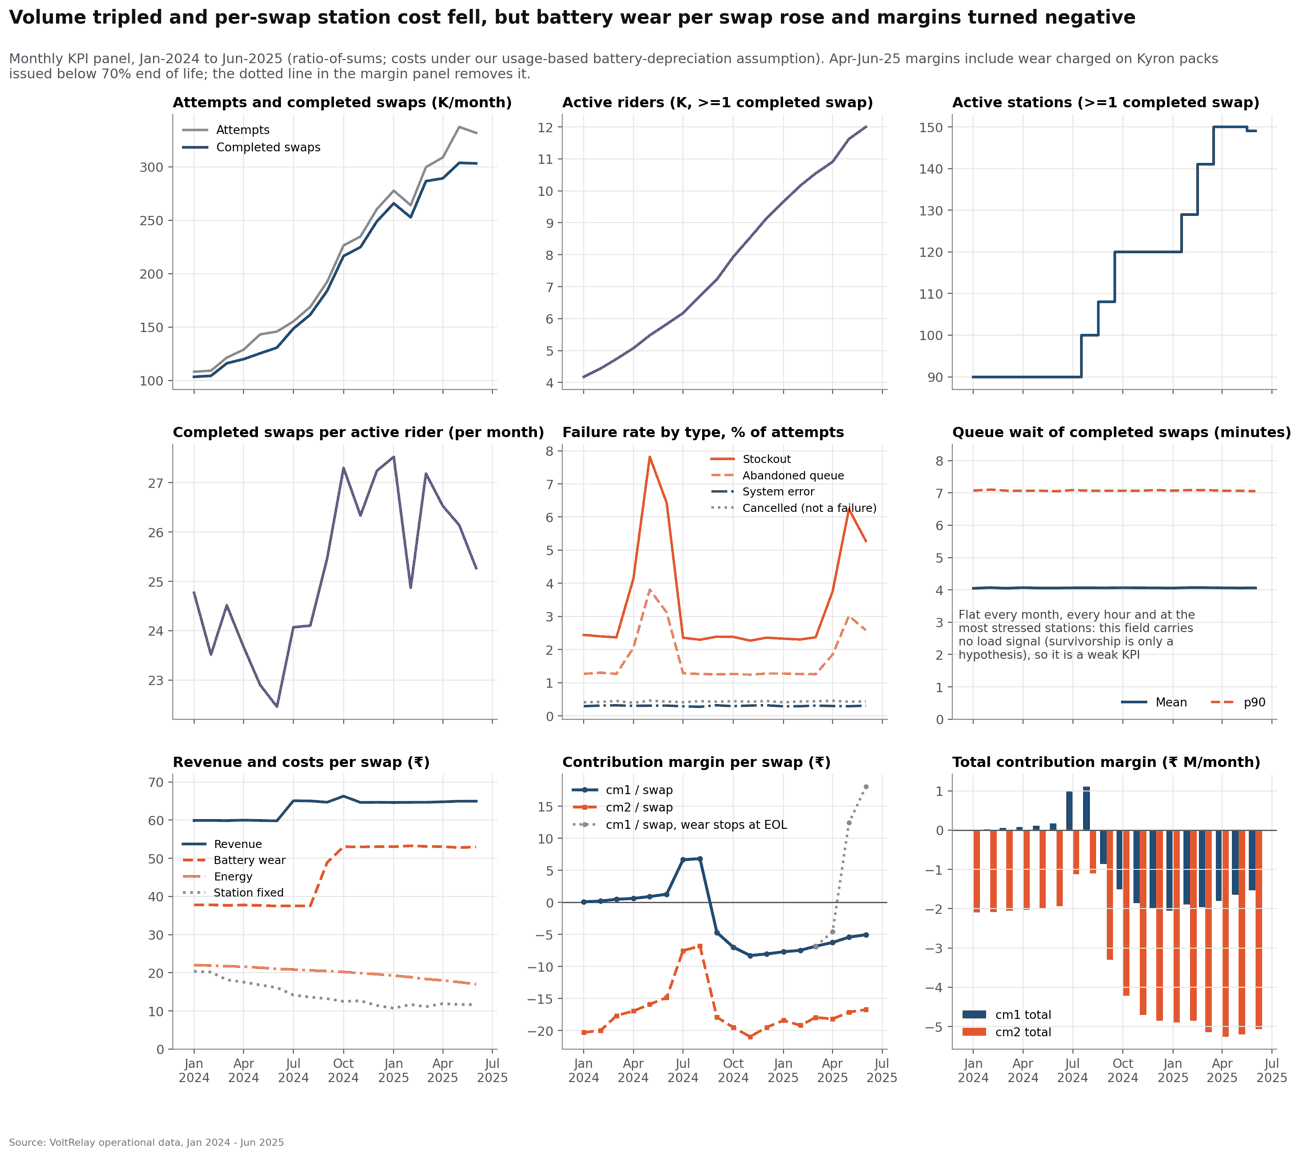

[fig] q1_02_kpi_panel saved


In [45]:
fig, axs = plt.subplots(3, 3, figsize=(16, 12.5), sharex=True)
axs = axs.ravel()
a = axs[0]
a.plot(pdm.month, pdm.attempts / 1e3, color=PALETTE["muted"], lw=2, label="Attempts")
a.plot(pdm.month, pdm.completed / 1e3, color=PALETTE["primary"], lw=2.2, label="Completed swaps")
a.set_title("Attempts and completed swaps (K/month)", fontsize=11.5)
a.legend(loc="upper left")
a = axs[1]
a.plot(pdm.month, pdm.active_riders / 1e3, color=SERIES[4], lw=2.2)
a.set_title("Active riders (K, >=1 completed swap)", fontsize=11.5)
a = axs[2]
a.step(pdm.month, pdm.active_stations, where="mid", color=PALETTE["primary"], lw=2.2, label="Active stations")
a.set_title("Active stations (>=1 completed swap)", fontsize=11.5)
a2v = pdm.swaps_per_rider
a = axs[3]
a.plot(pdm.month, a2v, color=SERIES[4], lw=2.2)
a.set_title("Completed swaps per active rider (per month)", fontsize=11.5)
a = axs[4]
for col, lab, colr, ls in [("stockout_rate", "Stockout", PALETTE["accent"], "-"), ("abandoned_rate", "Abandoned queue", PALETTE["warn"], "--"),
                           ("syserr_rate", "System error", PALETTE["primary"], "-."), ("cancel_rate", "Cancelled (not a failure)", PALETTE["muted"], ":")]:
    a.plot(pdm.month, pdm[col] * 100, color=colr, lw=2, ls=ls, label=lab)
a.set_title("Failure rate by type, % of attempts", fontsize=11.5)
a.legend(loc="upper right", fontsize=9)
a = axs[5]
a.plot(pdm.month, pdm.qwait_mean_min, color=PALETTE["primary"], lw=2.2, label="Mean")
a.plot(pdm.month, pdm.qwait_p90_min, color=PALETTE["accent"], lw=2, ls="--", label="p90")
a.set_title("Queue wait of completed swaps (minutes)", fontsize=11.5)
a.set_ylim(0, 8.5)
a.legend(loc="lower right", ncol=2)
a.text(0.02, 0.22, "Flat every month, every hour and at the\nmost stressed stations: this field carries\nno load signal "
       "(survivorship is only a\nhypothesis), so it is a weak KPI",
       transform=a.transAxes, fontsize=9.5, color="#444444")
a = axs[6]
for col, lab, colr, ls in [("revenue_ps", "Revenue", PALETTE["primary"], "-"), ("wear_cost_ps", "Battery wear", PALETTE["accent"], "--"),
                           ("energy_cost_ps", "Energy", PALETTE["warn"], "-."), ("fixed_cost_ps", "Station fixed", PALETTE["muted"], ":")]:
    a.plot(pdm.month, pdm[col], color=colr, lw=2.2, ls=ls, label=lab)
a.set_title(f"Revenue and costs per swap ({RS})", fontsize=11.5)
a.set_ylim(0, 72)
a.legend(loc="upper left", bbox_to_anchor=(0.0, 0.80), fontsize=9)
a = axs[7]
a.axhline(0, color="#555555", lw=1)
a.plot(pdm.month, pdm.cm1_ps, color=PALETTE["primary"], lw=2.4, marker="o", ms=3.5, label="cm1 / swap")
a.plot(pdm.month, pdm.cm2_ps, color=PALETTE["accent"], lw=2.2, ls="--", marker="s", ms=3, label="cm2 / swap")
a.plot(capm.month, capm.cm1_cap_ps, color=PALETTE["muted"], lw=2, ls=":", marker="o", ms=3, label="cm1 / swap, wear stops at EOL")
a.set_title(f"Contribution margin per swap ({RS})", fontsize=11.5)
a.legend(loc="upper left")
a = axs[8]
a.axhline(0, color="#555555", lw=1)
a.bar(pdm.month - pd.Timedelta(days=6), pdm.cm1 / 1e6, width=12, color=PALETTE["primary"], label="cm1 total")
a.bar(pdm.month + pd.Timedelta(days=6), pdm.cm2 / 1e6, width=12, color=PALETTE["accent"], label="cm2 total")
a.set_title(f"Total contribution margin ({RS} M/month)", fontsize=11.5)
a.legend(loc="lower left")
for a in axs:
    month_axis(a, every=3)
title_block(fig, "Volume tripled and per-swap station cost fell, but battery wear per swap rose and margins turned negative",
            "Monthly KPI panel, Jan-2024 to Jun-2025 (ratio-of-sums; costs under our usage-based battery-depreciation assumption). "
            "Apr-Jun-25 margins include wear charged on Kyron packs\nissued below 70% end of life; the dotted line in the margin panel removes it.",
            top=0.9)
fig.subplots_adjust(bottom=0.06)
save_fig(fig, "q1_02_kpi_panel")
print("[fig] q1_02_kpi_panel saved")

## 3. "Service failures rose faster than swaps" - naive vs same-season
The naive comparison takes the first and last months of the window (Jan-24, a low-failure winter month, vs Jun-25,
a peak-season month). Failures are strongly seasonal, so the fair test compares the same months a year apart.


[3] Growth multiples: does the leadership claim hold?
                     comparison period_0 period_1                scope  swaps_growth_x  attempts_growth_x  failures_growth_x  fail_rate_0_pct  fail_rate_1_pct  fail_rate_change_pp  failures_faster_than_swaps
        Naive: Jan-24 vs Jun-25   Jan-24   Jun-25              Network           2.929              3.064              6.257            3.996            8.161                4.165                        True
   Same month: Jun-24 vs Jun-25   Jun-24   Jun-25              Network           2.317              2.274              1.883            9.853            8.161               -1.692                       False
    Same season: Q1-24 vs Q1-25    Q1-24    Q1-25              Network           2.485              2.482              2.426            3.982            3.892               -0.089                       False
    Same season: Q2-24 vs Q2-25    Q2-24    Q2-25              Network           2.381              2.339        

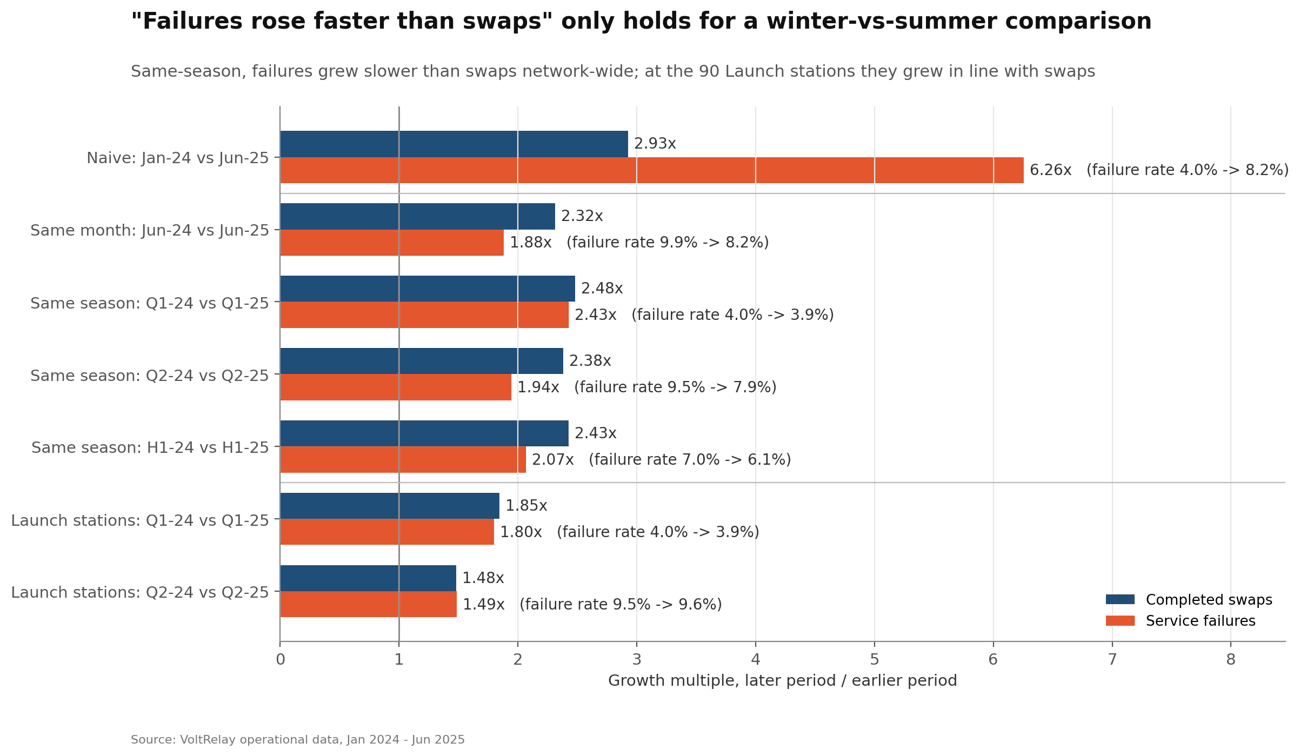

[fig] q1_03 saved


In [46]:
def sm_tot(p, launch_only=False):
    d = sm.filter(in_per(p))
    if launch_only:
        d = d.filter(pl.col("grp") == "Launch")
    return d.select(pl.col("attempts").sum(), pl.col("completed").sum(), pl.col("failures").sum(), pl.col("stockouts").sum(),
                    pl.col("abandoned").sum(), pl.col("system_errors").sum(), pl.col("cancelled").sum()).row(0, named=True)


COMPS = [("Naive: Jan-24 vs Jun-25", "Jan-24", "Jun-25", False),
         ("Same month: Jun-24 vs Jun-25", "Jun-24", "Jun-25", False),
         ("Same season: Q1-24 vs Q1-25", "Q1-24", "Q1-25", False),
         ("Same season: Q2-24 vs Q2-25", "Q2-24", "Q2-25", False),
         ("Same season: H1-24 vs H1-25", "H1-24", "H1-25", False),
         ("Launch stations: Q1-24 vs Q1-25", "Q1-24", "Q1-25", True),
         ("Launch stations: Q2-24 vs Q2-25", "Q2-24", "Q2-25", True)]
rows = []
for lab, p0, p1, lo in COMPS:
    a0, a1 = sm_tot(p0, lo), sm_tot(p1, lo)
    rows.append({"comparison": lab, "period_0": p0, "period_1": p1, "scope": "Launch (90 stations)" if lo else "Network",
                 "swaps_growth_x": a1["completed"] / a0["completed"], "attempts_growth_x": a1["attempts"] / a0["attempts"],
                 "failures_growth_x": a1["failures"] / a0["failures"],
                 "fail_rate_0_pct": a0["failures"] / a0["attempts"] * 100, "fail_rate_1_pct": a1["failures"] / a1["attempts"] * 100})
fg = pd.DataFrame(rows)
fg["fail_rate_change_pp"] = fg.fail_rate_1_pct - fg.fail_rate_0_pct
fg["failures_faster_than_swaps"] = fg.failures_growth_x > fg.swaps_growth_x
fg.to_csv(TAB / "q1_failure_growth_comparisons.csv", index=False)
print("\n[3] Growth multiples: does the leadership claim hold?")
print(fg.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6.6))
yy = np.arange(len(fg))[::-1]
h = 0.36
ax.barh(yy + h / 2, fg.swaps_growth_x, height=h, color=PALETTE["primary"], label="Completed swaps")
ax.barh(yy - h / 2, fg.failures_growth_x, height=h, color=PALETTE["accent"], label="Service failures")
for y_, s_, f_, r0, r1 in zip(yy, fg.swaps_growth_x, fg.failures_growth_x, fg.fail_rate_0_pct, fg.fail_rate_1_pct):
    ax.text(s_ + 0.05, y_ + h / 2, f"{s_:.2f}x", va="center", fontsize=10, color="#333333")
    ax.text(f_ + 0.05, y_ - h / 2, f"{f_:.2f}x   (failure rate {r0:.1f}% -> {r1:.1f}%)", va="center", fontsize=10, color="#333333")
ax.set_yticks(yy)
ax.set_yticklabels(fg.comparison, fontsize=10.5)
ax.axvline(1, color="#888888", lw=1)
ax.set_xlabel("Growth multiple, later period / earlier period")
ax.set_xlim(0, max(fg.failures_growth_x.max(), fg.swaps_growth_x.max()) + 2.2)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.axhline(yy[0] - 0.5, color="#BBBBBB", lw=0.8)
ax.axhline(yy[4] - 0.5, color="#BBBBBB", lw=0.8)
title_block(fig, "\"Failures rose faster than swaps\" only holds for a winter-vs-summer comparison",
            "Same-season, failures grew slower than swaps network-wide; at the 90 Launch stations they grew in line with swaps",
            top=0.86)
save_fig(fig, "q1_03_failure_claim_naive_vs_same_season")
print("[fig] q1_03 saved")

## 4. Does the network average hide deterioration? Launch-station panel and demand deciles
New stations (Wave 1 from Aug-24, Wave 2 from Feb-25) start with low utilisation and low failure rates, so they pull
the network average down even if established stations are no better. Checks:
* **Decomposition** of the YoY change in the network rate into a within-Launch change and a new-station mix effect.
* **Fixed panel** of the 90 Launch stations: station-level paired YoY differences (bootstrap CI over stations,
  Wilcoxon signed-rank), so clustering by station is respected.
* **Station-demand deciles** (attempts per active day, ranked within each period) - failure rate YoY by decile.
CIs for network-level differences use a station-cluster bootstrap (2,000 resamples), not a naive binomial test.

In [47]:
def station_period(p):
    return (sm.filter(in_per(p)).group_by("station_id", "expansion_wave", "grp", "city").agg(
        *[pl.col(x).sum() for x in ["attempts", "completed", "failures", "stockouts", "abandoned", "system_errors", "cancelled", "active_days"]],
        (pl.col("q_wait_completed_mean") * pl.col("completed")).sum().alias("qsum"))
        .filter(pl.col("attempts") > 0)
        .with_columns((pl.col("failures") / pl.col("attempts")).alias("fail_rate"),
                      (pl.col("attempts") / pl.col("active_days")).alias("demand_per_day"),
                      (pl.col("qsum") / pl.col("completed") / 60).alias("q_mean_min"))
        .sort("station_id").to_pandas())   # deterministic row order -> reproducible bootstrap and decile tie-breaks


SP = {p: station_period(p) for p in ["Q1-24", "Q2-24", "Q1-25", "Q2-25"]}


def boot_ratio(num, den, B=2000):
    n = len(num)
    idx = RNG.integers(0, n, (B, n))
    return num[idx].sum(1) / den[idx].sum(1)


yoy_rows, decomp = [], {}
for q in ("Q1", "Q2"):
    s0, s1 = SP[f"{q}-24"], SP[f"{q}-25"]
    r0 = s0.failures.sum() / s0.attempts.sum()
    r1 = s1.failures.sum() / s1.attempts.sum()
    bnet = boot_ratio(s1.failures.values, s1.attempts.values) - boot_ratio(s0.failures.values, s0.attempts.values)
    w = s1.groupby("grp").attempts.sum() / s1.attempts.sum()
    rg = s1.groupby("grp").failures.sum() / s1.groupby("grp").attempts.sum()
    within = w["Launch"] * (rg["Launch"] - r0)
    dilution = w.get("New", 0) * (rg.get("New", r0) - r0)
    decomp[q] = dict(r0=r0, r1=r1, within=within, dilution=dilution, w_new=w.get("New", 0), r_launch=rg["Launch"], r_new=rg.get("New", np.nan))
    print(f"\n[4] {q}: network failure rate {r0 * 100:.2f}% -> {r1 * 100:.2f}% ({(r1 - r0) * 100:+.2f} pp; station-cluster bootstrap 95% CI "
          f"{np.percentile(bnet, 2.5) * 100:+.2f} to {np.percentile(bnet, 97.5) * 100:+.2f} pp)")
    print(f"     decomposition: within-Launch {within * 100:+.2f} pp + new-station dilution {dilution * 100:+.2f} pp "
          f"(new stations = {w.get('New', 0) * 100:.1f}% of attempts at {rg.get('New', np.nan) * 100:.2f}% vs Launch {rg['Launch'] * 100:.2f}%)")
    # Launch fixed panel, paired by station
    L = s0[s0.grp == "Launch"].merge(s1[s1.grp == "Launch"], on="station_id", suffixes=("_24", "_25"))
    dd = (L.fail_rate_25 - L.fail_rate_24).values
    idx = RNG.integers(0, len(L), (2000, len(L)))
    bl = (L.failures_25.values[idx].sum(1) / L.attempts_25.values[idx].sum(1)) - (L.failures_24.values[idx].sum(1) / L.attempts_24.values[idx].sum(1))
    wil = stats.wilcoxon(dd)
    rl0 = L.failures_24.sum() / L.attempts_24.sum()
    rl1 = L.failures_25.sum() / L.attempts_25.sum()
    dem_g = L.demand_per_day_25 / L.demand_per_day_24 - 1
    rho = stats.spearmanr(dem_g, dd)
    qb = (boot_ratio(L.qsum_25.values, L.completed_25.values) - boot_ratio(L.qsum_24.values, L.completed_24.values)) / 60
    # Paired station-cluster bootstrap for the NETWORK change: the 2024 network is exactly the Launch panel, so each
    # Launch station is resampled together with both of its years; new stations are resampled separately.
    N1 = s1[s1.grp == "New"]
    assert len(L) == len(s0) and L.attempts_25.sum() + N1.attempts.sum() == s1.attempts.sum(), "panel does not cover the network"
    iL = RNG2.integers(0, len(L), (2000, len(L)))
    iN = RNG2.integers(0, len(N1), (2000, len(N1)))
    bpair = ((L.failures_25.values[iL].sum(1) + N1.failures.values[iN].sum(1)) / (L.attempts_25.values[iL].sum(1) + N1.attempts.values[iN].sum(1))
             - L.failures_24.values[iL].sum(1) / L.attempts_24.values[iL].sum(1))
    print(f"     paired station-cluster bootstrap 95% CI for the network change: {np.percentile(bpair, 2.5) * 100:+.2f} to "
          f"{np.percentile(bpair, 97.5) * 100:+.2f} pp (the unpaired CI above resamples the two years independently, so it is wider)")
    print(f"     Launch panel (n={len(L)} stations): pooled {rl0 * 100:.2f}% -> {rl1 * 100:.2f}% ({(rl1 - rl0) * 100:+.2f} pp, paired bootstrap "
          f"95% CI {np.percentile(bl, 2.5) * 100:+.2f} to {np.percentile(bl, 97.5) * 100:+.2f}); median station change {np.median(dd) * 100:+.2f} pp; "
          f"{(dd > 0).sum()}/{len(dd)} stations worse, {(dd <= 0).sum()} not worse; Wilcoxon p={wil.pvalue:.3g}")
    print(f"     Launch demand per station-day {L.demand_per_day_24.mean():.0f} -> {L.demand_per_day_25.mean():.0f} attempts "
          f"({(L.attempts_25.sum() / L.attempts_24.sum() - 1) * 100:+.1f}% attempts); Spearman(demand growth, failure-rate change) "
          f"rho={rho.statistic:.2f}, p={rho.pvalue:.3g}")
    for scope, d0, d1 in [("Network", s0, s1), ("Launch", s0[s0.grp == "Launch"], s1[s1.grp == "Launch"]), ("New stations", None, s1[s1.grp == "New"])]:
        for metric, col in [("Service-failure rate", "failures"), ("Stockout rate", "stockouts"), ("Abandoned rate", "abandoned"),
                            ("System-error rate", "system_errors"), ("Cancelled rate (not a failure)", "cancelled")]:
            v0 = d0[col].sum() / d0.attempts.sum() * 100 if d0 is not None else np.nan
            v1 = d1[col].sum() / d1.attempts.sum() * 100
            row = {"quarter": q, "scope": scope, "metric": metric, "2024": v0, "2025": v1, "change": v1 - v0, "unit": "% of attempts"}
            if metric == "Service-failure rate" and scope == "Network":
                row.update(ci_lo=np.percentile(bnet, 2.5) * 100, ci_hi=np.percentile(bnet, 97.5) * 100,
                           ci_paired_lo=np.percentile(bpair, 2.5) * 100, ci_paired_hi=np.percentile(bpair, 97.5) * 100)
            if metric == "Service-failure rate" and scope == "Launch":
                row.update(ci_lo=np.percentile(bl, 2.5) * 100, ci_hi=np.percentile(bl, 97.5) * 100, p_wilcoxon=wil.pvalue)
            yoy_rows.append(row)
    # queue waits: means from station-month (weighted), p90 from the event frame
    for scope, flt in [("Network", None), ("Launch", True), ("New stations", False)]:
        def qstats(p):
            d = qw.filter(in_per(p))
            if flt is not None:
                d = d.filter(pl.col("is_launch") == flt)
            if d.height == 0:
                return np.nan, np.nan
            return d["queue_wait_sec"].mean() / 60, d["queue_wait_sec"].quantile(0.9) / 60
        m0, p90_0 = qstats(f"{q}-24")
        m1, p90_1 = qstats(f"{q}-25")
        row = {"quarter": q, "scope": scope, "metric": "Queue wait, mean", "2024": m0, "2025": m1, "change": m1 - m0, "unit": "minutes"}
        if scope == "Launch":
            row.update(ci_lo=np.percentile(qb, 2.5), ci_hi=np.percentile(qb, 97.5))
        yoy_rows.append(row)
        yoy_rows.append({"quarter": q, "scope": scope, "metric": "Queue wait, p90", "2024": p90_0, "2025": p90_1, "change": p90_1 - p90_0, "unit": "minutes"})
    L[["station_id", "city_24", "attempts_24", "attempts_25", "fail_rate_24", "fail_rate_25", "demand_per_day_24", "demand_per_day_25",
       "q_mean_min_24", "q_mean_min_25"]].assign(fail_rate_change_pp=dd * 100).to_csv(TAB / f"q1_launch_panel_station_yoy_{q.lower()}.csv", index=False)

yoy = pd.DataFrame(yoy_rows)
yoy.to_csv(TAB / "q1_yoy_service_metrics.csv", index=False)
print("\n[4] Same-season YoY service metrics (rates in % of attempts, waits in minutes)")
print(yoy.round(3).to_string(index=False))


[4] Q1: network failure rate 3.98% -> 3.89% (-0.09 pp; station-cluster bootstrap 95% CI -0.18 to -0.00 pp)
     decomposition: within-Launch -0.07 pp + new-station dilution -0.02 pp (new stations = 25.7% of attempts at 3.92% vs Launch 3.88%)
     paired station-cluster bootstrap 95% CI for the network change: -0.16 to -0.01 pp (the unpaired CI above resamples the two years independently, so it is wider)
     Launch panel (n=90 stations): pooled 3.98% -> 3.88% (-0.10 pp, paired bootstrap 95% CI -0.18 to -0.02); median station change -0.11 pp; 33/90 stations worse, 57 not worse; Wilcoxon p=0.0396
     Launch demand per station-day 41 -> 77 attempts (+84.5% attempts); Spearman(demand growth, failure-rate change) rho=-0.06, p=0.554

[4] Q2: network failure rate 9.52% -> 7.92% (-1.61 pp; station-cluster bootstrap 95% CI -3.02 to -0.25 pp)
     decomposition: within-Launch +0.02 pp + new-station dilution -1.62 pp (new stations = 36.6% of attempts at 5.08% vs Launch 9.55%)
     paired statio

### Failure rate by station-demand decile, YoY
Deciles are formed within each period on attempts per active station-day (decile 10 = busiest stations). The 2025
deciles contain new stations; the share of new stations per decile shows where dilution comes from.

In [48]:
dec_rows = []
for q in ("Q1", "Q2"):
    for yr in ("24", "25"):
        s = SP[f"{q}-{yr}"].copy()
        s["decile"] = pd.qcut(s.demand_per_day.rank(method="first"), 10, labels=range(1, 11)).astype(int)
        g = s.groupby("decile").agg(stations=("station_id", "size"), attempts=("attempts", "sum"), failures=("failures", "sum"),
                                    stockouts=("stockouts", "sum"), abandoned=("abandoned", "sum"),
                                    median_demand_per_day=("demand_per_day", "median"), new_station_share=("grp", lambda x: (x == "New").mean()))
        g["fail_rate_pct"] = g.failures / g.attempts * 100
        g["stockout_rate_pct"] = g.stockouts / g.attempts * 100
        g["abandoned_rate_pct"] = g.abandoned / g.attempts * 100
        for gname, gl in [("Launch", "launch"), ("New", "new")]:   # within-decile split (Simpson check)
            sg = s[s.grp == gname].groupby("decile").agg(n=("station_id", "size"), a=("attempts", "sum"), f=("failures", "sum"))
            g[f"n_{gl}"] = sg.n.reindex(g.index).fillna(0).astype(int)
            g[f"fail_rate_{gl}_pct"] = (sg.f / sg.a * 100).reindex(g.index)
        g["quarter"], g["year"] = q, 2000 + int(yr)
        dec_rows.append(g.reset_index())
dec = pd.concat(dec_rows)
dec.to_csv(TAB / "q1_failure_by_demand_decile.csv", index=False)
pv = dec.pivot_table(index="decile", columns=["quarter", "year"], values="fail_rate_pct")
print("\n[4] Service-failure rate (%) by station-demand decile (10 = busiest), same quarter YoY")
print(pv.round(2))
print("\n[4] Median attempts per station-day by decile")
print(dec.pivot_table(index="decile", columns=["quarter", "year"], values="median_demand_per_day").round(0))
print("\n[4] Share of new-wave stations in each 2025 decile")
print(dec[dec.year == 2025].pivot_table(index="decile", columns="quarter", values="new_station_share").round(2))
print("\n[4] Q2-2025 failure rate (%) within each demand decile, Launch vs new stations (n = stations)")
print(dec[(dec.year == 2025) & (dec.quarter == "Q2")][["decile", "stations", "n_launch", "fail_rate_launch_pct", "n_new", "fail_rate_new_pct", "fail_rate_pct"]]
      .round(2).to_string(index=False))
for q in ("Q1", "Q2"):
    for yr in (2024, 2025):
        d = dec[(dec.quarter == q) & (dec.year == yr)]
        rho = stats.spearmanr(d.median_demand_per_day, d.fail_rate_pct)
        print(f"[4] {q}-{yr}: Spearman(decile demand, decile failure rate) rho={rho.statistic:.2f} (p={rho.pvalue:.3f}); "
              f"top decile {d.loc[d.decile == 10, 'fail_rate_pct'].iloc[0]:.2f}% vs bottom {d.loc[d.decile == 1, 'fail_rate_pct'].iloc[0]:.2f}%")

# Launch fixed panel by 2024 demand quintile (avoids re-ranking; same stations both years)
lq_rows = []
for q in ("Q1", "Q2"):
    s0, s1 = SP[f"{q}-24"], SP[f"{q}-25"]
    L = s0[s0.grp == "Launch"].merge(s1[s1.grp == "Launch"], on="station_id", suffixes=("_24", "_25"))
    L["quintile_2024"] = pd.qcut(L.demand_per_day_24.rank(method="first"), 5, labels=range(1, 6)).astype(int)
    g = L.groupby("quintile_2024").agg(stations=("station_id", "size"), att24=("attempts_24", "sum"), att25=("attempts_25", "sum"),
                                       f24=("failures_24", "sum"), f25=("failures_25", "sum"),
                                       dem24=("demand_per_day_24", "mean"), dem25=("demand_per_day_25", "mean"))
    g["fail_rate_2024_pct"] = g.f24 / g.att24 * 100
    g["fail_rate_2025_pct"] = g.f25 / g.att25 * 100
    g["change_pp"] = g.fail_rate_2025_pct - g.fail_rate_2024_pct
    g["attempt_growth_pct"] = (g.att25 / g.att24 - 1) * 100
    g["quarter"] = q
    lq_rows.append(g.reset_index())
lq = pd.concat(lq_rows)
lq.to_csv(TAB / "q1_launch_panel_by_2024_demand_quintile.csv", index=False)
print("\n[4] Launch stations (fixed panel) by 2024 demand quintile (5 = busiest)")
print(lq[["quarter", "quintile_2024", "stations", "dem24", "dem25", "attempt_growth_pct", "fail_rate_2024_pct", "fail_rate_2025_pct", "change_pp"]].round(2).to_string(index=False))


[4] Service-failure rate (%) by station-demand decile (10 = busiest), same quarter YoY
quarter    Q1           Q2       
year     2024  2025   2024   2025
decile                           
1       4.060 4.020  6.950  6.130
2       4.020 3.950 10.330  5.890
3       4.030 3.970  7.900  7.920
4       4.090 3.870 10.230  7.130
5       3.860 3.970 11.070  7.590
6       3.980 3.900  8.800  7.020
7       4.030 3.850  6.690  7.840
8       4.090 3.850  8.240  8.630
9       3.840 3.820 12.430 10.430
10      3.900 3.870 11.010  7.840

[4] Median attempts per station-day by decile
quarter     Q1             Q2        
year      2024    2025   2024    2025
decile                               
1       27.000  43.000 34.000  37.000
2       31.000  51.000 39.000  43.000
3       36.000  55.000 45.000  51.000
4       38.000  65.000 48.000  59.000
5       40.000  69.000 49.000  67.000
6       42.000  73.000 53.000  73.000
7       44.000  79.000 55.000  78.000
8       48.000  87.000 57.000  83.000
9    

### Why do new stations fail less? Load vs equipment (Simpson check)
Hypothesis from the brief: new stations are *low-utilisation* and dilute the average. Test it: compare utilisation
(attempts per slot-day) and failure rates by **charger generation** and **city**, Launch vs new, same quarter.
New stations were built with Gen2/Gen3 chargers only; 51 of the 90 Launch stations are Gen1.

In [49]:
sm_q = sm.with_columns(pl.col("month").dt.year().alias("yr"), pl.col("month").dt.month().alias("mo"),
                       (pl.col("active_days") * (pl.col("slots_2w") + pl.col("slots_3w"))).alias("slot_days"))
util = (sm_q.filter(in_per("Q2-25")).group_by("grp").agg(pl.col("station_id").n_unique().alias("stations"),
        (pl.col("attempts").sum() / pl.col("slot_days").sum()).alias("attempts_per_slot_day"),
        (pl.col("attempts").sum() / pl.col("active_days").sum()).alias("attempts_per_station_day"),
        (pl.col("failures").sum() / pl.col("attempts").sum() * 100).alias("fail_rate_pct")).sort("grp"))
print("\n[4b] Q2-2025 utilisation and failure rate, Launch vs new stations")
print(util)
cg_rows = []
for q, (m0, m1) in {"Q1": (1, 3), "Q2": (4, 6)}.items():
    t = (sm_q.filter(pl.col("mo").is_between(m0, m1)).group_by("yr", "grp", "charger_generation")
         .agg(pl.col("station_id").n_unique().alias("stations"), pl.col("attempts").sum(), pl.col("failures").sum(), pl.col("stockouts").sum(),
              (pl.col("attempts").sum() / pl.col("slot_days").sum()).alias("attempts_per_slot_day"))
         .with_columns((pl.col("failures") / pl.col("attempts") * 100).alias("fail_rate_pct"),
                       (pl.col("stockouts") / pl.col("attempts") * 100).alias("stockout_rate_pct"), pl.lit(q).alias("quarter"))
         .sort("grp", "charger_generation", "yr"))
    cg_rows.append(t)
cg = pl.concat(cg_rows).to_pandas()
cg.to_csv(TAB / "q1_failure_by_charger_generation.csv", index=False)
print("\n[4b] Failure rate by station group x charger generation, same quarter YoY")
print(cg[["quarter", "yr", "grp", "charger_generation", "stations", "attempts", "attempts_per_slot_day", "fail_rate_pct", "stockout_rate_pct"]].round(2).to_string(index=False))
cc = (sm_q.filter(pl.col("mo").is_between(4, 6)).group_by("yr", "city", "grp", "charger_generation")
      .agg(pl.col("station_id").n_unique().alias("stations"), (pl.col("failures").sum() / pl.col("attempts").sum() * 100).alias("fail_rate_pct"))
      .sort("city", "charger_generation", "grp", "yr").to_pandas())
cc.to_csv(TAB / "q1_q2_failure_by_city_generation_group.csv", index=False)
ccp = cc.pivot_table(index=["city", "charger_generation"], columns=["grp", "yr"], values="fail_rate_pct").round(1)
print("\n[4b] Q2 failure rate (%) by city x charger generation: Launch (2024, 2025) vs new (2025) - like-for-like cells")
print(ccp.to_string())
q2_25 = sm_q.filter(in_per("Q2-25"))
g1 = q2_25.filter((pl.col("grp") == "Launch") & (pl.col("charger_generation") == "Gen1"))
g1_share_st = g1["station_id"].n_unique() / q2_25["station_id"].n_unique()
g1_share_att = g1["attempts"].sum() / q2_25["attempts"].sum()
g1_share_fail = g1["failures"].sum() / q2_25["failures"].sum()
print(f"[4b] Q2-25: the {g1['station_id'].n_unique()} Gen1 Launch stations = {g1_share_st * 100:.0f}% of stations, {g1_share_att * 100:.0f}% of attempts, "
      f"{g1_share_fail * 100:.0f}% of service failures ({g1['failures'].sum():,} of {q2_25['failures'].sum():,})")
HOT = ["Delhi NCR", "Jaipur", "Hyderabad"]
g1h = q2_25.filter((pl.col("charger_generation") == "Gen1") & pl.col("city").is_in(HOT))
print(f"[4b] Q2-25: Gen1 stations in Delhi NCR/Jaipur/Hyderabad = {g1h['station_id'].n_unique()} stations, "
      f"{g1h['failures'].sum() / q2_25['failures'].sum() * 100:.0f}% of network service failures, failure rate "
      f"{g1h['failures'].sum() / g1h['attempts'].sum() * 100:.1f}%")
# What-if (association, city-controlled): Gen1 stations at the Q2-25 failure rate of Gen2 stations in the SAME city
g2_city = q2_25.filter(pl.col("charger_generation") == "Gen2").group_by("city").agg((pl.col("failures").sum() / pl.col("attempts").sum()).alias("r_gen2_city"))
g1_city = (q2_25.filter(pl.col("charger_generation") == "Gen1").group_by("city").agg(pl.col("attempts").sum(), pl.col("failures").sum())
           .join(g2_city, on="city", how="left").with_columns((pl.col("failures") - pl.col("attempts") * pl.col("r_gen2_city")).alias("avoidable"))
           .sort("city"))
print("[4b] Gen1 vs same-city Gen2, Q2-25:")
print(g1_city.with_columns((pl.col("failures") / pl.col("attempts") * 100).round(2).alias("gen1_rate_pct"), (pl.col("r_gen2_city") * 100).round(2).alias("gen2_rate_pct")))
avoid = g1_city["avoidable"].sum()
tot_f, tot_a = q2_25["failures"].sum(), q2_25["attempts"].sum()
print(f"[4b] What-if: Gen1 stations failing at their city's Gen2 rate -> {avoid:,.0f} fewer service failures in Q2-25 "
      f"({avoid / 3:,.0f}/month, {avoid / tot_f * 100:.0f}% of Q2-25 failures); network Q2-25 rate {tot_f / tot_a * 100:.2f}% -> {(tot_f - avoid) / tot_a * 100:.2f}%")
# Upper scenario: Gen1 at the same-city Gen3 rate. Every Gen3 station is new (Wave 1/2), so this is confounded with site age.
g3_city = (q2_25.filter(pl.col("charger_generation") == "Gen3").group_by("city")
           .agg((pl.col("failures").sum() / pl.col("attempts").sum()).alias("r_gen3_city")))
g1_city = g1_city.join(g3_city, on="city", how="left").with_columns(
    (pl.col("failures") - pl.col("attempts") * pl.col("r_gen3_city")).alias("avoidable_gen3"))
avoid3 = g1_city["avoidable_gen3"].sum()
print("[4b] Q2-25 same-city failure rate, Gen2 vs Gen3 (%): " + ", ".join(
    f"{r['city']} {r['r_gen2_city'] * 100:.2f} vs {r['r_gen3_city'] * 100:.2f}" for r in g1_city.iter_rows(named=True) if r["r_gen3_city"] is not None))
print(f"[4b] What-if (upper, confounded with site age): Gen1 at the same-city Gen3 rate -> {avoid3:,.0f} fewer failures in Q2-25 "
      f"({avoid3 / tot_f * 100:.0f}% of failures); network Q2-25 rate -> {(tot_f - avoid3) / tot_a * 100:.2f}%. Gen1 cities with no Gen3 station "
      f"(left at their own rate): {g1_city.filter(pl.col('r_gen3_city').is_null())['city'].to_list()}")


[4b] Q2-2025 utilisation and failure rate, Launch vs new stations
shape: (2, 5)
┌────────┬──────────┬───────────────────────┬──────────────────────────┬───────────────┐
│ grp    ┆ stations ┆ attempts_per_slot_day ┆ attempts_per_station_day ┆ fail_rate_pct │
│ ---    ┆ ---      ┆ ---                   ┆ ---                      ┆ ---           │
│ str    ┆ u32      ┆ f64                   ┆ f64                      ┆ f64           │
╞════════╪══════════╪═══════════════════════╪══════════════════════════╪═══════════════╡
│ Launch ┆ 90       ┆ 5.043                 ┆ 75.753                   ┆ 9.555         │
│ New    ┆ 60       ┆ 4.824                 ┆ 67.571                   ┆ 5.081         │
└────────┴──────────┴───────────────────────┴──────────────────────────┴───────────────┘

[4b] Failure rate by station group x charger generation, same quarter YoY
quarter   yr    grp charger_generation  stations  attempts  attempts_per_slot_day  fail_rate_pct  stockout_rate_pct
     Q1 2024 Lau

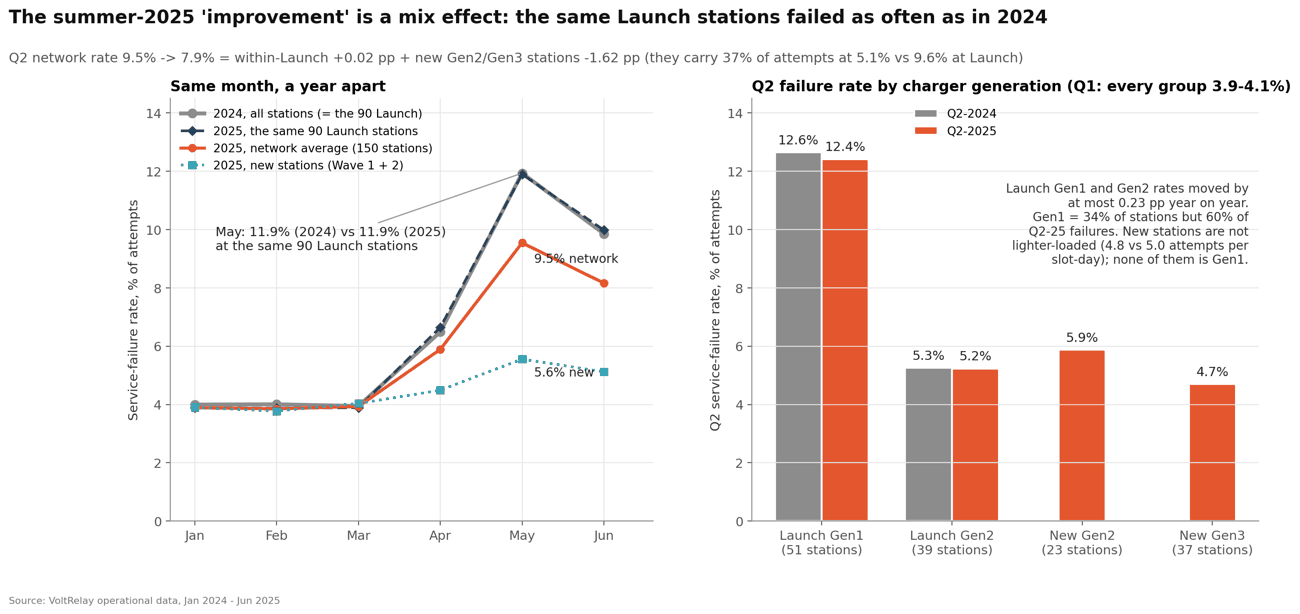

[fig] q1_04 saved


In [50]:
# Figure 4: same-month YoY failure rate by station group + Q2 failure rate by charger generation
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.6), gridspec_kw={"width_ratios": [1, 1.05]})
mo = np.arange(1, 7)
mlab = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]


def grp_rate(yr, grp=None):
    d = sm.filter(pl.col("month").dt.year() == yr)
    if grp:
        d = d.filter(pl.col("grp") == grp)
    d = d.group_by(pl.col("month").dt.month().alias("m")).agg(pl.col("failures").sum(), pl.col("attempts").sum()).sort("m")
    d = d.filter(pl.col("m") <= 6)
    return d["m"].to_numpy(), (d["failures"] / d["attempts"] * 100).to_numpy()


x, y24 = grp_rate(2024)
_, y25 = grp_rate(2025)
_, y25l = grp_rate(2025, "Launch")
_, y25n = grp_rate(2025, "New")
a1.plot(x, y24, color=PALETTE["muted"], lw=3.2, marker="o", ms=7, label="2024, all stations (= the 90 Launch)")
a1.plot(x, y25l, color=PALETTE["primary"], lw=2.2, ls="--", marker="D", ms=5, label="2025, the same 90 Launch stations")
a1.plot(x, y25, color=PALETTE["accent"], lw=2.6, marker="o", label="2025, network average (150 stations)")
a1.plot(x, y25n, color=SERIES[5], lw=2.2, ls=":", marker="s", label="2025, new stations (Wave 1 + 2)")
a1.annotate(f"May: {y24[4]:.1f}% (2024) vs {y25l[4]:.1f}% (2025)\nat the same 90 Launch stations", (5, y24[4]), xytext=(1.25, 9.3),
            textcoords="data", fontsize=10.5, color="#222222", arrowprops=dict(arrowstyle="-", color="#999999"))
a1.annotate(f"{y25[4]:.1f}% network", (5, y25[4]), xytext=(10, -16), textcoords="offset points", fontsize=10, color="#222222")
a1.annotate(f"{y25n[4]:.1f}% new", (5, y25n[4]), xytext=(10, -14), textcoords="offset points", fontsize=10, color="#222222")
a1.set_xticks(mo)
a1.set_xticklabels(mlab)
a1.set_ylabel("Service-failure rate, % of attempts")
a1.set_ylim(0, 14.5)
a1.set_xlim(0.7, 6.6)
a1.set_title("Same month, a year apart", fontsize=12, loc="left")
a1.legend(loc="upper left", fontsize=9.5)
cats = [("Launch", "Gen1"), ("Launch", "Gen2"), ("New", "Gen2"), ("New", "Gen3")]
cq = cg[cg.quarter == "Q2"]
xc = np.arange(len(cats))
wc = 0.36
for j, (yr, colr) in enumerate([(2024, PALETTE["muted"]), (2025, PALETTE["accent"])]):
    for i, (gname, gen) in enumerate(cats):
        r = cq[(cq.yr == yr) & (cq.grp == gname) & (cq.charger_generation == gen)]
        if len(r) == 0:
            continue
        xv = xc[i] + (j - 0.5) * wc if gname == "Launch" else xc[i]
        a2.bar(xv, r.fail_rate_pct.iloc[0], width=wc, color=colr, edgecolor="white", linewidth=1.5, label=f"Q2-{yr}" if i == 0 else None)
        a2.text(xv, r.fail_rate_pct.iloc[0] + 0.2, f"{r.fail_rate_pct.iloc[0]:.1f}%", ha="center", va="bottom", fontsize=10.5, color="#222222")
nst = {(r.grp, r.charger_generation): int(r.stations) for r in cq[cq.yr == 2025].itertuples()}
a2.set_xticks(xc)
a2.set_xticklabels([f"{g} {gen}\n({nst[(g, gen)]} stations)" for g, gen in cats], fontsize=10.5)
a2.set_ylabel("Q2 service-failure rate, % of attempts")
a2.set_ylim(0, 14.5)
a2.grid(axis="x", visible=False)
a2.legend(loc="upper left", bbox_to_anchor=(0.30, 1.0))
q1min, q1max = cg[cg.quarter == "Q1"].fail_rate_pct.min(), cg[cg.quarter == "Q1"].fail_rate_pct.max()
a2.set_title(f"Q2 failure rate by charger generation (Q1: every group {q1min:.1f}-{q1max:.1f}%)", fontsize=12, loc="left")
u_new = util.filter(pl.col("grp") == "New")["attempts_per_slot_day"].item()
u_l = util.filter(pl.col("grp") == "Launch")["attempts_per_slot_day"].item()
lchg = cq[cq.grp == "Launch"].pivot_table(index="charger_generation", columns="yr", values="fail_rate_pct")
lmax = (lchg[2025] - lchg[2024]).abs().max()
a2.text(0.98, 0.80, f"Launch Gen1 and Gen2 rates moved by\nat most {lmax:.2f} pp year on year.\nGen1 = {g1_share_st * 100:.0f}% of stations but {g1_share_fail * 100:.0f}% of\n"
        f"Q2-25 failures. New stations are not\nlighter-loaded ({u_new:.1f} vs {u_l:.1f} attempts per\nslot-day); none of them is Gen1.",
        transform=a2.transAxes, ha="right", va="top", fontsize=10, color="#333333")
d_q2 = decomp["Q2"]
title_block(fig, "The summer-2025 'improvement' is a mix effect: the same Launch stations failed as often as in 2024",
            f"Q2 network rate {d_q2['r0'] * 100:.1f}% -> {d_q2['r1'] * 100:.1f}% = within-Launch {d_q2['within'] * 100:+.2f} pp + new Gen2/Gen3 stations "
            f"{d_q2['dilution'] * 100:+.2f} pp (they carry {d_q2['w_new'] * 100:.0f}% of attempts at {d_q2['r_new'] * 100:.1f}% vs {d_q2['r_launch'] * 100:.1f}% at Launch)",
            top=0.84)
save_fig(fig, "q1_04_failure_dilution_launch_vs_network")
print("[fig] q1_04 saved")

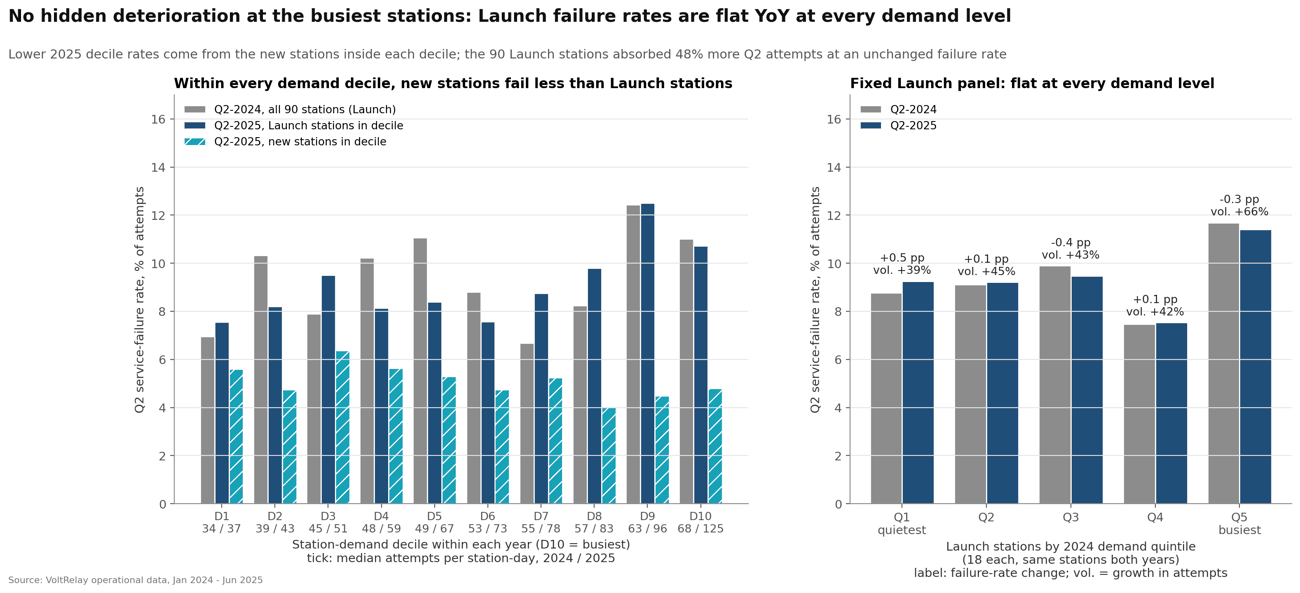

[fig] q1_08 saved


In [51]:
# Figure 8: station-demand deciles (within-decile Launch vs new) and the Launch fixed panel by 2024 demand quintile
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17.5, 6.8), gridspec_kw={"width_ratios": [1.3, 1]})
q2 = dec[dec.quarter == "Q2"]
xd = np.arange(1, 11)
wd = 0.27
b24 = q2[q2.year == 2024].set_index("decile").reindex(xd)
b25 = q2[q2.year == 2025].set_index("decile").reindex(xd)
a1.bar(xd - wd, b24.fail_rate_pct, width=wd, color=PALETTE["muted"], edgecolor="white", label="Q2-2024, all 90 stations (Launch)")
a1.bar(xd, b25.fail_rate_launch_pct, width=wd, color=PALETTE["primary"], edgecolor="white", label="Q2-2025, Launch stations in decile")
a1.bar(xd + wd, b25.fail_rate_new_pct, width=wd, color=SERIES[5], edgecolor="white", hatch="//", label="Q2-2025, new stations in decile")
a1.set_xticks(xd)
a1.set_xticklabels([f"D{i}\n{b24.median_demand_per_day.loc[i]:.0f} / {b25.median_demand_per_day.loc[i]:.0f}" for i in xd], fontsize=9.8)
a1.set_xlabel("Station-demand decile within each year (D10 = busiest)\ntick: median attempts per station-day, 2024 / 2025")
a1.set_ylabel("Q2 service-failure rate, % of attempts")
a1.set_ylim(0, 17)
a1.grid(axis="x", visible=False)
a1.legend(loc="upper left", fontsize=9.5, ncol=1)
a1.set_title("Within every demand decile, new stations fail less than Launch stations", fontsize=12, loc="left")
lq2 = lq[lq.quarter == "Q2"].set_index("quintile_2024")
xq = np.arange(1, 6)
a2.bar(xq - 0.19, lq2.fail_rate_2024_pct, width=0.38, color=PALETTE["muted"], edgecolor="white", label="Q2-2024")
a2.bar(xq + 0.19, lq2.fail_rate_2025_pct, width=0.38, color=PALETTE["primary"], edgecolor="white", label="Q2-2025")
for i in xq:
    a2.text(i, max(lq2.fail_rate_2024_pct.loc[i], lq2.fail_rate_2025_pct.loc[i]) + 0.3,
            f"{lq2.change_pp.loc[i]:+.1f} pp\nvol. {lq2.attempt_growth_pct.loc[i]:+.0f}%", ha="center", fontsize=9.8, color="#222222")
a2.set_xticks(xq)
a2.set_xticklabels([f"Q{i}" + ("\nquietest" if i == 1 else "\nbusiest" if i == 5 else "") for i in xq], fontsize=10.5)
a2.set_xlabel("Launch stations by 2024 demand quintile\n(18 each, same stations both years)\nlabel: failure-rate change; vol. = growth in attempts")
a2.set_ylabel("Q2 service-failure rate, % of attempts")
a2.set_ylim(0, 17)
a2.grid(axis="x", visible=False)
a2.legend(loc="upper left")
a2.set_title("Fixed Launch panel: flat at every demand level", fontsize=12, loc="left")
launch_growth = (SP["Q2-25"].loc[SP["Q2-25"].grp == "Launch", "attempts"].sum() / SP["Q2-24"]["attempts"].sum() - 1) * 100
title_block(fig, "No hidden deterioration at the busiest stations: Launch failure rates are flat YoY at every demand level",
            f"Lower 2025 decile rates come from the new stations inside each decile; the 90 Launch stations absorbed "
            f"{launch_growth:.0f}% more Q2 attempts at an unchanged failure rate", top=0.84)
save_fig(fig, "q1_08_failure_by_demand_decile_and_launch_panel")
print("[fig] q1_08 saved")

### Is queue wait a load signal at all? (testing the survivorship explanation)
The completed-swap wait is flat every month. One explanation is survivorship: stressed riders abandon instead of
waiting longer. If that were the whole story, the wait should still rise somewhat with load (by hour of day, at the
most stressed stations) and abandoned riders should wait longer in peak months. Check all three.

In [52]:
qx = (events(["month", "hour", "event_type", "queue_wait_sec", "city", "charger_generation"])
      .group_by("month", "hour", "city", "charger_generation", "event_type")
      .agg(pl.len().alias("n"), pl.col("queue_wait_sec").count().alias("nq"), pl.col("queue_wait_sec").cast(pl.Float64).sum().alias("s"))
      .collect(engine="streaming"))
qcomp = qx.filter(pl.col("event_type") == "swap_completed")
q_hour = qcomp.group_by("hour").agg((pl.col("s").sum() / pl.col("nq").sum() / 60).alias("wait_min"), pl.col("n").sum().alias("swaps")).sort("hour")
q_hour_main = q_hour.filter(pl.col("swaps") >= 0.01 * q_hour["swaps"].sum())      # hours carrying >= 1% of swaps
q_ab = (qx.filter(pl.col("event_type") == "abandoned_queue").group_by("month")
        .agg((pl.col("s").sum() / pl.col("nq").sum() / 60).alias("wait_min")).sort("month"))
may25 = qx.filter(pl.col("month") == M(2025, 5)).with_columns(
    (pl.col("city").is_in(HOT) & (pl.col("charger_generation") == "Gen1")).alias("hot_gen1"))


def cell_stats(d):
    dc = d.filter(pl.col("event_type") == "swap_completed")
    return dict(wait_min=dc["s"].sum() / dc["nq"].sum() / 60, swaps=dc["n"].sum(),
                fail_rate_pct=d.filter(pl.col("event_type").is_in(FAIL_TYPES))["n"].sum() / d["n"].sum() * 100)


hot_c = cell_stats(may25.filter(pl.col("hot_gen1")))
other_cells = pd.DataFrame([{"city": k[0], "charger_generation": k[1], **cell_stats(g)}
                            for k, g in may25.filter(~pl.col("hot_gen1")).group_by("city", "charger_generation")])
other_cells = other_cells[other_cells.swaps >= 5000]
print(f"[4c] Completed-swap wait by hour of day (hours with >=1% of swaps): {q_hour_main['wait_min'].min():.3f}-{q_hour_main['wait_min'].max():.3f} min "
      f"(all 24 hours: {q_hour['wait_min'].min():.3f}-{q_hour['wait_min'].max():.3f})")
print(f"[4c] May-25, Gen1 stations in Delhi NCR/Jaipur/Hyderabad: failure rate {hot_c['fail_rate_pct']:.1f}%, completed wait {hot_c['wait_min']:.3f} min; "
      f"other city x generation cells (>=5,000 swaps): failure rate {other_cells.fail_rate_pct.min():.1f}-{other_cells.fail_rate_pct.max():.1f}%, "
      f"completed wait {other_cells.wait_min.min():.3f}-{other_cells.wait_min.max():.3f} min")
print(f"[4c] Abandoned-queue wait by month: {q_ab['wait_min'].min():.2f}-{q_ab['wait_min'].max():.2f} min "
      f"(May-24 {q_ab.filter(pl.col('month') == M(2024, 5))['wait_min'].item():.2f}, Oct-24 {q_ab.filter(pl.col('month') == M(2024, 10))['wait_min'].item():.2f})")
pd.concat([q_hour.to_pandas().assign(slice="completed wait by hour"),
           other_cells.assign(slice="May-25 completed wait, other city x generation cells"),
           pd.DataFrame([{**hot_c, "slice": "May-25 completed wait, hot-city Gen1"}]),
           q_ab.to_pandas().assign(slice="abandoned wait by month")]).to_csv(TAB / "q1_queue_wait_load_check.csv", index=False)

[4c] Completed-swap wait by hour of day (hours with >=1% of swaps): 4.054-4.083 min (all 24 hours: 4.048-4.088)
[4c] May-25, Gen1 stations in Delhi NCR/Jaipur/Hyderabad: failure rate 19.0%, completed wait 4.056 min; other city x generation cells (>=5,000 swaps): failure rate 4.1-12.8%, completed wait 4.036-4.097 min
[4c] Abandoned-queue wait by month: 11.57-11.82 min (May-24 11.76, Oct-24 11.60)


### Is a failed attempt a delayed swap or a lost one?
For every Q2-25 service failure, the time until the same rider's next completed swap (any station). A short gap
means the swap was only delayed; a long gap or none means riding time, and probably revenue, was lost.

In [53]:
rr = (events(["rider_id", "event_ts", "month", "is_completed", "is_service_failure"]).filter(in_per("Q2-25"))
      .select("rider_id", "event_ts", "is_completed", "is_service_failure").collect(engine="streaming").sort("rider_id", "event_ts"))
rr = rr.with_columns(pl.when(pl.col("is_completed")).then(pl.col("event_ts")).alias("cts")).with_columns(
    pl.col("cts").backward_fill().over("rider_id").alias("next_completed"))
gap = rr.filter(pl.col("is_service_failure")).select(((pl.col("next_completed") - pl.col("event_ts")).dt.total_minutes()).alias("gap_min"))["gap_min"]
lost_ub = P["Q2-25"]["failures"] * P["Q2-25"]["revenue_ps"]
within = {m: (gap <= m).fill_null(False).mean() * 100 for m in (60, 180, 1440)}   # denominator = all failures
print(f"[4d] Q2-25 service failures ({gap.len():,}) followed by the same rider's completed swap within 60 min: {within[60]:.1f}%; within 3 h: "
      f"{within[180]:.1f}%; within 24 h: {within[1440]:.1f}%; never in Q2-25: {gap.is_null().mean() * 100:.1f}%")
print(f"[4d] Upper bound on Q2-25 revenue lost to failures (failures x revenue per swap): Rs{lost_ub / 1e6:.2f}M "
      f"({P['Q2-25']['failures']:,} failures x Rs{P['Q2-25']['revenue_ps']:.2f})")
del rr, gap

[4d] Q2-25 service failures (77,445) followed by the same rider's completed swap within 60 min: 5.2%; within 3 h: 11.3%; within 24 h: 58.3%; never in Q2-25: 2.0%
[4d] Upper bound on Q2-25 revenue lost to failures (failures x revenue per swap): Rs5.03M (77,445 failures x Rs64.89)


## 5. Contribution-margin bridge (hero figure 2)
**Exact shift-share.** Segments s = vehicle class (2W/3W) x billing (independent / ZipDrop / other partner) x pilot city
(Bengaluru+Pune vs other). With w = segment share of swaps:
* **Mix** = sum_s (w1 - w0) x cm1_0,s (segment composition, e.g. more 3W or partner swaps).
* **Rate effects** (weighted by w1) split exactly, per segment, using revenue = list x (1 - d) + pilot adjustment
  (d = discount / list; the pilot adjustment = amount charged - list + discount, i.e. +Rs15 peak / -Rs8 off-peak):
  - base list price = dList x (1 - d0) (net of partner discount at the old rate);
  - partner discount rate = -List1 x dd, split into **ZipDrop** (12% -> 28% amendment) and other partners;
  - pilot = d(pilot adjustment);
  - energy = kWh/swap effect (dkWh x tariff0) + grid-tariff effect (kWh1 x dtariff);
  - battery wear = **supplier-share (Kyron) effect** = sum_k du_k x reference wear_k (full-window wear per swap of
    supplier k, same vehicle class) + within-supplier change (the rest).
* Fixed cost (for cm2) is taken at network level: d(cm2) = d(cm1) - d(fixed cost per swap).
The components sum exactly to the change in cm1 per swap (checked below).

**Window choice.** The headline bridges end in Mar-25: H1-24 -> Jul-Aug-24 -> Oct-24..Mar-25, and the same-season
Q1-24 -> Q1-25. From Apr-25 the per-cycle wear is also charged on Kyron packs issued below 70% EOL (section 5b), which
inflates the Kyron term, so the H1-25 and Q2-25 bridges are printed for transparency only and flagged.

In [54]:
seg = (events(["month", "is_completed", "vehicle_class", "partner_id", "city", "supplier_out", "list_price_inr", "discount_inr",
               "amount_charged_inr", "energy_cost", "energy_to_recharge_kwh", "wear_cost", "fixed_cost", "soh_out_pct"])
       .filter(c)
       .with_columns(pl.when(pl.col("partner_id").is_null()).then(pl.lit("Independent"))
                     .when(pl.col("partner_id") == ZIPDROP_ID).then(pl.lit("ZipDrop")).otherwise(pl.lit("Other partner")).alias("billing"),
                     pl.col("city").is_in(PILOT_CITIES).alias("pilot_city"),
                     (pl.col("soh_out_pct") < EOL_SOH).fill_null(False).alias("post_eol"))
       .group_by("month", "vehicle_class", "billing", "pilot_city", "supplier_out", "post_eol")
       .agg(pl.len().alias("n"),
            pl.col("list_price_inr").cast(pl.Float64).sum().alias("L"), pl.col("discount_inr").cast(pl.Float64).sum().alias("D"),
            pl.col("amount_charged_inr").cast(pl.Float64).sum().alias("A"), pl.col("energy_cost").cast(pl.Float64).sum().alias("E"),
            pl.col("energy_to_recharge_kwh").cast(pl.Float64).sum().alias("K"), pl.col("wear_cost").cast(pl.Float64).sum().alias("W"),
            pl.col("fixed_cost").cast(pl.Float64).sum().alias("F"))
       .collect(engine="streaming"))
SEG = ["vehicle_class", "billing", "pilot_city"]
chk = seg.group_by("month").agg((pl.col("A") - pl.col("E") - pl.col("W")).sum().alias("cm1")).sort("month").join(mon.select("month", "cm1"), on="month")
print(f"[5] segment table rows={seg.height}; max |cm1 check| vs monthly panel = {float((chk['cm1'] - chk['cm1_right']).abs().max()):.4f}")
gref = (seg.group_by("vehicle_class", "supplier_out").agg((pl.col("W").sum() / pl.col("n").sum()).alias("g_ref"), pl.col("n").sum())
        .sort("vehicle_class", "supplier_out"))
print("[5] reference wear per swap by supplier x class (full window):")
print(gref)
GREF = {(r["vehicle_class"], r["supplier_out"]): r["g_ref"] for r in gref.iter_rows(named=True)}
print(f"[5] Kyron 2W wear per swap = {GREF[('2W', 'Kyron')] / GREF[('2W', 'Cellora')]:.2f}x Cellora 2W "
      f"({GREF[('2W', 'Kyron')]:.1f} vs {GREF[('2W', 'Cellora')]:.1f} Rs/swap)")


def seg_stats(p):
    g = seg.filter(in_per(p))
    s = g.group_by(SEG).agg([pl.col(x).sum() for x in ["n", "L", "D", "A", "E", "K", "W", "F"]]).to_pandas().set_index(SEG)
    s["Lm"], s["Dm"], s["Am"], s["Em"], s["Km"], s["Wm"] = s.L / s.n, s.D / s.n, s.A / s.n, s.E / s.n, s.K / s.n, s.W / s.n
    s["d"] = s.Dm / s.Lm
    s["Pm"] = s.Am - s.Lm + s.Dm
    s["tau"] = s.E / s.K
    s["cm1m"] = s.Am - s.Em - s.Wm
    u = (g.group_by(SEG + ["supplier_out"]).agg(pl.col("n").sum()).to_pandas()
         .pivot_table(index=SEG, columns="supplier_out", values="n", aggfunc="sum").fillna(0))
    u = u.div(u.sum(axis=1), axis=0)
    return s, u, g["n"].sum(), g["F"].sum()


def bridge(p0, p1):
    s0, u0, N0, F0 = seg_stats(p0)
    s1, u1, N1, F1 = seg_stats(p1)
    idx = s0.index.union(s1.index)
    s0, s1 = s0.reindex(idx), s1.reindex(idx)
    w0, w1 = (s0.n / N0).fillna(0), (s1.n / N1).fillna(0)
    both = s0.n.notna() & s1.n.notna()
    comp = {}
    mix = ((w1 - w0) * s0.cm1m)[both].sum() + (w1 * s1.cm1m)[~both & s1.n.notna()].sum() - (w0 * s0.cm1m)[~both & s0.n.notna()].sum()
    b = both
    comp["Base list price"] = (w1 * (s1.Lm - s0.Lm) * (1 - s0.d))[b].sum()
    zd = np.array([i[1] == "ZipDrop" for i in idx])
    op = np.array([i[1] == "Other partner" for i in idx])
    disc = -(w1 * s1.Lm * (s1.d - s0.d))
    comp["ZipDrop discount"] = disc[b & zd].sum()
    comp["Other partner discounts"] = disc[b & op].sum()
    comp["Peak/off-peak pilot"] = (w1 * (s1.Pm - s0.Pm))[b].sum()
    comp["Energy: kWh per swap"] = -(w1 * (s1.Km - s0.Km) * s0.tau)[b].sum()
    comp["Energy: grid tariff"] = -(w1 * s1.Km * (s1.tau - s0.tau))[b].sum()
    sup = sorted(set(u0.columns) | set(u1.columns))
    u0r, u1r = u0.reindex(index=idx, columns=sup).fillna(0), u1.reindex(index=idx, columns=sup).fillna(0)
    gr = pd.DataFrame({k: [GREF.get((i[0], k), np.nan) for i in idx] for k in sup}, index=idx).fillna(0)
    share_eff = ((u1r - u0r) * gr).sum(axis=1)
    comp["Wear: Kyron share of packs"] = -(w1 * share_eff)[b].sum()
    comp["Wear: within supplier"] = -(w1 * ((s1.Wm - s0.Wm) - share_eff))[b].sum()
    comp["Segment mix"] = mix
    cm1_0 = (s0.A.sum() - s0.E.sum() - s0.W.sum()) / N0
    cm1_1 = (s1.A.sum() - s1.E.sum() - s1.W.sum()) / N1
    f0, f1 = F0 / N0, F1 / N1
    out = pd.Series(comp)
    resid = (cm1_1 - cm1_0) - out.sum()
    return dict(p0=p0, p1=p1, cm1_0=cm1_0, cm1_1=cm1_1, comp=out, resid=resid, f0=f0, f1=f1,
                cm2_0=cm1_0 - f0, cm2_1=cm1_1 - f1, N1=N1, months1=g_months(p1))


def g_months(p):
    a, b = PER[p]
    return (b.year - a.year) * 12 + b.month - a.month + 1


# clean windows first (no post-EOL issue in either period), then the H1-25 / Q2-25 bridges for transparency
BRIDGES = [("H1-24", "Jul-Aug-24"), ("Jul-Aug-24", "Oct-24..Mar-25"), ("Q1-24", "Q1-25"),
           ("Jul-Aug-24", "H1-25"), ("H1-24", "H1-25"), ("Q2-24", "Q2-25")]
BR = {k: bridge(*k) for k in BRIDGES}
br_rows = []
for (p0, p1), r in BR.items():
    vol = r["N1"] / r["months1"]
    pe0, pe1 = P[p0]["post_eol_ps"], P[p1]["post_eol_ps"]
    flag = ("clean window: no pack issued below 70% EOL" if pe0 == 0 and pe1 == 0 else
            f"NOT CLEAN: {p1} includes {pe1:.2f} Rs/swap of wear on packs issued below 70% EOL, inside the Kyron term (section 5b)")
    print(f"\n[5] cm1/swap bridge {p0} -> {p1}: {r['cm1_0']:.2f} -> {r['cm1_1']:.2f} (change {r['cm1_1'] - r['cm1_0']:+.2f}); "
          f"components sum exactly (|residual| < 1e-9: {abs(r['resid']) < 1e-9}); {flag}")
    for k, v in r["comp"].sort_values().items():
        print(f"     {k:<28} {v:+7.2f} Rs/swap  ~ {v * vol / 1e6:+6.2f} M Rs/month at {p1} volume ({vol:,.0f} swaps/month)")
        br_rows.append({"from": p0, "to": p1, "component": k, "rs_per_swap": v, "rs_per_month_at_end_volume": v * vol,
                        "end_period_post_eol_wear_ps": pe1})
    print(f"     fixed cost/swap {r['f0']:.2f} -> {r['f1']:.2f} => cm2/swap {r['cm2_0']:.2f} -> {r['cm2_1']:.2f} "
          f"(fixed-cost effect {-(r['f1'] - r['f0']):+.2f} Rs/swap ~ {-(r['f1'] - r['f0']) * vol / 1e6:+.2f} M Rs/month)")
    br_rows += [{"from": p0, "to": p1, "component": "cm1_per_swap_start", "rs_per_swap": r["cm1_0"]},
                {"from": p0, "to": p1, "component": "cm1_per_swap_end", "rs_per_swap": r["cm1_1"]},
                {"from": p0, "to": p1, "component": "Fixed cost per swap (cm2 only)", "rs_per_swap": -(r["f1"] - r["f0"]),
                 "rs_per_month_at_end_volume": -(r["f1"] - r["f0"]) * vol},
                {"from": p0, "to": p1, "component": "cm2_per_swap_start", "rs_per_swap": r["cm2_0"]},
                {"from": p0, "to": p1, "component": "cm2_per_swap_end", "rs_per_swap": r["cm2_1"]}]
pd.DataFrame(br_rows).to_csv(TAB / "q1_cm_bridge.csv", index=False)

[5] segment table rows=629; max |cm1 check| vs monthly panel = 0.0000
[5] reference wear per swap by supplier x class (full window):
shape: (6, 4)
┌───────────────┬──────────────┬─────────┬─────────┐
│ vehicle_class ┆ supplier_out ┆ g_ref   ┆ n       │
│ ---           ┆ ---          ┆ ---     ┆ ---     │
│ str           ┆ str          ┆ f64     ┆ u32     │
╞═══════════════╪══════════════╪═════════╪═════════╡
│ 2W            ┆ Amptek       ┆ 31.880  ┆ 706085  │
│ 2W            ┆ Cellora      ┆ 31.854  ┆ 1951961 │
│ 2W            ┆ Kyron        ┆ 103.878 ┆ 556365  │
│ 3W            ┆ Amptek       ┆ 76.340  ┆ 78873   │
│ 3W            ┆ Cellora      ┆ 76.192  ┆ 196902  │
│ 3W            ┆ Kyron        ┆ 107.199 ┆ 96489   │
└───────────────┴──────────────┴─────────┴─────────┘
[5] Kyron 2W wear per swap = 3.26x Cellora 2W (103.9 vs 31.9 Rs/swap)



[5] cm1/swap bridge H1-24 -> Jul-Aug-24: 0.64 -> 6.75 (change +6.11); components sum exactly (|residual| < 1e-9: True); clean window: no pack issued below 70% EOL
     Other partner discounts        -0.01 Rs/swap  ~  -0.00 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     ZipDrop discount               -0.00 Rs/swap  ~  -0.00 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Peak/off-peak pilot            +0.00 Rs/swap  ~  +0.00 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Wear: Kyron share of packs     +0.01 Rs/swap  ~  +0.00 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Wear: within supplier          +0.05 Rs/swap  ~  +0.01 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Energy: grid tariff            +0.06 Rs/swap  ~  +0.01 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Segment mix                    +0.14 Rs/swap  ~  +0.02 M Rs/month at Jul-Aug-24 volume (155,150 swaps/month)
     Energy: kWh per swap           +0

### Direct monthly rupee impact of the biggest items, cross-checking the bridge
* Kyron excess wear = sum over Kyron-issued swaps of (wear - Cellora wear per swap of the same class). Shown for the
  clean Q1-25 window and for H1-25, where it is split into pre-EOL issues and the charges on post-EOL issues.
* ZipDrop amendment = ZipDrop swaps x list price x (28% - 12%) (H1-25).
* Base price rise = swaps x list-price step x (1 - discount rate), at H1-2025 volume.
* Pilot = net surcharge collected in Bengaluru + Pune (peak +Rs15, off-peak -Rs8) - gross, before any volume response.

In [55]:
h125 = seg.filter(in_per("H1-25"))
nm = g_months("H1-25")


def kyron_excess(p, cls, post=None):
    """Kyron excess wear over the Cellora wear of the same class: (Rs per month, a cost is negative; Kyron swaps per month)."""
    k = seg.filter(in_per(p) & (pl.col("supplier_out") == "Kyron") & (pl.col("vehicle_class") == cls))
    if post is not None:
        k = k.filter(pl.col("post_eol") == post)
    return -(k["W"].sum() - k["n"].sum() * GREF[(cls, "Cellora")]) / g_months(p), k["n"].sum() / g_months(p)


ky2_h1, n2_h1 = kyron_excess("H1-25", "2W")
ky2_pre, n2_pre = kyron_excess("H1-25", "2W", post=False)
ky2_q1, n2_q1 = kyron_excess("Q1-25", "2W")
ky3_h1, _ = kyron_excess("H1-25", "3W")
pe2_h1 = -h125.filter((pl.col("vehicle_class") == "2W") & pl.col("post_eol"))["W"].sum() / nm
zdp = h125.filter(pl.col("billing") == "ZipDrop").select(pl.col("n").sum(), pl.col("L").sum(), pl.col("D").sum()).row(0, named=True)
zd_month = zdp["L"] * (0.28 - 0.12) / nm
pil = h125.filter(pl.col("pilot_city")).select((pl.col("A") - pl.col("L") + pl.col("D")).sum()).item() / nm
lst = h125.group_by("vehicle_class").agg(pl.col("n").sum(), pl.col("L").sum(), pl.col("D").sum()).to_pandas()
lst["step"] = lst.vehicle_class.map({"2W": 5.0, "3W": 10.0})
price_month = (lst.n * lst.step * (1 - lst.D / lst.L)).sum() / nm
imp = pd.DataFrame([
    {"item": "Kyron 2W excess battery wear vs Cellora", "window": "Q1-25 (no post-EOL issues)", "rs_per_month": ky2_q1,
     "basis": f"{n2_q1:,.0f} Kyron-2W swaps/month x (Kyron wear - Cellora {GREF[('2W', 'Cellora')]:.1f})"},
    {"item": "Kyron 2W excess battery wear vs Cellora, per-cycle model", "window": "H1-25", "rs_per_month": ky2_h1,
     "basis": f"{n2_h1:,.0f} Kyron-2W swaps/month; includes post-EOL issues"},
    {"item": "Kyron 2W excess battery wear vs Cellora, pre-EOL issues only", "window": "H1-25", "rs_per_month": ky2_pre,
     "basis": f"{n2_pre:,.0f} Kyron-2W pre-EOL swaps/month"},
    {"item": "Wear charged on Kyron 2W packs issued below 70% EOL (beyond purchase cost)", "window": "H1-25", "rs_per_month": pe2_h1,
     "basis": "all of it is depreciation beyond the purchase cost"},
    {"item": "Kyron 3W excess battery wear vs Cellora", "window": "H1-25", "rs_per_month": ky3_h1, "basis": "3W packs"},
    {"item": "ZipDrop discount 12% -> 28%", "window": "H1-25", "rs_per_month": -zd_month, "basis": f"{zdp['n'] / nm:,.0f} ZipDrop swaps/month x list x 16 pts"},
    {"item": "Base price rise (Jul-24), net of partner discounts", "window": "H1-25", "rs_per_month": price_month, "basis": "2W +Rs5, 3W +Rs10 x H1-25 swaps"},
    {"item": "Peak/off-peak pilot net surcharge (gross of volume response)", "window": "H1-25", "rs_per_month": pil, "basis": "Bengaluru + Pune"},
])
imp["rs_M_per_month"] = imp.rs_per_month / 1e6
imp.to_csv(TAB / "q1_cm_monthly_impact.csv", index=False)
print("\n[5] Direct monthly rupee impact, H1-2025 average month")
print(imp.round(2).to_string(index=False))


[5] Direct monthly rupee impact, H1-2025 average month
                                                                      item                     window   rs_per_month                                                     basis  rs_M_per_month
                                   Kyron 2W excess battery wear vs Cellora Q1-25 (no post-EOL issues) -4,301,650.970 59,816 Kyron-2W swaps/month x (Kyron wear - Cellora 31.9)          -4.300
                  Kyron 2W excess battery wear vs Cellora, per-cycle model                      H1-25 -4,484,259.900     62,291 Kyron-2W swaps/month; includes post-EOL issues          -4.480
              Kyron 2W excess battery wear vs Cellora, pre-EOL issues only                      H1-25 -3,010,505.240                       42,095 Kyron-2W pre-EOL swaps/month          -3.010
Wear charged on Kyron 2W packs issued below 70% EOL (beyond purchase cost)                      H1-25 -2,117,065.450        all of it is depreciation beyond the purchase cost      

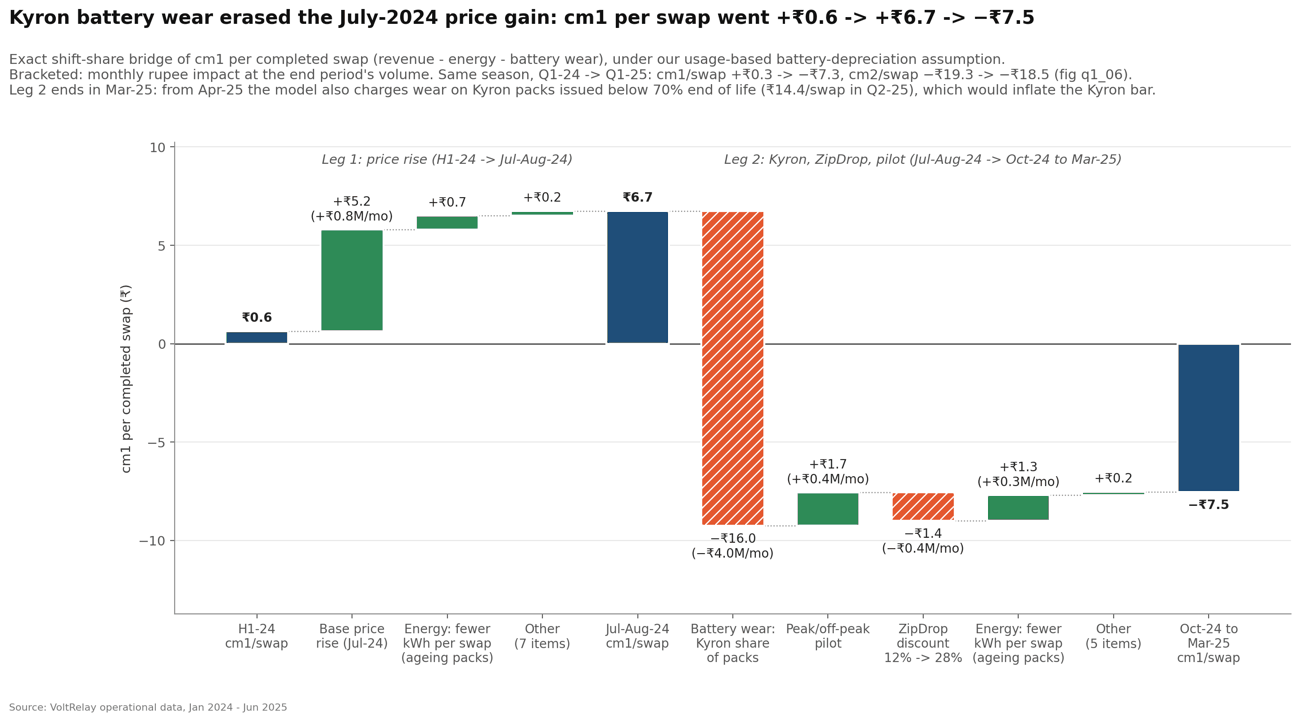

[fig] q1_05_cm1_bridge_waterfall saved


In [56]:
# Hero figure 2: chained waterfall H1-24 -> Jul-Aug-24 -> H1-25 (cm1 per swap)
SHORT = {"Base list price": "Base price\nrise (Jul-24)", "ZipDrop discount": "ZipDrop\ndiscount\n12% -> 28%",
         "Other partner discounts": "Other partner\ndiscounts", "Peak/off-peak pilot": "Peak/off-peak\npilot",
         "Energy: kWh per swap": "Energy: fewer\nkWh per swap\n(ageing packs)", "Energy: grid tariff": "Energy:\ngrid tariff",
         "Wear: Kyron share of packs": "Battery wear:\nKyron share\nof packs", "Wear: within supplier": "Battery wear:\nwithin supplier",
         "Segment mix": "Segment mix\n(2W/3W, partner,\ncity)"}


def plab(p):
    return DISP.get(p, p).replace(" to ", " to\n")


def legs_to_steps(legs, min_abs=0.35, max_items=5):
    steps = []
    for (p0, p1) in legs:
        r = BR[(p0, p1)]
        if not steps:
            steps.append((f"{plab(p0)}\ncm1/swap", r["cm1_0"], "total", None))
        comp = r["comp"].copy()
        keep = comp[comp.abs() >= min_abs].abs().sort_values(ascending=False).index[:max_items]
        rest = comp.drop(keep)
        vol = r["N1"] / r["months1"]
        for k in comp.loc[keep].sort_values(key=lambda s: -s.abs()).index:
            steps.append((SHORT[k], comp[k], "delta", comp[k] * vol))
        if len(rest):
            steps.append((f"Other\n({len(rest)} items)", rest.sum(), "delta", rest.sum() * vol))
        steps.append((f"{plab(p1)}\ncm1/swap", r["cm1_1"], "total", None))
    return steps


def draw_waterfall(ax, steps, show_month=True, breaks=()):
    """breaks: indices after which no connector is drawn (the next bar starts a new bridge)."""
    cum = 0.0
    for i, (lab, v, kind, per_month) in enumerate(steps):
        if kind == "total":
            bottom, height, colr = 0.0, v, PALETTE["primary"]
            cum = v
        else:
            bottom, height = cum, v
            colr = PALETTE["good"] if v >= 0 else PALETTE["accent"]
            cum += v
        ax.bar(i, height, bottom=bottom, width=0.66, color=colr, edgecolor="white", linewidth=1.5, zorder=3,
               hatch=None if (kind == "total" or v >= 0) else "///")
        top, bot = max(bottom, bottom + height), min(bottom, bottom + height)
        txt = (rs(v, sign=False) if kind == "total" else rs(v))
        if kind == "delta" and per_month is not None and show_month and abs(per_month) >= 0.2e6:
            txt += f"\n({'+' if per_month >= 0 else MINUS}{RS}{abs(per_month) / 1e6:.1f}M/mo)"
        if (kind == "total" and v >= 0) or (kind == "delta" and v >= 0):
            ax.text(i, top + 0.35, txt, ha="center", va="bottom", fontsize=10, fontweight="bold" if kind == "total" else None, color="#222222")
        else:
            ax.text(i, bot - 0.35, txt, ha="center", va="top", fontsize=10, fontweight="bold" if kind == "total" else None, color="#222222")
        if i < len(steps) - 1 and i not in breaks:
            ax.plot([i + 0.33, i + 0.67], [cum, cum], color="#888888", lw=0.9, ls=":", zorder=2)
    ax.axhline(0, color="#444444", lw=1)
    ax.set_xticks(range(len(steps)))
    ax.set_xticklabels([s[0] for s in steps], fontsize=10)
    ax.grid(axis="x", visible=False)


def wf_range(steps):
    cum, lows, highs = 0.0, [], []
    for _, v, kind, _ in steps:
        if kind == "total":
            cum = v
            lows.append(min(0, v))
            highs.append(max(0, v))
        else:
            lows.append(min(cum, cum + v))
            highs.append(max(cum, cum + v))
            cum += v
    return min(lows), max(highs)


LEG2_END = "Oct-24..Mar-25"     # last window before any pack was issued below 70% EOL
steps = legs_to_steps([("H1-24", "Jul-Aug-24"), ("Jul-Aug-24", LEG2_END)])
fig, ax = plt.subplots(figsize=(16, 7.6))
draw_waterfall(ax, steps)
ax.set_ylabel(f"cm1 per completed swap ({RS})")
lo, hi = wf_range(steps)
ax.set_ylim(lo - 4.5, hi + 3.5)
i_mid = next(i for i, s in enumerate(steps) if s[0].startswith("Jul-Aug-24"))
ax.text(i_mid / 2, hi + 2.4, "Leg 1: price rise (H1-24 -> Jul-Aug-24)", ha="center", fontsize=10.5, color="#555555", style="italic")
ax.text((i_mid + len(steps) - 1) / 2, hi + 2.4, f"Leg 2: Kyron, ZipDrop, pilot (Jul-Aug-24 -> {DISP[LEG2_END]})", ha="center", fontsize=10.5,
        color="#555555", style="italic")
r2 = BR[("Jul-Aug-24", LEG2_END)]
rq1 = BR[("Q1-24", "Q1-25")]
title_block(fig, f"Kyron battery wear erased the July-2024 price gain: cm1 per swap went {rs(BR[('H1-24', 'Jul-Aug-24')]['cm1_0'])} -> "
                 f"{rs(r2['cm1_0'])} -> {rs(r2['cm1_1'])}",
            f"Exact shift-share bridge of cm1 per completed swap (revenue - energy - battery wear), under our usage-based battery-depreciation "
            f"assumption.\nBracketed: monthly rupee impact at the end period's volume. Same season, Q1-24 -> Q1-25: cm1/swap {rs(rq1['cm1_0'])} -> "
            f"{rs(rq1['cm1_1'])}, cm2/swap {rs(rq1['cm2_0'])} -> {rs(rq1['cm2_1'])} (fig q1_06).\nLeg 2 ends in Mar-25: from Apr-25 the model also "
            f"charges wear on Kyron packs issued below 70% end of life ({rs(P['Q2-25']['post_eol_ps'], sign=False)}/swap in Q2-25), "
            f"which would inflate the Kyron bar.", top=0.8)
save_fig(fig, "q1_05_cm1_bridge_waterfall")
print("[fig] q1_05_cm1_bridge_waterfall saved")

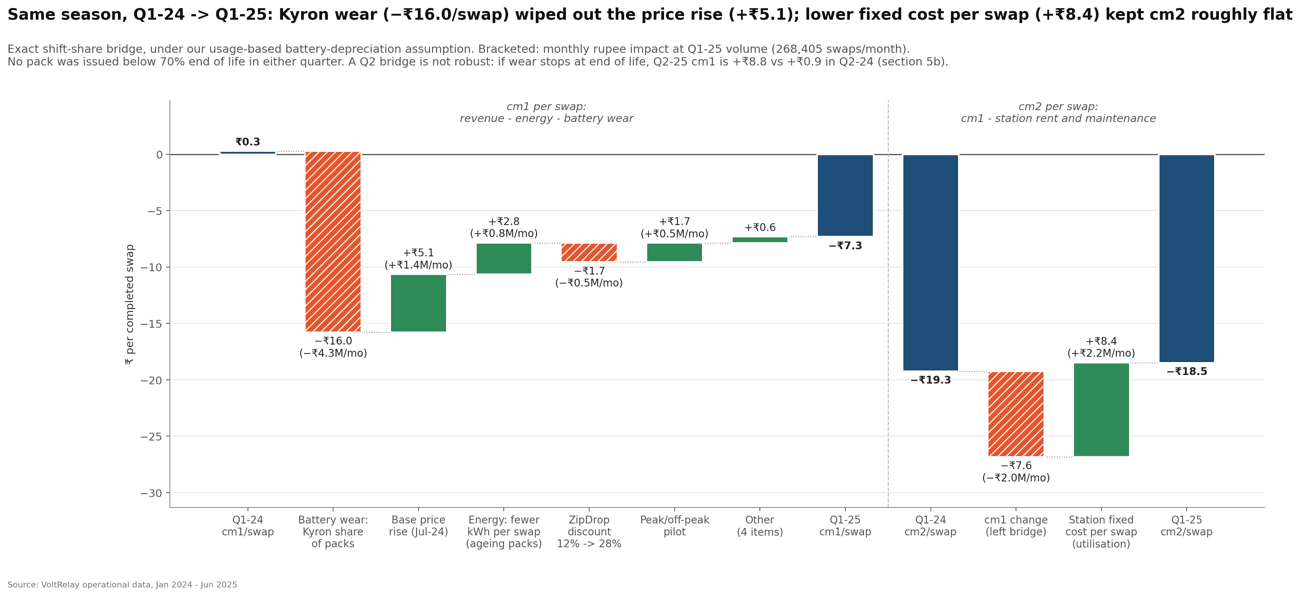

[fig] q1_06 saved


In [57]:
# Same-season bridge Q1-24 -> Q1-25 (supporting figure), as two chained bridges: cm1 (drivers), then cm2 (cm1 change +
# change in station fixed cost per swap). Q1 replaces the first version's Q2 bridge: Q2-25 contains packs issued below
# 70% EOL (section 5b), and the Q2 result flips sign if their wear is capped, while Q1 has no post-EOL issue at all.
# (The first version also added the YoY change in fixed cost to the Q2-25 cm1 level, so its cm2 bars did not chain.)
(FIG / "q1_06_cm_bridge_q2_same_season.png").unlink(missing_ok=True)      # superseded figure
rq = BR[("Q1-24", "Q1-25")]
volq = rq["N1"] / rq["months1"]
stq = legs_to_steps([("Q1-24", "Q1-25")], min_abs=0.35, max_items=5)
n_cm1 = len(stq)
stq = stq + [("Q1-24\ncm2/swap", rq["cm2_0"], "total", None),
             ("cm1 change\n(left bridge)", rq["cm1_1"] - rq["cm1_0"], "delta", (rq["cm1_1"] - rq["cm1_0"]) * volq),
             ("Station fixed\ncost per swap\n(utilisation)", -(rq["f1"] - rq["f0"]), "delta", -(rq["f1"] - rq["f0"]) * volq),
             ("Q1-25\ncm2/swap", rq["cm2_1"], "total", None)]
fig, ax = plt.subplots(figsize=(19, 7.6))
draw_waterfall(ax, stq, breaks=(n_cm1 - 1,))
ax.axvline(n_cm1 - 0.5, color="#BBBBBB", lw=1, ls="--")
ax.set_ylabel(f"{RS} per completed swap")
lo, hi = wf_range(stq)
ax.set_ylim(lo - 4.5, hi + 4.5)
ax.text((n_cm1 - 1) / 2, hi + 2.6, "cm1 per swap:\nrevenue - energy - battery wear", ha="center", fontsize=10.5, color="#555555", style="italic")
ax.text(n_cm1 + 1.5, hi + 2.6, "cm2 per swap:\ncm1 - station rent and maintenance", ha="center", fontsize=10.5, color="#555555", style="italic")
ky_q = rq["comp"]["Wear: Kyron share of packs"]
pr_q = rq["comp"]["Base list price"]
title_block(fig, f"Same season, Q1-24 -> Q1-25: Kyron wear ({rs(ky_q)}/swap) wiped out the price rise ({rs(pr_q)}); lower fixed cost "
                 f"per swap ({rs(-(rq['f1'] - rq['f0']))}) kept cm2 roughly flat",
            f"Exact shift-share bridge, under our usage-based battery-depreciation assumption. Bracketed: monthly rupee impact at Q1-25 volume "
            f"({volq:,.0f} swaps/month).\nNo pack was issued below 70% end of life in either quarter. A Q2 bridge is not robust: if wear stops at "
            f"end of life, Q2-25 cm1 is {rs(P['Q2-25']['cm1_cap_ps'])} vs {rs(P['Q2-24']['cm1_ps'])} in Q2-24 (section 5b).", top=0.83)
save_fig(fig, "q1_06_cm_bridge_q1_same_season")
print("[fig] q1_06 saved")

## 5b. Wear charged after end of life: an internal-consistency check of the cost model
The shared model charges every issue `purchase cost x SoH loss per cycle / (initial SoH - 70)`. Nothing stops the
charge once a pack is below the 70% end of life (EOL), so a pack that keeps being issued past EOL is depreciated by
more than its purchase cost. That contradicts the model's own assumption (70% EOL, no salvage). We flag every
completed swap that issued a pack below 70% SoH (`soh_out_pct < EOL_SOH`) and add two consistent variants:
* **(a) cap**: post-EOL issues carry no wear, so lifetime depreciation equals the purchase cost;
* **(b) replacement**: post-EOL issues carry the Cellora reference wear of the same class (the cost of the pack that
  should have been issued instead).

Months without any post-EOL issue (every month up to Mar-25) are unaffected; that is why the bridges above end there.

In [58]:
lw = (batteries().group_by("supplier", "vehicle_class")
      .agg(pl.len().alias("packs"), pl.col("purchase_cost_inr").sum().alias("cost_total"), pl.col("purchase_cost_inr").mean().alias("cost_mean"),
           pl.col("n_cycles").mean().alias("cycles_issued_mean"), pl.col("expected_cycles_to_eol").mean().alias("cycles_to_eol_mean"),
           ((pl.col("n_cycles") * pl.col("wear_cost_per_cycle")).sum() / pl.col("purchase_cost_inr").sum()).alias("wear_charged_over_cost"),
           pl.col("current_soh_pct").mean().alias("soh_30jun25_mean"))
      .sort("supplier", "vehicle_class"))
print("[5b] Wear charged over each pack's issues in the window / purchase cost, by supplier x class")
print(lw)
k2 = lw.filter((pl.col("supplier") == "Kyron") & (pl.col("vehicle_class") == "2W")).row(0, named=True)
c2 = lw.filter((pl.col("supplier") == "Cellora") & (pl.col("vehicle_class") == "2W")).row(0, named=True)
ky2_w_events = seg.filter((pl.col("supplier_out") == "Kyron") & (pl.col("vehicle_class") == "2W"))["W"].sum()
print(f"[5b] Kyron 2W: lifetime wear charged = {k2['wear_charged_over_cost']:.2f}x purchase cost ({k2['cycles_issued_mean']:.1f} cycles issued vs "
      f"{k2['cycles_to_eol_mean']:.1f} cycles to 70% EOL; event-level check {ky2_w_events / k2['cost_total']:.2f}x). "
      f"Cellora 2W so far {c2['wear_charged_over_cost']:.2f}x ({c2['cycles_issued_mean']:.0f} of {c2['cycles_to_eol_mean']:.0f} cycles).")

pem = (seg.filter(pl.col("supplier_out") == "Kyron").group_by("month")
       .agg(pl.col("n").sum().alias("kyron_issues"), pl.col("n").filter(pl.col("post_eol")).sum().alias("post_eol_issues"),
            pl.col("W").filter(pl.col("post_eol")).sum().alias("post_eol_wear"))
       .join(mon.select("month", "completed"), on="month").sort("month")
       .with_columns((pl.col("post_eol_issues") / pl.col("kyron_issues") * 100).alias("pct_of_kyron_issues"),
                     (pl.col("post_eol_wear") / pl.col("completed")).alias("post_eol_wear_per_network_swap")))
print("[5b] Kyron issues below 70% EOL by month (Jan-25 on)")
print(pem.filter(pl.col("month") >= M(2025, 1)))
non_ky_pe = seg.filter((pl.col("supplier_out") != "Kyron") & pl.col("post_eol"))["n"].sum()
pq2 = pem.filter(in_per("Q2-25"))
print(f"[5b] {pq2['post_eol_issues'].sum():,} Kyron issues below 70% EOL in Apr-Jun-25 = "
      + " / ".join(f"{v:.1f}%" for v in pq2["pct_of_kyron_issues"]) + " of Kyron issues in Apr / May / Jun; first month with any: "
      f"{pem.filter(pl.col('post_eol_issues') > 0)['month'].min():%b-%y}; non-Kyron issues below 70% in the whole window: {non_ky_pe}")

# the two EOL-consistent variants, at segment level (so bridges and counterfactuals can use them)
GC = {"2W": GREF[("2W", "Cellora")], "3W": GREF[("3W", "Cellora")]}
seg = seg.with_columns(pl.col("vehicle_class").replace_strict(GC, return_dtype=pl.Float64).alias("gC"))
seg = seg.with_columns(pl.when(pl.col("post_eol")).then(0.0).otherwise(pl.col("W")).alias("W_cap"),
                       pl.when(pl.col("post_eol")).then(pl.col("n") * pl.col("gC")).otherwise(pl.col("W")).alias("W_rep"))
print(f"[5b] Variant (b) prices a post-EOL issue at the Cellora reference wear per swap: 2W Rs{GC['2W']:.2f}, 3W Rs{GC['3W']:.2f}")
VARP = ["H1-24", "Q1-24", "Q2-24", "Jul-Aug-24", "Oct-24..Mar-25", "Q1-25", "Q2-25", "H1-25", "Jun-25"]
VARS = [("base", "W"), ("rep", "W_rep"), ("cap", "W_cap")]


def var_levels(p):
    g = seg.filter(in_per(p))
    t = g.select([pl.col(x).sum() for x in ["n", "A", "E", "W", "W_cap", "W_rep", "F"]]).row(0, named=True)
    k = g.filter(pl.col("supplier_out") == "Kyron")
    n, nmo = t["n"], g_months(p)
    out = {"period": p, "swaps_per_month": n / nmo, "post_eol_wear_ps": (t["W"] - t["W_cap"]) / n,
           "post_eol_wear_M_per_month": (t["W"] - t["W_cap"]) / nmo / 1e6}
    for lab, wcol in VARS:
        out[f"cm1_{lab}"] = (t["A"] - t["E"] - t[wcol]) / n
        out[f"cm2_{lab}"] = (t["A"] - t["E"] - t[wcol] - t["F"]) / n
        out[f"kyron_excess_ps_{lab}"] = -(k[wcol].sum() - (k["n"] * k["gC"]).sum()) / n     # vs Cellora wear, per network swap
    return out


VL = pd.DataFrame([var_levels(p) for p in VARP]).set_index("period")
VL.to_csv(TAB / "q1_post_eol_wear_variants.csv")
print("\n[5b] cm1 / cm2 per swap: per-cycle model (base), (b) post-EOL issues at Cellora wear (rep), (a) wear stops at EOL (cap);")
print("     kyron_excess_ps = Kyron wear above Cellora wear of the same class, per network swap")
print(VL.round(2).to_string())
for p in ["H1-25", "Q2-25", "Jun-25"]:
    print(f"[5b] {p}: post-EOL wear {VL.loc[p, 'post_eol_wear_ps']:.2f} Rs per network swap ({VL.loc[p, 'post_eol_wear_M_per_month']:.2f}M Rs/month); "
          f"cm1/swap {VL.loc[p, 'cm1_base']:+.2f} (per-cycle model) / {VL.loc[p, 'cm1_rep']:+.2f} (post-EOL at Cellora wear) / "
          f"{VL.loc[p, 'cm1_cap']:+.2f} (wear stops at EOL); cm2/swap {VL.loc[p, 'cm2_base']:+.2f} / {VL.loc[p, 'cm2_rep']:+.2f} / {VL.loc[p, 'cm2_cap']:+.2f}")
print("[5b] cm1/swap change, base / (b) Cellora wear / (a) cap:")
for p0, p1 in [("Q1-24", "Q1-25"), ("Jul-Aug-24", "Oct-24..Mar-25"), ("H1-24", "H1-25"), ("Jul-Aug-24", "H1-25"), ("Q2-24", "Q2-25")]:
    print(f"     {p0} -> {p1}: " + " / ".join(f"{VL.loc[p1, f'cm1_{v}'] - VL.loc[p0, f'cm1_{v}']:+.2f}" for v, _ in VARS))
for v, _ in VARS:
    dk = VL.loc["H1-25", f"kyron_excess_ps_{v}"] - VL.loc["Jul-Aug-24", f"kyron_excess_ps_{v}"]
    print(f"[5b] Kyron excess wear, change Jul-Aug-24 -> H1-25 ({v}): {dk:+.2f} Rs/swap (~{dk * P['H1-25']['swaps_per_month'] / 1e6:+.2f}M Rs/month)")

# Kyron packs issued after the retirement date recorded in the battery master
bt_ret = (batteries().filter(pl.col("retired_date").is_not_null())
          .select("battery_id", "supplier", "vehicle_class", pl.col("retired_date").cast(pl.Date)))
after = (events(["date", "is_completed", "battery_out_id", "soh_out_pct"]).filter(c)
         .join(bt_ret.lazy(), left_on="battery_out_id", right_on="battery_id", how="inner")
         .group_by("supplier", "vehicle_class", (pl.col("date") > pl.col("retired_date")).alias("issued_after_retirement"))
         .agg(pl.len().alias("issues"), pl.col("soh_out_pct").mean().alias("issued_soh_mean"), pl.col("date").max().alias("last_issue"),
              pl.col("retired_date").min().alias("retired_min"), pl.col("retired_date").max().alias("retired_max"))
         .collect(engine="streaming").sort("supplier", "vehicle_class", "issued_after_retirement"))
print("\n[5b] Issues of packs the battery master marks as retired, before vs after their recorded retirement date")
print(after)
a2w = after.filter((pl.col("vehicle_class") == "2W") & pl.col("issued_after_retirement")).row(0, named=True)
print(f"[5b] {a2w['issues']:,} Kyron 2W issues after the recorded retirement date ({a2w['retired_min']}), mean issued SoH "
      f"{a2w['issued_soh_mean']:.1f}%, last issue {a2w['last_issue']}")

# what a rider gets from a worn pack: km and kWh per 2W swap by SoH band of the RETURNED pack (H1-25, association)
kb = (events(["month", "is_completed", "vehicle_class", "soh_in_pct", "energy_to_recharge_kwh", "km_since_last_swap"])
      .filter(c & (pl.col("vehicle_class") == "2W") & in_per("H1-25"))
      .with_columns((pl.col("soh_in_pct") // 5 * 5).alias("soh_band"))
      .group_by("soh_band").agg(pl.len().alias("swaps"), pl.col("energy_to_recharge_kwh").mean().alias("kwh_per_swap"),
                                pl.col("km_since_last_swap").mean().alias("km_per_swap"))
      .collect(engine="streaming").sort("soh_band"))
kb.write_csv(TAB / "q1_range_by_returned_soh_band.csv")
print("\n[5b] H1-25 completed 2W swaps by SoH band of the returned pack (lower bound of a 5-point band)")
print(kb)
kbd = {r["soh_band"]: r for r in kb.iter_rows(named=True) if r["soh_band"] is not None and r["swaps"] >= 1000}
print("[5b] km per 2W swap by SoH band of the returned pack (bands with >=1,000 swaps): "
      + ", ".join(f"{b:.0f}-{b + 5:.0f}% {kbd[b]['km_per_swap']:.1f} km / {kbd[b]['kwh_per_swap']:.2f} kWh (n={kbd[b]['swaps']:,})" for b in sorted(kbd)))

# would a 2-3-month supplier gate have caught Kyron? Mean SoH of issued 2W packs, first months of Kyron use
ed = (events(["month", "is_completed", "vehicle_class", "supplier_out", "soh_out_pct"])
      .filter(c & (pl.col("vehicle_class") == "2W") & pl.col("month").is_between(M(2024, 9), M(2025, 1)))
      .group_by("month", "supplier_out").agg(pl.col("soh_out_pct").mean().alias("soh_out"))
      .collect(engine="streaming").pivot(on="supplier_out", index="month", values="soh_out").sort("month"))
print("\n[5b] Mean SoH of issued 2W packs by supplier, first months of Kyron use")
print(ed)
e_sep = ed.filter(pl.col("month") == M(2024, 9)).row(0, named=True)
e_nov = ed.filter(pl.col("month") == M(2024, 11)).row(0, named=True)
print(f"[5b] Sep-24 -> Nov-24 issued SoH: Kyron {e_sep['Kyron']:.1f} -> {e_nov['Kyron']:.1f}% ({e_nov['Kyron'] - e_sep['Kyron']:+.1f} pts), "
      f"Cellora {e_sep['Cellora']:.1f} -> {e_nov['Cellora']:.1f}% ({e_nov['Cellora'] - e_sep['Cellora']:+.1f} pts)")

# warranty / price-claim basis: one-off life shortfall of the Kyron 2W cohort vs a Cellora-grade life
shortfall = k2["cost_total"] * (1 - k2["cycles_to_eol_mean"] / c2["cycles_to_eol_mean"])
print(f"[5b] One-off lifetime shortfall, Kyron 2W vs Cellora-grade life: {k2['packs']:,} packs x Rs{k2['cost_mean']:,.0f} x "
      f"(1 - {k2['cycles_to_eol_mean']:.0f}/{c2['cycles_to_eol_mean']:,.0f}) = Rs{shortfall / 1e6:.1f}M (of Rs{k2['cost_total'] / 1e6:.1f}M purchase cost)")

# the rest of the fleet is ageing in step: when does the non-Kyron 2W fleet reach 70%?
nk = batteries().filter((pl.col("supplier") != "Kyron") & (pl.col("vehicle_class") == "2W"))
tr = mon.filter(pl.col("month").is_between(M(2025, 2), M(2025, 6)))["soh_in_2w_nonkyron"]
slope = (tr[-1] - tr[0]) / (len(tr) - 1)
m_to_eol = (tr[-1] - EOL_SOH) / -slope
eol_month = pd.Timestamp(2025, 6, 1) + pd.DateOffset(months=int(round(m_to_eol)))
print(f"[5b] Non-Kyron 2W fleet: {nk.height:,} packs, SoH on 30-Jun-25 mean {nk['current_soh_pct'].mean():.1f}% "
      f"({(nk['current_soh_pct'] <= 80).mean() * 100:.0f}% at or below 80%, {(nk['current_soh_pct'] <= 75).mean() * 100:.0f}% at or below 75%). "
      f"Returned non-Kyron 2W SoH {tr[0]:.1f}% (Feb-25) -> {tr[-1]:.1f}% (Jun-25) = {slope:+.2f} pts/month; at that pace the fleet reaches 70% "
      f"in about {m_to_eol:.0f} months (~{eol_month:%b-%Y}), nearly all packs at once")

[5b] Wear charged over each pack's issues in the window / purchase cost, by supplier x class
shape: (6, 9)
┌──────────┬───────────────┬───────┬────────────┬───────────┬────────────────────┬────────────────────┬────────────────────────┬──────────────────┐
│ supplier ┆ vehicle_class ┆ packs ┆ cost_total ┆ cost_mean ┆ cycles_issued_mean ┆ cycles_to_eol_mean ┆ wear_charged_over_cost ┆ soh_30jun25_mean │
│ ---      ┆ ---           ┆ ---   ┆ ---        ┆ ---       ┆ ---                ┆ ---                ┆ ---                    ┆ ---              │
│ str      ┆ str           ┆ u32   ┆ i64        ┆ f64       ┆ f64                ┆ f64                ┆ f64                    ┆ f64              │
╞══════════╪═══════════════╪═══════╪════════════╪═══════════╪════════════════════╪════════════════════╪════════════════════════╪══════════════════╡
│ Amptek   ┆ 2W            ┆ 1098  ┆ 35130568   ┆ 31995.053 ┆ 643.065            ┆ 1006.171           ┆ 0.641                  ┆ 79.957           │
│ Amp

## 6. Counterfactual: Kyron packs with Cellora-like wear
Replace each Kyron-issued swap's wear with the Cellora wear per swap of the same vehicle class (2W ~ Rs32, 3W ~ Rs76).
Where no pack was issued past EOL (to Mar-25), the uplift is the **forward per-swap cost gap** between buying
Kyron-grade and Cellora-grade packs. In H1-25 the per-cycle "actual" also contains post-EOL charges, so the uplift is
also shown against the two EOL-consistent actuals (section 5b).
Second-order effects are ignored on purpose and stated: healthier packs would also take more energy to recharge
(estimated below from returned-pack supplier) and would deliver more km per swap (fewer swaps - see Q4).

In [59]:
cf_m = (seg.with_columns(pl.when(pl.col("supplier_out") == "Kyron").then(pl.col("n") * pl.col("gC")).otherwise(pl.col("W")).alias("W_cf"))
        .group_by("month").agg(pl.col("n").sum(), (pl.col("A") - pl.col("E") - pl.col("W")).sum().alias("cm1"),
                               (pl.col("A") - pl.col("E") - pl.col("W_cap")).sum().alias("cm1_cap"),
                               (pl.col("A") - pl.col("E") - pl.col("W_rep")).sum().alias("cm1_rep"),
                               (pl.col("A") - pl.col("E") - pl.col("W_cf")).sum().alias("cm1_cf"), pl.col("F").sum())
        .sort("month").with_columns((pl.col("cm1") / pl.col("n")).alias("cm1_ps"), (pl.col("cm1_cf") / pl.col("n")).alias("cm1_cf_ps"),
                                    ((pl.col("cm1_cf") - pl.col("F")) / pl.col("n")).alias("cm2_cf_ps")))
eoff = (events(["month", "is_completed", "vehicle_class", "supplier_in", "energy_cost", "energy_to_recharge_kwh", "soh_in_pct"])
        .filter(c & in_per("H1-25") & (pl.col("vehicle_class") == "2W"))
        .group_by("supplier_in").agg(pl.len().alias("n"), pl.col("energy_cost").mean().alias("energy_ps"),
                                     pl.col("energy_to_recharge_kwh").mean().alias("kwh_ps"), pl.col("soh_in_pct").mean().alias("soh_in"))
        .sort("supplier_in").collect(engine="streaming"))
print("[6] 2W energy per swap by supplier of the RETURNED pack, H1-2025:")
print(eoff)
eo = {r["supplier_in"]: r for r in eoff.iter_rows(named=True)}
energy_offset_ps = eo["Kyron"]["n"] * (eo["Cellora"]["energy_ps"] - eo["Kyron"]["energy_ps"]) / P["H1-25"]["completed"]
cf_rows = []
for p in ["H1-24", "Jul-Aug-24", "Oct-24..Mar-25", "Q1-25", "H1-25", "Q2-25", "Jun-25"]:
    d = cf_m.filter(in_per(p)).select([pl.col(x).sum() for x in ["n", "cm1", "cm1_cap", "cm1_rep", "cm1_cf", "F"]]).row(0, named=True)
    n, nmo = d["n"], g_months(p)
    cf_rows.append({"period": p, "cm1_ps_actual": d["cm1"] / n, "cm1_ps_actual_rep": d["cm1_rep"] / n, "cm1_ps_actual_cap": d["cm1_cap"] / n,
                    "cm1_ps_cellora_like_kyron": d["cm1_cf"] / n,
                    "cm2_ps_actual": (d["cm1"] - d["F"]) / n, "cm2_ps_cellora_like_kyron": (d["cm1_cf"] - d["F"]) / n,
                    "uplift_ps": (d["cm1_cf"] - d["cm1"]) / n, "uplift_rs_per_month": (d["cm1_cf"] - d["cm1"]) / nmo,
                    "uplift_vs_rep_ps": (d["cm1_cf"] - d["cm1_rep"]) / n, "uplift_vs_rep_rs_per_month": (d["cm1_cf"] - d["cm1_rep"]) / nmo,
                    "uplift_vs_cap_ps": (d["cm1_cf"] - d["cm1_cap"]) / n, "uplift_vs_cap_rs_per_month": (d["cm1_cf"] - d["cm1_cap"]) / nmo})
cf = pd.DataFrame(cf_rows)
cf["energy_offset_ps_h125_estimate"] = np.where(cf.period == "H1-25", -energy_offset_ps, np.nan)
cf.to_csv(TAB / "q1_kyron_counterfactual.csv", index=False)
print("\n[6] Counterfactual cm per swap if Kyron packs wore like Cellora (Rs/swap); actual under base / (b) rep / (a) cap")
print(cf.round(2).to_string(index=False))
cfi = cf.set_index("period")
print(f"[6] Forward per-swap cost gap, Kyron-grade vs Cellora-grade packs (windows with no post-EOL issue): Oct-24..Mar-25 "
      f"{cfi.loc['Oct-24..Mar-25', 'uplift_ps']:+.2f} Rs/swap ({cfi.loc['Oct-24..Mar-25', 'uplift_rs_per_month'] / 1e6:.2f}M Rs/month), Q1-25 "
      f"{cfi.loc['Q1-25', 'uplift_ps']:+.2f} ({cfi.loc['Q1-25', 'uplift_rs_per_month'] / 1e6:.2f}M Rs/month); H1-25 under the per-cycle model "
      f"{cfi.loc['H1-25', 'uplift_ps']:+.2f} ({cfi.loc['H1-25', 'uplift_rs_per_month'] / 1e6:.2f}M Rs/month)")
print(f"[6] H1-25 uplift against an EOL-consistent actual: {cfi.loc['H1-25', 'uplift_vs_cap_ps']:+.2f} Rs/swap "
      f"({cfi.loc['H1-25', 'uplift_vs_cap_rs_per_month'] / 1e6:.2f}M Rs/month, wear stops at EOL) to {cfi.loc['H1-25', 'uplift_vs_rep_ps']:+.2f} "
      f"({cfi.loc['H1-25', 'uplift_vs_rep_rs_per_month'] / 1e6:.2f}M Rs/month, post-EOL issues at Cellora wear)")
print(f"[6] Energy offset if Kyron returns had Cellora-like energy per swap: {-energy_offset_ps:+.2f} Rs/swap in H1-25 "
      f"(net counterfactual cm1 ~ {cf.loc[cf.period == 'H1-25', 'cm1_ps_cellora_like_kyron'].iloc[0] - energy_offset_ps:.2f})")

[6] 2W energy per swap by supplier of the RETURNED pack, H1-2025:
shape: (3, 5)
┌─────────────┬────────┬───────────┬────────┬────────┐
│ supplier_in ┆ n      ┆ energy_ps ┆ kwh_ps ┆ soh_in │
│ ---         ┆ ---    ┆ ---       ┆ ---    ┆ ---    │
│ str         ┆ u32    ┆ f64       ┆ f32    ┆ f32    │
╞═════════════╪════════╪═══════════╪════════╪════════╡
│ Amptek      ┆ 279372 ┆ 15.946    ┆ 1.701  ┆ 84.308 │
│ Cellora     ┆ 771884 ┆ 15.944    ┆ 1.701  ┆ 84.305 │
│ Kyron       ┆ 476607 ┆ 15.345    ┆ 1.670  ┆ 74.501 │
└─────────────┴────────┴───────────┴────────┴────────┘

[6] Counterfactual cm per swap if Kyron packs wore like Cellora (Rs/swap); actual under base / (b) rep / (a) cap
        period  cm1_ps_actual  cm1_ps_actual_rep  cm1_ps_actual_cap  cm1_ps_cellora_like_kyron  cm2_ps_actual  cm2_ps_cellora_like_kyron  uplift_ps  uplift_rs_per_month  uplift_vs_rep_ps  uplift_vs_rep_rs_per_month  uplift_vs_cap_ps  uplift_vs_cap_rs_per_month  energy_offset_ps_h125_estimate
         H1-24    

## 7. Sensitivity of margin levels to the battery-wear assumption
Wear per cycle = purchase cost x (1 - salvage share) x SoH loss per cycle / (initial SoH - end-of-life SoH).
We vary EOL (70% base vs 60%) and salvage value (0% base vs 20% of purchase cost) and recompute every month, and add
the two EOL-consistent treatments from section 5b (wear capped at EOL; post-EOL issues at Cellora wear).
The point: *levels* move a lot. The *direction* of the decline holds under every assumption in the windows before any
pack passed EOL (Q1-24 -> Q1-25 and Jul-Aug-24 -> Oct-24..Mar-25), but not for the H1 or Q2 same-season comparisons
once post-EOL wear is capped.

In [60]:
bo = (events(["month", "is_completed", "battery_out_id", "soh_out_pct"]).filter(c)
      .with_columns((pl.col("soh_out_pct") < EOL_SOH).fill_null(False).alias("post_eol"),
                    (pl.col("soh_out_pct") < 60).fill_null(False).alias("below60"))
      .group_by("month", "battery_out_id", "post_eol", "below60").agg(pl.len().alias("n"))
      .collect(engine="streaming"))
bt = batteries().select("battery_id", "supplier", "vehicle_class", "purchase_cost_inr", "loss_per_cycle_used", "initial_soh_pct")
bo = bo.join(bt, left_on="battery_out_id", right_on="battery_id", how="left").with_columns(
    pl.col("vehicle_class").replace_strict(GC, return_dtype=pl.Float64, default=None).alias("gC"))
print(f"[7] issued-pack rows={bo.height:,}; unmatched packs={bo['supplier'].null_count()}")
SCN = [("EOL 70%, salvage 0% (base)", 70, 0.0, None), ("EOL 70%, salvage 20%", 70, 0.2, None),
       ("EOL 60%, salvage 0%", 60, 0.0, None), ("EOL 60%, salvage 20%", 60, 0.2, None),
       ("EOL 70%, wear capped at EOL", 70, 0.0, "cap"), ("EOL 70%, post-EOL issues at Cellora wear", 70, 0.0, "rep")]
sens_m = mon.select("month", "completed", "revenue", "energy_cost", "fixed_cost", "wear_cost")
for lab, eol, salv, mode in SCN:
    wexpr = pl.col("purchase_cost_inr") * (1 - salv) * pl.col("loss_per_cycle_used") / (pl.col("initial_soh_pct") - eol) * pl.col("n")
    if mode == "cap":
        wexpr = pl.when(pl.col("post_eol")).then(0.0).otherwise(wexpr)
    elif mode == "rep":
        wexpr = pl.when(pl.col("post_eol")).then(pl.col("gC") * pl.col("n")).otherwise(wexpr)
    w = bo.with_columns(wexpr.alias("w")).group_by("month").agg(pl.col("w").sum().alias(f"W|{lab}"))
    sens_m = sens_m.join(w, on="month")
sens_m = sens_m.sort("month")          # joins do not guarantee order; plots and period sums need calendar order
base_lab = SCN[0][0]
print(f"[7] base-scenario wear vs event wear, max abs monthly diff: {float((sens_m[f'W|{base_lab}'] - sens_m['wear_cost']).abs().max()):.2f} Rs")
b60 = bo.filter(pl.col("below60")).with_columns(
    (pl.col("purchase_cost_inr") * pl.col("loss_per_cycle_used") / (pl.col("initial_soh_pct") - 60) * pl.col("n")).alias("w60"))
print(f"[7] The EOL-60% scenarios are not capped: {b60['n'].sum():,} issues below 60% SoH (months: "
      f"{', '.join(f'{m:%b-%y}' for m in b60['month'].unique().sort())}) carry Rs{b60['w60'].sum() / P['H1-25']['completed']:.2f} per H1-25 swap "
      f"of wear beyond the 60% EOL (EOL 60%, no salvage) - small next to the Rs{P['H1-25']['post_eol_ps']:.2f} beyond 70% in the base")
SENS_P = ["H1-24", "Q1-24", "Q2-24", "Jul-Aug-24", "Oct-24..Mar-25", "Q1-25", "Q2-25", "H1-25", "Jun-25"]
srows = []
for lab, eol, salv, mode in SCN:
    for p in SENS_P:
        d = sens_m.filter(in_per(p)).select(pl.col("completed").sum(), pl.col("revenue").sum(), pl.col("energy_cost").sum(),
                                            pl.col("fixed_cost").sum(), pl.col(f"W|{lab}").sum().alias("W")).row(0, named=True)
        cm1 = (d["revenue"] - d["energy_cost"] - d["W"]) / d["completed"]
        srows.append({"scenario": lab, "eol_soh": eol, "salvage": salv, "post_eol_treatment": mode or "per-cycle (uncapped)", "period": p,
                      "wear_ps": d["W"] / d["completed"], "cm1_ps": cm1, "cm2_ps": cm1 - d["fixed_cost"] / d["completed"]})
sens = pd.DataFrame(srows)
order = [s[0] for s in SCN]
sp = sens.pivot_table(index="scenario", columns="period", values="cm1_ps")[SENS_P].reindex(order)
CHG = [("Q1-24", "Q1-25"), ("Jul-Aug-24", "Oct-24..Mar-25"), ("H1-24", "H1-25"), ("Jul-Aug-24", "H1-25"), ("Q2-24", "Q2-25")]
for p0, p1 in CHG:
    sp[f"chg {p0} -> {p1}"] = sp[p1] - sp[p0]
CM2P = ["H1-24", "Q1-24", "Q1-25", "Jul-Aug-24", "Oct-24..Mar-25", "H1-25"]
sp2 = sens.pivot_table(index="scenario", columns="period", values="cm2_ps")[CM2P].reindex(order)
sp2.columns = [f"cm2 {x}" for x in sp2.columns]
sens_tab = sp.join(sp2)
sens_tab.to_csv(TAB / "q1_wear_sensitivity.csv")
print("\n[7] cm1 per swap (Rs) by wear assumption")
print(sens_tab[SENS_P].round(2).to_string())
print("\n[7] Change in cm1 per swap between periods (Rs)")
print(sens_tab[[f"chg {a} -> {b}" for a, b in CHG]].round(2).to_string())
print("\n[7] cm2 per swap (Rs)")
print(sens_tab[list(sp2.columns)].round(2).to_string())

[7] issued-pack rows=108,132; unmatched packs=0


[7] base-scenario wear vs event wear, max abs monthly diff: 0.00 Rs
[7] The EOL-60% scenarios are not capped: 6,255 issues below 60% SoH (months: Jun-25) carry Rs0.30 per H1-25 swap of wear beyond the 60% EOL (EOL 60%, no salvage) - small next to the Rs7.58 beyond 70% in the base

[7] cm1 per swap (Rs) by wear assumption
                                          H1-24  Q1-24  Q2-24  Jul-Aug-24  Oct-24..Mar-25  Q1-25  Q2-25  H1-25  Jun-25
scenario                                                                                                              
EOL 70%, salvage 0% (base)                0.640  0.270  0.950       6.750          -7.530 -7.320 -5.560 -6.390  -5.040
EOL 70%, salvage 20%                      8.170  7.820  8.470      14.250           3.080  3.310  5.030  4.210   5.550
EOL 60%, salvage 0%                      10.250  9.910 10.550      16.330           6.010  6.240  7.950  7.140   8.470
EOL 60%, salvage 20%                     15.870 15.530 16.160      21.920         

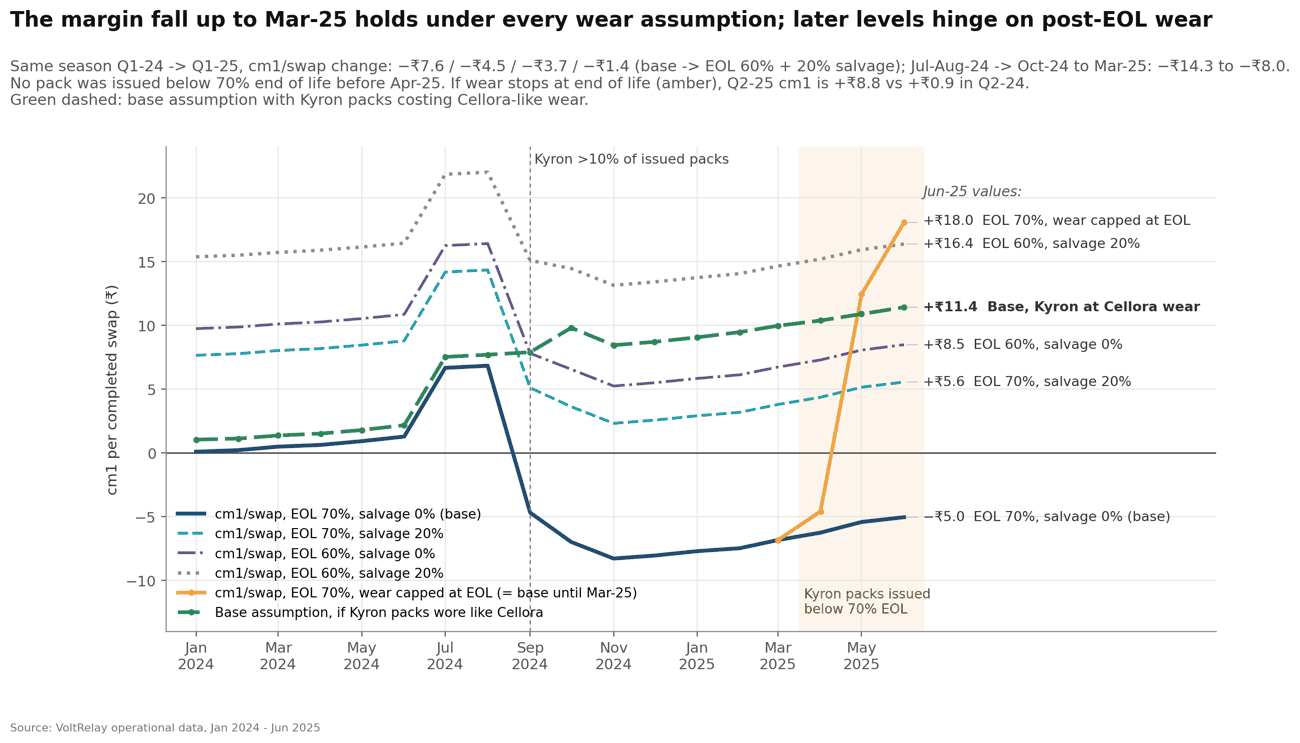

[fig] q1_07 saved


In [61]:
smp = sens_m.to_pandas()
smp["month"] = pd.to_datetime(smp["month"])
cfp = cf_m.to_pandas()
cfp["month"] = pd.to_datetime(cfp["month"])
fig, ax = plt.subplots(figsize=(13.5, 7.0))
ax.axhline(0, color="#444444", lw=1)
styles = [(PALETTE["primary"], "-", 2.8), (SERIES[5], "--", 2.0), (SERIES[4], "-.", 2.0), (PALETTE["muted"], ":", 2.4), (PALETTE["warn"], "-", 2.6)]
end_labels = []
for (lab, eol, salv, mode), (colr, ls, lw) in zip(SCN[:5], styles):      # the 'rep' variant is in the table only
    y = (smp.revenue - smp.energy_cost - smp[f"W|{lab}"]) / smp.completed
    if mode == "cap":   # identical to the base line until Mar-25, so draw it only where it differs
        keep = smp.month >= pd.Timestamp(2025, 3, 1)
        ax.plot(smp.month[keep], y[keep], color=colr, ls=ls, lw=lw, marker="o", ms=3.5, label=f"cm1/swap, {lab} (= base until Mar-25)")
    else:
        ax.plot(smp.month, y, color=colr, ls=ls, lw=lw, label=f"cm1/swap, {lab}")
    end_labels.append((float(y.iloc[-1]), f"{rs(y.iloc[-1])}  {lab}", False))
ax.plot(cfp.month, cfp.cm1_cf_ps, color=PALETTE["good"], lw=2.6, ls=(0, (6, 2)), marker="o", ms=3.5,
        label="Base assumption, if Kyron packs wore like Cellora")
end_labels.append((float(cfp.cm1_cf_ps.iloc[-1]), f"{rs(cfp.cm1_cf_ps.iloc[-1])}  Base, Kyron at Cellora wear", True))
# right-hand labels = Jun-25 values, spread vertically so they never overlap
end_labels.sort()
ypos = [end_labels[0][0]]
for yv, _, _ in end_labels[1:]:
    ypos.append(max(yv, ypos[-1] + 1.8))
x_end = smp.month.iloc[-1]
x_txt = mdates.date2num(x_end + pd.Timedelta(days=14))
for (yv, txt, bold), yp in zip(end_labels, ypos):
    ax.annotate(txt, (mdates.date2num(x_end), yv), xytext=(x_txt, yp), textcoords="data", va="center", fontsize=9.8, color="#333333",
                fontweight="bold" if bold else None, arrowprops=dict(arrowstyle="-", color="#BBBBBB", lw=0.6))
ax.text(x_txt, ypos[-1] + 2.3, "Jun-25 values:", fontsize=10, color="#555555", style="italic", va="center")
ax.axvline(pd.Timestamp(kyron_ramp), color="#777777", lw=0.9, ls=(0, (3, 3)))
y_top = max(24, ypos[-1] + 4)
ax.text(pd.Timestamp(kyron_ramp), y_top - 0.5, " Kyron >10% of issued packs", fontsize=9.8, color="#444444", va="top")
ax.axvspan(pd.Timestamp(2025, 3, 16), pd.Timestamp(2025, 6, 16), color=PALETTE["warn"], alpha=0.10, lw=0)
ax.text(pd.Timestamp(2025, 3, 20), -12.8, "Kyron packs issued\nbelow 70% EOL", fontsize=9.5, color="#7A5A00", va="bottom")
ax.set_xticks(pd.date_range("2024-01-01", "2025-06-01", freq="2MS"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_xlim(pd.Timestamp(2023, 12, 10), pd.Timestamp(2026, 1, 15))
ax.set_ylabel(f"cm1 per completed swap ({RS})")
ax.set_ylim(-14, y_top)
ax.legend(loc="lower left", fontsize=9.5)
bq, bj = sens_tab["chg Q1-24 -> Q1-25"], sens_tab["chg Jul-Aug-24 -> Oct-24..Mar-25"]
cap_lab = SCN[4][0]
title_block(fig, "The margin fall up to Mar-25 holds under every wear assumption; later levels hinge on post-EOL wear",
            "Same season Q1-24 -> Q1-25, cm1/swap change: " + " / ".join(rs(bq[s[0]]) for s in SCN[:4]) + " (base -> EOL 60% + 20% salvage); "
            f"Jul-Aug-24 -> Oct-24 to Mar-25: {rs(bj[SCN[0][0]])} to {rs(bj[SCN[3][0]])}.\n"
            f"No pack was issued below 70% end of life before Apr-25. If wear stops at end of life (amber), Q2-25 cm1 is "
            f"{rs(sens_tab.loc[cap_lab, 'Q2-25'])} vs {rs(sens_tab.loc[cap_lab, 'Q2-24'])} in Q2-24.\n"
            f"Green dashed: base assumption with Kyron packs costing Cellora-like wear.", top=0.8)
save_fig(fig, "q1_07_wear_sensitivity_and_kyron_counterfactual")
print("[fig] q1_07 saved")

## 8. Summary of key numbers (everything quoted in outputs/findings/q1.md is printed above or here)

In [62]:
h1a, h1b = P["H1-24"], P["H1-25"]
print("\n[summary] H1-24 -> H1-25 (same season):")
print(f"  attempts x{h1b['attempts'] / h1a['attempts']:.2f}, swaps x{h1b['completed'] / h1a['completed']:.2f}, failures x{h1b['failures'] / h1a['failures']:.2f}, "
      f"revenue x{h1b['revenue'] / h1a['revenue']:.2f}, active riders (monthly avg) x{h1b['active_riders'] / h1a['active_riders']:.2f}")
print(f"  revenue/swap {h1a['revenue_ps']:.2f} -> {h1b['revenue_ps']:.2f}; cm1/swap {h1a['cm1_ps']:.2f} -> {h1b['cm1_ps']:.2f}; "
      f"cm2/swap {h1a['cm2_ps']:.2f} -> {h1b['cm2_ps']:.2f}")
print(f"  cm1 total per month {h1a['cm1'] / 6 / 1e6:.2f}M -> {h1b['cm1'] / 6 / 1e6:.2f}M; cm2 total per month {h1a['cm2'] / 6 / 1e6:.2f}M -> {h1b['cm2'] / 6 / 1e6:.2f}M")
print(f"  failure rate {h1a['fail_rate'] * 100:.2f}% -> {h1b['fail_rate'] * 100:.2f}%")
print("[summary] Margin in windows with no pack issued below 70% EOL (the headline anchors):")
for p0, p1 in [("Q1-24", "Q1-25"), ("Jul-Aug-24", "Oct-24..Mar-25")]:
    r = BR[(p0, p1)]
    kyv = r["comp"]["Wear: Kyron share of packs"]
    print(f"  {p0} -> {p1}: cm1/swap {r['cm1_0']:+.2f} -> {r['cm1_1']:+.2f} ({r['cm1_1'] - r['cm1_0']:+.2f}); Kyron share effect {kyv:+.2f} Rs/swap "
          f"(~{kyv * r['N1'] / r['months1'] / 1e6:+.2f}M Rs/month); cm2/swap {r['cm2_0']:+.2f} -> {r['cm2_1']:+.2f}; "
          f"total cm2/month {P[p0]['cm2'] / P[p0]['n_months'] / 1e6:+.2f}M -> {P[p1]['cm2'] / P[p1]['n_months'] / 1e6:+.2f}M")
print(f"  H1-25 cm1/swap {P['H1-25']['cm1_ps']:+.2f} (per-cycle model) / {VL.loc['H1-25', 'cm1_rep']:+.2f} (post-EOL at Cellora wear) / "
      f"{VL.loc['H1-25', 'cm1_cap']:+.2f} (wear stops at EOL)")
print(f"[summary] runtime {time.time() - T0:.1f}s")


[summary] H1-24 -> H1-25 (same season):
  attempts x2.40, swaps x2.43, failures x2.07, revenue x2.63, active riders (monthly avg) x2.18
  revenue/swap 59.89 -> 64.77; cm1/swap 0.64 -> -6.39; cm2/swap -17.43 -> -17.87
  cm1 total per month 0.07M -> -1.81M; cm2 total per month -2.03M -> -5.07M
  failure rate 7.04% -> 6.06%
[summary] Margin in windows with no pack issued below 70% EOL (the headline anchors):
  Q1-24 -> Q1-25: cm1/swap +0.27 -> -7.32 (-7.59); Kyron share effect -16.04 Rs/swap (~-4.31M Rs/month); cm2/swap -19.25 -> -18.48; total cm2/month -2.08M -> -4.96M
  Jul-Aug-24 -> Oct-24..Mar-25: cm1/swap +6.75 -> -7.53 (-14.28); Kyron share effect -16.00 Rs/swap (~-3.99M Rs/month); cm2/swap -7.15 -> -19.16; total cm2/month -1.11M -> -4.78M
  H1-25 cm1/swap -6.39 (per-cycle model) / -1.13 (post-EOL at Cellora wear) / +1.19 (wear stops at EOL)
[summary] runtime 6.0s


In [63]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 139 objects


## 6. Q2 · Service failures & customer experience

# Q2 - Service failures and customer experience
**Question.** How do queue wait, failed attempts and abandoned swaps relate to station, hour of day, season and
vehicle class? Is service quality spread evenly across the network, or concentrated?

**Approach.**
1. Failure taxonomy and rates (2W vs 3W).
2. Queue-wait distributions (completed vs abandoned), a Kaplan-Meier "patience" curve for abandonment, and queue
   wait vs station utilisation.
3. Hour of day (firmware-corrected), day of week, month/season, plus an hour x month heatmap.
4. City x charger generation x season, and city-day weather (heat alerts, max temperature, grid outages, rain).
5. Concentration: Lorenz / Gini across stations and station-hours (against a chance-only null), excess failures on a
   fair (Apr-Jun) denominator, and an observed/expected test of whether the largest sites are unusual for their city.
6. Heat mechanism from hourly telemetry (ambient -> cabinet temperature -> charge time -> charged inventory), a
   station-day binomial GLM (city, month and weekday controls, station-clustered errors), and a trap check: does the
   hourly stock level predict WHICH hours fail once the day and the hour of day are held fixed? (It does not: the
   heat effect is a day-level association.)
7. 3W specifics; 8. like-for-like trend at a fixed set of stations; 9. support tickets vs failure rates;
10. sizing for recommendations, and what a rider does after a failure (retry or not).

**Definitions** (docs/analysis_brief.md): service failure = stockout (`failed_no_charged_battery`) + `abandoned_queue`
+ `failed_system_error`; `cancelled_by_rider` is reported but not counted as a failure. Hours are the corrected local
hour (firmware v3.2.0 bug fixed in `src/clean.py`). Telemetry blanks stay null; we report coverage.

In [64]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
from scipy import stats

try:
    ROOT = PROJECT_ROOT
except NameError:  # running inside a notebook
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401,F403

warnings.filterwarnings("ignore")
set_style()
T0 = time.time()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(24)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_float_precision(4)

HOT_MONTHS = [4, 5, 6]                       # Apr-Jun: the only months where failures depart from baseline
HOT_CITIES = ["Delhi NCR", "Jaipur", "Hyderabad"]
GEN_COLORS = {"Gen1": PALETTE["accent"], "Gen2": PALETTE["warn"], "Gen3": PALETTE["good"]}
FAIL = pl.col("is_service_failure")


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def wilson(k, n, z=1.96):
    """Wilson score interval for a binomial proportion (vectorised)."""
    k = np.asarray(k, float)
    n = np.asarray(n, float)
    p = k / n
    den = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return p, centre - half, centre + half


def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    cum = np.cumsum(x)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n


def top_share(x, frac):
    x = np.sort(np.asarray(x, float))[::-1]
    k = int(np.ceil(frac * len(x)))
    return x[:k].sum() / x.sum()


def conc_curve(x):
    """Concentration curve: units sorted from worst to best -> (cum share of units, cum share of x)."""
    x = np.sort(np.asarray(x, float))[::-1]
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]


def mh_rr(df: pd.DataFrame, a, n1, c, n0):
    """Mantel-Haenszel risk ratio across strata with Greenland-Robins 95% CI.
    a/n1 = events/total in the exposed group, c/n0 = events/total in the reference group (one row per stratum)."""
    d = df.loc[(df[n1] > 0) & (df[n0] > 0), [a, n1, c, n0]].astype("float64")  # float: avoid uint overflow
    N = d[n1] + d[n0]
    R = (d[a] * d[n0] / N).sum()
    S = (d[c] * d[n1] / N).sum()
    P = ((d[n1] * d[n0] * (d[a] + d[c]) - d[a] * d[c] * N) / N ** 2).sum()
    rr = R / S
    se = np.sqrt(P / (R * S))
    return rr, rr * np.exp(-1.96 * se), rr * np.exp(1.96 * se), len(d)


def headline(fig, title, subtitle=None, top=0.84):
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=15, fontweight="bold", color="#1a1a1a")
    if subtitle:
        fig.text(0.01, 0.995 - (1 - top) * 0.55, subtitle, ha="left", va="top", fontsize=11, color="#555555")


def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))


def ptable(name, df, n=None):
    print(f"\n--- {name} ---")
    print(df if n is None else df.head(n))

## 1. Failure taxonomy
Every attempt ends as one of five outcomes. Stockouts and abandonments dominate the failures; system errors are a
small, flat noise floor.

In [65]:
EV_COLS = ["station_id", "event_ts", "event_ts_raw", "ts_corrected", "date", "month", "hour", "dow", "event_type",
           "is_completed", "is_stockout", "is_abandoned", "is_system_error", "is_cancelled", "is_service_failure",
           "queue_wait_sec", "vehicle_class", "city", "charger_generation", "expansion_wave", "connectivity_tier",
           "station_firmware", "sync_mode"]
ev = events(EV_COLS)
st_all = stations().filter(~pl.col("is_test"))

tax = ev.group_by("event_type", "vehicle_class").agg(pl.len().alias("n")).collect()
tax_w = (tax.pivot(on="vehicle_class", index="event_type", values="n")
         .with_columns((pl.col("2W") + pl.col("3W")).alias("all")))
tot = {c: int(tax_w[c].sum()) for c in ["2W", "3W", "all"]}
tax_w = (tax_w.with_columns(
    (pl.col("all") / tot["all"]).alias("rate_all"), (pl.col("2W") / tot["2W"]).alias("rate_2W"),
    (pl.col("3W") / tot["3W"]).alias("rate_3W"), pl.col("event_type").is_in(FAIL_TYPES).alias("service_failure"))
    .sort("all", descending=True))
fails = tax_w.filter("service_failure")
N_ATT, N_FAIL = tot["all"], int(fails["all"].sum())
FR_ALL = N_FAIL / N_ATT
FR_2W = fails["2W"].sum() / tot["2W"]
FR_3W = fails["3W"].sum() / tot["3W"]
tax_w.write_csv(TAB / "q2_taxonomy.csv")
ptable("Outcome taxonomy (counts and rates by vehicle class)", tax_w)
print(f"[TAX] attempts={N_ATT:,}  service failures={N_FAIL:,}  failure rate={pct(FR_ALL, 2)}  "
      f"(2W {pct(FR_2W, 2)} of {tot['2W']:,}; 3W {pct(FR_3W, 2)} of {tot['3W']:,})")
for r in fails.iter_rows(named=True):
    print(f"[TAX] {r['event_type']}: {r['all']:,} = {pct(r['rate_all'], 2)} of attempts, "
          f"{pct(r['all'] / N_FAIL, 1)} of service failures")
for dim in ["connectivity_tier", "station_firmware", "sync_mode"]:
    se_d = ev.group_by(dim).agg(pl.len().alias("n"), pl.col("is_system_error").mean().alias("r")).sort(dim).collect()
    print(f"[TAX] system-error rate by {dim}: " + ", ".join(f"{r[dim]} {pct(r['r'], 3)} (n={r['n']:,})" for r in se_d.iter_rows(named=True)))
canc = tax_w.filter(pl.col("event_type") == "cancelled_by_rider").row(0, named=True)
print(f"[TAX] cancelled_by_rider (not a service failure): {canc['all']:,} = {pct(canc['rate_all'], 2)}")


--- Outcome taxonomy (counts and rates by vehicle class) ---
shape: (5, 8)
┌───────────────────────────┬─────────┬────────┬─────────┬──────────┬─────────┬─────────┬─────────────────┐
│ event_type                ┆ 2W      ┆ 3W     ┆ all     ┆ rate_all ┆ rate_2W ┆ rate_3W ┆ service_failure │
│ ---                       ┆ ---     ┆ ---    ┆ ---     ┆ ---      ┆ ---     ┆ ---     ┆ ---             │
│ str                       ┆ u32     ┆ u32    ┆ u32     ┆ f64      ┆ f64     ┆ f64     ┆ bool            │
╞═══════════════════════════╪═════════╪════════╪═════════╪══════════╪═════════╪═════════╪═════════════════╡
│ swap_completed            ┆ 3214411 ┆ 372264 ┆ 3586675 ┆ 0.9402   ┆ 0.9455  ┆ 0.8961  ┆ false           │
│ failed_no_charged_battery ┆ 106121  ┆ 26665  ┆ 132786  ┆ 0.0348   ┆ 0.0312  ┆ 0.0642  ┆ true            │
│ abandoned_queue           ┆ 54243   ┆ 13420  ┆ 67663   ┆ 0.0177   ┆ 0.0160  ┆ 0.0323  ┆ true            │
│ cancelled_by_rider        ┆ 14661   ┆ 1797   ┆ 16458   ┆ 0

## 2. Queue wait: completed vs abandoned, rider patience, and load
`queue_wait_sec` = arrival to completion (completed) or to exit (abandoned). Stockouts / system errors exit within
90 s. We estimate rider **patience** with Kaplan-Meier: abandonment is the event, completion censors the wait
(assumes service time is independent of patience).

In [66]:
qq = (ev.group_by("event_type").agg(
    pl.len().alias("n"), pl.col("queue_wait_sec").mean().alias("mean_s"),
    *[pl.col("queue_wait_sec").quantile(q).alias(f"p{int(q * 100)}_s") for q in (0.1, 0.25, 0.5, 0.75, 0.9, 0.99)],
    pl.col("queue_wait_sec").min().alias("min_s"), pl.col("queue_wait_sec").max().alias("max_s"))
    .sort("n", descending=True).collect())
qq.write_csv(TAB / "q2_queue_wait_quantiles.csv")
ptable("Queue wait (seconds) by outcome", qq)
qc = qq.filter(pl.col("event_type") == "swap_completed").row(0, named=True)
qa = qq.filter(pl.col("event_type") == "abandoned_queue").row(0, named=True)
print(f"[QW] completed: median {qc['p50_s'] / 60:.1f} min, mean {qc['mean_s'] / 60:.2f} min, p90 {qc['p90_s'] / 60:.1f} min,"
      f" max {qc['max_s'] / 60:.0f} min")
print(f"[QW] abandoned: median {qa['p50_s'] / 60:.1f} min, p10 {qa['p10_s'] / 60:.1f} min, min {qa['min_s'] / 60:.2f} min,"
      f" max {qa['max_s'] / 60:.0f} min; median ratio abandoned/completed = {qa['p50_s'] / qc['p50_s']:.1f}x")

# Kaplan-Meier patience curve
qd = (ev.filter(pl.col("event_type").is_in(["swap_completed", "abandoned_queue"]))
      .group_by("queue_wait_sec").agg(pl.col("is_abandoned").sum().alias("ab"), pl.col("is_completed").sum().alias("comp"))
      .sort("queue_wait_sec").collect())
t_s = qd["queue_wait_sec"].to_numpy().astype(float)
d_ab = qd["ab"].to_numpy().astype(float)
d_cp = qd["comp"].to_numpy().astype(float)
at_risk = (d_ab + d_cp).sum() - np.r_[0, np.cumsum(d_ab + d_cp)[:-1]]
S_km = np.cumprod(1 - d_ab / at_risk)
km_med = t_s[np.argmax(S_km <= 0.5)] / 60 if (S_km <= 0.5).any() else np.nan
share_ab_beyond_p90 = d_ab[t_s > qc["p90_s"]].sum() / d_ab.sum()


def S_at(minutes):
    idx = np.searchsorted(t_s, minutes * 60, side="right") - 1
    return S_km[max(idx, 0)]


minute = (t_s // 60).astype(int)
pc = (pd.DataFrame({"minute": minute, "ab": d_ab, "comp": d_cp}).groupby("minute", as_index=False).sum())
pc["at_risk_start"] = (pc["ab"] + pc["comp"]).sum() - np.r_[0, np.cumsum(pc["ab"] + pc["comp"])[:-1]]
pc["hazard_per_min"] = pc["ab"] / pc["at_risk_start"]
pc["share_abandoned_among_ended"] = pc["ab"] / (pc["ab"] + pc["comp"])
pc["km_still_waiting"] = [S_at(m + 1) for m in pc["minute"]]
pc.to_csv(TAB / "q2_patience_curve.csv", index=False)
cross50 = pc.loc[(pc["share_abandoned_among_ended"] >= 0.5) & (pc["ab"] + pc["comp"] >= 500), "minute"].min()
print(f"[QW] Kaplan-Meier patience: still willing to wait at 5 min {pct(S_at(5))}, 10 min {pct(S_at(10))}, "
      f"15 min {pct(S_at(15))}, 20 min {pct(S_at(20))}; median patience = {km_med:.1f} min")
for m in (5, 8, 10, 12, 15):
    r = pc.loc[pc["minute"] == m].iloc[0]
    print(f"[QW] hazard of abandoning during minute {m}-{m + 1}: {pct(r['hazard_per_min'])} "
          f"(at risk {int(r['at_risk_start']):,})")
print(f"[QW] first minute where abandonments outnumber completions among attempts ending then: {cross50} min")
print(f"[QW] {pct(share_ab_beyond_p90)} of abandoners had waited longer than the completed-swap p90 "
      f"({qc['p90_s'] / 60:.1f} min)")


--- Queue wait (seconds) by outcome ---
shape: (5, 11)
┌───────────────────────────┬─────────┬──────────┬──────────┬──────────┬──────────┬──────────┬───────────┬───────────┬───────┬───────┐
│ event_type                ┆ n       ┆ mean_s   ┆ p10_s    ┆ p25_s    ┆ p50_s    ┆ p75_s    ┆ p90_s     ┆ p99_s     ┆ min_s ┆ max_s │
│ ---                       ┆ ---     ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---       ┆ ---       ┆ ---   ┆ ---   │
│ str                       ┆ u32     ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64       ┆ f64       ┆ i32   ┆ i32   │
╞═══════════════════════════╪═════════╪══════════╪══════════╪══════════╪══════════╪══════════╪═══════════╪═══════════╪═══════╪═══════╡
│ swap_completed            ┆ 3586675 ┆ 243.7180 ┆ 103.0000 ┆ 144.0000 ┆ 209.0000 ┆ 304.0000 ┆ 424.0000  ┆ 754.0000  ┆ 20    ┆ 1800  │
│ failed_no_charged_battery ┆ 132786  ┆ 29.4963  ┆ 6.0000   ┆ 15.0000  ┆ 30.0000  ┆ 44.0000  ┆ 53.0000   ┆ 59.0000   ┆ 0     ┆ 59    │

In [67]:
# Station-hour aggregate (used for load, telemetry and concentration analyses)
SH = (ev.with_columns(pl.col("event_ts").dt.truncate("1h").alias("hour_start"))
      .group_by("station_id", "hour_start").agg(
          pl.len().cast(pl.Int32).alias("att"), pl.col("is_completed").sum().cast(pl.Int32).alias("comp"),
          FAIL.sum().cast(pl.Int32).alias("fail"), pl.col("is_stockout").sum().cast(pl.Int32).alias("so"),
          pl.col("is_abandoned").sum().cast(pl.Int32).alias("ab"), pl.col("is_system_error").sum().cast(pl.Int32).alias("se"),
          (pl.col("vehicle_class") == "3W").sum().cast(pl.Int32).alias("att3"),
          ((pl.col("vehicle_class") == "3W") & pl.col("is_stockout")).sum().cast(pl.Int32).alias("so3"),
          ((pl.col("vehicle_class") == "3W") & pl.col("is_abandoned")).sum().cast(pl.Int32).alias("ab3"),
          pl.col("queue_wait_sec").filter(pl.col("is_completed")).cast(pl.Int64).sum().alias("qws"),
          pl.col("queue_wait_sec").filter(pl.col("is_completed")).cast(pl.Float64).pow(2).sum().alias("qws2"))
      .collect(engine="streaming").sort("station_id", "hour_start"))  # sorted: makes the seeded null simulation reproducible
slots = st_all.select("station_id", "slots_2w", "slots_3w", (pl.col("slots_2w") + pl.col("slots_3w")).alias("slots"))
SH = SH.join(slots.select("station_id", "slots"), on="station_id", how="left").with_columns(
    (pl.col("comp") / pl.col("slots")).alias("util"), (pl.col("att") / pl.col("slots")).alias("demand_util"))
print(f"[LOAD] station-hours with >=1 attempt: {SH.height:,}")

util_edges = [0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 99]
util_lbl = ["<0.1", "0.1-0.2", "0.2-0.3", "0.3-0.5", "0.5-0.75", "0.75-1.0", "1.0-1.5", ">=1.5"]
qu = (SH.filter(pl.col("comp") > 0)
      .with_columns(pl.col("util").cut(util_edges[1:-1], labels=util_lbl, left_closed=True).alias("util_bin"))
      .group_by("util_bin").agg(pl.len().alias("station_hours"), pl.col("comp").sum(), pl.col("att").sum(),
                                (pl.col("qws").sum() / pl.col("comp").sum() / 60).alias("mean_wait_min"),
                                pl.col("qws2").sum().alias("ss"),
                                (pl.col("ab").sum() / pl.col("att").sum()).alias("abandon_rate"))
      .with_columns(((pl.col("ss") / pl.col("comp") - (pl.col("mean_wait_min") * 60) ** 2) / pl.col("comp")).sqrt().alias("se_s"))
      .with_columns((pl.col("mean_wait_min") - 1.96 * pl.col("se_s") / 60).alias("ci_lo_min"),
                    (pl.col("mean_wait_min") + 1.96 * pl.col("se_s") / 60).alias("ci_hi_min"))
      .drop("ss", "se_s").sort("util_bin"))
du = (SH.with_columns(pl.col("demand_util").cut(util_edges[1:-1], labels=util_lbl, left_closed=True).alias("demand_bin"))
      .group_by("demand_bin").agg(pl.len().alias("station_hours"), pl.col("att").sum(),
                                  (pl.col("ab").sum() / pl.col("att").sum()).alias("abandon_rate"),
                                  (pl.col("so").sum() / pl.col("att").sum()).alias("stockout_rate"))
      .sort("demand_bin"))
qu.write_csv(TAB / "q2_queue_vs_utilisation.csv")
du.write_csv(TAB / "q2_abandon_vs_demand_per_slot.csv")
ptable("Queue wait vs utilisation (completed swaps per slot-hour)", qu)
ptable("Abandonment / stockouts vs demand (attempts per slot-hour)", du)
q_lo, q_hi = qu.row(0, named=True), qu.row(qu.height - 1, named=True)
st_wait = (ev.filter("is_completed").group_by("station_id").agg(pl.col("queue_wait_sec").mean().alias("m")).collect())["m"]
mo_wait = (ev.filter("is_completed").group_by("month").agg(pl.col("queue_wait_sec").mean().alias("m")).collect())["m"]
print(f"[LOAD] mean completed wait by utilisation bin ranges {qu['mean_wait_min'].min():.2f}-{qu['mean_wait_min'].max():.2f} min; "
      f"lightest bin ({q_lo['util_bin']}) {q_lo['mean_wait_min'] * 60:.1f} s (95% CI {q_lo['ci_lo_min'] * 60:.1f}-{q_lo['ci_hi_min'] * 60:.1f}) vs "
      f"busiest bin ({q_hi['util_bin']}) {q_hi['mean_wait_min'] * 60:.1f} s (95% CI {q_hi['ci_lo_min'] * 60:.1f}-{q_hi['ci_hi_min'] * 60:.1f})")
print(f"[LOAD] station mean completed wait ranges {st_wait.min():.0f}-{st_wait.max():.0f} s across {len(st_wait)} stations;"
      f" monthly network mean {mo_wait.min():.0f}-{mo_wait.max():.0f} s")
d_lo, d_hi = du.row(0, named=True), du.row(du.height - 1, named=True)
print(f"[LOAD] demand per slot-hour {d_lo['demand_bin']} -> {d_hi['demand_bin']}: abandonment {pct(d_lo['abandon_rate'], 2)} -> "
      f"{pct(d_hi['abandon_rate'], 2)}, stockouts {pct(d_lo['stockout_rate'], 2)} -> {pct(d_hi['stockout_rate'], 2)}")

[LOAD] station-hours with >=1 attempt: 1,033,134

--- Queue wait vs utilisation (completed swaps per slot-hour) ---
shape: (8, 8)
┌──────────┬───────────────┬────────┬────────┬───────────────┬──────────────┬───────────┬───────────┐
│ util_bin ┆ station_hours ┆ comp   ┆ att    ┆ mean_wait_min ┆ abandon_rate ┆ ci_lo_min ┆ ci_hi_min │
│ ---      ┆ ---           ┆ ---    ┆ ---    ┆ ---           ┆ ---          ┆ ---       ┆ ---       │
│ enum     ┆ u32           ┆ i32    ┆ i32    ┆ f64           ┆ f64          ┆ f64       ┆ f64       │
╞══════════╪═══════════════╪════════╪════════╪═══════════════╪══════════════╪═══════════╪═══════════╡
│ <0.1     ┆ 270956        ┆ 289367 ┆ 313401 ┆ 4.0658        ┆ 0.0229       ┆ 4.0571    ┆ 4.0746    │
│ 0.1-0.2  ┆ 288201        ┆ 634165 ┆ 677117 ┆ 4.0681        ┆ 0.0188       ┆ 4.0621    ┆ 4.0740    │
│ 0.2-0.3  ┆ 146094        ┆ 520524 ┆ 552138 ┆ 4.0573        ┆ 0.0170       ┆ 4.0507    ┆ 4.0638    │
│ 0.3-0.5  ┆ 155540        ┆ 838819 ┆ 886257 ┆ 4.0587 

## 3. When do failures happen? Hour, weekday, month, season
Hours use the corrected timestamp. We also show what the uncorrected firmware clock would have done to the hour
profile of the affected events.

In [68]:
def rates(df_lazy, keys):
    return (df_lazy.group_by(keys).agg(
        pl.len().alias("attempts"), FAIL.sum().alias("failures"), FAIL.mean().alias("failure_rate"),
        pl.col("is_stockout").mean().alias("stockout_rate"), pl.col("is_abandoned").mean().alias("abandon_rate"),
        pl.col("is_system_error").mean().alias("system_error_rate"), pl.col("is_cancelled").mean().alias("cancel_rate"))
        .sort(keys).collect())


by_hour = rates(ev, ["hour"]).with_columns((pl.col("attempts") / N_ATT).alias("share_attempts"),
                                           (pl.col("failures") / N_FAIL).alias("share_failures"))
by_dow = rates(ev, ["dow"])
by_month = rates(ev, ["month"])
by_hour.write_csv(TAB / "q2_by_hour.csv")
by_dow.write_csv(TAB / "q2_by_dow.csv")
by_month.write_csv(TAB / "q2_by_month.csv")
ptable("By hour (corrected)", by_hour)
ptable("By day of week (1=Mon)", by_dow)
ptable("By month", by_month)
EVE = [19, 20, 21, 22]
eve = by_hour.filter(pl.col("hour").is_in(EVE))
oth = by_hour.filter(~pl.col("hour").is_in(EVE))
print(f"[HOUR] evening peak 19:00-22:59: {pct(eve['share_attempts'].sum())} of attempts, {pct(eve['share_failures'].sum())} of"
      f" failures; failure rate {pct(eve['failures'].sum() / eve['attempts'].sum(), 2)} vs {pct(oth['failures'].sum() / oth['attempts'].sum(), 2)}"
      f" in other hours")
pk = by_hour.filter(pl.col("hour").is_between(12, 22))
print(f"[HOUR] pilot PEAK window 12:00-22:59: {pct(pk['share_attempts'].sum())} of attempts, {pct(pk['share_failures'].sum())} of failures")
by_dow_jm = rates(ev.filter(~pl.col("month").dt.month().is_in(HOT_MONTHS)), ["dow"])
by_dow.join(by_dow_jm.select("dow", pl.col("failure_rate").alias("failure_rate_jul_mar")), on="dow").write_csv(TAB / "q2_by_dow.csv")
print(f"[DOW] failure rate range across weekdays: full period (Jan-24 to Jun-25) {pct(by_dow['failure_rate'].min(), 2)}-"
      f"{pct(by_dow['failure_rate'].max(), 2)}; Jul-Mar only {pct(by_dow_jm['failure_rate'].min(), 2)}-{pct(by_dow_jm['failure_rate'].max(), 2)}")
bm = by_month.with_columns(pl.col("month").dt.month().alias("m"), pl.col("month").dt.year().alias("y"))
base_mo = bm.filter(~pl.col("m").is_in(HOT_MONTHS))
BASE_FR = base_mo["failures"].sum() / base_mo["attempts"].sum()
print(f"[MONTH] Jul-Mar baseline failure rate {pct(BASE_FR, 2)} (monthly range {pct(base_mo['failure_rate'].min(), 2)}-"
      f"{pct(base_mo['failure_rate'].max(), 2)}); Apr-Jun months: " +
      ", ".join(f"{r['month']:%b-%y} {pct(r['failure_rate'], 1)}" for r in bm.filter(pl.col("m").is_in(HOT_MONTHS)).iter_rows(named=True)))
hot_ev = bm.filter(pl.col("m").is_in(HOT_MONTHS))
print(f"[MONTH] Apr-Jun = {pct(hot_ev['attempts'].sum() / N_ATT)} of attempts but {pct(hot_ev['failures'].sum() / N_FAIL)} of failures")

# firmware-clock check on the shifted events
fw = (ev.filter("ts_corrected").select(pl.col("hour"), pl.col("event_ts_raw").dt.hour().alias("hour_raw"), FAIL).collect())
print(f"[FW] {fw.height:,} events had the +5h30m correction; share in 19:00-22:59 corrected = "
      f"{pct(fw['hour'].is_in(EVE).mean())} vs raw clock = {pct(fw['hour_raw'].is_in(EVE).mean())}; "
      f"their failures placed in 19-22h: corrected {pct(fw.filter('is_service_failure')['hour'].is_in(EVE).mean())}"
      f" vs raw {pct(fw.filter('is_service_failure')['hour_raw'].is_in(EVE).mean())}")
del fw

# hour x month matrices
hm = rates(ev, ["month", "hour"])
months = sorted(hm["month"].unique().to_list())
M_fail = hm.pivot(on="month", index="hour", values="failure_rate").sort("hour")
M_so = hm.pivot(on="month", index="hour", values="stockout_rate").sort("hour")
M_fail.write_csv(TAB / "q2_hour_month_failure_rate.csv")
M_so.write_csv(TAB / "q2_hour_month_stockout_rate.csv")
A_fail = M_fail.select([str(m) for m in months]).to_numpy()
A_so = M_so.select([str(m) for m in months]).to_numpy()
imax = np.unravel_index(np.nanargmax(A_fail), A_fail.shape)
print(f"[HEAT] worst hour x month cell: {months[imax[1]]:%b-%y} {imax[0]:02d}:00 failure rate {pct(A_fail[imax])}; "
      f"best cell {pct(np.nanmin(A_fail))}")
may_eve = hm.filter(pl.col("month").dt.month() == 5, pl.col("hour").is_in(EVE))
may_oth = hm.filter(pl.col("month").dt.month() == 5, ~pl.col("hour").is_in(EVE))
print(f"[HEAT] May (both years) failure rate 19-22h {pct(may_eve['failures'].sum() / may_eve['attempts'].sum())} vs other hours "
      f"{pct(may_oth['failures'].sum() / may_oth['attempts'].sum())}")
cool_eve = hm.filter(~pl.col("month").dt.month().is_in(HOT_MONTHS), pl.col("hour").is_in(EVE))
cool_oth = hm.filter(~pl.col("month").dt.month().is_in(HOT_MONTHS), ~pl.col("hour").is_in(EVE))
print(f"[HEAT] Jul-Mar failure rate 19-22h {pct(cool_eve['failures'].sum() / cool_eve['attempts'].sum(), 2)} vs other hours "
      f"{pct(cool_oth['failures'].sum() / cool_oth['attempts'].sum(), 2)}")
ecomp = (ev.filter(~pl.col("month").dt.month().is_in(HOT_MONTHS))
         .with_columns(pl.col("hour").is_in(EVE).alias("eve"))
         .group_by("eve").agg((pl.col("vehicle_class") == "3W").mean().alias("share_3w"),
                              FAIL.filter(pl.col("vehicle_class") == "2W").mean().alias("fr_2w"),
                              FAIL.filter(pl.col("vehicle_class") == "3W").mean().alias("fr_3w")).sort("eve").collect())
e_t, e_f = ecomp.filter(pl.col("eve")).row(0, named=True), ecomp.filter(~pl.col("eve")).row(0, named=True)
print(f"[HEAT] Jul-Mar composition check: 3W share of attempts 19-22h {pct(e_t['share_3w'])} vs {pct(e_f['share_3w'])} other hours; "
      f"within class: 2W {pct(e_t['fr_2w'], 2)} vs {pct(e_f['fr_2w'], 2)}, 3W {pct(e_t['fr_3w'], 2)} vs {pct(e_f['fr_3w'], 2)}")


--- By hour (corrected) ---
shape: (24, 10)
┌──────┬──────────┬──────────┬──────────────┬───────────────┬──────────────┬───────────────────┬─────────────┬────────────────┬────────────────┐
│ hour ┆ attempts ┆ failures ┆ failure_rate ┆ stockout_rate ┆ abandon_rate ┆ system_error_rate ┆ cancel_rate ┆ share_attempts ┆ share_failures │
│ ---  ┆ ---      ┆ ---      ┆ ---          ┆ ---           ┆ ---          ┆ ---               ┆ ---         ┆ ---            ┆ ---            │
│ i8   ┆ u32      ┆ u32      ┆ f64          ┆ f64           ┆ f64          ┆ f64               ┆ f64         ┆ f64            ┆ f64            │
╞══════╪══════════╪══════════╪══════════════╪═══════════════╪══════════════╪═══════════════════╪═════════════╪════════════════╪════════════════╡
│ 0    ┆ 22010    ┆ 1139     ┆ 0.0517       ┆ 0.0323        ┆ 0.0164       ┆ 0.0031            ┆ 0.0041      ┆ 0.0058         ┆ 0.0054         │
│ 1    ┆ 21786    ┆ 1122     ┆ 0.0515       ┆ 0.0316        ┆ 0.0171       ┆ 0.0028  

[HOUR] evening peak 19:00-22:59: 38.2% of attempts, 42.4% of failures; failure rate 6.17% vs 5.17% in other hours
[HOUR] pilot PEAK window 12:00-22:59: 76.3% of attempts, 77.7% of failures
[DOW] failure rate range across weekdays: full period (Jan-24 to Jun-25) 5.48%-5.62%; Jul-Mar only 3.89%-3.93%
[MONTH] Jul-Mar baseline failure rate 3.91% (monthly range 3.82%-4.01%); Apr-Jun months: Apr-24 6.5%, May-24 11.9%, Jun-24 9.9%, Apr-25 5.9%, May-25 9.5%, Jun-25 8.2%
[MONTH] Apr-Jun = 36.6% of attempts but 55.4% of failures
[FW] 139,490 events had the +5h30m correction; share in 19:00-22:59 corrected = 38.0% vs raw clock = 2.3%; their failures placed in 19-22h: corrected 41.0% vs raw 2.2%
[HEAT] worst hour x month cell: May-24 19:00 failure rate 16.0%; best cell 2.8%
[HEAT] May (both years) failure rate 19-22h 13.2% vs other hours 8.4%
[HEAT] Jul-Mar failure rate 19-22h 3.69% vs other hours 4.05%
[HEAT] Jul-Mar composition check: 3W share of attempts 19-22h 6.6% vs 13.4% other hours; within

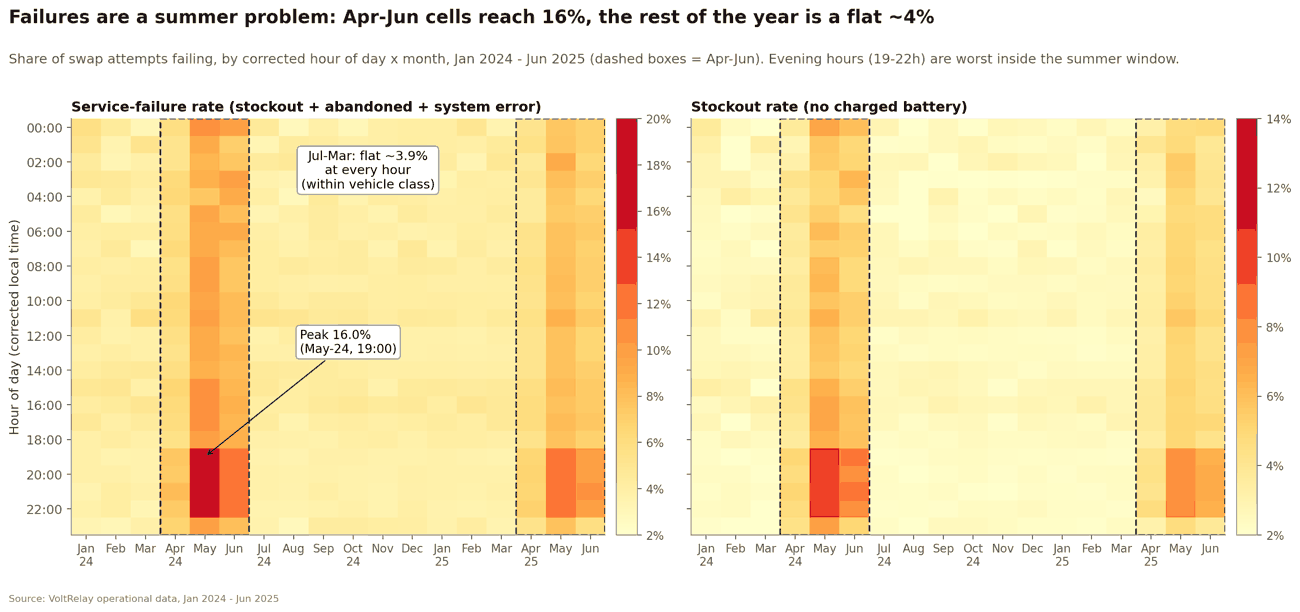

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_02_hour_month_heatmap.png')

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.6), sharey=True)
mlabels = [f"{m:%b}\n{m:%y}" if m.month in (1, 4, 7, 10) else f"{m:%b}" for m in months]
for ax, A, ttl, vmax in [(axes[0], A_fail, "Service-failure rate (stockout + abandoned + system error)", 0.20),
                         (axes[1], A_so, "Stockout rate (no charged battery)", 0.14)]:
    im = ax.imshow(A, aspect="auto", cmap="YlOrRd", vmin=0.02, vmax=vmax, origin="upper")
    ax.set_xticks(range(len(months)))
    ax.set_xticklabels(mlabels, fontsize=9.5)
    ax.set_yticks(range(0, 24, 2))
    ax.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
    ax.set_title(ttl, fontsize=11.5)
    ax.grid(False)
    for x in (3, 15):
        ax.add_patch(plt.Rectangle((x - 0.5, -0.5), 3, 24, fill=False, ec="#333333", lw=1.4, ls="--"))
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, format=mtick.PercentFormatter(1.0, decimals=0))
    cb.set_ticks(np.arange(0.02, vmax + 1e-9, 0.02))
    cb.ax.tick_params(labelsize=9.5)
axes[0].set_ylabel("Hour of day (corrected local time)")
axes[0].annotate(f"Peak {pct(A_fail[imax])}\n({months[imax[1]]:%b-%y}, {imax[0]:02d}:00)", xy=(imax[1], imax[0]),
                 xytext=(imax[1] + 3.2, imax[0] - 6), fontsize=10, arrowprops=dict(arrowstyle="->", color="#222222"),
                 bbox=dict(boxstyle="round", fc="white", ec="#999999"))
axes[0].text(9.5, 3.5, f"Jul-Mar: flat ~{pct(BASE_FR, 1)}\nat every hour\n(within vehicle class)", ha="center", fontsize=10.5,
             bbox=dict(boxstyle="round", fc="white", ec="#999999"))
headline(fig, f"Failures are a summer problem: Apr-Jun cells reach {pct(A_fail[imax], 0)}, the rest of the year is a flat ~{pct(BASE_FR, 0)}",
         "Share of swap attempts failing, by corrected hour of day x month, Jan 2024 - Jun 2025 (dashed boxes = Apr-Jun). "
         "Evening hours (19-22h) are worst inside the summer window.", top=0.86)
save_fig(fig, "q2_02_hour_month_heatmap")

## 4. Where: city x charger generation x season, and city-day weather
Outside Apr-Jun every city and every charger generation sits at the same ~3.9%. The summer excess appears only in
hot cities and scales with charger generation. Gen comparisons are made inside the same city and month (Mantel-
Haenszel), because Gen3 stations exist mainly in 2025.

In [70]:
cm = rates(ev, ["city", "month"])
cm.pivot(on="city", index="month", values="failure_rate").sort("month").write_csv(TAB / "q2_city_month_failure_rate.csv")
ev_s = ev.with_columns(pl.when(pl.col("month").dt.month().is_in(HOT_MONTHS)).then(pl.lit("Apr-Jun"))
                       .otherwise(pl.lit("Jul-Mar")).alias("season_grp"))
cgs = rates(ev_s, ["season_grp", "city", "charger_generation"])
p_, lo_, hi_ = wilson(cgs["failures"].to_numpy(), cgs["attempts"].to_numpy())
cgs = cgs.with_columns(pl.Series("ci_lo", lo_), pl.Series("ci_hi", hi_))
cgs.write_csv(TAB / "q2_city_generation_season.csv")
ptable("Failure rate by season group x city x generation", cgs.select("season_grp", "city", "charger_generation", "attempts",
                                                                    "failure_rate", "ci_lo", "ci_hi"))
cs = rates(ev_s, ["season_grp", "city"]).pivot(on="season_grp", index="city", values="failure_rate").sort("Apr-Jun", descending=True)
ptable("Failure rate by city: Apr-Jun vs Jul-Mar", cs)
cool_cg = cgs.filter(pl.col("season_grp") == "Jul-Mar")
print(f"[CITY] Jul-Mar failure rate across all 18 city x generation cells: {pct(cool_cg['failure_rate'].min(), 2)}-"
      f"{pct(cool_cg['failure_rate'].max(), 2)}")

# Gen comparison within city x month strata (Apr-Jun 2025: all generations present)
gm = (ev.filter(pl.col("month") >= pl.date(2025, 4, 1))
      .group_by("city", "month", "charger_generation").agg(pl.len().alias("n"), FAIL.sum().alias("f")).collect().to_pandas())
gw = gm.pivot_table(index=["city", "month"], columns="charger_generation", values=["n", "f"], aggfunc="sum").fillna(0)
gw.columns = [f"{a}_{b}" for a, b in gw.columns]
gen_rr = {}
for g in ["Gen1", "Gen2"]:
    gen_rr[g] = mh_rr(gw.reset_index(), f"f_{g}", f"n_{g}", "f_Gen3", "n_Gen3")
    print(f"[GEN] Apr-Jun 2025, same city & month: {g} vs Gen3 failure risk ratio (MH) = {gen_rr[g][0]:.2f} "
          f"(95% CI {gen_rr[g][1]:.2f}-{gen_rr[g][2]:.2f}; {gen_rr[g][3]} city-month strata)")
# Is it the wave (site choice) or the charger? Compare waves inside the same generation, city and month
wv = (ev.group_by("city", "month", "expansion_wave", "charger_generation").agg(pl.len().alias("n"), FAIL.sum().alias("f"))
      .collect().to_pandas())
wave_rr = {}
for g, exp_w, ref_w in [("Gen2", "Wave1_2024H2", "Launch"), ("Gen3", "Wave2_2025H1", "Wave1_2024H2")]:
    s = wv[wv["charger_generation"] == g].pivot_table(index=["city", "month"], columns="expansion_wave", values=["n", "f"],
                                                      aggfunc="sum").fillna(0)
    s.columns = [f"{a}_{b}" for a, b in s.columns]
    wave_rr[(g, exp_w)] = mh_rr(s.reset_index(), f"f_{exp_w}", f"n_{exp_w}", f"f_{ref_w}", f"n_{ref_w}")
    r = wave_rr[(g, exp_w)]
    print(f"[WAVE] {g} only, same city & month: {exp_w} vs {ref_w} failure risk ratio (MH) = {r[0]:.2f} (95% CI {r[1]:.2f}-{r[2]:.2f};"
          f" {r[3]} strata)")
# Effect modification: the pooled Gen1 vs Gen3 ratio mixes hot and cool cities (heat x generation interaction)
gw_r = gw.reset_index()
COOL_CITIES = [c for c in CITIES if c not in HOT_CITIES]
gen_city_rows = []
for lab, members in [(c, [c]) for c in HOT_CITIES + COOL_CITIES] + [("Hot cities pooled", HOT_CITIES),
                                                                     ("Other cities pooled", COOL_CITIES)]:
    r = mh_rr(gw_r[gw_r["city"].isin(members)], "f_Gen1", "n_Gen1", "f_Gen3", "n_Gen3")
    gen_city_rows.append({"city": lab, "gen1_vs_gen3_rr": r[0], "ci_lo": r[1], "ci_hi": r[2], "month_strata": r[3],
                          "gen1_attempts": int(gw_r.loc[gw_r["city"].isin(members), "n_Gen1"].sum()),
                          "gen1_failures": int(gw_r.loc[gw_r["city"].isin(members), "f_Gen1"].sum())})
gen_city = pd.DataFrame(gen_city_rows)
gen_city.to_csv(TAB / "q2_gen1_vs_gen3_rr_by_city.csv", index=False)
GEN_RR_CITY = dict(zip(gen_city["city"], gen_city["gen1_vs_gen3_rr"]))
print("[GEN] Apr-Jun 2025, Gen1 vs Gen3 MH risk ratio by city (month strata): " + ", ".join(
    f"{r.city} {r.gen1_vs_gen3_rr:.2f} ({r.ci_lo:.2f}-{r.ci_hi:.2f})" for r in gen_city.itertuples()))
hc25 = (ev.filter(pl.col("month") >= pl.date(2025, 4, 1), pl.col("city").is_in(HOT_CITIES))
        .group_by("charger_generation").agg(pl.len().alias("n"), FAIL.mean().alias("fr")).sort("charger_generation").collect())
print("[GEN] Apr-Jun 2025 only, hot cities: " + ", ".join(f"{r['charger_generation']} {pct(r['fr'], 2)} (n={r['n']:,})"
                                                        for r in hc25.iter_rows(named=True)))
hcall = (ev.filter(pl.col("month").dt.month().is_in(HOT_MONTHS), pl.col("city").is_in(HOT_CITIES))
         .group_by("charger_generation").agg(pl.len().alias("n"), FAIL.mean().alias("fr")).sort("charger_generation").collect())
print("[GEN] Apr-Jun 2024+2025 (both summers), hot cities: " + ", ".join(
    f"{r['charger_generation']} {pct(r['fr'], 2)} (n={r['n']:,})" for r in hcall.iter_rows(named=True))
      + "  [Gen3 exists only in 2025]")


--- Failure rate by season group x city x generation ---
shape: (36, 7)
┌────────────┬───────────┬────────────────────┬──────────┬──────────────┬────────┬────────┐
│ season_grp ┆ city      ┆ charger_generation ┆ attempts ┆ failure_rate ┆ ci_lo  ┆ ci_hi  │
│ ---        ┆ ---       ┆ ---                ┆ ---      ┆ ---          ┆ ---    ┆ ---    │
│ str        ┆ str       ┆ str                ┆ u32      ┆ f64          ┆ f64    ┆ f64    │
╞════════════╪═══════════╪════════════════════╪══════════╪══════════════╪════════╪════════╡
│ Apr-Jun    ┆ Bengaluru ┆ Gen1               ┆ 104575   ┆ 0.0483       ┆ 0.0470 ┆ 0.0496 │
│ Apr-Jun    ┆ Bengaluru ┆ Gen2               ┆ 136158   ┆ 0.0431       ┆ 0.0420 ┆ 0.0442 │
│ Apr-Jun    ┆ Bengaluru ┆ Gen3               ┆ 36842    ┆ 0.0408       ┆ 0.0388 ┆ 0.0429 │
│ Apr-Jun    ┆ Delhi NCR ┆ Gen1               ┆ 152190   ┆ 0.1653       ┆ 0.1635 ┆ 0.1672 │
│ Apr-Jun    ┆ Delhi NCR ┆ Gen2               ┆ 74437    ┆ 0.0837       ┆ 0.0817 ┆ 0.0857 │
│ Apr-J

[GEN] Apr-Jun 2025, Gen1 vs Gen3 MH risk ratio by city (month strata): Delhi NCR 3.16 (3.05-3.29), Jaipur 3.17 (3.03-3.31), Hyderabad 2.80 (2.69-2.93), Bengaluru 1.19 (1.12-1.26), Pune 1.72 (1.61-1.84), Mumbai 1.00 (0.91-1.11), Hot cities pooled 3.05 (2.97-3.12), Other cities pooled 1.33 (1.28-1.39)
[GEN] Apr-Jun 2025 only, hot cities: Gen1 15.20% (n=267,903), Gen2 8.03% (n=102,633), Gen3 5.06% (n=143,772)
[GEN] Apr-Jun 2024+2025 (both summers), hot cities: Gen1 15.31% (n=440,703), Gen2 8.01% (n=138,711), Gen3 5.06% (n=143,772)  [Gen3 exists only in 2025]


In [71]:
# City-day weather context (join on city + date)
cdd = (ev.group_by("city", "date").agg(pl.len().alias("att"), FAIL.sum().alias("fail"), pl.col("is_stockout").sum().alias("so"),
                                        pl.col("is_abandoned").sum().alias("ab"), pl.col("is_system_error").sum().alias("se"))
       .collect().join(city_daily(), on=["city", "date"], how="left")
       .with_columns((pl.col("fail") / pl.col("att")).alias("fr"), pl.col("date").dt.truncate("1mo").alias("month")))
print(f"[WX] city-days {cdd.height:,}; unmatched to city_daily: {cdd.filter(pl.col('max_temp_c').is_null()).height}")
tb = (cdd.with_columns((pl.col("max_temp_c") // 2 * 2).alias("tmax_bin"))
      .group_by("tmax_bin").agg(pl.len().alias("city_days"), pl.col("att").sum(), (pl.col("fail").sum() / pl.col("att").sum()).alias("failure_rate"),
                                (pl.col("so").sum() / pl.col("att").sum()).alias("stockout_rate"))
      .sort("tmax_bin"))
tb.write_csv(TAB / "q2_failure_by_daily_max_temp.csv")
ptable("Failure rate by city-day max temperature (2C bins)", tb)
for lab, cond in [("<34C", pl.col("max_temp_c") < 34), ("34-38C", pl.col("max_temp_c").is_between(34, 38, closed="left")),
                  (">=38C", pl.col("max_temp_c") >= 38)]:
    s = cdd.filter(cond)
    print(f"[WX] city-days with max temp {lab}: {s.height} days, failure rate {pct(s['fail'].sum() / s['att'].sum(), 2)}")


def mh_binary(df: pl.DataFrame, flag: pl.Expr, event: str, label: str):
    """MH risk ratio of `event` for days where flag is true vs false, within city-month strata."""
    g = (df.with_columns(flag.alias("x")).group_by("city", "month", "x").agg(pl.col(event).sum().alias("e"), pl.col("att").sum().alias("n"))
         .to_pandas().pivot_table(index=["city", "month"], columns="x", values=["e", "n"], aggfunc="sum").fillna(0))
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    rr = mh_rr(g.reset_index(), "e_True", "n_True", "e_False", "n_False")
    print(f"[WX] {label}: MH risk ratio {rr[0]:.2f} (95% CI {rr[1]:.2f}-{rr[2]:.2f}) within {rr[3]} city-month strata")
    return rr


wx = {}
ha = cdd.filter(pl.col("heat_alert"))
print(f"[WX] heat-alert city-days: {ha.height} (cities: {sorted(ha['city'].unique().to_list())}; months: "
      f"{sorted(ha['date'].dt.month().unique().to_list())}); raw failure rate {pct(ha['fail'].sum() / ha['att'].sum())} vs "
      f"{pct(cdd.filter(~pl.col('heat_alert'))['fail'].sum() / cdd.filter(~pl.col('heat_alert'))['att'].sum())} on other days")
wx["heat_alert"] = mh_binary(cdd, pl.col("heat_alert"), "fail", "heat alert vs no alert, service failures")
wx["tmax_ge36"] = mh_binary(cdd, pl.col("max_temp_c") >= 36, "fail", "daily max >=36C vs <36C (same city-month), service failures")
wx["grid_outage"] = mh_binary(cdd, pl.col("grid_outage_hours") > 0, "fail", "grid outage >0h vs none, service failures")
wx["grid_outage_se"] = mh_binary(cdd, pl.col("grid_outage_hours") > 0, "se", "grid outage >0h vs none, system errors")
wx["grid_outage_so"] = mh_binary(cdd, pl.col("grid_outage_hours") > 0, "so", "grid outage >0h vs none, stockouts")
wx["rain"] = mh_binary(cdd, pl.col("rainfall_mm") >= 20, "fail", "rain >=20mm vs less, service failures")
wx["rain_ab"] = mh_binary(cdd, pl.col("rainfall_mm") >= 20, "ab", "rain >=20mm vs less, abandonments")
print(f"[WX] flood-disruption city-days: {cdd.filter(pl.col('flood_disruption')).height} (too few to test)")
pd.DataFrame([{"comparison": k, "mh_rr": v[0], "ci_lo": v[1], "ci_hi": v[2], "strata": v[3]} for k, v in wx.items()]).to_csv(
    TAB / "q2_weather_mh_risk_ratios.csv", index=False)
# Where exactly is the threshold? (1C bins) And what rule sets the official heat alert?
t1 = (cdd.with_columns(pl.col("max_temp_c").floor().alias("t")).group_by("t")
      .agg(pl.len().alias("city_days"), (pl.col("fail").sum() / pl.col("att").sum()).alias("fr")).sort("t"))
print("[WX] failure rate by city-day max temperature (1C bins, >=33C): " + ", ".join(
    f"{int(r['t'])}C {pct(r['fr'])} ({r['city_days']}d)" for r in t1.filter(pl.col("t") >= 33).iter_rows(named=True)))
ha_rule = (cdd.with_columns(pl.col("max_temp_c").cut([40, 42], labels=["<=40C", "40-42C", ">42C"]).alias("band"))
           .group_by("band").agg(pl.len().alias("city_days"), pl.col("heat_alert").sum().alias("alert_days")).sort("band"))
print("[WX] heat_alert vs daily max: " + ", ".join(f"{r['band']}: {r['alert_days']} of {r['city_days']} city-days"
                                                    for r in ha_rule.iter_rows(named=True))
      + " -> the official alert is a fixed rule at about 42C, ~6C above where failures start to climb")

[WX] city-days 3,282; unmatched to city_daily: 0

--- Failure rate by city-day max temperature (2C bins) ---
shape: (22, 5)
┌──────────┬───────────┬────────┬──────────────┬───────────────┐
│ tmax_bin ┆ city_days ┆ att    ┆ failure_rate ┆ stockout_rate │
│ ---      ┆ ---       ┆ ---    ┆ ---          ┆ ---           │
│ f64      ┆ u32       ┆ u32    ┆ f64          ┆ f64           │
╞══════════╪═══════════╪════════╪══════════════╪═══════════════╡
│ 6.0000   ┆ 5         ┆ 5657   ┆ 0.0380       ┆ 0.0258        │
│ 8.0000   ┆ 52        ┆ 64460  ┆ 0.0392       ┆ 0.0232        │
│ 10.0000  ┆ 103       ┆ 116845 ┆ 0.0384       ┆ 0.0229        │
│ 12.0000  ┆ 132       ┆ 145324 ┆ 0.0384       ┆ 0.0226        │
│ 14.0000  ┆ 214       ┆ 247257 ┆ 0.0391       ┆ 0.0235        │
│ 16.0000  ┆ 227       ┆ 267869 ┆ 0.0390       ┆ 0.0233        │
│ 18.0000  ┆ 202       ┆ 241941 ┆ 0.0394       ┆ 0.0235        │
│ 20.0000  ┆ 270       ┆ 302730 ┆ 0.0390       ┆ 0.0235        │
│ 22.0000  ┆ 454       ┆ 464589

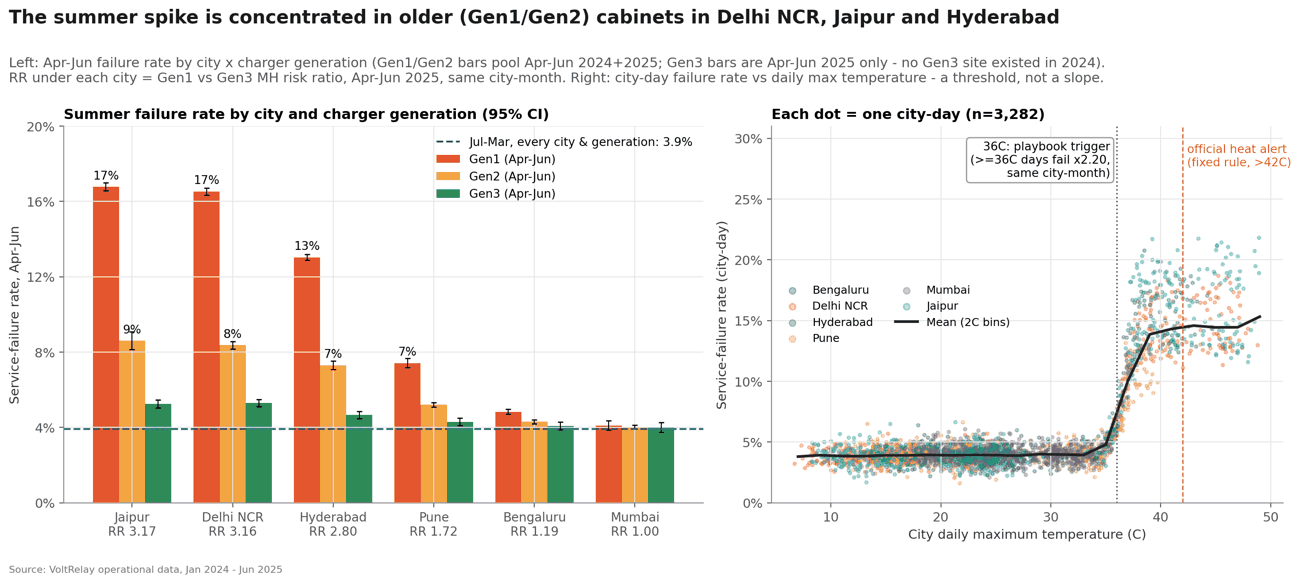

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_03_city_generation_heat.png')

In [72]:
cool_ref = cgs.filter(pl.col("season_grp") == "Jul-Mar")
cool_ref_rate = cool_ref["failures"].sum() / cool_ref["attempts"].sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
order = cs["city"].to_list()
gens = ["Gen1", "Gen2", "Gen3"]
w = 0.26
hot_cg = cgs.filter(pl.col("season_grp") == "Apr-Jun")
for i, g in enumerate(gens):
    sub = hot_cg.filter(pl.col("charger_generation") == g)
    vals, los, his = [], [], []
    for c in order:
        r = sub.filter(pl.col("city") == c)
        vals.append(r["failure_rate"][0] if r.height else np.nan)
        los.append(r["failure_rate"][0] - r["ci_lo"][0] if r.height else 0)
        his.append(r["ci_hi"][0] - r["failure_rate"][0] if r.height else 0)
    x = np.arange(len(order)) + (i - 1) * w
    ax.bar(x, vals, w, color=GEN_COLORS[g], label=f"{g} (Apr-Jun)", yerr=[los, his], capsize=2, error_kw=dict(lw=0.8))
    for xi, v in zip(x, vals):
        if np.isfinite(v) and v > 0.07:
            ax.text(xi, v + 0.004, f"{100 * v:.0f}%", ha="center", fontsize=9.5)
ax.axhline(cool_ref_rate, color=PALETTE["primary"], ls="--", lw=1.5, label=f"Jul-Mar, every city & generation: {pct(cool_ref_rate)}")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{c}\nRR {GEN_RR_CITY[c]:.2f}" for c in order], fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Service-failure rate, Apr-Jun")
ax.set_title("Summer failure rate by city and charger generation (95% CI)", fontsize=11.5)
ax.set_ylim(0, 0.20)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.legend(loc="upper right")
ax = axes[1]
pdx = cdd.select("city", "max_temp_c", "fr", "att").to_pandas()
for c in CITIES:
    s = pdx[pdx["city"] == c]
    ax.scatter(s["max_temp_c"], s["fr"], s=7, alpha=0.35, color=CITY_COLORS[c], label=c)
tbp = tb.filter(pl.col("city_days") >= 5).to_pandas()
ax.plot(tbp["tmax_bin"] + 1, tbp["failure_rate"], color="#222222", lw=2.2, label="Mean (2C bins)")
ax.axvline(36, color="#555555", ls=":", lw=1.2)
ax.text(35.4, 0.282, f"36C: playbook trigger\n(>=36C days fail x{wx['tmax_ge36'][0]:.2f},\nsame city-month)", fontsize=9.5,
        ha="right", va="center", bbox=dict(boxstyle="round", fc="white", ec="#999999"))
ax.axvline(42, color=PALETTE["accent"], ls="--", lw=1.0)
ax.text(42.4, 0.285, "official heat alert\n(fixed rule, >42C)", fontsize=9.5, va="center", color=PALETTE["accent"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.31)
ax.set_xlabel("City daily maximum temperature (C)")
ax.set_ylabel("Service-failure rate (city-day)")
ax.set_title("Each dot = one city-day (n=3,282)", fontsize=11.5)
ax.legend(ncol=2, fontsize=9, loc="center left", markerscale=2)
headline(fig, "The summer spike is concentrated in older (Gen1/Gen2) cabinets in Delhi NCR, Jaipur and Hyderabad",
         "Left: Apr-Jun failure rate by city x charger generation (Gen1/Gen2 bars pool Apr-Jun 2024+2025; Gen3 bars are Apr-Jun 2025 "
         "only - no Gen3 site existed in 2024).\nRR under each city = Gen1 vs Gen3 MH risk ratio, Apr-Jun 2025, same city-month. "
         "Right: city-day failure rate vs daily max temperature - a threshold, not a slope.", top=0.84)
save_fig(fig, "q2_03_city_generation_heat")

## 5. Is service quality even? Concentration across stations and station-hours
Failures scale with volume, so we compare the failure concentration curve with the attempts curve and also look
at **excess failures** = observed minus what each station's attempts would produce at the Jul-Mar baseline rate of
its vehicle class. At station-hour grain, sparse counts alone create extreme concentration, so we compare with
simulated chance-only nulls.

In [73]:
SMC = (ev.group_by("station_id", "month", "vehicle_class").agg(
    pl.len().alias("att"), FAIL.sum().alias("fail"), pl.col("is_stockout").sum().alias("so"),
    pl.col("is_abandoned").sum().alias("ab"), pl.col("is_system_error").sum().alias("se"),
    pl.col("is_completed").sum().alias("comp")).collect())
base_cls = (SMC.filter(~pl.col("month").dt.month().is_in(HOT_MONTHS)).group_by("vehicle_class")
            .agg((pl.col("fail").sum() / pl.col("att").sum()).alias("b")))
BASE = dict(zip(base_cls["vehicle_class"], base_cls["b"]))
print(f"[CONC] Jul-Mar baseline failure rate: 2W {pct(BASE['2W'], 2)}, 3W {pct(BASE['3W'], 2)} (3W/2W = {BASE['3W'] / BASE['2W']:.2f}x)")
SMC = SMC.join(base_cls, on="vehicle_class").with_columns((pl.col("fail") - pl.col("att") * pl.col("b")).alias("excess"))
attrs = st_all.select("station_id", "city", "zone", "expansion_wave", "charger_generation", "location_type", "host_type",
                      "connectivity_tier", "slots_2w", "slots_3w", "commissioned_date")
smo = station_month().select("station_id", "month", "active_days", "completed", "slots_2w", "slots_3w")
util_st = smo.group_by("station_id").agg(
    (pl.col("completed").sum() / (pl.col("active_days") * (pl.col("slots_2w") + pl.col("slots_3w"))).sum()).alias("swaps_per_slot_day"),
    pl.col("active_days").sum().alias("active_days"))
hotm = pl.col("month").dt.month().is_in(HOT_MONTHS)
yr = pl.col("month").dt.year()
SC = (SMC.group_by("station_id").agg(
    pl.col("att").sum(), pl.col("fail").sum(), pl.col("so").sum(), pl.col("ab").sum(), pl.col("se").sum(),
    pl.col("excess").sum(),
    pl.col("fail").filter(hotm & (yr == 2024)).sum().alias("fail_AJ24"), pl.col("att").filter(hotm & (yr == 2024)).sum().alias("att_AJ24"),
    pl.col("fail").filter(hotm & (yr == 2025)).sum().alias("fail_AJ25"), pl.col("att").filter(hotm & (yr == 2025)).sum().alias("att_AJ25"),
    pl.col("fail").filter(~hotm).sum().alias("fail_JM"), pl.col("att").filter(~hotm).sum().alias("att_JM"),
    pl.col("att").filter(pl.col("vehicle_class") == "3W").sum().alias("att_3w"),
    pl.col("fail").filter(pl.col("vehicle_class") == "3W").sum().alias("fail_3w"),
    pl.col("so").filter(pl.col("vehicle_class") == "3W").sum().alias("so_3w"))
    .join(attrs, on="station_id", how="left").join(util_st, on="station_id", how="left")
    .with_columns((pl.col("fail") / pl.col("att")).alias("failure_rate"), (pl.col("so") / pl.col("att")).alias("stockout_rate"),
                  (pl.col("ab") / pl.col("att")).alias("abandon_rate"),
                  (pl.col("fail_AJ24") / pl.col("att_AJ24")).alias("fr_AprJun24"), (pl.col("fail_AJ25") / pl.col("att_AJ25")).alias("fr_AprJun25"),
                  (pl.col("fail_JM") / pl.col("att_JM")).alias("fr_JulMar"), (pl.col("att") / pl.col("active_days")).alias("attempts_per_day"))
    .sort("excess", descending=True))
n_st = SC.height
k10 = int(np.ceil(0.10 * n_st))
G_att, G_fail, G_exc = gini(SC["att"]), gini(SC["fail"]), gini(SC["excess"].clip(lower_bound=0))
ts_att = top_share(SC["att"], 0.10)
ts_fail = top_share(SC["fail"], 0.10)
ts_exc = top_share(SC["excess"].clip(lower_bound=0), 0.10)
G_rate = gini(SC["failure_rate"])
print(f"[CONC] {n_st} stations. Gini: attempts {G_att:.3f}, failures {G_fail:.3f}, positive excess failures {G_exc:.3f}; "
      f"Gini of station failure RATE {G_rate:.3f}")
print(f"[CONC] top 10% of stations ({k10}): {pct(ts_att)} of attempts, {pct(ts_fail)} of failures, {pct(ts_exc)} of excess failures")
tot_exc = SMC["excess"].sum()
tot_pos = SC["excess"].clip(lower_bound=0).sum()
print(f"[CONC] network excess failures over baseline = {tot_exc:,.0f} of {N_FAIL:,} failures ({pct(tot_exc / N_FAIL)}); "
      f"stations with positive excess: {(SC['excess'] > 0).sum()} of {n_st}")
print(f"[CONC] station failure-rate range {pct(SC['failure_rate'].min(), 2)}-{pct(SC['failure_rate'].max(), 2)}; Jul-Mar range "
      f"{pct(SC['fr_JulMar'].min(), 2)}-{pct(SC['fr_JulMar'].max(), 2)}")
# Is the Jul-Mar baseline really the same at every station? Raw rates mix 2W and 3W riders (3W fail ~2.6x as often),
# so test station heterogeneity raw and after standardising for each station's vehicle-class mix.
jm_st = (SMC.filter(~hotm).group_by("station_id", "vehicle_class").agg(pl.col("att").sum(), pl.col("fail").sum())
         .join(base_cls, on="vehicle_class")
         .with_columns((pl.col("att") * pl.col("b")).alias("e"), (pl.col("att") * pl.col("b") * (1 - pl.col("b"))).alias("v"))
         .group_by("station_id").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("e").sum(), pl.col("v").sum()))
p_jm = jm_st["fail"].sum() / jm_st["att"].sum()
chi_raw = float((((jm_st["fail"] - jm_st["att"] * p_jm) ** 2) / (jm_st["att"] * p_jm * (1 - p_jm))).sum())
chi_cls = float((((jm_st["fail"] - jm_st["e"]) ** 2) / jm_st["v"]).sum())
df_jm = jm_st.height - 1
oe_jm = jm_st["fail"] / jm_st["e"]
print(f"[BASE] Jul-Mar, {jm_st.height} stations: raw station rates {pct((jm_st['fail'] / jm_st['att']).min(), 2)}-"
      f"{pct((jm_st['fail'] / jm_st['att']).max(), 2)} (heterogeneity chi2 {chi_raw:.0f} on {df_jm} df, p={stats.chi2.sf(chi_raw, df_jm):.1g}); "
      f"after vehicle-class mix: observed/expected {oe_jm.min():.2f}-{oe_jm.max():.2f}, chi2 {chi_cls:.0f} on {df_jm} df "
      f"(p={stats.chi2.sf(chi_cls, df_jm):.3f})")
top15_ids = SC.sort("excess", descending=True).head(15)["station_id"].to_list()

# segment view of excess failures
SMCs = SMC.join(attrs.select("station_id", "city", "charger_generation"), on="station_id").with_columns(
    pl.when(~hotm).then(pl.lit("Jul-Mar, all stations"))
    .when(pl.col("city").is_in(HOT_CITIES) & (pl.col("charger_generation") == "Gen1")).then(pl.lit("Apr-Jun, hot-city Gen1"))
    .when(pl.col("city").is_in(HOT_CITIES) & (pl.col("charger_generation") == "Gen2")).then(pl.lit("Apr-Jun, hot-city Gen2"))
    .when(pl.col("city").is_in(HOT_CITIES)).then(pl.lit("Apr-Jun, hot-city Gen3"))
    .otherwise(pl.lit("Apr-Jun, other cities")).alias("segment"))
seg = (SMCs.group_by("segment").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("excess").sum(),
                                     pl.col("station_id").n_unique().alias("stations"))
       .with_columns((pl.col("att") / pl.col("att").sum()).alias("share_attempts"), (pl.col("fail") / pl.col("fail").sum()).alias("share_failures"),
                     (pl.col("excess") / pl.col("excess").sum()).alias("share_excess"), (pl.col("fail") / pl.col("att")).alias("failure_rate"))
       .sort("share_excess", descending=True))
# Fair denominator: Jul-Mar has zero excess by construction, so compare excess with the share of Apr-Jun attempts
aj_tot = seg.filter(pl.col("segment").str.starts_with("Apr-Jun"))["att"].sum()
seg = seg.with_columns(pl.when(pl.col("segment").str.starts_with("Apr-Jun")).then(pl.col("att") / aj_tot)
                       .alias("share_aprjun_attempts"))
seg.write_csv(TAB / "q2_excess_failure_segments.csv")
ptable("Excess failures by segment", seg)
g1 = seg.filter(pl.col("segment") == "Apr-Jun, hot-city Gen1").row(0, named=True)
print(f"[CONC] Apr-Jun at hot-city Gen1 stations: {g1['stations']} stations, {pct(g1['share_aprjun_attempts'])} of Apr-Jun attempts "
      f"({pct(g1['share_attempts'])} of all 18-month attempts), {pct(g1['share_failures'])} of all failures, "
      f"{pct(g1['share_excess'])} of excess failures (failure rate {pct(g1['failure_rate'])})")
hot_all = seg.filter(pl.col("segment").str.starts_with("Apr-Jun, hot"))
print(f"[CONC] Apr-Jun at all hot-city stations: {pct(hot_all['share_aprjun_attempts'].sum())} of Apr-Jun attempts "
      f"({pct(hot_all['share_attempts'].sum())} of all attempts), {pct(hot_all['share_excess'].sum())} of excess failures")
st36 = SC.filter(pl.col("city").is_in(HOT_CITIES), pl.col("charger_generation") == "Gen1")
print(f"[CONC] the same {st36.height} hot-city Gen1 stations over all 18 months: {pct(st36['att'].sum() / N_ATT)} of attempts, "
      f"{pct(st36['fail'].sum() / N_FAIL)} of failures (the network's busiest third, not a small corner)")
for y_ in (2024, 2025):
    sy = SMCs.filter(hotm, yr == y_)
    g1y = sy.filter(pl.col("segment") == "Apr-Jun, hot-city Gen1")
    print(f"[CONC] Apr-Jun {y_}: excess {sy['excess'].sum():,.0f}; hot-city Gen1 = {pct(g1y['att'].sum() / sy['att'].sum())} of that "
          f"summer's attempts and {pct(g1y['excess'].sum() / sy['excess'].sum())} of its excess")
# robustness: each city's own Jul-Mar rate (per vehicle class) as the baseline instead of the network rate
base_cc = SMCs.filter(~hotm).group_by("city", "vehicle_class").agg((pl.col("fail").sum() / pl.col("att").sum()).alias("bc"))
smc2 = SMCs.join(base_cc, on=["city", "vehicle_class"]).with_columns((pl.col("fail") - pl.col("att") * pl.col("bc")).alias("exc2"))
print(f"[CONC] robustness, city x class baseline: total excess {smc2['exc2'].sum():,.0f}; Apr-Jun hot-city Gen1 share "
      f"{pct(smc2.filter(pl.col('segment') == 'Apr-Jun, hot-city Gen1')['exc2'].sum() / smc2['exc2'].sum())}")

# Are the stations with the most excess special, or just the biggest hot-city Gen1 sites? Compare each of the 36
# hot-city Gen1 stations with its own city x month x vehicle-class rate in Apr-Jun (observed / expected).
hg1 = SMCs.filter(pl.col("segment") == "Apr-Jun, hot-city Gen1")
ref_cm = hg1.group_by("city", "month", "vehicle_class").agg((pl.col("fail").sum() / pl.col("att").sum()).alias("r"))
OE36 = (hg1.join(ref_cm, on=["city", "month", "vehicle_class"])
        .with_columns((pl.col("att") * pl.col("r")).alias("e"), (pl.col("att") * pl.col("r") * (1 - pl.col("r"))).alias("v"))
        .group_by("station_id", "city").agg(pl.col("att").sum().alias("att_AJ"), pl.col("fail").sum().alias("fail_AJ"),
                                            pl.col("e").sum().alias("expected_AJ"), pl.col("v").sum().alias("var_AJ"),
                                            pl.col("excess").sum().alias("excess_AJ"))
        .with_columns((pl.col("fail_AJ") / pl.col("expected_AJ")).alias("oe_vs_city_month_class"),
                      (pl.col("fail_AJ") / pl.col("att_AJ")).alias("failure_rate_AJ"),
                      pl.col("station_id").is_in(top15_ids).alias("top15_by_excess"))
        .sort("excess_AJ", descending=True))
chi_36 = float((((OE36["fail_AJ"] - OE36["expected_AJ"]) ** 2) / OE36["var_AJ"]).sum())
df_36 = OE36.height - len(HOT_CITIES)
OE36.write_csv(TAB / "q2_hot_city_gen1_station_oe.csv")
t15o, r21o = OE36.filter("top15_by_excess"), OE36.filter(~pl.col("top15_by_excess"))
print(f"[OE36] {OE36.height} hot-city Gen1 stations in Apr-Jun vs their own city x month x class rate: O/E "
      f"{OE36['oe_vs_city_month_class'].min():.2f}-{OE36['oe_vs_city_month_class'].max():.2f}; extra between-station variation chi2 "
      f"{chi_36:.1f} on {df_36} df (p={stats.chi2.sf(chi_36, df_36):.2f})")
print(f"[OE36] top 15 by excess: median O/E {t15o['oe_vs_city_month_class'].median():.2f} vs {r21o['oe_vs_city_month_class'].median():.2f} "
      f"for the other {r21o.height}; median Apr-Jun attempts {t15o['att_AJ'].median():,.0f} vs {r21o['att_AJ'].median():,.0f}; by city "
      + ", ".join(f"{c} {t15o.filter(pl.col('city') == c).height} of {OE36.filter(pl.col('city') == c).height}" for c in HOT_CITIES))
s36 = {c: st36[c].drop_nans().drop_nulls() for c in ["fr_AprJun24", "fr_AprJun25", "fr_JulMar"]}
print(f"[OE36] all {st36.height} hot-city Gen1 stations fail in both summers: Apr-Jun 2024 station rates {pct(s36['fr_AprJun24'].min())}-"
      f"{pct(s36['fr_AprJun24'].max())} ({s36['fr_AprJun24'].len()} stations), Apr-Jun 2025 {pct(s36['fr_AprJun25'].min())}-"
      f"{pct(s36['fr_AprJun25'].max())} ({s36['fr_AprJun25'].len()}), vs Jul-Mar {pct(s36['fr_JulMar'].min())}-{pct(s36['fr_JulMar'].max())}")

# station-hour concentration vs chance-only nulls
rng = np.random.default_rng(59500)
sh_att = SH["att"].to_numpy()
sh_fail = SH["fail"].to_numpy()
sm_rate = (SMC.group_by("station_id", "month").agg((pl.col("fail").sum() / pl.col("att").sum()).alias("p")))
p_sm = (SH.select("station_id", pl.col("hour_start").dt.truncate("1mo").dt.date().alias("month"))
        .join(sm_rate, on=["station_id", "month"], how="left")["p"].to_numpy())
null_flat = rng.binomial(sh_att, FR_ALL)
null_sm = rng.binomial(sh_att, p_sm)
G_sh = {"observed": gini(sh_fail), "null_flat_rate": gini(null_flat), "null_station_month_rate": gini(null_sm)}
T_sh = {"observed": top_share(sh_fail, 0.10), "null_flat_rate": top_share(null_flat, 0.10),
        "null_station_month_rate": top_share(null_sm, 0.10)}
zero_sh = {"observed": (sh_fail == 0).mean(), "null_flat_rate": (null_flat == 0).mean(), "null_station_month_rate": (null_sm == 0).mean()}
conc_tbl = pd.DataFrame({"gini": G_sh, "top10pct_share": T_sh, "share_station_hours_zero_failures": zero_sh})
print("\n--- Station-hour concentration of failures vs chance-only nulls ---")
print(conc_tbl.round(4))
print(f"[CONC] station-hours (>=1 attempt): Gini observed {G_sh['observed']:.3f} vs {G_sh['null_flat_rate']:.3f} if every attempt "
      f"failed at the network rate, vs {G_sh['null_station_month_rate']:.3f} with each station-month's own rate; top 10% of "
      f"station-hours hold {pct(T_sh['observed'])} of failures (null {pct(T_sh['null_flat_rate'])} / {pct(T_sh['null_station_month_rate'])})")
summary_rows = [
    {"level": "station", "metric": "gini_attempts", "value": G_att}, {"level": "station", "metric": "gini_failures", "value": G_fail},
    {"level": "station", "metric": "gini_positive_excess", "value": G_exc}, {"level": "station", "metric": "gini_failure_rate", "value": G_rate},
    {"level": "station", "metric": "top10pct_share_attempts", "value": ts_att}, {"level": "station", "metric": "top10pct_share_failures", "value": ts_fail},
    {"level": "station", "metric": "top10pct_share_excess", "value": ts_exc}]
summary_rows += [{"level": "station_hour", "metric": f"gini_{k}", "value": v} for k, v in G_sh.items()]
summary_rows += [{"level": "station_hour", "metric": f"top10pct_share_{k}", "value": v} for k, v in T_sh.items()]
pd.DataFrame(summary_rows).to_csv(TAB / "q2_concentration_summary.csv", index=False)
del null_flat, null_sm, p_sm

[CONC] Jul-Mar baseline failure rate: 2W 3.34%, 3W 8.62% (3W/2W = 2.58x)
[CONC] 150 stations. Gini: attempts 0.294, failures 0.383, positive excess failures 0.683; Gini of station failure RATE 0.149
[CONC] top 10% of stations (15): 18.6% of attempts, 24.7% of failures, 42.9% of excess failures
[CONC] network excess failures over baseline = 62,558 of 211,849 failures (29.5%); stations with positive excess: 131 of 150
[CONC] station failure-rate range 3.68%-8.68%; Jul-Mar range 2.80%-5.30%
[BASE] Jul-Mar, 141 stations: raw station rates 2.80%-5.30% (heterogeneity chi2 262 on 140 df, p=2e-09); after vehicle-class mix: observed/expected 0.70-1.34, chi2 172 on 140 df (p=0.035)

--- Excess failures by segment ---
shape: (5, 10)
┌────────────────────────┬─────────┬───────┬────────────┬──────────┬────────────────┬────────────────┬──────────────┬──────────────┬───────────────────────┐
│ segment                ┆ att     ┆ fail  ┆ excess     ┆ stations ┆ share_attempts ┆ share_failures ┆ share_ex

In [74]:
# Tickets per station (used in the top-15 site table and section 9)
tk = (tickets().filter(pl.col("in_window") & ~pl.col("is_test") & pl.col("station_id").is_not_null()))
tk_st = tk.group_by("station_id").agg(
    pl.len().alias("tickets_all"), (pl.col("category") == "no_battery_available").sum().alias("tk_no_battery"),
    (pl.col("category") == "long_queue").sum().alias("tk_long_queue"))
SC = SC.join(tk_st, on="station_id", how="left").with_columns(
    [pl.col(c).fill_null(0) for c in ["tickets_all", "tk_no_battery", "tk_long_queue"]]).with_columns(
    ((pl.col("tk_no_battery") + pl.col("tk_long_queue")) / pl.col("att") * 1000).alias("nb_lq_tickets_per_1k"),
    (pl.col("tickets_all") / pl.col("att") * 1000).alias("tickets_per_1k"))
SC.write_csv(TAB / "q2_station_scorecard.csv")
top15_raw = SC.filter(pl.col("station_id").is_in(top15_ids))
TOP15_EXC_SHARE = top15_raw["excess"].sum() / tot_exc
TOP15_ATT_SHARE = top15_raw["att"].sum() / N_ATT
TOP15_FAIL_SHARE = top15_raw["fail"].sum() / N_FAIL
hot15 = SC.sort("excess", descending=True).head(15).join(
    OE36.select("station_id", "att_AJ", pl.col("oe_vs_city_month_class").round(3)), on="station_id", how="left").select(
    "station_id", "city", "zone", "expansion_wave", "charger_generation", "location_type", "host_type", "connectivity_tier",
    "slots_2w", "slots_3w", pl.col("swaps_per_slot_day").round(2), pl.col("attempts_per_day").round(1), "att", "att_AJ", "fail",
    pl.col("excess").round(0), "oe_vs_city_month_class", pl.col("failure_rate").round(4), pl.col("fr_AprJun24").round(4),
    pl.col("fr_AprJun25").round(4), pl.col("fr_JulMar").round(4), pl.col("stockout_rate").round(4), pl.col("abandon_rate").round(4),
    pl.col("nb_lq_tickets_per_1k").round(2))
hot15.write_csv(TAB / "q2_top15_hot_city_gen1_sites.csv")
ptable("15 largest hot-city Gen1 sites by absolute excess failures (not unusual: O/E vs own city-month rate shown)", hot15)
print(f"[TOP15] cities: {dict(hot15.group_by('city').len().iter_rows())}; generation: {dict(hot15.group_by('charger_generation').len().iter_rows())};"
      f" wave: {dict(hot15.group_by('expansion_wave').len().iter_rows())}; location: {dict(hot15.group_by('location_type').len().iter_rows())}")
print(f"[TOP15] the 15 stations with the most excess hold {pct(TOP15_EXC_SHARE)} of net excess failures, {pct(TOP15_FAIL_SHARE)} of all "
      f"failures and {pct(TOP15_ATT_SHARE)} of attempts; Apr-Jun failure rate 2024 median {pct(hot15['fr_AprJun24'].median())}, 2025 median "
      f"{pct(hot15['fr_AprJun25'].median())}; Jul-Mar median {pct(hot15['fr_JulMar'].median(), 2)}")
rest = SC.filter(~pl.col("station_id").is_in(hot15["station_id"].to_list()))
print(f"[TOP15] utilisation (swaps per slot-day): these 15 median {hot15['swaps_per_slot_day'].median():.2f} vs other stations "
      f"{rest['swaps_per_slot_day'].median():.2f}")


--- 15 largest hot-city Gen1 sites by absolute excess failures (not unusual: O/E vs own city-month rate shown) ---
shape: (15, 24)
┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬────────┬────────┬────────┬────────┬────────┬────────┬───────┬────────┬──────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┐
│ station ┆ city    ┆ zone    ┆ expansi ┆ charger ┆ locatio ┆ host_t ┆ connec ┆ slots_ ┆ slots_ ┆ swaps_ ┆ attemp ┆ att   ┆ att_AJ ┆ fail ┆ excess ┆ oe_vs_ ┆ failur ┆ fr_Apr ┆ fr_Apr ┆ fr_Jul ┆ stocko ┆ abando ┆ nb_lq_ │
│ _id     ┆ ---     ┆ ---     ┆ on_wave ┆ _genera ┆ n_type  ┆ ype    ┆ tivity ┆ 2w     ┆ 3w     ┆ per_sl ┆ ts_per ┆ ---   ┆ ---    ┆ ---  ┆ ---    ┆ city_m ┆ e_rate ┆ Jun24  ┆ Jun25  ┆ Mar    ┆ ut_rat ┆ n_rate ┆ ticket │
│ ---     ┆ str     ┆ str     ┆ ---     ┆ tion    ┆ ---     ┆ ---    ┆ _tier  ┆ ---    ┆ ---    ┆ ot_day ┆ _day   ┆ u32   ┆ u32    ┆ u32  ┆ f64    ┆ onth_c ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ e      ┆ --

[TOP15] cities: {'Jaipur': 6, 'Hyderabad': 2, 'Delhi NCR': 7}; generation: {'Gen1': 15}; wave: {'Launch': 15}; location: {'commercial_hub': 9, 'market': 6}
[TOP15] the 15 stations with the most excess hold 43.1% of net excess failures, 24.5% of all failures and 16.8% of attempts; Apr-Jun failure rate 2024 median 16.8%, 2025 median 16.5%; Jul-Mar median 3.88%
[TOP15] utilisation (swaps per slot-day): these 15 median 4.35 vs other stations 3.81


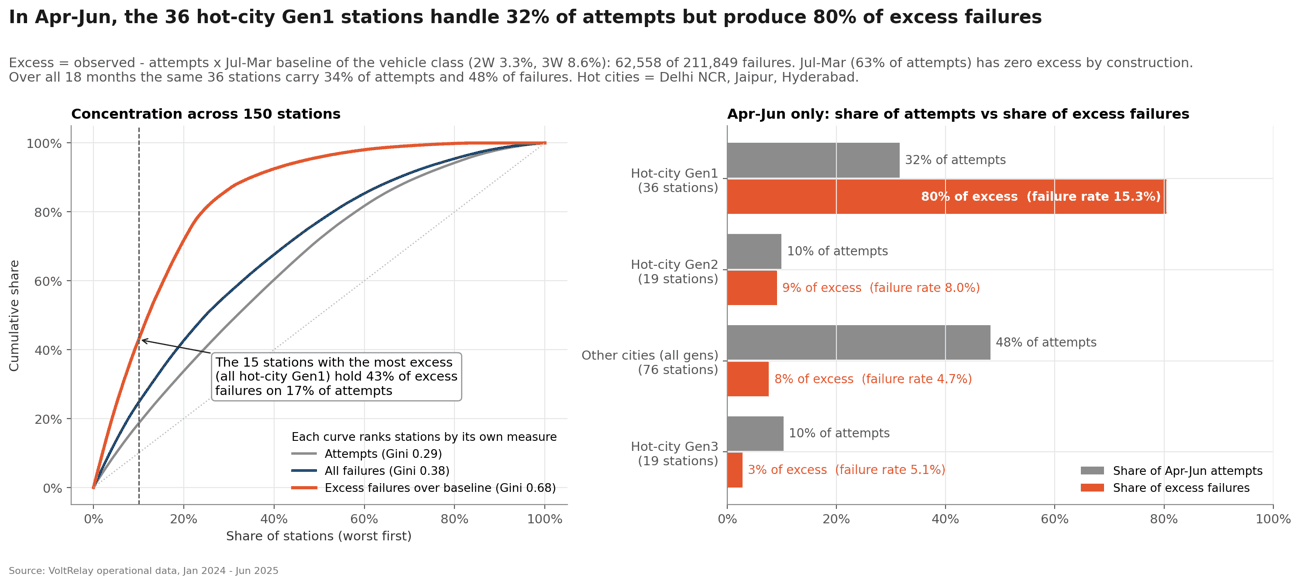

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_04_concentration_lorenz.png')

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.3), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
for vals, lab, col, lw in [(SC["att"], f"Attempts (Gini {G_att:.2f})", PALETTE["muted"], 2),
                           (SC["fail"], f"All failures (Gini {G_fail:.2f})", PALETTE["primary"], 2.2),
                           (SC["excess"].clip(lower_bound=0), f"Excess failures over baseline (Gini {G_exc:.2f})", PALETTE["accent"], 2.6)]:
    xx, yy = conc_curve(vals)
    ax.plot(xx, yy, color=col, lw=lw, label=lab)
ax.plot([0, 1], [0, 1], color="#BBBBBB", ls=":", lw=1)
ax.axvline(0.10, color="#444444", ls="--", lw=1)
ax.annotate(f"The {len(top15_ids)} stations with the most excess\n(all hot-city Gen1) hold "
            f"{pct(TOP15_EXC_SHARE, 0)} of excess\nfailures on {pct(TOP15_ATT_SHARE, 0)} of attempts",
            xy=(0.10, ts_exc), xytext=(0.27, 0.27), fontsize=10.5, arrowprops=dict(arrowstyle="->", color="#222222"),
            bbox=dict(boxstyle="round", fc="white", ec="#999999"))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of stations (worst first)")
ax.set_ylabel("Cumulative share")
ax.set_title(f"Concentration across {n_st} stations", fontsize=11.5)
ax.legend(loc="lower right", fontsize=9.5, title="Each curve ranks stations by its own measure", title_fontsize=9.5)
ax = axes[1]
segp = seg.filter(pl.col("segment").str.starts_with("Apr-Jun")).sort("share_excess").to_pandas()
seg_lbl = {"Apr-Jun, hot-city Gen1": "Hot-city Gen1", "Apr-Jun, hot-city Gen2": "Hot-city Gen2",
           "Apr-Jun, hot-city Gen3": "Hot-city Gen3", "Apr-Jun, other cities": "Other cities (all gens)"}
y = np.arange(len(segp))
ax.barh(y + 0.2, segp["share_aprjun_attempts"], 0.38, color=PALETTE["muted"], label="Share of Apr-Jun attempts")
ax.barh(y - 0.2, segp["share_excess"], 0.38, color=PALETTE["accent"], label="Share of excess failures")
for yi, (a, e, fr, ns) in enumerate(zip(segp["share_aprjun_attempts"], segp["share_excess"], segp["failure_rate"], segp["stations"])):
    ax.text(a + 0.01, yi + 0.2, f"{pct(a, 0)} of attempts", va="center", fontsize=10, color="#555555")
    inside = e > 0.6  # long bar: write the label inside it so it stays within the panel
    ax.text(e - 0.01 if inside else max(e, 0) + 0.01, yi - 0.2, f"{pct(e, 0)} of excess  (failure rate {pct(fr, 1)})", va="center",
            ha="right" if inside else "left", fontsize=10, color="white" if inside else PALETTE["accent"],
            fontweight="bold" if inside else "normal")
ax.set_yticks(y)
ax.set_yticklabels([f"{seg_lbl[s]}\n({n} stations)" for s, n in zip(segp["segment"], segp["stations"])])
ax.axvline(0, color="#888888", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1.0)
ax.set_title("Apr-Jun only: share of attempts vs share of excess failures", fontsize=11.5)
ax.legend(loc="lower right")
headline(fig, f"In Apr-Jun, the {g1['stations']} hot-city Gen1 stations handle {pct(g1['share_aprjun_attempts'], 0)} of attempts but "
         f"produce {pct(g1['share_excess'], 0)} of excess failures",
         f"Excess = observed - attempts x Jul-Mar baseline of the vehicle class (2W {pct(BASE['2W'], 1)}, 3W {pct(BASE['3W'], 1)}): "
         f"{tot_exc:,.0f} of {N_FAIL:,} failures. Jul-Mar ({pct(1 - aj_tot / N_ATT, 0)} of attempts) has zero excess by construction.\n"
         f"Over all 18 months the same {st36.height} stations carry {pct(st36['att'].sum() / N_ATT, 0)} of attempts and "
         f"{pct(st36['fail'].sum() / N_FAIL, 0)} of failures. Hot cities = Delhi NCR, Jaipur, Hyderabad.", top=0.84)
save_fig(fig, "q2_04_concentration_lorenz")

## 6. Mechanism from hourly telemetry: heat -> hot cabinet -> slower Gen1 charging -> empty cabinets on hot days
Telemetry rows with `telemetry_status == 'missing'` have every sensor field null; `partial` rows carry values.
We exclude missing rows (null-aware) and report coverage. Event station-hours are joined on station + hour_start.
The telemetry links (heat -> cabinet -> charge time -> afternoon empty cabinets) are measured facts. Whether empty
cabinets explain WHICH hours fail is tested separately in 6b, holding the day and the hour of day fixed.

In [76]:
HR_COLS = ["station_id", "hour_start", "hour", "month", "telemetry_status", "connectivity_tier", "charger_generation", "city",
           "charged_2w_avg", "charged_2w_min", "charged_3w_min", "packs_quarantined", "chargers_online", "ambient_temp_c",
           "cabinet_temp_c", "avg_charge_minutes", "outage_minutes", "slots_2w", "slots_3w", "inventory_target_2w"]
HR = hourly(HR_COLS).collect()
J = (HR.join(SH.drop("slots", "util", "demand_util"), on=["station_id", "hour_start"], how="left")
     .with_columns([pl.col(c).fill_null(0) for c in ["att", "comp", "fail", "so", "ab", "se", "att3", "so3", "ab3", "qws"]])
     .with_columns((pl.col("att") - pl.col("att3")).alias("att2"), (pl.col("so") - pl.col("so3")).alias("so2"),
                   (pl.col("ab") - pl.col("ab3")).alias("ab2")))
unmatched = SH.join(HR.select("station_id", "hour_start"), on=["station_id", "hour_start"], how="anti").height
cov = (J.group_by("connectivity_tier", "telemetry_status").agg(pl.len().alias("station_hours"), pl.col("att").sum().alias("attempts"))
       .with_columns((pl.col("station_hours") / pl.col("station_hours").sum().over("connectivity_tier")).alias("share_of_tier_hours"))
       .sort("connectivity_tier", "telemetry_status"))
cov.write_csv(TAB / "q2_telemetry_coverage.csv")
ptable("Telemetry coverage by connectivity tier", cov)
cov_s = J.group_by("telemetry_status").agg(pl.len().alias("h"), pl.col("att").sum().alias("a"))
cov_d = {r["telemetry_status"]: r for r in cov_s.iter_rows(named=True)}
print(f"[TEL] station-hours {J.height:,}: ok {pct(cov_d['ok']['h'] / J.height)}, partial {pct(cov_d['partial']['h'] / J.height)}, "
      f"missing {pct(cov_d['missing']['h'] / J.height, 2)}; attempts in hours with usable telemetry "
      f"{pct(1 - cov_d['missing']['a'] / N_ATT, 2)}; event station-hours without a telemetry row: {unmatched}")
JT = J.filter(pl.col("telemetry_status") != "missing")
amb = JT.select(pl.corr("ambient_temp_c", "cabinet_temp_c").alias("r"),
                (pl.col("cabinet_temp_c") - pl.col("ambient_temp_c")).mean().alias("d"))
print(f"[TEL] ambient vs cabinet temperature: r = {amb['r'][0]:.3f}; cabinet runs {amb['d'][0]:.1f}C above ambient on average")
print("[TEL] cabinet minus ambient by generation: " + ", ".join(
    f"{r['charger_generation']} {r['d']:.2f}C" for r in JT.group_by("charger_generation").agg(
        (pl.col("cabinet_temp_c") - pl.col("ambient_temp_c")).mean().alias("d")).sort("charger_generation").iter_rows(named=True)))

CB = 2.5
mech = (JT.with_columns(((pl.col("cabinet_temp_c") / CB).floor() * CB).alias("cab_bin"))
        .group_by("charger_generation", "cab_bin").agg(
            pl.len().alias("station_hours"), pl.col("att").sum().alias("attempts"),
            pl.col("ambient_temp_c").mean().alias("ambient_c"), pl.col("avg_charge_minutes").mean().alias("charge_min"),
            (pl.col("charged_2w_min") == 0).mean().alias("zero_2w_share"),
            (pl.col("charged_2w_avg") / pl.col("inventory_target_2w")).mean().alias("charged_vs_target"),
            (pl.col("so").sum() / pl.col("att").sum()).alias("stockout_rate"),
            (pl.col("ab").sum() / pl.col("att").sum()).alias("abandon_rate"),
            (pl.col("fail").sum() / pl.col("att").sum()).alias("failure_rate"))
        .sort("charger_generation", "cab_bin"))
mech.write_csv(TAB / "q2_mechanism_cabinet_temp.csv")
ptable("Mechanism by cabinet temperature (2.5C bins) x generation", mech.filter(pl.col("station_hours") >= 200))


def band(g, lo, hi):
    s = JT.filter(pl.col("charger_generation") == g, pl.col("cabinet_temp_c") >= lo, pl.col("cabinet_temp_c") < hi)
    return dict(h=s.height, chg=s["avg_charge_minutes"].mean(), zero=(s["charged_2w_min"] == 0).mean(),
                so=s["so"].sum() / max(s["att"].sum(), 1), fr=s["fail"].sum() / max(s["att"].sum(), 1), att=s["att"].sum())


MB = {}
for g in ["Gen1", "Gen2", "Gen3"]:
    MB[g] = {"<40": band(g, -50, 40), ">=45": band(g, 45, 99), ">=50": band(g, 50, 99)}
    a, b, c = MB[g]["<40"], MB[g][">=45"], MB[g][">=50"]
    print(f"[MECH] {g}: cabinet <40C -> charge {a['chg']:.0f} min, zero-2W-stock hours {pct(a['zero'], 2)}, stockout rate {pct(a['so'], 2)} "
          f"(n={a['h']:,} h) | >=45C -> {b['chg']:.0f} min, {pct(b['zero'])}, {pct(b['so'])} (n={b['h']:,} h) | "
          f">=50C -> {c['chg']:.0f} min, {pct(c['zero'])}, {pct(c['so'])} (n={c['h']:,} h)")
hot_share = (JT.group_by("charger_generation").agg((pl.col("cabinet_temp_c") >= 45).mean().alias("s"))
             .sort("charger_generation"))
print("[MECH] share of station-hours with cabinet >=45C: " + ", ".join(f"{r['charger_generation']} {pct(r['s'], 2)}" for r in hot_share.iter_rows(named=True)))
cab_city = (JT.filter(pl.col("month").dt.month().is_in(HOT_MONTHS)).group_by("city").agg(
    (pl.col("cabinet_temp_c") >= 45).mean().alias("share_ge45")).sort("share_ge45", descending=True))
print("[MECH] Apr-Jun share of station-hours with cabinet >=45C by city: " + ", ".join(
    f"{r['city']} {pct(r['share_ge45'])}" for r in cab_city.iter_rows(named=True)))

inv = (JT.with_columns(pl.col("charged_2w_min").clip(upper_bound=10).alias("min_bin"))
       .group_by("min_bin").agg(pl.len().alias("station_hours"), pl.col("att2").sum().alias("attempts_2w"),
                                (pl.col("so2").sum() / pl.col("att2").sum()).alias("stockout_rate_2w"),
                                (pl.col("ab2").sum() / pl.col("att2").sum()).alias("abandon_rate_2w"),
                                (pl.col("qws").sum() / pl.col("comp").sum() / 60).alias("mean_wait_min"))
       .sort("min_bin"))
inv.write_csv(TAB / "q2_inventory_vs_stockout.csv")
ptable("2W stockout / abandonment by minimum charged-2W packs in the hour (10 = 10+)", inv)
i0 = inv.filter(pl.col("min_bin") == 0).row(0, named=True)
i5 = inv.filter(pl.col("min_bin") >= 5)
r5 = i5["stockout_rate_2w"].dot(i5["attempts_2w"]) / i5["attempts_2w"].sum()
a5 = i5["abandon_rate_2w"].dot(i5["attempts_2w"]) / i5["attempts_2w"].sum()
print(f"[INV] POOLED (no strata; confounded by day and hour, see 6b): hours with zero charged 2W packs: 2W stockout "
      f"{pct(i0['stockout_rate_2w'], 2)}, abandonment {pct(i0['abandon_rate_2w'], 2)} vs {pct(r5, 2)} / {pct(a5, 2)} when >=5 packs; "
      f"completed wait {i0['mean_wait_min']:.2f} min (unchanged)")

# chargers offline, quarantined packs, outages
J2 = J.with_columns((pl.col("slots_2w") + pl.col("slots_3w") - pl.col("chargers_online")).alias("chargers_offline"))
oth_rows = []
for lab, cond in [("chargers_offline>=1", pl.col("chargers_offline") >= 1), ("all chargers online", pl.col("chargers_offline") <= 0),
                  ("packs_quarantined>=1", pl.col("packs_quarantined") >= 1), ("outage_minutes>0", pl.col("outage_minutes") > 0),
                  ("no outage", pl.col("outage_minutes") == 0)]:
    s = J2.filter(cond)
    p, lo, hi = wilson(s["fail"].sum(), s["att"].sum())
    oth_rows.append({"condition": lab, "station_hours": s.height, "attempts": int(s["att"].sum()), "failure_rate": float(p),
                     "ci_lo": float(lo), "ci_hi": float(hi), "system_error_rate": s["se"].sum() / s["att"].sum(),
                     "stockout_rate": s["so"].sum() / s["att"].sum()})
oth_df = pd.DataFrame(oth_rows)
oth_df.to_csv(TAB / "q2_other_telemetry_conditions.csv", index=False)
print("\n--- Other telemetry conditions ---")
print(oth_df.round(4).to_string(index=False))
del J2


--- Telemetry coverage by connectivity tier ---
shape: (7, 5)
┌───────────────────┬──────────────────┬───────────────┬──────────┬─────────────────────┐
│ connectivity_tier ┆ telemetry_status ┆ station_hours ┆ attempts ┆ share_of_tier_hours │
│ ---               ┆ ---              ┆ ---           ┆ ---      ┆ ---                 │
│ str               ┆ str              ┆ u32           ┆ i32      ┆ f64                 │
╞═══════════════════╪══════════════════╪═══════════════╪══════════╪═════════════════════╡
│ fair              ┆ ok               ┆ 267660        ┆ 642999   ┆ 0.9605              │
│ fair              ┆ partial          ┆ 11004         ┆ 26687    ┆ 0.0395              │
│ good              ┆ ok               ┆ 938666        ┆ 2478452  ┆ 0.9899              │
│ good              ┆ partial          ┆ 9550          ┆ 24987    ┆ 0.0101              │
│ poor              ┆ missing          ┆ 9384          ┆ 25665    ┆ 0.0400              │
│ poor              ┆ ok             


--- 2W stockout / abandonment by minimum charged-2W packs in the hour (10 = 10+) ---
shape: (11, 6)
┌─────────┬───────────────┬─────────────┬──────────────────┬─────────────────┬───────────────┐
│ min_bin ┆ station_hours ┆ attempts_2w ┆ stockout_rate_2w ┆ abandon_rate_2w ┆ mean_wait_min │
│ ---     ┆ ---           ┆ ---         ┆ ---              ┆ ---             ┆ ---           │
│ f32     ┆ u32           ┆ i32         ┆ f64              ┆ f64             ┆ f64           │
╞═════════╪═══════════════╪═════════════╪══════════════════╪═════════════════╪═══════════════╡
│ 0.0000  ┆ 18530         ┆ 50382       ┆ 0.0688           ┆ 0.0337          ┆ 4.0411        │
│ 1.0000  ┆ 26264         ┆ 73460       ┆ 0.0452           ┆ 0.0236          ┆ 4.0789        │
│ 2.0000  ┆ 57244         ┆ 155345      ┆ 0.0362           ┆ 0.0185          ┆ 4.0614        │
│ 3.0000  ┆ 98385         ┆ 258611      ┆ 0.0342           ┆ 0.0174          ┆ 4.0573        │
│ 4.0000  ┆ 136498        ┆ 344794      ┆ 0.

In [77]:
# Station-day binomial GLM, separately per generation: failure ~ daily max cabinet temp band + city + month + weekday
sd_e = (ev.group_by("station_id", "date").agg(pl.len().alias("att"), FAIL.sum().alias("fail"),
                                              pl.col("is_stockout").sum().alias("so")).collect())
sd_t = (JT.with_columns(pl.col("hour_start").dt.date().alias("date")).group_by("station_id", "date")
        .agg(pl.col("cabinet_temp_c").max().alias("cab_max"), pl.len().alias("tele_hours")))
SD = (sd_e.join(sd_t, on=["station_id", "date"], how="inner").join(attrs.select("station_id", "city", "charger_generation"), on="station_id")
      .with_columns(pl.col("date").dt.strftime("%Y-%m").alias("ym"), pl.col("date").dt.weekday().cast(pl.Utf8).alias("wd"),
                    pl.col("cab_max").cut([40, 45, 50, 55], labels=["<40", "40-45", "45-50", "50-55", ">=55"], left_closed=True).alias("cab_band")))
print(f"[GLM] station-days with events and telemetry: {SD.height:,} of {sd_e.height:,} station-days with events "
      f"({pct(SD.height / sd_e.height, 2)} coverage)")
glm_rows = []
for g in ["Gen1", "Gen2", "Gen3"]:
    d = SD.filter(pl.col("charger_generation") == g).to_pandas()
    d["cab_band"] = pd.Categorical(d["cab_band"], categories=["<40", "40-45", "45-50", "50-55", ">=55"])
    X = pd.get_dummies(d[["cab_band", "city", "ym", "wd"]], drop_first=True, dtype=float)
    X = X.loc[:, X.sum() > 0]
    X = sm.add_constant(X)
    yv = np.column_stack([d["fail"], d["att"] - d["fail"]])
    res = sm.GLM(yv, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": d["station_id"].astype("category").cat.codes})
    for b in ["40-45", "45-50", "50-55", ">=55"]:
        col = f"cab_band_{b}"
        if col in res.params:
            ci = res.conf_int().loc[col]
            glm_rows.append({"generation": g, "cabinet_max_band": b, "odds_ratio_vs_lt40": np.exp(res.params[col]),
                             "ci_lo": np.exp(ci[0]), "ci_hi": np.exp(ci[1]), "p_value": res.pvalues[col],
                             "station_days_in_band": int((d["cab_band"] == b).sum()), "station_days_total": len(d),
                             "stations": d["station_id"].nunique()})
glm_df = pd.DataFrame(glm_rows)
glm_df.to_csv(TAB / "q2_glm_heat_by_generation.csv", index=False)
print("\n--- Station-day GLM: odds ratio of a failed attempt vs days with max cabinet <40C (controls: city, month, weekday; "
      "station-clustered 95% CI) ---")
print(glm_df.round(3).to_string(index=False))
# station-day curve used in the mechanism chart (day's peak cabinet temperature -> that day's stockout rate)
sdc = (SD.with_columns(((pl.col("cab_max") / CB).floor() * CB).alias("cab_max_bin"))
       .group_by("charger_generation", "cab_max_bin").agg(pl.len().alias("station_days"), pl.col("att").sum(),
                                                          (pl.col("so").sum() / pl.col("att").sum()).alias("stockout_rate"),
                                                          (pl.col("fail").sum() / pl.col("att").sum()).alias("failure_rate"))
       .sort("charger_generation", "cab_max_bin"))
sdc.write_csv(TAB / "q2_station_day_cabinet_max_vs_stockout.csv")
for g in ["Gen1", "Gen2", "Gen3"]:
    s = SD.filter(pl.col("charger_generation") == g)
    lo_, hi_ = s.filter(pl.col("cab_max") < 40), s.filter(pl.col("cab_max") >= 45)
    print(f"[MECH-DAY] {g}: days with peak cabinet <40C stockout rate {pct(lo_['so'].sum() / lo_['att'].sum(), 2)} "
          f"({lo_.height:,} station-days) vs >=45C {pct(hi_['so'].sum() / hi_['att'].sum(), 2)} ({hi_.height:,} station-days)")
# load parity behind the Gen3 counterfactual: do hot-city Gen3 sites serve a comparable load in the same summer?
lpar = (SD.filter(pl.col("city").is_in(HOT_CITIES), pl.col("date") >= pl.date(2025, 4, 1), pl.col("charger_generation").is_in(["Gen1", "Gen3"]))
        .group_by("charger_generation").agg(pl.col("att").mean().alias("apd"), pl.len().alias("station_days")).sort("charger_generation"))
print("[LOAD-GEN] hot cities, Apr-Jun 2025, attempts per active station-day: " + ", ".join(
    f"{r['charger_generation']} {r['apd']:.1f} ({r['station_days']:,} station-days)" for r in lpar.iter_rows(named=True)))

[GLM] station-days with events and telemetry: 60,893 of 60,893 station-days with events (100.00% coverage)



--- Station-day GLM: odds ratio of a failed attempt vs days with max cabinet <40C (controls: city, month, weekday; station-clustered 95% CI) ---
generation cabinet_max_band  odds_ratio_vs_lt40  ci_lo  ci_hi  p_value  station_days_in_band  station_days_total  stations
      Gen1            40-45               1.393  1.316  1.476    0.000                  3062               27897        51
      Gen1            45-50               4.462  4.217  4.721    0.000                  3240               27897        51
      Gen1            50-55               4.762  4.393  5.163    0.000                  1562               27897        51
      Gen1             >=55               4.681  4.264  5.139    0.000                   443               27897        51
      Gen2            40-45               1.066  1.028  1.106    0.001                  4112               27812        62
      Gen2            45-50               2.105  2.002  2.214    0.000                  1702               27812    

### 6b. Trap check: does the hourly stock level explain WHICH hours fail? (Simpson's paradox test)
Pooled, hours with zero charged 2W packs show more stockouts (section 6). But empty hours cluster on hot days and
in the afternoon, which are risky for other reasons. We compare zero-stock with stocked hours inside strata that
hold the station-day fixed (and the 19-22h window), or the hour of day fixed (city x generation x month x hour),
using Mantel-Haenszel risk ratios. Lagged stock uses a time-based self-join on `hour_start`; a row shift would
misalign hours around dropped 'missing' rows. Unit: station-hours with >=1 2W attempt and a non-null hourly
minimum of charged 2W packs.

In [78]:
H2 = (JT.filter(pl.col("att2") > 0, pl.col("charged_2w_min").is_not_null())
      .select("station_id", "hour_start", "city", "charger_generation", "att2", "so2", "ab2", "charged_2w_min")
      .with_columns(pl.col("hour_start").dt.date().alias("date"), pl.col("hour_start").dt.hour().alias("h"),
                    pl.col("hour_start").dt.truncate("1mo").alias("mo"), (pl.col("charged_2w_min") == 0).alias("zero"))
      .with_columns(pl.col("h").is_in(EVE).alias("eve")))


def mh_flag(df: pl.DataFrame, keys, flag, event):
    """MH risk ratio of a 2W outcome per 2W attempt, flag true vs false, within strata `keys`."""
    g = df.group_by(keys + [flag]).agg(pl.col("att2").sum().alias("n"), pl.col(event).sum().alias("e")).to_pandas()
    w = g.pivot_table(index=keys, columns=flag, values=["n", "e"], aggfunc="sum", fill_value=0)
    w.columns = [f"{a}_{b}" for a, b in w.columns]
    return mh_rr(w.reset_index(), "e_True", "n_True", "e_False", "n_False")


OUT_LBL = {"so2": "2W stockout", "ab2": "2W abandonment"}
zc = H2.group_by("zero").agg(pl.col("att2").sum(), pl.col("so2").sum(), pl.col("ab2").sum())
zt, zf = zc.filter(pl.col("zero")).row(0, named=True), zc.filter(~pl.col("zero")).row(0, named=True)
hour_rows = [{"comparison": "pooled (no strata), crude RR", "outcome": OUT_LBL[o], "rr": (zt[o] / zt["att2"]) / (zf[o] / zf["att2"]),
              "ci_lo": np.nan, "ci_hi": np.nan, "strata": 1, "rate_flag": zt[o] / zt["att2"], "rate_other": zf[o] / zf["att2"]}
             for o in ["so2", "ab2"]]
for lab, keys in [("same station-day", ["station_id", "date"]),
                  ("same station-day and same window (19-22h vs other)", ["station_id", "date", "eve"]),
                  ("same city x generation x month x hour of day", ["city", "charger_generation", "mo", "h"])]:
    for o in ["so2", "ab2"]:
        r = mh_flag(H2, keys, "zero", o)
        hour_rows.append({"comparison": lab, "outcome": OUT_LBL[o], "rr": r[0], "ci_lo": r[1], "ci_hi": r[2], "strata": r[3]})
TL = JT.filter(pl.col("charged_2w_min").is_not_null()).select("station_id", "hour_start", "charged_2w_min")
for L in [0, 1, 2, 3, 4, 6]:
    lg = TL.select("station_id", (pl.col("hour_start") + pl.duration(hours=L)).alias("hour_start"),
                   (pl.col("charged_2w_min") == 0).alias("zero_lag"))
    zj = H2.join(lg, on=["station_id", "hour_start"], how="inner")
    r0, r1 = zj.filter(pl.col("zero_lag")), zj.filter(~pl.col("zero_lag"))
    r = mh_flag(zj, ["city", "charger_generation", "mo", "h"], "zero_lag", "so2")
    hour_rows.append({"comparison": f"zero stock {L}h earlier (time join); same city x generation x month x hour", "outcome": OUT_LBL["so2"],
                      "rr": r[0], "ci_lo": r[1], "ci_hi": r[2], "strata": r[3], "lag_hours": L,
                      "rate_flag": r0["so2"].sum() / r0["att2"].sum(), "rate_other": r1["so2"].sum() / r1["att2"].sum()})
del TL, lg, zj, r0, r1
hr_df = pd.DataFrame(hour_rows)
hr_df.to_csv(TAB / "q2_hourly_stock_vs_failure_mh.csv", index=False)
print("\n--- Zero-stock hour vs stocked hour: 2W outcomes (rate_flag / rate_other = pooled rates) ---")
print(hr_df.round(4).to_string(index=False))


def hrr(comp, outcome="2W stockout"):
    return hr_df[(hr_df["comparison"] == comp) & (hr_df["outcome"] == outcome)].iloc[0]


HR_SD, HR_SDE, HR_CGMH = (hrr("same station-day"), hrr("same station-day and same window (19-22h vs other)"),
                          hrr("same city x generation x month x hour of day"))
for o in ["2W stockout", "2W abandonment"]:
    a_, b_, c_, d_ = (hrr("pooled (no strata), crude RR", o), hrr("same station-day", o),
                      hrr("same station-day and same window (19-22h vs other)", o), hrr("same city x generation x month x hour of day", o))
    print(f"[HOURLY] {o}, zero-stock vs stocked hour: pooled crude RR {a_['rr']:.2f} ({pct(a_['rate_flag'], 2)} vs {pct(a_['rate_other'], 2)}); "
          f"same station-day MH RR {b_['rr']:.2f} ({b_['ci_lo']:.2f}-{b_['ci_hi']:.2f}); + same window {c_['rr']:.2f} ({c_['ci_lo']:.2f}-"
          f"{c_['ci_hi']:.2f}); same city x gen x month x hour {d_['rr']:.2f} ({d_['ci_lo']:.2f}-{d_['ci_hi']:.2f})")
lags = hr_df[hr_df["lag_hours"].notna()]
LAG_RR_RANGE = (lags.loc[lags["lag_hours"] >= 1, "rr"].min(), lags.loc[lags["lag_hours"] >= 1, "rr"].max())
print("[LAG] 2W stockout when charged_2w_min was 0 L hours earlier (time-based self-join): pooled " + ", ".join(
    f"L={int(r.lag_hours)} {pct(r.rate_flag, 2)} vs {pct(r.rate_other, 2)}" for r in lags.itertuples())
      + f" | MH RR within city x gen x month x hour: " + ", ".join(f"L={int(r.lag_hours)} {r.rr:.2f}" for r in lags.itertuples())
      + f" -> 1-6 h lags {LAG_RR_RANGE[0]:.2f}-{LAG_RR_RANGE[1]:.2f}: no carry-over once hour of day is held fixed")

# Hot Gen1 days: the hour profile of stockouts vs the hour profile of empty cabinets
hd = (H2.filter(pl.col("city").is_in(HOT_CITIES), pl.col("charger_generation") == "Gen1", pl.col("hour_start").dt.month().is_in(HOT_MONTHS))
      .join(sd_t.select("station_id", "date", "cab_max"), on=["station_id", "date"], how="left")
      .filter(pl.col("cab_max").is_not_null()).with_columns((pl.col("cab_max") >= 45).alias("hot_day")))
prof = (hd.group_by("hot_day", "h").agg(pl.len().alias("station_hours"), pl.col("att2").sum(), pl.col("so2").sum(),
                                        pl.col("zero").mean().alias("zero_stock_share"),
                                        pl.col("charged_2w_min").mean().alias("mean_min_charged_2w"))
        .with_columns((pl.col("so2") / pl.col("att2")).alias("stockout_rate_2w")).sort("hot_day", "h"))
prof.write_csv(TAB / "q2_hot_gen1_day_hour_profile.csv")
hot_h = hd.filter(pl.col("hot_day"))


def win(df, cond):
    s = df.filter(cond)
    return s["so2"].sum() / s["att2"].sum(), s["zero"].mean(), int(s["att2"].sum())


W018, W1217, W1922 = win(hot_h, pl.col("h") <= 18), win(hot_h, pl.col("h").is_between(12, 17)), win(hot_h, pl.col("h").is_in(EVE))
W1922_OTH = win(hd.filter(~pl.col("hot_day")), pl.col("h").is_in(EVE))
ph018 = prof.filter(pl.col("hot_day"), pl.col("h") <= 18)
n_hot_days = hot_h.select(pl.struct("station_id", "date").n_unique()).item()
print(f"[HOTDAY] hot-city Gen1, Apr-Jun, station-days with peak cabinet >=45C ({n_hot_days:,} station-days): 2W stockout 0-18h "
      f"{pct(W018[0])} (hourly range {pct(ph018['stockout_rate_2w'].min())}-{pct(ph018['stockout_rate_2w'].max())}; hourly empty share "
      f"{pct(ph018['zero_stock_share'].min())}-{pct(ph018['zero_stock_share'].max())}); 12-17h {pct(W1217[0])} with {pct(W1217[1])} of hours "
      f"empty; 19-22h {pct(W1922[0])} with only {pct(W1922[1])} of hours empty (other Apr-Jun days at 19-22h: {pct(W1922_OTH[0])})")
eg = (hot_h.filter(pl.col("h").is_in(EVE))
      .with_columns(pl.col("charged_2w_min").cut([0.5, 2.5, 5.5], labels=["0", "1-2", "3-5", "6+"]).alias("stock"))
      .group_by("stock").agg(pl.col("att2").sum(), (pl.col("so2").sum() / pl.col("att2").sum()).alias("so")).sort("stock"))
print("[HOTDAY] same hot days, 19-22h, 2W stockout by hourly minimum of charged 2W packs: " + ", ".join(
    f"{r['stock']} packs {pct(r['so'])} (n={r['att2']:,})" for r in eg.iter_rows(named=True)))
nt = (hd.filter(pl.col("h") <= 8).group_by("hot_day")
      .agg(pl.col("att2").sum(), (pl.col("so2").sum() / pl.col("att2").sum()).alias("so"), pl.col("charged_2w_min").mean().alias("ms"))
      .sort("hot_day", descending=True))
NT = {r["hot_day"]: r for r in nt.iter_rows(named=True)}
print("[HOTDAY] same stations, 0-8h when cabinets are full: " + ", ".join(
    f"{'hot days' if k else 'other days'} 2W stockout {pct(r['so'])} (mean hourly-min charged 2W packs {r['ms']:.1f}; n={r['att2']:,})"
    for k, r in NT.items()))


--- Zero-stock hour vs stocked hour: 2W outcomes (rate_flag / rate_other = pooled rates) ---
                                                              comparison        outcome    rr  ci_lo  ci_hi  strata  rate_flag  rate_other  lag_hours
                                            pooled (no strata), crude RR    2W stockout 2.247    NaN    NaN       1      0.069       0.031        NaN
                                            pooled (no strata), crude RR 2W abandonment 2.146    NaN    NaN       1      0.034       0.016        NaN
                                                        same station-day    2W stockout 0.716  0.691  0.741    7493        NaN         NaN        NaN
                                                        same station-day 2W abandonment 0.734  0.697  0.773    7493        NaN         NaN        NaN
                      same station-day and same window (19-22h vs other)    2W stockout 0.986  0.946  1.027    7847        NaN         NaN        NaN
      

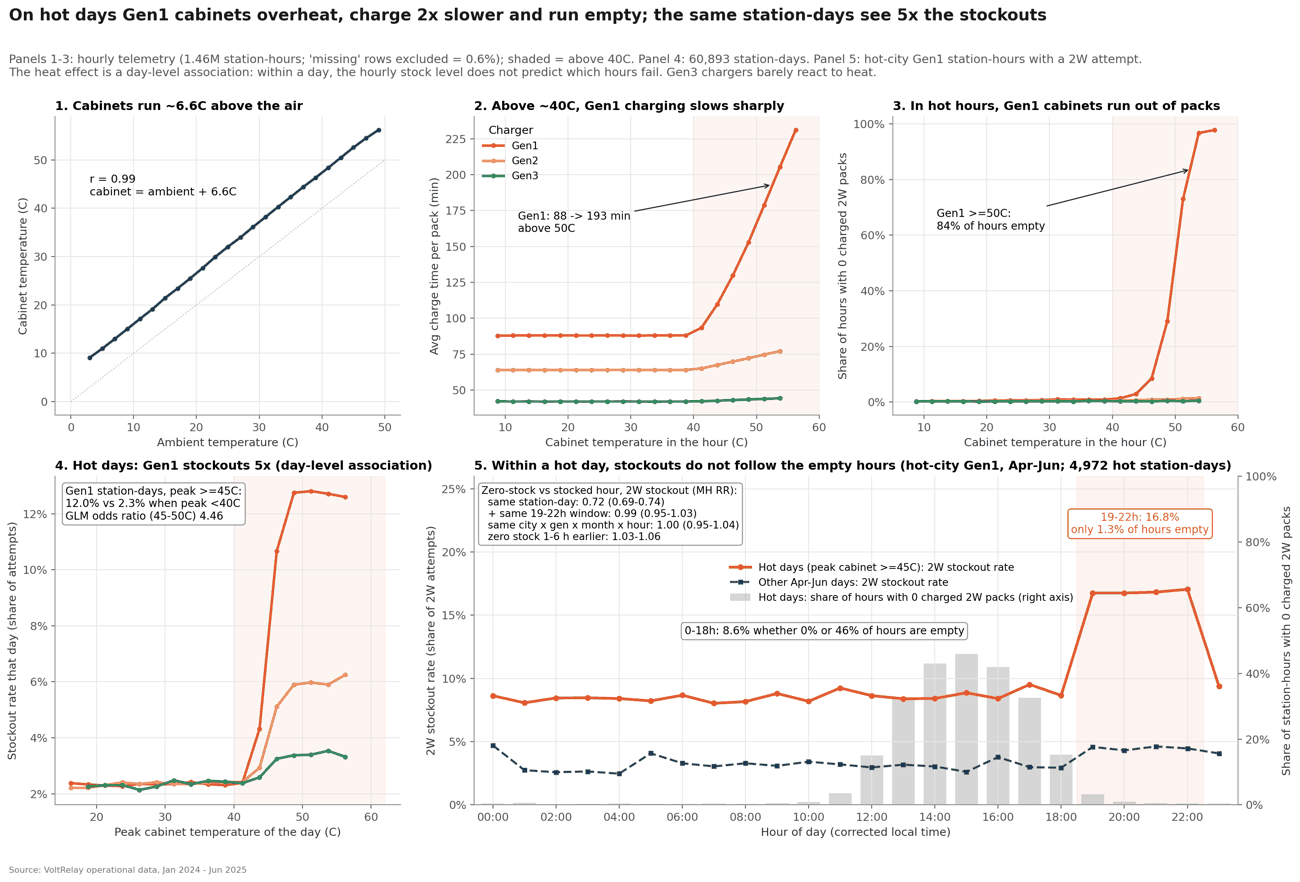

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_05_heat_mechanism.png')

In [79]:
fig = plt.figure(figsize=(17, 11))
gsp = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
axes = [fig.add_subplot(gsp[0, 0]), fig.add_subplot(gsp[0, 1]), fig.add_subplot(gsp[0, 2]), fig.add_subplot(gsp[1, 0]),
        fig.add_subplot(gsp[1, 1:])]
ax = axes[0]
ab = (JT.with_columns((pl.col("ambient_temp_c") // 2 * 2).alias("ab")).group_by("ab")
      .agg(pl.col("cabinet_temp_c").mean().alias("cab"), pl.len().alias("n")).filter(pl.col("n") >= 200).sort("ab"))
ax.plot(ab["ab"] + 1, ab["cab"], color=PALETTE["primary"], lw=2.4, marker="o", ms=3.5)
ax.plot([0, 50], [0, 50], color="#BBBBBB", ls=":", lw=1)
ax.text(3, 47, f"r = {amb['r'][0]:.2f}\ncabinet = ambient + {amb['d'][0]:.1f}C", fontsize=10.5, va="top")
ax.set_xlabel("Ambient temperature (C)")
ax.set_ylabel("Cabinet temperature (C)")
ax.set_title("1. Cabinets run ~6.6C above the air", fontsize=11.5)
mp = mech.filter(pl.col("station_hours") >= 300).to_pandas()
for i, (colname, ttl, ylab) in enumerate([
        ("charge_min", "2. Above ~40C, Gen1 charging slows sharply", "Avg charge time per pack (min)"),
        ("zero_2w_share", "3. In hot hours, Gen1 cabinets run out of packs", "Share of hours with 0 charged 2W packs")]):
    ax = axes[i + 1]
    for g in ["Gen1", "Gen2", "Gen3"]:
        s = mp[mp["charger_generation"] == g]
        ax.plot(s["cab_bin"] + CB / 2, s[colname], color=GEN_COLORS[g], lw=2.4, marker="o", ms=3.5, label=g)
    ax.axvspan(40, 60, color=PALETTE["accent"], alpha=0.06)
    ax.set_xlabel("Cabinet temperature in the hour (C)")
    ax.set_ylabel(ylab)
    ax.set_title(ttl, fontsize=11.5)
    ax.set_xlim(5, 60)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].legend(title="Charger", loc="upper left")
ax = axes[3]
sdp = sdc.filter(pl.col("station_days") >= 60).to_pandas()
for g in ["Gen1", "Gen2", "Gen3"]:
    s = sdp[sdp["charger_generation"] == g]
    ax.plot(s["cab_max_bin"] + CB / 2, s["stockout_rate"], color=GEN_COLORS[g], lw=2.4, marker="o", ms=3.5, label=g)
ax.axvspan(40, 62, color=PALETTE["accent"], alpha=0.06)
ax.set_xlabel("Peak cabinet temperature of the day (C)")
ax.set_ylabel("Stockout rate that day (share of attempts)")
ax.set_title("4. Hot days: Gen1 stockouts 5x (day-level association)", fontsize=11.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
g1b = MB["Gen1"]
axes[1].annotate(f"Gen1: {g1b['<40']['chg']:.0f} -> {g1b['>=50']['chg']:.0f} min\nabove 50C", xy=(52.5, g1b['>=50']['chg']),
                 xytext=(12, 160), fontsize=10, arrowprops=dict(arrowstyle="->", color="#222222"))
axes[2].annotate(f"Gen1 >=50C:\n{pct(g1b['>=50']['zero'], 0)} of hours empty", xy=(52.5, g1b['>=50']['zero']),
                 xytext=(12, 0.62), fontsize=10, arrowprops=dict(arrowstyle="->", color="#222222"))
g1d = SD.filter(pl.col("charger_generation") == "Gen1")
g1_hi = g1d.filter(pl.col("cab_max") >= 45)
g1_lo = g1d.filter(pl.col("cab_max") < 40)
SD_G1_HI, SD_G1_LO = g1_hi["so"].sum() / g1_hi["att"].sum(), g1_lo["so"].sum() / g1_lo["att"].sum()
glm_g1 = glm_df[(glm_df["generation"] == "Gen1") & (glm_df["cabinet_max_band"] == "45-50")].iloc[0]
axes[3].text(0.03, 0.97, f"Gen1 station-days, peak >=45C:\n{pct(SD_G1_HI, 1)} vs {pct(SD_G1_LO, 1)} when peak <40C\n"
             f"GLM odds ratio (45-50C) {glm_g1['odds_ratio_vs_lt40']:.2f}", transform=axes[3].transAxes, fontsize=10, va="top",
             bbox=dict(boxstyle="round", fc="white", ec="#999999"))
# Panel 5: within hot days, the hour profile of stockouts vs empty cabinets
ax = axes[4]
ph_hot = prof.filter(pl.col("hot_day")).sort("h").to_pandas()
ph_oth = prof.filter(~pl.col("hot_day")).sort("h").to_pandas()
axb = ax.twinx()
axb.bar(ph_hot["h"], ph_hot["zero_stock_share"], 0.72, color=PALETTE["muted"], alpha=0.35,
        label="Hot days: share of hours with 0 charged 2W packs (right axis)")
axb.set_ylim(0, 1.0)
axb.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axb.set_ylabel("Share of station-hours with 0 charged 2W packs")
axb.grid(False)
axb.spines["right"].set_visible(True)
ax.set_zorder(axb.get_zorder() + 1)
ax.patch.set_visible(False)
ax.plot(ph_hot["h"], ph_hot["stockout_rate_2w"], color=PALETTE["accent"], lw=2.6, marker="o", ms=4.5,
        label="Hot days (peak cabinet >=45C): 2W stockout rate")
ax.plot(ph_oth["h"], ph_oth["stockout_rate_2w"], color=PALETTE["primary"], lw=2.0, ls="--", marker="s", ms=3.5,
        label="Other Apr-Jun days: 2W stockout rate")
ax.axvspan(18.5, 22.5, color=PALETTE["accent"], alpha=0.07)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_xlim(-0.6, 23.6)
ax.set_ylim(0, 0.26)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Hour of day (corrected local time)")
ax.set_ylabel("2W stockout rate (share of 2W attempts)")
ax.set_title(f"5. Within a hot day, stockouts do not follow the empty hours (hot-city Gen1, Apr-Jun; {n_hot_days:,} hot station-days)",
             fontsize=11.5)
ax.text(0.01, 0.97, "Zero-stock vs stocked hour, 2W stockout (MH RR):\n"
        f"  same station-day: {HR_SD['rr']:.2f} ({HR_SD['ci_lo']:.2f}-{HR_SD['ci_hi']:.2f})\n"
        f"  + same 19-22h window: {HR_SDE['rr']:.2f} ({HR_SDE['ci_lo']:.2f}-{HR_SDE['ci_hi']:.2f})\n"
        f"  same city x gen x month x hour: {HR_CGMH['rr']:.2f} ({HR_CGMH['ci_lo']:.2f}-{HR_CGMH['ci_hi']:.2f})\n"
        f"  zero stock 1-6 h earlier: {LAG_RR_RANGE[0]:.2f}-{LAG_RR_RANGE[1]:.2f}",
        transform=ax.transAxes, fontsize=9.5, va="top", ha="left", bbox=dict(boxstyle="round", fc="white", ec="#999999"))
ax.text(10.5, 0.135, f"0-18h: {pct(W018[0])} whether {pct(ph018['zero_stock_share'].min(), 0)} or "
        f"{pct(ph018['zero_stock_share'].max(), 0)} of hours are empty", ha="center", fontsize=10,
        bbox=dict(boxstyle="round", fc="white", ec="#999999"))
ax.text(20.5, 0.215, f"19-22h: {pct(W1922[0])}\nonly {pct(W1922[1])} of hours empty", ha="center", fontsize=10,
        color=PALETTE["accent"], bbox=dict(boxstyle="round", fc="white", ec=PALETTE["accent"]))
h1_, l1_ = ax.get_legend_handles_labels()
h2_, l2_ = axb.get_legend_handles_labels()
ax.legend(h1_ + h2_, l1_ + l2_, loc="center", bbox_to_anchor=(0.56, 0.675), fontsize=9.5)
headline(fig, "On hot days Gen1 cabinets overheat, charge 2x slower and run empty; the same station-days see 5x the stockouts",
         f"Panels 1-3: hourly telemetry ({J.height / 1e6:.2f}M station-hours; 'missing' rows excluded = {pct(cov_d['missing']['h'] / J.height, 1)}); "
         f"shaded = above 40C. Panel 4: {SD.height:,} station-days. Panel 5: hot-city Gen1 station-hours with a 2W attempt.\n"
         "The heat effect is a day-level association: within a day, the hourly stock level does not predict which hours fail. "
         "Gen3 chargers barely react to heat.", top=0.9)
save_fig(fig, "q2_05_heat_mechanism")

## 7. Vehicle class: 3W riders fail about twice as often
3W vs 2W compared inside the same station and month (Mantel-Haenszel), so station mix cannot explain the gap.

In [80]:
vc = rates(ev, ["month", "vehicle_class"])
vc.write_csv(TAB / "q2_vehicle_class_monthly.csv")
vcs = rates(ev_s, ["season_grp", "vehicle_class"])
ptable("Rates by season group x vehicle class", vcs)
smv = SMC.to_pandas().pivot_table(index=["station_id", "month"], columns="vehicle_class", values=["att", "so", "ab", "fail"], aggfunc="sum").fillna(0)
smv.columns = [f"{a}_{b}" for a, b in smv.columns]
smv = smv.reset_index()
rr3 = {k: mh_rr(smv, f"{k}_3W", "att_3W", f"{k}_2W", "att_2W") for k in ["so", "ab", "fail"]}
for k, lab in [("so", "stockout"), ("ab", "abandonment"), ("fail", "any service failure")]:
    print(f"[3W] 3W vs 2W {lab} risk ratio within station-month (MH) = {rr3[k][0]:.2f} (95% CI {rr3[k][1]:.2f}-{rr3[k][2]:.2f}; "
          f"{rr3[k][3]:,} station-month strata)")
smv_hot = smv[pd.to_datetime(smv["month"]).dt.month.isin(HOT_MONTHS)]
smv_cool = smv[~pd.to_datetime(smv["month"]).dt.month.isin(HOT_MONTHS)]
rr3h = mh_rr(smv_hot, "so_3W", "att_3W", "so_2W", "att_2W")
rr3c = mh_rr(smv_cool, "so_3W", "att_3W", "so_2W", "att_2W")
print(f"[3W] stockout RR 3W vs 2W: Jul-Mar {rr3c[0]:.2f} (CI {rr3c[1]:.2f}-{rr3c[2]:.2f}), Apr-Jun {rr3h[0]:.2f} (CI {rr3h[1]:.2f}-{rr3h[2]:.2f})")
v_cool = vcs.filter(pl.col("season_grp") == "Jul-Mar")
v_hot = vcs.filter(pl.col("season_grp") == "Apr-Jun")
for r in v_cool.iter_rows(named=True):
    h = v_hot.filter(pl.col("vehicle_class") == r["vehicle_class"]).row(0, named=True)
    print(f"[3W] {r['vehicle_class']}: stockout {pct(r['stockout_rate'], 2)} (Jul-Mar) -> {pct(h['stockout_rate'], 2)} (Apr-Jun); "
          f"abandonment {pct(r['abandon_rate'], 2)} -> {pct(h['abandon_rate'], 2)}; failure {pct(r['failure_rate'], 2)} -> {pct(h['failure_rate'], 2)}")

# 3W slots vs 3W demand
s3 = (SC.with_columns(pl.col("slots_3w").cast(pl.Utf8).alias("slots_3w_grp"))
      .group_by("slots_3w_grp").agg(pl.len().alias("stations"), pl.col("att_3w").sum(), pl.col("fail_3w").sum(), pl.col("so_3w").sum(),
                                     (pl.col("att_3w").sum() / pl.col("active_days").sum()).alias("att_3w_per_station_day"))
      .with_columns((pl.col("fail_3w") / pl.col("att_3w")).alias("failure_rate_3w"), (pl.col("so_3w") / pl.col("att_3w")).alias("stockout_rate_3w"),
                    (pl.col("att_3w") / pl.col("att_3w").sum()).alias("share_of_3w_attempts"))
      .sort("slots_3w_grp"))
s3.write_csv(TAB / "q2_3w_slots_vs_demand.csv")
ptable("3W demand and failures by station 3W slot count", s3)
z3 = s3.filter(pl.col("slots_3w_grp") == "0").row(0, named=True)
comp3_zero = (ev.filter(pl.col("vehicle_class") == "3W", pl.col("is_completed"))
              .join(st_all.lazy().select("station_id", "slots_3w"), on="station_id").filter(pl.col("slots_3w") == 0)
              .select(pl.len()).collect().item())
print(f"[3W] stations with ZERO 3W slots: {z3['stations']} stations take {pct(z3['share_of_3w_attempts'])} of 3W attempts "
      f"({z3['att_3w']:,}); {comp3_zero:,} 3W swaps completed there; 3W stockout rate {pct(z3['stockout_rate_3w'], 2)} vs "
      f"{pct(s3.filter(pl.col('slots_3w_grp') != '0')['so_3w'].sum() / s3.filter(pl.col('slots_3w_grp') != '0')['att_3w'].sum(), 2)} at stations with 3W slots")
with3 = SC.filter(pl.col("slots_3w") > 0).with_columns((pl.col("att_3w") / pl.col("active_days") / pl.col("slots_3w")).alias("d3"),
                                                       (pl.col("so_3w") / pl.col("att_3w")).alias("r3"))
rho3 = stats.spearmanr(with3["d3"].to_numpy(), with3["r3"].to_numpy())
print(f"[3W] stations with 3W slots: Spearman(3W attempts per 3W slot-day, 3W stockout rate) = {rho3[0]:.3f} (p={rho3[1]:.3f}, n={with3.height})")
J3 = JT.filter(pl.col("slots_3w") > 0, pl.col("charged_3w_min").is_not_null())
z3h = J3.filter(pl.col("charged_3w_min") == 0)
nz3h = J3.filter(pl.col("charged_3w_min") > 0)
print(f"[3W] 3W-equipped station-hours with telemetry: {J3.height:,}; share with 0 charged 3W packs {pct(z3h.height / J3.height, 2)}; "
      f"3W stockout rate in those hours {pct(z3h['so3'].sum() / z3h['att3'].sum(), 1)} vs {pct(nz3h['so3'].sum() / nz3h['att3'].sum(), 1)} otherwise; "
      f"mean charged_3w_min {J3['charged_3w_min'].mean():.2f}")


--- Rates by season group x vehicle class ---
shape: (4, 9)
┌────────────┬───────────────┬──────────┬──────────┬──────────────┬───────────────┬──────────────┬───────────────────┬─────────────┐
│ season_grp ┆ vehicle_class ┆ attempts ┆ failures ┆ failure_rate ┆ stockout_rate ┆ abandon_rate ┆ system_error_rate ┆ cancel_rate │
│ ---        ┆ ---           ┆ ---      ┆ ---      ┆ ---          ┆ ---           ┆ ---          ┆ ---               ┆ ---         │
│ str        ┆ str           ┆ u32      ┆ u32      ┆ f64          ┆ f64           ┆ f64          ┆ f64               ┆ f64         │
╞════════════╪═══════════════╪══════════╪══════════╪══════════════╪═══════════════╪══════════════╪═══════════════════╪═════════════╡
│ Apr-Jun    ┆ 2W            ┆ 1242520  ┆ 98493    ┆ 0.0793       ┆ 0.0513        ┆ 0.0251       ┆ 0.0030            ┆ 0.0043      │
│ Apr-Jun    ┆ 3W            ┆ 153479   ┆ 18772    ┆ 0.1223       ┆ 0.0803        ┆ 0.0387       ┆ 0.0032            ┆ 0.0044      │
│ Jul-Ma

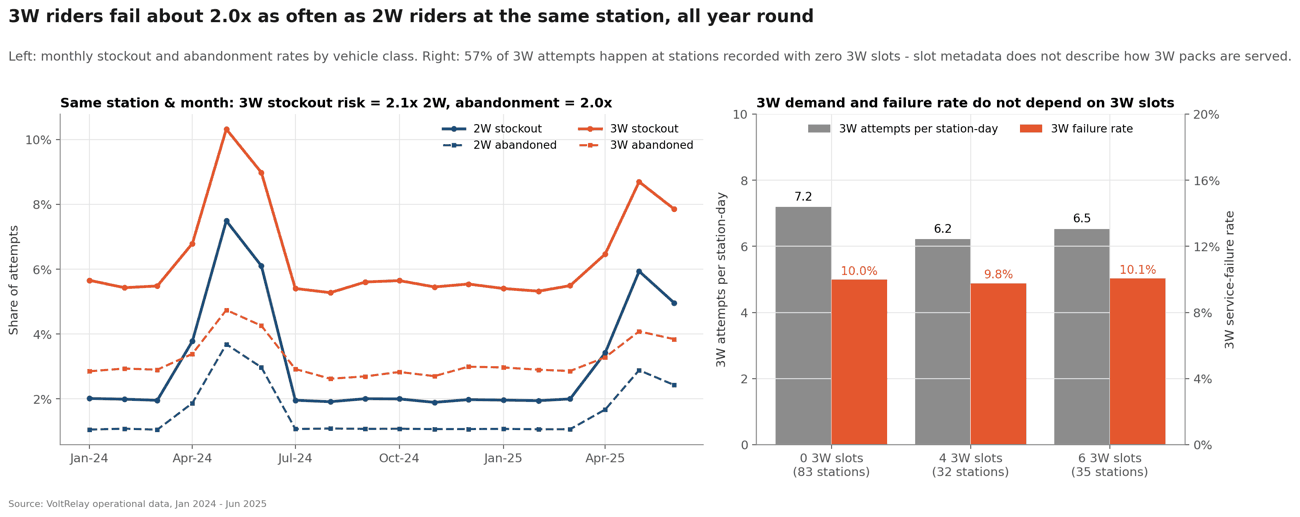

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_06_vehicle_class_3w.png')

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for cls, col in [("2W", PALETTE["primary"]), ("3W", PALETTE["accent"])]:
    s = vc.filter(pl.col("vehicle_class") == cls).sort("month")
    ax.plot(s["month"], s["stockout_rate"], color=col, lw=2.4, marker="o", ms=4, label=f"{cls} stockout")
    ax.plot(s["month"], s["abandon_rate"], color=col, lw=1.8, ls="--", marker="s", ms=3, label=f"{cls} abandoned")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Share of attempts")
ax.set_title(f"Same station & month: 3W stockout risk = {rr3['so'][0]:.1f}x 2W, abandonment = {rr3['ab'][0]:.1f}x", fontsize=11.5)
ax.legend(ncol=2, loc="upper right")
month_axis(ax)
ax = axes[1]
s3p = s3.to_pandas()
xx = np.arange(len(s3p))
ax.bar(xx - 0.2, s3p["att_3w_per_station_day"], 0.4, color=PALETTE["muted"], label="3W attempts per station-day")
ax2 = ax.twinx()
ax2.bar(xx + 0.2, s3p["failure_rate_3w"], 0.4, color=PALETTE["accent"], label="3W failure rate")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax2.set_ylim(0, 0.20)
ax2.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax2.grid(False)
ax2.spines["right"].set_visible(True)
for xi, (a, f_, n) in enumerate(zip(s3p["att_3w_per_station_day"], s3p["failure_rate_3w"], s3p["stations"])):
    ax.text(xi - 0.2, a + 0.2, f"{a:.1f}", ha="center", fontsize=10)
    ax2.text(xi + 0.2, f_ + 0.003, pct(f_, 1), ha="center", fontsize=10, color=PALETTE["accent"])
ax.set_xticks(xx)
ax.set_xticklabels([f"{s} 3W slots\n({n} stations)" for s, n in zip(s3p["slots_3w_grp"], s3p["stations"])])
ax.set_ylim(0, 10)
ax.set_ylabel("3W attempts per station-day")
ax2.set_ylabel("3W service-failure rate")
ax.set_title("3W demand and failure rate do not depend on 3W slots", fontsize=11.5)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", ncol=2, fontsize=9.5)
headline(fig, f"3W riders fail about {rr3['fail'][0]:.1f}x as often as 2W riders at the same station, all year round",
         f"Left: monthly stockout and abandonment rates by vehicle class. Right: {pct(z3['share_of_3w_attempts'], 0)} of 3W attempts "
         "happen at stations recorded with zero 3W slots - slot metadata does not describe how 3W packs are served.", top=0.84)
save_fig(fig, "q2_06_vehicle_class_3w")

## 8. Did service get worse? Like-for-like at a fixed set of stations
The Launch stations open for all of Jan-Jun 2024 and Jan-Jun 2025 give a same-station, same-month comparison
(the decommissioned station is excluded if it is a Launch site). Busiest = top 10% of Launch stations by attempts per
active day in H1-2024, with membership held fixed so the line is not distorted by new stations joining the group.

In [82]:
smf = SMC.group_by("station_id", "month").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("comp").sum()).join(
    attrs.select("station_id", "expansion_wave", "city", "charger_generation"), on="station_id")
fixed_ids = st_all.filter((pl.col("expansion_wave") == "Launch") & pl.col("decommissioned_date").is_null())["station_id"].to_list()
print("[YOY] decommissioned stations: " + ", ".join(f"{r['station_id']} ({r['expansion_wave']}, {r['decommissioned_date']})"
                                                     for r in st_all.filter(pl.col("decommissioned_date").is_not_null()).iter_rows(named=True)))
fx = (smf.filter(pl.col("station_id").is_in(fixed_ids), pl.col("month").dt.month() <= 6)
      .with_columns(pl.col("month").dt.year().alias("y"), pl.col("month").dt.month().alias("m")))
yoy = (fx.group_by("y", "m").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("station_id").n_unique().alias("stations"))
       .with_columns((pl.col("fail") / pl.col("att")).alias("fr")).sort("m", "y"))
days = {m: [31, 29 if y == 2024 else 28, 31, 30, 31, 30][m - 1] for y in (2024, 2025) for m in range(1, 7)}
yoy_w = yoy.pivot(on="y", index="m", values=["fr", "att"]).sort("m")
yoy_w = yoy_w.with_columns((pl.col("att_2025") / pl.col("att_2024")).alias("attempt_growth"), (pl.col("fr_2025") - pl.col("fr_2024")).alias("fr_change_pts"))
yoy_w.write_csv(TAB / "q2_yoy_fixed_stations.csv")
ptable(f"Fixed set of {len(fixed_ids)} Launch stations: failure rate by calendar month, 2024 vs 2025", yoy_w)
fxp = fx.to_pandas()
fxp["key"] = fxp["station_id"] + "_" + fxp["m"].astype(str)
fw_ = fxp.pivot_table(index="key", columns="y", values=["fail", "att"], aggfunc="sum").fillna(0)
fw_.columns = [f"{a}_{b}" for a, b in fw_.columns]
rr_yoy = mh_rr(fw_.reset_index(), "fail_2025", "att_2025", "fail_2024", "att_2024")
fw_hot = fw_[fw_.index.str.split("_").str[-1].astype(int).isin(HOT_MONTHS)]
rr_yoy_hot = mh_rr(fw_hot.reset_index(), "fail_2025", "att_2025", "fail_2024", "att_2024")
h1 = fx.group_by("y").agg(pl.col("att").sum(), pl.col("fail").sum())
h1d = {r["y"]: r for r in h1.iter_rows(named=True)}
print(f"[YOY] fixed {len(fixed_ids)} Launch stations, H1-2025 vs H1-2024: attempts x{h1d[2025]['att'] / h1d[2024]['att']:.2f}, failures "
      f"x{h1d[2025]['fail'] / h1d[2024]['fail']:.2f}; same station & month failure risk ratio (MH) {rr_yoy[0]:.3f} "
      f"(95% CI {rr_yoy[1]:.3f}-{rr_yoy[2]:.3f}); Apr-Jun only {rr_yoy_hot[0]:.3f} (CI {rr_yoy_hot[1]:.3f}-{rr_yoy_hot[2]:.3f})")
for r in yoy_w.filter(pl.col("m").is_in([1, 5, 6])).iter_rows(named=True):
    print(f"[YOY] month {r['m']}: fixed-set failure rate {pct(r['fr_2024'], 1)} (2024) vs {pct(r['fr_2025'], 1)} (2025); attempts x{r['attempt_growth']:.2f}")
hg1 = (fx.filter(pl.col("city").is_in(HOT_CITIES), pl.col("charger_generation") == "Gen1", pl.col("m") == 5)
       .group_by("y").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("station_id").n_unique().alias("n")).sort("y"))
for r in hg1.iter_rows(named=True):
    print(f"[YOY] May-{r['y']} hot-city Gen1 Launch stations: {r['att'] / r['n'] / 31:.1f} attempts per station-day, failure rate {pct(r['fail'] / r['att'])}")

net = smf.group_by("month").agg((pl.col("fail").sum() / pl.col("att").sum()).alias("Network"))
grp_lines = {"Network": net}
for wv, lab in [("Launch", "Launch stations"), ("Wave1_2024H2", "Wave 1 (2024H2)"), ("Wave2_2025H1", "Wave 2 (2025H1)")]:
    grp_lines[lab] = smf.filter(pl.col("expansion_wave") == wv).group_by("month").agg((pl.col("fail").sum() / pl.col("att").sum()).alias(lab))
H1_24 = pl.col("month") < pl.date(2024, 7, 1)
apd24 = (smf.filter(H1_24).group_by("station_id").agg(pl.col("att").sum())
         .join(smo.filter(H1_24).group_by("station_id").agg(pl.col("active_days").sum().alias("d24")), on="station_id")
         .with_columns((pl.col("att") / pl.col("d24")).alias("apd")).sort("apd", descending=True))
busiest = apd24.head(k10)["station_id"].to_list()
BUSY = f"Busiest {k10} in H1-24 (fixed set)"
grp_lines[BUSY] = smf.filter(pl.col("station_id").is_in(busiest)).group_by("month").agg(
    (pl.col("fail").sum() / pl.col("att").sum()).alias(BUSY))
bfx = fw_[fw_.index.str.rsplit("_", n=1).str[0].isin(busiest)]
rr_busy = mh_rr(bfx.reset_index(), "fail_2025", "att_2025", "fail_2024", "att_2024")
print(f"[YOY] busiest {k10} stations by H1-24 attempts/day: same station & month failure risk ratio 2025 vs 2024 (MH) = {rr_busy[0]:.3f} "
      f"(95% CI {rr_busy[1]:.3f}-{rr_busy[2]:.3f}); their H1-24 attempts/day median {apd24.head(k10)['apd'].median():.1f} vs other Launch "
      f"{apd24.tail(apd24.height - k10)['apd'].median():.1f}")
lines = net
for k, v in grp_lines.items():
    if k != "Network":
        lines = lines.join(v, on="month", how="left")
lines = lines.sort("month")
lines.write_csv(TAB / "q2_failure_rate_by_station_group_monthly.csv")
ptable("Monthly failure rate: network vs station groups", lines)
bz = SC.filter(pl.col("station_id").is_in(busiest))
print(f"[YOY] busiest {k10} stations (H1-2024 load): generations {dict(bz.group_by('charger_generation').len().iter_rows())}, cities "
      f"{dict(bz.group_by('city').len().iter_rows())}")
may25 = lines.filter(pl.col("month") == pl.date(2025, 5, 1)).row(0, named=True)
may24 = lines.filter(pl.col("month") == pl.date(2024, 5, 1)).row(0, named=True)
print(f"[YOY] May-24 network {pct(may24['Network'])} -> May-25 network {pct(may25['Network'])}; May-25 Launch {pct(may25['Launch stations'])}, "
      f"Wave1 {pct(may25['Wave 1 (2024H2)'])}, Wave2 {pct(may25['Wave 2 (2025H1)'])}; busiest {k10}: May-24 {pct(may24[BUSY])}, May-25 {pct(may25[BUSY])}")
mix25 = (smf.filter(pl.col("month") == pl.date(2025, 5, 1)).group_by("expansion_wave").agg(pl.col("att").sum())
         .with_columns((pl.col("att") / pl.col("att").sum()).alias("s")).sort("expansion_wave"))
print("[YOY] May-25 attempt mix by wave: " + ", ".join(f"{r['expansion_wave']} {pct(r['s'])}" for r in mix25.iter_rows(named=True)))

[YOY] decommissioned stations: STN-DEL-051 (Wave1_2024H2, 2025-05-20)

--- Fixed set of 90 Launch stations: failure rate by calendar month, 2024 vs 2025 ---
shape: (6, 7)
┌─────┬─────────┬─────────┬──────────┬──────────┬────────────────┬───────────────┐
│ m   ┆ fr_2024 ┆ fr_2025 ┆ att_2024 ┆ att_2025 ┆ attempt_growth ┆ fr_change_pts │
│ --- ┆ ---     ┆ ---     ┆ ---      ┆ ---      ┆ ---            ┆ ---           │
│ i8  ┆ f64     ┆ f64     ┆ u32      ┆ u32      ┆ f64            ┆ f64           │
╞═════╪═════════╪═════════╪══════════╪══════════╪════════════════╪═══════════════╡
│ 1   ┆ 0.0400  ┆ 0.0389  ┆ 108278   ┆ 217446   ┆ 2.0082         ┆ -0.0011       │
│ 2   ┆ 0.0401  ┆ 0.0388  ┆ 109271   ┆ 198263   ┆ 1.8144         ┆ -0.0013       │
│ 3   ┆ 0.0395  ┆ 0.0389  ┆ 121487   ┆ 209964   ┆ 1.7283         ┆ -0.0006       │
│ 4   ┆ 0.0648  ┆ 0.0664  ┆ 128991   ┆ 200550   ┆ 1.5548         ┆ 0.0016        │
│ 5   ┆ 0.1193  ┆ 0.1189  ┆ 143189   ┆ 212215   ┆ 1.4821         ┆ -0.0004       │

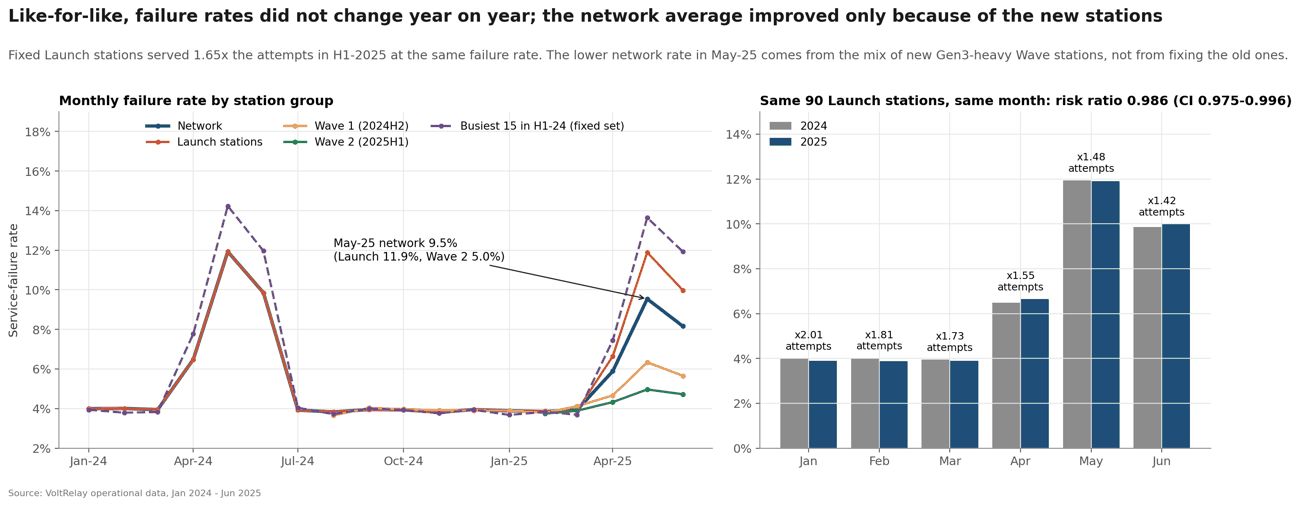

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_07_same_station_yoy.png')

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
style = {"Network": (PALETTE["primary"], 3.0, "-"), "Launch stations": (PALETTE["accent"], 2.0, "-"),
         "Wave 1 (2024H2)": (PALETTE["warn"], 2.0, "-"), "Wave 2 (2025H1)": (PALETTE["good"], 2.0, "-"),
         BUSY: ("#6C4F9E", 2.0, "--")}
lp = lines.to_pandas()
for col, (c, lw, ls) in style.items():
    ax.plot(lp["month"], lp[col], color=c, lw=lw, ls=ls, marker="o", ms=3.5, label=col)
ax.annotate(f"May-25 network {pct(may25['Network'])}\n(Launch {pct(may25['Launch stations'])}, Wave 2 {pct(may25['Wave 2 (2025H1)'])})",
            xy=(pd.Timestamp("2025-05-01"), may25["Network"]), xytext=(pd.Timestamp("2024-08-01"), 0.115), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="#222222"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0.02, 0.19)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.02))
ax.set_ylabel("Service-failure rate")
ax.set_title("Monthly failure rate by station group", fontsize=11.5)
ax.legend(fontsize=9.5, loc="upper center", ncol=3)
month_axis(ax)
ax = axes[1]
yp = yoy_w.to_pandas()
xx = np.arange(len(yp))
ax.bar(xx - 0.2, yp["fr_2024"], 0.4, color=PALETTE["muted"], label="2024")
ax.bar(xx + 0.2, yp["fr_2025"], 0.4, color=PALETTE["primary"], label="2025")
for xi, (a, b, gr) in enumerate(zip(yp["fr_2024"], yp["fr_2025"], yp["attempt_growth"])):
    ax.text(xi, max(a, b) + 0.004, f"x{gr:.2f}\nattempts", ha="center", fontsize=9)
ax.set_xticks(xx)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.15)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.02))
ax.set_title(f"Same {len(fixed_ids)} Launch stations, same month: risk ratio {rr_yoy[0]:.3f} (CI {rr_yoy[1]:.3f}-{rr_yoy[2]:.3f})", fontsize=11.5)
ax.legend(loc="upper left")
headline(fig, "Like-for-like, failure rates did not change year on year; the network average improved only because of the new stations",
         f"Fixed Launch stations served {h1d[2025]['att'] / h1d[2024]['att']:.2f}x the attempts in H1-2025 at the same failure rate. "
         "The lower network rate in May-25 comes from the mix of new Gen3-heavy Wave stations, not from fixing the old ones.", top=0.84)
save_fig(fig, "q2_07_same_station_yoy")

## 9. Customer-experience link: support tickets vs failure rates
Tickets are agent-categorised (not verified); we use `no_battery_available` and `long_queue`, the two categories
that should track stockouts and abandonment.

In [84]:
rho_nb = stats.spearmanr((SC["tk_no_battery"] / SC["att"] * 1000).to_numpy(), SC["stockout_rate"].to_numpy())
rho_lq = stats.spearmanr((SC["tk_long_queue"] / SC["att"] * 1000).to_numpy(), SC["abandon_rate"].to_numpy())
rho_all = stats.spearmanr(SC["nb_lq_tickets_per_1k"].to_numpy(), SC["failure_rate"].to_numpy())
print(f"[TK] in-window station-linked tickets: {tk.height:,} (no_battery_available {int(SC['tk_no_battery'].sum()):,}, "
      f"long_queue {int(SC['tk_long_queue'].sum()):,})")
print(f"[TK] station level (n={n_st}): Spearman no_battery tickets/1K attempts vs stockout rate = {rho_nb[0]:.3f} (p={rho_nb[1]:.2g}); "
      f"long_queue/1K vs abandonment rate = {rho_lq[0]:.3f} (p={rho_lq[1]:.2g}); both/1K vs failure rate = {rho_all[0]:.3f} (p={rho_all[1]:.2g})")
tk_sm = (tk.group_by("station_id", "month").agg((pl.col("category") == "no_battery_available").sum().alias("nb"),
                                                (pl.col("category") == "long_queue").sum().alias("lq"), pl.len().alias("all_tk")))
smt = (SMC.group_by("station_id", "month").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("so").sum(), pl.col("ab").sum())
       .join(tk_sm, on=["station_id", "month"], how="left").with_columns([pl.col(c).fill_null(0) for c in ["nb", "lq", "all_tk"]]))
rho_sm = stats.spearmanr((smt["nb"] / smt["att"]).to_numpy(), (smt["so"] / smt["att"]).to_numpy())
print(f"[TK] station-month level (n={smt.height:,}): Spearman no_battery tickets per attempt vs stockout rate = {rho_sm[0]:.3f} (p={rho_sm[1]:.2g})")
tkm = (smt.group_by("month").agg(pl.col("att").sum(), pl.col("fail").sum(), pl.col("so").sum(), pl.col("ab").sum(), pl.col("nb").sum(),
                                 pl.col("lq").sum(), pl.col("all_tk").sum())
       .with_columns((pl.col("nb") / pl.col("att") * 1000).alias("nb_per_1k"), (pl.col("lq") / pl.col("att") * 1000).alias("lq_per_1k"),
                     (pl.col("all_tk") / pl.col("att") * 1000).alias("tickets_per_1k"), (pl.col("fail") / pl.col("att")).alias("failure_rate"),
                     (pl.col("nb") / pl.col("so") * 100).alias("nb_per_100_stockouts"), (pl.col("lq") / pl.col("ab") * 100).alias("lq_per_100_abandons"))
       .sort("month"))
tkm.write_csv(TAB / "q2_tickets_monthly.csv")
ptable("Monthly tickets per 1K attempts vs failure rate", tkm.select("month", "att", "failure_rate", "nb_per_1k", "lq_per_1k", "tickets_per_1k",
                                                                   "nb_per_100_stockouts", "lq_per_100_abandons"))
rho_m = stats.spearmanr(tkm["nb_per_1k"].to_numpy(), tkm["failure_rate"].to_numpy())
print(f"[TK] monthly (n=18): Spearman no_battery tickets/1K vs failure rate = {rho_m[0]:.3f} (p={rho_m[1]:.2g})")
# denominator check: the rates above use station-linked tickets; include tickets without a station_id as well
tk_any = tickets().filter(pl.col("in_window") & ~pl.col("is_test"))
tka_m = tk_any.group_by("month").agg(pl.len().alias("all_tk_incl_unlinked"),
                                     (pl.col("category") == "no_battery_available").sum().alias("nb_incl_unlinked"))
tkm = tkm.join(tka_m, on="month", how="left").with_columns(
    (pl.col("all_tk_incl_unlinked") / pl.col("att") * 1000).alias("tickets_per_1k_incl_unlinked"),
    (pl.col("nb_incl_unlinked") / pl.col("so") * 100).alias("nb_per_100_stockouts_incl_unlinked"))
tkm.write_csv(TAB / "q2_tickets_monthly.csv")
print(f"[TK] in-window tickets: {tk_any.height:,}, of which {tk_any.filter(pl.col('station_id').is_null()).height:,} have no station_id; "
      f"station-level and monthly rates below use the {tk.height:,} station-linked tickets")
for mo in [pl.date(2024, 1, 1), pl.date(2024, 5, 1), pl.date(2025, 1, 1), pl.date(2025, 5, 1)]:
    r = tkm.filter(pl.col("month") == mo).row(0, named=True)
    print(f"[TK] {r['month']:%b-%y}: station-linked tickets/1K attempts {r['tickets_per_1k']:.2f} (no_battery {r['nb_per_1k']:.2f}, long_queue "
          f"{r['lq_per_1k']:.2f}); no_battery tickets per 100 stockouts {r['nb_per_100_stockouts']:.1f}; failure rate {pct(r['failure_rate'])} | "
          f"all tickets: {r['tickets_per_1k_incl_unlinked']:.2f} per 1K, no_battery {r['nb_per_100_stockouts_incl_unlinked']:.1f} per 100 stockouts")
SC.select("station_id", "city", "charger_generation", "expansion_wave", "att", "failure_rate", "stockout_rate", "abandon_rate",
          "tk_no_battery", "tk_long_queue", "nb_lq_tickets_per_1k", "tickets_per_1k").write_csv(TAB / "q2_tickets_vs_failures_station.csv")
# which categories drive the rise in tickets per attempt? same cool months (Jan-Mar) in both years
q1 = pl.col("month").dt.month() <= 3
att_q1 = {y: SMC.filter(q1, pl.col("month").dt.year() == y)["att"].sum() for y in (2024, 2025)}
cat_q1 = (tk.filter(q1).group_by(pl.col("month").dt.year().alias("y"), "category").len()
          .pivot(on="y", index="category", values="len").sort("category"))
cat_q1 = cat_q1.select("category", "2024", "2025").with_columns((pl.col("2024") / att_q1[2024] * 1000).alias("per_1k_Q1_24"),
                             (pl.col("2025") / att_q1[2025] * 1000).alias("per_1k_Q1_25")).sort("per_1k_Q1_25", descending=True)
cat_q1.write_csv(TAB / "q2_ticket_categories_q1_yoy.csv")
ptable("Tickets per 1K attempts by category, Jan-Mar 2024 vs Jan-Mar 2025 (failure rate flat at ~3.9% in both)", cat_q1)

[TK] in-window station-linked tickets: 41,161 (no_battery_available 10,921, long_queue 5,372)
[TK] station level (n=150): Spearman no_battery tickets/1K attempts vs stockout rate = 0.843 (p=9.5e-42); long_queue/1K vs abandonment rate = 0.670 (p=7.2e-21); both/1K vs failure rate = 0.833 (p=6.2e-40)
[TK] station-month level (n=2,037): Spearman no_battery tickets per attempt vs stockout rate = 0.547 (p=1.2e-159)

--- Monthly tickets per 1K attempts vs failure rate ---
shape: (18, 8)
┌────────────┬────────┬──────────────┬───────────┬───────────┬────────────────┬──────────────────────┬─────────────────────┐
│ month      ┆ att    ┆ failure_rate ┆ nb_per_1k ┆ lq_per_1k ┆ tickets_per_1k ┆ nb_per_100_stockouts ┆ lq_per_100_abandons │
│ ---        ┆ ---    ┆ ---          ┆ ---       ┆ ---       ┆ ---            ┆ ---                  ┆ ---                 │
│ date       ┆ u32    ┆ f64          ┆ f64       ┆ f64       ┆ f64            ┆ f64                  ┆ f64                 │
╞════════════╪═

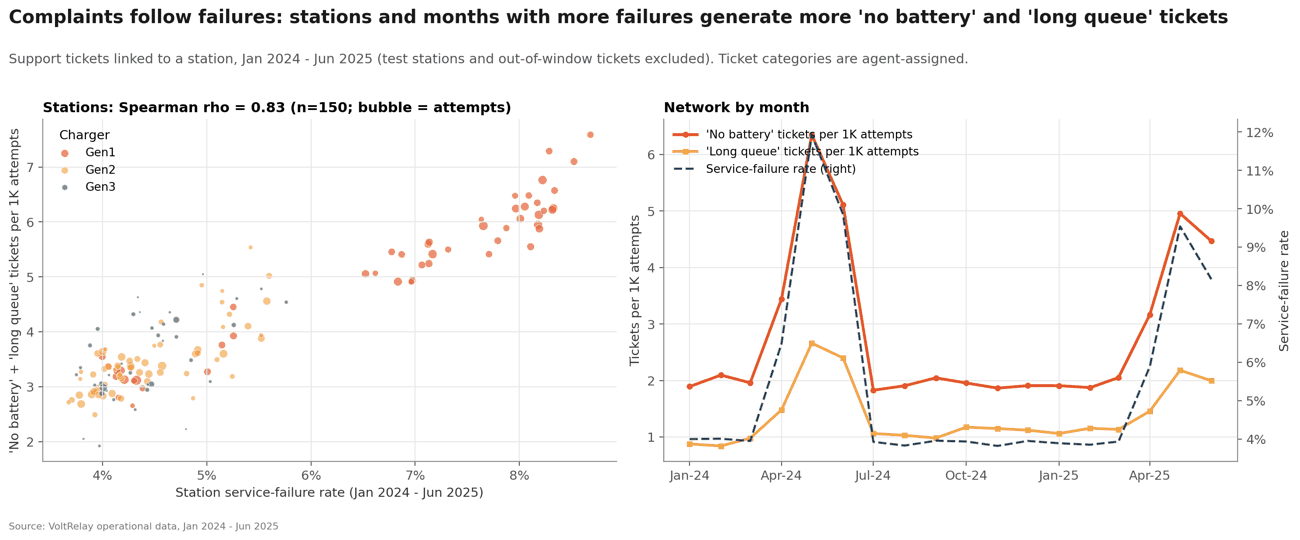

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_08_tickets_vs_failures.png')

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
ax = axes[0]
scp = SC.select("failure_rate", "nb_lq_tickets_per_1k", "charger_generation", "att").to_pandas()
for g in ["Gen1", "Gen2", "Gen3"]:
    s = scp[scp["charger_generation"] == g]
    ax.scatter(s["failure_rate"], s["nb_lq_tickets_per_1k"], s=s["att"] / 900, alpha=0.65, color=GEN_COLORS[g], label=g, edgecolor="white", lw=0.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Station service-failure rate (Jan 2024 - Jun 2025)")
ax.set_ylabel("'No battery' + 'long queue' tickets per 1K attempts")
ax.set_title(f"Stations: Spearman rho = {rho_all[0]:.2f} (n={n_st}; bubble = attempts)", fontsize=11.5)
ax.legend(title="Charger", loc="upper left")
ax = axes[1]
tp = tkm.to_pandas()
ax.plot(tp["month"], tp["nb_per_1k"], color=PALETTE["accent"], lw=2.4, marker="o", ms=4, label="'No battery' tickets per 1K attempts")
ax.plot(tp["month"], tp["lq_per_1k"], color=PALETTE["warn"], lw=2.2, marker="s", ms=3.5, label="'Long queue' tickets per 1K attempts")
ax.set_ylabel("Tickets per 1K attempts")
ax2 = ax.twinx()
ax2.plot(tp["month"], tp["failure_rate"], color=PALETTE["primary"], lw=1.8, ls="--", label="Service-failure rate (right)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.set_ylabel("Service-failure rate")
h1_, l1_ = ax.get_legend_handles_labels()
h2_, l2_ = ax2.get_legend_handles_labels()
ax.legend(h1_ + h2_, l1_ + l2_, loc="upper left", fontsize=9.5)
ax.set_title("Network by month", fontsize=11.5)
month_axis(ax)
headline(fig, "Complaints follow failures: stations and months with more failures generate more 'no battery' and 'long queue' tickets",
         "Support tickets linked to a station, Jan 2024 - Jun 2025 (test stations and out-of-window tickets excluded). Ticket categories are agent-assigned.",
         top=0.84)
save_fig(fig, "q2_08_tickets_vs_failures")

## 2b. Figure: queue wait, patience and load

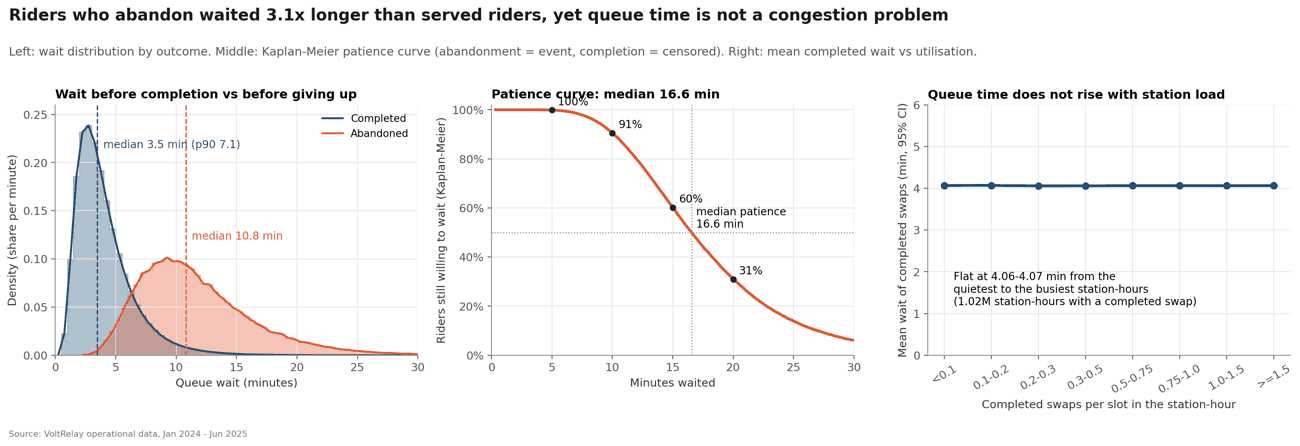

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q2_01_queue_wait_patience.png')

In [86]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
ax = axes[0]
bins = np.arange(0, 40.5, 0.5)
qh = (ev.filter(pl.col("event_type").is_in(["swap_completed", "abandoned_queue"]))
      .with_columns((pl.col("queue_wait_sec") / 30).floor().alias("b")).group_by("event_type", "b").agg(pl.len().alias("n")).collect().to_pandas())
for et, col, lab in [("swap_completed", PALETTE["primary"], "Completed"), ("abandoned_queue", PALETTE["accent"], "Abandoned")]:
    s = qh[qh["event_type"] == et].sort_values("b")
    ax.fill_between(s["b"] * 0.5 + 0.25, s["n"] / s["n"].sum() / 0.5, step="mid", alpha=0.35, color=col)
    ax.plot(s["b"] * 0.5 + 0.25, s["n"] / s["n"].sum() / 0.5, color=col, lw=1.8, label=lab)
ax.axvline(qc["p50_s"] / 60, color=PALETTE["primary"], ls="--", lw=1.2)
ax.axvline(qa["p50_s"] / 60, color=PALETTE["accent"], ls="--", lw=1.2)
ax.text(qc["p50_s"] / 60 + 0.5, 0.215, f"median {qc['p50_s'] / 60:.1f} min (p90 {qc['p90_s'] / 60:.1f})", color=PALETTE["primary"], fontsize=10)
ax.text(qa["p50_s"] / 60 + 0.5, 0.12, f"median {qa['p50_s'] / 60:.1f} min", color=PALETTE["accent"], fontsize=10)
ax.set_ylim(0, 0.26)
ax.set_xlim(0, 30)
ax.set_xlabel("Queue wait (minutes)")
ax.set_ylabel("Density (share per minute)")
ax.set_title("Wait before completion vs before giving up", fontsize=11.5)
ax.legend(loc="upper right")
ax = axes[1]
ax.plot(t_s / 60, S_km, color=PALETTE["accent"], lw=2.6)
for m in (5, 10, 15, 20):
    ax.plot(m, S_at(m), "o", color="#222222", ms=5)
    ax.text(m + 0.5, S_at(m) + 0.02, pct(S_at(m), 0), fontsize=10)
if np.isfinite(km_med):
    ax.axhline(0.5, color="#888888", ls=":", lw=1)
    ax.axvline(km_med, color="#888888", ls=":", lw=1)
    ax.text(km_med + 0.4, 0.52, f"median patience\n{km_med:.1f} min", fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 30)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Minutes waited")
ax.set_ylabel("Riders still willing to wait (Kaplan-Meier)")
ax.set_title(f"Patience curve: median {km_med:.1f} min", fontsize=11.5)
ax = axes[2]
qup = qu.to_pandas()
ax.errorbar(range(len(qup)), qup["mean_wait_min"], yerr=[qup["mean_wait_min"] - qup["ci_lo_min"], qup["ci_hi_min"] - qup["mean_wait_min"]],
            color=PALETTE["primary"], lw=2.6, marker="o", capsize=3)
ax.set_ylim(0, 6)
ax.set_xticks(range(len(qup)))
ax.set_xticklabels(qup["util_bin"], rotation=30)
ax.set_xlabel("Completed swaps per slot in the station-hour")
ax.set_ylabel("Mean wait of completed swaps (min, 95% CI)")
ax.text(0.2, 1.2, f"Flat at {qup['mean_wait_min'].min():.2f}-{qup['mean_wait_min'].max():.2f} min from the\nquietest to the busiest "
        f"station-hours\n({SH.filter(pl.col('comp') > 0).height / 1e6:.2f}M station-hours with a completed swap)", fontsize=10)
ax.set_title("Queue time does not rise with station load", fontsize=11.5)
headline(fig, f"Riders who abandon waited {qa['p50_s'] / qc['p50_s']:.1f}x longer than served riders, yet queue time is not a congestion problem",
         "Left: wait distribution by outcome. Middle: Kaplan-Meier patience curve (abandonment = event, completion = censored). "
         "Right: mean completed wait vs utilisation.", top=0.83)
save_fig(fig, "q2_01_queue_wait_patience")

## 10. Key numbers recap

In [87]:
# sizing for recommendations (two summers in the data: Apr-Jun 2024 and Apr-Jun 2025)
g3h = seg.filter(pl.col("segment") == "Apr-Jun, hot-city Gen3").row(0, named=True)
avoid_g1 = g1["att"] * (g1["failure_rate"] - g3h["failure_rate"])
print(f"[SIZE] if hot-city Gen1 stations had failed at the hot-city Gen3 rate in Apr-Jun ({pct(g3h['failure_rate'], 2)} [Apr-Jun 2025, the only "
      f"summer with Gen3] vs {pct(g1['failure_rate'], 2)} [both summers]), failures avoided = {avoid_g1:,.0f} over two summers "
      f"(~{avoid_g1 / 2:,.0f} per summer on average; {pct(avoid_g1 / N_FAIL)} of all failures)")
AVOID_Y = {}
for y_ in (2024, 2025):
    s = SMCs.filter(pl.col("segment") == "Apr-Jun, hot-city Gen1", yr == y_)
    a_, f_ = s["att"].sum(), s["fail"].sum()
    AVOID_Y[y_] = a_ * (f_ / a_ - g3h["failure_rate"])
    print(f"[SIZE] Apr-Jun {y_} volume: hot-city Gen1 attempts {a_:,}, failure rate {pct(f_ / a_, 2)}; avoidable at the hot-city Gen3 rate = "
          f"{AVOID_Y[y_]:,.0f}")
# like-for-like alternative: within city-month MH risk ratios (Apr-Jun 2025), by city -> retrofit priority list
g1_st = st_all.filter(pl.col("charger_generation") == "Gen1").group_by("city").agg(pl.len().alias("gen1_stations"))
prio = (pl.from_pandas(gen_city[gen_city["city"].isin(HOT_CITIES + ["Pune"])])
        .join(g1_st, on="city", how="left")
        .with_columns((pl.col("gen1_failures") * (1 - 1 / pl.col("gen1_vs_gen3_rr"))).alias("avoidable_2025_mh"))
        .with_columns((pl.col("avoidable_2025_mh") / pl.col("gen1_stations")).alias("avoidable_2025_per_station"),
                      (pl.col("gen1_failures") / pl.col("gen1_attempts")).alias("gen1_failure_rate_AJ25"))
        .sort("avoidable_2025_per_station", descending=True))
prio.write_csv(TAB / "q2_retrofit_priority_by_city.csv")
ptable("Retrofit priority by city (Apr-Jun 2025, MH counterfactual: Gen1 failures x (1 - 1/RR))", prio)
mh_hot = gen_city[gen_city["city"] == "Hot cities pooled"].iloc[0]
print(f"[SIZE] MH counterfactual, Apr-Jun 2025, hot cities pooled: {mh_hot['gen1_failures']:,} Gen1 failures x (1 - 1/{mh_hot['gen1_vs_gen3_rr']:.2f}) = "
      f"{mh_hot['gen1_failures'] * (1 - 1 / mh_hot['gen1_vs_gen3_rr']):,.0f}; by city: " + ", ".join(
          f"{r['city']} {r['avoidable_2025_mh']:,.0f} ({r['gen1_stations']} sites, {r['avoidable_2025_per_station']:,.0f}/site, RR {r['gen1_vs_gen3_rr']:.2f})"
          for r in prio.iter_rows(named=True)))
h15 = hot15["station_id"].to_list()
h15_hot = SMCs.filter(pl.col("station_id").is_in(h15), pl.col("segment") == "Apr-Jun, hot-city Gen1")
avoid_h15 = h15_hot["att"].sum() * (h15_hot["fail"].sum() / h15_hot["att"].sum() - g3h["failure_rate"])
print(f"[SIZE] 15 largest hot-city Gen1 sites by excess: Apr-Jun attempts {h15_hot['att'].sum():,}, failure rate "
      f"{pct(h15_hot['fail'].sum() / h15_hot['att'].sum(), 2)}; avoidable at the hot-city Gen3 rate = {avoid_h15:,.0f} over two summers "
      f"(~{avoid_h15 / 2:,.0f} per summer) - large because they are big, not because they fail more than their city peers")
c3 = v_cool.filter(pl.col("vehicle_class") == "3W").row(0, named=True)
c2 = v_cool.filter(pl.col("vehicle_class") == "2W").row(0, named=True)
gap3 = c3["attempts"] * (c3["stockout_rate"] - c2["stockout_rate"])
n_cool_m = bm.filter(~pl.col("m").is_in(HOT_MONTHS)).height
print(f"[SIZE] 3W stockout gap vs 2W in Jul-Mar: {c3['attempts']:,} 3W attempts x ({pct(c3['stockout_rate'], 2)} - {pct(c2['stockout_rate'], 2)}) = "
      f"{gap3:,.0f} extra 3W stockouts over all {n_cool_m} cool months in the data (Jan-Mar 2024 + Jul 2024-Mar 2025)")
cs9 = (ev.filter(pl.col("month").is_between(pl.date(2024, 7, 1), pl.date(2025, 3, 1)))
       .group_by("vehicle_class").agg(pl.len().alias("n"), pl.col("is_stockout").mean().alias("so")).collect())
cs9d = {r["vehicle_class"]: r for r in cs9.iter_rows(named=True)}
GAP3_SEASON = cs9d["3W"]["n"] * (cs9d["3W"]["so"] - cs9d["2W"]["so"])
print(f"[SIZE] one cool season (Jul-24 to Mar-25, 9 months): {cs9d['3W']['n']:,} 3W attempts x ({pct(cs9d['3W']['so'], 2)} - "
      f"{pct(cs9d['2W']['so'], 2)}) = {GAP3_SEASON:,.0f} extra 3W stockouts per cool season")

[SIZE] if hot-city Gen1 stations had failed at the hot-city Gen3 rate in Apr-Jun (5.06% [Apr-Jun 2025, the only summer with Gen3] vs 15.31% [both summers]), failures avoided = 45,154 over two summers (~22,577 per summer on average; 21.3% of all failures)
[SIZE] Apr-Jun 2024 volume: hot-city Gen1 attempts 172,800, failure rate 15.48%; avoidable at the hot-city Gen3 rate = 17,996
[SIZE] Apr-Jun 2025 volume: hot-city Gen1 attempts 267,903, failure rate 15.20%; avoidable at the hot-city Gen3 rate = 27,158

--- Retrofit priority by city (Apr-Jun 2025, MH counterfactual: Gen1 failures x (1 - 1/RR)) ---
shape: (4, 11)
┌───────────┬─────────────────┬────────┬────────┬──────────────┬───────────────┬───────────────┬───────────────┬───────────────────┬────────────────────────────┬────────────────────────┐
│ city      ┆ gen1_vs_gen3_rr ┆ ci_lo  ┆ ci_hi  ┆ month_strata ┆ gen1_attempts ┆ gen1_failures ┆ gen1_stations ┆ avoidable_2025_mh ┆ avoidable_2025_per_station ┆ gen1_failure_rate_AJ25 │
│ ---  

### 10b. What does a rider do after a failure? (is a failure a deferred swap or a lost one?)
For every attempt, the gap to the same rider's next completed swap anywhere in the network. If failed riders came
back soon (a retry), a failure would mostly be a delay; if not, it is a lost transaction. Attempts after
2025-06-01 are excluded so every attempt has at least a month of follow-up.

In [88]:
RD = (events(["rider_id", "event_ts", "event_type", "signup_date"]).sort("rider_id", "event_ts")
      .with_columns(pl.col("event_type").is_in(FAIL_TYPES).alias("fl"), (pl.col("event_type") == "swap_completed").alias("cp"))
      .with_columns(pl.when(pl.col("cp")).then(pl.col("event_ts")).alias("cts"))
      .with_columns(pl.col("cts").shift(-1).over("rider_id").alias("cts_n"), pl.int_range(pl.len()).over("rider_id").alias("k"))
      .with_columns(pl.col("cts_n").backward_fill().over("rider_id").alias("next_cts"))
      .with_columns((pl.col("next_cts") - pl.col("event_ts")).dt.total_minutes().alias("gap_min"))
      .filter(pl.col("fl") | pl.col("cp"))
      .select("fl", "cp", "k", "event_ts", "signup_date", "gap_min")
      .collect(engine="streaming"))
nx = (RD.filter(pl.col("event_ts") < pl.datetime(2025, 6, 1)).group_by("fl").agg(
    pl.len().alias("n"), (pl.col("gap_min") <= 60).mean().alias("w60"), (pl.col("gap_min") <= 1440).mean().alias("w24h"),
    (pl.col("gap_min").median() / 60).alias("med_h"), pl.col("gap_min").is_null().mean().alias("never")).sort("fl", descending=True))
NX = {r["fl"]: r for r in nx.iter_rows(named=True)}
for k_, lab in [(True, "after a service failure"), (False, "after a completed swap")]:
    r = NX[k_]
    print(f"[RETRY] {lab} (n={r['n']:,}): same rider completes a swap within 60 min {pct(r['w60'])}, within 24 h {pct(r['w24h'])}; "
          f"median gap to next completed swap {r['med_h']:.1f} h; never again {pct(r['never'])}")
fa = (RD.filter(pl.col("k") == 0, pl.col("event_ts") < pl.datetime(2025, 5, 1), pl.col("signup_date") >= pl.date(2024, 1, 1))
      .group_by("fl").agg(pl.len().alias("n"), (pl.col("gap_min") <= 30 * 1440).mean().alias("ret30")).sort("fl", descending=True))
print("[RETRY] new riders (signed up 2024+, first attempt before May-25), completed a further swap within 30 days: " + ", ".join(
    f"{'first attempt failed' if r['fl'] else 'first attempt completed'} {pct(r['ret30'])} (n={r['n']:,})" for r in fa.iter_rows(named=True))
      + "  [cross-link for Q6; short horizon only]")
del RD
REV_G1 = (events(["city", "charger_generation", "month", "is_completed", "amount_charged_inr"])
          .filter(pl.col("is_completed"), pl.col("city").is_in(HOT_CITIES), pl.col("charger_generation") == "Gen1",
                  pl.col("month") >= pl.date(2025, 4, 1))
          .select(pl.col("amount_charged_inr").mean()).collect().item())
print(f"[RETRY] mean revenue per completed swap, hot-city Gen1, Apr-Jun 2025: Rs {REV_G1:.1f}; avoidable failures at 2025 volume "
      f"({AVOID_Y[2025]:,.0f}) x revenue = Rs {AVOID_Y[2025] * REV_G1 / 1e6:.2f}M per summer of revenue (not margin)")

print("\n================ Q2 KEY NUMBERS ================")
print(f"Attempts {N_ATT:,}; service failures {N_FAIL:,} ({pct(FR_ALL, 2)}); 2W {pct(FR_2W, 2)}, 3W {pct(FR_3W, 2)}")
print(f"Jul-Mar baseline {pct(BASE_FR, 2)}; excess failures {tot_exc:,.0f} ({pct(tot_exc / N_FAIL)} of all failures)")
print(f"Apr-Jun hot-city Gen1 ({g1['stations']} stations): {pct(g1['share_aprjun_attempts'])} of Apr-Jun attempts -> {pct(g1['share_excess'])} "
      f"of excess failures; the same stations over 18 months: {pct(st36['att'].sum() / N_ATT)} of attempts, {pct(st36['fail'].sum() / N_FAIL)} of failures")
print(f"Gen1 station-days with peak cabinet >=45C: stockout {pct(SD_G1_HI, 2)} vs {pct(SD_G1_LO, 2)} when <40C (day level); hourly zero stock "
      f"within the same station-day: MH RR {HR_SD['rr']:.2f}, +window {HR_SDE['rr']:.2f} (no hour-level link)")
print(f"Avoidable failures at the hot-city Gen3 rate: 2024 volume {AVOID_Y[2024]:,.0f}, 2025 volume {AVOID_Y[2025]:,.0f}; "
      f"3W cool-season stockout gap {GAP3_SEASON:,.0f} (Jul-24 to Mar-25)")
print(f"Fixed Launch stations YoY risk ratio {rr_yoy[0]:.3f} (CI {rr_yoy[1]:.3f}-{rr_yoy[2]:.3f})")
print(f"3W vs 2W failure RR {rr3['fail'][0]:.2f}; median patience {km_med:.1f} min")
print(f"Runtime {time.time() - T0:.1f}s")

[RETRY] after a service failure (n=184,776): same rider completes a swap within 60 min 4.5%, within 24 h 55.7%; median gap to next completed swap 22.7 h; never again 0.4%
[RETRY] after a completed swap (n=3,283,479): same rider completes a swap within 60 min 4.6%, within 24 h 57.2%; median gap to next completed swap 22.3 h; never again 0.2%
[RETRY] new riders (signed up 2024+, first attempt before May-25), completed a further swap within 30 days: first attempt failed 99.8% (n=646), first attempt completed 99.8% (n=13,084)  [cross-link for Q6; short horizon only]
[RETRY] mean revenue per completed swap, hot-city Gen1, Apr-Jun 2025: Rs 62.7; avoidable failures at 2025 volume (27,158) x revenue = Rs 1.70M per summer of revenue (not margin)

================ Q2 KEY NUMBERS ================
Attempts 3,814,982; service failures 211,849 (5.55%); 2W 5.02%, 3W 9.95%
Jul-Mar baseline 3.91%; excess failures 62,558 (29.5% of all failures)
Apr-Jun hot-city Gen1 (36 stations): 31.6% of Apr-Jun attem

In [89]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 226 objects


## 7. Q3 · Station & geographic patterns

# Q3 - Station & geographic patterns, expansion-wave effectiveness, competitor entry

**Question.** Stations differ in charger generation, location type, commissioning time and are unevenly spread across
cities. How do these relate to service performance, battery turnaround time and complaints? Did the two expansion
waves improve service where riders needed it, or where sites were easiest to open? What did competitor entry do?

**Approach.**
1. *Battery turnaround* - hourly telemetry (telemetry_status == 'ok' only): charge minutes vs cabinet temperature by
   charger generation (piecewise-linear "hinge" fit), season exposure, quarantines, chargers online; then link hot
   hours to stockouts against same-city same-day Gen2/Gen3 stations.
2. *Service & complaints by station attributes* - station-month panel, WLS with city and month fixed effects and a
   utilisation control (attempts per slot-day), cluster-robust SE by station, so generation / location / host /
   connectivity / wave are separated rather than read off confounded raw means.
3. *Uneven distribution* - supply (stations, slots) vs demand (riders by home zone, attempts, failures) by zone.
4. *Expansion waves* - placement vs pre-wave need (same-season need: failures are an Apr-Jun phenomenon);
   what drives new-station utilisation (zone demand vs site type); utilisation and fixed cost per swap of new vs
   legacy stations; DiD on legacy stations; network average vs busiest/hotspot stations, in rates AND counts, and
   whether hotspot failure rates respond to load at all.
5. *Competitor entry* (10 stations, 2025-01-15) - DiD + event study vs same-city same-wave stations, permutation test,
   station-specific-trend robustness.

*Revision after verification (see outputs/findings/q3_verification.md)*: Wave-2 need is measured on the same-season
Apr-Jun 2024 rate (the Jul-Dec rate is flat noise), the siting recommendation is based on a utilisation model of the
60 new stations, the headline separates "dilution" from "placement", and several labels/figure titles were corrected.

In [90]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

try:
    ROOT = PROJECT_ROOT
except NameError:  # notebook / Colab
    ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F403

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import polars as pl  # noqa: E402
import statsmodels.formula.api as smf  # noqa: E402
from scipy import stats  # noqa: E402

warnings.filterwarnings("ignore")
set_style()
T0 = time.time()
pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_rows(60)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)


def say(*a):
    print(f"[{time.time()-T0:5.1f}s]", *a, flush=True)


GEN_COLORS = {"Gen1": SERIES[1], "Gen2": SERIES[0], "Gen3": SERIES[2]}
GEN_MARK = {"Gen1": "o", "Gen2": "s", "Gen3": "^"}
WAVE_COLORS = {"Launch": PALETTE["muted"], "Wave1_2024H2": SERIES[0], "Wave2_2025H1": SERIES[3]}
WAVE_LABEL = {"Launch": "Legacy (Launch 2023)", "Wave1_2024H2": "Wave 1 (Aug-Oct 2024)", "Wave2_2025H1": "Wave 2 (Feb-Apr 2025)"}
HOT_C = 40.0  # cabinet-temperature threshold (validated by the hinge fit below)

st = stations().filter(~pl.col("is_test")).with_columns((pl.col("slots_2w") + pl.col("slots_3w")).alias("slots"))
say("real stations:", st.height, "| by wave:", dict(st.group_by("expansion_wave").len().iter_rows()))

[  0.0s] real stations: 150 | by wave: {'Wave2_2025H1': 30, 'Wave1_2024H2': 30, 'Launch': 90}


## 1. Battery turnaround: thermal derating by charger generation
`avg_charge_minutes` is the turnaround of a pack in the cabinet. We bin cabinet temperature (1 C) and fit, per
generation, `charge_min = a + b * max(0, T - k)` choosing the knot k by least squares.

In [91]:
H = (hourly(["station_id", "city", "charger_generation", "season", "month", "date", "hour", "telemetry_status",
             "cabinet_temp_c", "ambient_temp_c", "avg_charge_minutes", "packs_quarantined", "chargers_online",
             "slots_2w", "slots_3w", "outage_minutes"])
     .filter(pl.col("telemetry_status") == "ok").collect())
n_all = hourly(["station_id"]).select(pl.len()).collect().item()
say(f"telemetry rows ok: {H.height:,} of {n_all:,} ({H.height/n_all:.1%}); partial/missing excluded (never zero-filled)")

# binned curve
curve = (H.with_columns(pl.col("cabinet_temp_c").floor().alias("t_bin"))
         .group_by("charger_generation", "t_bin")
         .agg(pl.len().alias("station_hours"), pl.col("avg_charge_minutes").mean().alias("charge_min"),
              pl.col("avg_charge_minutes").quantile(0.9).alias("charge_min_p90"),
              (pl.col("packs_quarantined") > 0).mean().alias("quarantine_hour_share"))
         .sort("charger_generation", "t_bin"))
curve.write_csv(TAB / "q3_thermal_derating_curve.csv")

# hinge fit per generation
hinge_rows = []
for g in ["Gen1", "Gen2", "Gen3"]:
    d = H.filter(pl.col("charger_generation") == g)
    T = d["cabinet_temp_c"].to_numpy().astype(float); y = d["avg_charge_minutes"].to_numpy().astype(float)
    best = None
    for k in np.arange(30, 50.01, 0.5):
        X = np.column_stack([np.ones_like(T), np.clip(T - k, 0, None)])
        coef, res, *_ = np.linalg.lstsq(X, y, rcond=None)
        sse = float(((y - X @ coef) ** 2).sum())
        if best is None or sse < best[0]:
            best = (sse, k, coef)
    sse, k, (a, b) = best
    r2 = 1 - sse / float(((y - y.mean()) ** 2).sum())
    hinge_rows.append({"generation": g, "station_hours": len(y), "knot_c": k, "base_charge_min": a, "slope_min_per_c": b,
                       "charge_min_at_45c": a + b * max(0, 45 - k), "charge_min_at_50c": a + b * max(0, 50 - k),
                       "capacity_at_50c_vs_base": a / (a + b * max(0, 50 - k)), "r2": r2})
hinge = pd.DataFrame(hinge_rows)
hinge.to_csv(TAB / "q3_thermal_hinge_fit.csv", index=False)
say("Hinge fit (charge minutes = base + slope x max(0, T - knot)):\n" + hinge.round(3).to_string(index=False))
# robustness: the Gen1 slope depends on the knot grid (slope and knot trade off); refit on a finer 0.25 C grid
d = H.filter(pl.col("charger_generation") == "Gen1")
T = d["cabinet_temp_c"].to_numpy().astype(float); y = d["avg_charge_minutes"].to_numpy().astype(float)
best = None
for k in np.arange(38, 45.01, 0.25):
    X = np.column_stack([np.ones_like(T), np.clip(T - k, 0, None)])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    sse = float(((y - X @ coef) ** 2).sum())
    if best is None or sse < best[0]:
        best = (sse, k, coef)
sse25, k25, (a25, b25) = best
emp50 = float(y[(T >= 49) & (T <= 51)].mean())
say(f"Gen1 hinge on a 0.25 C knot grid: knot {k25:.2f} C, base {a25:.1f} min, slope {b25:.2f} min/C, {a25 + b25 * (50 - k25):.1f} min at 50 C "
    f"(R2 {1 - sse25 / float(((y - y.mean()) ** 2).sum()):.3f}) vs 0.5 C grid: knot {hinge.loc[0, 'knot_c']:.2f} C, slope "
    f"{hinge.loc[0, 'slope_min_per_c']:.2f} min/C -> quote 'about {b25:.1f}-{hinge.loc[0, 'slope_min_per_c']:.1f} min/C'; "
    f"empirical Gen1 mean at 49-51 C = {emp50:.1f} min (the 50 C level is robust)")

# exposure: share of station-hours above 40 C by generation x season, and by city in summer
expo = (H.group_by("charger_generation", "season")
        .agg(pl.len().alias("station_hours"), (pl.col("cabinet_temp_c") > HOT_C).mean().alias("hot_share"),
             pl.col("cabinet_temp_c").mean().alias("cabinet_mean"), pl.col("avg_charge_minutes").mean().alias("charge_min"))
        .sort("charger_generation", "season"))
say("Exposure by generation x season:\n" + str(expo))
expo_city = (H.filter(pl.col("season") == "Summer").group_by("city")
             .agg((pl.col("cabinet_temp_c") > HOT_C).mean().alias("summer_hot_share"),
                  pl.col("cabinet_temp_c").mean().alias("summer_cabinet_mean")).sort("summer_hot_share", descending=True))
expo_city_w = (H.filter(pl.col("season") == "Winter").group_by("city")
               .agg((pl.col("cabinet_temp_c") > HOT_C).mean().alias("winter_hot_share")))
expo_city = expo_city.join(expo_city_w, on="city")
expo_city.write_csv(TAB / "q3_thermal_exposure_city.csv")
say("Share of station-hours with cabinet > 40 C, summer vs winter, by city:\n" + str(expo_city))
gen1_summer = H.filter((pl.col("charger_generation") == "Gen1") & (pl.col("season") == "Summer"))
gen1_summer_hot = gen1_summer.filter(pl.col("cabinet_temp_c") > HOT_C)
say(f"Gen1 summer: {gen1_summer_hot.height/gen1_summer.height:.1%} of station-hours > 40 C; mean charge time in those hours "
    f"{gen1_summer_hot['avg_charge_minutes'].mean():.1f} min vs {gen1_summer.filter(pl.col('cabinet_temp_c') <= HOT_C)['avg_charge_minutes'].mean():.1f} min below 40 C")
# when in the day does it get hot
hot_by_hour = (H.filter(pl.col("season") == "Summer").group_by("hour").agg((pl.col("cabinet_temp_c") > HOT_C).mean().alias("hot_share")).sort("hour"))
pk = hot_by_hour.sort("hot_share", descending=True).head(1)
say(f"Summer hot-hour share peaks at hour {pk['hour'][0]} ({pk['hot_share'][0]:.1%}); at 06:00 = "
    f"{hot_by_hour.filter(pl.col('hour') == 6)['hot_share'][0]:.1%}")

# quarantines and chargers online
q = (H.with_columns((pl.col("cabinet_temp_c") > HOT_C).alias("hot"))
     .group_by("hot").agg(pl.len().alias("station_hours"), (pl.col("packs_quarantined") > 0).mean().alias("quarantine_hour_share"),
                          pl.col("packs_quarantined").sum().alias("quarantined_pack_hours"))).sort("hot")
say("Quarantines by hot / not hot hours (packs_quarantined is an hourly count, so its sum is quarantined PACK-HOURS, "
    "not distinct packs):\n" + str(q))
co = (H.group_by("charger_generation").agg(
    (pl.col("chargers_online") < pl.col("slots_2w") + pl.col("slots_3w")).mean().alias("share_hours_chargers_below_slots"),
    (pl.col("outage_minutes") > 0).mean().alias("share_hours_with_outage")).sort("charger_generation"))
say("Chargers online below installed slots / outages by generation:\n" + str(co))

[  0.0s] telemetry rows ok: 1,415,325 of 1,461,456 (96.8%); partial/missing excluded (never zero-filled)


[  1.8s] Hinge fit (charge minutes = base + slope x max(0, T - knot)):
generation  station_hours  knot_c  base_charge_min  slope_min_per_c  charge_min_at_45c  charge_min_at_50c  capacity_at_50c_vs_base    r2
      Gen1         649442  41.500           88.095            9.462            121.210            168.518                    0.523 0.884
      Gen2         644645  40.000           63.995            0.959             68.789             73.583                    0.870 0.094
      Gen3         121238  40.500           42.016            0.176             42.809             43.690                    0.962 0.024


[  2.4s] Gen1 hinge on a 0.25 C knot grid: knot 41.25 C, base 88.0 min, slope 9.16 min/C, 168.2 min at 50 C (R2 0.885) vs 0.5 C grid: knot 41.50 C, slope 9.46 min/C -> quote 'about 9.2-9.5 min/C'; empirical Gen1 mean at 49-51 C = 166.1 min (the 50 C level is robust)


[  2.4s] Exposure by generation x season:
shape: (12, 6)
┌────────────────────┬──────────────┬───────────────┬───────────┬──────────────┬────────────┐
│ charger_generation ┆ season       ┆ station_hours ┆ hot_share ┆ cabinet_mean ┆ charge_min │
│ ---                ┆ ---          ┆ ---           ┆ ---       ┆ ---          ┆ ---        │
│ str                ┆ str          ┆ u32           ┆ f64       ┆ f32          ┆ f32        │
╞════════════════════╪══════════════╪═══════════════╪═══════════╪══════════════╪════════════╡
│ Gen1               ┆ Monsoon      ┆ 180430        ┆ 0.1157    ┆ 27.4300      ┆ 91.3510    │
│ Gen1               ┆ Post-monsoon ┆ 72501         ┆ 0.0000    ┆ 20.6738      ┆ 88.0103    │
│ Gen1               ┆ Summer       ┆ 218375        ┆ 0.1977    ┆ 30.3056      ┆ 96.5152    │
│ Gen1               ┆ Winter       ┆ 178136        ┆ 0.0000    ┆ 17.2428      ┆ 87.9827    │
│ Gen2               ┆ Monsoon      ┆ 161616        ┆ 0.0710    ┆ 27.1866      ┆ 64.2165    │
│ G

[  2.4s] Share of station-hours with cabinet > 40 C, summer vs winter, by city:
shape: (6, 4)
┌───────────┬──────────────────┬─────────────────────┬──────────────────┐
│ city      ┆ summer_hot_share ┆ summer_cabinet_mean ┆ winter_hot_share │
│ ---       ┆ ---              ┆ ---                 ┆ ---              │
│ str       ┆ f64              ┆ f32                 ┆ f64              │
╞═══════════╪══════════════════╪═════════════════════╪══════════════════╡
│ Pune      ┆ 0.1247           ┆ 28.6938             ┆ 0.0000           │
│ Jaipur    ┆ 0.2646           ┆ 31.6977             ┆ 0.0000           │
│ Delhi NCR ┆ 0.2665           ┆ 31.6651             ┆ 0.0000           │
│ Hyderabad ┆ 0.2176           ┆ 30.8001             ┆ 0.0000           │
│ Bengaluru ┆ 0.0816           ┆ 27.7001             ┆ 0.0000           │
│ Mumbai    ┆ 0.0527           ┆ 29.1378             ┆ 0.0000           │
└───────────┴──────────────────┴─────────────────────┴──────────────────┘


[  2.4s] Gen1 summer: 19.8% of station-hours > 40 C; mean charge time in those hours 131.1 min vs 88.0 min below 40 C


[  2.4s] Summer hot-hour share peaks at hour 15 (50.0%); at 06:00 = 0.0%


[  2.4s] Quarantines by hot / not hot hours (packs_quarantined is an hourly count, so its sum is quarantined PACK-HOURS, not distinct packs):
shape: (2, 4)
┌───────┬───────────────┬───────────────────────┬────────────────────────┐
│ hot   ┆ station_hours ┆ quarantine_hour_share ┆ quarantined_pack_hours │
│ ---   ┆ ---           ┆ ---                   ┆ ---                    │
│ bool  ┆ u32           ┆ f64                   ┆ f32                    │
╞═══════╪═══════════════╪═══════════════════════╪════════════════════════╡
│ false ┆ 1293682       ┆ 0.0000                ┆ 16.0000                │
│ true  ┆ 121643        ┆ 0.0108                ┆ 1315.0000              │
└───────┴───────────────┴───────────────────────┴────────────────────────┘


[  2.4s] Chargers online below installed slots / outages by generation:
shape: (3, 3)
┌────────────────────┬──────────────────────────────────┬─────────────────────────┐
│ charger_generation ┆ share_hours_chargers_below_slots ┆ share_hours_with_outage │
│ ---                ┆ ---                              ┆ ---                     │
│ str                ┆ f64                              ┆ f64                     │
╞════════════════════╪══════════════════════════════════╪═════════════════════════╡
│ Gen1               ┆ 0.0101                           ┆ 0.0002                  │
│ Gen2               ┆ 0.0101                           ┆ 0.0003                  │
│ Gen3               ┆ 0.0098                           ┆ 0.0002                  │
└────────────────────┴──────────────────────────────────┴─────────────────────────┘


### 1b. Does heat-driven derating show up as stockouts?
Station-day panel: for each city-day we compare a Gen1 station's stockout rate with the mean of Gen2/Gen3 stations in
the same city on the same day (removes city-wide demand, weather and seasonality), as a function of the Gen1
station's hours above 40 C that day.

In [92]:
SD = (events(["station_id", "date", "is_completed", "is_stockout", "is_abandoned", "is_system_error",
              "is_service_failure", "queue_wait_sec"])
      .group_by("station_id", "date")
      .agg(pl.len().alias("attempts"), pl.col("is_completed").sum().alias("completed"),
           pl.col("is_stockout").sum().alias("stockouts"), pl.col("is_abandoned").sum().alias("abandoned"),
           pl.col("is_system_error").sum().alias("sys_err"), pl.col("is_service_failure").sum().alias("failures"),
           pl.col("queue_wait_sec").filter(pl.col("is_completed")).sum().alias("qw_sum"))
      .collect(engine="streaming"))
HD = (H.group_by("station_id", "date").agg(pl.len().alias("ok_hours"), (pl.col("cabinet_temp_c") > HOT_C).sum().alias("hot_hours"),
                                           pl.col("avg_charge_minutes").mean().alias("charge_min")))
SD = (SD.join(st.select("station_id", "city", "zone", "charger_generation", "expansion_wave", "slots"), on="station_id", how="left")
      .join(HD, on=["station_id", "date"], how="left"))
say(f"station-day panel: {SD.height:,} rows; with telemetry {SD['ok_hours'].is_not_null().mean():.1%}")

ctrl = (SD.filter(pl.col("charger_generation") != "Gen1").group_by("city", "date")
        .agg((pl.col("stockouts").sum() / pl.col("attempts").sum()).alias("ctrl_stockout_rate"),
             (pl.col("failures").sum() / pl.col("attempts").sum()).alias("ctrl_failure_rate")))
g1 = (SD.filter((pl.col("charger_generation") == "Gen1") & pl.col("ok_hours").is_not_null() & (pl.col("ok_hours") >= 20))
      .join(ctrl, on=["city", "date"], how="inner")
      .with_columns(pl.when(pl.col("hot_hours") == 0).then(pl.lit("0 h"))
                    .when(pl.col("hot_hours") <= 3).then(pl.lit("1-3 h"))
                    .when(pl.col("hot_hours") <= 7).then(pl.lit("4-7 h"))
                    .otherwise(pl.lit("8+ h")).alias("hot_bucket")))
heat_stock = (g1.group_by("hot_bucket").agg(
    pl.len().alias("station_days"), (pl.col("stockouts").sum() / pl.col("attempts").sum()).alias("gen1_stockout_rate"),
    ((pl.col("ctrl_stockout_rate") * pl.col("attempts")).sum() / pl.col("attempts").sum()).alias("same_city_day_gen23_stockout_rate"),
    (pl.col("failures").sum() / pl.col("attempts").sum()).alias("gen1_failure_rate"),
    ((pl.col("ctrl_failure_rate") * pl.col("attempts")).sum() / pl.col("attempts").sum()).alias("same_city_day_gen23_failure_rate"),
    pl.col("charge_min").mean().alias("gen1_charge_min"))
    .with_columns((pl.col("gen1_stockout_rate") - pl.col("same_city_day_gen23_stockout_rate")).alias("excess_stockout_pp"))
    .sort("hot_bucket"))
heat_stock.write_csv(TAB / "q3_heat_vs_stockouts_gen1.csv")
say("Gen1 station-days: stockout rate vs same-city same-day Gen2/3 stations, by hours > 40 C:\n" + str(heat_stock))
# per-station test: regression of excess stockout on hot hours with station FE (within-station)
g1p = g1.with_columns((pl.col("stockouts") / pl.col("attempts") - pl.col("ctrl_stockout_rate")).alias("excess")).to_pandas()
m_heat = smf.wls("excess ~ hot_hours + C(station_id) + C(month)", data=g1p.assign(month=pd.to_datetime(g1p["date"]).dt.to_period("M").astype(str)),
                 weights=g1p["attempts"]).fit(cov_type="cluster", cov_kwds={"groups": g1p["station_id"]})
b_hh, se_hh = m_heat.params["hot_hours"], m_heat.bse["hot_hours"]
say(f"Within-station (station + month FE): each extra hour > 40 C adds {b_hh*100:.3f} pp excess stockout rate at a Gen1 station "
    f"(95% CI {100*(b_hh-1.96*se_hh):.3f} to {100*(b_hh+1.96*se_hh):.3f}; n={int(m_heat.nobs):,} station-days)")

[  2.5s] station-day panel: 60,893 rows; with telemetry 100.0%


[  2.5s] Gen1 station-days: stockout rate vs same-city same-day Gen2/3 stations, by hours > 40 C:
shape: (4, 8)
┌────────────┬──────────────┬────────────────────┬───────────────────────────────────┬───────────────────┬──────────────────────────────────┬─────────────────┬────────────────────┐
│ hot_bucket ┆ station_days ┆ gen1_stockout_rate ┆ same_city_day_gen23_stockout_rate ┆ gen1_failure_rate ┆ same_city_day_gen23_failure_rate ┆ gen1_charge_min ┆ excess_stockout_pp │
│ ---        ┆ ---          ┆ ---                ┆ ---                               ┆ ---               ┆ ---                              ┆ ---             ┆ ---                │
│ str        ┆ u32          ┆ f64                ┆ f64                               ┆ f64               ┆ f64                              ┆ f32             ┆ f64                │
╞════════════╪══════════════╪════════════════════╪═══════════════════════════════════╪═══════════════════╪══════════════════════════════════╪═════════════════╪═════

[  2.7s]

 Within-station (station + month FE): each extra hour > 40 C adds 0.813 pp excess stockout rate at a Gen1 station (95% CI 0.775 to 0.851; n=25,170 station-days)


### Figure 1 (hero): thermal derating curves

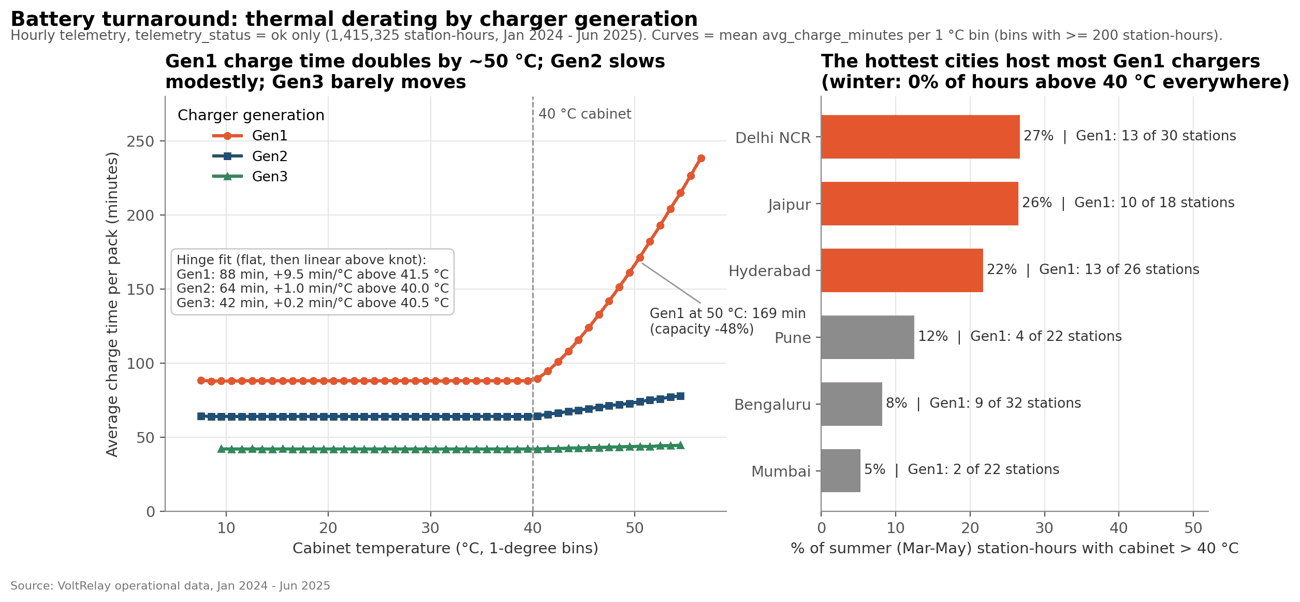

[  3.1s] saved q3_01_thermal_derating


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
cp = curve.filter(pl.col("station_hours") >= 200).to_pandas()
for g in ["Gen1", "Gen2", "Gen3"]:
    d = cp[cp.charger_generation == g]
    ax.plot(d.t_bin + 0.5, d.charge_min, color=GEN_COLORS[g], lw=2.2, marker=GEN_MARK[g], ms=4.5, label=g)
ax.axvline(HOT_C, color=PALETTE["muted"], ls="--", lw=1)
ax.text(HOT_C + 0.6, 272, "40 °C cabinet", ha="left", va="top", fontsize=9.5, color="#555555")
h1 = hinge.set_index("generation")
txt = "\n".join(f"{g}: {h1.loc[g].base_charge_min:.0f} min, +{h1.loc[g].slope_min_per_c:.1f} min/°C above {h1.loc[g].knot_c:.1f} °C"
                for g in ["Gen1", "Gen2", "Gen3"])
ax.text(0.02, 0.62, "Hinge fit (flat, then linear above knot):\n" + txt, transform=ax.transAxes, fontsize=9, color="#333333", va="top",
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#cccccc"))
ax.annotate(f"Gen1 at 50 °C: {h1.loc['Gen1'].charge_min_at_50c:.0f} min\n(capacity -{100*(1-h1.loc['Gen1'].capacity_at_50c_vs_base):.0f}%)",
            xy=(50.5, h1.loc["Gen1"].charge_min_at_50c), xytext=(51.5, 120), fontsize=9.2, color="#333333",
            arrowprops=dict(arrowstyle="-", color="#999999"))
ax.set_xlabel("Cabinet temperature (°C, 1-degree bins)")
ax.set_ylabel("Average charge time per pack (minutes)")
ax.set_ylim(0, 280); ax.set_xlim(4, 59)
ax.legend(title="Charger generation", loc="upper left")
ax.set_title("Gen1 charge time doubles by ~50 °C; Gen2 slows\nmodestly; Gen3 barely moves", fontsize=12.5)
ax = axes[1]
ec = expo_city.to_pandas().sort_values("summer_hot_share")
gen1_n = st_pd_tmp = st.group_by("city").agg((pl.col("charger_generation") == "Gen1").sum().alias("g1"), pl.len().alias("n")).to_pandas().set_index("city")
yc = np.arange(len(ec))
ax.barh(yc, 100 * ec.summer_hot_share, color=[PALETTE["accent"] if c in ["Delhi NCR", "Jaipur", "Hyderabad"] else PALETTE["muted"] for c in ec.city], height=0.65)
for yi, c, v in zip(yc, ec.city, ec.summer_hot_share):
    ax.text(100 * v + 0.5, yi, f"{100*v:.0f}%  |  Gen1: {int(gen1_n.loc[c,'g1'])} of {int(gen1_n.loc[c,'n'])} stations", va="center", fontsize=9.5, color="#333333")
ax.set_yticks(yc, ec.city)
ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
ax.set_xlim(0, 52)
ax.set_xlabel("% of summer (Mar-May) station-hours with cabinet > 40 °C")
ax.set_title("The hottest cities host most Gen1 chargers\n(winter: 0% of hours above 40 °C everywhere)", fontsize=12.5)
fig.suptitle("Battery turnaround: thermal derating by charger generation", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, 0.985, f"Hourly telemetry, telemetry_status = ok only ({H.height:,} station-hours, Jan 2024 - Jun 2025). "
         "Curves = mean avg_charge_minutes per 1 °C bin (bins with >= 200 station-hours).", fontsize=9.5, color="#555555")
save_fig(fig, "q3_01_thermal_derating")
say("saved q3_01_thermal_derating")

## 2. Service performance and complaints by station attributes
Station-month panel (stations with >= 15 active days and >= 100 attempts in the month). Raw comparisons are
confounded: Gen1 exists only at Launch stations, Wave2 is all Gen3 and opened in the 2025 summer, and busy sites fail
more. So we fit WLS (weights = attempts) with **city and month fixed effects**, a **utilisation control**
(log attempts per slot-day) and all attributes together; SEs are clustered by station. Spec B adds the station-month
share of hours with cabinet > 40 C interacted with generation to test whether any Gen1 penalty is purely thermal.
Complaints = support tickets linked to the station (95% of tickets carry a station_id) per 1,000 completed swaps.

In [94]:
SM = station_month().with_columns(
    (pl.col("stockouts") + pl.col("abandoned") + pl.col("system_errors")).alias("failures"),
    (pl.col("attempts") / (pl.col("active_days") * (pl.col("slots_2w") + pl.col("slots_3w")))).alias("att_per_slot_day"),
    (pl.col("slots_2w") + pl.col("slots_3w")).alias("slots"),
).join(st.select("station_id", "zone"), on="station_id", how="left")
hot_m = H.group_by("station_id", "month").agg((pl.col("cabinet_temp_c") > HOT_C).mean().alias("hot_share"),
                                              pl.col("avg_charge_minutes").mean().alias("charge_min"))
TK_all = tickets()
say(f"tickets carrying a station_id: {TK_all['station_id'].is_not_null().mean():.1%} of {TK_all.height:,}")
TK = TK_all.filter(pl.col("in_window") & ~pl.col("is_test") & pl.col("station_id").is_not_null())
tk_m = TK.group_by("station_id", "month").agg(
    pl.len().alias("tickets"),
    pl.col("category").is_in(["no_battery_available", "long_queue"]).sum().alias("tickets_service"),
    (pl.col("category") == "no_battery_available").sum().alias("tickets_nobattery"))
SM = (SM.join(hot_m, on=["station_id", "month"], how="left").join(tk_m, on=["station_id", "month"], how="left")
      .with_columns(pl.col("tickets").fill_null(0), pl.col("tickets_service").fill_null(0), pl.col("tickets_nobattery").fill_null(0)))
say(f"tickets in window with a real station: {TK.height:,}; matched to station-months: {int(SM['tickets'].sum()):,}")
P = (SM.filter((pl.col("active_days") >= 15) & (pl.col("attempts") >= 100))
     .with_columns((100 * pl.col("failures") / pl.col("attempts")).alias("fail_pp"),
                   (100 * pl.col("stockouts") / pl.col("attempts")).alias("stockout_pp"),
                   (1000 * pl.col("tickets") / pl.col("completed")).alias("tickets_per_1k"),
                   (1000 * pl.col("tickets_service") / pl.col("completed")).alias("svc_tickets_per_1k"),
                   pl.col("att_per_slot_day").log().alias("log_util"),
                   pl.col("month").cast(pl.String).alias("month_s"))
     .to_pandas())
say(f"station-month panel for models: {len(P):,} rows, {P.station_id.nunique()} stations")


# --- raw descriptives by attribute (pooled rates), full period and Apr-Jun 2025 (all 150 stations live)
def describe_by(df, col):
    g = df.groupby(col).agg(stations=("station_id", "nunique"), attempts=("attempts", "sum"), failures=("failures", "sum"),
                            stockouts=("stockouts", "sum"), sys_err=("system_errors", "sum"), completed=("completed", "sum"),
                            tickets=("tickets", "sum"), slot_days=("slots", lambda s: (s * df.loc[s.index, "active_days"]).sum()),
                            qw=("q_wait_completed_mean", lambda s: np.average(s.fillna(0), weights=df.loc[s.index, "completed"])))
    g["failure_rate_pct"] = 100 * g.failures / g.attempts
    g["stockout_rate_pct"] = 100 * g.stockouts / g.attempts
    g["system_error_rate_pct"] = 100 * g.sys_err / g.attempts
    g["tickets_per_1k_swaps"] = 1000 * g.tickets / g.completed
    g["attempts_per_slot_day"] = g.attempts / g.slot_days
    g = g.rename(columns={"qw": "queue_wait_sec"}).reset_index().rename(columns={col: "level"})
    g.insert(0, "attribute", col)
    return g[["attribute", "level", "stations", "attempts", "failure_rate_pct", "stockout_rate_pct", "system_error_rate_pct",
              "queue_wait_sec", "tickets_per_1k_swaps", "attempts_per_slot_day"]]


ATTRS = ["charger_generation", "location_type", "host_type", "connectivity_tier", "expansion_wave", "city"]
desc_all = pd.concat([describe_by(P, c) for c in ATTRS]).assign(period="Jan24-Jun25")
P_q2 = P[P.month_s >= "2025-04-01"]
desc_q2 = pd.concat([describe_by(P_q2, c) for c in ATTRS]).assign(period="Apr-Jun25")
desc = pd.concat([desc_all, desc_q2])
desc.to_csv(TAB / "q3_attribute_descriptives.csv", index=False)
say("Raw descriptives by attribute (full period):\n" + desc_all.round(2).to_string(index=False))
say("Raw descriptives by attribute (Apr-Jun 2025):\n" + desc_q2.round(2).to_string(index=False))
# confounding check: Gen1 vs Gen2 within Launch
lc = P[P.expansion_wave == "Launch"].groupby("charger_generation").apply(lambda d: pd.Series({
    "stations": d.station_id.nunique(), "attempts_per_slot_day": d.attempts.sum() / (d.slots * d.active_days).sum(),
    "share_commercial_or_market": d.drop_duplicates("station_id").location_type.isin(["commercial_hub", "market"]).mean(),
    "share_delhi_jaipur_hyd": d.drop_duplicates("station_id").city.isin(["Delhi NCR", "Jaipur", "Hyderabad"]).mean()}))
say("Confounding check within Launch stations (Gen1 vs Gen2):\n" + lc.round(3).to_string())

# --- multivariable models
RHS = ("C(charger_generation, Treatment('Gen2')) + C(location_type, Treatment('commercial_hub')) + "
       "C(host_type, Treatment('kirana')) + C(connectivity_tier, Treatment('good')) + C(expansion_wave, Treatment('Launch')) + "
       "log_util + C(city) + C(month_s)")


def fit(y, w, rhs=RHS, data=None):
    d = (P if data is None else data).dropna(subset=[y, w])
    return smf.wls(f"{y} ~ {rhs}", data=d, weights=d[w]).fit(cov_type="cluster", cov_kwds={"groups": d["station_id"]})


models = {"failure_rate_pp": fit("fail_pp", "attempts"), "stockout_rate_pp": fit("stockout_pp", "attempts"),
          "queue_wait_sec": fit("q_wait_completed_mean", "completed"), "tickets_per_1k": fit("tickets_per_1k", "completed"),
          "service_tickets_per_1k": fit("svc_tickets_per_1k", "completed")}
P["hot_pp"] = 100 * P["hot_share"]
m_hot = fit("fail_pp", "attempts", RHS + " + hot_pp + C(charger_generation, Treatment('Gen2')):hot_pp")


def clean_name(t):
    for a, b in [("C(charger_generation, Treatment('Gen2'))[T.", "Generation: "), ("C(location_type, Treatment('commercial_hub'))[T.", "Location: "),
                 ("C(host_type, Treatment('kirana'))[T.", "Host: "), ("C(connectivity_tier, Treatment('good'))[T.", "Connectivity: "),
                 ("C(expansion_wave, Treatment('Launch'))[T.", "Wave: "), ("C(city)[T.", "City: ")]:
        t = t.replace(a, b)
    return t.replace("]", "")


coef_rows = []
for name, m in list(models.items()) + [("failure_rate_pp_thermal_spec", m_hot)]:
    for t in m.params.index:
        if t.startswith("C(month_s)") or t == "Intercept":
            continue
        coef_rows.append({"outcome": name, "term": clean_name(t), "coef": m.params[t], "se": m.bse[t], "p": m.pvalues[t],
                          "ci_lo": m.params[t] - 1.96 * m.bse[t], "ci_hi": m.params[t] + 1.96 * m.bse[t],
                          "n": int(m.nobs), "r2": m.rsquared})
COEF = pd.DataFrame(coef_rows)
COEF.to_csv(TAB / "q3_station_attribute_model_coefs.csv", index=False)
show = COEF[COEF.outcome.isin(["failure_rate_pp", "queue_wait_sec", "tickets_per_1k"])].pivot_table(
    index="term", columns="outcome", values=["coef", "p"]).round(3)
say(f"Multivariable WLS (city + month FE, cluster SE by station; n={int(models['failure_rate_pp'].nobs):,} station-months):\n" + show.to_string())
th = COEF[COEF.outcome == "failure_rate_pp_thermal_spec"].set_index("term")
say("Thermal spec (failure pp; adds hot_pp = % of station-hours > 40 C, interacted with generation):\n"
    + th[["coef", "ci_lo", "ci_hi", "p"]].round(3).to_string())
s_g2 = th.loc["hot_pp", "coef"]; s_g1 = s_g2 + th.loc["Generation: Gen1:hot_pp", "coef"]; s_g3 = s_g2 + th.loc["Generation: Gen3:hot_pp", "coef"]
say(f"Failure-rate slope per +1 pp of hot station-hours: Gen1 {s_g1:.3f} pp, Gen2 {s_g2:.3f} pp, Gen3 {s_g3:.3f} pp "
    f"(Gen1/Gen2 ratio {s_g1/s_g2:.2f}x)")
gen_city = st.group_by("city", "charger_generation").len().pivot(on="charger_generation", index="city", values="len").fill_null(0).sort("city")
say("Stations by city x generation (Gen1 sits in the hottest cities):\n" + str(gen_city))
# implied Gen1 vs Gen2 gap at typical hot-share levels
for hs in [0, 10, 20, 30]:
    gap = th.loc["Generation: Gen1", "coef"] + th.loc["Generation: Gen1:hot_pp", "coef"] * hs
    say(f"  implied Gen1 - Gen2 failure gap at {hs}% hot station-hours: {gap:+.2f} pp")
say(f"R2 failure model {models['failure_rate_pp'].rsquared:.3f}; thermal spec {m_hot.rsquared:.3f}")
# tickets track failures: complaints per +1 pp failure rate
Pt = P.dropna(subset=["tickets_per_1k"])
m_tk = smf.wls("tickets_per_1k ~ fail_pp + C(city) + C(month_s)", data=Pt, weights=Pt["completed"]).fit(
    cov_type="cluster", cov_kwds={"groups": Pt["station_id"]})
say(f"Tickets per 1K swaps rise by {m_tk.params['fail_pp']:.3f} per +1 pp failure rate (95% CI {m_tk.conf_int().loc['fail_pp',0]:.3f} to "
    f"{m_tk.conf_int().loc['fail_pp',1]:.3f}); mean tickets per 1K = {1000*P.tickets.sum()/P.completed.sum():.2f}")
say(f"  => +1 pp failure rate = 10 extra failed attempts per 1,000 attempts, so this is about ONE extra ticket per "
    f"{10/m_tk.params['fail_pp']:.1f} extra failed attempts (not one ticket per failure)")
tk_att = P_q2.groupby("charger_generation").apply(lambda d: 1000 * d.tickets.sum() / d.attempts.sum())
say("Apr-Jun 2025 tickets per 1K ATTEMPTS (removes the completed-swaps denominator effect): "
    + ", ".join(f"{k} {v:.2f}" for k, v in tk_att.items()))
# counterfactual: hot-city Gen1 station-months if they had Gen2 (in-support) or Gen3 (extrapolated) thermal behaviour
cfp = P[(P.charger_generation == "Gen1") & P.city.isin(["Delhi NCR", "Jaipur", "Hyderabad"]) & P.month_s.str[5:7].isin(["04", "05", "06"])].copy()
cf_rows = []
for alt in ["Gen2", "Gen3"]:
    pred_act = m_hot.predict(cfp)
    pred_alt = m_hot.predict(cfp.assign(charger_generation=alt))
    for yr in ["2024", "2025"]:
        msk = cfp.month_s.str[:4] == yr
        avoided = float(((pred_act - pred_alt)[msk] * cfp.attempts[msk] / 100).sum())
        d_pp = float(np.average((pred_act - pred_alt)[msk], weights=cfp.attempts[msk]))
        cf_rows.append({"counterfactual": f"Gen1 -> {alt}", "period": f"Apr-Jun {yr}", "stations": cfp[msk].station_id.nunique(),
                        "attempts": int(cfp.attempts[msk].sum()), "actual_fail_pct": 100 * cfp.failures[msk].sum() / cfp.attempts[msk].sum(),
                        "failure_pp_reduction": d_pp, "failed_attempts_avoided": avoided,
                        "tickets_avoided": m_tk.params["fail_pp"] * d_pp * cfp.completed[msk].sum() / 1000})
CFT = pd.DataFrame(cf_rows)
# naive empirical anchor: actual Apr-Jun 2025 failure rates of Gen2 (Launch) and Gen3 stations in the SAME hot cities
# (Gen3 is inside heat support: 19 Gen3 stations operate in Delhi NCR / Jaipur / Hyderabad; only Launch-site support is missing)
smq = SM.filter((pl.col("month") >= pl.date(2025, 4, 1)) & pl.col("city").is_in(["Delhi NCR", "Jaipur", "Hyderabad"])).to_pandas()
net_fail_25 = float(SM.filter(pl.col("month") >= pl.date(2025, 4, 1))["failures"].sum())
g1q = smq[smq.charger_generation == "Gen1"]
r_g1 = 100 * g1q.failures.sum() / g1q.attempts.sum()
naive = {}
for alt, d in [("Gen2", smq[(smq.charger_generation == "Gen2") & (smq.expansion_wave == "Launch")]), ("Gen3", smq[smq.charger_generation == "Gen3"])]:
    r_alt = 100 * d.failures.sum() / d.attempts.sum()
    av = (r_g1 - r_alt) / 100 * g1q.attempts.sum()
    naive[alt] = (r_g1 - r_alt, av)
    say(f"Naive same-city check, Apr-Jun 2025: hot-city Gen1 ({g1q.station_id.nunique()} stations) {r_g1:.2f}% vs hot-city "
        f"{'Launch Gen2' if alt == 'Gen2' else 'Gen3'} ({d.station_id.nunique()} stations) {r_alt:.2f}% -> -{r_g1 - r_alt:.2f} pp, "
        f"{av:,.0f} failed attempts avoided ({av / net_fail_25:.1%} of network failures)")
for alt in ["Gen2", "Gen3"]:
    msk = (CFT.counterfactual == f"Gen1 -> {alt}") & (CFT.period == "Apr-Jun 2025")
    CFT.loc[msk, "naive_same_city_pp"] = naive[alt][0]
    CFT.loc[msk, "naive_same_city_avoided"] = naive[alt][1]
CFT.to_csv(TAB / "q3_gen1_upgrade_counterfactual.csv", index=False)
say("Counterfactual for the 36 hot-city Gen1 stations, Apr-Jun (thermal-spec model; naive same-city anchor for 2025):\n"
    + CFT.round(2).to_string(index=False))
qw_range = desc_all.groupby("attribute").queue_wait_sec.agg(["min", "max"])
say(f"Queue wait of completed swaps across all attribute levels: {desc_all.queue_wait_sec.min():.1f}-{desc_all.queue_wait_sec.max():.1f} s; "
    f"system-error rate {desc_all.system_error_rate_pct.min():.2f}-{desc_all.system_error_rate_pct.max():.2f}% (flat - not a differentiator)")

[  3.1s] tickets carrying a station_id: 94.9% of 44,000


[  3.1s] tickets in window with a real station: 41,161; matched to station-months: 41,158


[  3.2s] station-month panel for models: 2,003 rows, 150 stations


[  3.2s] Raw descriptives by attribute (full period):
         attribute             level  stations  attempts  failure_rate_pct  stockout_rate_pct  system_error_rate_pct  queue_wait_sec  tickets_per_1k_swaps  attempts_per_slot_day      period
charger_generation              Gen1        51   1822034             6.800              4.340                  0.290         243.710                12.660                  4.220 Jan24-Jun25
charger_generation              Gen2        62   1615363             4.420              2.690                  0.300         243.670                 9.920                  4.030 Jan24-Jun25
charger_generation              Gen3        37    363275             4.410              2.710                  0.300         243.940                12.730                  5.140 Jan24-Jun25
     location_type    commercial_hub        44   1534014             5.750              3.620                  0.290         243.800                11.440                  4.740 Jan24-Ju

[  3.2s] Raw descriptives by attribute (Apr-Jun 2025):
         attribute             level  stations  attempts  failure_rate_pct  stockout_rate_pct  system_error_rate_pct  queue_wait_sec  tickets_per_1k_swaps  attempts_per_slot_day    period
charger_generation              Gen1        51    373742            12.410              8.240                  0.300         243.620                21.380                  5.200 Apr-Jun25
charger_generation              Gen2        62    364101             5.440              3.390                  0.290         243.550                13.210                  4.490 Apr-Jun25
charger_generation              Gen3        37    238702             4.700              2.920                  0.300         243.760                13.490                  5.420 Apr-Jun25
     location_type    commercial_hub        44    347653             8.910              5.810                  0.290         243.900                17.400                  6.060 Apr-Jun25
     

[  3.2s] Confounding check within Launch stations (Gen1 vs Gen2):
                    stations  attempts_per_slot_day  share_commercial_or_market  share_delhi_jaipur_hyd
charger_generation                                                                                     
Gen1                  51.000                  4.216                       0.804                   0.706
Gen2                  39.000                  4.056                       0.795                   0.205


... (12 outputs left out)

[  3.6s] Naive same-city check, Apr-Jun 2025: hot-city Gen1 (36 stations) 15.20% vs hot-city Launch Gen2 (8 stations) 8.01% -> -7.19 pp, 19,266 failed attempts avoided (24.9% of network failures)


[  3.6s] Naive same-city check, Apr-Jun 2025: hot-city Gen1 (36 stations) 15.20% vs hot-city Gen3 (19 stations) 5.06% -> -10.14 pp, 27,158 failed attempts avoided (35.1% of network failures)


[  3.6s] Counterfactual for the 36 hot-city Gen1 stations, Apr-Jun (thermal-spec model; naive same-city anchor for 2025):
counterfactual       period  stations  attempts  actual_fail_pct  failure_pp_reduction  failed_attempts_avoided  tickets_avoided  naive_same_city_pp  naive_same_city_avoided
  Gen1 -> Gen2 Apr-Jun 2024        36    172800           15.480                 7.350               12,693.670        1,073.020                 NaN                      NaN
  Gen1 -> Gen2 Apr-Jun 2025        36    267903           15.200                 7.360               19,718.210        1,672.110               7.190               19,265.710
  Gen1 -> Gen3 Apr-Jun 2024        36    172800           15.480                10.340               17,864.770        1,510.140                 NaN                      NaN
  Gen1 -> Gen3 Apr-Jun 2025        36    267903           15.200                10.360               27,751.280        2,353.320              10.140               27,157.540


[  3.6s] Queue wait of completed swaps across all attribute levels: 243.3-244.2 s; system-error rate 0.28-0.31% (flat - not a differentiator)


### Figure 2: what actually separates stations - heat x generation, not location, host or connectivity

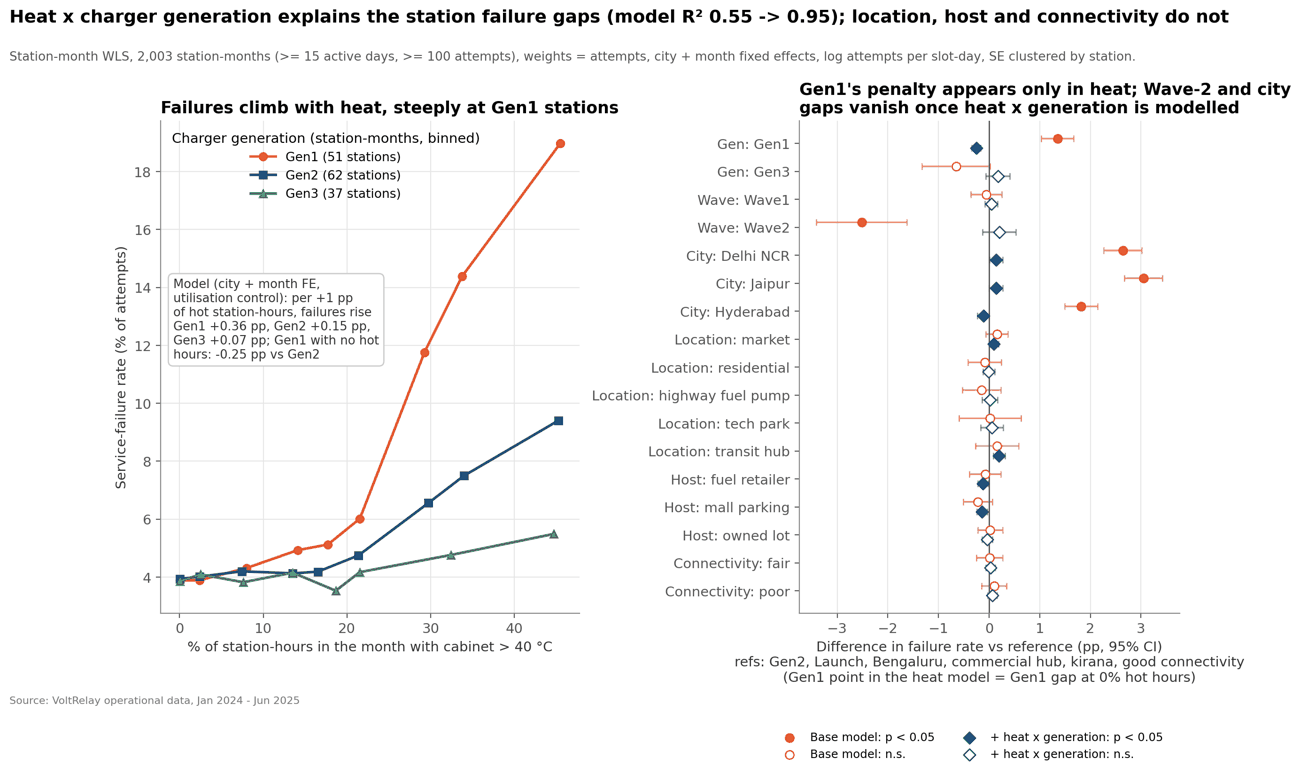

[  4.1s] saved q3_02_attributes_vs_failures


In [95]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.55})
ax = axes[0]
P["hot_bin"] = pd.cut(P.hot_pp, [-0.1, 0.5, 5, 10, 15, 20, 25, 30, 40, 60], labels=False)
for g in ["Gen1", "Gen2", "Gen3"]:
    d = P[P.charger_generation == g].groupby("hot_bin").apply(lambda x: pd.Series({
        "hot": np.average(x.hot_pp, weights=x.attempts), "fail": 100 * x.failures.sum() / x.attempts.sum(), "n": len(x)}))
    d = d[d.n >= 5]
    ax.plot(d.hot, d.fail, color=GEN_COLORS[g], marker=GEN_MARK[g], lw=2, ms=6, label=f"{g} ({P[P.charger_generation==g].station_id.nunique()} stations)")
ax.set_xlabel("% of station-hours in the month with cabinet > 40 °C")
ax.set_ylabel("Service-failure rate (% of attempts)")
ax.set_title("Failures climb with heat, steeply at Gen1 stations", fontsize=12.5)
ax.legend(loc="upper left", title="Charger generation (station-months, binned)")
b1 = th.loc["Generation: Gen1:hot_pp", "coef"]; b0 = th.loc["hot_pp", "coef"]
ax.text(0.03, 0.68, f"Model (city + month FE,\nutilisation control): per +1 pp\nof hot station-hours, failures rise\nGen1 +{b0+b1:.2f} pp, "
        f"Gen2 +{b0:.2f} pp,\nGen3 +{b0+th.loc['Generation: Gen3:hot_pp','coef']:.2f} pp; Gen1 with no hot\nhours: "
        f"{th.loc['Generation: Gen1','coef']:+.2f} pp vs Gen2", transform=ax.transAxes, ha="left", va="top", fontsize=9.3, color="#333333",
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#cccccc"))
ax = axes[1]
order = ["Generation: Gen1", "Generation: Gen3", "Wave: Wave1_2024H2", "Wave: Wave2_2025H1", "City: Delhi NCR", "City: Jaipur",
         "City: Hyderabad", "Location: market", "Location: residential", "Location: highway_fuel_pump", "Location: tech_park",
         "Location: transit_hub", "Host: fuel_retailer", "Host: mall_parking", "Host: owned_lot", "Connectivity: fair", "Connectivity: poor"]
yy = np.arange(len(order))[::-1].astype(float)
for spec, off, col, mk, lab in [("failure_rate_pp", 0.17, PALETTE["accent"], "o", "Base model"),
                                ("failure_rate_pp_thermal_spec", -0.17, PALETTE["primary"], "D", "+ heat x generation")]:
    cf = COEF[COEF.outcome == spec].set_index("term").loc[order].reset_index()
    sig = (cf.p < 0.05).values
    ax.errorbar(cf.coef, yy + off, xerr=1.96 * cf.se, fmt="none", ecolor=col, alpha=0.6, elinewidth=1.3, capsize=2.5)
    ax.scatter(cf.coef[sig], (yy + off)[sig], color=col, marker=mk, s=42, zorder=3, label=f"{lab}: p < 0.05")
    ax.scatter(cf.coef[~sig], (yy + off)[~sig], facecolor="white", edgecolor=col, marker=mk, s=42, zorder=3, label=f"{lab}: n.s.")
ax.axvline(0, color="#555555", lw=1)
labels = [t.replace("Generation: ", "Gen: ").replace("_2024H2", "").replace("_2025H1", "").replace("_", " ") for t in order]
ax.set_yticks(yy, labels); ax.set_ylim(-0.8, len(order) - 0.2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Difference in failure rate vs reference (pp, 95% CI)\nrefs: Gen2, Launch, Bengaluru, commercial hub, kirana, good connectivity\n"
              "(Gen1 point in the heat model = Gen1 gap at 0% hot hours)")
ax.set_title("Gen1's penalty appears only in heat; Wave-2 and city\ngaps vanish once heat x generation is modelled", fontsize=12.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.22), ncol=2, fontsize=8.8)
fig.suptitle(f"Heat x charger generation explains the station failure gaps (model R² {models['failure_rate_pp'].rsquared:.2f} -> {m_hot.rsquared:.2f}); "
             f"location, host and connectivity do not", x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.055)
fig.text(0.01, 0.975, f"Station-month WLS, {int(models['failure_rate_pp'].nobs):,} station-months (>= 15 active days, >= 100 attempts), weights = attempts, "
         "city + month fixed effects, log attempts per slot-day, SE clustered by station.", fontsize=9.5, color="#555555")
save_fig(fig, "q3_02_attributes_vs_failures")
say("saved q3_02_attributes_vs_failures")

## 3. Uneven distribution: supply vs demand by city and zone
Supply = stations and slots; demand = riders by **home zone** (latent demand, from riders.home_zone) and attempts
at stations in the zone (realised demand, capped by where stations exist). "Need" before Wave 1 = Jan-Jun 2024.

In [96]:
st_pd = st.to_pandas()
zone = (st_pd.assign(L_slots=np.where(st_pd.expansion_wave == "Launch", st_pd.slots, 0),
                     W1_slots=np.where(st_pd.expansion_wave == "Wave1_2024H2", st_pd.slots, 0),
                     W2_slots=np.where(st_pd.expansion_wave == "Wave2_2025H1", st_pd.slots, 0),
                     L_st=(st_pd.expansion_wave == "Launch").astype(int), W1_st=(st_pd.expansion_wave == "Wave1_2024H2").astype(int),
                     W2_st=(st_pd.expansion_wave == "Wave2_2025H1").astype(int))
        .groupby(["city", "zone"])[["L_st", "W1_st", "W2_st", "L_slots", "W1_slots", "W2_slots"]].sum().reset_index())
RD = riders()
rz = (RD.group_by("home_zone").agg(pl.len().alias("riders_registered"),
                                   (pl.col("first_attempt_ts") < pl.datetime(2024, 7, 1)).sum().alias("riders_active_h1_24"),
                                   (pl.col("last_attempt_ts") >= pl.datetime(2025, 4, 1)).sum().alias("riders_active_q2_25"))
      .rename({"home_zone": "zone"}).to_pandas())
SMp = SM.to_pandas()
SMp["period"] = np.select([SMp.month < pd.Timestamp("2024-07-01"), (SMp.month >= pd.Timestamp("2024-07-01")) & (SMp.month < pd.Timestamp("2025-01-01")),
                           SMp.month >= pd.Timestamp("2025-04-01")], ["H1_24", "H2_24", "Q2_25"], "other")
SMp["slot_days"] = SMp.slots * SMp.active_days


def zone_period(df, per, tag):
    d = df[df.period == per].groupby("zone").agg(att=("attempts", "sum"), fail=("failures", "sum"), so=("stockouts", "sum"),
                                                 comp=("completed", "sum"), sd=("slot_days", "sum"))
    return pd.DataFrame({f"attempts_{tag}": d.att, f"failures_{tag}": d.fail, f"failure_rate_{tag}": 100 * d.fail / d.att,
                         f"stockout_rate_{tag}": 100 * d.so / d.att, f"att_per_slot_day_{tag}": d.att / d.sd, f"completed_{tag}": d.comp})


zone = (zone.merge(rz, on="zone", how="left")
        .merge(zone_period(SMp, "H1_24", "h1_24"), left_on="zone", right_index=True, how="left")
        .merge(zone_period(SMp, "H2_24", "h2_24"), left_on="zone", right_index=True, how="left")
        .merge(zone_period(SMp, "Q2_25", "q2_25"), left_on="zone", right_index=True, how="left"))
# Q2-24 legacy failure rate (same season as Q2-25) for the before/after view
q2_24 = SMp[(SMp.month >= pd.Timestamp("2024-04-01")) & (SMp.month < pd.Timestamp("2024-07-01"))]
zq = q2_24.groupby("zone").agg(a=("attempts", "sum"), f=("failures", "sum"))
zone["failure_rate_q2_24"] = zone.zone.map(100 * zq.f / zq.a)
zone["failures_q2_24"] = zone.zone.map(zq.f)
zone["new_slots"] = zone.W1_slots + zone.W2_slots
zone["riders_per_legacy_slot"] = np.where(zone.L_slots > 0, zone.riders_active_h1_24 / zone.L_slots.replace(0, np.nan), np.nan)
zone["share_riders_h1_24"] = zone.riders_active_h1_24 / zone.riders_active_h1_24.sum()
zone["share_legacy_slots"] = zone.L_slots / zone.L_slots.sum()
zone["share_failures_h1_24"] = zone.failures_h1_24.fillna(0) / zone.failures_h1_24.sum()
zone["share_new_slots"] = zone.new_slots / zone.new_slots.sum()
zone["share_W1_slots"] = zone.W1_slots / zone.W1_slots.sum()
zone["share_W2_slots"] = zone.W2_slots / zone.W2_slots.sum()
zone["supply_gap_pp"] = 100 * (zone.share_riders_h1_24 - zone.share_legacy_slots)
zone = zone.sort_values("failure_rate_h1_24", ascending=False, na_position="first")
zone.to_csv(TAB / "q3_zone_supply_demand.csv", index=False)
say("Zone supply-demand table (sorted by H1-2024 failure rate):\n" + zone[[
    "zone", "L_st", "W1_st", "W2_st", "L_slots", "new_slots", "riders_active_h1_24", "riders_per_legacy_slot", "failure_rate_h1_24",
    "att_per_slot_day_h1_24", "supply_gap_pp", "failure_rate_q2_24", "failure_rate_q2_25"]].round(2).to_string(index=False))
city = zone.groupby("city").agg(stations=("L_st", "sum"), W1=("W1_st", "sum"), W2=("W2_st", "sum"), legacy_slots=("L_slots", "sum"),
                                new_slots=("new_slots", "sum"), riders_h1_24=("riders_active_h1_24", "sum"), riders_q2_25=("riders_active_q2_25", "sum"),
                                attempts_h1_24=("attempts_h1_24", "sum"), failures_h1_24=("failures_h1_24", "sum"))
city["riders_per_legacy_slot"] = city.riders_h1_24 / city.legacy_slots
city["failure_rate_h1_24"] = 100 * city.failures_h1_24 / city.attempts_h1_24
city["share_riders"] = city.riders_h1_24 / city.riders_h1_24.sum(); city["share_legacy_slots"] = city.legacy_slots / city.legacy_slots.sum()
city["share_new_slots"] = city.new_slots / city.new_slots.sum(); city["share_failures_h1_24"] = city.failures_h1_24 / city.failures_h1_24.sum()
city.to_csv(TAB / "q3_city_supply_demand.csv")
say("City supply-demand:\n" + city.round(3).to_string())
no_station_zones = zone[zone.L_st == 0]
say(f"Zones with resident riders but NO Launch station: {no_station_zones.zone.tolist()} "
    f"({int(no_station_zones.riders_active_h1_24.sum())} riders active in H1-2024); new stations there: "
    f"W1={int(no_station_zones.W1_st.sum())}, W2={int(no_station_zones.W2_st.sum())}")

[  4.1s] Zone supply-demand table (sorted by H1-2024 failure rate):
               zone  L_st  W1_st  W2_st  L_slots  new_slots  riders_active_h1_24  riders_per_legacy_slot  failure_rate_h1_24  att_per_slot_day_h1_24  supply_gap_pp  failure_rate_q2_24  failure_rate_q2_25
        DEL-Central     0      0      1        0         16                  104                     NaN                 NaN                     NaN          1.400                 NaN               5.310
        JAI-Central     0      0      1        0          8                  148                     NaN                 NaN                     NaN          1.990                 NaN               5.230
        PUN-Kharadi     0      1      0        0         16                  140                     NaN                 NaN                     NaN          1.880                 NaN               4.320
  JAI-Malviya Nagar     6      2      2       86         64                  546                   6.350            

[  4.2s] City supply-demand:
           stations  W1  W2  legacy_slots  new_slots  riders_h1_24  riders_q2_25  attempts_h1_24  failures_h1_24  riders_per_legacy_slot  failure_rate_h1_24  share_riders  share_legacy_slots  share_new_slots  share_failures_h1_24
city                                                                                                                                                                                                                                 
Bengaluru        20   6   6           278        154          1616          3009     152,269.000       6,718.000                   5.813               4.412         0.217               0.206            0.184                 0.126
Delhi NCR        18   6   6           256        164          1387          2718     142,606.000      13,595.000                   5.418               9.533         0.186               0.189            0.196                 0.255
Hyderabad        16   5   5           256        14

[  4.2s] Zones with resident riders but NO Launch station: ['DEL-Central', 'JAI-Central', 'PUN-Kharadi'] (392 riders active in H1-2024); new stations there: W1=1, W2=2


## 4. Expansion waves: placed where riders needed them?
**Need** before each wave = legacy failure rate and failures per zone. Wave 1 (opened Aug-Oct 2024) uses Jan-Jun 2024.
Wave 2 (opened Feb-Apr 2025) uses the **same-season Apr-Jun 2024** rate: failures are an Apr-Jun phenomenon, and in the
off-season (Jul-Dec 2024) every zone sits at about 3.9%, so ranking zones on that period ranks noise (checked below).
We compare each wave's share of new slots going to the highest-need zones with those zones' share of failures, and
rank-correlate need with new slots.

In [97]:
zl = zone[zone.L_st > 0].copy()
zl["need_tercile_h1"] = pd.qcut(zl.failure_rate_h1_24.rank(method="first"), 3, labels=["low", "mid", "high"])
zl["need_tercile_q2"] = pd.qcut(zl.failure_rate_q2_24.rank(method="first"), 3, labels=["low", "mid", "high"])
pl_rows = []
for wave, col, need, fcol, rcol, need_lbl in [("Wave1", "W1_slots", "need_tercile_h1", "failures_h1_24", "failure_rate_h1_24", "Jan-Jun 2024"),
                                              ("Wave2", "W2_slots", "need_tercile_q2", "failures_q2_24", "failure_rate_q2_24", "Apr-Jun 2024")]:
    for t in ["high", "mid", "low"]:
        sub = zl[zl[need] == t]
        pl_rows.append({"wave": wave, "need_period": need_lbl, "need_tercile": t, "zones": len(sub),
                        "share_of_failures": sub[fcol].sum() / zl[fcol].sum(),
                        "share_of_legacy_slots": sub.L_slots.sum() / zl.L_slots.sum(), "share_of_new_slots": sub[col].sum() / zone[col].sum(),
                        "new_slots": int(sub[col].sum())})
    rho, p = stats.spearmanr(zl[rcol], zl[col] / zl.L_slots)
    rho2, p2 = stats.spearmanr(zl[fcol], zl[col])
    say(f"{wave} (need = {need_lbl}): Spearman(zone failure rate, new slots per legacy slot) = {rho:.2f} (p={p:.2f}); "
        f"Spearman(zone failures, new slots) = {rho2:.2f} (p={p2:.2f}); n={len(zl)} zones with legacy stations")
    say(f"{wave}: slots placed in zones with no legacy station: {int(zone.loc[zone.L_st == 0, col].sum())} of {int(zone[col].sum())}")
placement = pd.DataFrame(pl_rows)
placement.to_csv(TAB / "q3_wave_placement_vs_need.csv", index=False)
say("Placement vs need terciles (Wave 2 need = same-season Apr-Jun 2024):\n" + placement.round(3).to_string(index=False))
# Wave-2 robustness, and why the off-season Jul-Dec 2024 rate is NOT used as Wave-2 need
r_h1, p_h1 = stats.spearmanr(zl.failure_rate_h1_24, zl.W2_slots / zl.L_slots)
r_h2, p_h2 = stats.spearmanr(zl.failure_rate_h2_24, zl.W2_slots / zl.L_slots)
r_h1h2 = stats.spearmanr(zl.failure_rate_h1_24, zl.failure_rate_h2_24)[0]
say(f"Wave2 robustness: need = Jan-Jun 2024 rate -> rho {r_h1:.2f} (p={p_h1:.2f}). NOT USED: the off-season Jul-Dec 2024 rate gives "
    f"rho {r_h2:.2f} (p={p_h2:.2f}) but zone rates there are flat noise: mean {zl.failure_rate_h2_24.mean():.2f}%, SD "
    f"{zl.failure_rate_h2_24.std():.2f} pp (Jan-Jun 2024 SD {zl.failure_rate_h1_24.std():.2f} pp, Apr-Jun 2024 SD "
    f"{zl.failure_rate_q2_24.std():.2f} pp); Spearman(Jan-Jun 2024 rate, Jul-Dec 2024 rate) = {r_h1h2:.2f}")

# site types: where waves went vs where legacy failures were
lt = (st_pd.groupby(["location_type", "expansion_wave"]).size().unstack(fill_value=0))
legacy_fail_by_loc = SMp[(SMp.expansion_wave == "Launch") & (SMp.period == "H1_24")].groupby("location_type").agg(
    a=("attempts", "sum"), f=("failures", "sum"), sd=("slot_days", "sum"))
lt["legacy_failure_rate_h1_24"] = 100 * legacy_fail_by_loc.f / legacy_fail_by_loc.a
lt["legacy_att_per_slot_day_h1_24"] = legacy_fail_by_loc.a / legacy_fail_by_loc.sd
lt["share_of_legacy_failures_h1_24"] = legacy_fail_by_loc.f / legacy_fail_by_loc.f.sum()
leg_slots_loc = st_pd[st_pd.expansion_wave == "Launch"].groupby("location_type").slots.sum()
lt["share_of_legacy_slots"] = leg_slots_loc / leg_slots_loc.sum()
lt.to_csv(TAB / "q3_wave_site_types.csv")
say("Site types by wave vs legacy demand/failures by site type (H1-2024):\n" + lt.round(3).to_string())
say("  NOTE: a site type's share of legacy failures mirrors its share of legacy slots (few legacy fuel-pump/residential sites), "
    f"while legacy failure RATES are similar across site types ({lt.legacy_failure_rate_h1_24.min():.1f}-{lt.legacy_failure_rate_h1_24.max():.1f}%) "
    "-> failure shares say nothing about need by site type")
rent = st_pd.assign(rent_per_slot=st_pd.monthly_rent_inr / st_pd.slots, opex=st_pd.monthly_rent_inr + st_pd.monthly_maintenance_inr).groupby("expansion_wave").agg(
    stations=("station_id", "count"), rent_mean=("monthly_rent_inr", "mean"), opex_mean=("opex", "mean"), rent_per_slot=("rent_per_slot", "mean"),
    slots_mean=("slots", "mean"))
say("Rent / opex by wave:\n" + rent.round(0).to_string())
hot_cities = ["Delhi NCR", "Jaipur", "Hyderabad"]
say(f"Hot cities (Delhi NCR, Jaipur, Hyderabad): {city.loc[hot_cities,'share_failures_h1_24'].sum():.1%} of H1-2024 failures, "
    f"{city.loc[hot_cities,'share_riders'].sum():.1%} of active riders, {city.loc[hot_cities,'share_legacy_slots'].sum():.1%} of legacy slots, "
    f"{city.loc[hot_cities,'share_new_slots'].sum():.1%} of Wave1+Wave2 slots (Wave 1 {zone[zone.city.isin(hot_cities)].W1_slots.sum()/zone.W1_slots.sum():.1%}, "
    f"Wave 2 {zone[zone.city.isin(hot_cities)].W2_slots.sum()/zone.W2_slots.sum():.1%}); Gen1 stations there: "
    f"{int(st.filter(pl.col('city').is_in(hot_cities) & (pl.col('charger_generation') == 'Gen1')).height)} of 51")

[  4.2s] Wave1 (need = Jan-Jun 2024): Spearman(zone failure rate, new slots per legacy slot) = 0.15 (p=0.46); Spearman(zone failures, new slots) = 0.40 (p=0.05); n=25 zones with legacy stations


[  4.2s] Wave1: slots placed in zones with no legacy station: 16 of 444


[  4.2s] Wave2 (need = Apr-Jun 2024): Spearman(zone failure rate, new slots per legacy slot) = 0.05 (p=0.82); Spearman(zone failures, new slots) = 0.33 (p=0.10); n=25 zones with legacy stations


[  4.2s] Wave2: slots placed in zones with no legacy station: 24 of 394


[  4.2s] Placement vs need terciles (Wave 2 need = same-season Apr-Jun 2024):
 wave  need_period need_tercile  zones  share_of_failures  share_of_legacy_slots  share_of_new_slots  new_slots
Wave1 Jan-Jun 2024         high      9              0.491                  0.321               0.356        158
Wave1 Jan-Jun 2024          mid      8              0.355                  0.402               0.405        180
Wave1 Jan-Jun 2024          low      8              0.155                  0.277               0.203         90
Wave2 Apr-Jun 2024         high      9              0.545                  0.321               0.355        140
Wave2 Apr-Jun 2024          mid      8              0.340                  0.402               0.244         96
Wave2 Apr-Jun 2024          low      8              0.114                  0.277               0.340        134


[  4.2s] Wave2 robustness: need = Jan-Jun 2024 rate -> rho 0.06 (p=0.76). NOT USED: the off-season Jul-Dec 2024 rate gives rho -0.45 (p=0.03) but zone rates there are flat noise: mean 3.91%, SD 0.16 pp (Jan-Jun 2024 SD 2.66 pp, Apr-Jun 2024 SD 4.93 pp); Spearman(Jan-Jun 2024 rate, Jul-Dec 2024 rate) = -0.09


[  4.2s] Site types by wave vs legacy demand/failures by site type (H1-2024):
expansion_wave     Launch  Wave1_2024H2  Wave2_2025H1  legacy_failure_rate_h1_24  legacy_att_per_slot_day_h1_24  share_of_legacy_failures_h1_24  share_of_legacy_slots
location_type                                                                                                                                                         
commercial_hub         39             1             4                      7.052                          3.421                           0.473                  0.425
highway_fuel_pump       2            14             5                      6.083                          2.869                           0.015                  0.019
market                 33             0            14                      7.191                          2.927                           0.375                  0.386
residential             6            13             2                      7.058       

[  4.2s]   NOTE: a site type's share of legacy failures mirrors its share of legacy slots (few legacy fuel-pump/residential sites), while legacy failure RATES are similar across site types (5.8-7.2%) -> failure shares say nothing about need by site type


[  4.2s] Rent / opex by wave:
                stations  rent_mean  opex_mean  rent_per_slot  slots_mean
expansion_wave                                                           
Launch                90 17,510.000 23,434.000      1,257.000      15.000
Wave1_2024H2          30 18,649.000 24,593.000      1,325.000      15.000
Wave2_2025H1          30 17,741.000 23,748.000      1,475.000      13.000


[  4.2s] Hot cities (Delhi NCR, Jaipur, Hyderabad): 67.8% of H1-2024 failures, 49.0% of active riders, 48.8% of legacy slots, 50.4% of Wave1+Wave2 slots (Wave 1 48.6%, Wave 2 52.3%); Gen1 stations there: 36 of 51


### Figure 3 (hero): expansion placement vs need, by zone

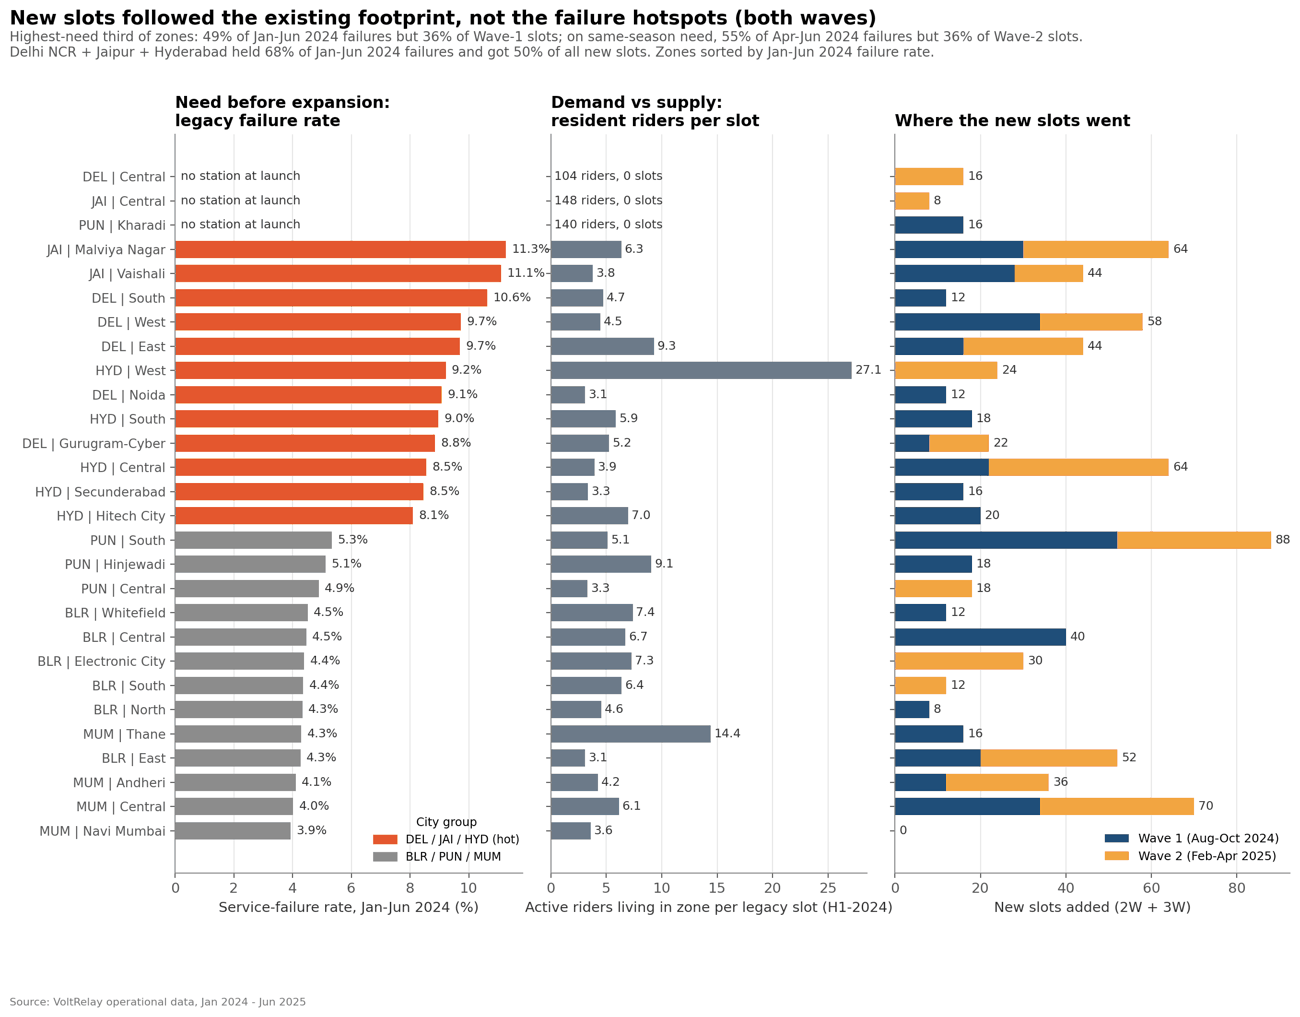

[  4.9s] saved q3_03_expansion_placement_vs_need


In [98]:
zp = zone.copy()
zp["label"] = zp.zone.str.replace("-", " | ", n=1)
zp = pd.concat([zp[zp.L_st == 0], zp[zp.L_st > 0].sort_values("failure_rate_h1_24", ascending=False)])
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True, gridspec_kw={"width_ratios": [1.1, 1, 1.25], "wspace": 0.08})
y = np.arange(len(zp))[::-1]
ax = axes[0]
cols = [PALETTE["accent"] if c in hot_cities else PALETTE["muted"] for c in zp.city]
ax.barh(y, zp.failure_rate_h1_24.fillna(0), color=cols, height=0.72)
for yi, v, ls in zip(y, zp.failure_rate_h1_24, zp.L_st):
    ax.text((0 if np.isnan(v) else v) + 0.2, yi, "no station at launch" if ls == 0 else f"{v:.1f}%", va="center", fontsize=9, color="#333333")
ax.set_yticks(y, zp.label, fontsize=9.5)
ax.set_xlabel("Service-failure rate, Jan-Jun 2024 (%)")
ax.set_title("Need before expansion:\nlegacy failure rate", fontsize=12)
from matplotlib.patches import Patch  # noqa: E402
ax.legend(handles=[Patch(color=PALETTE["accent"], label="DEL / JAI / HYD (hot)"), Patch(color=PALETTE["muted"], label="BLR / PUN / MUM")],
          loc="lower right", bbox_to_anchor=(1.02, 0.0), fontsize=8.5, title="City group", title_fontsize=8.8)
ax = axes[1]
rps = zp.riders_per_legacy_slot.fillna(0)
ax.barh(y, rps, color="#6C7A89", height=0.72)
for a_ in axes:
    a_.grid(axis="y", visible=False); a_.set_axisbelow(True)
for yi, v, r, ls in zip(y, rps, zp.riders_active_h1_24, zp.L_st):
    ax.text(v + 0.3, yi, f"{int(r)} riders, 0 slots" if ls == 0 else f"{v:.1f}", va="center", fontsize=9, color="#333333")
ax.set_xlabel("Active riders living in zone per legacy slot (H1-2024)")
ax.set_title("Demand vs supply:\nresident riders per slot", fontsize=12)
ax = axes[2]
ax.barh(y, zp.W1_slots, color=WAVE_COLORS["Wave1_2024H2"], height=0.72, label=WAVE_LABEL["Wave1_2024H2"])
ax.barh(y, zp.W2_slots, left=zp.W1_slots, color=WAVE_COLORS["Wave2_2025H1"], height=0.72, label=WAVE_LABEL["Wave2_2025H1"])
for yi, a, b in zip(y, zp.W1_slots, zp.W2_slots):
    ax.text(a + b + 1, yi, f"{int(a+b)}", va="center", fontsize=9, color="#333333")
ax.set_xlabel("New slots added (2W + 3W)")
ax.set_title("Where the new slots went", fontsize=12)
ax.legend(loc="lower right", fontsize=9)
w1r = placement.set_index(["wave", "need_tercile"])
fig.suptitle("New slots followed the existing footprint, not the failure hotspots (both waves)",
             x=0.01, ha="left", fontsize=14.5, fontweight="bold", y=1.01)
fig.text(0.01, 0.958, f"Highest-need third of zones: {w1r.loc[('Wave1','high'),'share_of_failures']:.0%} of Jan-Jun 2024 failures but "
         f"{w1r.loc[('Wave1','high'),'share_of_new_slots']:.0%} of Wave-1 slots; on same-season need, "
         f"{w1r.loc[('Wave2','high'),'share_of_failures']:.0%} of Apr-Jun 2024 failures but {w1r.loc[('Wave2','high'),'share_of_new_slots']:.0%} of Wave-2 slots.\n"
         f"Delhi NCR + Jaipur + Hyderabad held {city.loc[hot_cities,'share_failures_h1_24'].sum():.0%} of Jan-Jun 2024 failures and got "
         f"{city.loc[hot_cities,'share_new_slots'].sum():.0%} of all new slots. Zones sorted by Jan-Jun 2024 failure rate.",
         fontsize=10, color="#555555", va="bottom")
save_fig(fig, "q3_03_expansion_placement_vs_need")
say("saved q3_03_expansion_placement_vs_need")

### 4b. Utilisation and fixed cost per swap: new vs legacy stations
Apr-Jun 2025 (all stations live). Also a ramp curve: new-station utilisation relative to legacy stations in the same
city and month, by months since commissioning (removes seasonality and city mix).

In [99]:
q2s = (SMp[SMp.period == "Q2_25"].groupby(["station_id", "expansion_wave", "city", "zone", "location_type", "charger_generation"])
       .agg(completed=("completed", "sum"), attempts=("attempts", "sum"), failures=("failures", "sum"), fixed_cost=("fixed_cost", "sum"),
            slot_days=("slot_days", "sum"), cm1=("cm1", "sum"), cm2=("cm2", "sum"), revenue=("revenue", "sum")).reset_index())
q2s["swaps_per_slot_day"] = q2s.completed / q2s.slot_days
q2s["fixed_cost_per_swap"] = q2s.fixed_cost / q2s.completed
q2s["cm1_per_swap"] = q2s.cm1 / q2s.completed
q2s["cm2_per_swap"] = q2s.cm2 / q2s.completed
q2s.to_csv(TAB / "q3_station_q2_2025_utilisation_cost.csv", index=False)
wv = q2s.groupby("expansion_wave").agg(stations=("station_id", "count"), completed=("completed", "sum"), fixed_cost=("fixed_cost", "sum"),
                                       slot_days=("slot_days", "sum"), cm1=("cm1", "sum"), cm2=("cm2", "sum"),
                                       median_util=("swaps_per_slot_day", "median"), median_fixed_per_swap=("fixed_cost_per_swap", "median"))
wv["swaps_per_slot_day"] = wv.completed / wv.slot_days
wv["fixed_cost_per_swap"] = wv.fixed_cost / wv.completed
wv["cm1_per_swap"] = wv.cm1 / wv.completed
wv["cm2_per_swap"] = wv.cm2 / wv.completed
wv["share_swaps"] = wv.completed / wv.completed.sum()
wv["share_fixed_cost"] = wv.fixed_cost / wv.fixed_cost.sum()
wv.to_csv(TAB / "q3_wave_economics_q2_2025.csv")
say("Apr-Jun 2025 economics by wave (under our usage-based battery-depreciation assumption):\n" + wv.round(3).to_string())
net_fps = q2s.fixed_cost.sum() / q2s.completed.sum()
leg = q2s[q2s.expansion_wave == "Launch"]
say(f"Network fixed cost per swap Apr-Jun 2025: Rs {net_fps:.2f}; legacy stations alone Rs {leg.fixed_cost.sum()/leg.completed.sum():.2f}; "
    f"new stations Rs {q2s[q2s.expansion_wave!='Launch'].fixed_cost.sum()/q2s[q2s.expansion_wave!='Launch'].completed.sum():.2f}")
new = q2s[q2s.expansion_wave != "Launch"]
say(f"New stations: {len(new)} of {len(q2s)} stations, {new.completed.sum()/q2s.completed.sum():.1%} of Q2-25 swaps, "
    f"{new.fixed_cost.sum()/q2s.fixed_cost.sum():.1%} of fixed cost; stations with fixed cost/swap > Rs 20: "
    f"new {int((new.fixed_cost_per_swap > 20).sum())}, legacy {int((leg.fixed_cost_per_swap > 20).sum())}")
loc_util = q2s[q2s.expansion_wave != "Launch"].groupby(["expansion_wave", "location_type"]).agg(
    stations=("station_id", "count"), completed=("completed", "sum"), slot_days=("slot_days", "sum"), fixed=("fixed_cost", "sum"))
loc_util["swaps_per_slot_day"] = loc_util.completed / loc_util.slot_days
loc_util["fixed_cost_per_swap"] = loc_util.fixed / loc_util.completed
say("New stations by wave x location type (Apr-Jun 2025):\n" + loc_util.round(2).to_string())
top_new = q2s[q2s.expansion_wave != "Launch"].sort_values("swaps_per_slot_day", ascending=False).head(6)
say("Busiest new stations (Apr-Jun 2025):\n" + top_new[["station_id", "expansion_wave", "zone", "location_type", "swaps_per_slot_day",
                                                       "fixed_cost_per_swap", "slot_days"]].round(2).to_string(index=False))
nz = q2s[q2s.zone.isin(no_station_zones.zone)]
say(f"New stations in the 3 previously unserved zones (n = {len(nz)} stations): {nz.completed.sum()/nz.slot_days.sum():.2f} swaps/slot-day vs "
    f"{new.completed.sum()/new.slot_days.sum():.2f} for all new stations (Apr-Jun 2025) = "
    f"{(nz.completed.sum()/nz.slot_days.sum())/(new.completed.sum()/new.slot_days.sum()):.2f}x")
say("  the unserved-zone stations individually (all highway fuel pumps -> small n, one outlier):\n"
    + nz[["station_id", "expansion_wave", "zone", "location_type", "swaps_per_slot_day", "fixed_cost_per_swap"]].round(2).to_string(index=False))


def util_cost(d):
    return pd.Series({"stations": d.station_id.nunique(), "swaps_per_slot_day": d.completed.sum() / d.slot_days.sum(),
                      "fixed_cost_per_swap": d.fixed_cost.sum() / d.completed.sum()})

[  4.9s] Apr-Jun 2025 economics by wave (under our usage-based battery-depreciation assumption):
                stations  completed    fixed_cost  slot_days            cm1            cm2  median_util  median_fixed_per_swap  swaps_per_slot_day  fixed_cost_per_swap  cm1_per_swap  cm2_per_swap  share_swaps  share_fixed_cost
expansion_wave                                                                                                                                                                                                                    
Launch                90     558437 6,327,288.000     123032 -3,133,103.235 -9,460,391.235        4.201                 11.197               4.539               11.330        -5.610       -16.941        0.623             0.600
Wave1_2024H2          30     148486 2,187,625.258      39748   -522,587.312 -2,710,212.570        3.427                 16.012               3.736               14.733        -3.519       -18.252        0.166             0

[  4.9s] Network fixed cost per swap Apr-Jun 2025: Rs 11.76; legacy stations alone Rs 11.33; new stations Rs 12.48


[  4.9s] New stations: 60 of 150 stations, 37.7% of Q2-25 swaps, 40.0% of fixed cost; stations with fixed cost/swap > Rs 20: new 16, legacy 10


[  4.9s] New stations by wave x location type (Apr-Jun 2025):
                                  stations  completed  slot_days         fixed  swaps_per_slot_day  fixed_cost_per_swap
expansion_wave location_type                                                                                           
Wave1_2024H2   commercial_hub            1      13428       1456    80,421.000               9.220                5.990
               highway_fuel_pump        14      67700      19292 1,081,269.000               3.510               15.970
               residential              13      56182      15906   849,739.260               3.530               15.120
               tech_park                 1       6293       1638    65,364.000               3.840               10.390
               transit_hub               1       4883       1456   110,832.000               3.350               22.700
Wave2_2025H1   commercial_hub            4      32102       3640   237,615.000               8.820

[  4.9s] Busiest new stations (Apr-Jun 2025):
 station_id expansion_wave                zone     location_type  swaps_per_slot_day  fixed_cost_per_swap  slot_days
STN-JAI-148   Wave2_2025H1         JAI-Central highway_fuel_pump              21.570                4.680        728
STN-HYD-087   Wave2_2025H1            HYD-West    commercial_hub              13.890                6.590        728
STN-BLR-030   Wave2_2025H1 BLR-Electronic City            market              13.390                5.410        568
STN-DEL-059   Wave2_2025H1            DEL-West    commercial_hub              10.540                8.790        728
STN-DEL-058   Wave2_2025H1         DEL-Central highway_fuel_pump               9.390                3.760       1456
STN-HYD-084   Wave2_2025H1         HYD-Central    commercial_hub               9.340                6.300        728


[  4.9s] New stations in the 3 previously unserved zones (n = 3 stations): 11.56 swaps/slot-day vs 4.56 for all new stations (Apr-Jun 2025) = 2.54x


[  4.9s]   the unserved-zone stations individually (all highway fuel pumps -> small n, one outlier):
 station_id expansion_wave        zone     location_type  swaps_per_slot_day  fixed_cost_per_swap
STN-DEL-058   Wave2_2025H1 DEL-Central highway_fuel_pump               9.390                3.760
STN-JAI-148   Wave2_2025H1 JAI-Central highway_fuel_pump              21.570                4.680
STN-PUN-106   Wave1_2024H2 PUN-Kharadi highway_fuel_pump               8.730                4.420


### 4b-ii. What drives new-station utilisation: unmet zone demand or site type?
Wave 1 is mostly fuel pumps and residential sites and under-performs; but all 3 stars in formerly unserved zones are
also fuel pumps. To separate the two we regress Apr-Jun 2025 swaps per slot-day of the 60 new stations on
log(resident riders per zone slot) (riders active in H1-2024 living in the zone / all slots in the zone after both
waves), site type (ref = market), wave and city; WLS weighted by slot-days, HC1 SEs. Cross-sectional: association.

In [100]:
NS = new.copy()
zone_i = zone.set_index("zone")
NS["riders_per_zone_slot"] = NS.zone.map(zone_i.riders_active_h1_24 / (zone_i.L_slots + zone_i.new_slots))
NS["unserved"] = NS.zone.isin(set(no_station_zones.zone)).astype(int)
fp_tab = NS[NS.location_type == "highway_fuel_pump"].groupby("unserved").apply(util_cost)
say("New highway-fuel-pump stations, Apr-Jun 2025, by zone status (1 = formerly unserved zone):\n" + fp_tab.round(2).to_string())
w1fr_ = NS[(NS.expansion_wave == "Wave1_2024H2") & NS.location_type.isin(["highway_fuel_pump", "residential"])]
say(f"Wave-1 fuel-pump + residential sites in already-served zones: {int((w1fr_.unserved == 0).sum())} of {len(w1fr_)} "
    f"(fuel pumps {int(((w1fr_.unserved == 0) & (w1fr_.location_type == 'highway_fuel_pump')).sum())} of "
    f"{int((w1fr_.location_type == 'highway_fuel_pump').sum())}, residential {int(((w1fr_.unserved == 0) & (w1fr_.location_type == 'residential')).sum())} of "
    f"{int((w1fr_.location_type == 'residential').sum())})")
SITE_RHS = "np.log(riders_per_zone_slot) + C(location_type, Treatment('market')) + C(expansion_wave) + C(city)"
m_site = smf.wls(f"swaps_per_slot_day ~ {SITE_RHS}", data=NS, weights=NS.slot_days).fit(cov_type="HC1")
m_site2 = smf.wls(f"swaps_per_slot_day ~ {SITE_RHS}", data=NS[NS.unserved == 0], weights=NS[NS.unserved == 0].slot_days).fit(cov_type="HC1")
site_rows = []
for nm, m in [("all_new_stations", m_site), ("already_served_zones_only", m_site2)]:
    for t in m.params.index:
        if t.startswith("C(city)") or t == "Intercept":
            continue
        site_rows.append({"sample": nm, "term": t.replace("C(location_type, Treatment('market'))[T.", "site: ").replace("C(expansion_wave)[T.", "wave: ")
                          .replace("]", ""), "coef": m.params[t], "ci_lo": m.conf_int().loc[t, 0], "ci_hi": m.conf_int().loc[t, 1],
                          "p": m.pvalues[t], "n": int(m.nobs), "r2": m.rsquared})
SITE = pd.DataFrame(site_rows)
SITE.to_csv(TAB / "q3_new_station_siting_model.csv", index=False)
say("New-station utilisation model (swaps/slot-day, Apr-Jun 2025; city FE not shown):\n" + SITE.round(3).to_string(index=False))
w2s = q2s[q2s.expansion_wave == "Wave2_2025H1"]
w1s = q2s[q2s.expansion_wave == "Wave1_2024H2"]
sub_econ = pd.DataFrame({
    "Legacy (Launch)": util_cost(q2s[q2s.expansion_wave == "Launch"]),
    "Wave 1 all": util_cost(w1s),
    "Wave 1 fuel pump + residential": util_cost(w1s[w1s.location_type.isin(["highway_fuel_pump", "residential"])]),
    "Wave 2 all": util_cost(w2s),
    "Wave 2 market only": util_cost(w2s[w2s.location_type == "market"]),
    "Wave 2 excl. 2 unserved-zone fuel pumps": util_cost(w2s[~w2s.station_id.isin(nz.station_id)]),
    "Unserved-zone stations (all fuel pumps)": util_cost(nz),
    "Fuel pumps in already-served zones": util_cost(NS[(NS.location_type == "highway_fuel_pump") & (NS.unserved == 0)])}).T
sub_econ.to_csv(TAB / "q3_new_station_subgroup_economics.csv")
say("Apr-Jun 2025 utilisation and fixed cost per swap by sub-group:\n" + sub_econ.round(2).to_string())

# ramp curve vs same-city legacy stations in the same month
ramp = SMp[(SMp.active_days >= 15)].copy()
ramp["util"] = ramp.completed / ramp.slot_days
legacy_cm = ramp[ramp.expansion_wave == "Launch"].groupby(["city", "month"]).apply(lambda d: pd.Series({
    "legacy_util": d.completed.sum() / d.slot_days.sum(), "legacy_att_util": d.attempts.sum() / d.slot_days.sum()}))
ramp = ramp.merge(legacy_cm.reset_index(), on=["city", "month"], how="left")
ramp["rel_util"] = ramp.util / ramp.legacy_util
ramp["age_m"] = ((pd.to_datetime(ramp.month).dt.year - pd.to_datetime(ramp.commissioned_date).dt.year) * 12
                 + pd.to_datetime(ramp.month).dt.month - pd.to_datetime(ramp.commissioned_date).dt.month)
# rel_util = completed swaps (capped by legacy stockouts in summer); rel_att = attempts (demand) - both vs same-city legacy
rc = (ramp[ramp.expansion_wave != "Launch"].groupby(["expansion_wave", "age_m"])
      .apply(lambda d: pd.Series({"stations": d.station_id.nunique(),
                                  "rel_util": (d.util * d.slot_days).sum() / (d.legacy_util * d.slot_days).sum(),
                                  "rel_att": d.attempts.sum() / (d.legacy_att_util * d.slot_days).sum()}))
      .reset_index())
rc.to_csv(TAB / "q3_new_station_ramp.csv", index=False)
say("New-station utilisation relative to same-city legacy stations, by months since commissioning:\n" + rc.round(3).to_string(index=False))
for w_, lo, hi in [("Wave1_2024H2", 1, 8), ("Wave2_2025H1", 1, 3)]:
    r_ = rc[(rc.expansion_wave == w_) & (rc.stations >= 20) & rc.age_m.between(lo, hi)]
    say(f"  {w_} months {lo}-{hi} (ages with >= 20 stations, as in Fig 4): completed basis {100*r_.rel_util.min():.0f}-{100*r_.rel_util.max():.0f}% "
        f"of same-city legacy; attempts basis {100*r_.rel_att.min():.0f}-{100*r_.rel_att.max():.0f}%")

[  4.9s] New highway-fuel-pump stations, Apr-Jun 2025, by zone status (1 = formerly unserved zone):
          stations  swaps_per_slot_day  fixed_cost_per_swap
unserved                                                   
0           16.000               3.050               19.190
1            3.000              11.560                4.310


[  4.9s] Wave-1 fuel-pump + residential sites in already-served zones: 26 of 27 (fuel pumps 13 of 14, residential 13 of 13)


[  4.9s] New-station utilisation model (swaps/slot-day, Apr-Jun 2025; city FE not shown):
                   sample                         term   coef  ci_lo  ci_hi     p  n    r2
         all_new_stations         site: commercial_hub  3.383  0.888  5.877 0.008 60 0.697
         all_new_stations      site: highway_fuel_pump -0.495 -2.369  1.379 0.604 60 0.697
         all_new_stations            site: residential -1.013 -3.107  1.081 0.343 60 0.697
         all_new_stations              site: tech_park -1.773 -3.330 -0.216 0.026 60 0.697
         all_new_stations            site: transit_hub -0.874 -2.701  0.954 0.349 60 0.697
         all_new_stations           wave: Wave2_2025H1  0.999 -0.517  2.516 0.196 60 0.697
         all_new_stations np.log(riders_per_zone_slot)  5.167  3.141  7.194 0.000 60 0.697
already_served_zones_only         site: commercial_hub  3.140  0.661  5.619 0.013 57 0.663
already_served_zones_only      site: highway_fuel_pump -1.784 -2.965 -0.602 0.003 57 0.663


[  4.9s] Apr-Jun 2025 utilisation and fixed cost per swap by sub-group:
                                         stations  swaps_per_slot_day  fixed_cost_per_swap
Legacy (Launch)                            90.000               4.540               11.330
Wave 1 all                                 30.000               3.740               14.730
Wave 1 fuel pump + residential             27.000               3.520               15.590
Wave 2 all                                 30.000               5.510               10.710
Wave 2 market only                         14.000               5.460               10.160
Wave 2 excl. 2 unserved-zone fuel pumps    28.000               4.970               11.900
Unserved-zone stations (all fuel pumps)     3.000              11.560                4.310
Fuel pumps in already-served zones         16.000               3.050               19.190


[  5.0s] New-station utilisation relative to same-city legacy stations, by months since commissioning:
expansion_wave  age_m  stations  rel_util  rel_att
  Wave1_2024H2      0    10.000     0.774    0.772
  Wave1_2024H2      1    30.000     0.848    0.849
  Wave1_2024H2      2    30.000     0.833    0.833
  Wave1_2024H2      3    30.000     0.845    0.845
  Wave1_2024H2      4    30.000     0.843    0.844
  Wave1_2024H2      5    30.000     0.821    0.821
  Wave1_2024H2      6    30.000     0.823    0.816
  Wave1_2024H2      7    30.000     0.821    0.792
  Wave1_2024H2      8    30.000     0.829    0.795
  Wave1_2024H2      9    17.000     0.938    0.891
  Wave1_2024H2     10    10.000     0.711    0.684
  Wave2_2025H1      0    16.000     1.315    1.307
  Wave2_2025H1      1    30.000     1.163    1.134
  Wave2_2025H1      2    30.000     1.227    1.159
  Wave2_2025H1      3    21.000     1.206    1.109
  Wave2_2025H1      4     9.000     1.235    1.126


[  5.0s]   Wave1_2024H2 months 1-8 (ages with >= 20 stations, as in Fig 4): completed basis 82-85% of same-city legacy; attempts basis 79-85%


[  5.0s]   Wave2_2025H1 months 1-3 (ages with >= 20 stations, as in Fig 4): completed basis 116-123% of same-city legacy; attempts basis 111-116%


### Figure 4 (hero): utilisation vs fixed cost per swap - new vs legacy

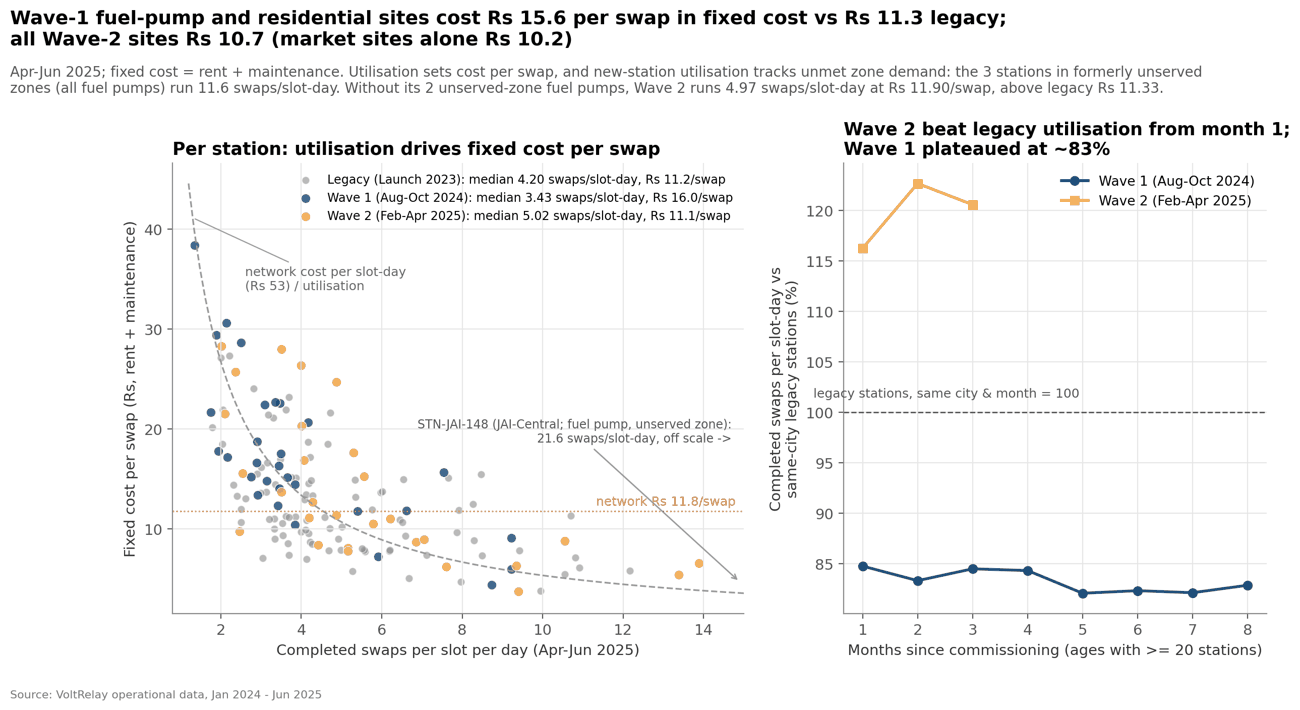

[  5.5s] saved q3_04_new_vs_legacy_utilisation_cost


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
for w in ["Launch", "Wave1_2024H2", "Wave2_2025H1"]:
    d = q2s[q2s.expansion_wave == w]
    ax.scatter(d.swaps_per_slot_day, d.fixed_cost_per_swap, s=46 if w != "Launch" else 30, color=WAVE_COLORS[w], alpha=0.85 if w != "Launch" else 0.6,
               edgecolor="white", linewidth=0.6, label=f"{WAVE_LABEL[w]}: median {d.swaps_per_slot_day.median():.2f} swaps/slot-day, "
                                                    f"Rs {d.fixed_cost_per_swap.median():.1f}/swap")
XMAX = 15
xs = np.linspace(1.2, XMAX, 100)
opex_slot_day = (q2s.fixed_cost.sum() / q2s.slot_days.sum())
ax.plot(xs, opex_slot_day / xs, color="#999999", lw=1.2, ls="--")
ax.annotate(f"network cost per slot-day\n(Rs {opex_slot_day:.0f}) / utilisation", xy=(1.3, opex_slot_day / 1.3), xytext=(2.6, 35),
            fontsize=9, color="#666666", va="center", arrowprops=dict(arrowstyle="-", color="#999999", lw=0.8))
ax.axhline(net_fps, color=PALETTE["accent"], lw=1, ls=":")
ax.text(XMAX - 0.2, net_fps + 0.6, f"network Rs {net_fps:.1f}/swap", ha="right", fontsize=9, color=PALETTE["accent"])
off = q2s[q2s.swaps_per_slot_day > XMAX]
unserved_set = set(no_station_zones.zone)
for _, r_ in off.iterrows():
    tag = "fuel pump, unserved zone" if (r_.zone in unserved_set and r_.location_type == "highway_fuel_pump") else r_.location_type.replace("_", " ")
    ax.annotate(f"{r_.station_id} ({r_.zone}; {tag}):\n{r_.swaps_per_slot_day:.1f} swaps/slot-day, off scale ->", xy=(XMAX - 0.1, r_.fixed_cost_per_swap),
                xytext=(XMAX - 0.3, r_.fixed_cost_per_swap + 14), ha="right", fontsize=8.5, color="#555555",
                arrowprops=dict(arrowstyle="->", color="#999999"))
ax.set_xlim(0.8, XMAX)
ax.set_xlabel("Completed swaps per slot per day (Apr-Jun 2025)")
ax.set_ylabel("Fixed cost per swap (Rs, rent + maintenance)")
ax.set_title("Per station: utilisation drives fixed cost per swap", fontsize=12.5)
ax.legend(loc="upper right", fontsize=8.6)
ax = axes[1]
for w, mk in [("Wave1_2024H2", "o"), ("Wave2_2025H1", "s")]:
    d = rc[(rc.expansion_wave == w) & (rc.stations >= 20)]
    ax.plot(d.age_m, 100 * d.rel_util, color=WAVE_COLORS[w], marker=mk, lw=2, ms=6, label=WAVE_LABEL[w])
ax.axhline(100, color="#555555", lw=1, ls="--")
ax.text(0.1, 101.5, "legacy stations, same city & month = 100", fontsize=9, color="#555555")
ax.set_xlabel("Months since commissioning (ages with >= 20 stations)")
ax.set_ylabel("Completed swaps per slot-day vs\nsame-city legacy stations (%)")
ax.set_title("Wave 2 beat legacy utilisation from month 1;\nWave 1 plateaued at ~83%", fontsize=12.5)
ax.legend(loc="upper right")
se_ = sub_econ
import textwrap  # noqa: E402
fig.suptitle(f"Wave-1 fuel-pump and residential sites cost Rs {se_.loc['Wave 1 fuel pump + residential','fixed_cost_per_swap']:.1f} per swap in "
             f"fixed cost vs Rs {se_.loc['Legacy (Launch)','fixed_cost_per_swap']:.1f} legacy;\nall Wave-2 sites "
             f"Rs {se_.loc['Wave 2 all','fixed_cost_per_swap']:.1f} (market sites alone Rs {se_.loc['Wave 2 market only','fixed_cost_per_swap']:.1f})",
             x=0.01, ha="left", va="bottom", fontsize=13.5, fontweight="bold", y=1.075)
sub4 = (f"Apr-Jun 2025; fixed cost = rent + maintenance. Utilisation sets cost per swap, and new-station utilisation "
        f"tracks unmet zone demand: the {int(se_.loc['Unserved-zone stations (all fuel pumps)','stations'])} stations in formerly unserved zones "
        f"(all fuel pumps) run {se_.loc['Unserved-zone stations (all fuel pumps)','swaps_per_slot_day']:.1f} swaps/slot-day. Without its 2 "
        f"unserved-zone fuel pumps, Wave 2 runs {se_.loc['Wave 2 excl. 2 unserved-zone fuel pumps','swaps_per_slot_day']:.2f} swaps/slot-day at "
        f"Rs {se_.loc['Wave 2 excl. 2 unserved-zone fuel pumps','fixed_cost_per_swap']:.2f}/swap, above legacy Rs {se_.loc['Legacy (Launch)','fixed_cost_per_swap']:.2f}.")
fig.text(0.01, 0.995, textwrap.fill(sub4, 172), fontsize=10, color="#555555", va="bottom")
save_fig(fig, "q3_04_new_vs_legacy_utilisation_cost")
say("saved q3_04_new_vs_legacy_utilisation_cost")

### 4c. Did legacy hotspot stations improve where new stations opened? (DiD)
**Design A - same-season long difference** (both waves): for every Launch station, change in failure rate
Apr-Jun 2025 vs Apr-Jun 2024, regressed on the zone's new-slot intensity (new slots / legacy slots), controlling for
the station's change in heat exposure x generation and city fixed effects.
**Design B - Wave-1 TWFE**: Launch stations in zones that got a Wave-1 station vs Launch stations in zones that did not
(Bengaluru Electronic City & South, Pune Central, Hyderabad West, Navi Mumbai), Jan 2024 - Jan 2025 (before Wave 2),
with station FE, city x month FE and generation x month FE (Gen1 has its own heat seasonality).

In [102]:
L = SMp[(SMp.expansion_wave == "Launch")].copy()
L["fail_pp"] = 100 * L.failures / L.attempts
L["util"] = L.attempts / L.slot_days
L["hot_pp"] = 100 * L.hot_share
L = L.merge(zone[["zone", "L_slots", "W1_slots", "W2_slots", "new_slots"]], on="zone", how="left")
L["intensity"] = L.new_slots / L.L_slots
pre_q2 = L[(L.month >= pd.Timestamp("2024-04-01")) & (L.month < pd.Timestamp("2024-07-01"))]
post_q2 = L[(L.month >= pd.Timestamp("2025-04-01"))]


def agg_station(d):
    return d.groupby("station_id").agg(att=("attempts", "sum"), fail=("failures", "sum"), so=("stockouts", "sum"), sd=("slot_days", "sum"),
                                       comp=("completed", "sum"), hot=("hot_pp", "mean"))


a, b = agg_station(pre_q2), agg_station(post_q2)
LD = pd.DataFrame({"d_fail_pp": 100 * b.fail / b.att - 100 * a.fail / a.att, "d_util": b.att / b.sd - a.att / a.sd,
                   "d_hot_pp": b.hot - a.hot, "fail_q2_24": 100 * a.fail / a.att, "fail_q2_25": 100 * b.fail / b.att,
                   "util_q2_24": a.att / a.sd, "util_q2_25": b.att / b.sd}).reset_index()
LD = LD.merge(st_pd[["station_id", "city", "zone", "charger_generation"]], on="station_id").merge(
    zone[["zone", "new_slots", "L_slots"]], on="zone")
LD["intensity"] = LD.new_slots / LD.L_slots
h1 = SMp[(SMp.expansion_wave == "Launch") & (SMp.period == "H1_24")].groupby("station_id").agg(a=("attempts", "sum"), f=("failures", "sum"), sd=("slot_days", "sum"))
LD["fail_h1_24"] = LD.station_id.map(100 * h1.f / h1.a)
LD["util_h1_24"] = LD.station_id.map(h1.a / h1.sd)
LD["hotspot"] = (LD.fail_h1_24 >= LD.fail_h1_24.quantile(0.75)).astype(int)
LD["busiest"] = (LD.util_h1_24 >= LD.util_h1_24.quantile(0.90)).astype(int)
mA = smf.ols("d_fail_pp ~ intensity + d_hot_pp * C(charger_generation) + C(city)", data=LD).fit(cov_type="cluster", cov_kwds={"groups": LD["zone"]})
mA_u = smf.ols("d_util ~ intensity + C(city)", data=LD).fit(cov_type="cluster", cov_kwds={"groups": LD["zone"]})
mA_h = smf.ols("d_fail_pp ~ intensity * hotspot + d_hot_pp * C(charger_generation) + C(city)", data=LD).fit(cov_type="cluster", cov_kwds={"groups": LD["zone"]})
say(f"Design A (n={len(LD)} Launch stations, SE clustered by zone): change in failure rate per +1.0 new-slot intensity = "
    f"{mA.params['intensity']:.2f} pp (95% CI {mA.conf_int().loc['intensity',0]:.2f} to {mA.conf_int().loc['intensity',1]:.2f}, p={mA.pvalues['intensity']:.3f}); "
    f"change in attempts/slot-day = {mA_u.params['intensity']:.2f} (p={mA_u.pvalues['intensity']:.3f}); "
    f"extra for hotspot stations = {mA_h.params['intensity:hotspot']:.2f} pp (p={mA_h.pvalues['intensity:hotspot']:.3f})")
say(f"  median zone intensity = {LD.intensity.median():.2f} -> implied effect {mA.params['intensity']*LD.intensity.median():.2f} pp; "
    f"Launch-station mean d_fail Q2-25 vs Q2-24 = {LD.d_fail_pp.mean():.2f} pp, d_hot = {LD.d_hot_pp.mean():.2f} pp")
LD.to_csv(TAB / "q3_legacy_station_long_difference.csv", index=False)

# Design B: Wave-1 staggered TWFE on Launch stations, Jan 2024 - Jan 2025
w1_first = st_pd[st_pd.expansion_wave == "Wave1_2024H2"].groupby("zone").commissioned_date.min()
B = L[(L.month <= pd.Timestamp("2025-01-01")) & (L.active_days >= 15)].copy()
B["w1_date"] = pd.to_datetime(B.zone.map(w1_first))
B["treated_zone"] = B.w1_date.notna().astype(int)
B["post"] = ((B.treated_zone == 1) & (pd.to_datetime(B.month) > B.w1_date)).astype(int)  # months fully after first W1 opening in zone
B = B[~((B.treated_zone == 1) & (pd.to_datetime(B.month).dt.to_period("M") == B.w1_date.dt.to_period("M")))]  # drop opening month
B["month_s"] = B.month.astype(str)
B["cm"] = B.city + "_" + B.month_s
B["gm"] = B.charger_generation + "_" + B.month_s
did_rows = []
for yname, w in [("fail_pp", "attempts"), ("util", "slot_days")]:
    m = smf.wls(f"{yname} ~ post + C(station_id) + C(cm) + C(gm)", data=B, weights=B[w]).fit(cov_type="cluster", cov_kwds={"groups": B["station_id"]})
    did_rows.append({"design": "B_wave1_twfe", "outcome": yname, "coef": m.params["post"], "ci_lo": m.conf_int().loc["post", 0],
                     "ci_hi": m.conf_int().loc["post", 1], "p": m.pvalues["post"], "n": int(m.nobs),
                     "treated_stations": B[B.treated_zone == 1].station_id.nunique(), "control_stations": B[B.treated_zone == 0].station_id.nunique()})
for nm, m in [("fail_pp", mA), ("util", mA_u)]:
    did_rows.append({"design": "A_long_difference_q2", "outcome": nm, "coef": m.params["intensity"], "ci_lo": m.conf_int().loc["intensity", 0],
                     "ci_hi": m.conf_int().loc["intensity", 1], "p": m.pvalues["intensity"], "n": int(m.nobs)})
DID = pd.DataFrame(did_rows)
DID.to_csv(TAB / "q3_legacy_did_results.csv", index=False)
say("Legacy-station DiD results:\n" + DID.round(3).to_string(index=False))

[  5.5s] Design A (n=90 Launch stations, SE clustered by zone): change in failure rate per +1.0 new-slot intensity = -0.26 pp (95% CI -0.46 to -0.05, p=0.013); change in attempts/slot-day = 0.38 (p=0.292); extra for hotspot stations = 0.56 pp (p=0.286)


[  5.5s]   median zone intensity = 0.60 -> implied effect -0.16 pp; Launch-station mean d_fail Q2-25 vs Q2-24 = -0.13 pp, d_hot = 0.30 pp


[  5.6s] Legacy-station DiD results:
              design outcome   coef  ci_lo  ci_hi     p    n  treated_stations  control_stations
        B_wave1_twfe fail_pp  0.145 -0.132  0.423 0.305 1096            74.000            16.000
        B_wave1_twfe    util -0.006 -0.313  0.300 0.967 1096            74.000            16.000
A_long_difference_q2 fail_pp -0.257 -0.460 -0.054 0.013   90               NaN               NaN
A_long_difference_q2    util  0.376 -0.323  1.076 0.292   90               NaN               NaN


### 4d. Network average vs the busiest / hotspot stations (same season: Apr-Jun 2024 vs Apr-Jun 2025)

In [103]:
def rate(d):
    return 100 * d.failures.sum() / d.attempts.sum()


q2_24_all = SMp[(SMp.month >= pd.Timestamp("2024-04-01")) & (SMp.month < pd.Timestamp("2024-07-01"))]
q2_25_all = SMp[SMp.period == "Q2_25"]
busiest_ids = set(LD.loc[LD.busiest == 1, "station_id"]); hotspot_ids = set(LD.loc[LD.hotspot == 1, "station_id"])
gen1_hot_ids = set(st_pd[(st_pd.charger_generation == "Gen1") & st_pd.city.isin(hot_cities)].station_id)
groups = [("Network (all stations)", lambda d: d), ("Legacy stations", lambda d: d[d.expansion_wave == "Launch"]),
          ("New stations (Wave 1+2)", lambda d: d[d.expansion_wave != "Launch"]),
          ("Busiest 10% legacy (H1-24 util.)", lambda d: d[d.station_id.isin(busiest_ids)]),
          ("Hotspot 25% legacy (H1-24 failures)", lambda d: d[d.station_id.isin(hotspot_ids)]),
          ("Gen1 legacy in Delhi/Jaipur/Hyd", lambda d: d[d.station_id.isin(gen1_hot_ids)])]
def att_per_slot_day(d):
    return d.attempts.sum() / d.slot_days.sum() if len(d) else np.nan


nvb = pd.DataFrame([{"group": g, "stations_q2_25": f(q2_25_all).station_id.nunique(),
                     "fail_q2_24": rate(f(q2_24_all)) if len(f(q2_24_all)) else np.nan, "fail_q2_25": rate(f(q2_25_all)),
                     "failed_q2_24": int(f(q2_24_all).failures.sum()), "failed_q2_25": int(f(q2_25_all).failures.sum()),
                     "attempts_q2_24": int(f(q2_24_all).attempts.sum()), "attempts_q2_25": int(f(q2_25_all).attempts.sum()),
                     "att_per_slot_day_q2_24": att_per_slot_day(f(q2_24_all)), "att_per_slot_day_q2_25": att_per_slot_day(f(q2_25_all))}
                    for g, f in groups])
nvb["change_pp"] = nvb.fail_q2_25 - nvb.fail_q2_24
nvb["failed_change_pct"] = 100 * (nvb.failed_q2_25 / nvb.failed_q2_24.replace(0, np.nan) - 1)
nvb["attempts_change_pct"] = 100 * (nvb.attempts_q2_25 / nvb.attempts_q2_24.replace(0, np.nan) - 1)
nvb.to_csv(TAB / "q3_network_vs_busiest.csv", index=False)
say("Network average vs busiest/hotspot stations (Apr-Jun 2024 vs Apr-Jun 2025) - rates:\n"
    + nvb[["group", "stations_q2_25", "fail_q2_24", "fail_q2_25", "change_pp"]].round(2).to_string(index=False))
say("Same comparison - counts and load (failed attempts, attempts, attempts per slot-day):\n"
    + nvb[["group", "failed_q2_24", "failed_q2_25", "failed_change_pct", "attempts_q2_24", "attempts_q2_25", "attempts_change_pct",
           "att_per_slot_day_q2_24", "att_per_slot_day_q2_25"]].round(2).to_string(index=False))
# is the hotspot failure RATE load-sensitive at all? within-station Gen1 model (station + month FE, heat held fixed)
g1P = P[P.charger_generation == "Gen1"].dropna(subset=["hot_pp"])
m_load = smf.wls("fail_pp ~ hot_pp + log_util + C(station_id) + C(month_s)", data=g1P, weights=g1P["attempts"]).fit(
    cov_type="cluster", cov_kwds={"groups": g1P["station_id"]})
say(f"Load test, Gen1 station-months (n={int(m_load.nobs):,}, station + month FE, heat share held fixed): log attempts per slot-day "
    f"{m_load.params['log_util']:+.3f} pp (95% CI {m_load.conf_int().loc['log_util',0]:.2f} to {m_load.conf_int().loc['log_util',1]:.2f}, "
    f"p={m_load.pvalues['log_util']:.2f}); hot_pp {m_load.params['hot_pp']:+.3f} pp -> failure rates at Gen1 stations do not respond to load, "
    f"so relieving load (new stations nearby) cannot lower them")
say(f"Busiest-decile legacy stations: {len(busiest_ids)}; hotspot-quartile: {len(hotspot_ids)}; overlap hotspot & Gen1-hot-city: "
    f"{len(hotspot_ids & gen1_hot_ids)} of {len(hotspot_ids)}")
net_fail_q2_25 = int(q2_25_all.failures.sum())
g1h = q2_25_all[q2_25_all.station_id.isin(gen1_hot_ids)]
cf25 = CFT[CFT.period == "Apr-Jun 2025"].set_index("counterfactual")
say(f"Network failed attempts Apr-Jun 2025: {net_fail_q2_25:,}; the 36 hot-city Gen1 stations: {int(g1h.failures.sum()):,} "
    f"({g1h.failures.sum()/net_fail_q2_25:.1%}) from {g1h.attempts.sum()/q2_25_all.attempts.sum():.1%} of attempts; counterfactual avoids "
    f"{cf25.loc['Gen1 -> Gen2','failed_attempts_avoided']/net_fail_q2_25:.1%} (Gen2-like) to {cf25.loc['Gen1 -> Gen3','failed_attempts_avoided']/net_fail_q2_25:.1%} (Gen3-like) of network failures")
off_all = SMp[~pd.to_datetime(SMp.month).dt.month.isin([4, 5, 6])]
base_rate = off_all.failures.sum() / off_all.attempts.sum()
ex_net = q2_25_all.failures.sum() - base_rate * q2_25_all.attempts.sum()
ex_g1 = g1h.failures.sum() - base_rate * g1h.attempts.sum()
say(f"Excess failed attempts Apr-Jun 2025 above the {100*base_rate:.2f}% off-season (non Apr-Jun) network baseline: network {ex_net:,.0f}; "
    f"36 hot-city Gen1 stations {ex_g1:,.0f} ({ex_g1/ex_net:.1%} of the excess)")
w1 = wv.loc["Wave1_2024H2"]; lg = wv.loc["Launch"]
w1_excess = (w1.fixed_cost_per_swap - lg.fixed_cost_per_swap) * w1.completed
say(f"Wave-1 fixed-cost drag: Rs {w1.fixed_cost_per_swap:.2f} vs legacy Rs {lg.fixed_cost_per_swap:.2f} per swap -> "
    f"Rs {w1_excess/1e5:.2f} lakh excess fixed cost in Apr-Jun 2025 (Rs {w1_excess/3/1e5:.2f} lakh/month); "
    f"new stations lift network fixed cost/swap by Rs {net_fps - lg.fixed_cost_per_swap:.2f}")

# monthly failure-rate series by group (for figure 5)
SMp["grp"] = np.select([SMp.station_id.isin(hotspot_ids), SMp.expansion_wave == "Launch"],
                       ["Legacy hotspots (23 Gen1 stations, Delhi/Jaipur/Hyd)", "Other legacy stations (67)"], "New stations (Wave 1 + 2)")
mser = SMp.groupby(["month", "grp"]).apply(lambda d: 100 * d.failures.sum() / d.attempts.sum()).rename("fail").reset_index()
net_m = SMp.groupby("month").apply(lambda d: 100 * d.failures.sum() / d.attempts.sum()).rename("fail").reset_index().assign(grp="Network average")
mser = pd.concat([mser, net_m])
mser.to_csv(TAB / "q3_monthly_failure_by_group.csv", index=False)
off_season = SMp[~pd.to_datetime(SMp.month).dt.month.isin([4, 5, 6])].groupby("grp").apply(lambda d: 100 * d.failures.sum() / d.attempts.sum())
say("Failure rate outside Apr-Jun, by station group (%): " + "; ".join(f"{k}: {v:.2f}" for k, v in off_season.items()))

[  5.7s] Network average vs busiest/hotspot stations (Apr-Jun 2024 vs Apr-Jun 2025) - rates:
                              group  stations_q2_25  fail_q2_24  fail_q2_25  change_pp
             Network (all stations)             150       9.520       7.920     -1.610
                    Legacy stations              90       9.520       9.550      0.030
            New stations (Wave 1+2)              60         NaN       5.080        NaN
   Busiest 10% legacy (H1-24 util.)               9      10.090       9.670     -0.430
Hotspot 25% legacy (H1-24 failures)              23      16.700      16.610     -0.090
    Gen1 legacy in Delhi/Jaipur/Hyd              36      15.480      15.200     -0.280


[  5.7s] Same comparison - counts and load (failed attempts, attempts, attempts per slot-day):
                              group  failed_q2_24  failed_q2_25  failed_change_pct  attempts_q2_24  attempts_q2_25  attempts_change_pct  att_per_slot_day_q2_24  att_per_slot_day_q2_25
             Network (all stations)         39820         77445             94.490          418060          977939              133.920                   3.400                   4.960
                    Legacy stations         39820         59281             48.870          418060          620420               48.400                   3.400                   5.040
            New stations (Wave 1+2)             0         18164                NaN               0          357519                  NaN                     NaN                   4.820
   Busiest 10% legacy (H1-24 util.)          4572          6864             50.130           45307           71013               56.740                   6.550          

[  5.7s] Load test, Gen1 station-months (n=918, station + month FE, heat share held fixed): log attempts per slot-day -0.028 pp (95% CI -0.70 to 0.65, p=0.94); hot_pp +0.411 pp -> failure rates at Gen1 stations do not respond to load, so relieving load (new stations nearby) cannot lower them


[  5.7s] Busiest-decile legacy stations: 9; hotspot-quartile: 23; overlap hotspot & Gen1-hot-city: 23 of 23


[  5.7s] Network failed attempts Apr-Jun 2025: 77,445; the 36 hot-city Gen1 stations: 40,723 (52.6%) from 27.4% of attempts; counterfactual avoids 25.5% (Gen2-like) to 35.8% (Gen3-like) of network failures


[  5.7s] Excess failed attempts Apr-Jun 2025 above the 3.91% off-season (non Apr-Jun) network baseline: network 39,207; 36 hot-city Gen1 stations 30,248 (77.1% of the excess)


[  5.7s] Wave-1 fixed-cost drag: Rs 14.73 vs legacy Rs 11.33 per swap -> Rs 5.05 lakh excess fixed cost in Apr-Jun 2025 (Rs 1.68 lakh/month); new stations lift network fixed cost/swap by Rs 0.43


[  5.7s] Failure rate outside Apr-Jun, by station group (%): Legacy hotspots (23 Gen1 stations, Delhi/Jaipur/Hyd): 3.85; New stations (Wave 1 + 2): 3.92; Other legacy stations (67): 3.93


### Figure 5: the network average improves, the hotspots do not

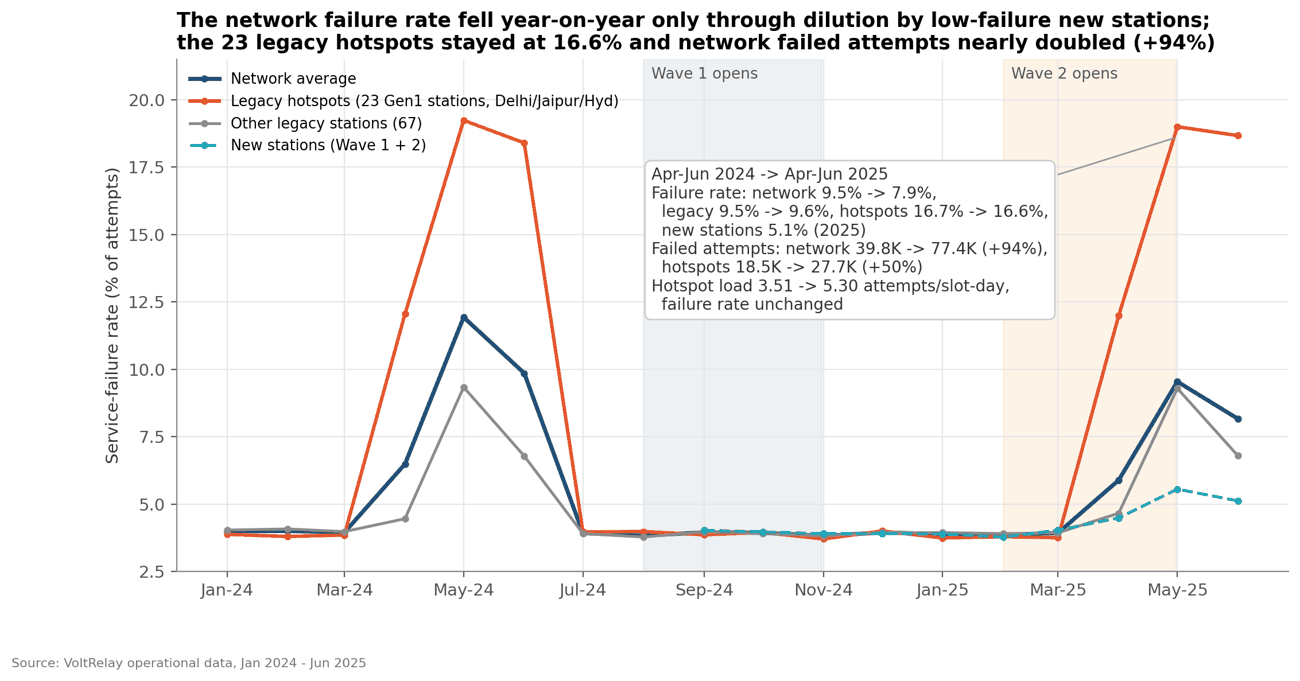

[  6.1s] saved q3_05_network_vs_hotspots


In [104]:
fig, ax = plt.subplots(figsize=(12.5, 5.8))
sty = {"Network average": (PALETTE["primary"], "-", 2.6), "Legacy hotspots (23 Gen1 stations, Delhi/Jaipur/Hyd)": (PALETTE["accent"], "-", 2.2),
       "Other legacy stations (67)": (PALETTE["muted"], "-", 1.8), "New stations (Wave 1 + 2)": (SERIES[5], "--", 1.8)}
for g_, (c_, ls_, lw_) in sty.items():
    d = mser[mser.grp == g_].sort_values("month")
    if g_ == "New stations (Wave 1 + 2)":
        d = d[pd.to_datetime(d.month) >= pd.Timestamp("2024-09-01")]
    ax.plot(pd.to_datetime(d.month), d.fail, color=c_, ls=ls_, lw=lw_, marker="o", ms=3.5, label=g_)
ax.set_ylim(2.5, 21.5)
ax.axvspan(pd.Timestamp("2024-08-01"), pd.Timestamp("2024-10-31"), color=WAVE_COLORS["Wave1_2024H2"], alpha=0.08)
ax.axvspan(pd.Timestamp("2025-02-01"), pd.Timestamp("2025-04-30"), color=WAVE_COLORS["Wave2_2025H1"], alpha=0.12)
ax.text(pd.Timestamp("2024-08-05"), 21.2, "Wave 1 opens", fontsize=9.5, color="#555555", va="top")
ax.text(pd.Timestamp("2025-02-05"), 21.2, "Wave 2 opens", fontsize=9.5, color="#555555", va="top")
nv = nvb.set_index("group")
HS_ = "Hotspot 25% legacy (H1-24 failures)"; NW_ = "Network (all stations)"
ax.annotate(f"Apr-Jun 2024 -> Apr-Jun 2025\nFailure rate: network {nv.loc[NW_,'fail_q2_24']:.1f}% -> {nv.loc[NW_,'fail_q2_25']:.1f}%,"
            f"\n  legacy {nv.loc['Legacy stations','fail_q2_24']:.1f}% -> {nv.loc['Legacy stations','fail_q2_25']:.1f}%, "
            f"hotspots {nv.loc[HS_,'fail_q2_24']:.1f}% -> {nv.loc[HS_,'fail_q2_25']:.1f}%,"
            f"\n  new stations {nv.loc['New stations (Wave 1+2)','fail_q2_25']:.1f}% (2025)"
            f"\nFailed attempts: network {nv.loc[NW_,'failed_q2_24']/1e3:.1f}K -> {nv.loc[NW_,'failed_q2_25']/1e3:.1f}K "
            f"({nv.loc[NW_,'failed_change_pct']:+.0f}%),\n  hotspots {nv.loc[HS_,'failed_q2_24']/1e3:.1f}K -> {nv.loc[HS_,'failed_q2_25']/1e3:.1f}K "
            f"({nv.loc[HS_,'failed_change_pct']:+.0f}%)\nHotspot load {nv.loc[HS_,'att_per_slot_day_q2_24']:.2f} -> {nv.loc[HS_,'att_per_slot_day_q2_25']:.2f} "
            f"attempts/slot-day,\n  failure rate unchanged",
            xy=(pd.Timestamp("2025-05-01"), nv.loc["Hotspot 25% legacy (H1-24 failures)", "fail_q2_25"] + 2), xytext=(pd.Timestamp("2024-08-05"), 17.5),
            fontsize=10, color="#333333", va="top", bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#cccccc"),
            arrowprops=dict(arrowstyle="-", color="#999999"))
import matplotlib.dates as mdates  # noqa: E402
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_ylabel("Service-failure rate (% of attempts)")
ax.set_title("The network failure rate fell year-on-year only through dilution by low-failure new stations;\n"
             f"the 23 legacy hotspots stayed at {nv.loc[HS_,'fail_q2_25']:.1f}% and network failed attempts nearly doubled "
             f"({nv.loc[NW_,'failed_change_pct']:+.0f}%)", fontsize=12.5)
ax.legend(loc="upper left", fontsize=9.2)
save_fig(fig, "q3_05_network_vs_hotspots")
say("saved q3_05_network_vs_hotspots")

## 5. Competitor entry (10 stations, competitor within 1.5 km from 2025-01-15)
Weekly station panel 2024-10-28 .. 2025-06-23 (all comparison stations live; entry week dropped). Treated = 8 stations
open before entry (5 Bengaluru Launch, 2 Bengaluru Wave-1, 1 Pune Wave-1); the 2 Bengaluru Wave-2 treated stations
opened after entry and are compared descriptively. Controls = untreated stations of the **same city and wave**
(both pilot cities, so the peak/off-peak pricing pilot affects both arms). TWFE: station FE + stratum x week FE,
cluster SE by station; plus an event study (4-week bins) and a within-stratum permutation test (2,000 draws).

In [105]:
WK = (events(["station_id", "week", "is_completed", "is_service_failure", "rider_id"])
      .filter(pl.col("week") >= pl.date(2024, 10, 28))
      .group_by("station_id", "week")
      .agg(pl.len().alias("attempts"), pl.col("is_completed").sum().alias("completed"),
           pl.col("is_service_failure").sum().alias("failures"), pl.col("rider_id").n_unique().alias("riders"))
      .collect(engine="streaming").to_pandas())
ENTRY_WEEK = pd.Timestamp("2025-01-13")
comp_ids = st_pd[st_pd.competitor_within_1_5km_since.notna()].station_id.tolist()
WK["week"] = pd.to_datetime(WK.week)
WK = WK[(WK.week <= pd.Timestamp("2025-06-23")) & (WK.week != ENTRY_WEEK)].merge(
    st_pd[["station_id", "city", "expansion_wave", "commissioned_date", "competitor_within_1_5km_since"]], on="station_id")
WK["stratum"] = WK.city + "_" + WK.expansion_wave
WK["treated"] = WK.station_id.isin(comp_ids).astype(int)
strata = WK[(WK.treated == 1) & (pd.to_datetime(WK.commissioned_date) < pd.Timestamp("2024-10-28"))].stratum.unique()
CW = WK[WK.stratum.isin(strata) & (pd.to_datetime(WK.commissioned_date) < pd.Timestamp("2024-10-21"))].copy()
CW["post"] = (CW.week > ENTRY_WEEK).astype(int)
CW["tp"] = CW.treated * CW.post
CW["ln_swaps"] = np.log(CW.completed.clip(lower=1))
CW["ln_riders"] = np.log(CW.riders.clip(lower=1))
CW["fail_pp"] = 100 * CW.failures / CW.attempts
CW["sw"] = CW.stratum + "_" + CW.week.dt.strftime("%Y-%m-%d")
say(f"Competitor DiD sample: {CW[CW.treated==1].station_id.nunique()} treated, {CW[CW.treated==0].station_id.nunique()} control stations, "
    f"{CW.week.nunique()} weeks, strata {sorted(CW.stratum.unique())}")
comp_rows = []
for yname, lab in [("ln_swaps", "log completed swaps/week"), ("ln_riders", "log unique riders/week"), ("fail_pp", "failure rate (pp)")]:
    fml = f"{yname} ~ tp + C(station_id) + C(sw)"
    mod = smf.wls(fml, data=CW, weights=CW.attempts) if yname == "fail_pp" else smf.ols(fml, data=CW)
    m = mod.fit(cov_type="cluster", cov_kwds={"groups": CW["station_id"]})
    comp_rows.append({"outcome": lab, "did": m.params["tp"], "ci_lo": m.conf_int().loc["tp", 0], "ci_hi": m.conf_int().loc["tp", 1],
                      "p_cluster": m.pvalues["tp"], "pct_effect": (np.exp(m.params["tp"]) - 1) * 100 if yname != "fail_pp" else np.nan})
# permutation test on station-level pre/post differences, within strata
sd_ = CW.groupby(["station_id", "stratum", "treated", "post"]).agg(ln_swaps=("ln_swaps", "mean"), ln_riders=("ln_riders", "mean")).unstack("post")
rng = np.random.default_rng(59500)
for i, yname in enumerate(["ln_swaps", "ln_riders"]):
    dlt = (sd_[(yname, 1)] - sd_[(yname, 0)]).rename("d").reset_index()

    def did_est(lbl):
        tot, wts = 0.0, 0
        for s, g in dlt.assign(lbl=lbl).groupby("stratum"):
            nt = int(g.lbl.sum())
            if 0 < nt < len(g):
                tot += nt * (g.d[g.lbl == 1].mean() - g.d[g.lbl == 0].mean()); wts += nt
        return tot / wts

    actual = did_est(dlt.treated.values)
    perms = []
    for _ in range(2000):
        lbl = dlt.treated.values.copy()
        for s in dlt.stratum.unique():
            idx = np.where(dlt.stratum.values == s)[0]
            lbl[idx] = rng.permutation(lbl[idx])
        perms.append(did_est(lbl))
    perms = np.array(perms)
    comp_rows[i]["perm_did"] = actual
    comp_rows[i]["p_permutation"] = float((np.abs(perms) >= abs(actual) - 1e-12).mean())
COMPDID = pd.DataFrame(comp_rows)
COMPDID.to_csv(TAB / "q3_competitor_did.csv", index=False)
say("Competitor entry DiD (TWFE, station + stratum x week FE):\n" + COMPDID.round(4).to_string(index=False))
say(f"Swaps effect in %: {COMPDID.loc[0,'pct_effect']:.1f}% (95% CI {100*(np.exp(COMPDID.loc[0,'ci_lo'])-1):.1f}% to "
    f"{100*(np.exp(COMPDID.loc[0,'ci_hi'])-1):+.1f}%)")
se_sw = (COMPDID.loc[0, "ci_hi"] - COMPDID.loc[0, "ci_lo"]) / 3.92
say(f"Minimum detectable effect on swaps (80% power, 5% two-sided) ~ {100*(1-np.exp(-2.8*se_sw)):.1f}% decline")
# robustness: station-specific linear trends (does the late event-study drift survive?)
CW["t_wk"] = (CW.week - CW.week.min()).dt.days / 7
m_tr = smf.ols("ln_swaps ~ tp + C(station_id) + C(station_id):t_wk + C(sw)", data=CW).fit(cov_type="cluster", cov_kwds={"groups": CW["station_id"]})
trend_pct, trend_p = 100 * (np.exp(m_tr.params["tp"]) - 1), m_tr.pvalues["tp"]
say(f"Robustness - DiD with station-specific linear trends: swaps {trend_pct:+.1f}% (p={trend_p:.2f}) -> the post-entry drift is not robust")

# event study (4-week bins; ref = 4 weeks before entry)
CW["rel"] = ((CW.week - ENTRY_WEEK).dt.days // 7).astype(int)
CW["bin"] = np.where(CW.rel < 0, -((-CW.rel - 1) // 4) - 1, (CW.rel - 1) // 4)
bins = sorted(b for b in CW.bin.unique() if b != -1)
for b_ in bins:
    CW[f"tb_{'m' if b_ < 0 else 'p'}{abs(b_)}"] = ((CW.bin == b_) & (CW.treated == 1)).astype(int)
bcols = [c for c in CW.columns if c.startswith("tb_")]
es_rows = []
for yname in ["ln_swaps", "ln_riders"]:
    m = smf.ols(f"{yname} ~ {' + '.join(bcols)} + C(station_id) + C(sw)", data=CW).fit(cov_type="cluster", cov_kwds={"groups": CW["station_id"]})
    for c in bcols:
        b_ = -int(c[4:]) if c[3] == "m" else int(c[4:])
        es_rows.append({"outcome": yname, "bin": b_, "week_from": b_ * 4 + (1 if b_ >= 0 else 0), "coef": m.params[c],
                        "ci_lo": m.conf_int().loc[c, 0], "ci_hi": m.conf_int().loc[c, 1]})
    es_rows.append({"outcome": yname, "bin": -1, "week_from": -4, "coef": 0.0, "ci_lo": 0.0, "ci_hi": 0.0})
ES = pd.DataFrame(es_rows).sort_values(["outcome", "bin"])
ES["pct"] = 100 * (np.exp(ES.coef) - 1)
ES.to_csv(TAB / "q3_competitor_event_study.csv", index=False)
say("Event study (log completed swaps), coefficient by 4-week bin:\n" + ES[ES.outcome == "ln_swaps"].round(3).to_string(index=False))

# raw weekly index for the figure: treated vs control, normalised to pre-entry mean
raw = CW.groupby(["week", "treated"]).agg(completed=("completed", "mean")).reset_index()
pre_mean = raw[raw.week < ENTRY_WEEK].groupby("treated").completed.mean()
raw["idx"] = 100 * raw.completed / raw.treated.map(pre_mean)
# the two treated Wave-2 stations that opened after entry vs other Bengaluru Wave-2 stations
bw2 = q2s[(q2s.city == "Bengaluru") & (q2s.expansion_wave == "Wave2_2025H1")].assign(competitor=lambda d: d.station_id.isin(comp_ids))
bw2s = bw2.groupby("competitor").apply(lambda d: pd.Series({"stations": len(d), "swaps_per_slot_day": d.completed.sum() / d.slot_days.sum()}))
say("Bengaluru Wave-2 stations, Apr-Jun 2025, competitor nearby vs not:\n" + bw2s.round(3).to_string())

# rider-level: did riders of treated stations leave the network or just switch station?
RW = (events(["rider_id", "station_id", "week", "is_completed", "city"])
      .filter(pl.col("is_completed") & pl.col("city").is_in(["Bengaluru", "Pune"]) & (pl.col("week") >= pl.date(2024, 10, 28))
              & (pl.col("week") <= pl.date(2025, 6, 23)) & (pl.col("week") != pl.date(2025, 1, 13)))
      .with_columns((pl.col("week") > pl.date(2025, 1, 13)).alias("post"))
      .group_by("rider_id", "station_id", "post").agg(pl.len().alias("swaps"))
      .collect(engine="streaming").to_pandas())
pre_r = RW[~RW.post]
# most-used pre-entry station; ties broken by station_id so the result is deterministic (polars group_by order is not)
home = (pre_r.sort_values(["rider_id", "swaps", "station_id"], ascending=[True, False, True]).drop_duplicates("rider_id")
        [["rider_id", "station_id"]].rename(columns={"station_id": "home_station"}))
home = home.merge(st_pd[["station_id", "city", "expansion_wave"]].rename(columns={"station_id": "home_station"}), on="home_station")
home["stratum"] = home.city + "_" + home.expansion_wave
home = home[home.stratum.isin(strata) & home.home_station.isin(CW.station_id.unique())]
home["treated"] = home.home_station.isin(comp_ids).astype(int)
n_pre_w = CW[CW.post == 0].week.nunique(); n_post_w = CW[CW.post == 1].week.nunique()
tot = RW.groupby(["rider_id", "post"]).swaps.sum().unstack(fill_value=0)
at_home = RW.merge(home[["rider_id", "home_station"]], on="rider_id")
at_home = at_home[at_home.station_id == at_home.home_station].groupby(["rider_id", "post"]).swaps.sum().unstack(fill_value=0)
home = home.join(tot.rename(columns={False: "tot_pre", True: "tot_post"}), on="rider_id").join(
    at_home.rename(columns={False: "home_pre", True: "home_post"}), on="rider_id").fillna(0)
home["wk_pre"] = home.tot_pre / n_pre_w; home["wk_post"] = home.tot_post / n_post_w
home["active_post"] = (home.tot_post > 0).astype(int)
home["home_share_post"] = np.where(home.tot_post > 0, home.home_post / home.tot_post.replace(0, np.nan), np.nan)
home["home_share_pre"] = home.home_pre / home.tot_pre
rid = home.groupby("treated").agg(riders=("rider_id", "count"), swaps_wk_pre=("wk_pre", "mean"), swaps_wk_post=("wk_post", "mean"),
                                  still_active_post=("active_post", "mean"), home_share_pre=("home_share_pre", "mean"),
                                  home_share_post=("home_share_post", "mean"))
rid["network_swaps_change_pct"] = 100 * (rid.swaps_wk_post / rid.swaps_wk_pre - 1)
rid.to_csv(TAB / "q3_competitor_rider_level.csv")
home["d_wk"] = home.wk_post - home.wk_pre
m_r = smf.ols("d_wk ~ treated + C(stratum)", data=home).fit(cov_type="cluster", cov_kwds={"groups": home["home_station"]})
m_a = smf.ols("active_post ~ treated + C(stratum)", data=home).fit(cov_type="cluster", cov_kwds={"groups": home["home_station"]})
say("Rider-level (riders whose most-used pre-entry station is treated vs same-stratum control):\n" + rid.round(3).to_string())
say(f"  DiD network-wide swaps/week per rider = {m_r.params['treated']:+.3f} (95% CI {m_r.conf_int().loc['treated',0]:.3f} to "
    f"{m_r.conf_int().loc['treated',1]:.3f}); still active post-entry {m_a.params['treated']*100:+.1f} pp (p={m_a.pvalues['treated']:.3f})")

[  6.2s] Competitor DiD sample: 8 treated, 21 control stations, 34 weeks, strata ['Bengaluru_Launch', 'Bengaluru_Wave1_2024H2', 'Pune_Wave1_2024H2']


[ 11.0s] Competitor entry DiD (TWFE, station + stratum x week FE):
                 outcome    did  ci_lo  ci_hi  p_cluster  pct_effect  perm_did  p_permutation
log completed swaps/week -0.040 -0.113  0.033      0.280      -3.940    -0.036          0.224
  log unique riders/week -0.013 -0.085  0.059      0.716      -1.327    -0.010          0.782
       failure rate (pp)  0.216 -0.025  0.457      0.080         NaN       NaN            NaN


[ 11.0s] Swaps effect in %: -3.9% (95% CI -10.7% to +3.3%)


[ 11.0s] Minimum detectable effect on swaps (80% power, 5% two-sided) ~ 9.9% decline


[ 11.1s] Robustness - DiD with station-specific linear trends: swaps +1.7% (p=0.58) -> the post-entry drift is not robust


[ 11.1s] Event study (log completed swaps), coefficient by 4-week bin:
 outcome  bin  week_from   coef  ci_lo  ci_hi    pct
ln_swaps   -3        -12 -0.019 -0.081  0.044 -1.847
ln_swaps   -2         -8 -0.012 -0.057  0.032 -1.230
ln_swaps   -1         -4  0.000  0.000  0.000  0.000
ln_swaps    0          1  0.011 -0.034  0.055  1.076
ln_swaps    1          5 -0.048 -0.109  0.014 -4.641
ln_swaps    2          9 -0.059 -0.140  0.022 -5.752
ln_swaps    3         13 -0.059 -0.168  0.050 -5.739
ln_swaps    4         17 -0.074 -0.185  0.036 -7.174
ln_swaps    5         21 -0.076 -0.170  0.019 -7.275


[ 11.2s] Bengaluru Wave-2 stations, Apr-Jun 2025, competitor nearby vs not:
            stations  swaps_per_slot_day
competitor                              
False          4.000               5.886
True           2.000               3.841


[ 11.3s] Rider-level (riders whose most-used pre-entry station is treated vs same-stratum control):
         riders  swaps_wk_pre  swaps_wk_post  still_active_post  home_share_pre  home_share_post  network_swaps_change_pct
treated                                                                                                                   
0          1927         4.776          4.389              0.875           0.720            0.685                    -8.102
1           647         4.743          4.290              0.881           0.714            0.678                    -9.543


[ 11.3s]

   DiD network-wide swaps/week per rider = -0.045 (95% CI -0.220 to 0.130); still active post-entry +0.5 pp (p=0.695)


### Figure 6: competitor entry event study

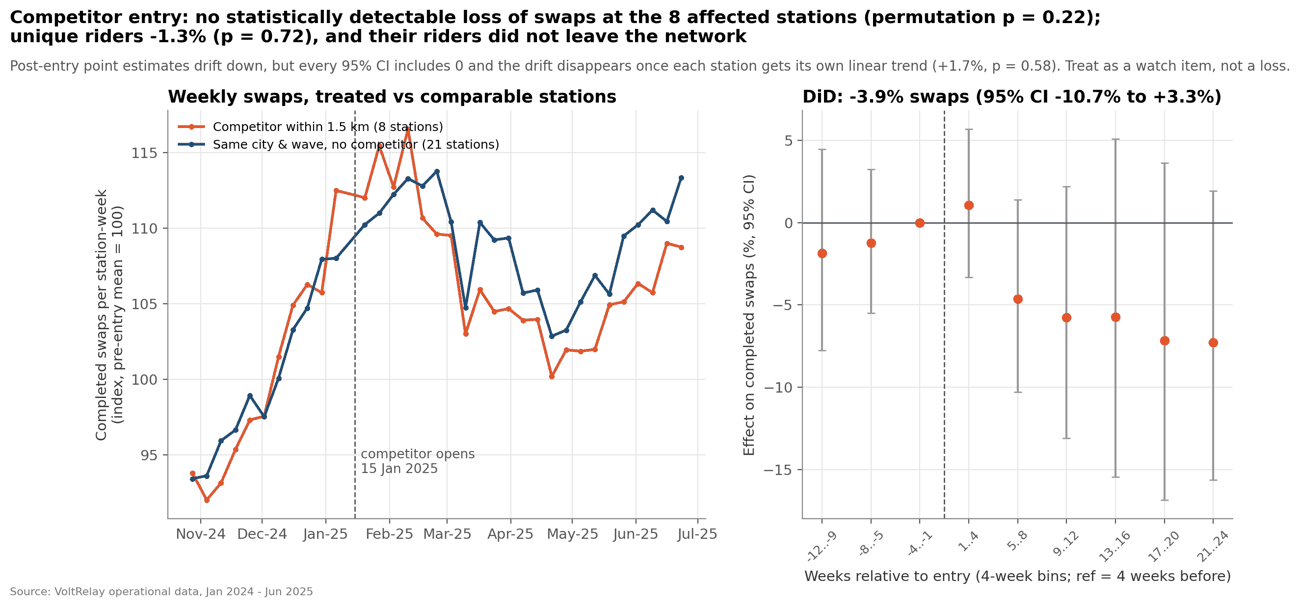

[ 11.6s] saved q3_06_competitor_entry


[ 11.6s] TOTAL RUNTIME 11.6s


In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for t_, c_, lab in [(1, PALETTE["accent"], f"Competitor within 1.5 km ({CW[CW.treated==1].station_id.nunique()} stations)"),
                    (0, PALETTE["primary"], f"Same city & wave, no competitor ({CW[CW.treated==0].station_id.nunique()} stations)")]:
    d = raw[raw.treated == t_]
    ax.plot(d.week, d.idx, color=c_, lw=2, marker="o", ms=3, label=lab)
ax.axvline(pd.Timestamp("2025-01-15"), color="#555555", ls="--", lw=1)
ax.text(pd.Timestamp("2025-01-18"), ax.get_ylim()[0] + 3, "competitor opens\n15 Jan 2025", fontsize=9.5, color="#555555")
ax.set_ylabel("Completed swaps per station-week\n(index, pre-entry mean = 100)")
ax.set_title("Weekly swaps, treated vs comparable stations", fontsize=12.5)
ax.legend(loc="upper left", fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax = axes[1]
e = ES[ES.outcome == "ln_swaps"].sort_values("bin")
ax.errorbar(e.bin, 100 * (np.exp(e.coef) - 1), yerr=[100 * (np.exp(e.coef) - np.exp(e.ci_lo)), 100 * (np.exp(e.ci_hi) - np.exp(e.coef))],
            fmt="o", color=PALETTE["accent"], ecolor="#999999", capsize=3, ms=6)
ax.axhline(0, color="#555555", lw=1); ax.axvline(-0.5, color="#555555", ls="--", lw=1)
ax.set_xticks(e.bin, [f"{int(b)*4+1}..{int(b)*4+4}" if b >= 0 else f"{int(b)*4}..{int(b)*4+3}" for b in e.bin], rotation=45, fontsize=9)
ax.set_xlabel("Weeks relative to entry (4-week bins; ref = 4 weeks before)")
ax.set_ylabel("Effect on completed swaps (%, 95% CI)")
r0 = COMPDID.iloc[0]
ax.set_title(f"DiD: {r0.pct_effect:+.1f}% swaps (95% CI {100*(np.exp(r0.ci_lo)-1):+.1f}% to {100*(np.exp(r0.ci_hi)-1):+.1f}%)", fontsize=12.5)
r1 = COMPDID.iloc[1]
fig.suptitle(f"Competitor entry: no statistically detectable loss of swaps at the 8 affected stations "
             f"(permutation p = {r0.p_permutation:.2f});\nunique riders {r1.pct_effect:+.1f}% (p = {r1.p_cluster:.2f}), and their riders did not leave the network",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.07)
fig.text(0.01, 0.955, f"Post-entry point estimates drift down, but every 95% CI includes 0 and the drift disappears once each station gets its own "
         f"linear trend ({trend_pct:+.1f}%, p = {trend_p:.2f}). Treat as a watch item, not a loss.", fontsize=10, color="#555555")
save_fig(fig, "q3_06_competitor_entry")
say("saved q3_06_competitor_entry")
say(f"TOTAL RUNTIME {time.time()-T0:.1f}s")

In [107]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 197 objects


## 8. Q4 · Battery & equipment performance

# Q4 - Battery & equipment performance
**Question.** How does battery health (SoH, charge cycles, supplier, manufacturing lot) relate to delivered range and
swap frequency? Do any equipment or supplier cohorts stand out?

**Approach.**
1. Cohort table supplier x pack type x lot (cost, initial SoH, cycles, degradation, BMS mix).
2. Degradation per pack, two ways: SoH lost per issue (the brief's per-cycle slope) and SoH lost per day in service
   (each pack's own SoH-vs-calendar-time slope). We test which one drives fade (calendar ageing vs cycling), then
   compare suppliers, lots and BMS firmware.
3. SoH trajectories by days in service (age measured from first appearance in the swap log, not the unreliable
   commission date), plus an early-warning test: is the bad-lot fade visible in a pack's first 6-8 weeks?
4. Delivered range: km since last swap vs SoH of the returned pack. The main estimate uses each pack's de-noised SoH
   (its own fitted SoH-vs-time line) within day x city, because single SoH readings are noisy and swap frequency moved.
5. Swap frequency: within-rider difference-in-differences around Kyron's arrival (Kyron-heavy vs Kyron-light cities),
   placebos, a 3W negative control, a near-duplicate check, whether the gap tracks Kyron's fade, rider-week fixed
   effects for the pack-level effect, and the network-wide extra swaps.
6. Kyron deep dive incl. the recorded 2025-06-15 retirement (did inventory actually fall?), with same-station checks.
7. Economics: wear cost per swap, excess wear vs a Cellora-like counterfactual under the brief's per-swap model AND
   with depreciation capped at each pack's purchase price, purchase price, payback, lost-life value, replacement maths.
8. Thermal / quarantine check from station telemetry.

Data: `data/clean/*` produced by `src/clean.py` (test stations removed, firmware timestamp bug fixed, km outliers
nulled, SoC/SoH > 100 clipped, cost model attached).

In [108]:
import datetime as dt
import gc
import sys
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

try:
    ROOT = PROJECT_ROOT
except NameError:  # notebook
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import (EOL_SOH, FIG, PALETTE, SUPPLIER_COLORS, TAB, batteries, events, fmt_inr, hourly,  # noqa: E402
                    partners, save_fig, set_style, stations)

set_style()
T0 = time.time()
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(24); pl.Config.set_tbl_width_chars(220); pl.Config.set_fmt_str_lengths(40)
PTS = ["2W_2.1kWh", "3W_4.8kWh"]
PT_LABEL = {"2W_2.1kWh": "2W packs (2.1 kWh)", "3W_4.8kWh": "3W packs (4.8 kWh)"}
KYRON_ARRIVAL = dt.date(2024, 9, 10)
RECORDED_RETIREMENT = dt.date(2025, 6, 15)
PRE = (dt.date(2024, 8, 20), dt.date(2024, 9, 9))      # 3 weeks before Kyron arrival (Monsoon, after base-price change)
POST = (dt.date(2024, 9, 10), dt.date(2024, 9, 30))    # 3 weeks after (before the Oct-1 pricing pilot)
PLACEBO_PRE = (dt.date(2024, 7, 30), dt.date(2024, 8, 19))
PLACEBO_POST = (dt.date(2024, 8, 20), dt.date(2024, 9, 9))
POST_LONG = (dt.date(2024, 10, 1), dt.date(2025, 6, 14))  # Kyron fully in service
Q2_25 = (dt.date(2025, 4, 1), dt.date(2025, 6, 30))
D0 = dt.datetime(2024, 1, 1)                              # origin of calendar time t (days)
T_END = dt.datetime(2025, 7, 1)                           # end of the data window (for days in service)


def headline(fig, title, sub=None, top=0.86):
    """Insight title + grey subtitle at the top-left of the figure."""
    fig.subplots_adjust(top=top)
    fig.text(0.01, 0.995, title, fontsize=14.5, fontweight="bold", ha="left", va="top", color="#222222")
    if sub:
        fig.text(0.01, 0.945, sub, fontsize=10.5, ha="left", va="top", color="#555555")


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def fe_ols(df, y, xs, fes, cluster, iters=15):
    """OLS of y on xs after absorbing fixed effects `fes` (alternating projections); cluster-robust SEs."""
    cols = [y] + xs
    d = df.select(list(dict.fromkeys([*fes, cluster, *cols]))).drop_nulls()
    for _ in range(iters):
        for fe in fes:
            d = d.with_columns([(pl.col(c) - pl.col(c).mean().over(fe)) for c in cols])
    X = d.select(xs).to_numpy().astype(float)
    Y = d[y].to_numpy().astype(float)
    xtx_inv = np.linalg.inv(X.T @ X)
    beta = xtx_inv @ X.T @ Y
    e = Y - X @ beta
    sc = (d.select(cluster).with_columns([pl.Series(f"s{i}", X[:, i] * e) for i in range(len(xs))])
          .group_by(cluster).agg([pl.col(f"s{i}").sum() for i in range(len(xs))]))
    S = sc.select([f"s{i}" for i in range(len(xs))]).to_numpy()
    G, n, k = S.shape[0], len(Y), len(xs)
    V = xtx_inv @ (S.T @ S * (G / (G - 1)) * ((n - 1) / (n - k))) @ xtx_inv
    return beta, np.sqrt(np.diag(V)), n, G

## 1. Cohorts: supplier x pack type x manufacturing lot
Degradation is each pack's own OLS slope of issued SoH vs cycle index (from `src/clean.py`; every pack has >= 50
cycles). A lot is flagged "fast-fade" if its median slope is > 1.5x the Cellora/Amptek median for the same pack type.

In [109]:
bt = batteries()
own = pl.col("soh_loss_per_cycle")
print("packs:", bt.height, "| packs with < 50 issued cycles:", bt.filter(pl.col("n_cycles") < 50).height, "| min issues per pack:", bt["n_cycles"].min())
ref = (bt.filter(pl.col("supplier").is_in(["Cellora", "Amptek"]))
       .group_by("pack_type").agg(own.median().alias("ref_loss")))
lot_med = (bt.group_by("supplier", "pack_type", "manufacturing_lot").agg(own.median().alias("loss_med"))
           .join(ref, on="pack_type").with_columns((pl.col("loss_med") / pl.col("ref_loss")).alias("ratio")))
FAST_LOTS = sorted(set(lot_med.filter(pl.col("ratio") > 1.5)["manufacturing_lot"].to_list()))
FAST = "Kyron " + "/".join(x[-4:] for x in FAST_LOTS)
LATE = "Kyron later lots"
print("Cellora/Amptek reference loss per cycle:", {r["pack_type"]: round(r["ref_loss"], 4) for r in ref.iter_rows(named=True)})
print("fast-fade lots (median slope > 1.5x reference):", FAST_LOTS)
print(lot_med.filter(pl.col("manufacturing_lot").is_in(FAST_LOTS) | (pl.col("supplier") == "Kyron"))
      .sort("pack_type", "manufacturing_lot"))

bt = bt.join(ref, on="pack_type").with_columns(
    pl.when(pl.col("supplier") != "Kyron").then(pl.col("supplier"))
    .when(pl.col("manufacturing_lot").is_in(FAST_LOTS)).then(pl.lit(FAST))
    .otherwise(pl.lit(LATE)).alias("cohort"))
COHORTS = ["Cellora", "Amptek", FAST, LATE]
COH_STYLE = {"Cellora": dict(color=SUPPLIER_COLORS["Cellora"], ls="-", lw=2.2, marker=None),
             "Amptek": dict(color=SUPPLIER_COLORS["Amptek"], ls="--", lw=2.2, marker=None),
             FAST: dict(color=SUPPLIER_COLORS["Kyron"], ls="-", lw=2.8, marker=None),
             LATE: dict(color=SUPPLIER_COLORS["Kyron"], ls=":", lw=2.4, marker=None)}

agg_cols = [
    pl.len().alias("packs"),
    pl.col("first_seen").min().dt.date().alias("first_seen_min"), pl.col("first_seen").max().dt.date().alias("first_seen_max"),
    pl.col("commission_date").min().alias("commission_min"), pl.col("commission_date").max().alias("commission_max"),
    pl.col("used_before_commission").mean().round(3).alias("share_used_before_commission"),
    pl.col("n_cycles").median().alias("cycles_med"),
    own.median().round(4).alias("loss_per_cycle_med"), own.quantile(0.25).round(4).alias("loss_p25"),
    own.quantile(0.75).round(4).alias("loss_p75"),
    pl.col("soh_first_obs").mean().round(2).alias("soh_at_first_issue"),
    pl.col("current_soh_pct").mean().round(2).alias("current_soh_mean"),
    pl.col("retired_date").is_not_null().sum().alias("retired_in_master"),
    pl.col("purchase_cost_inr").mean().round(0).alias("purchase_cost_mean"),
    pl.col("initial_soh_pct").mean().round(2).alias("initial_soh_mean"),
    pl.col("expected_cycles_to_eol").median().round(0).alias("cycles_to_eol_med"),
    pl.col("wear_cost_per_cycle").median().round(2).alias("wear_inr_per_cycle_med"),
    *[(pl.col("bms_firmware") == v).mean().round(3).alias(f"share_{v}") for v in ["BMS-4.0", "BMS-4.1", "BMS-4.2"]],
]
coh_lot = bt.group_by("supplier", "pack_type", "manufacturing_lot", "cohort").agg(agg_cols).sort("pack_type", "supplier", "manufacturing_lot")
coh_lot.write_csv(TAB / "q4_cohort_lots.csv")
coh_sup = bt.group_by("pack_type", "cohort").agg(agg_cols).sort("pack_type", "cohort")
coh_sup.write_csv(TAB / "q4_cohort_supplier.csv")
print(coh_sup.select("pack_type", "cohort", "packs", "first_seen_min", "first_seen_max", "cycles_med", "loss_per_cycle_med",
                     "soh_at_first_issue", "current_soh_mean", "retired_in_master", "purchase_cost_mean", "initial_soh_mean",
                     "cycles_to_eol_med", "wear_inr_per_cycle_med", "share_used_before_commission"))
print("packs used before their recorded commission date:", int(bt["used_before_commission"].fill_null(False).sum()), "of", bt.height)
k2 = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "2W_2.1kWh"))
print(f"Kyron 2W: {k2.height} packs, all first seen {k2['first_seen'].min().date()} .. {k2['first_seen'].max().date()}; "
      f"recorded retirement dates: {k2['retired_date'].unique().to_list()}; reason: {k2['retirement_reason'].unique().to_list()}")
n2w_other = bt.filter((pl.col("pack_type") == "2W_2.1kWh") & (pl.col("supplier") != "Kyron")).height
print(f"Kyron 2W added {k2.height:,} packs to a 2W fleet of {n2w_other:,} (+{pct(k2.height / n2w_other)}); "
      f"Kyron = {pct(k2.height / (k2.height + n2w_other))} of the 2W fleet after Sep-2024")
nk = bt.filter(~((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "2W_2.1kWh")))
print(f"all other {nk.height} packs first seen {nk['first_seen'].min().date()} .. {nk['first_seen'].max().date()} "
      f"(no other packs were added to the fleet during Jan-2024..Jun-2025)")
k3 = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "3W_4.8kWh"))
print("Kyron 3W retired in master by cohort:", k3.group_by("cohort").agg(pl.len().alias("packs"), pl.col("retired_date").is_not_null().sum().alias("retired"),
                                                                      pl.col("current_soh_pct").mean().round(1).alias("soh_now")).sort("cohort").to_dicts())
ky_all = bt.filter(pl.col("supplier") == "Kyron")
ky_bad = ky_all.filter(pl.col("cohort") == FAST)
print(f"lot-level defect coverage: {FAST} = {ky_bad.height:,} of {ky_all.height:,} Kyron packs ({pct(ky_bad.height / ky_all.height)}): "
      f"{ky_bad.filter(pl.col('pack_type') == '2W_2.1kWh').height:,} 2W (= every Kyron 2W pack) + {ky_bad.filter(pl.col('pack_type') == '3W_4.8kWh').height} 3W; "
      f"Kyron later lots = {ky_all.filter(pl.col('cohort') == LATE).height} packs, all 3W")

packs: 6500 | packs with < 50 issued cycles: 0 | min issues per pack: 320
Cellora/Amptek reference loss per cycle: {'2W_2.1kWh': 0.0291, '3W_4.8kWh': 0.0327}
fast-fade lots (median slope > 1.5x reference): ['KY-2407', 'KY-2408', 'KY-2409']
shape: (15, 6)
┌──────────┬───────────┬───────────────────┬──────────┬──────────┬────────┐
│ supplier ┆ pack_type ┆ manufacturing_lot ┆ loss_med ┆ ref_loss ┆ ratio  │
│ ---      ┆ ---       ┆ ---               ┆ ---      ┆ ---      ┆ ---    │
│ str      ┆ str       ┆ str               ┆ f64      ┆ f64      ┆ f64    │
╞══════════╪═══════════╪═══════════════════╪══════════╪══════════╪════════╡
│ Kyron    ┆ 2W_2.1kWh ┆ KY-2407           ┆ 0.0941   ┆ 0.0291   ┆ 3.2392 │
│ Kyron    ┆ 2W_2.1kWh ┆ KY-2408           ┆ 0.0956   ┆ 0.0291   ┆ 3.2904 │
│ Kyron    ┆ 2W_2.1kWh ┆ KY-2409           ┆ 0.0945   ┆ 0.0291   ┆ 3.2512 │
│ Kyron    ┆ 3W_4.8kWh ┆ KY-2407           ┆ 0.0788   ┆ 0.0327   ┆ 2.4126 │
│ Kyron    ┆ 3W_4.8kWh ┆ KY-2408           ┆ 0.0772   ┆ 0.032

### Tests: purchase cost, initial SoH, degradation by supplier, lot and BMS firmware

In [110]:
print("\n--- Was Kyron cheaper or healthier at purchase? (Welch t-test, Kyron vs Cellora+Amptek) ---")
for pt in PTS:
    k = bt.filter((pl.col("pack_type") == pt) & (pl.col("supplier") == "Kyron"))
    o = bt.filter((pl.col("pack_type") == pt) & (pl.col("supplier") != "Kyron"))
    for col in ["purchase_cost_inr", "initial_soh_pct"]:
        t = stats.ttest_ind(k[col].to_numpy(), o[col].to_numpy(), equal_var=False)
        print(f"{pt} {col}: Kyron {k[col].mean():,.2f} vs others {o[col].mean():,.2f} "
              f"(diff {k[col].mean() - o[col].mean():+,.2f}; Welch p={t.pvalue:.3f})")

print("\n--- Degradation per cycle: Kyron vs Cellora ---")
FADE_RATIO = {}
for pt in PTS:
    ce = bt.filter((pl.col("pack_type") == pt) & (pl.col("supplier") == "Cellora"))["soh_loss_per_cycle"].to_numpy()
    for coh in [FAST, LATE]:
        ky = bt.filter((pl.col("pack_type") == pt) & (pl.col("cohort") == coh))["soh_loss_per_cycle"].to_numpy()
        if len(ky) == 0:
            continue
        u = stats.mannwhitneyu(ky, ce)
        FADE_RATIO[(pt, coh)] = np.median(ky) / np.median(ce)
        print(f"{pt} {coh}: median {np.median(ky):.4f} vs Cellora {np.median(ce):.4f} pts/cycle -> "
              f"{np.median(ky) / np.median(ce):.2f}x (n={len(ky)} vs {len(ce)}; Mann-Whitney p={u.pvalue:.1e})")

print("\n--- Lot heterogeneity within each supplier x pack type (Kruskal-Wallis on per-pack slopes) ---")
kw_rows = []
for (sup, pt, coh), g in sorted(bt.group_by(["supplier", "pack_type", "cohort"]), key=lambda x: (x[0][1], x[0][0], x[0][2])):
    groups = [x["soh_loss_per_cycle"].to_numpy() for _, x in g.group_by("manufacturing_lot")]
    if len(groups) < 2:
        continue
    H, p = stats.kruskal(*groups)
    meds = [np.median(x) for x in groups]
    kw_rows.append(dict(supplier=sup, pack_type=pt, cohort=coh, lots=len(groups), H=round(H, 2), p=p,
                        lot_median_min=round(min(meds), 4), lot_median_max=round(max(meds), 4)))
    print(f"{pt} {coh:22s}: {len(groups):2d} lots, lot medians {min(meds):.4f}-{max(meds):.4f}, KW H={H:.1f}, p={p:.3f}")
k3_all = bt.filter((pl.col("supplier") == "Kyron") & (pl.col("pack_type") == "3W_4.8kWh"))
H, p = stats.kruskal(*[x["soh_loss_per_cycle"].to_numpy() for _, x in k3_all.group_by("manufacturing_lot")])
print(f"3W Kyron all 12 lots together: KW H={H:.1f}, p={p:.1e}  (the lot split, not the supplier, explains Kyron 3W)")

print("\n--- BMS firmware (expect null): OLS slope ~ lot FE + BMS version, type-II ANOVA ---")
bms_res = {}
pdf = bt.select("soh_loss_per_cycle", "manufacturing_lot", "pack_type", "bms_firmware").to_pandas()
for pt in PTS:
    m = smf.ols("soh_loss_per_cycle ~ C(manufacturing_lot) + C(bms_firmware)", data=pdf[pdf.pack_type == pt]).fit()
    an = sm.stats.anova_lm(m, typ=2)
    F, p = an.loc["C(bms_firmware)", "F"], an.loc["C(bms_firmware)", "PR(>F)"]
    b41 = m.params.get("C(bms_firmware)[T.BMS-4.1]", np.nan)
    b42 = m.params.get("C(bms_firmware)[T.BMS-4.2]", np.nan)
    base = pdf[pdf.pack_type == pt].soh_loss_per_cycle.median()
    bms_res[pt] = (F, p)
    print(f"{pt}: F={F:.2f}, p={p:.3f}; BMS-4.1 vs 4.0 {b41:+.5f}, BMS-4.2 vs 4.0 {b42:+.5f} pts/cycle "
          f"({100 * b41 / base:+.1f}% / {100 * b42 / base:+.1f}% of median slope)")


--- Was Kyron cheaper or healthier at purchase? (Welch t-test, Kyron vs Cellora+Amptek) ---
2W_2.1kWh purchase_cost_inr: Kyron 31,981.68 vs others 31,986.49 (diff -4.80; Welch p=0.898)
2W_2.1kWh initial_soh_pct: Kyron 99.20 vs others 99.18 (diff +0.01; Welch p=0.289)
3W_4.8kWh purchase_cost_inr: Kyron 67,920.95 vs others 67,918.65 (diff +2.30; Welch p=0.990)
3W_4.8kWh initial_soh_pct: Kyron 99.25 vs others 99.20 (diff +0.05; Welch p=0.107)

--- Degradation per cycle: Kyron vs Cellora ---
2W_2.1kWh Kyron 2407/2408/2409: median 0.0947 vs Cellora 0.0290 pts/cycle -> 3.26x (n=1385 vs 3035; Mann-Whitney p=0.0e+00)
3W_4.8kWh Kyron 2407/2408/2409: median 0.0775 vs Cellora 0.0326 pts/cycle -> 2.38x (n=76 vs 520; Mann-Whitney p=4.3e-45)
3W_4.8kWh Kyron later lots: median 0.0324 vs Cellora 0.0326 pts/cycle -> 1.00x (n=177 vs 520; Mann-Whitney p=5.0e-01)

--- Lot heterogeneity within each supplier x pack type (Kruskal-Wallis on per-pack slopes) ---
2W_2.1kWh Amptek                : 16 lots, lot 

3W_4.8kWh Cellora               : 27 lots, lot medians 0.0312-0.0346, KW H=33.9, p=0.139
3W_4.8kWh Kyron 2407/2408/2409  :  3 lots, lot medians 0.0748-0.0788, KW H=3.1, p=0.210
3W_4.8kWh Kyron later lots      :  9 lots, lot medians 0.0314-0.0343, KW H=14.8, p=0.064
3W Kyron all 12 lots together: KW H=166.4, p=6.5e-30  (the lot split, not the supplier, explains Kyron 3W)

--- BMS firmware (expect null): OLS slope ~ lot FE + BMS version, type-II ANOVA ---
2W_2.1kWh: F=1.10, p=0.333; BMS-4.1 vs 4.0 -0.00004, BMS-4.2 vs 4.0 -0.00018 pts/cycle (-0.1% / -0.6% of median slope)
3W_4.8kWh: F=1.41, p=0.244; BMS-4.1 vs 4.0 +0.00036, BMS-4.2 vs 4.0 +0.00004 pts/cycle (+1.1% / +0.1% of median slope)


## 2. SoH trajectories: per issue and per day in service
Cycle index = n-th time the pack ID is issued in the swap log (age from first appearance). All non-Kyron-2W packs
first appear in the first days of Jan-2024 at ~99% SoH, so there is no left-censoring of earlier wear and no
survivorship (no pack disappears from the log before Jun-2025).

**Calendar ageing or cycling?** If SoH falls per use, packs that happen to be issued more often should have lost more
SoH by the same date. If it falls with time, how often a pack was issued should not matter, and the per-issue slope
should shrink as issues rise. All Cellora 2W packs share the same service window, so they make a clean test.

In [111]:
cmap = bt.select("battery_id", "pack_type", "cohort")
iss = (events(["battery_out_id", "event_ts", "soh_out_pct", "is_completed"]).filter(pl.col("is_completed"))
       .select("battery_out_id", "event_ts", "soh_out_pct").sort("battery_out_id", "event_ts")
       .with_columns(pl.int_range(1, pl.len() + 1).over("battery_out_id").alias("cycle"),
                     pl.col("event_ts").dt.date().alias("date"),
                     ((pl.col("event_ts") - pl.lit(D0)).dt.total_seconds() / 86400.0).alias("t"),
                     pl.col("soh_out_pct").cast(pl.Float64).alias("soh_out_pct"))
       .with_columns((pl.col("t") - pl.col("t").min().over("battery_out_id")).alias("age_d"))
       .join(cmap.lazy(), left_on="battery_out_id", right_on="battery_id", how="left")
       .drop("event_ts")
       .collect(engine="streaming"))
print("issued swaps with a pack:", iss.height, "| unmatched pack IDs:", iss["cohort"].null_count())


def slope_expr(x, y, name):
    """Per-group OLS slope of y on x, sign flipped so that a positive value = SoH points lost per unit of x."""
    xm, ym = pl.col(x).mean(), pl.col(y).mean()
    return (-((pl.col(x) - xm) * (pl.col(y) - ym)).sum() / ((pl.col(x) - xm) ** 2).sum()).alias(name)


# each pack's own linear SoH-vs-calendar-time trajectory (also used to de-noise returned-pack SoH in section 3)
pk_t = (iss.group_by("battery_out_id")
        .agg(pl.len().alias("n_iss"), pl.col("t").mean().alias("tbar"), pl.col("soh_out_pct").mean().alias("ybar"),
             slope_expr("t", "soh_out_pct", "loss_per_day"), pl.col("t").min().alias("t_first"),
             pl.col("soh_out_pct").last().alias("soh_last_issue"))
        .rename({"battery_out_id": "battery_id"}))
bt = bt.join(pk_t, on="battery_id", how="left").with_columns(
    ((pl.col("initial_soh_pct") - EOL_SOH) / pl.col("loss_per_day")).alias("days_to_eol"),
    (pl.col("n_iss") / ((T_END - D0).total_seconds() / 86400 - pl.col("t_first"))).alias("issues_per_day"))
REF_T = {r["pack_type"]: r["v"] for r in bt.filter(pl.col("supplier").is_in(["Cellora", "Amptek"]))
         .group_by("pack_type").agg(pl.col("loss_per_day").median().alias("v")).iter_rows(named=True)}
print("Cellora/Amptek reference loss per DAY:", {k: round(v, 5) for k, v in REF_T.items()})
print("per-pack fade by cohort (medians): per issue, per day, days and issues to 70% SoH, issues per day in service:")
print(bt.group_by("pack_type", "cohort").agg(
    pl.len().alias("packs"), own.median().round(5).alias("loss_per_issue"), pl.col("loss_per_day").median().round(5).alias("loss_per_day"),
    pl.col("days_to_eol").median().round(0).alias("days_to_70"), pl.col("expected_cycles_to_eol").median().round(0).alias("issues_to_70"),
    pl.col("issues_per_day").median().round(3).alias("issues_per_day"), pl.col("n_iss").max().alias("max_issues"),
    pl.col("soh_last_issue").mean().round(1).alias("soh_at_last_issue")).sort("pack_type", "cohort"))
FADE_DAY = {}
for pt, coh in [("2W_2.1kWh", FAST), ("3W_4.8kWh", FAST), ("3W_4.8kWh", LATE)]:
    v = bt.filter((pl.col("pack_type") == pt) & (pl.col("cohort") == coh))["loss_per_day"].median()
    FADE_DAY[(pt, coh)] = v / REF_T[pt]
    print(f"per-DAY fade {pt} {coh}: {v:.4f} vs Cellora/Amptek {REF_T[pt]:.4f} pts/day -> {v / REF_T[pt]:.3f}x "
          f"(per issue: {FADE_RATIO[(pt, coh)]:.2f}x vs Cellora)")
d70 = {r["cohort"]: r["d"] for r in bt.filter(pl.col("pack_type") == "2W_2.1kWh").group_by("cohort")
       .agg(pl.col("days_to_eol").median().alias("d")).iter_rows(named=True)}
print(f"2W days to 70% SoH (median pack): Kyron {d70[FAST]:.0f} vs Cellora {d70['Cellora']:.0f}, Amptek {d70['Amptek']:.0f} "
      f"(Cellora/Amptek figure is a projection: none has reached 70%)")
c2w = bt.filter((pl.col("pack_type") == "2W_2.1kWh") & (pl.col("cohort") == "Cellora"))
print(f"Cellora 2W: most issues by any pack {c2w['n_iss'].max()} (issues per pack {c2w['n_iss'].min()}-{c2w['n_iss'].max()}); "
      f"mean SoH at each pack's last issue {c2w['soh_last_issue'].mean():.1f}% -> its ~{c2w['expected_cycles_to_eol'].median():,.0f}-cycle life is projected")
# calendar vs cycling test within Cellora 2W (identical service window)
t_end_d = (dt.datetime(2025, 6, 30) - D0).total_seconds() / 86400
c2w = c2w.with_columns((pl.col("initial_soh_pct") - (pl.col("ybar") - pl.col("loss_per_day") * (t_end_d - pl.col("tbar")))).alias("lost_by_end"))
ELAST = np.polyfit(np.log(c2w["n_iss"].to_numpy()), np.log(c2w["lost_by_end"].to_numpy()), 1)[0]
r_issue = stats.spearmanr(c2w["n_iss"].to_numpy(), c2w["soh_loss_per_cycle"].to_numpy()).statistic
r_day = stats.spearmanr(c2w["n_iss"].to_numpy(), c2w["loss_per_day"].to_numpy()).statistic
print(f"calendar vs cycling, Cellora 2W ({c2w.height:,} packs): elasticity of SoH lost by 30-Jun-25 w.r.t. issue count {ELAST:+.3f} "
      f"(1 = per-cycle wear, 0 = calendar ageing); Spearman(issues, loss per issue) {r_issue:+.2f} vs Spearman(issues, loss per day) {r_day:+.2f}")
for pt, coh in [("2W_2.1kWh", FAST), ("3W_4.8kWh", "Cellora")]:
    s = bt.filter((pl.col("pack_type") == pt) & (pl.col("cohort") == coh))
    print(f"   same test {pt} {coh}: Spearman(issues, loss per issue) {stats.spearmanr(s['n_iss'].to_numpy(), s['soh_loss_per_cycle'].to_numpy()).statistic:+.2f}, "
          f"Spearman(issues, loss per day) {stats.spearmanr(s['n_iss'].to_numpy(), s['loss_per_day'].to_numpy()).statistic:+.2f}")

# SoH by days in service (14-day bins) - the figure-1 curves
soh_day = (iss.with_columns((pl.col("age_d") // 14 * 14 + 7).alias("day_bin"))
           .group_by("pack_type", "cohort", "day_bin")
           .agg(pl.col("soh_out_pct").mean().alias("soh_mean"), pl.len().alias("n"), pl.col("battery_out_id").n_unique().alias("packs"))
           .filter(pl.col("n") >= 200).sort("pack_type", "cohort", "day_bin"))
soh_day.write_csv(TAB / "q4_soh_vs_days.csv")
traj_d = {}
for (pt, coh), g in sorted(soh_day.group_by(["pack_type", "cohort"]), key=lambda x: x[0]):
    g = g.filter(pl.col("packs") >= 0.5 * g["packs"].max())
    slope = -np.polyfit(g["day_bin"].to_numpy(), g["soh_mean"].to_numpy(), 1)[0]
    below = g.filter(pl.col("soh_mean") < EOL_SOH)
    traj_d[(pt, coh)] = dict(slope=slope, cross=below["day_bin"].min() if below.height else None, max_day=g["day_bin"].max(), last_soh=g["soh_mean"][-1])
    print(f"{pt} {coh:22s}: {slope * 100:.1f} SoH pts per 100 days (binned fit); mean SoH < 70% from day bin {traj_d[(pt, coh)]['cross']}; "
          f"last bin day {g['day_bin'].max():.0f} at {g['soh_mean'][-1]:.1f}%")

# early warning: is the bad-lot fade visible in a pack's first 6-8 weeks in service?
EARLY = {}
for wks in [6, 8]:
    e = (iss.filter(pl.col("age_d") < 7 * wks).group_by("battery_out_id").agg(slope_expr("t", "soh_out_pct", "b"), pl.len().alias("n"))
         .join(bt.select(pl.col("battery_id").alias("battery_out_id"), "supplier", "pack_type", "manufacturing_lot", "cohort"), on="battery_out_id"))
    eref = e.filter(pl.col("supplier").is_in(["Cellora", "Amptek"])).group_by("pack_type").agg(pl.col("b").median().alias("ref"))
    el = (e.group_by("pack_type", "cohort", "manufacturing_lot").agg(pl.col("b").median().alias("b_med"), pl.len().alias("packs"))
          .join(eref, on="pack_type").with_columns((pl.col("b_med") / pl.col("ref")).alias("ratio")))
    ep = e.join(eref, on="pack_type").with_columns((pl.col("b") > 1.5 * pl.col("ref")).alias("flag"))
    bad, oth = el.filter(pl.col("cohort") == FAST), el.filter(pl.col("cohort") != FAST)
    EARLY[wks] = dict(bad_lo=bad["ratio"].min(), bad_hi=bad["ratio"].max(), other_max=oth["ratio"].max(),
                      pack_tp=ep.filter(pl.col("cohort") == FAST)["flag"].mean(), pack_fp=ep.filter(pl.col("cohort") != FAST)["flag"].mean(),
                      n_med=e["n"].median())
    print(f"first {wks} weeks in service (median {e['n'].median():.0f} issues per pack): lot median per-day fade vs Cellora/Amptek in their own first "
          f"{wks} weeks -> KY-2407/08/09 lots {EARLY[wks]['bad_lo']:.2f}-{EARLY[wks]['bad_hi']:.2f}x, every other lot <= {EARLY[wks]['other_max']:.2f}x; "
          f"pack-level 1.5x rule flags {pct(EARLY[wks]['pack_tp'])} of bad-lot packs and {pct(EARLY[wks]['pack_fp'], 2)} of other packs")
    print(f"   first-{wks}-week reference (Cellora/Amptek median, pts/day): {dict(zip(eref['pack_type'].to_list(), [round(v, 4) for v in eref['ref'].to_list()]))}; "
          f"bad-lot ratios: {[(r['pack_type'][:2], r['manufacturing_lot'], round(r['ratio'], 2)) for r in bad.sort('pack_type', 'manufacturing_lot').iter_rows(named=True)]}")
# same calendar weeks for 2W (Kyron's first 8 weeks vs Cellora/Amptek over the same dates)
cw = (iss.filter((pl.col("pack_type") == "2W_2.1kWh") & pl.col("date").is_between(KYRON_ARRIVAL, KYRON_ARRIVAL + dt.timedelta(days=55)))
      .group_by("battery_out_id", "cohort").agg(slope_expr("t", "soh_out_pct", "b"))
      .group_by("cohort").agg(pl.col("b").median()).sort("cohort"))
cwv = {r["cohort"]: r["b"] for r in cw.iter_rows(named=True)}
EARLY_CONC = cwv[FAST] / np.median([cwv["Cellora"], cwv["Amptek"]])
print(f"2W over the same calendar weeks (10-Sep..4-Nov-2024): Kyron {cwv[FAST]:.4f} vs Cellora {cwv['Cellora']:.4f} / Amptek {cwv['Amptek']:.4f} pts/day "
      f"-> {EARLY_CONC:.2f}x")
soh_cyc = (iss.with_columns(((pl.col("cycle") - 1) // 20 * 20 + 10).alias("cycle_bin"))
           .group_by("pack_type", "cohort", "cycle_bin")
           .agg(pl.col("soh_out_pct").mean().alias("soh_mean"), pl.col("soh_out_pct").quantile(0.1).alias("soh_p10"),
                pl.col("soh_out_pct").quantile(0.9).alias("soh_p90"), pl.len().alias("n"),
                pl.col("battery_out_id").n_unique().alias("packs"))
           .filter(pl.col("n") >= 200).sort("pack_type", "cohort", "cycle_bin"))
soh_cyc.write_csv(TAB / "q4_soh_vs_cycles.csv")
traj = {}
for (pt, coh), g in sorted(soh_cyc.group_by(["pack_type", "cohort"]), key=lambda x: x[0]):
    g = g.filter(pl.col("packs") >= 0.5 * g["packs"].max())  # keep bins covered by most packs of the cohort
    slope = -np.polyfit(g["cycle_bin"].to_numpy(), g["soh_mean"].to_numpy(), 1)[0]
    below = g.filter(pl.col("soh_mean") < EOL_SOH)
    cross = below["cycle_bin"].min() if below.height else None
    traj[(pt, coh)] = dict(slope=slope, cross=cross, max_cycle=g["cycle_bin"].max(), last_soh=g["soh_mean"][-1])
    print(f"{pt} {coh:22s}: {slope * 100:.2f} SoH pts per 100 cycles (binned fit), mean SoH < 70% from cycle bin {cross}, "
          f"last bin {g['cycle_bin'].max()} at {g['soh_mean'][-1]:.1f}%")
r2 = FADE_RATIO[("2W_2.1kWh", FAST)]
print(f"Kyron 2W fade rate vs Cellora 2W: {r2:.2f}x per cycle (per-pack medians; binned-curve fit "
      f"{traj[('2W_2.1kWh', FAST)]['slope'] / traj[('2W_2.1kWh', 'Cellora')]['slope']:.2f}x)")

# measurement noise of SoH readings: residual SD of each pack's readings around its own linear trajectory
noise = (iss.select("battery_out_id", "pack_type", "cohort", pl.col("cycle").cast(pl.Float64).alias("x"), pl.col("soh_out_pct").cast(pl.Float64).alias("y"))
         .with_columns(pl.col("x").mean().over("battery_out_id").alias("mx"), pl.col("y").mean().over("battery_out_id").alias("my"))
         .with_columns((((pl.col("x") - pl.col("mx")) * (pl.col("y") - pl.col("my"))).sum().over("battery_out_id")
                        / ((pl.col("x") - pl.col("mx")) ** 2).sum().over("battery_out_id")).alias("b"))
         .with_columns((pl.col("y") - pl.col("my") - pl.col("b") * (pl.col("x") - pl.col("mx"))).alias("res"))
         .group_by("pack_type", "cohort").agg(pl.col("res").std().alias("res_sd")).sort("pack_type", "cohort"))
print("SD of SoH readings around each pack's own linear trajectory (reading noise):", {f"{r['pack_type']}|{r['cohort']}": round(r["res_sd"], 3) for r in noise.iter_rows(named=True)})
NOISE_SD_2W = noise.filter((pl.col("pack_type") == "2W_2.1kWh") & pl.col("cohort").is_in(["Cellora", "Amptek"]))["res_sd"].mean()

# sub-EOL issuance (packs issued below the 70% end-of-life threshold)
sub_eol = iss.filter(pl.col("soh_out_pct") < EOL_SOH)
print("swaps issuing a pack below 70% SoH:", sub_eol.height, "| by cohort:",
      sub_eol.group_by("pack_type", "cohort").len().sort("pack_type", "cohort").to_dicts())
print("first sub-EOL issue:", sub_eol["date"].min(), "| last:", sub_eol["date"].max())
eol_month = (sub_eol.with_columns(pl.col("date").dt.truncate("1mo").alias("month")).group_by("month").len().sort("month")
             .join(iss.with_columns(pl.col("date").dt.truncate("1mo").alias("month")).group_by("month").agg(pl.len().alias("all_swaps")), on="month")
             .with_columns((pl.col("len") / pl.col("all_swaps")).round(4).alias("share_of_all_swaps")).sort("month"))
print(eol_month)
q2_k2 = iss.filter(pl.col("date").is_between(*Q2_25) & (pl.col("cohort") == FAST) & (pl.col("pack_type") == "2W_2.1kWh"))
print(f"Q2-2025: {q2_k2.filter(pl.col('soh_out_pct') < EOL_SOH).height:,} of {q2_k2.height:,} Kyron 2W issues were below 70% SoH "
      f"({pct(q2_k2.filter(pl.col('soh_out_pct') < EOL_SOH).height / q2_k2.height)})")
jn_k2 = q2_k2.filter(pl.col("date") >= dt.date(2025, 6, 1))
print(f"Jun-2025: {jn_k2.filter(pl.col('soh_out_pct') < EOL_SOH).height:,} of {jn_k2.height:,} Kyron 2W issues were below 70% SoH "
      f"({pct(jn_k2.filter(pl.col('soh_out_pct') < EOL_SOH).height / jn_k2.height, 2)})")
daily_eol = sub_eol.group_by("date").len().sort("date")
kyr_daily = (iss.filter(pl.col("pack_type") == "2W_2.1kWh")
             .group_by("date").agg((pl.col("cohort") == FAST).sum().alias("kyron_issued"), pl.len().alias("swaps_2w"),
                                   pl.col("battery_out_id").filter(pl.col("cohort") == FAST).n_unique().alias("kyron_packs"),
                                   pl.col("soh_out_pct").filter(pl.col("cohort") == FAST).mean().alias("kyron_soh"),
                                   pl.col("soh_out_pct").filter(pl.col("cohort") != FAST).mean().alias("other_soh"))
             .sort("date"))
del iss, sub_eol
gc.collect()

issued swaps with a pack: 3586675 | unmatched pack IDs: 0
Cellora/Amptek reference loss per DAY: {'3W_4.8kWh': 0.02344, '2W_2.1kWh': 0.03507}
per-pack fade by cohort (medians): per issue, per day, days and issues to 70% SoH, issues per day in service:
shape: (7, 10)
┌───────────┬──────────────────────┬───────┬────────────────┬──────────────┬────────────┬──────────────┬────────────────┬────────────┬───────────────────┐
│ pack_type ┆ cohort               ┆ packs ┆ loss_per_issue ┆ loss_per_day ┆ days_to_70 ┆ issues_to_70 ┆ issues_per_day ┆ max_issues ┆ soh_at_last_issue │
│ ---       ┆ ---                  ┆ ---   ┆ ---            ┆ ---          ┆ ---        ┆ ---          ┆ ---            ┆ ---        ┆ ---               │
│ str       ┆ str                  ┆ u32   ┆ f64            ┆ f64          ┆ f64        ┆ f64          ┆ f64            ┆ u32        ┆ f64               │
╞═══════════╪══════════════════════╪═══════╪════════════════╪══════════════╪════════════╪══════════════╪═════════

first 6 weeks in service (median 32 issues per pack): lot median per-day fade vs Cellora/Amptek in their own first 6 weeks -> KY-2407/08/09 lots 2.40-4.46x, every other lot <= 1.42x; pack-level 1.5x rule flags 99.1% of bad-lot packs and 10.40% of other packs
   first-6-week reference (Cellora/Amptek median, pts/day): {'3W_4.8kWh': 0.0113, '2W_2.1kWh': 0.0216}; bad-lot ratios: [('2W', 'KY-2407', 4.44), ('2W', 'KY-2408', 4.46), ('2W', 'KY-2409', 4.42), ('3W', 'KY-2407', 3.18), ('3W', 'KY-2408', 2.4), ('3W', 'KY-2409', 2.94)]
first 8 weeks in service (median 44 issues per pack): lot median per-day fade vs Cellora/Amptek in their own first 8 weeks -> KY-2407/08/09 lots 2.47-4.50x, every other lot <= 1.37x; pack-level 1.5x rule flags 99.4% of bad-lot packs and 4.47% of other packs
   first-8-week reference (Cellora/Amptek median, pts/day): {'2W_2.1kWh': 0.0219, '3W_4.8kWh': 0.0117}; bad-lot ratios: [('2W', 'KY-2407', 4.49), ('2W', 'KY-2408', 4.5), ('2W', 'KY-2409', 4.43), ('3W', 'KY-2407', 

SD of SoH readings around each pack's own linear trajectory (reading noise): {'2W_2.1kWh|Amptek': 0.535, '2W_2.1kWh|Cellora': 0.532, '2W_2.1kWh|Kyron 2407/2408/2409': 0.871, '3W_4.8kWh|Amptek': 0.475, '3W_4.8kWh|Cellora': 0.474, '3W_4.8kWh|Kyron 2407/2408/2409': 0.692, '3W_4.8kWh|Kyron later lots': 0.472}
swaps issuing a pack below 70% SoH: 122204 | by cohort: [{'pack_type': '2W_2.1kWh', 'cohort': 'Kyron 2407/2408/2409', 'len': 121172}, {'pack_type': '3W_4.8kWh', 'cohort': 'Kyron 2407/2408/2409', 'len': 1032}]
first sub-EOL issue: 2025-04-03 | last: 2025-06-30
shape: (3, 4)
┌────────────┬───────┬───────────┬────────────────────┐
│ month      ┆ len   ┆ all_swaps ┆ share_of_all_swaps │
│ ---        ┆ ---   ┆ ---       ┆ ---                │
│ date       ┆ u32   ┆ u32       ┆ f64                │
╞════════════╪═══════╪═══════════╪════════════════════╡
│ 2025-04-01 ┆ 4340  ┆ 289261    ┆ 0.0150             │
│ 2025-05-01 ┆ 51391 ┆ 303748    ┆ 0.1692             │
│ 2025-06-01 ┆ 66473 ┆ 3031

0

## 3. Delivered range: km since last swap vs SoH of the returned pack
The returned pack's ID is *not* the pack issued to the rider at the previous swap (IDs are not physically tracked), but
each row's SoH, SoC and km are internally consistent, so the dose-response is estimated on the returned pack in the
same row. Only valid km (0-200 km). Three traps bite here:
* **season** - range varies by month, and SoH falls steadily over calendar time -> compare within the same day (or
  month) and city, or the same calendar month a year apart;
* **swap frequency** - km *since last swap* shrinks mechanically when riders swap more often. Swap frequency jumped in
  the Kyron-heavy cities (section 4) and also stepped up ~2% in the light cities when Kyron arrived, which inflates any
  before/after comparison that spans Sep-2024 (incl. the year-on-year one) -> main estimate compares packs on the same
  day in the same city;
* **reading noise** - single SoH readings scatter ~0.5-0.7 pts around each pack's own trajectory, which attenuates
  within-day/month regressions -> main estimate uses each pack's de-noised SoH (its own fitted SoH-vs-time line,
  evaluated at the return time).

In [112]:
chain = (events(["is_completed", "rider_id", "event_ts", "battery_in_id", "battery_out_id"]).filter(pl.col("is_completed"))
         .select("rider_id", "event_ts", "battery_in_id", "battery_out_id").sort("rider_id", "event_ts")
         .with_columns(pl.col("battery_out_id").shift(1).over("rider_id").alias("prev_out"))
         .filter(pl.col("prev_out").is_not_null())
         .select((pl.col("battery_in_id") == pl.col("prev_out")).mean().alias("match"), pl.len().alias("n"))
         .collect(engine="streaming"))
print(f"returned pack == pack issued to the same rider at the previous swap in {pct(chain['match'][0], 2)} of {chain['n'][0]:,} "
      f"consecutive swap pairs -> pack IDs do not follow physical packs (per-pack SoH valid, per-pack location/rider not)")
city_ky = (events(["is_completed", "vehicle_class", "date", "city", "supplier_out"])
           .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W") & pl.col("date").is_between(*POST_LONG))
           .group_by("city").agg((pl.col("supplier_out") == "Kyron").mean().alias("kyron_share_issued"), pl.len().alias("swaps"))
           .sort("city").collect())
HEAVY = sorted(city_ky.filter(pl.col("kyron_share_issued") > 0.25)["city"].to_list())
LIGHT = sorted(set(city_ky["city"].to_list()) - set(HEAVY))
print("Kyron share of issued 2W packs, Oct-24..14-Jun-25:", {r["city"]: round(r["kyron_share_issued"], 3) for r in city_ky.iter_rows(named=True)})
print("Kyron-heavy cities:", HEAVY, "| Kyron-light cities:", LIGHT)

# exposure: where was each pack ID issued? (hot Kyron-heavy cities vs the rest) - can lot, supplier and climate be separated?
expo = (events(["is_completed", "battery_out_id", "city"]).filter(pl.col("is_completed"))
        .group_by("battery_out_id").agg(pl.col("city").is_in(HEAVY).mean().alias("heavy_share"))
        .rename({"battery_out_id": "battery_id"}).collect(engine="streaming"))
bt = bt.join(expo, on="battery_id", how="left")
EXPO = {(r["pack_type"], r["cohort"]): r["heavy_share"] for r in bt.group_by("pack_type", "cohort").agg(pl.col("heavy_share").mean()).iter_rows(named=True)}
print("share of each cohort's issues made in the Kyron-heavy (hot) cities:", {f"{k[0][:2]} {k[1]}": round(v, 3) for k, v in sorted(EXPO.items())})
s_ = bt.filter((pl.col("pack_type") == "2W_2.1kWh") & (pl.col("cohort") == "Cellora"))
print(f"within Cellora 2W, Spearman(heavy-city share of issues, fade per issue) = {stats.spearmanr(s_['heavy_share'].to_numpy(), s_['soh_loss_per_cycle'].to_numpy()).statistic:+.3f} "
      f"(share sd {s_['heavy_share'].std():.3f}) -> exposure varies too little within a cohort to test climate; 3W (equal exposure) is the clean lot test")

rg = (events(["is_completed", "vehicle_class", "soh_in_pct", "soc_in_pct", "km_since_last_swap", "battery_in_id", "month", "city", "date", "event_ts"])
      .filter(pl.col("is_completed") & pl.col("soh_in_pct").is_not_null())
      .join(cmap.select("battery_id", pl.col("cohort").alias("cohort_in")).lazy(), left_on="battery_in_id", right_on="battery_id", how="left")
      .join(bt.select("battery_id", "tbar", "ybar", "loss_per_day").lazy(), left_on="battery_in_id", right_on="battery_id", how="left")
      .with_columns((pl.col("ybar") - pl.col("loss_per_day") * ((pl.col("event_ts") - pl.lit(D0)).dt.total_seconds() / 86400.0 - pl.col("tbar"))).alias("soh_fit"))
      .drop("battery_in_id", "is_completed", "event_ts", "tbar", "ybar", "loss_per_day").collect(engine="streaming"))
print(f"completed swaps with a returned pack: {rg.height:,}; km valid: {rg['km_since_last_swap'].is_not_null().sum():,} "
      f"({pct(rg['km_since_last_swap'].is_not_null().mean())})")
rg = rg.filter(pl.col("km_since_last_swap").is_not_null())
rng_bin = (rg.with_columns((pl.col("soh_in_pct") // 2 * 2 + 1).alias("soh_bin"), pl.col("city").is_in(LIGHT).alias("kyron_light_city"))
           .group_by("vehicle_class", "kyron_light_city", "cohort_in", "soh_bin")
           .agg(pl.col("km_since_last_swap").mean().alias("km_mean"), pl.col("km_since_last_swap").median().alias("km_median"),
                pl.col("soc_in_pct").mean().alias("soc_in_mean"), pl.len().alias("n"))
           .filter(pl.col("n") >= 300).sort("vehicle_class", "kyron_light_city", "cohort_in", "soh_bin"))
rng_bin.write_csv(TAB / "q4_range_vs_soh.csv")
for vc in ["2W", "3W"]:
    print(vc, "km by SoH bin, Kyron-light cities:", rng_bin.filter((pl.col("vehicle_class") == vc) & pl.col("kyron_light_city") & pl.col("soh_bin").is_in([61, 69, 79, 81, 89, 95, 97]))
          .select("cohort_in", "soh_bin", pl.col("km_mean").round(1), "n").to_dicts())
q2r = (rg.filter(pl.col("date").is_between(*Q2_25)).group_by("vehicle_class", "cohort_in")
       .agg(pl.col("km_since_last_swap").median().alias("km_median"), pl.col("km_since_last_swap").mean().alias("km_mean"),
            pl.col("soh_in_pct").mean().alias("soh_mean"), pl.len().alias("n")).sort("vehicle_class", "cohort_in"))
print("Q2-2025 km per swap by returned-pack cohort:\n", q2r)
q2v = {(r["vehicle_class"], r["cohort_in"]): r for r in q2r.iter_rows(named=True)}
print(f"Q2-2025 median km per swap, returned Kyron 2W pack {q2v[('2W', FAST)]['km_median']:.1f} vs Cellora {q2v[('2W', 'Cellora')]['km_median']:.1f} / "
      f"Amptek {q2v[('2W', 'Amptek')]['km_median']:.1f} -> {pct(q2v[('2W', FAST)]['km_median'] / q2v[('2W', 'Cellora')]['km_median'] - 1)} "
      f"(mean SoH {q2v[('2W', FAST)]['soh_mean']:.1f} vs {q2v[('2W', 'Cellora')]['soh_mean']:.1f})")
print("correlation km ~ SoC at return (2W):", round(rg.filter(pl.col("vehicle_class") == "2W").select(pl.corr("km_since_last_swap", "soc_in_pct")).item(), 4))

# (a) primary: same calendar month a year apart, Cellora/Amptek returned packs, Kyron-light cities
yoy, YOY = [], {}
for vc in ["2W", "3W"]:
    cc = (rg.filter((pl.col("vehicle_class") == vc) & pl.col("cohort_in").is_in(["Cellora", "Amptek"]) & pl.col("city").is_in(LIGHT))
          .group_by("month").agg(pl.col("km_since_last_swap").mean().alias("km"), pl.col("soh_in_pct").mean().alias("soh"), pl.len().alias("n"))
          .with_columns(pl.col("month").dt.month().alias("m"), pl.col("month").dt.year().alias("y")))
    a = (cc.filter(pl.col("y") == 2024).join(cc.filter(pl.col("y") == 2025), on="m", suffix="_25")
         .with_columns(((pl.col("km_25") - pl.col("km")) / (pl.col("soh_25") - pl.col("soh"))).alias("km_per_pt"),
                       pl.lit(vc).alias("vehicle_class")).sort("m"))
    YOY[vc] = dict(mean=a["km_per_pt"].mean(), lo=a["km_per_pt"].min(), hi=a["km_per_pt"].max(), km_new=a["km"][0], soh_new=a["soh"][0])
    yoy.append(a.select("vehicle_class", "m", pl.col("km").round(2), pl.col("km_25").round(2), pl.col("soh").round(2), pl.col("soh_25").round(2), pl.col("km_per_pt").round(3)))
    print(f"{vc} same-season (Jan-Jun 2024 vs 2025, Kyron-light cities, Cellora/Amptek): {YOY[vc]['mean']:.2f} km per SoH point "
          f"(monthly range {YOY[vc]['lo']:.2f}-{YOY[vc]['hi']:.2f}); = {100 * YOY[vc]['mean'] / YOY[vc]['km_new']:.2f}% of Jan-24 range "
          f"({YOY[vc]['km_new']:.1f} km at {YOY[vc]['soh_new']:.1f}% SoH) per point")
    print(a.select("m", "km", "km_25", "soh", "soh_25", "km_per_pt"))
pl.concat(yoy).write_csv(TAB / "q4_range_same_season.csv")

# why the year-on-year slope is too steep: light-city swap frequency stepped up when Kyron arrived
rdl = (events(["is_completed", "vehicle_class", "rider_id", "event_ts", "date", "city"]).filter(pl.col("is_completed"))
       .group_by("vehicle_class", "rider_id", "date").agg(pl.len().alias("n"), pl.col("city").sort_by("event_ts").first().alias("city"))
       .filter(pl.col("city").is_in(LIGHT)).with_columns(pl.col("vehicle_class").cast(pl.Utf8)))
lt_w = rdl.group_by("vehicle_class", pl.col("date").dt.truncate("1w").alias("week")).agg(pl.col("n").mean().alias("spd")).collect(engine="streaming")
lt_m = rdl.group_by("vehicle_class", pl.col("date").dt.truncate("1mo").alias("month")).agg(pl.col("n").mean().alias("spd")).collect(engine="streaming")
STEP = {}
for vc in ["2W", "3W"]:
    w_ = lt_w.filter(pl.col("vehicle_class") == vc)
    pre_, post_ = (w_.filter(pl.col("week").is_between(dt.date(2024, 8, 5), dt.date(2024, 9, 2)))["spd"].mean(),
                   w_.filter(pl.col("week").is_between(dt.date(2024, 9, 16), dt.date(2024, 10, 7)))["spd"].mean())
    STEP[vc] = (pre_, post_)
    print(f"light cities, {vc} swaps per active rider-day, 4 weeks before vs after Kyron's arrival: {pre_:.3f} -> {post_:.3f} ({pct(post_ / pre_ - 1)})")
lm_ = lt_m.with_columns(pl.col("month").dt.month().alias("m"), pl.col("month").dt.year().alias("y"))
spd_yoy = (lm_.filter(pl.col("y") == 2024).select("vehicle_class", "m", pl.col("spd").alias("spd24"))
           .join(lm_.filter(pl.col("y") == 2025).select("vehicle_class", "m", pl.col("spd").alias("spd25")), on=["vehicle_class", "m"]))
yy = (pl.concat(yoy).join(spd_yoy, on=["vehicle_class", "m"])
      .with_columns((pl.col("km_25") * pl.col("spd25") / pl.col("spd24")).alias("km_25_adj"))
      .with_columns(((pl.col("km_25_adj") - pl.col("km")) / (pl.col("soh_25") - pl.col("soh"))).alias("km_per_pt_adj")))
YOY_ADJ = {}
for vc in ["2W", "3W"]:
    g_ = yy.filter(pl.col("vehicle_class") == vc)
    YOY_ADJ[vc] = g_["km_per_pt_adj"].mean()
    print(f"{vc} year-on-year, light cities: swaps per active day Jan-Jun {g_['spd24'].mean():.3f} (2024) vs {g_['spd25'].mean():.3f} (2025), "
          f"{pct(g_['spd25'].mean() / g_['spd24'].mean() - 1)}; raw slope {YOY[vc]['mean']:.2f} km/pt -> holding km per active day fixed "
          f"(2025 km x swap-frequency ratio) {YOY_ADJ[vc]:.2f} km/pt")
del rdl


def within_slope(df, x, groups):
    """Fixed-effects slope of km on x within `groups` (demeaned OLS), plus the within-group variance of x."""
    d = df.select(x, "km_since_last_swap", *groups).drop_nulls().with_columns(
        (pl.col(x) - pl.col(x).mean().over(groups)).alias("xd"),
        (pl.col("km_since_last_swap") - pl.col("km_since_last_swap").mean().over(groups)).alias("yd"))
    return float((d["xd"] * d["yd"]).sum() / (d["xd"] ** 2).sum()), float((d["xd"] ** 2).mean()), d.height


# (a') main estimate: de-noised SoH (each pack's own fitted SoH-vs-time line at the return time), Cellora/Amptek
# returned packs, compared within the same day and city (and, as a check, the same month and city)
DN, dn_rows = {}, []
for vc in ["2W", "3W"]:
    base_ = rg.filter((pl.col("vehicle_class") == vc) & pl.col("cohort_in").is_in(["Cellora", "Amptek"]))
    for lab, sub_ in [("all cities", base_), ("light cities", base_.filter(pl.col("city").is_in(LIGHT)))]:
        s_noisy, v_noisy, n_ = within_slope(sub_, "soh_in_pct", ["month", "city"])
        s_fit_m, v_fit, _ = within_slope(sub_, "soh_fit", ["month", "city"])
        s_fit_d, _, _ = within_slope(sub_, "soh_fit", ["date", "city"])
        DN[(vc, lab)] = dict(day=s_fit_d, month=s_fit_m, noisy=s_noisy, rel=v_fit / v_noisy, n=n_)
        dn_rows.append(dict(vehicle_class=vc, cities=lab, km_per_pt_denoised_day_x_city=round(s_fit_d, 3),
                            km_per_pt_denoised_month_x_city=round(s_fit_m, 3), km_per_pt_raw_reading_month_x_city=round(s_noisy, 3),
                            reliability_raw_reading=round(v_fit / v_noisy, 3), swaps=n_))
        print(f"{vc} {lab}: de-noised SoH -> {s_fit_d:.2f} km per SoH point within day x city, {s_fit_m:.2f} within month x city "
              f"(raw single reading {s_noisy:.2f}: attenuated, reliability of raw readings {v_fit / v_noisy:.2f}); n={n_:,}")
pl.DataFrame(dn_rows).write_csv(TAB / "q4_range_denoised.csv")
PROP = {vc: YOY[vc]["km_new"] / YOY[vc]["soh_new"] for vc in ["2W", "3W"]}
for vc in ["2W", "3W"]:
    lo_, hi_ = min(DN[(vc, c)]["day"] for c in ["all cities", "light cities"]), max(DN[(vc, c)]["month"] for c in ["all cities", "light cities"])
    print(f"{vc}: range proportional to SoH predicts {PROP[vc]:.2f} km per point ({YOY[vc]['km_new']:.1f} km at {YOY[vc]['soh_new']:.1f}% SoH); "
          f"de-noised estimates {lo_:.2f}-{hi_:.2f} km = {100 * lo_ / YOY[vc]['km_new']:.2f}-{100 * hi_ / YOY[vc]['km_new']:.2f}% of new-pack range per point")

# (c) Kyron vs Cellora/Amptek at the same SoH: matched within city x month x 1-pt SoH bin (>= 30 swaps per side)
cells = (rg.with_columns(pl.col("soh_in_pct").floor().alias("sb"))
         .with_columns(pl.when(pl.col("cohort_in").is_in(["Cellora", "Amptek"])).then(pl.lit("ref")).otherwise(pl.col("cohort_in")).alias("g"))
         .group_by("vehicle_class", "city", "month", "sb", "g").agg(pl.col("km_since_last_swap").mean().alias("km"), pl.len().alias("n")))
MATCH = {}
for vc, coh in [("2W", FAST), ("3W", FAST), ("3W", LATE)]:
    mt = (cells.filter((pl.col("vehicle_class") == vc) & (pl.col("g") == coh))
          .join(cells.filter((pl.col("vehicle_class") == vc) & (pl.col("g") == "ref")), on=["city", "month", "sb"], suffix="_ref")
          .filter((pl.col("n") >= 30) & (pl.col("n_ref") >= 30)))
    pen = float(((mt["km"] - mt["km_ref"]) * mt["n"]).sum() / mt["n"].sum())
    rel = pen / float((mt["km_ref"] * mt["n"]).sum() / mt["n"].sum())
    MATCH[(vc, coh)] = (pen, rel, int(mt["n"].sum()), mt.height)
    pooled = (cells.filter((pl.col("vehicle_class") == vc) & (pl.col("g") == coh)).group_by("month", "sb").agg((pl.col("km") * pl.col("n")).sum().alias("kn"), pl.col("n").sum())
              .join(cells.filter((pl.col("vehicle_class") == vc) & (pl.col("g") == "ref")).group_by("month", "sb").agg((pl.col("km") * pl.col("n")).sum().alias("kn"), pl.col("n").sum()), on=["month", "sb"], suffix="_ref")
              .filter((pl.col("n") >= 100) & (pl.col("n_ref") >= 100)))
    pen_pooled = float(((pooled["kn"] / pooled["n"] - pooled["kn_ref"] / pooled["n_ref"]) * pooled["n"]).sum() / pooled["n"].sum())
    print(f"{vc} {coh} vs Cellora/Amptek at equal SoH: matched within city x month x SoH {pen:+.2f} km ({pct(rel)}; {MATCH[(vc, coh)][2]:,} swaps, "
          f"{mt.height} cells) | NOT matching on city: {pen_pooled:+.2f} km (city-mix confounding)")
# same matching on the de-noised SoH (is the Kyron gap an artefact of noisier Kyron readings?)
cells_f = (rg.with_columns(pl.col("soh_fit").floor().alias("sb"))
           .with_columns(pl.when(pl.col("cohort_in").is_in(["Cellora", "Amptek"])).then(pl.lit("ref")).otherwise(pl.col("cohort_in")).alias("g"))
           .filter(pl.col("vehicle_class") == "2W")
           .group_by("city", "month", "sb", "g").agg(pl.col("km_since_last_swap").mean().alias("km"), pl.len().alias("n")))
mt_f = (cells_f.filter(pl.col("g") == FAST).join(cells_f.filter(pl.col("g") == "ref"), on=["city", "month", "sb"], suffix="_ref")
        .filter((pl.col("n") >= 30) & (pl.col("n_ref") >= 30)))
pen_f = float(((mt_f["km"] - mt_f["km_ref"]) * mt_f["n"]).sum() / mt_f["n"].sum())
print(f"2W {FAST} vs Cellora/Amptek matched on DE-NOISED SoH within city x month: {pen_f:+.2f} km "
      f"({pct(pen_f / float((mt_f['km_ref'] * mt_f['n']).sum() / mt_f['n'].sum()))}; {int(mt_f['n'].sum()):,} swaps)")
del cells_f

# (b) robustness: OLS with month + city FE (attenuated by SoH reading noise) and a reliability correction
reg_rows, reg = [], {}
for vc in ["2W", "3W"]:
    s = rg.filter(pl.col("vehicle_class") == vc)
    s = s.sort("month", "city", "soh_in_pct", "soc_in_pct", "km_since_last_swap", "cohort_in", nulls_last=True).sample(n=min(250_000, s.height), seed=42).with_columns(
        (pl.col("cohort_in") == FAST).cast(pl.Int8).alias("ky_fast"), (pl.col("cohort_in") == LATE).cast(pl.Int8).alias("ky_late"),
        (pl.col("soh_in_pct") - 95).alias("soh_c"), pl.col("month").cast(pl.Utf8).alias("mo"))
    d = s.select("km_since_last_swap", "soh_c", "soc_in_pct", "ky_fast", "ky_late", "mo", "city").to_pandas().rename(columns={"km_since_last_swap": "km"})
    f = "km ~ soh_c * ky_fast + soc_in_pct + C(mo) + C(city)" + (" + ky_late" if d.ky_late.sum() > 0 else "")
    m = smf.ols(f, data=d).fit(cov_type="HC1")
    ci = m.conf_int()
    b_soh, b_ky, b_int = m.params["soh_c"], m.params["ky_fast"], m.params["soh_c:ky_fast"]
    V = m.cov_params()
    pen80 = b_ky + (80 - 95) * b_int
    se80 = np.sqrt(V.loc["ky_fast", "ky_fast"] + 15 ** 2 * V.loc["soh_c:ky_fast", "soh_c:ky_fast"] - 2 * 15 * V.loc["ky_fast", "soh_c:ky_fast"])
    km100 = float(m.predict(d.assign(soh_c=5.0, ky_fast=0, ky_late=0, soc_in_pct=d.soc_in_pct.mean())).mean())
    reg[vc] = dict(b_soh=b_soh, b_soh_lo=ci.loc["soh_c", 0], b_soh_hi=ci.loc["soh_c", 1], ky95=b_ky, ky95_lo=ci.loc["ky_fast", 0],
                   ky95_hi=ci.loc["ky_fast", 1], ky_slope=b_soh + b_int, pen80=pen80, pen80_se=se80, soc=m.params["soc_in_pct"],
                   soc_lo=ci.loc["soc_in_pct", 0], soc_hi=ci.loc["soc_in_pct", 1], r2=m.rsquared, n=int(m.nobs), km100=km100,
                   ky_late=m.params.get("ky_late", np.nan), ky_late_lo=ci.loc["ky_late", 0] if "ky_late" in ci.index else np.nan,
                   ky_late_hi=ci.loc["ky_late", 1] if "ky_late" in ci.index else np.nan)
    r = reg[vc]
    print(f"\n{vc} OLS (n={r['n']:,}, R2={r['r2']:.3f}, month+city FE, HC1): Cellora/Amptek {r['b_soh']:.3f} km per SoH point "
          f"[{r['b_soh_lo']:.3f}, {r['b_soh_hi']:.3f}] = {100 * r['b_soh'] / r['km100']:.2f}% of new-pack range ({r['km100']:.1f} km at 100% SoH) per point; "
          f"Kyron {FAST} slope {r['ky_slope']:.3f} km/pt; Kyron penalty at equal SoH 95%: {r['ky95']:+.2f} km [{r['ky95_lo']:+.2f}, {r['ky95_hi']:+.2f}], "
          f"at SoH 80%: {r['pen80']:+.2f} km (se {r['pen80_se']:.2f}); SoC-at-return coefficient {r['soc']:+.4f} km per pt [{r['soc_lo']:+.4f}, {r['soc_hi']:+.4f}]"
          + (f"; Kyron later lots vs Cellora/Amptek at equal SoH: {r['ky_late']:+.2f} km [{r['ky_late_lo']:+.2f}, {r['ky_late_hi']:+.2f}]" if vc == "3W" else ""))
    reg_rows.append(dict(vehicle_class=vc, **{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()}))
pl.DataFrame(reg_rows).write_csv(TAB / "q4_range_regression.csv")
print(f"2W month+city FE OLS on the raw reading ({reg['2W']['b_soh']:.3f}) is attenuated by reading noise (issue-reading noise SD {NOISE_SD_2W:.2f} pts; "
      f"reliability of raw readings within month x city {DN[('2W', 'all cities')]['rel']:.2f}); the de-noised estimate within month x city is "
      f"{DN[('2W', 'all cities')]['month']:.2f}, within day x city {DN[('2W', 'all cities')]['day']:.2f}")
del rg, cells
gc.collect()

returned pack == pack issued to the same rider at the previous swap in 0.03% of 3,566,737 consecutive swap pairs -> pack IDs do not follow physical packs (per-pack SoH valid, per-pack location/rider not)
Kyron share of issued 2W packs, Oct-24..14-Jun-25: {'Bengaluru': 0.085, 'Delhi NCR': 0.394, 'Hyderabad': 0.393, 'Jaipur': 0.387, 'Mumbai': 0.084, 'Pune': 0.085}
Kyron-heavy cities: ['Delhi NCR', 'Hyderabad', 'Jaipur'] | Kyron-light cities: ['Bengaluru', 'Mumbai', 'Pune']
share of each cohort's issues made in the Kyron-heavy (hot) cities: {'2W Amptek': 0.446, '2W Cellora': 0.445, '2W Kyron 2407/2408/2409': 0.835, '3W Amptek': 0.479, '3W Cellora': 0.476, '3W Kyron 2407/2408/2409': 0.488, '3W Kyron later lots': 0.481}
within Cellora 2W, Spearman(heavy-city share of issues, fade per issue) = +0.047 (share sd 0.020) -> exposure varies too little within a cohort to test climate; 3W (equal exposure) is the clean lot test


completed swaps with a returned pack: 3,586,675; km valid: 3,572,191 (99.6%)
2W km by SoH bin, Kyron-light cities: [{'cohort_in': 'Amptek', 'soh_bin': 79.0, 'km_mean': 54.79999923706055, 'n': 7105}, {'cohort_in': 'Amptek', 'soh_bin': 81.0, 'km_mean': 55.70000076293945, 'n': 30735}, {'cohort_in': 'Amptek', 'soh_bin': 89.0, 'km_mean': 61.5, 'n': 45877}, {'cohort_in': 'Amptek', 'soh_bin': 95.0, 'km_mean': 67.30000305175781, 'n': 32437}, {'cohort_in': 'Amptek', 'soh_bin': 97.0, 'km_mean': 69.0, 'n': 34073}, {'cohort_in': 'Cellora', 'soh_bin': 79.0, 'km_mean': 54.70000076293945, 'n': 19308}, {'cohort_in': 'Cellora', 'soh_bin': 81.0, 'km_mean': 55.599998474121094, 'n': 85705}, {'cohort_in': 'Cellora', 'soh_bin': 89.0, 'km_mean': 61.599998474121094, 'n': 126216}, {'cohort_in': 'Cellora', 'soh_bin': 95.0, 'km_mean': 67.30000305175781, 'n': 89924}, {'cohort_in': 'Cellora', 'soh_bin': 97.0, 'km_mean': 69.0999984741211, 'n': 94377}, {'cohort_in': 'Kyron 2407/2408/2409', 'soh_bin': 61.0, 'km_mean'

light cities, 2W swaps per active rider-day, 4 weeks before vs after Kyron's arrival: 1.288 -> 1.313 (1.9%)
light cities, 3W swaps per active rider-day, 4 weeks before vs after Kyron's arrival: 1.147 -> 1.162 (1.4%)
2W year-on-year, light cities: swaps per active day Jan-Jun 1.290 (2024) vs 1.317 (2025), 2.1%; raw slope 0.86 km/pt -> holding km per active day fixed (2025 km x swap-frequency ratio) 0.77 km/pt
3W year-on-year, light cities: swaps per active day Jan-Jun 1.149 (2024) vs 1.161 (2025), 1.0%; raw slope 1.31 km/pt -> holding km per active day fixed (2025 km x swap-frequency ratio) 1.20 km/pt


2W all cities: de-noised SoH -> 0.66 km per SoH point within day x city, 0.73 within month x city (raw single reading 0.55: attenuated, reliability of raw readings 0.70); n=2,494,991
2W light cities: de-noised SoH -> 0.69 km per SoH point within day x city, 0.72 within month x city (raw single reading 0.55: attenuated, reliability of raw readings 0.70); n=1,443,683
3W all cities: de-noised SoH -> 0.98 km per SoH point within day x city, 1.02 within month x city (raw single reading 0.73: attenuated, reliability of raw readings 0.66); n=275,209


3W light cities: de-noised SoH -> 0.94 km per SoH point within day x city, 1.01 within month x city (raw single reading 0.72: attenuated, reliability of raw readings 0.66); n=143,585
2W: range proportional to SoH predicts 0.71 km per point (70.5 km at 98.9% SoH); de-noised estimates 0.66-0.73 km = 0.94-1.03% of new-pack range per point
3W: range proportional to SoH predicts 1.00 km per point (98.6 km at 99.0% SoH); de-noised estimates 0.94-1.02 km = 0.95-1.04% of new-pack range per point
2W Kyron 2407/2408/2409 vs Cellora/Amptek at equal SoH: matched within city x month x SoH -1.79 km (-3.2%; 177,652 swaps, 127 cells) | NOT matching on city: -4.84 km (city-mix confounding)
3W Kyron 2407/2408/2409 vs Cellora/Amptek at equal SoH: matched within city x month x SoH -0.33 km (-0.3%; 2,347 swaps, 38 cells) | NOT matching on city: -0.09 km (city-mix confounding)
3W Kyron later lots vs Cellora/Amptek at equal SoH: matched within city x month x SoH -0.01 km (-0.0%; 64,971 swaps, 356 cells) | NO

2W Kyron 2407/2408/2409 vs Cellora/Amptek matched on DE-NOISED SoH within city x month: -1.76 km (-3.2%; 137,928 swaps)



2W OLS (n=250,000, R2=0.598, month+city FE, HC1): Cellora/Amptek 0.551 km per SoH point [0.518, 0.585] = 0.84% of new-pack range (65.6 km at 100% SoH) per point; Kyron Kyron 2407/2408/2409 slope 0.576 km/pt; Kyron penalty at equal SoH 95%: -2.55 km [-2.74, -2.36], at SoH 80%: -2.92 km (se 0.11); SoC-at-return coefficient -0.0052 km per pt [-0.0112, +0.0008]



3W OLS (n=250,000, R2=0.273, month+city FE, HC1): Cellora/Amptek 0.748 km per SoH point [0.696, 0.799] = 0.78% of new-pack range (95.5 km at 100% SoH) per point; Kyron Kyron 2407/2408/2409 slope 0.854 km/pt; Kyron penalty at equal SoH 95%: -0.80 km [-1.06, -0.53], at SoH 80%: -2.39 km (se 0.30); SoC-at-return coefficient -0.0047 km per pt [-0.0137, +0.0042]; Kyron later lots vs Cellora/Amptek at equal SoH: -0.03 km [-0.13, +0.08]
2W month+city FE OLS on the raw reading (0.551) is attenuated by reading noise (issue-reading noise SD 0.53 pts; reliability of raw readings within month x city 0.70); the de-noised estimate within month x city is 0.73, within day x city 0.66


0

## 4. Swap frequency: do riders on Kyron / degraded packs swap more often?
Kyron was not spread evenly: the share of Kyron among issued 2W packs differs sharply by city. This gives a natural
experiment around the overnight arrival of 1,385 Kyron packs on 2024-09-10: **within-rider difference-in-differences**
(Kyron-heavy vs Kyron-light cities, 3 weeks before vs after, same Monsoon season, no pricing change in either window),
a placebo on the 3 earlier weeks, a 6-city dose-response, and a rider-week FE panel for the pack-level effect.

In [113]:
sw = (events(["is_completed", "vehicle_class", "rider_id", "event_ts", "date", "city", "supplier_out", "supplier_in",
              "soh_out_pct", "soh_in_pct", "km_since_last_swap", "revenue"])
      .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W")).drop("is_completed", "vehicle_class")
      .sort("rider_id", "event_ts").collect(engine="streaming"))
grp_share = (sw.filter(pl.col("date").is_between(*POST_LONG)).with_columns(pl.col("city").is_in(HEAVY).alias("heavy"))
             .group_by("heavy").agg((pl.col("supplier_out") == "Kyron").mean().alias("ky")).sort("heavy"))
KY_SHARE = {r["heavy"]: r["ky"] for r in grp_share.iter_rows(named=True)}
print(f"Kyron share of issued 2W packs: heavy {pct(KY_SHARE[True])}, light {pct(KY_SHARE[False])}")

rd = (sw.group_by("rider_id", "date")
      .agg(pl.len().alias("n"), pl.col("city").first().alias("city"), (pl.col("supplier_out").first() == "Kyron").alias("first_kyron"),
           (pl.col("supplier_out") == "Kyron").sum().alias("n_ky"), pl.col("soh_out_pct").mean().alias("soh_out"),
           pl.col("km_since_last_swap").mean().alias("km_mean"), pl.col("km_since_last_swap").sum().alias("km_day"),
           pl.col("revenue").sum().alias("rev"))
      .with_columns(pl.col("city").is_in(HEAVY).alias("heavy")))
print(f"2W active rider-days: {rd.height:,}")

wk = (rd.with_columns(pl.col("date").dt.truncate("1w").alias("week")).group_by("week", "heavy")
      .agg(pl.col("n").mean().alias("swaps_per_active_day"), pl.col("km_mean").mean().alias("km_per_swap"), pl.len().alias("rider_days"))
      .sort("week", "heavy"))
wk.write_csv(TAB / "q4_swapfreq_weekly.csv")


def rider_did(pre, post, label, frame=None):
    frame = rd if frame is None else frame
    a = (frame.filter(pl.col("date").is_between(*pre)).group_by("rider_id")
         .agg(pl.col("n").mean().alias("pre"), pl.len().alias("d_pre"), pl.col("city").mode().sort().first().alias("city"),
              pl.col("km_mean").mean().alias("km_pre"), pl.col("km_day").mean().alias("kmd_pre")))
    b = (frame.filter(pl.col("date").is_between(*post)).group_by("rider_id")
         .agg(pl.col("n").mean().alias("post"), pl.len().alias("d_post"), pl.col("km_mean").mean().alias("km_post"),
              pl.col("km_day").mean().alias("kmd_post")))
    ab = (a.join(b, on="rider_id").filter((pl.col("d_pre") >= 3) & (pl.col("d_post") >= 3))
          .with_columns((pl.col("post") - pl.col("pre")).alias("delta"), (pl.col("km_post") - pl.col("km_pre")).alias("dkm"),
                        (pl.col("kmd_post") - pl.col("kmd_pre")).alias("dkmd"), pl.col("city").is_in(HEAVY).cast(pl.Int8).alias("heavy")))
    m = smf.ols("delta ~ heavy", data=ab.select("delta", "heavy").to_pandas()).fit(cov_type="HC1")
    ci = m.conf_int().loc["heavy"]
    g = ab.group_by("heavy").agg(pl.col("pre").mean(), pl.col("post").mean(), pl.col("delta").mean(), pl.col("km_pre").mean(), pl.col("dkm").mean(),
                                 pl.col("kmd_pre").mean(), pl.col("dkmd").mean(), pl.len().alias("riders")).sort("heavy")
    print(f"{label}: within-rider DiD (heavy - light) = {m.params['heavy']:+.4f} swaps per active rider-day "
          f"[{ci[0]:+.4f}, {ci[1]:+.4f}], p={m.pvalues['heavy']:.1e}, riders={ab.height:,}")
    print(g)
    return m.params["heavy"], ci[0], ci[1], m.pvalues["heavy"], ab, g


did, did_lo, did_hi, did_p, ab_main, g_main = rider_did(PRE, POST, "Kyron arrival (20 Aug-9 Sep vs 10-30 Sep 2024)")
pl_did, pl_lo, pl_hi, pl_p, _, _ = rider_did(PLACEBO_PRE, PLACEBO_POST, "Placebo (30 Jul-19 Aug vs 20 Aug-9 Sep 2024)")
re_did, re_lo, re_hi, re_p, _, g_ret = rider_did((dt.date(2025, 5, 25), dt.date(2025, 6, 14)), (dt.date(2025, 6, 15), dt.date(2025, 6, 30)),
                                                 "Recorded retirement (25 May-14 Jun vs 15-30 Jun 2025)")
pl2 = rider_did((dt.date(2024, 4, 1), dt.date(2024, 4, 21)), (dt.date(2024, 4, 22), dt.date(2024, 5, 12)), "Extra placebo (Apr/May-2024)")
pl3 = rider_did((dt.date(2024, 6, 1), dt.date(2024, 6, 21)), (dt.date(2024, 6, 22), dt.date(2024, 7, 12)), "Extra placebo (Jun/Jul-2024, spans price change)")
# negative control: 3W riders in the same cities and windows (no 3W packs arrived on 10-Sep-2024)
rd3 = (events(["is_completed", "vehicle_class", "rider_id", "event_ts", "date", "city", "km_since_last_swap"])
       .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "3W") & pl.col("date").is_between(PRE[0], POST[1]))
       .group_by("rider_id", "date").agg(pl.len().alias("n"), pl.col("city").sort_by("event_ts").first().alias("city"),
                                         pl.col("km_since_last_swap").mean().alias("km_mean"), pl.col("km_since_last_swap").sum().alias("km_day"))
       .collect(engine="streaming"))
nc_did, nc_lo, nc_hi, nc_p, _, _ = rider_did(PRE, POST, "NEGATIVE CONTROL: 3W riders, same cities and windows", frame=rd3)
del rd3
# are the extra heavy-city swaps real visits or near-duplicate records (offline-sync retries)?
dup = (events(["is_completed", "vehicle_class", "rider_id", "event_ts", "date", "city", "km_since_last_swap", "station_id"])
       .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W") & pl.col("date").is_between(PRE[0] - dt.timedelta(days=7), POST[1]))
       .sort("rider_id", "event_ts")
       .with_columns(((pl.col("event_ts") - pl.col("event_ts").shift(1).over("rider_id")).dt.total_seconds() / 60).alias("gap_min"),
                     (pl.col("station_id") == pl.col("station_id").shift(1).over("rider_id")).alias("same_stn"))
       .filter(pl.col("date") >= PRE[0])
       .with_columns(pl.col("city").is_in(HEAVY).alias("heavy"), (pl.col("date") >= KYRON_ARRIVAL).alias("post"))
       .group_by("heavy", "post").agg(pl.len().alias("swaps"), (pl.col("km_since_last_swap") < 5).mean().round(4).alias("km_lt5"),
                                      pl.col("km_since_last_swap").median().alias("km_p50"), pl.col("km_since_last_swap").quantile(0.1).alias("km_p10"),
                                      pl.col("gap_min").median().alias("gap_med_min"),
                                      ((pl.col("gap_min") < 30) & pl.col("same_stn")).mean().round(4).alias("same_stn_lt30m"))
       .sort("heavy", "post").collect(engine="streaming"))
print("near-duplicate check, 2W swaps 20-Aug..30-Sep-2024:\n", dup)
dv = {(r["heavy"], r["post"]): r for r in dup.iter_rows(named=True)}
print(f"heavy cities before -> after Kyron: km < 5 share {dv[(True, False)]['km_lt5']:.4f} -> {dv[(True, True)]['km_lt5']:.4f}; median km "
      f"{dv[(True, False)]['km_p50']:.1f} -> {dv[(True, True)]['km_p50']:.1f}; median gap to previous swap {dv[(True, False)]['gap_med_min']:,.0f} -> "
      f"{dv[(True, True)]['gap_med_min']:,.0f} min; same-station re-swaps < 30 min {pct(dv[(True, False)]['same_stn_lt30m'], 2)} -> "
      f"{pct(dv[(True, True)]['same_stn_lt30m'], 2)} -> real, earlier visits, not duplicate records")
base_heavy = g_main.filter(pl.col("heavy") == 1)["pre"].item()
print(f"Kyron-arrival DiD as % of heavy-city pre level ({base_heavy:.3f}): {pct(did / base_heavy)}")
gh, gl = g_main.filter(pl.col("heavy") == 1).row(0, named=True), g_main.filter(pl.col("heavy") == 0).row(0, named=True)
print(f"km per swap change (within rider): heavy {gh['dkm']:+.2f} km (from {gh['km_pre']:.1f}), light {gl['dkm']:+.2f} km (from {gl['km_pre']:.1f}) "
      f"-> DiD {gh['dkm'] - gl['dkm']:+.2f} km per swap")
print(f"km per active day (within rider): heavy {gh['kmd_pre']:.1f} {gh['dkmd']:+.2f} ({pct(gh['dkmd'] / gh['kmd_pre'])}), "
      f"light {gl['kmd_pre']:.1f} {gl['dkmd']:+.2f} ({pct(gl['dkmd'] / gl['kmd_pre'])}) -> same daily distance, more swaps")
ca = (sw.filter(pl.col("date").is_between(PRE[0], POST[1]) & (pl.col("supplier_in") != "Kyron") & pl.col("km_since_last_swap").is_not_null())
      .with_columns(pl.col("city").is_in(HEAVY).alias("heavy"), (pl.col("date") >= KYRON_ARRIVAL).alias("post"))
      .group_by("heavy", "post").agg(pl.col("km_since_last_swap").mean().alias("km"), pl.col("soh_in_pct").mean().alias("soh")).sort("heavy", "post"))
cv = {(r["heavy"], r["post"]): r for r in ca.iter_rows(named=True)}
print(f"Cellora/Amptek returned packs only: km per swap heavy {cv[(True, False)]['km']:.1f} -> {cv[(True, True)]['km']:.1f} "
      f"(SoH {cv[(True, False)]['soh']:.1f} -> {cv[(True, True)]['soh']:.1f}), light {cv[(False, False)]['km']:.1f} -> {cv[(False, True)]['km']:.1f} "
      f"-> km falls for every supplier where swapping became more frequent")
# anything else that changed on/near 10-Sep-2024 in the heavy cities?
fp = partners()
near = lambda c: pl.col(c).is_between(PRE[0], POST[1])
print("fleet-partner contract starts/amendments 20-Aug..30-Sep-2024:",
      fp.filter(near("contract_start_date") | near("amendment_date")).select("partner_id", "contract_start_date", "amendment_date").to_dicts())
stn = stations().filter(~pl.col("is_test"))
print("stations commissioned 20-Aug..30-Sep-2024 by city group:",
      stn.filter(near("commissioned_date")).with_columns(pl.col("city").is_in(HEAVY).alias("heavy")).group_by("heavy").len().sort("heavy").to_dicts())

# 6-city dose-response: within-rider change vs Kyron share of issued packs in the POST window
post_share = (sw.filter(pl.col("date").is_between(*POST)).group_by("city")
              .agg((pl.col("supplier_out") == "Kyron").mean().alias("kyron_share_post")))
dose = (ab_main.group_by("city").agg(pl.col("delta").mean().alias("delta"), pl.len().alias("riders"))
        .join(post_share, on="city").join(city_ky.select("city", "kyron_share_issued"), on="city").sort("kyron_share_post"))
wls = sm.WLS(dose["delta"].to_numpy(), sm.add_constant(dose["kyron_share_post"].to_numpy()), weights=dose["riders"].to_numpy()).fit()
DOSE_SLOPE, DOSE_INT = wls.params[1], wls.params[0]
print(dose)
print(f"city line: +{DOSE_SLOPE:.3f} swaps per active rider-day per 100% Kyron share = +{DOSE_SLOPE / 10:.3f} per 10 pts "
      f"(intercept {DOSE_INT:+.4f}, R2={wls.rsquared:.3f}, 6 cities); placebo DiD = {pct(pl_did / did, 0)} of the main DiD")
for hv in [True, False]:
    s_ = dose.filter(pl.col("city").is_in(HEAVY) == hv)
    print(f"   {'heavy' if hv else 'light'} cluster: Kyron share {100 * s_['kyron_share_post'].min():.1f}-{100 * s_['kyron_share_post'].max():.1f}% (10-30 Sep), "
          f"{100 * s_['kyron_share_issued'].min():.1f}-{100 * s_['kyron_share_issued'].max():.1f}% (Oct-Jun); within-rider change "
          f"{s_['delta'].min():+.3f} to {s_['delta'].max():+.3f}")
print("   -> the 6 cities form two tight clusters, so the R2 only restates the two-group contrast; it is not dose-response evidence")
dose.write_csv(TAB / "q4_swapfreq_city_dose.csv")

# does the heavy-light gap track Kyron's fade? (if the fast fade caused the extra swaps, the gap should grow as Kyron SoH falls)
kyw = (kyr_daily.with_columns(pl.col("date").dt.truncate("1w").alias("week"))
       .group_by("week").agg(((pl.col("kyron_soh") * pl.col("kyron_issued")).sum() / pl.col("kyron_issued").sum()).alias("ky_soh"),
                             ((pl.col("other_soh") * (pl.col("swaps_2w") - pl.col("kyron_issued"))).sum()
                              / (pl.col("swaps_2w") - pl.col("kyron_issued")).sum()).alias("other_soh")))
gapw = (wk.pivot(on="heavy", index="week", values="swaps_per_active_day").rename({"true": "heavy", "false": "light"})
        .with_columns((pl.col("heavy") - pl.col("light")).alias("gap")).join(kyw, on="week", how="left").sort("week"))
gapw.write_csv(TAB / "q4_swapfreq_gap_vs_kyron_soh.csv")
gpost = gapw.filter(pl.col("week").is_between(dt.date(2024, 9, 16), dt.date(2025, 6, 23)))
gpre = gapw.filter(pl.col("week") < dt.date(2024, 9, 2))
GAP_R = stats.pearsonr(gpost["gap"].to_numpy(), gpost["ky_soh"].to_numpy())
g1 = gpost.row(0, named=True)
GAP = dict(pre=gpre["gap"].mean(), post=gpost["gap"].mean(), w1=g1["gap"], ky1=g1["ky_soh"], oth1=g1["other_soh"],
           ky_last=gpost["ky_soh"][-1], gap_last=gpost["gap"][-1], r=GAP_R.statistic, p=GAP_R.pvalue)
print(f"weekly heavy-light gap: pre-arrival mean {GAP['pre']:+.3f}; first full Kyron week (w/c {g1['week']}) {GAP['w1']:+.3f} while Kyron packs were at "
      f"{GAP['ky1']:.1f}% SoH vs {GAP['oth1']:.1f}% for the rest of the 2W fleet; mean over 16-Sep-24..23-Jun-25 {GAP['post']:+.3f}; last week {GAP['gap_last']:+.3f} "
      f"with Kyron at {GAP['ky_last']:.1f}%; corr(weekly gap, Kyron mean SoH) r = {GAP['r']:+.2f} (p = {GAP['p']:.2f}, {gpost.height} weeks) "
      f"-> the gap was full-size when Kyron packs were new and never tracked their fade")

# pack-level effect: rider-week panel, rider FE + city-week FE (Kyron share within a city-week is as-good-as random)
rw = (rd.filter(pl.col("date").is_between(*POST_LONG)).with_columns(pl.col("date").dt.truncate("1w").alias("week"))
      .group_by("rider_id", "week")
      .agg(pl.col("n").sum().alias("swaps"), pl.len().alias("active_days"), pl.col("n_ky").sum().alias("ky"),
           pl.col("city").mode().sort().first().alias("city"), (pl.col("soh_out") * pl.col("n")).sum().alias("soh_sum"))
      .with_columns((pl.col("swaps") / pl.col("active_days")).alias("y"), (pl.col("ky") / pl.col("swaps")).alias("ky_share"),
                    (pl.col("soh_sum") / pl.col("swaps") / 10).alias("soh10"),
                    (pl.col("city") + "_" + pl.col("week").cast(pl.Utf8)).alias("cw")))
b1, se1, n1, G1 = fe_ols(rw, "y", ["ky_share"], ["rider_id", "cw"], "rider_id")
b2, se2, n2, G2 = fe_ols(rw, "y", ["ky_share", "soh10"], ["rider_id", "cw"], "rider_id")
print(f"rider-week FE panel ({n1:,} rider-weeks, {G1:,} riders): Kyron share of packs issued that week -> "
      f"{b1[0]:+.4f} swaps per active day (95% CI {b1[0] - 1.96 * se1[0]:+.4f}, {b1[0] + 1.96 * se1[0]:+.4f})")
print(f"  with mean SoH of issued packs: Kyron share {b2[0]:+.4f} (se {se2[0]:.4f}); per +10 SoH pts {b2[1]:+.4f} (se {se2[1]:.4f})")
rdp = rd.filter(pl.col("date").is_between(*POST_LONG)).with_columns(
    pl.col("first_kyron").cast(pl.Float64).alias("fk"), (pl.col("n") >= 2).cast(pl.Float64).alias("two_plus"),
    (pl.col("city") + "_" + pl.col("date").dt.truncate("1mo").cast(pl.Utf8)).alias("cm"))
b3, se3, n3, G3 = fe_ols(rdp, "two_plus", ["fk"], ["rider_id", "cm"], "rider_id")
print(f"rider-day FE ({n3:,} rider-days): first pack of the day is Kyron -> P(2+ swaps that day) {100 * b3[0]:+.2f} pp "
      f"(95% CI {100 * (b3[0] - 1.96 * se3[0]):+.2f}, {100 * (b3[0] + 1.96 * se3[0]):+.2f})")
print("raw rider-day means by first issued pack (post period):",
      rdp.group_by("heavy", "first_kyron").agg(pl.col("n").mean().round(3), pl.len()).sort("heavy", "first_kyron").to_dicts())

# gradual SoH decline: does the gap between same-day swaps shrink as the returned pack's SoH falls?
gap = (sw.with_columns(((pl.col("event_ts") - pl.col("event_ts").shift(1).over("rider_id")).dt.total_seconds() / 3600).alias("gap_h"),
                       (pl.col("date") == pl.col("date").shift(1).over("rider_id")).alias("same_day"))
       .filter(pl.col("same_day") & pl.col("date").is_between(*POST_LONG)))
gap_bin = (gap.with_columns((pl.col("soh_in_pct") // 5 * 5).alias("soh_bin")).group_by("soh_bin")
           .agg(pl.col("gap_h").median().alias("gap_median_h"), pl.len().alias("n")).filter(pl.col("n") >= 1000).sort("soh_bin"))
print("median hours between same-day swaps by SoH of the returned pack:", gap_bin.to_dicts())
print("corr(gap, SoH of returned pack):", round(gap.select(pl.corr("gap_h", "soh_in_pct")).item(), 4))
light_m = (rd.filter(~pl.col("heavy")).with_columns(pl.col("date").dt.truncate("1mo").alias("month")).group_by("month")
           .agg(pl.col("n").mean().round(3).alias("swaps_per_active_day"), pl.col("km_mean").mean().round(1).alias("km_per_swap"),
                pl.col("soh_out").mean().round(1).alias("soh_issued")).sort("month"))
print("Kyron-light cities by month (gradual fade, little Kyron):\n", light_m)
lm = light_m.filter(pl.col("month") >= dt.date(2024, 10, 1))
print(f"light cities Oct-24..Jun-25: swaps/active day {lm['swaps_per_active_day'].min():.3f}-{lm['swaps_per_active_day'].max():.3f} while issued SoH "
      f"fell {lm['soh_issued'][0]:.1f} -> {lm['soh_issued'][-1]:.1f} and km per swap {lm['km_per_swap'][0]:.1f} -> {lm['km_per_swap'][-1]:.1f} "
      f"(km per active day {lm['swaps_per_active_day'][0] * lm['km_per_swap'][0]:.1f} -> {lm['swaps_per_active_day'][-1] * lm['km_per_swap'][-1]:.1f})")
lmu = (rd.filter(~pl.col("heavy") & (pl.col("date") >= dt.date(2024, 10, 1))).with_columns(pl.col("date").dt.truncate("1mo").alias("month"))
       .group_by("month").agg(pl.col("km_mean").mean().alias("km"), pl.col("soh_out").mean().alias("soh")).sort("month"))
LIGHT_FLAT = (lmu["km"][0] - lmu["km"][-1]) / (lmu["soh"][0] - lmu["soh"][-1])
LIGHT_FLAT_OLS = np.polyfit(lmu["soh"].to_numpy(), lmu["km"].to_numpy(), 1)[0]
print(f"range check while swap frequency was flat (light cities, Oct-24 -> Jun-25): km per swap fell {LIGHT_FLAT:.2f} km per SoH point "
      f"(endpoints; OLS across the 9 months {LIGHT_FLAT_OLS:.2f}) - spans seasons, so a corroborating check only")

# network-wide extra swaps attributable to Kyron in Q2-2025
q2 = rd.filter(pl.col("date").is_between(*Q2_25))
q2_heavy_days = q2.filter(pl.col("heavy")).height
q2_heavy_swaps = q2.filter(pl.col("heavy"))["n"].sum()
q2_2w_swaps = q2["n"].sum()
all_q2 = events(["is_completed", "date"]).filter(pl.col("is_completed") & pl.col("date").is_between(*Q2_25)).select(pl.len()).collect().item()
EXTRA_DID = did * q2_heavy_days
q2_city = (q2.group_by("city").agg(pl.len().alias("rider_days"), pl.col("n").sum().alias("swaps"))
           .join(sw.filter(pl.col("date").is_between(*Q2_25)).group_by("city").agg((pl.col("supplier_out") == "Kyron").mean().alias("ky")), on="city"))
EXTRA_DOSE = float((q2_city["rider_days"] * q2_city["ky"] * DOSE_SLOPE).sum())
rev_per_2w_swap_heavy = q2.filter(pl.col("heavy"))["rev"].sum() / q2_heavy_swaps
print(f"Q2-2025: heavy-city 2W rider-days {q2_heavy_days:,}, heavy-city 2W swaps {q2_heavy_swaps:,}, all 2W swaps {q2_2w_swaps:,}, all swaps {all_q2:,}")
print(f"extra swaps attributable to Kyron, Q2-2025 (DiD x heavy rider-days): {EXTRA_DID:,.0f} = {pct(EXTRA_DID / q2_heavy_swaps)} of heavy-city 2W swaps, "
      f"{pct(EXTRA_DID / q2_2w_swaps)} of all 2W swaps, {pct(EXTRA_DID / all_q2)} of all swaps; {EXTRA_DID / 91:,.0f} per day")
print(f"upper bound (6-city dose-response incl. light cities): {EXTRA_DOSE:,.0f} = {pct(EXTRA_DOSE / q2_2w_swaps)} of 2W swaps, {pct(EXTRA_DOSE / all_q2)} of all swaps")
print(f"riders/fleets paid for these extra swaps: ~{fmt_inr(EXTRA_DID * rev_per_2w_swap_heavy)} in Q2-2025 (avg {rev_per_2w_swap_heavy:.1f} INR per heavy-city 2W swap)")

# weekly Kyron series for the timeline figure (needs sw)
wk_k = (sw.with_columns(pl.col("date").dt.truncate("1w").alias("week"), pl.col("city").is_in(HEAVY).alias("heavy"))
        .group_by("week", "heavy").agg((pl.col("supplier_out") == "Kyron").mean().alias("ky_share")).sort("week"))
del sw, gap, rw, rdp
gc.collect()

Kyron share of issued 2W packs: heavy 39.2%, light 8.5%


2W active rider-days: 2,378,154
Kyron arrival (20 Aug-9 Sep vs 10-30 Sep 2024): within-rider DiD (heavy - light) = +0.1253 swaps per active rider-day [+0.1153, +0.1353], p=1.1e-132, riders=5,278
shape: (2, 9)
┌───────┬────────┬────────┬────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ heavy ┆ pre    ┆ post   ┆ delta  ┆ km_pre  ┆ dkm     ┆ kmd_pre ┆ dkmd    ┆ riders │
│ ---   ┆ ---    ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---    │
│ i8    ┆ f64    ┆ f64    ┆ f64    ┆ f32     ┆ f32     ┆ f32     ┆ f32     ┆ u32    │
╞═══════╪════════╪════════╪════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ 0     ┆ 1.2782 ┆ 1.3079 ┆ 0.0297 ┆ 66.2246 ┆ -2.0888 ┆ 84.0489 ┆ -0.7696 ┆ 2700   │
│ 1     ┆ 1.2815 ┆ 1.4364 ┆ 0.1550 ┆ 66.2561 ┆ -8.1652 ┆ 84.3022 ┆ -1.7280 ┆ 2578   │
└───────┴────────┴────────┴────────┴─────────┴─────────┴─────────┴─────────┴────────┘
Placebo (30 Jul-19 Aug vs 20 Aug-9 Sep 2024): within-rider DiD (heavy - light) = +0.0111 swaps per acti

Extra placebo (Jun/Jul-2024, spans price change): within-rider DiD (heavy - light) = -0.0013 swaps per active rider-day [-0.0115, +0.0088], p=7.9e-01, riders=4,258
shape: (2, 9)
┌───────┬────────┬────────┬────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ heavy ┆ pre    ┆ post   ┆ delta  ┆ km_pre  ┆ dkm     ┆ kmd_pre ┆ dkmd    ┆ riders │
│ ---   ┆ ---    ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---    │
│ i8    ┆ f64    ┆ f64    ┆ f64    ┆ f32     ┆ f32     ┆ f32     ┆ f32     ┆ u32    │
╞═══════╪════════╪════════╪════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ 0     ┆ 1.2809 ┆ 1.2851 ┆ 0.0042 ┆ 67.7225 ┆ -0.2577 ┆ 86.2211 ┆ -0.1004 ┆ 2205   │
│ 1     ┆ 1.2640 ┆ 1.2669 ┆ 0.0028 ┆ 65.2473 ┆ 1.0790  ┆ 81.8636 ┆ 1.5395  ┆ 2053   │
└───────┴────────┴────────┴────────┴─────────┴─────────┴─────────┴─────────┴────────┘
NEGATIVE CONTROL: 3W riders, same cities and windows: within-rider DiD (heavy - light) = +0.0059 swaps per active rider-day [-0.0121, 

rider-week FE panel (285,224 rider-weeks, 14,097 riders): Kyron share of packs issued that week -> +0.0002 swaps per active day (95% CI -0.0060, +0.0063)
  with mean SoH of issued packs: Kyron share +0.0025 (se 0.0038); per +10 SoH pts +0.0041 (se 0.0039)


rider-day FE (1,450,815 rider-days): first pack of the day is Kyron -> P(2+ swaps that day) +0.14 pp (95% CI -0.06, +0.34)
raw rider-day means by first issued pack (post period): [{'heavy': False, 'first_kyron': False, 'n': 1.316, 'len': 666291}, {'heavy': False, 'first_kyron': True, 'n': 1.326, 'len': 61374}, {'heavy': True, 'first_kyron': False, 'n': 1.433, 'len': 443303}, {'heavy': True, 'first_kyron': True, 'n': 1.467, 'len': 279847}]
median hours between same-day swaps by SoH of the returned pack: [{'soh_bin': 60.0, 'gap_median_h': 4.495555555555556, 'n': 8653}, {'soh_bin': 65.0, 'gap_median_h': 4.436111111111111, 'n': 24099}, {'soh_bin': 70.0, 'gap_median_h': 4.360555555555556, 'n': 26501}, {'soh_bin': 75.0, 'gap_median_h': 4.436111111111111, 'n': 31929}, {'soh_bin': 80.0, 'gap_median_h': 4.532222222222222, 'n': 157024}, {'soh_bin': 85.0, 'gap_median_h': 4.482222222222222, 'n': 210670}, {'soh_bin': 90.0, 'gap_median_h': 4.421111111111111, 'n': 80017}, {'soh_bin': 95.0, 'gap_media

Kyron-light cities by month (gradual fade, little Kyron):
 shape: (18, 4)
┌────────────┬──────────────────────┬─────────────┬────────────┐
│ month      ┆ swaps_per_active_day ┆ km_per_swap ┆ soh_issued │
│ ---        ┆ ---                  ┆ ---         ┆ ---        │
│ date       ┆ f64                  ┆ f32         ┆ f32        │
╞════════════╪══════════════════════╪═════════════╪════════════╡
│ 2024-01-01 ┆ 1.2900               ┆ 70.8000     ┆ 98.8000    │
│ 2024-02-01 ┆ 1.2910               ┆ 70.3000     ┆ 98.2000    │
│ 2024-03-01 ┆ 1.2900               ┆ 69.8000     ┆ 97.5000    │
│ 2024-04-01 ┆ 1.2880               ┆ 69.3000     ┆ 96.7000    │
│ 2024-05-01 ┆ 1.2920               ┆ 67.4000     ┆ 95.7000    │
│ 2024-06-01 ┆ 1.2900               ┆ 67.5000     ┆ 94.7000    │
│ 2024-07-01 ┆ 1.2880               ┆ 67.2000     ┆ 93.7000    │
│ 2024-08-01 ┆ 1.2890               ┆ 66.5000     ┆ 92.7000    │
│ 2024-09-01 ┆ 1.3050               ┆ 64.6000     ┆ 92.1000    │
│ 2024-10-01 ┆ 1

0

## 5. Kyron deep dive: arrival, decline, and the recorded 2025-06-15 retirement
batteries.csv says every Kyron 2W pack (and 53 Kyron 3W) was retired on 2025-06-15. If that happened, Kyron-heavy
cities lost ~40% of their 2W inventory overnight. Test: were Kyron packs still issued after 15 Jun, and did stockouts /
queues / charged inventory move in Kyron-heavy vs light cities (late vs early June 2025, net of the same windows in 2024)?

In [114]:
kd = kyr_daily.filter(pl.col("date") >= dt.date(2025, 6, 1)).with_columns((pl.col("date") >= RECORDED_RETIREMENT).alias("after"))
kd_s = kd.group_by("after").agg(pl.col("kyron_issued").mean().round(0).alias("kyron_swaps_per_day"), pl.col("swaps_2w").mean().round(0),
                                pl.col("kyron_packs").mean().round(0).alias("distinct_kyron_packs_per_day"),
                                pl.col("kyron_soh").mean().round(1).alias("kyron_soh"), (pl.col("kyron_issued").sum() / pl.col("swaps_2w").sum()).round(3).alias("share")).sort("after")
print("Kyron 2W issuance, 1-14 Jun vs 15-30 Jun 2025:\n", kd_s)
post_ret = (events(["is_completed", "date", "battery_out_id", "supplier_out", "vehicle_class"])
            .filter(pl.col("is_completed") & (pl.col("date") >= RECORDED_RETIREMENT) & (pl.col("supplier_out") == "Kyron"))
            .group_by("vehicle_class").agg(pl.len().alias("swaps"), pl.col("battery_out_id").n_unique().alias("distinct_packs")).collect())
print("Kyron packs issued on/after the recorded retirement date (15-30 Jun 2025):", post_ret.sort("vehicle_class").to_dicts())
km = (kyr_daily.with_columns(pl.col("date").dt.truncate("1mo").alias("month")).group_by("month")
      .agg((pl.col("kyron_issued").sum() / pl.col("swaps_2w").sum()).round(3).alias("kyron_share_2w"),
           pl.col("kyron_soh").mean().round(1).alias("kyron_soh"), pl.col("other_soh").mean().round(1).alias("cellora_amptek_soh")).sort("month"))
km = km.join(eol_month.select("month", pl.col("len").alias("sub_eol_swaps")), on="month", how="left").fill_null(0)
km.write_csv(TAB / "q4_kyron_monthly.csv")
print(km)

att = (events(["vehicle_class", "date", "city", "station_id", "is_completed", "is_stockout", "is_abandoned", "is_service_failure", "queue_wait_sec"])
       .filter((pl.col("vehicle_class") == "2W") & (
           pl.col("date").is_between(dt.date(2024, 6, 1), dt.date(2024, 6, 30)) | pl.col("date").is_between(dt.date(2025, 6, 1), dt.date(2025, 6, 30))
           | pl.col("date").is_between(PRE[0], POST[1])))
       .with_columns(pl.col("city").is_in(HEAVY).alias("heavy")).collect(engine="streaming"))


def svc(df):
    return df.agg(pl.len().alias("attempts"), pl.col("is_stockout").mean().alias("stockout"), pl.col("is_abandoned").mean().alias("abandon"),
                  pl.col("is_service_failure").mean().alias("failure"), pl.col("queue_wait_sec").filter(pl.col("is_completed")).mean().alias("qwait_s"))


june = svc(att.filter(pl.col("date").dt.month() == 6).with_columns(pl.col("date").dt.year().alias("year"), (pl.col("date") >= pl.date(pl.col("date").dt.year(), 6, 15)).alias("late"))
           .group_by("year", "heavy", "late")).sort("year", "heavy", "late")
print("June service metrics (2W):\n", june)
june.write_csv(TAB / "q4_june_retirement_check.csv")


def triple(metric):
    v = {(r["year"], r["heavy"], r["late"]): r[metric] for r in june.iter_rows(named=True)}
    d25 = (v[(2025, True, True)] - v[(2025, True, False)]) - (v[(2025, False, True)] - v[(2025, False, False)])
    d24 = (v[(2024, True, True)] - v[(2024, True, False)]) - (v[(2024, False, True)] - v[(2024, False, False)])
    return d25, d24, d25 - d24


for mtr, scale, unit in [("stockout", 100, "pp"), ("abandon", 100, "pp"), ("failure", 100, "pp"), ("qwait_s", 1, "s")]:
    d25, d24, ddd = triple(mtr)
    print(f"June late-vs-early, heavy-minus-light {mtr}: 2025 {d25 * scale:+.2f}{unit}, 2024 {d24 * scale:+.2f}{unit}, triple difference {ddd * scale:+.2f}{unit}")
arr = svc(att.filter(pl.col("date").is_between(PRE[0], POST[1])).with_columns((pl.col("date") >= KYRON_ARRIVAL).alias("post")).group_by("heavy", "post")).sort("heavy", "post")
print("Kyron arrival window service metrics (2W):\n", arr)
v = {(r["heavy"], r["post"]): r for r in arr.iter_rows(named=True)}
for mtr, scale, unit in [("stockout", 100, "pp"), ("failure", 100, "pp"), ("qwait_s", 1, "s")]:
    dd = (v[(True, True)][mtr] - v[(True, False)][mtr]) - (v[(False, True)][mtr] - v[(False, False)][mtr])
    print(f"Kyron arrival DiD heavy-minus-light {mtr}: {dd * scale:+.2f}{unit} (heavy {v[(True, False)][mtr] * scale:.2f} -> {v[(True, True)][mtr] * scale:.2f})")
print("June 2024 vs June 2025 stockout rate, heavy cities:", {r["year"]: round(100 * r["stockout"], 2) for r in svc(att.filter((pl.col("date").dt.month() == 6) & pl.col("heavy")).with_columns(pl.col("date").dt.year().alias("year")).group_by("year")).iter_rows(named=True)},
      "| light cities:", {r["year"]: round(100 * r["stockout"], 2) for r in svc(att.filter((pl.col("date").dt.month() == 6) & ~pl.col("heavy")).with_columns(pl.col("date").dt.year().alias("year")).group_by("year")).iter_rows(named=True)},
      "(all stations - includes ~60 stations opened after Jun-24)")
OLD_STN = stn.filter(pl.col("commissioned_date") < dt.date(2024, 6, 1))["station_id"].to_list()
SAME_SO = {(r["year"], r["heavy"]): 100 * r["stockout"] for r in svc(att.filter((pl.col("date").dt.month() == 6) & pl.col("station_id").is_in(OLD_STN))
                                                                     .with_columns(pl.col("date").dt.year().alias("year")).group_by("year", "heavy")).iter_rows(named=True)}
print(f"June 2W stockout rate at the SAME {len(OLD_STN)} stations (commissioned before Jun-24): heavy {SAME_SO[(2024, True)]:.2f}% -> {SAME_SO[(2025, True)]:.2f}%, "
      f"light {SAME_SO[(2024, False)]:.2f}% -> {SAME_SO[(2025, False)]:.2f}% -> the all-station fall in the heavy cities is new-station composition")
del att
gc.collect()

# station telemetry: charged 2W inventory, quarantined packs, cabinet temperature, charge time
hr = (hourly(["station_id", "date", "city", "telemetry_status", "charged_2w_avg", "packs_quarantined", "cabinet_temp_c", "avg_charge_minutes", "inventory_target_2w"])
      .filter((pl.col("telemetry_status") == "ok") & (
          pl.col("date").is_between(PRE[0], POST[1]) | (pl.col("date").dt.month() == 6)))
      .with_columns(pl.col("city").is_in(HEAVY).alias("heavy")).collect(engine="streaming"))
tele = lambda g: g.agg(pl.col("charged_2w_avg").mean().round(3).alias("charged_2w_avg"), pl.col("packs_quarantined").mean().round(4).alias("quarantined"),
                       pl.col("cabinet_temp_c").mean().round(2).alias("cabinet_c"), pl.col("avg_charge_minutes").mean().round(1).alias("charge_min"), pl.len().alias("station_hours"))
t_arr = tele(hr.filter(pl.col("date").is_between(PRE[0], POST[1])).with_columns((pl.col("date") >= KYRON_ARRIVAL).alias("post")).group_by("heavy", "post")).sort("heavy", "post")
print("telemetry around Kyron arrival:\n", t_arr)
tv = {(r["heavy"], r["post"]): r for r in t_arr.iter_rows(named=True)}
for mtr in ["charged_2w_avg", "quarantined", "cabinet_c", "charge_min"]:
    dd = (tv[(True, True)][mtr] - tv[(True, False)][mtr]) - (tv[(False, True)][mtr] - tv[(False, False)][mtr])
    print(f"telemetry DiD at Kyron arrival (heavy-light) {mtr}: {dd:+.3f}")
t_jun = tele(hr.filter(pl.col("date").dt.month() == 6).with_columns(pl.col("date").dt.year().alias("year"), (pl.col("date").dt.day() >= 15).alias("late"))
             .group_by("year", "heavy", "late")).sort("year", "heavy", "late")
print("telemetry June halves:\n", t_jun)
jv = {(r["year"], r["heavy"], r["late"]): r for r in t_jun.iter_rows(named=True)}
for mtr in ["charged_2w_avg", "quarantined"]:
    d25 = (jv[(2025, True, True)][mtr] - jv[(2025, True, False)][mtr]) - (jv[(2025, False, True)][mtr] - jv[(2025, False, False)][mtr])
    d24 = (jv[(2024, True, True)][mtr] - jv[(2024, True, False)][mtr]) - (jv[(2024, False, True)][mtr] - jv[(2024, False, False)][mtr])
    print(f"telemetry June triple difference {mtr}: {d25 - d24:+.3f} (2025 {d25:+.3f}, 2024 {d24:+.3f})")
SAME_CH = {(r["year"], r["heavy"]): r["charged_2w_avg"] for r in tele(hr.filter((pl.col("date").dt.month() == 6) & pl.col("station_id").is_in(OLD_STN))
                                                                       .with_columns(pl.col("date").dt.year().alias("year")).group_by("year", "heavy")).iter_rows(named=True)}
print(f"June charged-2W packs per station-hour at the same stations: heavy {SAME_CH[(2024, True)]:.2f} -> {SAME_CH[(2025, True)]:.2f}, "
      f"light {SAME_CH[(2024, False)]:.2f} -> {SAME_CH[(2025, False)]:.2f} (despite +{pct(k2.height / n2w_other)} 2W pack IDs since Sep-24)")
del hr
qt = (hourly(["telemetry_status", "cabinet_temp_c", "packs_quarantined", "month"]).filter(pl.col("telemetry_status") == "ok")
      .with_columns((pl.col("cabinet_temp_c") // 3 * 3).alias("cabinet_bin_c"))
      .group_by("cabinet_bin_c").agg(pl.col("packs_quarantined").mean().round(4).alias("quarantined_per_station_hour"),
                                     (pl.col("packs_quarantined") > 0).mean().round(4).alias("share_hours_any"), pl.len().alias("station_hours"))
      .filter(pl.col("station_hours") >= 1000).sort("cabinet_bin_c").collect(engine="streaming"))
print("thermal quarantine vs cabinet temperature (all ok station-hours):\n", qt)
qt.write_csv(TAB / "q4_quarantine_vs_cabinet_temp.csv")
gc.collect()

Kyron 2W issuance, 1-14 Jun vs 15-30 Jun 2025:
 shape: (2, 6)
┌───────┬─────────────────────┬───────────┬──────────────────────────────┬───────────┬────────┐
│ after ┆ kyron_swaps_per_day ┆ swaps_2w  ┆ distinct_kyron_packs_per_day ┆ kyron_soh ┆ share  │
│ ---   ┆ ---                 ┆ ---       ┆ ---                          ┆ ---       ┆ ---    │
│ bool  ┆ f64                 ┆ f64       ┆ f64                          ┆ f64       ┆ f64    │
╞═══════╪═════════════════════╪═══════════╪══════════════════════════════╪═══════════╪════════╡
│ false ┆ 2169.0000           ┆ 9023.0000 ┆ 1095.0000                    ┆ 64.4000   ┆ 0.2400 │
│ true  ┆ 2199.0000           ┆ 9087.0000 ┆ 1099.0000                    ┆ 61.8000   ┆ 0.2420 │
└───────┴─────────────────────┴───────────┴──────────────────────────────┴───────────┴────────┘
Kyron packs issued on/after the recorded retirement date (15-30 Jun 2025): [{'vehicle_class': '2W', 'swaps': 35183, 'distinct_packs': 1385}, {'vehicle_class': '3W', 'swap

June charged-2W packs per station-hour at the same stations: heavy 7.81 -> 7.78, light 9.08 -> 9.08 (despite +33.5% 2W pack IDs since Sep-24)
thermal quarantine vs cabinet temperature (all ok station-hours):
 shape: (17, 4)
┌───────────────┬──────────────────────────────┬─────────────────┬───────────────┐
│ cabinet_bin_c ┆ quarantined_per_station_hour ┆ share_hours_any ┆ station_hours │
│ ---           ┆ ---                          ┆ ---             ┆ ---           │
│ f32           ┆ f32                          ┆ f64             ┆ u32           │
╞═══════════════╪══════════════════════════════╪═════════════════╪═══════════════╡
│ 6.0000        ┆ 0.0000                       ┆ 0.0000          ┆ 3394          │
│ 9.0000        ┆ 0.0000                       ┆ 0.0000          ┆ 42512         │
│ 12.0000       ┆ 0.0000                       ┆ 0.0000          ┆ 120707        │
│ 15.0000       ┆ 0.0000                       ┆ 0.0000          ┆ 190287        │
│ 18.0000       ┆ 0.0000     

0

## 6. Economics: wear cost, excess wear vs a Cellora-like counterfactual, purchase price and payback
Cost model from the brief: wear per swap = issued pack's purchase cost x its own SoH loss per cycle / (initial SoH - 70).
Counterfactual: the same pack (same price, same initial SoH) fading at the Cellora/Amptek median rate of its pack type.
All levels are "under our usage-based battery-depreciation assumption" (no salvage value, 70% EOL).

**Cap at purchase price.** The per-swap model keeps charging ~₹104 per Kyron swap after a pack has passed its own 70%
point, i.e. it depreciates a pack by more than it cost. We therefore also report a capped version: wear stops once a
pack's cumulative charge reaches its purchase price (the fractional last cycle is pro-rated). Capped excess wear =
value of battery life actually destroyed relative to a Cellora-like pack delivering the same swaps.

In [115]:
ec = (events(["is_completed", "vehicle_class", "battery_out_id", "event_ts", "date", "revenue", "energy_cost", "wear_cost", "cm1"])
      .filter(pl.col("is_completed"))
      .sort("battery_out_id", "event_ts")
      .with_columns(pl.int_range(1, pl.len() + 1).over("battery_out_id").alias("k"))
      .join(bt.select("battery_id", "cohort", "purchase_cost_inr", "initial_soh_pct", "ref_loss", "loss_per_cycle_used").lazy(),
            left_on="battery_out_id", right_on="battery_id", how="left")
      .with_columns((pl.col("purchase_cost_inr") * pl.col("ref_loss") / (pl.col("initial_soh_pct") - EOL_SOH)).alias("wear_cf"),
                    ((pl.col("initial_soh_pct") - EOL_SOH) / pl.col("loss_per_cycle_used")).alias("k_eol"))
      .with_columns((pl.col("wear_cost") * (pl.col("k_eol") - (pl.col("k") - 1)).clip(0, 1)).alias("wear_capped"),
                    (pl.col("k") > pl.col("k_eol")).alias("past_eol"))
      .with_columns(pl.when(pl.col("cohort").str.starts_with("Kyron")).then(pl.col("wear_cost") - pl.col("wear_cf")).otherwise(0.0).alias("excess_wear"),
                    pl.when(pl.col("cohort").str.starts_with("Kyron")).then(pl.col("wear_capped") - pl.col("wear_cf")).otherwise(0.0).alias("excess_capped"),
                    pl.col("date").dt.truncate("1mo").alias("month"))
      .drop("battery_out_id", "event_ts", "purchase_cost_inr", "initial_soh_pct", "ref_loss", "loss_per_cycle_used", "k_eol")
      .collect(engine="streaming"))
by_sup = (ec.filter(pl.col("date").is_between(*POST_LONG)).group_by("vehicle_class", "cohort")
          .agg(pl.len().alias("swaps"), pl.col("revenue").mean().round(2), pl.col("energy_cost").mean().round(2), pl.col("wear_cost").mean().round(2),
               pl.col("cm1").mean().round(2), (pl.col("revenue") - pl.col("energy_cost")).mean().round(2).alias("margin_before_wear"))
          .sort("vehicle_class", "cohort"))
print("per-swap economics by issued-pack cohort, Oct-24..14-Jun-25:\n", by_sup)
by_sup.write_csv(TAB / "q4_economics_by_supplier.csv")
exc = ec.group_by("vehicle_class", "cohort").agg(pl.len().alias("swaps"), pl.col("wear_cost").sum().alias("wear_actual"), pl.col("wear_cf").sum().alias("wear_cf"),
                                                  pl.col("excess_wear").sum().alias("excess"), pl.col("wear_capped").sum().alias("wear_capped"),
                                                  pl.col("excess_capped").sum().alias("excess_capped"),
                                                  pl.col("wear_cost").filter(pl.col("past_eol")).sum().alias("wear_past_eol")
                                                  ).filter(pl.col("cohort").str.starts_with("Kyron")).sort("vehicle_class", "cohort")
print("Kyron wear: actual vs Cellora-like counterfactual (whole window), per-swap model and capped at purchase price:\n", exc)
exc.write_csv(TAB / "q4_excess_wear_by_cohort.csv")
xv = {(r["vehicle_class"], r["cohort"]): r for r in exc.iter_rows(named=True)}
EXC_2W = xv[("2W", FAST)]["excess"]
EXC_3W_FAST = xv[("3W", FAST)]["excess"]
EXC_3W_LATE = xv[("3W", LATE)]["excess"]
EXC_TOT = EXC_2W + EXC_3W_FAST + EXC_3W_LATE
CAP_2W, CAP_3W = xv[("2W", FAST)]["excess_capped"], xv[("3W", FAST)]["excess_capped"] + xv[("3W", LATE)]["excess_capped"]
EXC_CAP_TOT = CAP_2W + CAP_3W
print(f"excess wear, PER-SWAP MODEL: Kyron 2W {fmt_inr(EXC_2W)} ({EXC_2W:,.0f} INR) | Kyron 3W fast-fade lots {fmt_inr(EXC_3W_FAST)} | "
      f"Kyron 3W later lots {fmt_inr(EXC_3W_LATE)} | total {fmt_inr(EXC_TOT)}")
print(f"excess wear, CAPPED AT PURCHASE PRICE (value destroyed to date): 2W {fmt_inr(CAP_2W)} + 3W {fmt_inr(CAP_3W)} = {fmt_inr(EXC_CAP_TOT)}; "
      f"the other {fmt_inr(EXC_TOT - EXC_CAP_TOT)} of the per-swap total is wear charged after packs passed their own 70% point "
      f"(wear charged on past-EOL Kyron swaps: {fmt_inr(sum(r['wear_past_eol'] for r in xv.values()))})")
print(f"Kyron 2W swaps were charged {fmt_inr(xv[('2W', FAST)]['wear_actual'])} of wear against a fleet purchase value of {fmt_inr(k2['purchase_cost_inr'].sum())} "
      f"(capped: {fmt_inr(xv[('2W', FAST)]['wear_capped'])})")
mon = (ec.group_by("month").agg(pl.len().alias("swaps"), pl.col("wear_cost").sum().alias("wear"), pl.col("excess_wear").sum().alias("excess"),
                                 pl.col("wear_capped").sum().alias("wear_capped"), pl.col("excess_capped").sum().alias("excess_capped"),
                                 pl.col("cm1").sum().alias("cm1"), pl.col("revenue").sum().alias("revenue"))
       .sort("month").with_columns((pl.col("wear") / pl.col("swaps")).round(2).alias("wear_per_swap"),
                                   ((pl.col("wear") - pl.col("excess")) / pl.col("swaps")).round(2).alias("wear_per_swap_cf"),
                                   (pl.col("cm1") / pl.col("swaps")).round(2).alias("cm1_per_swap"),
                                   ((pl.col("cm1") + pl.col("excess")) / pl.col("swaps")).round(2).alias("cm1_per_swap_cf"),
                                   ((pl.col("cm1") + pl.col("wear") - pl.col("wear_capped")) / pl.col("swaps")).round(2).alias("cm1_per_swap_capped"),
                                   pl.col("excess").cum_sum().alias("excess_cum"), pl.col("excess_capped").cum_sum().alias("excess_capped_cum")))
mon.write_csv(TAB / "q4_excess_wear_monthly.csv")
print(mon.select("month", "swaps", "wear_per_swap", "wear_per_swap_cf", "cm1_per_swap", "cm1_per_swap_capped", "cm1_per_swap_cf",
                 pl.col("excess").round(0), pl.col("excess_capped").round(0), pl.col("excess_cum").round(0), pl.col("excess_capped_cum").round(0)))
h1 = mon.filter(pl.col("month") >= dt.date(2025, 1, 1))
H1 = dict(swaps=h1["swaps"].sum(), exc=h1["excess"].sum(), exc_cap=h1["excess_capped"].sum(), cm1=h1["cm1"].sum(), wear=h1["wear"].sum(), wear_cap=h1["wear_capped"].sum())
print(f"H1-2025 ({H1['swaps']:,} swaps): per-swap model - Kyron excess {fmt_inr(H1['exc'])} = {H1['exc'] / H1['swaps']:.2f} INR per network swap, "
      f"CM1/swap actual {H1['cm1'] / H1['swaps']:+.2f} vs Cellora-like counterfactual {(H1['cm1'] + H1['exc']) / H1['swaps']:+.2f}; "
      f"excess = {pct(H1['exc'] / h1['revenue'].sum())} of revenue")
print(f"H1-2025 capped at purchase price: excess {fmt_inr(H1['exc_cap'])} = {H1['exc_cap'] / H1['swaps']:.2f} INR per swap; CM1/swap actual "
      f"{(H1['cm1'] + H1['wear'] - H1['wear_cap']) / H1['swaps']:+.2f} vs counterfactual {(H1['cm1'] + H1['exc']) / H1['swaps']:+.2f}")
jun25 = mon.filter(pl.col("month") == dt.date(2025, 6, 1)).row(0, named=True)
print(f"Jun-2025 (per-swap model): wear/swap {jun25['wear_per_swap']} actual vs {jun25['wear_per_swap_cf']} counterfactual; cm1/swap {jun25['cm1_per_swap']} vs "
      f"{jun25['cm1_per_swap_cf']}; excess wear in Jun-2025 alone {fmt_inr(jun25['excess'])} (capped: {fmt_inr(jun25['excess_capped'])})")
avoid = mon.filter(pl.col("month") >= dt.date(2024, 11, 1))["excess"].sum()
avoid_cap = mon.filter(pl.col("month") >= dt.date(2024, 11, 1))["excess_capped"].sum()
pre_sep = mon.filter(pl.col("month") < dt.date(2024, 9, 1))["excess"].sum()
print(f"excess accrued Nov-2024..Jun-2025 (after the fade was visible in Sep-Oct 2024): per-swap model {fmt_inr(avoid)} of {fmt_inr(EXC_TOT)}; "
      f"capped {fmt_inr(avoid_cap)} of {fmt_inr(EXC_CAP_TOT)} (recoverable only through a warranty/replacement claim)")
print(f"excess before Sep-2024 (Kyron 3W fast-fade packs, in service since Jan-24): {fmt_inr(pre_sep)}; Sep-24 bar {fmt_inr(mon.filter(pl.col('month') == dt.date(2024, 9, 1))['excess'].item())}")

# June 2025: what would pulling and replacing the fast-fade lots do to depreciation?
j = ec.filter(pl.col("month") == dt.date(2025, 6, 1))
jall, jbad = j.filter(pl.col("cohort").str.starts_with("Kyron")), j.filter(pl.col("cohort") == FAST)
print(f"Jun-2025: {jall.height:,} Kyron issues, {pct(jall['past_eol'].mean())} past their own end-of-life cycle (fast-fade lots: {pct(jbad['past_eol'].mean())}); "
      f"of June's {fmt_inr(j['excess_wear'].sum())} excess, {fmt_inr(jall.filter(pl.col('past_eol'))['excess_wear'].sum())} was charged on past-EOL Kyron swaps")
REPL = dict(new=jbad["wear_cf"].sum(), old=jbad["wear_capped"].sum(), new_all=jall["wear_cf"].sum(), old_all=jall["wear_capped"].sum())
print(f"1:1 replacement of the fast-fade lots at June volumes: new packs depreciate {fmt_inr(REPL['new'])}/month vs {fmt_inr(REPL['old'])} still being "
      f"depreciated on those packs (capped) -> adds {fmt_inr(REPL['new'] - REPL['old'])}/month = {(REPL['new'] - REPL['old']) / jun25['swaps']:.2f} INR per June swap "
      f"(all Kyron incl. later 3W lots: {fmt_inr(REPL['new_all'])} vs {fmt_inr(REPL['old_all'])} -> {fmt_inr(REPL['new_all'] - REPL['old_all'])})")
del j, jall, jbad

# per-DAY reference (fade is calendar-driven): value of SoH consumed beyond a Cellora-like per-day fade, to 30-Jun-2025
kyp = (bt.filter(pl.col("supplier") == "Kyron")
       .with_columns(((T_END - D0).total_seconds() / 86400 - pl.col("t_first")).alias("days_in"),
                     pl.col("pack_type").replace_strict(REF_T).alias("ref_t"), (pl.col("initial_soh_pct") - EOL_SOH).alias("head"))
       .with_columns((pl.col("purchase_cost_inr") * (pl.col("loss_per_day") - pl.col("ref_t")) * pl.col("days_in") / pl.col("head")).alias("x"),
                     (pl.col("purchase_cost_inr") * ((pl.col("loss_per_day") * pl.col("days_in")).clip(upper_bound=pl.col("head"))
                                                     - pl.col("ref_t") * pl.col("days_in")) / pl.col("head")).alias("x_cap")))
xd = {(r["pack_type"], r["cohort"]): r for r in kyp.group_by("pack_type", "cohort").agg(pl.col("x").sum(), pl.col("x_cap").sum()).iter_rows(named=True)}
XDAY, XDAY_CAP = sum(r["x"] for r in xd.values()), sum(r["x_cap"] for r in xd.values())
print(f"excess with a per-DAY reference: uncapped {fmt_inr(XDAY)}, capped {fmt_inr(XDAY_CAP)} "
      f"(2W {fmt_inr(xd[('2W_2.1kWh', FAST)]['x_cap'])}, 3W fast-fade {fmt_inr(xd[('3W_4.8kWh', FAST)]['x_cap'])} capped)")
# lost-life value of the fast-fade lots = purchase value x (1 - life ratio): the basis for a warranty claim
LOST = {}
for pt in PTS:
    val = bt.filter((pl.col("pack_type") == pt) & (pl.col("cohort") == FAST))["purchase_cost_inr"].sum()
    LOST[pt] = (val, val * (1 - 1 / FADE_RATIO[(pt, FAST)]), val * (1 - 1 / FADE_DAY[(pt, FAST)]))
    print(f"lost-life value {pt} fast-fade lots: purchase value {fmt_inr(val)} x (1 - 1/fade ratio) = {fmt_inr(LOST[pt][1])} (per-issue ratio "
          f"{FADE_RATIO[(pt, FAST)]:.2f}x) to {fmt_inr(LOST[pt][2])} (per-day ratio {FADE_DAY[(pt, FAST)]:.2f}x)")
print(f"lost-life value, all fast-fade packs: {fmt_inr(LOST['2W_2.1kWh'][1] + LOST['3W_4.8kWh'][1])} - {fmt_inr(LOST['2W_2.1kWh'][2] + LOST['3W_4.8kWh'][2])}")

# payback per pack: lifetime contribution before wear (cycles to EOL x (revenue - energy) per swap) vs purchase cost
pay = (by_sup.filter(pl.col("vehicle_class") == "2W").select("cohort", "margin_before_wear")
       .join(coh_sup.filter(pl.col("pack_type") == "2W_2.1kWh").select("cohort", "cycles_to_eol_med", "purchase_cost_mean", "cycles_med"), on="cohort")
       .with_columns((pl.col("cycles_to_eol_med") * pl.col("margin_before_wear")).round(0).alias("lifetime_margin_to_eol"),
                     (pl.col("purchase_cost_mean") / pl.col("margin_before_wear")).round(0).alias("cycles_to_pay_back"))
       .with_columns((pl.col("lifetime_margin_to_eol") / pl.col("purchase_cost_mean")).round(3).alias("cost_recovered_by_eol"))
       .sort("cohort"))
print("2W pack payback:\n", pay)
pay.write_csv(TAB / "q4_payback_2w.csv")
pv = {r["cohort"]: r for r in pay.iter_rows(named=True)}
print(f"Kyron 2W: pays back after {pv[FAST]['cycles_to_pay_back']:.0f} cycles but reaches 70% SoH after {pv[FAST]['cycles_to_eol_med']:.0f} -> recovers "
      f"{pct(pv[FAST]['cost_recovered_by_eol'])} of its price; Cellora: {pv['Cellora']['cycles_to_pay_back']:.0f} vs {pv['Cellora']['cycles_to_eol_med']:.0f} "
      f"(projected: no Cellora pack has been issued more than {c2w['n_iss'].max()} times) -> {pct(pv['Cellora']['cost_recovered_by_eol'])}")
kfleet_cost = coh_sup.filter((pl.col("pack_type") == "2W_2.1kWh") & (pl.col("cohort") == FAST)).select(pl.col("packs") * pl.col("purchase_cost_mean")).item()
print(f"Kyron 2W fleet purchase value: {fmt_inr(kfleet_cost)} for {k2.height} packs")
del ec
gc.collect()

per-swap economics by issued-pack cohort, Oct-24..14-Jun-25:
 shape: (7, 8)
┌───────────────┬──────────────────────┬─────────┬──────────┬─────────────┬───────────┬───────────┬────────────────────┐
│ vehicle_class ┆ cohort               ┆ swaps   ┆ revenue  ┆ energy_cost ┆ wear_cost ┆ cm1       ┆ margin_before_wear │
│ ---           ┆ ---                  ┆ ---     ┆ ---      ┆ ---         ┆ ---       ┆ ---       ┆ ---                │
│ str           ┆ str                  ┆ u32     ┆ f32      ┆ f64         ┆ f64       ┆ f64       ┆ f64                │
╞═══════════════╪══════════════════════╪═════════╪══════════╪═════════════╪═══════════╪═══════════╪════════════════════╡
│ 2W            ┆ Amptek               ┆ 402249  ┆ 61.1300  ┆ 16.6900     ┆ 31.8700   ┆ 12.5700   ┆ 44.4400            │
│ 2W            ┆ Cellora              ┆ 1110280 ┆ 61.1000  ┆ 16.6900     ┆ 31.8500   ┆ 12.5600   ┆ 44.4100            │
│ 2W            ┆ Kyron 2407/2408/2409 ┆ 491254  ┆ 59.6400  ┆ 15.4700     ┆ 1

0

## 7. Figures

Kyron 2W mean SoH at issue on 2025-06-30: 60.6%


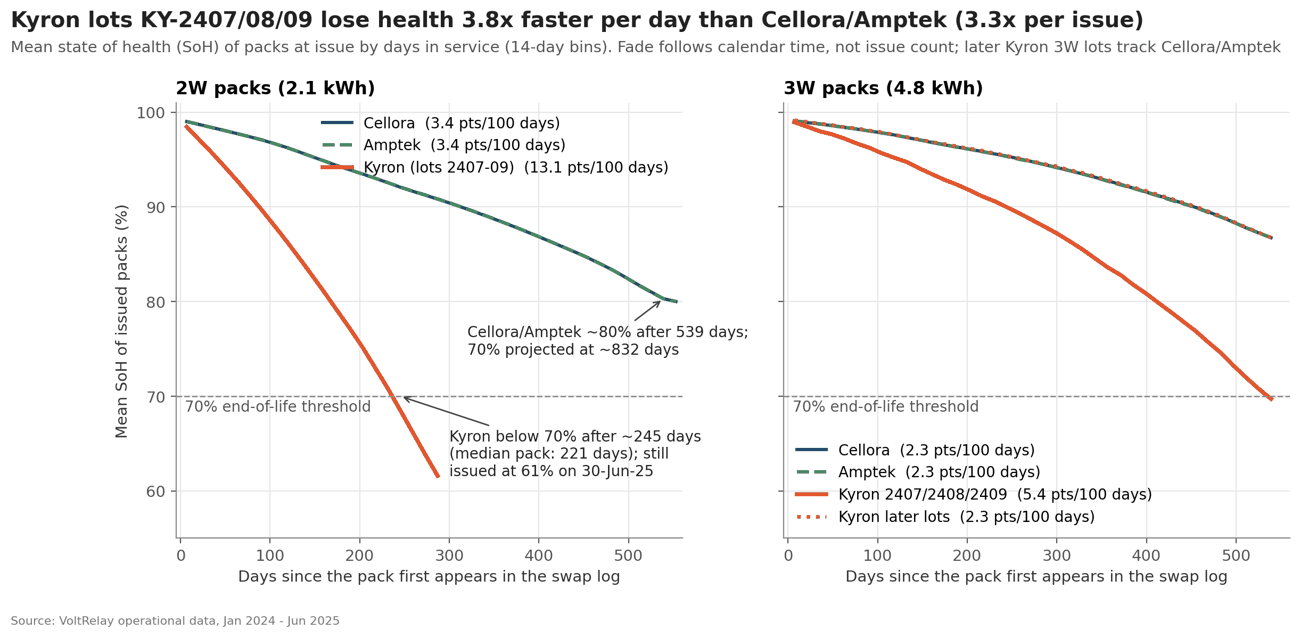

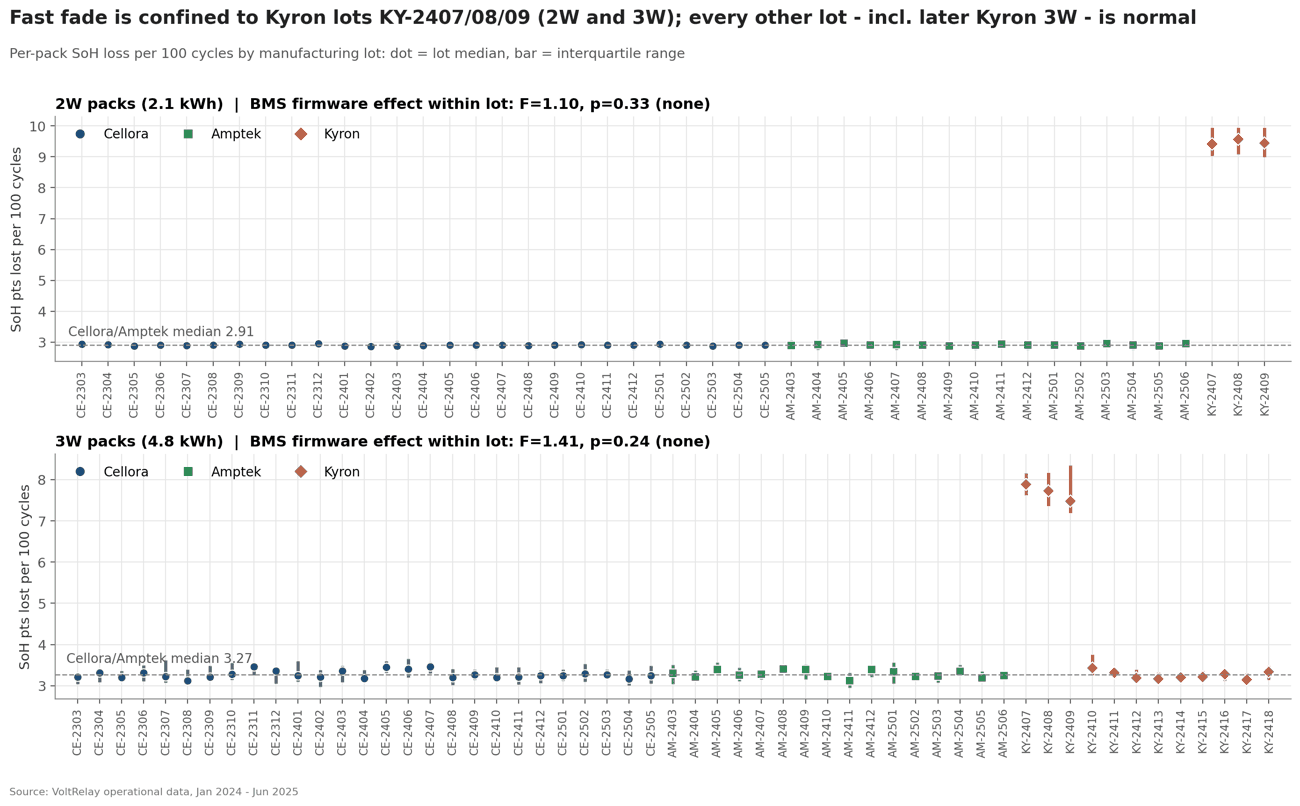

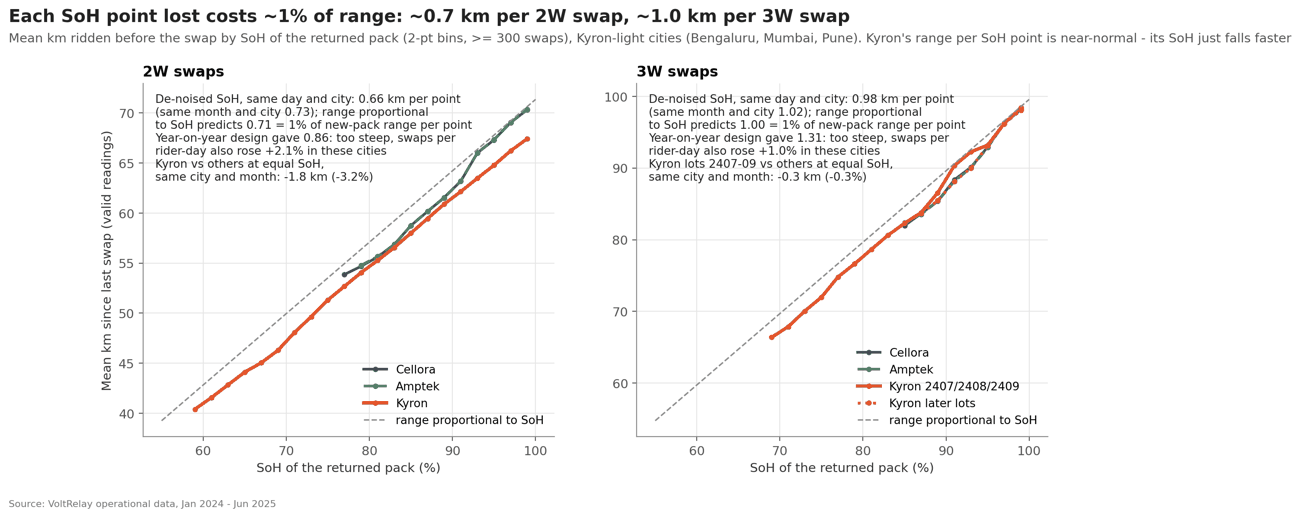

q4_04 right panel: Kyron-share spread within a cluster <= 1.2 pts, between clusters ~31 pts (10-30 Sep 2024)


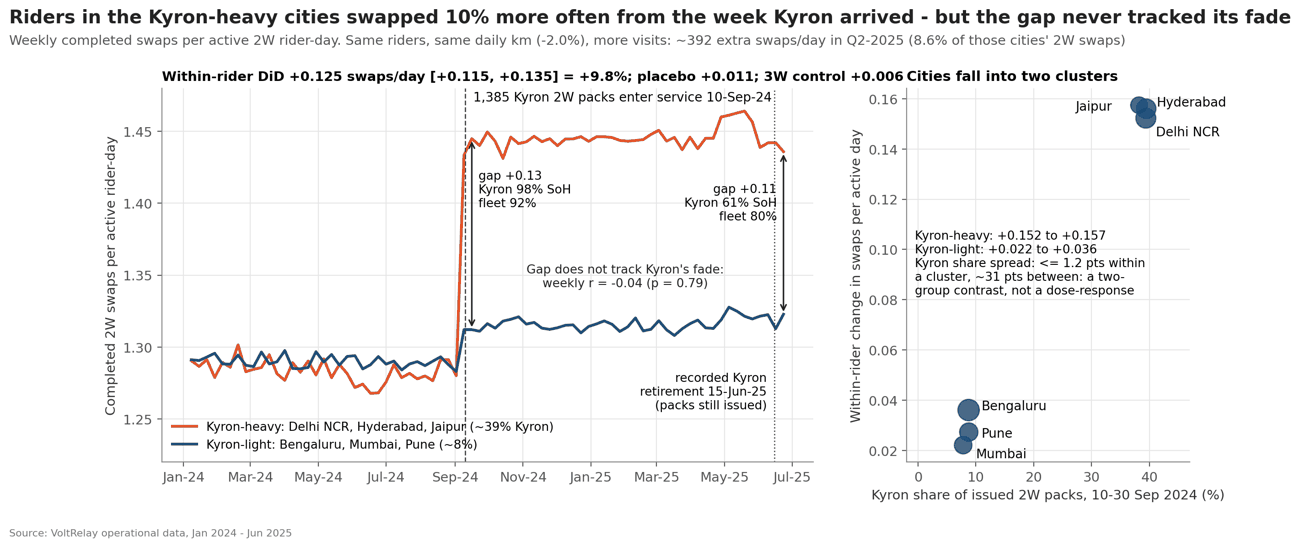

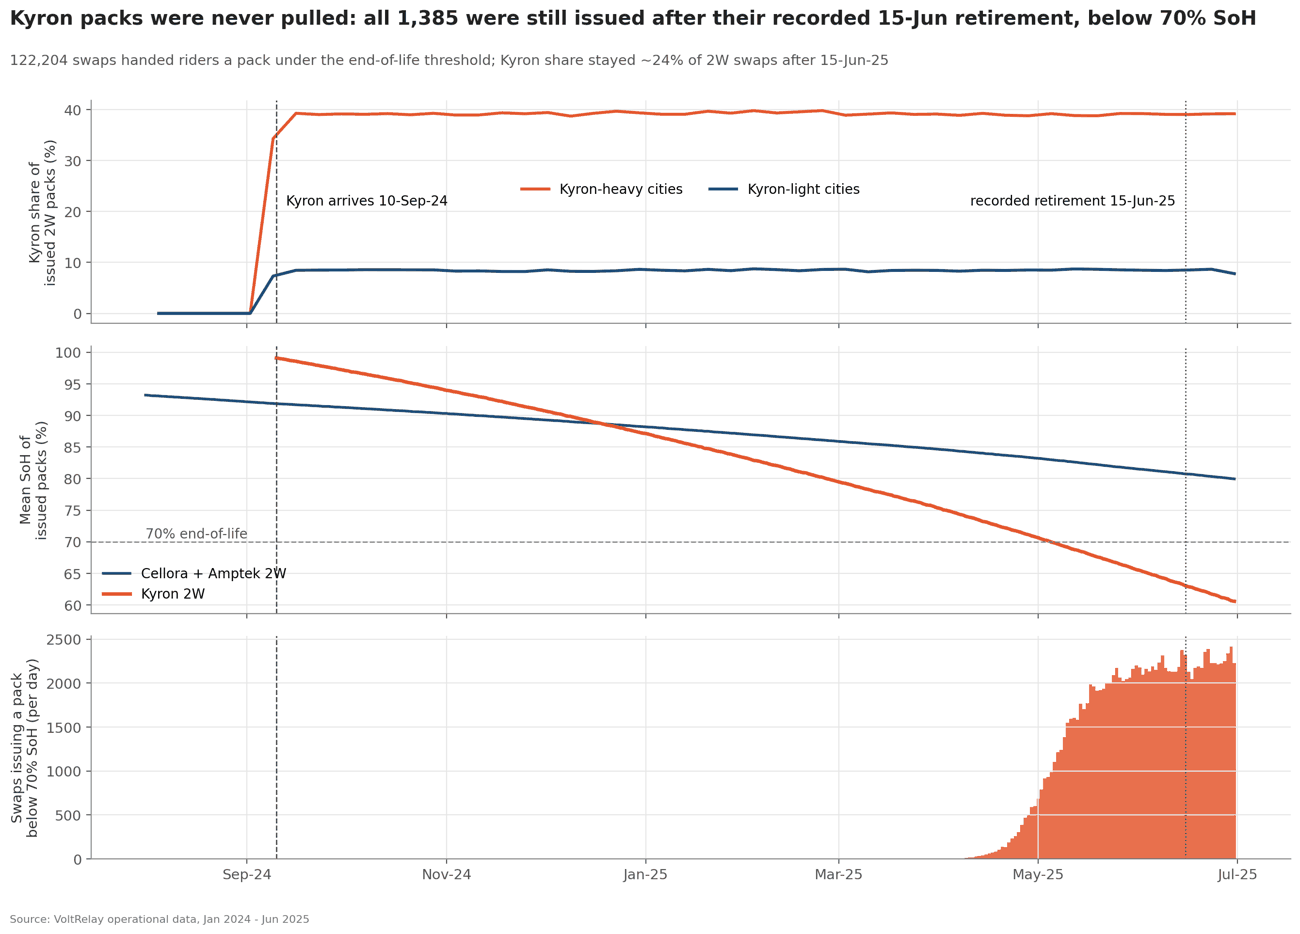

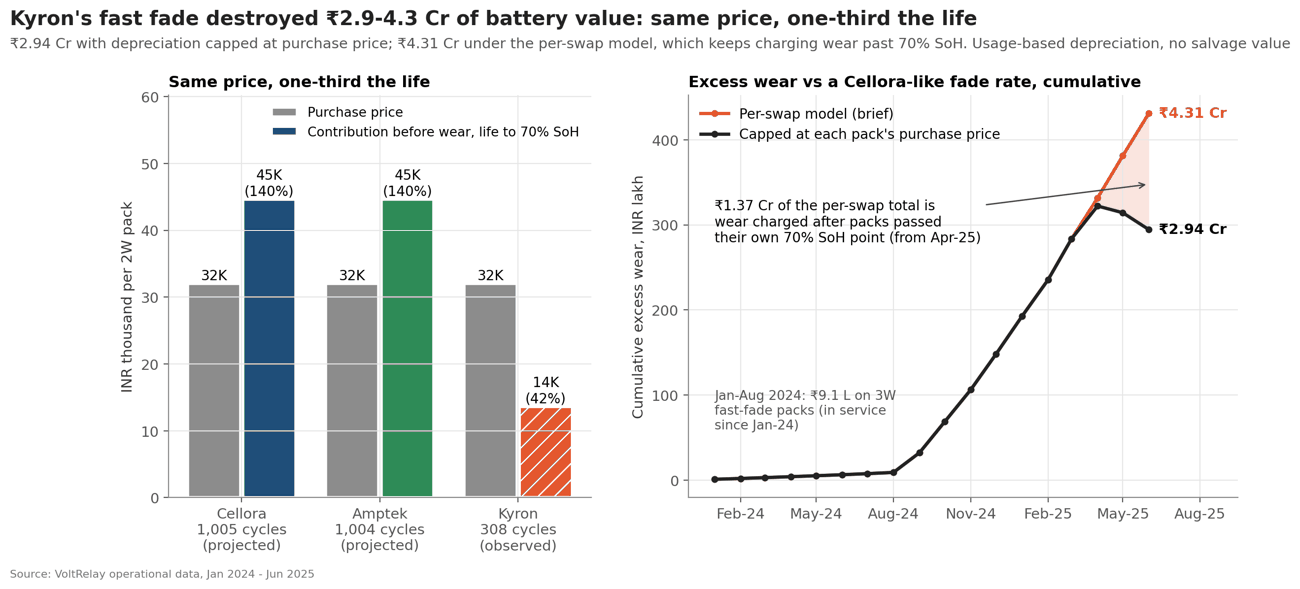

figures saved: ['q4_01_soh_vs_cycles.png', 'q4_02_degradation_by_lot.png', 'q4_03_range_vs_soh.png', 'q4_04_swap_frequency_did.png', 'q4_05_kyron_timeline.png', 'q4_06_kyron_economics.png']
runtime 15.5s


In [116]:
# Figure 1 (hero): SoH vs days in service by cohort (fade is calendar-driven)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), sharey=True)
for ax, pt in zip(axes, PTS):
    sub = soh_day.filter(pl.col("pack_type") == pt)
    for coh in COHORTS:
        s = sub.filter(pl.col("cohort") == coh)
        if s.height == 0:
            continue
        stl = COH_STYLE[coh]
        lab = "Kyron (lots 2407-09)" if (pt == "2W_2.1kWh" and coh == FAST) else coh
        ax.plot(s["day_bin"], s["soh_mean"], color=stl["color"], ls=stl["ls"], lw=stl["lw"], label=f"{lab}  ({traj_d[(pt, coh)]['slope'] * 100:.1f} pts/100 days)")
    ax.axhline(EOL_SOH, color=PALETTE["muted"], ls="--", lw=1)
    ax.text(5, EOL_SOH - 1.6, "70% end-of-life threshold", color="#555555", fontsize=10)
    ax.set_title(PT_LABEL[pt], fontsize=12)
    ax.set_xlabel("Days since the pack first appears in the swap log")
    ax.legend(loc="upper right" if pt == "2W_2.1kWh" else "lower left", fontsize=10)
    ax.set_ylim(55, 101)
    ax.set_xlim(-5, 560)
axes[0].set_ylabel("Mean SoH of issued packs (%)")
tk = traj_d[("2W_2.1kWh", FAST)]
last_ky_soh = kyr_daily.filter(pl.col("date") == kyr_daily["date"].max())["kyron_soh"].item()
print(f"Kyron 2W mean SoH at issue on {kyr_daily['date'].max()}: {last_ky_soh:.1f}%")
axes[0].annotate(f"Kyron below 70% after ~{tk['cross']:.0f} days\n(median pack: {d70[FAST]:.0f} days); still\nissued at {last_ky_soh:.0f}% on 30-Jun-25",
                 xy=(tk["cross"], 70), xytext=(300, 66.5), va="top", fontsize=10, arrowprops=dict(arrowstyle="->", color="#444444"), color="#222222")
tc = traj_d[("2W_2.1kWh", "Cellora")]
axes[0].annotate(f"Cellora/Amptek ~{tc['last_soh']:.0f}% after {tc['max_day']:.0f} days;\n70% projected at ~{d70['Cellora']:.0f} days",
                 xy=(tc["max_day"], tc["last_soh"]), xytext=(320, 77.5), va="top", fontsize=10, arrowprops=dict(arrowstyle="->", color="#444444"), color="#222222")
headline(fig, f"Kyron lots KY-2407/08/09 lose health {FADE_DAY[('2W_2.1kWh', FAST)]:.1f}x faster per day than Cellora/Amptek ({r2:.1f}x per issue)",
         "Mean state of health (SoH) of packs at issue by days in service (14-day bins). Fade follows calendar time, not issue count; "
         "later Kyron 3W lots track Cellora/Amptek", top=0.84)
save_fig(fig, "q4_01_soh_vs_cycles")

# Figure 2: per-pack degradation by lot
fig, axes = plt.subplots(2, 1, figsize=(14, 8.2))
order = {"Cellora": 0, "Amptek": 1, "Kyron": 2}
for ax, pt in zip(axes, PTS):
    d = coh_lot.filter(pl.col("pack_type") == pt).with_columns(pl.col("supplier").replace_strict(order).alias("o")).sort("o", "manufacturing_lot")
    x = np.arange(d.height)
    for i, r in enumerate(d.iter_rows(named=True)):
        c = SUPPLIER_COLORS[r["supplier"]]
        mk = "o" if r["supplier"] == "Cellora" else ("s" if r["supplier"] == "Amptek" else "D")
        ax.vlines(i, r["loss_p25"] * 100, r["loss_p75"] * 100, color=c, lw=2.5, alpha=0.8)
        ax.plot(i, r["loss_per_cycle_med"] * 100, marker=mk, color=c, ms=6.5, mec="white", mew=0.8, ls="none")
    rl = ref.filter(pl.col("pack_type") == pt)["ref_loss"].item() * 100
    ax.axhline(rl, color=PALETTE["muted"], ls="--", lw=1)
    ax.text(-0.5, rl + 0.3, f"Cellora/Amptek median {rl:.2f}", ha="left", fontsize=10, color="#555555")
    ax.set_xticks(x)
    ax.set_xticklabels(d["manufacturing_lot"].to_list(), rotation=90, fontsize=8.5)
    ax.set_xlim(-1, d.height)
    ax.set_ylabel("SoH pts lost per 100 cycles")
    F, p = bms_res[pt]
    ax.set_title(f"{PT_LABEL[pt]}  |  BMS firmware effect within lot: F={F:.2f}, p={p:.2f} (none)", fontsize=11.5)
    for sup, mk in [("Cellora", "o"), ("Amptek", "s"), ("Kyron", "D")]:
        ax.plot([], [], marker=mk, color=SUPPLIER_COLORS[sup], ls="none", label=sup)
    ax.legend(loc="upper left", ncol=3, fontsize=10)
headline(fig, "Fast fade is confined to Kyron lots KY-2407/08/09 (2W and 3W); every other lot - incl. later Kyron 3W - is normal",
         "Per-pack SoH loss per 100 cycles by manufacturing lot: dot = lot median, bar = interquartile range", top=0.88)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save_fig(fig, "q4_02_degradation_by_lot")

# Figure 3 (hero): delivered range vs SoH
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))
for ax, vc in zip(axes, ["2W", "3W"]):
    sub = rng_bin.filter((pl.col("vehicle_class") == vc) & pl.col("kyron_light_city") & pl.col("soh_bin").is_between(55, 99))
    for coh in COHORTS:
        s = sub.filter(pl.col("cohort_in") == coh)
        if s.height == 0:
            continue
        stl = COH_STYLE[coh]
        lab = "Kyron" if (vc == "2W" and coh == FAST) else coh
        ax.plot(s["soh_bin"], s["km_mean"], color=stl["color"], ls=stl["ls"], lw=stl["lw"], marker="o", ms=3.5, label=lab)
    xs_ = np.array([55.0, 100.0])
    ax.plot(xs_, PROP[vc] * xs_, color=PALETTE["muted"], ls="--", lw=1.2, label="range proportional to SoH")
    pen, d_ = MATCH[(vc, FAST)], DN[(vc, "all cities")]
    txt = (f"De-noised SoH, same day and city: {d_['day']:.2f} km per point\n(same month and city {d_['month']:.2f}); range proportional\n"
           f"to SoH predicts {PROP[vc]:.2f} = 1% of new-pack range per point\n"
           f"Year-on-year design gave {YOY[vc]['mean']:.2f}: too steep, swaps per\nrider-day also rose {100 * (yy.filter(pl.col('vehicle_class') == vc)['spd25'].mean() / yy.filter(pl.col('vehicle_class') == vc)['spd24'].mean() - 1):+.1f}% in these cities\n"
           f"Kyron{' lots 2407-09' if vc == '3W' else ''} vs others at equal SoH,\nsame city and month: {pen[0]:+.1f} km ({pct(pen[1])})")
    ax.text(0.03, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9.5, color="#222222")
    ax.set_title(f"{vc} swaps", fontsize=12)
    ax.set_xlabel("SoH of the returned pack (%)")
    ax.legend(loc="lower right", fontsize=9.5)
axes[0].set_ylabel("Mean km since last swap (valid readings)")
headline(fig, f"Each SoH point lost costs ~1% of range: ~{DN[('2W', 'all cities')]['month']:.1f} km per 2W swap, ~{DN[('3W', 'all cities')]['month']:.1f} km per 3W swap",
         f"Mean km ridden before the swap by SoH of the returned pack (2-pt bins, >= 300 swaps), Kyron-light cities ({', '.join(LIGHT)}). "
         f"Kyron's range per SoH point is near-normal - its SoH just falls faster", top=0.84)
save_fig(fig, "q4_03_range_vs_soh")

# Figure 4 (hero): swap frequency event study + dose-response
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6), gridspec_kw=dict(width_ratios=[2.3, 1]))
ax = axes[0]
for hv, c, lab in [(True, PALETTE["accent"], f"Kyron-heavy: {', '.join(HEAVY)} (~{100 * KY_SHARE[True]:.0f}% Kyron)"),
                   (False, PALETTE["primary"], f"Kyron-light: {', '.join(LIGHT)} (~{100 * KY_SHARE[False]:.0f}%)")]:
    s = wk.filter((pl.col("heavy") == hv) & (pl.col("week") >= dt.date(2024, 1, 8)) & (pl.col("week") <= dt.date(2025, 6, 23)))
    ax.plot(s["week"], s["swaps_per_active_day"], color=c, lw=2.2, label=lab)
ax.axvline(KYRON_ARRIVAL, color="#444444", lw=1, ls="--")
ax.text(KYRON_ARRIVAL, 1.478, "  1,385 Kyron 2W packs enter service 10-Sep-24", fontsize=10, va="top")
ax.axvline(RECORDED_RETIREMENT, color="#444444", lw=1, ls=":")
ax.text(RECORDED_RETIREMENT, 1.255, "recorded Kyron  \nretirement 15-Jun-25  \n(packs still issued)  ", fontsize=9.5, ha="right", va="bottom")
# the gap at the start and at the end of Kyron's service: full-size when Kyron was new, unchanged as it faded
w_first = gapw.filter(pl.col("week") == g1["week"]).row(0, named=True)
w_last = gpost.row(gpost.height - 1, named=True)
for w_, ha_, dx_ in [(w_first, "left", 6), (w_last, "right", -6)]:
    ax.annotate("", xy=(w_["week"], w_["heavy"]), xytext=(w_["week"], w_["light"]), arrowprops=dict(arrowstyle="<->", color="#222222", lw=1.2))
    ax.text(w_["week"] + dt.timedelta(days=dx_), w_["heavy"] - 0.022,
            f"gap {w_['gap']:+.2f}\nKyron {w_['ky_soh']:.0f}% SoH\nfleet {w_['other_soh']:.0f}%", fontsize=9.5, ha=ha_, va="top")
ax.text(dt.date(2025, 2, 1), 1.349, f"Gap does not track Kyron's fade:\nweekly r = {GAP['r']:+.2f} (p = {GAP['p']:.2f})",
        fontsize=9.5, ha="center", va="center", color="#222222")
ax.set_ylim(1.22, 1.48)
ax.set_ylabel("Completed 2W swaps per active rider-day")
ax.legend(loc="lower left", fontsize=9.5, bbox_to_anchor=(0.0, 0.0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_title(f"Within-rider DiD {did:+.3f} swaps/day [{did_lo:+.3f}, {did_hi:+.3f}] = {100 * did / base_heavy:+.1f}%; placebo {pl_did:+.3f}; "
             f"3W control {nc_did:+.3f}", fontsize=10.5)
ax = axes[1]
ax.scatter(dose["kyron_share_post"] * 100, dose["delta"], s=dose["riders"] / dose["riders"].max() * 250 + 30, color=PALETTE["primary"], alpha=0.85, zorder=3)
offs = {"Jaipur": (-50, -4), "Hyderabad": (8, 2), "Delhi NCR": (8, -14), "Bengaluru": (10, 0), "Pune": (10, -4), "Mumbai": (10, -10)}
for r in dose.iter_rows(named=True):
    ax.annotate(r["city"], (r["kyron_share_post"] * 100, r["delta"]), xytext=offs.get(r["city"], (6, -4)), textcoords="offset points", fontsize=10)
hv_, lt_ = dose.filter(pl.col("city").is_in(HEAVY)), dose.filter(~pl.col("city").is_in(HEAVY))
spread_ = 100 * max(hv_["kyron_share_post"].max() - hv_["kyron_share_post"].min(), lt_["kyron_share_post"].max() - lt_["kyron_share_post"].min())
between_ = 100 * (hv_["kyron_share_post"].mean() - lt_["kyron_share_post"].mean())
ax.text(0.03, 0.62, f"Kyron-heavy: {hv_['delta'].min():+.3f} to {hv_['delta'].max():+.3f}\nKyron-light: {lt_['delta'].min():+.3f} to {lt_['delta'].max():+.3f}\n"
        f"Kyron share spread: <= {spread_:.1f} pts within\na cluster, ~{between_:.0f} pts between: a two-\ngroup contrast, not a dose-response", transform=ax.transAxes, fontsize=9.5, va="top")
print(f"q4_04 right panel: Kyron-share spread within a cluster <= {spread_:.1f} pts, between clusters ~{between_:.0f} pts (10-30 Sep 2024)")
ax.set_xlim(-2, 47)
ax.set_xlabel("Kyron share of issued 2W packs, 10-30 Sep 2024 (%)")
ax.set_ylabel("Within-rider change in swaps per active day")
ax.set_title("Cities fall into two clusters", fontsize=11)
headline(fig, f"Riders in the Kyron-heavy cities swapped {100 * did / base_heavy:.0f}% more often from the week Kyron arrived - but the gap never tracked its fade",
         f"Weekly completed swaps per active 2W rider-day. Same riders, same daily km ({pct(gh['dkmd'] / gh['kmd_pre'])}), more visits: "
         f"~{EXTRA_DID / 91:,.0f} extra swaps/day in Q2-2025 ({pct(EXTRA_DID / q2_heavy_swaps)} of those cities' 2W swaps)",
         top=0.84)
save_fig(fig, "q4_04_swap_frequency_did")

# Figure 5: Kyron timeline (small multiples, shared time axis)
fig, axes = plt.subplots(3, 1, figsize=(13.5, 9.2), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.2, 1]))
x0, x1 = dt.date(2024, 8, 1), dt.date(2025, 6, 30)
ax = axes[0]
for hv, c, lab in [(True, PALETTE["accent"], "Kyron-heavy cities"), (False, PALETTE["primary"], "Kyron-light cities")]:
    s = wk_k.filter((pl.col("heavy") == hv) & pl.col("week").is_between(x0, x1))
    ax.plot(s["week"], s["ky_share"] * 100, color=c, lw=2.2, label=lab)
ax.set_ylabel("Kyron share of\nissued 2W packs (%)")
ax.legend(loc="center", bbox_to_anchor=(0.5, 0.6), fontsize=10, ncol=2)
ax.text(KYRON_ARRIVAL + dt.timedelta(days=3), 22, "Kyron arrives 10-Sep-24", fontsize=10, va="center")
ax.text(RECORDED_RETIREMENT - dt.timedelta(days=3), 22, "recorded retirement 15-Jun-25", fontsize=10, va="center", ha="right")
ax = axes[1]
s = kyr_daily.filter(pl.col("date").is_between(x0, x1))
ax.plot(s["date"], s["other_soh"], color=SUPPLIER_COLORS["Cellora"], lw=2, label="Cellora + Amptek 2W")
ax.plot(s["date"], s["kyron_soh"], color=SUPPLIER_COLORS["Kyron"], lw=2.6, label="Kyron 2W")
ax.axhline(EOL_SOH, color=PALETTE["muted"], ls="--", lw=1)
ax.text(x0, EOL_SOH + 0.6, "70% end-of-life", fontsize=10, color="#555555")
ax.set_ylabel("Mean SoH of\nissued packs (%)")
ax.legend(loc="lower left", fontsize=10)
ax = axes[2]
s = daily_eol.filter(pl.col("date").is_between(x0, x1))
ax.bar(s["date"], s["len"], width=1.0, color=SUPPLIER_COLORS["Kyron"], alpha=0.85)
ax.set_ylabel("Swaps issuing a pack\nbelow 70% SoH (per day)")
for a in axes:
    a.axvline(KYRON_ARRIVAL, color="#444444", lw=1, ls="--")
    a.axvline(RECORDED_RETIREMENT, color="#444444", lw=1, ls=":")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
headline(fig, f"Kyron packs were never pulled: all {post_ret.filter(pl.col('vehicle_class') == '2W')['distinct_packs'].item():,} were still issued after their recorded 15-Jun retirement, below 70% SoH",
         f"{km['sub_eol_swaps'].sum():,} swaps handed riders a pack under the end-of-life threshold; Kyron share stayed ~{100 * kd_s.filter(pl.col('after'))['share'].item():.0f}% of 2W swaps after 15-Jun-25",
         top=0.9)
fig.tight_layout(rect=[0, 0, 1, 0.91])
save_fig(fig, "q4_05_kyron_timeline")

# Figure 6 (hero): economics
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
ax = axes[0]
cohs = ["Cellora", "Amptek", FAST]
labs = ["Cellora", "Amptek", "Kyron"]
xx = np.arange(len(cohs))
cost = [pv[c]["purchase_cost_mean"] / 1000 for c in cohs]
life = [pv[c]["lifetime_margin_to_eol"] / 1000 for c in cohs]
ax.bar(xx - 0.2, cost, width=0.38, color=PALETTE["muted"], label="Purchase price", edgecolor="white", linewidth=2)
bars = ax.bar(xx + 0.2, life, width=0.38, color=[SUPPLIER_COLORS[l] for l in labs], label="Contribution before wear, life to 70% SoH", edgecolor="white", linewidth=2)
bars[2].set_hatch("//")
for i, c in enumerate(cohs):
    ax.text(xx[i] + 0.2, life[i] + 0.6, f"{life[i]:.0f}K\n({pct(pv[c]['cost_recovered_by_eol'], 0)})", ha="center", fontsize=10)
    ax.text(xx[i] - 0.2, cost[i] + 0.6, f"{cost[i]:.0f}K", ha="center", fontsize=10)
ax.set_xticks(xx)
ax.set_xticklabels([f"{l}\n{pv[c]['cycles_to_eol_med']:,.0f} cycles" + ("\n(projected)" if c != FAST else "\n(observed)") for l, c in zip(labs, cohs)])
ax.set_ylabel("INR thousand per 2W pack")
ax.set_ylim(0, max(life) * 1.35)
ax.legend(loc="upper right", fontsize=9.5)
ax.set_title("Same price, one-third the life", fontsize=11.5)
ax = axes[1]
ax.plot(mon["month"], mon["excess_cum"] / 1e5, color=SUPPLIER_COLORS["Kyron"], lw=2.4, marker="o", ms=4, label="Per-swap model (brief)")
ax.plot(mon["month"], mon["excess_capped_cum"] / 1e5, color="#222222", lw=2.4, marker="o", ms=4, label="Capped at each pack's purchase price")
ax.fill_between(mon["month"], mon["excess_capped_cum"] / 1e5, mon["excess_cum"] / 1e5, color=SUPPLIER_COLORS["Kyron"], alpha=0.15, lw=0)
ax.text(mon["month"][-1], mon["excess_cum"][-1] / 1e5, f"  {fmt_inr(mon['excess_cum'][-1])}", va="center", fontsize=10.5, fontweight="bold", color=SUPPLIER_COLORS["Kyron"])
ax.text(mon["month"][-1], mon["excess_capped_cum"][-1] / 1e5, f"  {fmt_inr(mon['excess_capped_cum'][-1])}", va="center", fontsize=10.5, fontweight="bold")
ax.annotate(f"{fmt_inr(EXC_TOT - EXC_CAP_TOT)} of the per-swap total is\nwear charged after packs passed\ntheir own 70% SoH point (from Apr-25)",
            xy=(dt.date(2025, 6, 1), (mon["excess_cum"][-2] + mon["excess_capped_cum"][-2]) / 2e5),
            xytext=(dt.date(2024, 1, 1), 330), va="top", fontsize=10, arrowprops=dict(arrowstyle="->", color="#444444"))
ax.text(dt.date(2024, 1, 1), 60, f"Jan-Aug 2024: {fmt_inr(pre_sep)} on 3W\nfast-fade packs (in service\nsince Jan-24)", fontsize=9.5, color="#555555")
ax.set_ylabel("Cumulative excess wear, INR lakh")
ax.set_xlim(dt.date(2023, 12, 1), dt.date(2025, 9, 15))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.legend(loc="upper left", fontsize=10)
ax.set_title("Excess wear vs a Cellora-like fade rate, cumulative", fontsize=11.5)
headline(fig, f"Kyron's fast fade destroyed ₹{EXC_CAP_TOT / 1e7:.1f}-{EXC_TOT / 1e7:.1f} Cr of battery value: same price, one-third the life",
         f"{fmt_inr(EXC_CAP_TOT)} with depreciation capped at purchase price; {fmt_inr(EXC_TOT)} under the per-swap model, which keeps charging wear "
         f"past 70% SoH. Usage-based depreciation, no salvage value", top=0.84)
save_fig(fig, "q4_06_kyron_economics")
print("figures saved:", sorted(p.name for p in FIG.glob("q4_*.png")))
print(f"runtime {time.time() - T0:.1f}s")

In [117]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 152 objects


## 9. Q5 · Pricing & partner economics

# Q5 - Pricing and partner economics (+ fleet-partner value deep dive)
**Question.** How do the base price change (2024-07-01), the peak/off-peak pilot (Bengaluru + Pune from 2024-10-01) and
the individual fleet-partner contract terms relate to swap timing, revenue and contribution margin? Is the effect the
same for every rider segment? Is the largest partner the most valuable?

**Approach.**
1. Verify the pilot tariff schedule and partner surcharge billing *in the data* (not from documentation).
2. Base price change: difference-in-differences of price-paying independents vs partner-billed riders (whose employer
   pays), rider + month fixed effects, Jan-Aug 2024 (stops before the Kyron roll-out of Sep-2024 and the pilot).
3. Pilot: difference-in-differences / event study, treated = Bengaluru + Pune, control = the other four cities;
   rider-city-month panel for rider outcomes, station-month panel for congestion; city-permutation inference
   (only 6 cities); robustness for summer-2025 heat and for the Kyron battery roll-out, which hit three of the four
   control cities and contaminates any naive margin comparison.
4. Partner economics: revenue, discount, energy, battery wear, station fixed cost, cm1/cm2 and working-capital cost
   for each of the 12 partners and independents; mix-standardised comparison; ZipDrop amendment before/after.
5. Budget proposals (c) network-wide pricing rollout and (d) long-term exclusive with the largest partner.

All margin levels are *under our usage-based battery-depreciation assumption* (no salvage value, 70% SoH end of life).

In [118]:
import sys
import datetime as dt
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    ROOT = PROJECT_ROOT
except NameError:  # running inside a notebook
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401

set_style()
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(230); pl.Config.set_fmt_str_lengths(40)
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)

QID = "q5"
COC = 0.12                       # annual cost of capital on receivables (OUR assumption; not in the data or brief)
M = lambda y, m: dt.date(y, m, 1)  # noqa: E731
PRE_PILOT = [M(2024, 7), M(2024, 8), M(2024, 9)]                 # after the base price change, before the pilot
POST_MAIN = [M(2024, m) for m in (10, 11, 12)] + [M(2025, m) for m in (1, 2, 3)]   # Oct-24..Mar-25 (no summer heat)
POST_FULL = POST_MAIN + [M(2025, 4), M(2025, 5), M(2025, 6)]
CUR = (M(2024, 11), M(2025, 6))  # "current terms" window = after the ZipDrop amendment
CONTROL_CITIES = [c for c in CITIES if c not in PILOT_CITIES]
GRP_ORDER = ["Independent", "Partner Y (surcharge billable)", "Partner N (not billable)"]


def money(x):
    return fmt_inr(x)


def p(msg):
    print(msg, flush=True)

## 1. Load the clean swap events (projected columns only) and tag segments
Segment = independent (pays the tariff itself) vs partner-billed, the latter split by whether the contract makes the
pilot's peak surcharge billable (`peak_surcharge_billable` Y/N).

In [119]:
PARTNERS = partners()
COLS = ["rider_id", "station_id", "month", "hour", "event_type", "is_completed", "is_stockout", "is_abandoned",
        "is_service_failure", "queue_wait_sec", "vehicle_class", "city", "tariff_code", "list_price_inr", "discount_inr",
        "amount_charged_inr", "partner_id", "is_independent", "plan_type", "revenue", "energy_cost", "wear_cost",
        "fixed_cost", "cm1", "cm2", "supplier_out", "season"]
MONEY = ["list_price_inr", "discount_inr", "amount_charged_inr", "revenue", "energy_cost", "wear_cost", "fixed_cost", "cm1", "cm2"]
LF = (events(COLS)
      .with_columns([pl.col(c).cast(pl.Float64) for c in MONEY])
      .join(PARTNERS.lazy().select("partner_id", "partner_name", "partner_segment", "peak_surcharge_billable",
                                   "payment_terms_days"), on="partner_id", how="left")
      .with_columns(
          pl.when(pl.col("is_independent")).then(pl.lit(GRP_ORDER[0]))
            .when(pl.col("peak_surcharge_billable") == "Y").then(pl.lit(GRP_ORDER[1]))
            .otherwise(pl.lit(GRP_ORDER[2])).alias("grp"),
          pl.col("city").is_in(PILOT_CITIES).alias("treated"),
          (pl.col("supplier_out") == "Kyron").alias("kyron"),
          pl.col("partner_id").fill_null("IND").alias("pid")))

## 2. What did the pilot actually charge? (verify in the data)
The brief describes PEAK as roughly 12:00-22:59. We read the schedule from `tariff_code` of independent swaps in pilot
cities after 2024-10-01, and check what partner riders were billed at peak (tariff_code is always PARTNER for them, so
the surcharge can only be seen as `amount_charged - (list - discount)`).

In [120]:
sched = (LF.filter(pl.col("is_completed") & pl.col("treated") & pl.col("is_independent") & (pl.col("month") >= PILOT_START))
         .group_by("hour").agg(pl.len().alias("swaps"),
                               (pl.col("tariff_code") == "PEAK").mean().alias("share_PEAK"),
                               (pl.col("tariff_code") == "OFFPEAK").mean().alias("share_OFFPEAK"),
                               (pl.col("tariff_code") == "STD").mean().alias("share_STD"),
                               (pl.col("amount_charged_inr") - pl.col("list_price_inr")).mean().alias("charged_minus_list"))
         .sort("hour").collect())
PEAK_H = sched.filter(pl.col("share_PEAK") > 0.95)["hour"].to_list()
OFF_H = sched.filter(pl.col("share_OFFPEAK") > 0.95)["hour"].to_list()
STD_H = [h for h in range(24) if h not in PEAK_H + OFF_H]
# sub-bands of the two discontinuous tariff windows (derived from the data-verified schedule)
MID_H = [h for h in PEAK_H if h < 17]          # PEAK midday 12-13h
EVE_H = [h for h in PEAK_H if h >= 17]         # PEAK evening 19-22h
AFT_H = [h for h in OFF_H if 12 <= h <= 18]    # OFFPEAK afternoon 14-16h
NIGHT_H = [h for h in OFF_H if h not in AFT_H]  # OFFPEAK night 23-05h
sched.write_csv(TAB / f"{QID}_pilot_tariff_schedule.csv")
p(sched)
p(f"PEAK hours (+Rs15): {PEAK_H}\nOFFPEAK hours (-Rs8): {OFF_H}\nSTD hours: {STD_H}")
peak_rev_ind = sched.filter(pl.col("hour").is_in(PEAK_H))["charged_minus_list"].mean()
off_rev_ind = sched.filter(pl.col("hour").is_in(OFF_H))["charged_minus_list"].mean()
p(f"Independents: charged - list at PEAK = {peak_rev_ind:+.2f}, at OFFPEAK = {off_rev_ind:+.2f}")

band = (pl.when(pl.col("hour").is_in(PEAK_H)).then(pl.lit("peak"))
        .when(pl.col("hour").is_in(OFF_H)).then(pl.lit("offpeak")).otherwise(pl.lit("std")))
LF = LF.with_columns(band.alias("band"))

# Where is congestion actually concentrated? (network-wide, all months)
hg = (pl.when(pl.col("hour").is_in([12, 13])).then(pl.lit("1 PEAK midday 12-13"))
      .when(pl.col("hour").is_in([19, 20, 21, 22])).then(pl.lit("2 PEAK evening 19-22"))
      .when(pl.col("hour").is_in(OFF_H)).then(pl.lit("3 OFFPEAK")).otherwise(pl.lit("4 STD")))
band_kpi = (LF.with_columns(hg.alias("hour_group")).group_by("hour_group")
            .agg(pl.len().alias("attempts"), (100 * pl.col("is_service_failure").mean()).alias("failure_rate_pct"),
                 (100 * pl.col("is_stockout").mean()).alias("stockout_rate_pct"), (100 * pl.col("is_abandoned").mean()).alias("abandon_rate_pct"),
                 pl.col("queue_wait_sec").filter(pl.col("is_completed")).mean().alias("qwait_completed_mean_s"),
                 pl.col("queue_wait_sec").filter(pl.col("is_completed")).quantile(0.9).alias("qwait_completed_p90_s"))
            .with_columns((100 * pl.col("attempts") / pl.col("attempts").sum()).alias("share_of_attempts_pct"))
            .sort("hour_group").collect())
band_kpi.write_csv(TAB / f"{QID}_congestion_by_tariff_band.csv")
p("Congestion by tariff band (all cities, Jan-24..Jun-25):")
p(band_kpi.with_columns(pl.col(pl.Float64).round(2)))

shape: (24, 6)
┌──────┬───────┬────────────┬───────────────┬───────────┬────────────────────┐
│ hour ┆ swaps ┆ share_PEAK ┆ share_OFFPEAK ┆ share_STD ┆ charged_minus_list │
│ ---  ┆ ---   ┆ ---        ┆ ---           ┆ ---       ┆ ---                │
│ i8   ┆ u32   ┆ f64        ┆ f64           ┆ f64       ┆ f64                │
╞══════╪═══════╪════════════╪═══════════════╪═══════════╪════════════════════╡
│ 0    ┆ 1939  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -7.9948            │
│ 1    ┆ 1907  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -8.0000            │
│ 2    ┆ 2004  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -8.0125            │
│ 3    ┆ 1989  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -7.9899            │
│ 4    ┆ 3356  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -7.9940            │
│ 5    ┆ 3267  ┆ 0.0000     ┆ 1.0000        ┆ 0.0000    ┆ -8.0046            │
│ 6    ┆ 4917  ┆ 0.0000     ┆ 0.0000        ┆ 1.0000    ┆ 0.0102             │
│ 7    ┆ 4880  ┆ 0.0000     ┆ 0.0000 

PEAK hours (+Rs15): [12, 13, 19, 20, 21, 22]
OFFPEAK hours (-Rs8): [0, 1, 2, 3, 4, 5, 14, 15, 16, 23]
STD hours: [6, 7, 8, 9, 10, 11, 17, 18]


Independents: charged - list at PEAK = +15.00, at OFFPEAK = -8.00


Congestion by tariff band (all cities, Jan-24..Jun-25):


shape: (4, 8)
┌──────────────────────┬──────────┬──────────────────┬───────────────────┬──────────────────┬────────────────────────┬───────────────────────┬───────────────────────┐
│ hour_group           ┆ attempts ┆ failure_rate_pct ┆ stockout_rate_pct ┆ abandon_rate_pct ┆ qwait_completed_mean_s ┆ qwait_completed_p90_s ┆ share_of_attempts_pct │
│ ---                  ┆ ---      ┆ ---              ┆ ---               ┆ ---              ┆ ---                    ┆ ---                   ┆ ---                   │
│ str                  ┆ u32      ┆ f64              ┆ f64               ┆ f64              ┆ f64                    ┆ f64                   ┆ f64                   │
╞══════════════════════╪══════════╪══════════════════╪═══════════════════╪══════════════════╪════════════════════════╪═══════════════════════╪═══════════════════════╡
│ 1 PEAK midday 12-13  ┆ 734855   ┆ 4.9500           ┆ 3.0800            ┆ 1.5800           ┆ 243.3500               ┆ 423.0000              ┆ 19.2600 

**Is the evening excess network-wide? (Simpson check.)** The network gap between the evening (19-22h) and midday
(12-13h) PEAK windows could come from a few city-seasons. We split evening-minus-midday failure rates by city x season.

In [121]:
EVM = (LF.filter(pl.col("hour").is_in(MID_H + EVE_H))
       .with_columns(pl.when(pl.col("hour").is_in(EVE_H)).then(pl.lit("eve")).otherwise(pl.lit("mid")).alias("hb"))
       .group_by("city", "season", "hb").agg(pl.len().alias("att"), pl.col("is_service_failure").sum().alias("fail"))
       .collect())


def eve_minus_mid(keys):
    t = (EVM.group_by(keys + ["hb"]).agg(pl.col("att").sum(), pl.col("fail").sum())
         .with_columns((100 * pl.col("fail") / pl.col("att")).alias("fail_pct"))
         .pivot(on="hb", index=keys, values=["fail_pct", "att"])
         .select(keys + ["fail_pct_mid", "fail_pct_eve", "att_mid", "att_eve"]))   # fixed column order
    return (t.with_columns((pl.col("fail_pct_eve") - pl.col("fail_pct_mid")).alias("eve_minus_mid_pp"))
            .sort(keys))


EVM_CS = eve_minus_mid(["city", "season"])
EVM_C = eve_minus_mid(["city"])
EVM_CS.write_csv(TAB / f"{QID}_evening_vs_midday_failure_city_season.csv")
p("Failure rate, evening 19-22h vs midday 12-13h, by city x season (pp):")
p(EVM_CS.with_columns(pl.col(pl.Float64).round(2)))
p("... by city, all months (pp): " + ", ".join(f"{c} {v:+.2f}" for c, v in EVM_C.select("city", "eve_minus_mid_pp").iter_rows()))
HOT = ["Delhi NCR", "Hyderabad", "Jaipur"]
hot_ss = EVM_CS.filter(pl.col("city").is_in(HOT) & pl.col("season").is_in(["Summer", "Monsoon"]))["eve_minus_mid_pp"]
cool_ss = EVM_CS.filter(~pl.col("city").is_in(HOT))["eve_minus_mid_pp"]
wint = EVM_CS.filter(pl.col("season").is_in(["Winter", "Post-monsoon"]))["eve_minus_mid_pp"]
p(f"Evening-minus-midday failure: Delhi NCR/Hyderabad/Jaipur in Summer+Monsoon {hot_ss.min():+.2f} to {hot_ss.max():+.2f} pp; "
  f"Bengaluru/Mumbai/Pune all seasons {cool_ss.min():+.2f} to {cool_ss.max():+.2f} pp; Winter+Post-monsoon, every city "
  f"{wint.min():+.2f} to {wint.max():+.2f} pp; smallest cell {min(EVM_CS['att_mid'].min(), EVM_CS['att_eve'].min()):,} attempts")

Failure rate, evening 19-22h vs midday 12-13h, by city x season (pp):


shape: (24, 7)
┌───────────┬──────────────┬──────────────┬──────────────┬─────────┬─────────┬──────────────────┐
│ city      ┆ season       ┆ fail_pct_mid ┆ fail_pct_eve ┆ att_mid ┆ att_eve ┆ eve_minus_mid_pp │
│ ---       ┆ ---          ┆ ---          ┆ ---          ┆ ---     ┆ ---     ┆ ---              │
│ str       ┆ str          ┆ f64          ┆ f64          ┆ u32     ┆ u32     ┆ f64              │
╞═══════════╪══════════════╪══════════════╪══════════════╪═════════╪═════════╪══════════════════╡
│ Bengaluru ┆ Monsoon      ┆ 3.7800       ┆ 3.8600       ┆ 39995   ┆ 79653   ┆ 0.0800           │
│ Bengaluru ┆ Post-monsoon ┆ 3.8900       ┆ 3.6500       ┆ 17011   ┆ 34121   ┆ -0.2400          │
│ Bengaluru ┆ Summer       ┆ 4.0700       ┆ 4.4100       ┆ 50268   ┆ 100679  ┆ 0.3400           │
│ Bengaluru ┆ Winter       ┆ 3.8200       ┆ 3.7800       ┆ 38307   ┆ 76833   ┆ -0.0300          │
│ Delhi NCR ┆ Monsoon      ┆ 6.8900       ┆ 10.7400      ┆ 38538   ┆ 75105   ┆ 3.8400           │
│ Del

... by city, all months (pp): Bengaluru +0.10, Delhi NCR +2.34, Hyderabad +1.88, Jaipur +2.74, Mumbai -0.18, Pune +0.33


Evening-minus-midday failure: Delhi NCR/Hyderabad/Jaipur in Summer+Monsoon +2.59 to +4.75 pp; Bengaluru/Mumbai/Pune all seasons -0.38 to +1.10 pp; Winter+Post-monsoon, every city -0.38 to +0.18 pp; smallest cell 11,455 attempts


### Figure: where is the evening excess? (city x season)

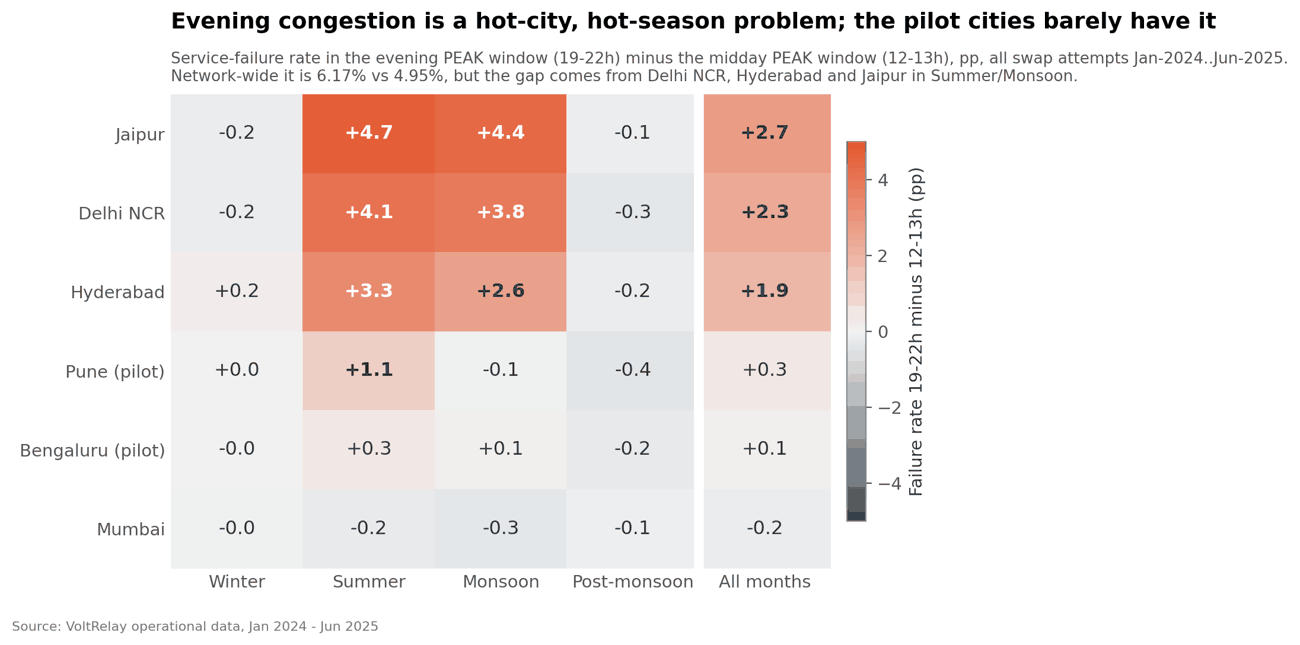

shape: (24, 7)
┌─────────────────────────┬─────────┬───────┬─────────┬────────┬────────────────────┬────────────────────┐
│ peak_surcharge_billable ┆ treated ┆ post  ┆ band    ┆ swaps  ┆ mean_surcharge_inr ┆ share_no_surcharge │
│ ---                     ┆ ---     ┆ ---   ┆ ---     ┆ ---    ┆ ---                ┆ ---                │
│ str                     ┆ bool    ┆ bool  ┆ str     ┆ u32    ┆ f64                ┆ f64                │
╞═════════════════════════╪═════════╪═══════╪═════════╪════════╪════════════════════╪════════════════════╡
│ N                       ┆ false   ┆ false ┆ offpeak ┆ 17104  ┆ -0.0000            ┆ 0.9976             │
│ N                       ┆ false   ┆ false ┆ peak    ┆ 117982 ┆ 0.0000             ┆ 0.9979             │
│ N                       ┆ false   ┆ false ┆ std     ┆ 24839  ┆ 0.0000             ┆ 0.9984             │
│ N                       ┆ false   ┆ true  ┆ offpeak ┆ 37199  ┆ 0.0000             ┆ 0.9981             │
│ N                   

Pilot cities, post: billable-Y partners pay +15.00 at peak and -8.00 off-peak; billable-N partners pay -0.00 at peak and -0.00 off-peak


In [122]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm  # noqa: E402

SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
city_order = EVM_C.sort("eve_minus_mid_pp", descending=True)["city"].to_list()
mat = np.array([[EVM_CS.filter((pl.col("city") == c) & (pl.col("season") == s))["eve_minus_mid_pp"][0] for s in SEASONS]
                + [EVM_C.filter(pl.col("city") == c)["eve_minus_mid_pp"][0]] for c in city_order])
div_cmap = LinearSegmentedColormap.from_list("q5_div", [PALETTE["primary"], "#F2F2F2", PALETTE["accent"]])
lim = np.ceil(np.abs(mat).max())
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(mat, cmap=div_cmap, norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=11.5, fontweight="bold" if abs(v) >= 1 else "normal",
                color="white" if abs(v) > 0.55 * lim else "#333333")
ax.axvline(len(SEASONS) - 0.5, color="white", lw=6)
ax.set_xticks(range(len(SEASONS) + 1)); ax.set_xticklabels(SEASONS + ["All months"])
ax.set_yticks(range(len(city_order)))
ax.set_yticklabels([f"{c} (pilot)" if c in PILOT_CITIES else c for c in city_order])
ax.tick_params(length=0); ax.grid(False)
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("Failure rate 19-22h minus 12-13h (pp)")
nk = band_kpi.filter(pl.col("hour_group").str.contains("evening"))["failure_rate_pct"][0]
nm_ = band_kpi.filter(pl.col("hour_group").str.contains("midday"))["failure_rate_pct"][0]
ax.set_title("Evening congestion is a hot-city, hot-season problem; the pilot cities barely have it", fontsize=13.5, pad=40)
ax.text(0.0, 1.02, f"Service-failure rate in the evening PEAK window (19-22h) minus the midday PEAK window (12-13h), pp, all swap attempts Jan-2024..Jun-2025.\n"
        f"Network-wide it is {nk:.2f}% vs {nm_:.2f}%, but the gap comes from Delhi NCR, Hyderabad and Jaipur in Summer/Monsoon.",
        transform=ax.transAxes, fontsize=9.5, color="#555555", va="bottom")
fig.tight_layout()
save_fig(fig, f"{QID}_08_evening_congestion_city_season")

surch = (LF.filter(pl.col("is_completed") & ~pl.col("is_independent"))
         .with_columns((pl.col("month") >= PILOT_START).alias("post"),
                       (pl.col("amount_charged_inr") - pl.col("list_price_inr") + pl.col("discount_inr")).alias("surcharge"))
         .group_by("peak_surcharge_billable", "treated", "post", "band")
         .agg(pl.len().alias("swaps"), pl.col("surcharge").mean().round(2).alias("mean_surcharge_inr"),
              (pl.col("surcharge").abs() < 0.5).mean().round(4).alias("share_no_surcharge"))
         .sort("peak_surcharge_billable", "treated", "post", "band").collect())
surch.write_csv(TAB / f"{QID}_partner_surcharge_check.csv")
p(surch)
sY = surch.filter(pl.col("treated") & pl.col("post") & (pl.col("peak_surcharge_billable") == "Y"))
sN = surch.filter(pl.col("treated") & pl.col("post") & (pl.col("peak_surcharge_billable") == "N"))
p(f"Pilot cities, post: billable-Y partners pay {sY.filter(pl.col('band')=='peak')['mean_surcharge_inr'][0]:+.2f} at peak and "
  f"{sY.filter(pl.col('band')=='offpeak')['mean_surcharge_inr'][0]:+.2f} off-peak; billable-N partners pay "
  f"{sN.filter(pl.col('band')=='peak')['mean_surcharge_inr'][0]:+.2f} at peak and {sN.filter(pl.col('band')=='offpeak')['mean_surcharge_inr'][0]:+.2f} off-peak")

## 3. Analysis panels
* **rider-city-month** (completed swaps): swaps, peak / off-peak counts, revenue, cm1, Kyron packs received.
* **station-month** (all attempts in pilot PEAK hours): stockouts, abandonment, failures, queue wait.
* **partner cells** (partner x month x city x vehicle class x tariff band): revenue and cost components.

In [123]:
RM = (LF.filter(pl.col("is_completed"))
      .group_by("rider_id", "city", "month")
      .agg(pl.len().alias("swaps"), (pl.col("band") == "peak").sum().alias("n_peak"),
           (pl.col("band") == "offpeak").sum().alias("n_off"),
           pl.col("hour").is_in(MID_H).sum().alias("n_mid"), pl.col("hour").is_in(EVE_H).sum().alias("n_eve"),
           pl.col("hour").is_in(AFT_H).sum().alias("n_aft"), pl.col("hour").is_in(NIGHT_H).sum().alias("n_night"),
           pl.col("revenue").sum().alias("rev"),
           pl.col("cm1").sum().alias("cm1"), pl.col("list_price_inr").sum().alias("list_rev"),
           pl.col("kyron").sum().alias("n_ky"), pl.col("grp").first(), pl.col("pid").first(),
           pl.col("plan_type").first(), pl.col("vehicle_class").mode().first().alias("vc"),
           pl.col("treated").first())
      .collect(engine="streaming").to_pandas())
RM["unit"] = RM["rider_id"] + "|" + RM["city"]
RM["peak_share"] = RM["n_peak"] / RM["swaps"]
RM["off_share"] = RM["n_off"] / RM["swaps"]
for _k in ("mid", "eve", "aft", "night"):
    RM[f"{_k}_share"] = RM[f"n_{_k}"] / RM["swaps"]
RM["rev_ps"] = RM["rev"] / RM["swaps"]
RM["cm1_ps"] = RM["cm1"] / RM["swaps"]
RM["ky_share"] = RM["n_ky"] / RM["swaps"]
RM["lsw"] = np.log(RM["swaps"])  # log swaps per active rider-month (proportional effects)
RM["month"] = pd.to_datetime(RM["month"]).dt.date
p(f"rider-city-month panel: {len(RM):,} rows, {RM['unit'].nunique():,} rider-city units")

def station_month_panel(hours):
    d = (LF.filter(pl.col("hour").is_in(hours))
         .group_by("station_id", "city", "month")
         .agg(pl.len().alias("att"), pl.col("is_stockout").sum().alias("so"), pl.col("is_abandoned").sum().alias("ab"),
              pl.col("is_service_failure").sum().alias("fail"), pl.col("is_completed").sum().alias("done"),
              pl.col("queue_wait_sec").filter(pl.col("is_completed")).mean().alias("qwait"),
              pl.col("kyron").filter(pl.col("is_completed")).mean().alias("ky_share"))
         .collect().to_pandas())
    d["month"] = pd.to_datetime(d["month"]).dt.date
    d["so_rate"] = d["so"] / d["att"]; d["ab_rate"] = d["ab"] / d["att"]; d["fail_rate"] = d["fail"] / d["att"]
    d["treated"] = d["city"].isin(PILOT_CITIES)
    return d


SMP = station_month_panel(PEAK_H)        # all PEAK-hour attempts (12-13h + 19-22h)
SMP_EVE = station_month_panel(EVE_H)     # evening PEAK window only (19-22h)
_nm = SMP.groupby("station_id")["month"].nunique()
BAL_ST = _nm[_nm == SMP["month"].nunique()].index   # stations with PEAK attempts in every one of the 18 months
p(f"station-month PEAK panel: {len(SMP):,} rows, {SMP['station_id'].nunique()} stations; balanced (all "
  f"{SMP['month'].nunique()} months): {len(BAL_ST)} stations")

CELLS = (LF.filter(pl.col("is_completed"))
         .group_by("pid", "month", "city", "vehicle_class", "band")
         .agg(pl.len().alias("swaps"), pl.col("revenue").sum().alias("revenue"), pl.col("list_price_inr").sum().alias("list_rev"),
              pl.col("discount_inr").sum().alias("disc"), pl.col("energy_cost").sum().alias("energy"),
              pl.col("wear_cost").sum().alias("wear"), pl.col("fixed_cost").sum().alias("fixed"),
              pl.col("cm1").sum().alias("cm1"), pl.col("cm2").sum().alias("cm2"),
              pl.col("kyron").sum().alias("ky_swaps"), pl.col("wear_cost").filter(~pl.col("kyron")).sum().alias("wear_nonky"),
              pl.col("energy_cost").filter(~pl.col("kyron")).sum().alias("energy_nonky"))
         .collect(engine="streaming"))
p(f"partner cells: {CELLS.height:,} rows; completed swaps {CELLS['swaps'].sum():,}; revenue {money(CELLS['revenue'].sum())}")

rider-city-month panel: 140,349 rows, 19,938 rider-city units


station-month PEAK panel: 2,037 rows, 150 stations; balanced (all 18 months): 90 stations


partner cells: 7,490 rows; completed swaps 3,586,675; revenue ₹22.92 Cr


### Estimation helpers
Two-way fixed effects via within-unit (weighted) demeaning of the outcome, the treatment terms *and* the month dummies
(exact by Frisch-Waugh-Lovell for unbalanced panels); standard errors clustered by unit. Because the pilot was assigned
to 2 of only 6 cities, unit-clustered CIs overstate precision; we therefore add a **city-permutation test**: the DiD is
recomputed for all 15 ways of picking 2 "treated" cities, and p = share of placebo effects at least as large.

In [124]:
def twfe(df, y, xvars, unit="unit", time="month", w=None, cluster=None):
    d = df.dropna(subset=[y] + xvars).reset_index(drop=True)
    T = pd.get_dummies(d[time].astype(str), prefix="m", drop_first=True, dtype=float)
    X = pd.concat([d[xvars].astype(float), T], axis=1)
    g = d[unit]
    if w is not None:
        ww = d[w].astype(float)
        sw = ww.groupby(g).transform("sum")
        dm = lambda s: s - (s * ww).groupby(g).transform("sum") / sw  # noqa: E731
    else:
        ww = None
        dm = lambda s: s - s.groupby(g).transform("mean")  # noqa: E731
    Xd = X.apply(dm)
    Xd = Xd.loc[:, Xd.abs().sum() > 1e-9]
    yd = dm(d[y].astype(float))
    mod = sm.WLS(yd, Xd, weights=ww) if w is not None else sm.OLS(yd, Xd)
    groups = pd.factorize(d[cluster or unit])[0]
    return mod.fit(cov_type="cluster", cov_kwds={"groups": groups})


def coef(res, name):
    b = res.params[name]; se = res.bse[name]
    return dict(est=b, se=se, lo=b - 1.96 * se, hi=b + 1.96 * se, p=res.pvalues[name])


def perm_did(cell, col, pre, post, weight=None):
    """DiD on city x month cells, equal city weights; permutation over all 2-of-6 treated-city assignments."""
    def city_mean(months):
        s = cell[cell["month"].isin(months)]
        if weight:
            return s.groupby("city").apply(lambda g: np.average(g[col], weights=g[weight]), include_groups=False)
        return s.groupby("city")[col].mean()
    d = city_mean(post) - city_mean(pre)
    eff = lambda tr: d[list(tr)].mean() - d.drop(list(tr)).mean()  # noqa: E731
    actual = eff(PILOT_CITIES)
    plac = [eff(c) for c in combinations(CITIES, 2)]
    pval = np.mean([abs(x) >= abs(actual) - 1e-12 for x in plac])
    return actual, pval

## 4. Base price change (2024-07-01: 2W list Rs60 -> 65, 3W Rs100 -> 110)
Independents pay the tariff themselves; partner-billed riders' swaps are paid by their employer, so the rider faces
no price change. Comparing the two within the same months removes common shocks (the Apr-Jun 2024 heat-driven stockout
spike, monsoon). Window Jan-Aug 2024: Sep-2024 onwards is contaminated by the Kyron roll-out (degraded packs force
more frequent swaps) and Oct onwards by the pilot.

In [125]:
bp = RM[(RM["month"] <= M(2024, 8))].copy()
bp["ind"] = (bp["grp"] == GRP_ORDER[0]).astype(float)
bp["post"] = (bp["month"] >= BASE_PRICE_CHANGE).astype(float)
bp["ind_post"] = bp["ind"] * bp["post"]
BP_ROWS = []
for vc, dp in (("2W", 5 / 60), ("3W", 10 / 100)):
    s = bp[bp["vc"] == vc]
    pre_mean = s[(s["ind"] == 1) & (s["post"] == 0)]["swaps"].mean()
    c = coef(twfe(s, "lsw", ["ind_post"]), "ind_post")          # log swaps: proportional usage change
    clev = coef(twfe(s, "swaps", ["ind_post"]), "ind_post")     # same in swaps per rider-month
    crev = coef(twfe(s, "rev_ps", ["ind_post"], w="swaps"), "ind_post")
    lp = np.log(1 + dp)
    BP_ROWS.append(dict(vehicle_class=vc, price_change_pct=dp * 100, ind_pre_swaps_per_rider_month=pre_mean,
                        did_swaps_per_rider_level=clev["est"], did_log_swaps=c["est"], lo=c["lo"], hi=c["hi"], p=c["p"],
                        did_pct=100 * (np.exp(c["est"]) - 1), did_pct_lo=100 * (np.exp(c["lo"]) - 1), did_pct_hi=100 * (np.exp(c["hi"]) - 1),
                        elasticity=c["est"] / lp, elasticity_lo=c["lo"] / lp, elasticity_hi=c["hi"] / lp,
                        did_pct_level=100 * clev["est"] / pre_mean, p_level=clev["p"],
                        elasticity_level=(clev["est"] / pre_mean) / dp, elasticity_level_lo=(clev["lo"] / pre_mean) / dp,
                        elasticity_level_hi=(clev["hi"] / pre_mean) / dp,
                        did_rev_per_swap=crev["est"], n_rider_months=len(s)))
BP = pd.DataFrame(BP_ROWS)
p("\nBase price change - DiD independents vs partner-billed riders (rider + month FE, Jan-Aug 2024):")
p(BP.round(3).to_string(index=False))

# event study for the figure (2W, reference month Jun-2024)
s2 = bp[bp["vc"] == "2W"].copy()
bp_months = sorted(s2["month"].unique())
ev_bp = []
for m_ in bp_months:
    if m_ == M(2024, 6):
        continue
    s2[f"ix_{m_}"] = s2["ind"] * (s2["month"] == m_)
xv = [f"ix_{m_}" for m_ in bp_months if m_ != M(2024, 6)]
r_es = twfe(s2, "lsw", xv)
for m_ in bp_months:
    if m_ == M(2024, 6):
        ev_bp.append(dict(month=m_, est=0, lo=0, hi=0)); continue
    c = coef(r_es, f"ix_{m_}"); ev_bp.append(dict(month=m_, est=100 * c["est"], lo=100 * c["lo"], hi=100 * c["hi"]))
EV_BP = pd.DataFrame(ev_bp)

# extensive margin: still active next month (independents vs partner riders)
act = RM.groupby(["rider_id", "month"], as_index=False).agg(grp=("grp", "first"), vc=("vc", "first"), treated=("treated", "first"))
act["next"] = act["month"].map(lambda d: (pd.Timestamp(d) + pd.DateOffset(months=1)).date())
keys = set(zip(act["rider_id"], act["month"]))
act["active_next"] = [((r, n) in keys) for r, n in zip(act["rider_id"], act["next"])]
act["active_next"] = act["active_next"].astype(float)
a = act[(act["next"] >= M(2024, 2)) & (act["next"] <= M(2024, 8))].copy()
a["ind"] = (a["grp"] == GRP_ORDER[0]).astype(float)
a["post"] = (a["next"] >= BASE_PRICE_CHANGE).astype(float)
a["ind_post"] = a["ind"] * a["post"]
Xc = pd.concat([a[["ind", "ind_post"]], pd.get_dummies(a["month"].astype(str), prefix="m", drop_first=True, dtype=float)], axis=1)
Xc = sm.add_constant(Xc)
rc = sm.OLS(a["active_next"], Xc).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(a["rider_id"])[0]})
BP_CONT = coef(rc, "ind_post")
cont_pre_ind = a[(a["ind"] == 1) & (a["post"] == 0)]["active_next"].mean()
p(f"Continuation (active next month) DiD independents vs partners, transitions into Jul-Aug 2024 vs Feb-Jun 2024: "
  f"{100*BP_CONT['est']:+.2f} pp (95% CI {100*BP_CONT['lo']:+.2f} to {100*BP_CONT['hi']:+.2f}; p={BP_CONT['p']:.2f}); "
  f"independents' pre-period continuation {100*cont_pre_ind:.1f}%")

# revenue per swap and cm1 per swap before/after by segment
seg_bp = (CELLS.filter(pl.col("month") <= M(2024, 8))
          .with_columns(pl.when(pl.col("pid") == "IND").then(pl.lit("Independent")).otherwise(pl.lit("Partner")).alias("seg"),
                        (pl.col("month") >= BASE_PRICE_CHANGE).alias("post"))
          .group_by("seg", "vehicle_class", "month")
          .agg(pl.col("swaps").sum(), (pl.col("revenue").sum() / pl.col("swaps").sum()).alias("rev_ps"),
               (pl.col("cm1").sum() / pl.col("swaps").sum()).alias("cm1_ps"))
          .sort("seg", "vehicle_class", "month"))
seg_bp.write_csv(TAB / f"{QID}_base_price_monthly.csv")
bp_sum = (CELLS.filter(pl.col("month").is_between(M(2024, 4), M(2024, 8)))
          .with_columns(pl.when(pl.col("pid") == "IND").then(pl.lit("Independent")).otherwise(pl.lit("Partner")).alias("seg"),
                        pl.when(pl.col("month") >= BASE_PRICE_CHANGE).then(pl.lit("Jul-Aug 24")).otherwise(pl.lit("Apr-Jun 24")).alias("period"))
          .group_by("seg", "vehicle_class", "period")
          .agg((pl.col("revenue").sum() / pl.col("swaps").sum()).alias("rev_ps"), (pl.col("cm1").sum() / pl.col("swaps").sum()).alias("cm1_ps"),
               (pl.col("energy").sum() / pl.col("swaps").sum()).alias("energy_ps"), (pl.col("wear").sum() / pl.col("swaps").sum()).alias("wear_ps"))
          .sort("seg", "vehicle_class", "period"))
p(bp_sum)
BP.to_csv(TAB / f"{QID}_base_price_did.csv", index=False)


Base price change - DiD independents vs partner-billed riders (rider + month FE, Jan-Aug 2024):


vehicle_class  price_change_pct  ind_pre_swaps_per_rider_month  did_swaps_per_rider_level  did_log_swaps     lo    hi     p  did_pct  did_pct_lo  did_pct_hi  elasticity  elasticity_lo  elasticity_hi  did_pct_level  p_level  elasticity_level  elasticity_level_lo  elasticity_level_hi  did_rev_per_swap  n_rider_months
           2W             8.333                         21.214                     -0.423          0.002 -0.024 0.028 0.895    0.175      -2.401       2.819       0.022         -0.304          0.347         -1.993    0.024            -0.239               -0.446               -0.032             0.537           36627
           3W            10.000                         13.852                      0.044          0.052 -0.024 0.129 0.181    5.385      -2.407      13.800       0.550         -0.256          1.356          0.316    0.911             0.032               -0.521                0.585             0.911            5992


Continuation (active next month) DiD independents vs partners, transitions into Jul-Aug 2024 vs Feb-Jun 2024: +0.01 pp (95% CI -1.28 to +1.30; p=0.99); independents' pre-period continuation 91.8%


shape: (8, 7)
┌─────────────┬───────────────┬────────────┬──────────┬──────────┬───────────┬─────────┐
│ seg         ┆ vehicle_class ┆ period     ┆ rev_ps   ┆ cm1_ps   ┆ energy_ps ┆ wear_ps │
│ ---         ┆ ---           ┆ ---        ┆ ---      ┆ ---      ┆ ---       ┆ ---     │
│ str         ┆ str           ┆ str        ┆ f64      ┆ f64      ┆ f64       ┆ f64     │
╞═════════════╪═══════════════╪════════════╪══════════╪══════════╪═══════════╪═════════╡
│ Independent ┆ 2W            ┆ Apr-Jun 24 ┆ 59.9994  ┆ 9.5907   ┆ 18.5377   ┆ 31.8711 │
│ Independent ┆ 2W            ┆ Jul-Aug 24 ┆ 64.9990  ┆ 15.1527  ┆ 17.9986   ┆ 31.8477 │
│ Independent ┆ 3W            ┆ Apr-Jun 24 ┆ 100.0000 ┆ -27.4298 ┆ 42.7283   ┆ 84.7016 │
│ Independent ┆ 3W            ┆ Jul-Aug 24 ┆ 110.0034 ┆ -16.2364 ┆ 42.0729   ┆ 84.1669 │
│ Partner     ┆ 2W            ┆ Apr-Jun 24 ┆ 53.5316  ┆ 3.0007   ┆ 18.6587   ┆ 31.8722 │
│ Partner     ┆ 2W            ┆ Jul-Aug 24 ┆ 57.9703  ┆ 7.9695   ┆ 18.1483   ┆ 31.8526 │
│ Partn

## 5. Peak/off-peak pilot: difference-in-differences and event study
Outcomes for **independent** riders (rider-city-month panel, rider-city + month FE, swap-weighted for shares and
per-swap money): share of swaps in PEAK / OFFPEAK hours, swaps per active rider-month, revenue per swap, cm1 per swap.
Congestion (station-month, all riders, PEAK hours): stockout rate, abandonment rate, queue wait.
Pre = Jul-Sep 2024 (same list price as post); main post = Oct-24..Mar-25 (avoids summer-2025 heat, which differs
strongly across cities); full post = Oct-24..Jun-25 as robustness.
**Trap:** Kyron packs (fast-degrading, wear ~Rs104/swap) went to Delhi NCR, Hyderabad and Jaipur (~38% of issued packs
from Oct-24) but only ~10% in Bengaluru, Pune and Mumbai. Naive DiD on cm1 or swaps/rider would credit the pilot with
the control cities' battery problem. We control for each rider-month's Kyron share and re-estimate with Mumbai (same
Kyron exposure as the pilot cities) as the only control.

In [126]:
ky_city = (CELLS.group_by("city", "month").agg((pl.col("ky_swaps").sum() / pl.col("swaps").sum()).alias("kyron_share"))
           .filter(pl.col("month").is_in(POST_MAIN)).group_by("city").agg(pl.col("kyron_share").mean()).sort("kyron_share"))
p(ky_city)

pil = RM[RM["month"] >= M(2024, 1)].copy()
pil["post"] = pil["month"] >= PILOT_START
pil["tp"] = (pil["treated"] & pil["post"]).astype(float)

OUTS = {  # name: (column, weight, label, scale)
    "peak_share": ("peak_share", "swaps", "Share of swaps in PEAK hours (pp)", 100),
    "off_share": ("off_share", "swaps", "Share of swaps in OFFPEAK hours (pp)", 100),
    "swaps_per_rider": ("swaps", None, "Swaps per active rider-month", 1),
    "log_swaps": ("lsw", None, "log swaps per active rider-month (x100 ~ %)", 100),
    "rev_per_swap": ("rev_ps", "swaps", "Revenue per swap (Rs)", 1),
    "cm1_per_swap": ("cm1_ps", "swaps", "cm1 per swap (Rs)", 1),
    # sub-bands of the PEAK and OFFPEAK windows (where did the timing shift come from / go to?)
    "mid_share": ("mid_share", "swaps", "Share of swaps at 12-13h (PEAK midday, pp)", 100),
    "eve_share": ("eve_share", "swaps", "Share of swaps at 19-22h (PEAK evening, pp)", 100),
    "aft_share": ("aft_share", "swaps", "Share of swaps at 14-16h (OFFPEAK afternoon, pp)", 100),
    "night_share": ("night_share", "swaps", "Share of swaps at 23-05h (OFFPEAK night, pp)", 100),
}
MAIN_OUTS = ["peak_share", "off_share", "swaps_per_rider", "log_swaps", "rev_per_swap", "cm1_per_swap"]
SUB_OUTS = ["mid_share", "eve_share", "aft_share", "night_share"]


def did_rider(df, out, months_post, extra=(), control_cities=None, pre=PRE_PILOT):
    col, w, _, sc = OUTS[out]
    s = df[df["month"].isin(pre + months_post)]
    if control_cities is not None:
        s = s[s["city"].isin(PILOT_CITIES + control_cities)]
    r = twfe(s, col, ["tp", *extra], w=w)
    c = coef(r, "tp")
    pre_t = s[(s["treated"]) & (~s["post"]) & s["month"].isin(PRE_PILOT)]
    base = np.average(pre_t[col], weights=pre_t[w]) if w else pre_t[col].mean()
    return dict(est=c["est"] * sc, lo=c["lo"] * sc, hi=c["hi"] * sc, p=c["p"], pre_treated_mean=base * sc, n=len(s))


DID_ROWS = []
ind = pil[pil["grp"] == GRP_ORDER[0]]
cellc = (ind.groupby(["city", "month"]).apply(lambda g: pd.Series({
    "peak_share": np.average(g["peak_share"], weights=g["swaps"]), "off_share": np.average(g["off_share"], weights=g["swaps"]),
    "swaps_per_rider": g["swaps"].mean(), "log_swaps": 100 * g["lsw"].mean(), "rev_per_swap": np.average(g["rev_ps"], weights=g["swaps"]),
    "cm1_per_swap": np.average(g["cm1_ps"], weights=g["swaps"])}), include_groups=False).reset_index())
for out in MAIN_OUTS:
    for wname, months in (("Oct24-Mar25", POST_MAIN), ("Oct24-Jun25", POST_FULL)):
        row = dict(segment=GRP_ORDER[0], outcome=out, post_window=wname, spec="rider-city + month FE", **did_rider(ind, out, months))
        row["perm_p_city"] = perm_did(cellc, out, PRE_PILOT, months)[1]
        DID_ROWS.append(row)
    if out in ("swaps_per_rider", "log_swaps", "cm1_per_swap"):
        DID_ROWS.append(dict(segment=GRP_ORDER[0], outcome=out, post_window="Oct24-Mar25", spec="+ Kyron-share control",
                             **did_rider(ind, out, POST_MAIN, extra=("ky_share",))))
    DID_ROWS.append(dict(segment=GRP_ORDER[0], outcome=out, post_window="Oct24-Mar25", spec="Mumbai-only control",
                         **did_rider(ind, out, POST_MAIN, control_cities=["Mumbai"])))
    DID_ROWS.append(dict(segment=GRP_ORDER[0], outcome=out, post_window="Oct24-Mar25", spec="long pre (Jan-Sep 2024)",
                         **did_rider(ind, out, POST_MAIN, pre=[M(2024, m) for m in range(1, 10)])))

# Triple difference: Partner-N riders (ZipDrop, Swiggle Go) face no price change at all, so any "pilot effect" on them
# is a city-level shock. DDD = independents' DiD minus Partner-N riders' DiD (same cities, same months).
ddd_s = pil[pil["grp"].isin([GRP_ORDER[0], GRP_ORDER[2]]) & pil["month"].isin(PRE_PILOT + POST_MAIN)].copy()
ddd_s["ind"] = (ddd_s["grp"] == GRP_ORDER[0]).astype(float)
ddd_s["ind_post"] = ddd_s["ind"] * ddd_s["post"].astype(float)
ddd_s["tp_ind"] = ddd_s["tp"] * ddd_s["ind"]
DDD = {}
for out in ("log_swaps", "swaps_per_rider", "peak_share", "off_share", "rev_per_swap"):
    col, w, _, sc = OUTS[out]
    r = twfe(ddd_s, col, ["tp", "ind_post", "tp_ind", "ky_share"], w=w)
    c = coef(r, "tp_ind"); c0 = coef(r, "tp")
    DDD[out] = c
    DID_ROWS.append(dict(segment=GRP_ORDER[0], outcome=out, post_window="Oct24-Mar25", spec="DDD vs Partner-N riders (+Kyron)",
                         est=c["est"] * sc, lo=c["lo"] * sc, hi=c["hi"] * sc, p=c["p"], n=len(ddd_s),
                         pre_treated_mean=did_rider(ind, out, POST_MAIN)["pre_treated_mean"]))
    p(f"DDD {out}: independents vs Partner-N {c['est']*sc:+.3f} (95% CI {c['lo']*sc:+.3f} to {c['hi']*sc:+.3f}; p={c['p']:.3f}); "
      f"city-level shock common to both (tp) {c0['est']*sc:+.3f}")
# heterogeneity: partner riders by surcharge billability, independents by vehicle class and plan
for gname in GRP_ORDER[1:]:
    for out in ("peak_share", "off_share", "rev_per_swap", "log_swaps"):
        DID_ROWS.append(dict(segment=gname, outcome=out, post_window="Oct24-Mar25", spec="rider-city + month FE",
                             **did_rider(pil[pil["grp"] == gname], out, POST_MAIN, extra=("ky_share",) if out == "log_swaps" else ())))
for lab, mask in (("Independent 2W", (ind["vc"] == "2W")), ("Independent 3W", (ind["vc"] == "3W")),
                  ("Independent pay-as-you-go", ind["plan_type"] == "pay_as_you_go"), ("Independent prepaid pack", ind["plan_type"] == "prepaid_pack")):
    for out in ("peak_share", "off_share", "rev_per_swap", "log_swaps"):
        DID_ROWS.append(dict(segment=lab, outcome=out, post_window="Oct24-Mar25", spec="rider-city + month FE",
                             **did_rider(ind[mask], out, POST_MAIN, extra=("ky_share",) if out == "log_swaps" else ())))
# where did the peak-share drop come from and go to? (needed to price the 12-13h band separately)
for gname, dfg in ((GRP_ORDER[0], ind), (GRP_ORDER[1], pil[pil["grp"] == GRP_ORDER[1]])):
    for out in SUB_OUTS:
        DID_ROWS.append(dict(segment=gname, outcome=out, post_window="Oct24-Mar25", spec="rider-city + month FE",
                             **did_rider(dfg, out, POST_MAIN)))

# congestion (station-month, PEAK hours, all riders)
SMP["tp"] = (SMP["treated"] & (SMP["month"] >= PILOT_START)).astype(float)
SMP["post"] = SMP["month"] >= PILOT_START
cong_cell = SMP.groupby(["city", "month"]).apply(lambda g: pd.Series({
    "so_rate": g["so"].sum() / g["att"].sum(), "ab_rate": g["ab"].sum() / g["att"].sum(),
    "fail_rate": g["fail"].sum() / g["att"].sum(),
    "qwait": np.average(g["qwait"].fillna(g["qwait"].mean()), weights=g["done"].clip(lower=1))}), include_groups=False).reset_index()
for out, lab, sc in (("so_rate", "peak_stockout_rate_pp", 100), ("ab_rate", "peak_abandon_rate_pp", 100),
                     ("fail_rate", "peak_failure_rate_pp", 100), ("qwait", "peak_queue_wait_sec", 1)):
    for wname, months in (("Oct24-Mar25", POST_MAIN), ("Oct24-Jun25", POST_FULL)):
        s = SMP[SMP["month"].isin(PRE_PILOT + months)].copy()
        wcol = "att" if out != "qwait" else "done"
        r = twfe(s, out, ["tp"], unit="station_id", w=wcol)
        c = coef(r, "tp")
        pre_t = s[s["treated"] & ~s["post"]]
        base = np.average(pre_t[out].fillna(0), weights=pre_t[wcol])
        DID_ROWS.append(dict(segment="All riders at station (PEAK hours)", outcome=lab, post_window=wname, spec="station + month FE",
                             est=c["est"] * sc, lo=c["lo"] * sc, hi=c["hi"] * sc, p=c["p"], pre_treated_mean=base * sc, n=len(s),
                             perm_p_city=perm_did(cong_cell, out, PRE_PILOT, months)[1]))
# Robustness of the congestion null (Oct-24..Mar-25): Mumbai-only control (same ~10% Kyron share as the pilot cities),
# the balanced panel of stations open in all 18 months, and the evening window alone (19-22h, where relief would show).
for spec_lab, panel, keep in (("Mumbai-only control", SMP, SMP["city"].isin(PILOT_CITIES + ["Mumbai"])),
                              ("balanced 90-station panel", SMP, SMP["station_id"].isin(BAL_ST)),
                              ("evening 19-22h only", SMP_EVE, pd.Series(True, index=SMP_EVE.index))):
    s0 = panel[keep & panel["month"].isin(PRE_PILOT + POST_MAIN)].copy()
    s0["post"] = s0["month"] >= PILOT_START
    s0["tp"] = (s0["treated"] & s0["post"]).astype(float)
    for out, lab, sc in (("so_rate", "peak_stockout_rate_pp", 100), ("fail_rate", "peak_failure_rate_pp", 100)):
        c = coef(twfe(s0, out, ["tp"], unit="station_id", w="att"), "tp")
        pre_t = s0[s0["treated"] & ~s0["post"]]
        DID_ROWS.append(dict(segment="All riders at station (PEAK hours)", outcome=lab, post_window="Oct24-Mar25", spec=spec_lab,
                             est=c["est"] * sc, lo=c["lo"] * sc, hi=c["hi"] * sc, p=c["p"],
                             pre_treated_mean=np.average(pre_t[out], weights=pre_t["att"]) * sc, n=len(s0)))
DID = pd.DataFrame(DID_ROWS)
DID.to_csv(TAB / f"{QID}_pilot_did.csv", index=False)
p("\nPilot DiD estimates (treated = Bengaluru+Pune; pre = Jul-Sep 2024):")
p(DID.round(4).to_string(index=False))


def did_get(seg, out, win="Oct24-Mar25", spec="rider-city + month FE"):
    r = DID[(DID["segment"] == seg) & (DID["outcome"] == out) & (DID["post_window"] == win) & (DID["spec"] == spec)]
    return r.iloc[0]

shape: (6, 2)
┌───────────┬─────────────┐
│ city      ┆ kyron_share │
│ ---       ┆ ---         │
│ str       ┆ f64         │
╞═══════════╪═════════════╡
│ Bengaluru ┆ 0.1022      │
│ Pune      ┆ 0.1031      │
│ Mumbai    ┆ 0.1044      │
│ Jaipur    ┆ 0.3750      │
│ Hyderabad ┆ 0.3820      │
│ Delhi NCR ┆ 0.3826      │
└───────────┴─────────────┘


DDD log_swaps: independents vs Partner-N +4.850 (95% CI -1.139 to +10.840; p=0.112); city-level shock common to both (tp) -10.049


DDD swaps_per_rider: independents vs Partner-N +1.845 (95% CI +0.895 to +2.795; p=0.000); city-level shock common to both (tp) -3.287


DDD peak_share: independents vs Partner-N -2.118 (95% CI -3.077 to -1.159; p=0.000); city-level shock common to both (tp) -0.441


DDD off_share: independents vs Partner-N +2.233 (95% CI +1.592 to +2.874; p=0.000); city-level shock common to both (tp) +0.297


DDD rev_per_swap: independents vs Partner-N +7.740 (95% CI +7.232 to +8.248; p=0.000); city-level shock common to both (tp) +0.257



Pilot DiD estimates (treated = Bengaluru+Pune; pre = Jul-Sep 2024):


                           segment               outcome post_window                             spec     est      lo     hi     p  pre_treated_mean     n  perm_p_city
                       Independent            peak_share Oct24-Mar25            rider-city + month FE  -2.488  -3.113 -1.862 0.000            61.900 29373        0.067
                       Independent            peak_share Oct24-Jun25            rider-city + month FE  -2.325  -2.917 -1.733 0.000            61.900 42700        0.067
                       Independent            peak_share Oct24-Mar25              Mumbai-only control  -1.980  -2.940 -1.020 0.000            61.900 14907          NaN
                       Independent            peak_share Oct24-Mar25          long pre (Jan-Sep 2024)  -2.691  -3.211 -2.170 0.000            61.900 40786          NaN
                       Independent             off_share Oct24-Mar25            rider-city + month FE   2.495   2.095  2.895 0.000             9.910 29373      

### Event study (monthly treated x month coefficients, reference = Sep-2024)

In [127]:
ES = []
es_months = sorted(pil["month"].unique())
REF = M(2024, 9)
ind_es = ind.copy()
for m_ in es_months:
    if m_ != REF:
        ind_es[f"tx_{m_}"] = ind_es["treated"].astype(float) * (ind_es["month"] == m_)
xv = [f"tx_{m_}" for m_ in es_months if m_ != REF]
for out in ("peak_share", "off_share", "rev_per_swap", "log_swaps"):
    col, w, lab, sc = OUTS[out]
    extra = ["ky_share"] if out == "log_swaps" else []
    r = twfe(ind_es, col, xv + extra, w=w)
    for m_ in es_months:
        if m_ == REF:
            ES.append(dict(outcome=out, month=m_, est=0.0, lo=0.0, hi=0.0)); continue
        c = coef(r, f"tx_{m_}")
        ES.append(dict(outcome=out, month=m_, est=c["est"] * sc, lo=c["lo"] * sc, hi=c["hi"] * sc))
# Stockouts: use the BALANCED panel of the 90 stations with PEAK attempts in all 18 months. In the unbalanced panel
# Wave1/Wave2 stations enter part-way (mostly into the summer-2025 months) and their station effects are estimated on
# different months, which drags every post-pilot coefficient below zero. On the fixed station set we report the
# attempt-weighted treated-minus-control gap by month (treated-group + month effects, saturated) with station-clustered
# CIs; the station-FE version on the same 90 stations and the old unbalanced version are printed as checks.
smp_es = SMP[SMP["station_id"].isin(BAL_ST)].copy()
smp_es["grp_unit"] = np.where(smp_es["treated"], "treated", "control")
smp_ub = SMP.copy()
for d_ in (smp_es, smp_ub):
    for m_ in es_months:
        if m_ != REF:
            d_[f"tx_{m_}"] = d_["treated"].astype(float) * (d_["month"] == m_)
r = twfe(smp_es, "so_rate", xv, unit="grp_unit", w="att", cluster="station_id")
r_bal_st = twfe(smp_es, "so_rate", xv, unit="station_id", w="att")
r_unbal = twfe(smp_ub, "so_rate", xv, unit="station_id", w="att")
for m_ in es_months:
    if m_ == REF:
        ES.append(dict(outcome="peak_stockout_rate", month=m_, est=0.0, lo=0.0, hi=0.0)); continue
    c = coef(r, f"tx_{m_}")
    ES.append(dict(outcome="peak_stockout_rate", month=m_, est=c["est"] * 100, lo=c["lo"] * 100, hi=c["hi"] * 100))
_pm = [f"tx_{m_}" for m_ in POST_MAIN]
p(f"Peak stockout event study, Oct-24..Mar-25 coefficients (pp vs Sep-24): balanced {len(BAL_ST)} stations, group gap: "
  + ", ".join(f"{100*r.params[k]:+.2f}" for k in _pm)
  + f" | balanced, station FE: " + ", ".join(f"{100*r_bal_st.params[k]:+.2f}" for k in _pm)
  + f" | unbalanced {SMP['station_id'].nunique()} stations, station FE (previous figure): " + ", ".join(f"{100*r_unbal.params[k]:+.2f}" for k in _pm))
ES = pd.DataFrame(ES)
ES.to_csv(TAB / f"{QID}_pilot_event_study.csv", index=False)
pre_es = ES[(ES["month"] < M(2024, 9))].groupby("outcome")["est"].agg(lambda s: s.abs().max())
p("Largest absolute pre-period (Jan-Aug 2024) event-study coefficient by outcome (parallel-trends check):")
p(pre_es.round(3).to_string())
es_w = ES.assign(m=lambda d: pd.to_datetime(d["month"]).dt.strftime("%y-%m")).pivot(index="m", columns="outcome", values="est")
p("Event-study coefficients (treated - control vs Sep-2024):")
p(es_w.round(2).to_string())
es_pre = ES[ES["month"] < M(2024, 9)].groupby("outcome")["est"].mean()
es_post = ES[ES["month"].isin(POST_MAIN)].groupby("outcome")["est"].agg(["mean", "min", "max"])
p("Mean pre (Jan-Aug 24) vs post (Oct-24..Mar-25) coefficients:")
p(pd.concat([es_pre.rename("pre_mean"), es_post], axis=1).round(2).to_string())
p("Base-price event study (2W independents vs partners, log-points x100 ~ %, ref Jun-24): " +
  ", ".join(f"{m_:%b}: {e:+.1f}%" for m_, e in EV_BP[["month", "est"]].values))
p("Summer peak stockout gaps, balanced panel (treated - control, pp, vs Sep-24): " +
  ", ".join(f"{m_:%b-%y} {v:+.2f}" for m_, v in ES[(ES['outcome'] == 'peak_stockout_rate') & ES['month'].isin(
      [M(2024, 4), M(2024, 5), M(2024, 6), M(2025, 4), M(2025, 5), M(2025, 6)])][["month", "est"]].values))

# pilot continuation (activity) response of independents - retention detail is q6's job
ai = act[(act["grp"] == GRP_ORDER[0]) & (act["month"].isin(PRE_PILOT[:2] + POST_MAIN))].copy()
# transitions m -> m+1 with m in Jul, Aug (pre) and Oct..Mar (post: next month also under the pilot)
ai["post"] = ai["month"] >= PILOT_START
ai["tp"] = (ai["treated"] & ai["post"]).astype(float)
Xa = sm.add_constant(pd.concat([ai[["tp"]].astype(float), ai[["treated"]].astype(float),
                                pd.get_dummies(ai["month"].astype(str), prefix="m", drop_first=True, dtype=float)], axis=1))
ra = sm.OLS(ai["active_next"], Xa).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(ai["rider_id"])[0]})
PIL_CONT = coef(ra, "tp")
p(f"Pilot: independents' month-to-month continuation DiD = {100*PIL_CONT['est']:+.2f} pp "
  f"(95% CI {100*PIL_CONT['lo']:+.2f} to {100*PIL_CONT['hi']:+.2f}; p={PIL_CONT['p']:.2f})")

Peak stockout event study, Oct-24..Mar-25 coefficients (pp vs Sep-24): balanced 90 stations, group gap: +0.02, +0.00, +0.01, +0.15, -0.06, +0.08 | balanced, station FE: +0.02, -0.01, -0.01, +0.14, -0.10, +0.01 | unbalanced 150 stations, station FE (previous figure): -0.10, -0.26, -0.17, -0.08, -0.37, -0.53


Largest absolute pre-period (Jan-Aug 2024) event-study coefficient by outcome (parallel-trends check):


outcome
log_swaps            10.645
off_share             0.665
peak_share            1.218
peak_stockout_rate    7.471
rev_per_swap          0.039


Event-study coefficients (treated - control vs Sep-2024):


outcome  log_swaps  off_share  peak_share  peak_stockout_rate  rev_per_swap
m                                                                          
24-01        2.090     -0.090       0.440              -0.030         0.000
24-02        3.100      0.200       0.270               0.220         0.000
24-03        2.670      0.260      -0.230              -0.040         0.020
24-04        2.120      0.040       1.210              -3.380         0.040
24-05       10.650     -0.270       1.220              -5.950         0.020
24-06        9.270     -0.350       0.650              -7.470         0.030
24-07        7.640     -0.660       1.190              -0.050         0.020
24-08        2.740     -0.120       0.140              -0.060         0.020
24-09        0.000      0.000       0.000               0.000         0.000
24-10       -0.430      2.500      -2.190               0.020         7.890
24-11       -1.710      2.660      -2.120               0.000         7.870
24-12       

Mean pre (Jan-Aug 24) vs post (Oct-24..Mar-25) coefficients:


                    pre_mean   mean    min    max
outcome                                          
log_swaps              5.040 -1.610 -3.550  0.510
off_share             -0.120  2.260  1.840  2.660
peak_share             0.610 -2.180 -2.360 -1.900
peak_stockout_rate    -2.100  0.030 -0.060  0.150
rev_per_swap           0.020  7.910  7.870  7.980


Base-price event study (2W independents vs partners, log-points x100 ~ %, ref Jun-24): Jan: -1.5%, Feb: -2.4%, Mar: -1.6%, Apr: -0.1%, May: -1.3%, Jun: +0.0%, Jul: -0.1%, Aug: -1.5%


Summer peak stockout gaps, balanced panel (treated - control, pp, vs Sep-24): Apr-24 -3.38, May-24 -5.95, Jun-24 -7.47, Apr-25 -3.50, May-25 -6.93, Jun-25 -7.30


Pilot: independents' month-to-month continuation DiD = +0.38 pp (95% CI -1.37 to +2.12; p=0.67)


### Figure: pilot event study (hero)

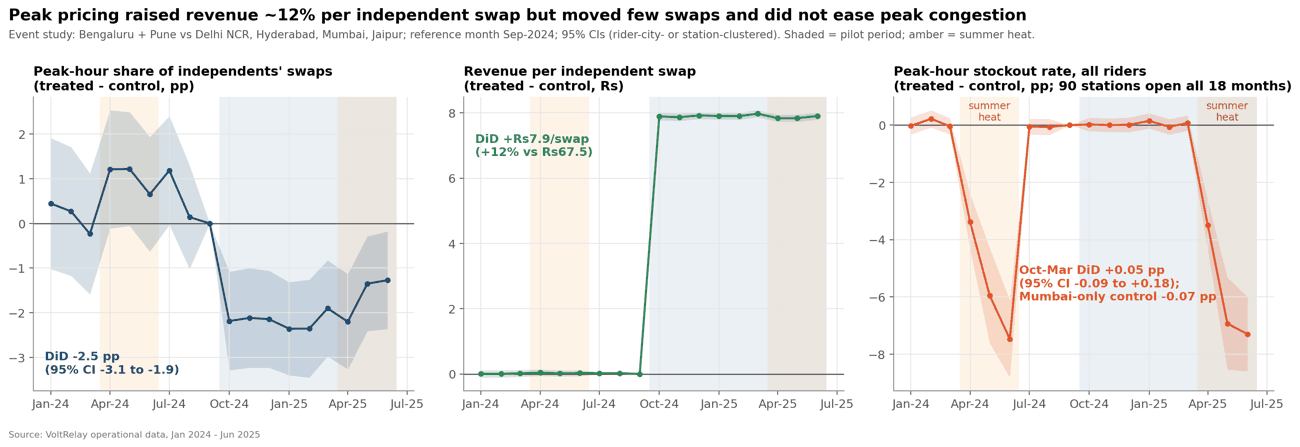

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_01_pilot_event_study.png')

In [128]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
spec = [("peak_share", "Peak-hour share of independents' swaps\n(treated - control, pp)", PALETTE["primary"]),
        ("rev_per_swap", "Revenue per independent swap\n(treated - control, Rs)", PALETTE["good"]),
        ("peak_stockout_rate", f"Peak-hour stockout rate, all riders\n(treated - control, pp; {len(BAL_ST)} stations open all 18 months)", PALETTE["accent"])]
for ax, (out, lab, colr) in zip(axes, spec):
    d = ES[ES["outcome"] == out]
    x = pd.to_datetime(d["month"])
    ax.axvspan(pd.Timestamp("2024-10-01") - pd.Timedelta(days=15), pd.Timestamp("2025-06-15"), color=PALETTE["light"], alpha=0.5, lw=0)
    ax.axvspan(pd.Timestamp("2025-03-16"), pd.Timestamp("2025-06-15"), color=PALETTE["warn"], alpha=0.12, lw=0)
    ax.axvspan(pd.Timestamp("2024-03-16"), pd.Timestamp("2024-06-15"), color=PALETTE["warn"], alpha=0.12, lw=0)
    ax.axhline(0, color="#555555", lw=1)
    ax.fill_between(x, d["lo"], d["hi"], color=colr, alpha=0.18, lw=0)
    ax.plot(x, d["est"], "o-", color=colr, ms=4, lw=1.8)
    ax.set_title(lab, fontsize=11.5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
pk = did_get(GRP_ORDER[0], "peak_share"); rv = did_get(GRP_ORDER[0], "rev_per_swap")
so = DID[(DID["outcome"] == "peak_stockout_rate_pp") & (DID["post_window"] == "Oct24-Mar25") & (DID["spec"] == "station + month FE")].iloc[0]
so_mum = DID[(DID["outcome"] == "peak_stockout_rate_pp") & (DID["spec"] == "Mumbai-only control")].iloc[0]
axes[0].annotate(f"DiD {pk['est']:+.1f} pp\n(95% CI {pk['lo']:+.1f} to {pk['hi']:+.1f})", xy=(0.03, 0.06), xycoords="axes fraction", fontsize=10.5, color=PALETTE["primary"], fontweight="bold")
axes[1].annotate(f"DiD +Rs{rv['est']:.1f}/swap\n(+{100*rv['est']/rv['pre_treated_mean']:.0f}% vs Rs{rv['pre_treated_mean']:.1f})", xy=(0.03, 0.80), xycoords="axes fraction", fontsize=10.5, color=PALETTE["good"], fontweight="bold")
axes[2].annotate(f"Oct-Mar DiD {so['est']:+.2f} pp\n(95% CI {so['lo']:+.2f} to {so['hi']:+.2f});\nMumbai-only control {so_mum['est']:+.2f} pp",
                 xy=(0.33, 0.30), xycoords="axes fraction", va="bottom", fontsize=10.5, color=PALETTE["accent"], fontweight="bold")
for xt in ("2024-05-01", "2025-05-01"):
    axes[2].text(pd.Timestamp(xt), axes[2].get_ylim()[1] - 0.15, "summer\nheat", ha="center", va="top", fontsize=9, color="#9a6a00")
fig.suptitle("Peak pricing raised revenue ~12% per independent swap but moved few swaps and did not ease peak congestion",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, 0.965, "Event study: Bengaluru + Pune vs Delhi NCR, Hyderabad, Mumbai, Jaipur; reference month Sep-2024; 95% CIs (rider-city- or station-clustered). "
         "Shaded = pilot period; amber = summer heat.", fontsize=9.5, color="#555555", ha="left")
fig.tight_layout()
save_fig(fig, f"{QID}_01_pilot_event_study")

### Figure: who responded? DiD by segment

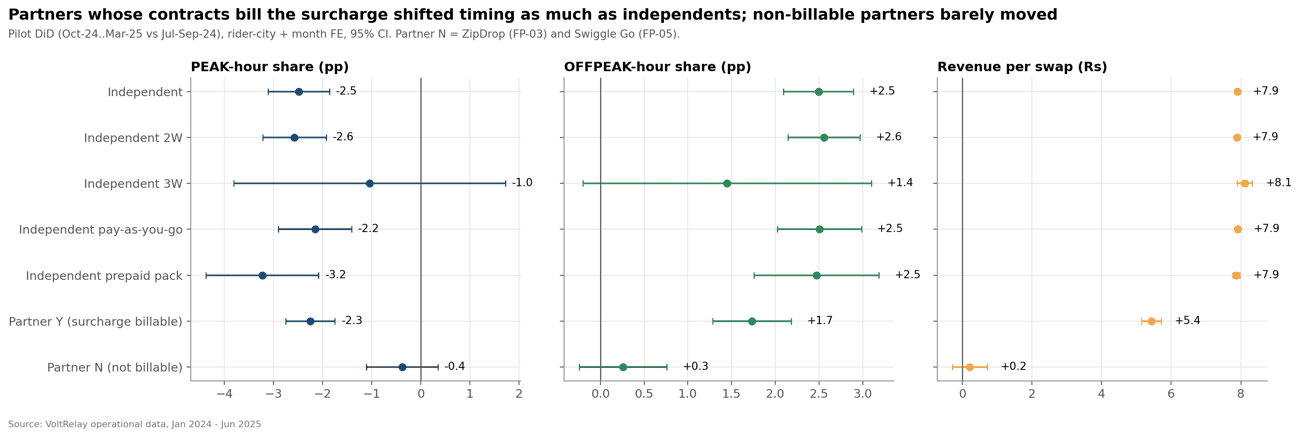

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_02_pilot_segments.png')

In [129]:
segs = [GRP_ORDER[0], "Independent 2W", "Independent 3W", "Independent pay-as-you-go", "Independent prepaid pack", GRP_ORDER[1], GRP_ORDER[2]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (out, lab, colr) in zip(axes, [("peak_share", "PEAK-hour share (pp)", PALETTE["primary"]), ("off_share", "OFFPEAK-hour share (pp)", PALETTE["good"]),
                                      ("rev_per_swap", "Revenue per swap (Rs)", PALETTE["warn"])]):
    d = pd.DataFrame([did_get(s, out) for s in segs])
    y = np.arange(len(segs))[::-1]
    ax.errorbar(d["est"], y, xerr=[d["est"] - d["lo"], d["hi"] - d["est"]], fmt="o", color=colr, ecolor=colr, capsize=3, ms=6)
    ax.axvline(0, color="#555555", lw=1)
    for yy, (_, rr) in zip(y, d.iterrows()):
        ax.text(rr["hi"] + (abs(d["hi"]).max() * 0.04 + 0.05), yy, f"{rr['est']:+.1f}", va="center", fontsize=9.5)
    ax.set_title(lab, fontsize=11.5)
    ax.set_yticks(y); ax.set_yticklabels(segs)
fig.suptitle("Partners whose contracts bill the surcharge shifted timing as much as independents; non-billable partners barely moved",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.03)
fig.text(0.01, 0.955, "Pilot DiD (Oct-24..Mar-25 vs Jul-Sep-24), rider-city + month FE, 95% CI. Partner N = ZipDrop (FP-03) and Swiggle Go (FP-05).",
         fontsize=9.5, color="#555555", ha="left")
fig.tight_layout()
save_fig(fig, f"{QID}_02_pilot_segments")

### Figure: base price change

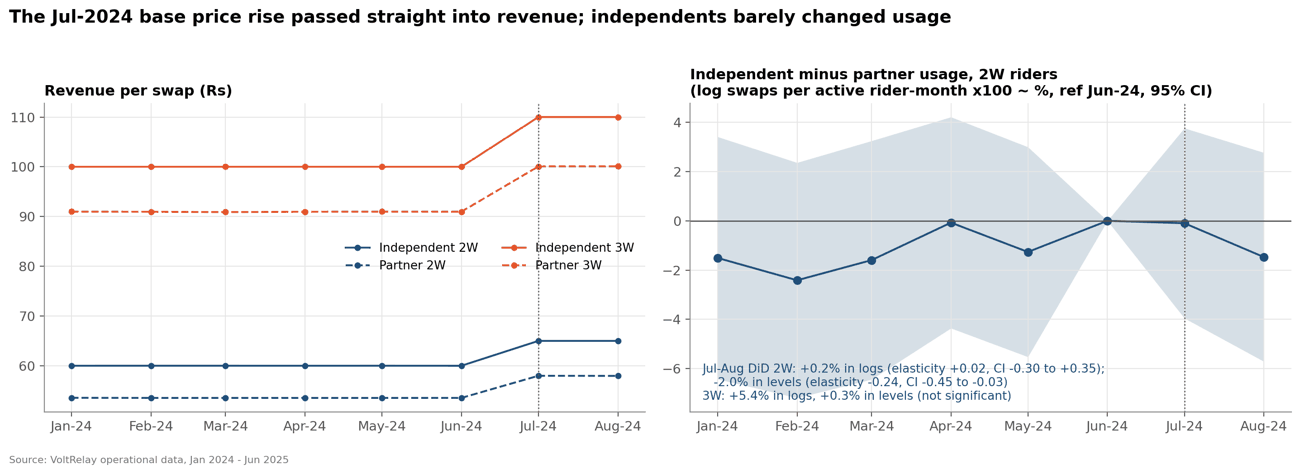

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_03_base_price_change.png')

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7))
sb = seg_bp.to_pandas()
for (seg, vc), colr, ls in ((("Independent", "2W"), PALETTE["primary"], "-"), (("Partner", "2W"), PALETTE["primary"], "--"),
                            (("Independent", "3W"), PALETTE["accent"], "-"), (("Partner", "3W"), PALETTE["accent"], "--")):
    d = sb[(sb["seg"] == seg) & (sb["vehicle_class"] == vc)]
    axes[0].plot(pd.to_datetime(d["month"]), d["rev_ps"], ls, marker="o", ms=4, color=colr, label=f"{seg} {vc}")
axes[0].axvline(pd.Timestamp(BASE_PRICE_CHANGE), color="#555555", lw=1, ls=":")
axes[0].set_title("Revenue per swap (Rs)", fontsize=11.5); axes[0].legend(ncol=2, loc="center right")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
x = pd.to_datetime(EV_BP["month"])
axes[1].fill_between(x, EV_BP["lo"], EV_BP["hi"], color=PALETTE["primary"], alpha=0.18, lw=0)
axes[1].plot(x, EV_BP["est"], "o-", color=PALETTE["primary"])
axes[1].axhline(0, color="#555555", lw=1); axes[1].axvline(pd.Timestamp(BASE_PRICE_CHANGE), color="#555555", lw=1, ls=":")
b2 = BP[BP["vehicle_class"] == "2W"].iloc[0]; b3 = BP[BP["vehicle_class"] == "3W"].iloc[0]
axes[1].set_title("Independent minus partner usage, 2W riders\n(log swaps per active rider-month x100 ~ %, ref Jun-24, 95% CI)", fontsize=11.5)
axes[1].annotate(f"Jul-Aug DiD 2W: {b2['did_pct']:+.1f}% in logs (elasticity {b2['elasticity']:+.2f}, CI {b2['elasticity_lo']:+.2f} to {b2['elasticity_hi']:+.2f});\n"
                 f"   {b2['did_pct_level']:+.1f}% in levels (elasticity {b2['elasticity_level']:+.2f}, CI {b2['elasticity_level_lo']:+.2f} to {b2['elasticity_level_hi']:+.2f})\n"
                 f"3W: {b3['did_pct']:+.1f}% in logs, {b3['did_pct_level']:+.1f}% in levels (not significant)",
                 xy=(0.02, 0.04), xycoords="axes fraction", fontsize=9.5, color=PALETTE["primary"])
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
fig.suptitle("The Jul-2024 base price rise passed straight into revenue; independents barely changed usage",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
fig.tight_layout()
save_fig(fig, f"{QID}_03_base_price_change")

## 6. Partner economics (12 partners + independents)
Per completed swap: revenue, energy, battery wear, station fixed cost -> cm1, cm2. Working-capital cost =
revenue x 12% x payment_terms_days / 365 (independents pay at the swap: 0). "Steady-state" cm1 replaces Kyron wear and
energy with the non-Kyron average (all Kyron packs were retired on 2025-06-15), i.e. the margin a contract signed today
would earn. Main window = **current terms** (Nov-2024..Jun-2025, after the ZipDrop amendment); full window also saved.

In [131]:
riders_by = {}
for lab, (m0, m1) in {"current": CUR, "full": (M(2024, 1), M(2025, 6))}.items():
    riders_by[lab] = (LF.filter(pl.col("is_completed") & pl.col("month").is_between(m0, m1))
                      .group_by("pid").agg(pl.col("rider_id").n_unique().alias("riders")).collect())
PINFO = PARTNERS.select(pl.col("partner_id").alias("pid"), "partner_name", "partner_segment", "contract_type", "discount_pct",
                        "discount_pct_after_amendment", "peak_surcharge_billable", "payment_terms_days")


def partner_table(m0, m1, rid):
    c = CELLS.filter(pl.col("month").is_between(m0, m1))
    n_months = len({d for d in c["month"].to_list()})
    tot = c["swaps"].sum()
    pilot_peak = (pl.col("city").is_in(PILOT_CITIES)) & (pl.col("month") >= PILOT_START) & (pl.col("band") == "peak")
    g = (c.group_by("pid").agg(
        pl.col("swaps").sum(), pl.col("revenue").sum(), pl.col("list_rev").sum(), pl.col("disc").sum(),
        pl.col("energy").sum(), pl.col("wear").sum(), pl.col("fixed").sum(), pl.col("cm1").sum(), pl.col("cm2").sum(),
        pl.col("ky_swaps").sum(), pl.col("wear_nonky").sum(), pl.col("energy_nonky").sum(),
        pl.col("swaps").filter(pl.col("band") == "peak").sum().alias("peak_swaps"),
        pl.col("swaps").filter(pilot_peak).sum().alias("pilot_peak_swaps"),
        pl.col("swaps").filter(pl.col("vehicle_class") == "3W").sum().alias("swaps_3w"),
        pl.col("swaps").filter(pl.col("city").is_in(PILOT_CITIES)).sum().alias("pilot_city_swaps"))
         .join(rid, on="pid", how="left").join(PINFO, on="pid", how="left")
         .with_columns(pl.when(pl.col("pid") == "IND").then(pl.lit("Independents")).otherwise(pl.col("partner_name")).alias("partner_name"),
                       pl.when(pl.col("pid") == "IND").then(pl.lit("independent")).otherwise(pl.col("partner_segment")).alias("partner_segment"),
                       pl.col("payment_terms_days").fill_null(0))
         .with_columns((pl.col("swaps") / tot).alias("share_network_swaps"),
                       (pl.col("disc") / pl.col("list_rev")).alias("discount_pct_realised"),
                       *[(pl.col(k) / pl.col("swaps")).alias(f"{k}_ps") for k in ("revenue", "list_rev", "energy", "wear", "fixed", "cm1", "cm2")],
                       (pl.col("swaps_3w") / pl.col("swaps")).alias("share_3w"),
                       (pl.col("peak_swaps") / pl.col("swaps")).alias("peak_share"),
                       (pl.col("revenue") * COC * pl.col("payment_terms_days") / 365).alias("wc_cost"))
         .with_columns((pl.col("wc_cost") / pl.col("swaps")).alias("wc_ps"),
                       (pl.col("cm2") - pl.col("wc_cost")).alias("cm2_after_wc"),
                       (pl.col("revenue_ps") - pl.col("energy_nonky") / (pl.col("swaps") - pl.col("ky_swaps"))
                        - pl.col("wear_nonky") / (pl.col("swaps") - pl.col("ky_swaps"))).alias("cm1_ps_steady"),
                       pl.when(pl.col("peak_surcharge_billable") == "N").then(pl.col("pilot_peak_swaps") * 15.0).otherwise(0.0).alias("surcharge_forgone_pilot"),
                       pl.lit(n_months).alias("n_months"))
         .with_columns((pl.col("cm2_after_wc") / pl.col("swaps")).alias("cm2_after_wc_ps"),
                       (pl.col("cm1_ps_steady") - pl.col("fixed_ps") - pl.col("wc_ps")).alias("cm2wc_ps_steady"),
                       (pl.col("swaps") / n_months).alias("swaps_per_month"))
         .sort("swaps", descending=True))
    return g


PT_CUR = partner_table(*CUR, riders_by["current"])
PT_FULL = partner_table(M(2024, 1), M(2025, 6), riders_by["full"])
keep = ["pid", "partner_name", "partner_segment", "riders", "swaps", "share_network_swaps", "revenue", "discount_pct_realised",
        "revenue_ps", "energy_ps", "wear_ps", "fixed_ps", "cm1_ps", "cm2_ps", "cm1", "cm2", "payment_terms_days", "wc_cost",
        "wc_ps", "cm2_after_wc", "cm2_after_wc_ps", "cm1_ps_steady", "cm2wc_ps_steady", "peak_share", "share_3w",
        "peak_surcharge_billable", "surcharge_forgone_pilot", "swaps_per_month"]
PT_CUR.select(keep).write_csv(TAB / f"{QID}_partner_economics_current_terms.csv")
PT_FULL.select(keep).write_csv(TAB / f"{QID}_partner_economics_full_window.csv")
show = ["pid", "partner_name", "riders", "swaps", "share_network_swaps", "revenue", "discount_pct_realised", "revenue_ps", "energy_ps",
        "wear_ps", "fixed_ps", "cm1_ps", "cm2_ps", "cm1", "cm2", "wc_ps", "cm2_after_wc", "cm1_ps_steady", "peak_share", "share_3w"]
p("\nPartner economics - CURRENT TERMS (Nov-2024..Jun-2025):")
p(PT_CUR.select(show).with_columns(pl.col(pl.Float64).round(3)))
p("\nPartner economics - FULL WINDOW (Jan-2024..Jun-2025):")
p(PT_FULL.select(show).with_columns(pl.col(pl.Float64).round(3)))

# who is the largest partner, and is it the most valuable?
for lab, t in (("current terms", PT_CUR), ("full window", PT_FULL)):
    pt = t.filter(pl.col("pid") != "IND")
    big_sw = pt.sort("swaps", descending=True)["partner_name"][0]
    big_rev = pt.sort("revenue", descending=True)["partner_name"][0]
    big_rid = pt.sort("riders", descending=True)["partner_name"][0]
    rank_cm1 = pt.sort("cm1", descending=True).with_row_index("rank_cm1", offset=1)
    rank_cm2 = pt.sort("cm2_after_wc", descending=True).with_row_index("rank_cm2wc", offset=1)
    zd = rank_cm1.filter(pl.col("pid") == ZIPDROP_ID)
    zd2 = rank_cm2.filter(pl.col("pid") == ZIPDROP_ID)
    p(f"[{lab}] largest partner by swaps: {big_sw}; by revenue: {big_rev}; by riders: {big_rid}. "
      f"ZipDrop share of network swaps {100*zd['share_network_swaps'][0]:.1f}%, of partner swaps {100*zd['swaps'][0]/pt['swaps'].sum():.1f}%; "
      f"ZipDrop rank by total cm1 = {zd['rank_cm1'][0]}/12 (cm1 {money(zd['cm1'][0])}), by cm2 after WC = {zd2['rank_cm2wc'][0]}/12 "
      f"({money(zd2['cm2_after_wc'][0])})")
    p(f"[{lab}] best partner by total cm1: {rank_cm1['partner_name'][0]} ({money(rank_cm1['cm1'][0])}); by cm1/swap: "
      f"{pt.sort('cm1_ps', descending=True)['partner_name'][0]} (Rs{pt.sort('cm1_ps', descending=True)['cm1_ps'][0]:.2f}); "
      f"by cm2 after WC: {rank_cm2['partner_name'][0]} ({money(rank_cm2['cm2_after_wc'][0])})")

# Per-swap ranks differ from total ranks: the two 3W cargo partners lose more per swap than ZipDrop.
PT_RANK = PT_CUR.filter(pl.col("pid") != "IND").join(
    PARTNERS.select(pl.col("partner_id").alias("pid"), pl.col("vehicle_class").alias("contract_vc")), on="pid", how="left")
ZD_RANK = {}
for k, lab_k in (("cm1_ps", "cm1/swap"), ("cm2_after_wc_ps", "cm2 after WC/swap"), ("cm1_ps_steady", "steady-state cm1/swap")):
    rk = PT_RANK.sort(k, descending=True).with_row_index("rk", offset=1)
    zrow_ = rk.filter(pl.col("pid") == ZIPDROP_ID)
    lower = rk.filter(pl.col(k) < zrow_[k][0])
    rk2w = PT_RANK.filter(pl.col("contract_vc") != "3W").sort(k, descending=True).with_row_index("rk", offset=1)  # 2W + 'mixed' (MetroMove)
    ZD_RANK[k] = dict(rank=zrow_["rk"][0], n=rk.height, rank_2w=rk2w.filter(pl.col("pid") == ZIPDROP_ID)["rk"][0], n_2w=rk2w.height,
                      lower=lower["partner_name"].to_list())
    p(f"[current terms] ZipDrop rank by {lab_k}: {ZD_RANK[k]['rank']}/{rk.height} (Rs{zrow_[k][0]:.2f}); among the partners with 2W or mixed "
      f"fleets {ZD_RANK[k]['rank_2w']}/{rk2w.height}; lower per swap: "
      + ", ".join(f"{n} ({v_:.2f}, {vc_})" for n, v_, vc_ in lower.select("partner_name", k, "contract_vc").iter_rows()))


Partner economics - CURRENT TERMS (Nov-2024..Jun-2025):


shape: (13, 20)
┌───────┬────────────┬────────┬────────┬────────────┬────────────┬────────────┬────────────┬───────────┬─────────┬──────────┬──────────┬──────────┬────────────┬────────────┬────────┬────────────┬───────────┬───────────┬──────────┐
│ pid   ┆ partner_na ┆ riders ┆ swaps  ┆ share_netw ┆ revenue    ┆ discount_p ┆ revenue_ps ┆ energy_ps ┆ wear_ps ┆ fixed_ps ┆ cm1_ps   ┆ cm2_ps   ┆ cm1        ┆ cm2        ┆ wc_ps  ┆ cm2_after_ ┆ cm1_ps_st ┆ peak_shar ┆ share_3w │
│ ---   ┆ me         ┆ ---    ┆ ---    ┆ ork_swaps  ┆ ---        ┆ ct_realise ┆ ---        ┆ ---       ┆ ---     ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---        ┆ ---    ┆ wc         ┆ eady      ┆ e         ┆ ---      │
│ str   ┆ ---        ┆ u32    ┆ u32    ┆ ---        ┆ f64        ┆ d          ┆ f64        ┆ f64       ┆ f64     ┆ f64      ┆ f64      ┆ f64      ┆ f64        ┆ f64        ┆ f64    ┆ ---        ┆ ---       ┆ ---       ┆ f64      │
│       ┆ str        ┆        ┆        ┆ f64        ┆       


Partner economics - FULL WINDOW (Jan-2024..Jun-2025):


shape: (13, 20)
┌───────┬────────────┬────────┬─────────┬────────────┬────────────┬────────────┬────────────┬───────────┬─────────┬──────────┬──────────┬──────────┬────────────┬────────────┬────────┬───────────┬───────────┬───────────┬──────────┐
│ pid   ┆ partner_na ┆ riders ┆ swaps   ┆ share_netw ┆ revenue    ┆ discount_p ┆ revenue_ps ┆ energy_ps ┆ wear_ps ┆ fixed_ps ┆ cm1_ps   ┆ cm2_ps   ┆ cm1        ┆ cm2        ┆ wc_ps  ┆ cm2_after ┆ cm1_ps_st ┆ peak_shar ┆ share_3w │
│ ---   ┆ me         ┆ ---    ┆ ---     ┆ ork_swaps  ┆ ---        ┆ ct_realise ┆ ---        ┆ ---       ┆ ---     ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---        ┆ ---    ┆ _wc       ┆ eady      ┆ e         ┆ ---      │
│ str   ┆ ---        ┆ u32    ┆ u32     ┆ ---        ┆ f64        ┆ d          ┆ f64        ┆ f64       ┆ f64     ┆ f64      ┆ f64      ┆ f64      ┆ f64        ┆ f64        ┆ f64    ┆ ---       ┆ ---       ┆ ---       ┆ f64      │
│       ┆ str        ┆        ┆         ┆ f64        ┆      

[current terms] largest partner by swaps: ZipDrop; by revenue: FeastFly; by riders: FeastFly. ZipDrop share of network swaps 15.5%, of partner swaps 23.4%; ZipDrop rank by total cm1 = 12/12 (cm1 ₹-69.3 L), by cm2 after WC = 12/12 (₹-1.09 Cr)


[current terms] best partner by total cm1: DabbaXpress (₹-1.6 L); by cm1/swap: DabbaXpress (Rs-2.84); by cm2 after WC: UrbanErrand (₹-7.8 L)


[full window] largest partner by swaps: ZipDrop; by revenue: FeastFly; by riders: FeastFly. ZipDrop share of network swaps 15.3%, of partner swaps 23.2%; ZipDrop rank by total cm1 = 12/12 (cm1 ₹-75.1 L), by cm2 after WC = 12/12 (₹-1.49 Cr)


[full window] best partner by total cm1: UrbanErrand (₹-69.8K); by cm1/swap: UrbanErrand (Rs-0.85); by cm2 after WC: UrbanErrand (₹-12.2 L)


[current terms] ZipDrop rank by cm1/swap: 10/12 (Rs-20.60); among the partners with 2W or mixed fleets 10/10; lower per swap: HaulKing (-21.42, 3W), CargoTuk (-22.24, 3W)


[current terms] ZipDrop rank by cm2 after WC/swap: 10/12 (Rs-32.42); among the partners with 2W or mixed fleets 10/10; lower per swap: HaulKing (-34.90, 3W), CargoTuk (-35.05, 3W)


[current terms] ZipDrop rank by steady-state cm1/swap: 10/12 (Rs-4.18); among the partners with 2W or mixed fleets 10/10; lower per swap: HaulKing (-13.69, 3W), CargoTuk (-14.70, 3W)


### Mix-standardised comparison: is it the contract or the cost to serve?
For each partner, compare its revenue and cost per swap with the *other partners'* average in the same
city x month x vehicle-class x tariff-band cell. Positive cost gap = more expensive to serve than peers.

In [132]:
pc = CELLS.filter((pl.col("pid") != "IND") & pl.col("month").is_between(*CUR))
keys_ = ["month", "city", "vehicle_class", "band"]
tot_c = pc.group_by(keys_).agg([pl.col(k).sum().alias(f"T_{k}") for k in ("swaps", "revenue", "energy", "wear", "fixed", "cm1")])
mixstd = (pc.join(tot_c, on=keys_)
          .with_columns([((pl.col(f"T_{k}") - pl.col(k)) / (pl.col("T_swaps") - pl.col("swaps"))).alias(f"peer_{k}_ps")
                         for k in ("revenue", "energy", "wear", "fixed", "cm1")])
          .filter(pl.col("T_swaps") > pl.col("swaps"))
          .group_by("pid").agg(pl.col("swaps").sum(),
                               *[((pl.col(k) - pl.col("swaps") * pl.col(f"peer_{k}_ps")).sum() / pl.col("swaps").sum()).alias(f"gap_{k}_ps")
                                 for k in ("revenue", "energy", "wear", "fixed", "cm1")])
          .with_columns((pl.col("gap_energy_ps") + pl.col("gap_wear_ps") + pl.col("gap_fixed_ps")).alias("gap_cost_ps"))
          .join(PINFO.select("pid", "partner_name"), on="pid").sort("gap_cm1_ps"))
mixstd.write_csv(TAB / f"{QID}_partner_mix_standardised_gaps.csv")
p("\nMix-standardised gaps vs peer partners in the same city x month x class x band cell (Rs/swap, current terms):")
p(mixstd.with_columns(pl.col(pl.Float64).round(2)))

# segment-level view
SEG = (PT_CUR.group_by("partner_segment").agg(
    pl.col("riders").sum(), pl.col("swaps").sum(), pl.col("revenue").sum(), pl.col("list_rev").sum(), pl.col("disc").sum(),
    pl.col("energy").sum(), pl.col("wear").sum(), pl.col("fixed").sum(), pl.col("cm1").sum(), pl.col("cm2").sum(),
    pl.col("wc_cost").sum(), pl.col("peak_swaps").sum(), pl.col("swaps_3w").sum())
       .with_columns((pl.col("swaps") / pl.col("swaps").sum()).alias("share_swaps"),
                     (pl.col("disc") / pl.col("list_rev")).alias("discount_pct"),
                     *[(pl.col(k) / pl.col("swaps")).alias(f"{k}_ps") for k in ("revenue", "energy", "wear", "fixed", "cm1", "cm2")],
                     ((pl.col("cm2") - pl.col("wc_cost")) / pl.col("swaps")).alias("cm2_after_wc_ps"),
                     (pl.col("peak_swaps") / pl.col("swaps")).alias("peak_share"), (pl.col("swaps_3w") / pl.col("swaps")).alias("share_3w"))
       .sort("cm1_ps", descending=True))
SEG.write_csv(TAB / f"{QID}_segment_economics.csv")
p("\nSegment economics (current terms):")
p(SEG.select("partner_segment", "riders", "swaps", "share_swaps", "discount_pct", "revenue_ps", "energy_ps", "wear_ps", "cm1_ps", "cm2_ps",
             "cm2_after_wc_ps", "cm1", "peak_share", "share_3w").with_columns(pl.col(pl.Float64).round(3)))

# 2W vs 3W unit economics (all riders, current terms, steady-state wear)
VC = (CELLS.filter(pl.col("month").is_between(*CUR)).group_by("vehicle_class")
      .agg(pl.col("swaps").sum(), (pl.col("revenue").sum() / pl.col("swaps").sum()).alias("rev_ps"),
           (pl.col("list_rev").sum() / pl.col("swaps").sum()).alias("list_ps"),
           (pl.col("energy").sum() / pl.col("swaps").sum()).alias("energy_ps"), (pl.col("wear").sum() / pl.col("swaps").sum()).alias("wear_ps"),
           (pl.col("wear_nonky").sum() / (pl.col("swaps").sum() - pl.col("ky_swaps").sum())).alias("wear_ps_nonkyron"),
           (pl.col("energy_nonky").sum() / (pl.col("swaps").sum() - pl.col("ky_swaps").sum())).alias("energy_ps_nonkyron"),
           (pl.col("fixed").sum() / pl.col("swaps").sum()).alias("fixed_ps"), (pl.col("cm1").sum() / pl.col("swaps").sum()).alias("cm1_ps"),
           pl.col("cm1").sum().alias("cm1"))
      .with_columns((pl.col("rev_ps") - pl.col("energy_ps_nonkyron") - pl.col("wear_ps_nonkyron")).alias("cm1_ps_steady"))
      .sort("vehicle_class"))
v3 = VC.filter(pl.col("vehicle_class") == "3W").to_dicts()[0]
be3 = v3["energy_ps_nonkyron"] + v3["wear_ps_nonkyron"]
p(f"3W steady-state energy+wear = Rs{be3:.2f}/swap vs list Rs{v3['list_ps']:.0f}; at the current realised/list ratio "
  f"{v3['rev_ps']/v3['list_ps']:.3f} the cm1 break-even 3W list price is Rs{be3/(v3['rev_ps']/v3['list_ps']):.0f}")

VC.write_csv(TAB / f"{QID}_vehicle_class_economics.csv")
p("\n2W vs 3W unit economics (current terms):")
p(VC.with_columns(pl.col(pl.Float64).round(2)))


Mix-standardised gaps vs peer partners in the same city x month x class x band cell (Rs/swap, current terms):


shape: (12, 9)
┌───────┬────────┬────────────────┬───────────────┬─────────────┬──────────────┬────────────┬─────────────┬──────────────┐
│ pid   ┆ swaps  ┆ gap_revenue_ps ┆ gap_energy_ps ┆ gap_wear_ps ┆ gap_fixed_ps ┆ gap_cm1_ps ┆ gap_cost_ps ┆ partner_name │
│ ---   ┆ ---    ┆ ---            ┆ ---           ┆ ---         ┆ ---          ┆ ---        ┆ ---         ┆ ---          │
│ str   ┆ u32    ┆ f64            ┆ f64           ┆ f64         ┆ f64          ┆ f64        ┆ f64         ┆ str          │
╞═══════╪════════╪════════════════╪═══════════════╪═════════════╪══════════════╪════════════╪═════════════╪══════════════╡
│ FP-03 ┆ 336422 ┆ -14.7000       ┆ 0.7900        ┆ -0.0700     ┆ -0.6100      ┆ -15.4200   ┆ 0.1000      ┆ ZipDrop      │
│ FP-02 ┆ 177744 ┆ -0.8400        ┆ -0.1700       ┆ -0.0100     ┆ 0.1700       ┆ -0.6600    ┆ -0.0100     ┆ ParcelNest   │
│ FP-05 ┆ 141753 ┆ 0.7300         ┆ -0.2500       ┆ 0.1500      ┆ 0.2000       ┆ 0.8200     ┆ 0.1100      ┆ Swiggle Go   │
│


Segment economics (current terms):


shape: (6, 14)
┌─────────────────┬────────┬────────┬─────────────┬──────────────┬────────────┬───────────┬─────────┬──────────┬──────────┬─────────────────┬───────────────┬────────────┬──────────┐
│ partner_segment ┆ riders ┆ swaps  ┆ share_swaps ┆ discount_pct ┆ revenue_ps ┆ energy_ps ┆ wear_ps ┆ cm1_ps   ┆ cm2_ps   ┆ cm2_after_wc_ps ┆ cm1           ┆ peak_share ┆ share_3w │
│ ---             ┆ ---    ┆ ---    ┆ ---         ┆ ---          ┆ ---        ┆ ---       ┆ ---     ┆ ---      ┆ ---      ┆ ---             ┆ ---           ┆ ---        ┆ ---      │
│ str             ┆ u32    ┆ u32    ┆ f64         ┆ f64          ┆ f64        ┆ f64       ┆ f64     ┆ f64      ┆ f64      ┆ f64             ┆ f64           ┆ f64        ┆ f64      │
╞═════════════════╪════════╪════════╪═════════════╪══════════════╪════════════╪═══════════╪═════════╪══════════╪══════════╪═════════════════╪═══════════════╪════════════╪══════════╡
│ independent     ┆ 6358   ┆ 740363 ┆ 0.3400      ┆ 0.0000       ┆ 70.0950 

3W steady-state energy+wear = Rs116.21/swap vs list Rs110; at the current realised/list ratio 0.921 the cm1 break-even 3W list price is Rs126



2W vs 3W unit economics (current terms):


shape: (2, 12)
┌───────────────┬─────────┬──────────┬──────────┬───────────┬─────────┬──────────────────┬────────────────────┬──────────┬──────────┬───────────────┬───────────────┐
│ vehicle_class ┆ swaps   ┆ rev_ps   ┆ list_ps  ┆ energy_ps ┆ wear_ps ┆ wear_ps_nonkyron ┆ energy_ps_nonkyron ┆ fixed_ps ┆ cm1_ps   ┆ cm1           ┆ cm1_ps_steady │
│ ---           ┆ ---     ┆ ---      ┆ ---      ┆ ---       ┆ ---     ┆ ---              ┆ ---                ┆ ---      ┆ ---      ┆ ---           ┆ ---           │
│ str           ┆ u32     ┆ f64      ┆ f64      ┆ f64       ┆ f64     ┆ f64              ┆ f64                ┆ f64      ┆ f64      ┆ f64           ┆ f64           │
╞═══════════════╪═════════╪══════════╪══════════╪═══════════╪═════════╪══════════════════╪════════════════════╪══════════╪══════════╪═══════════════╪═══════════════╡
│ 2W            ┆ 1954120 ┆ 60.6000  ┆ 65.0000  ┆ 16.1100   ┆ 49.4900 ┆ 31.8600          ┆ 16.5000            ┆ 11.5700  ┆ -5.0000  ┆ -9765252.1300 ┆ 12.23

### Figure: partner value bubble chart (hero)

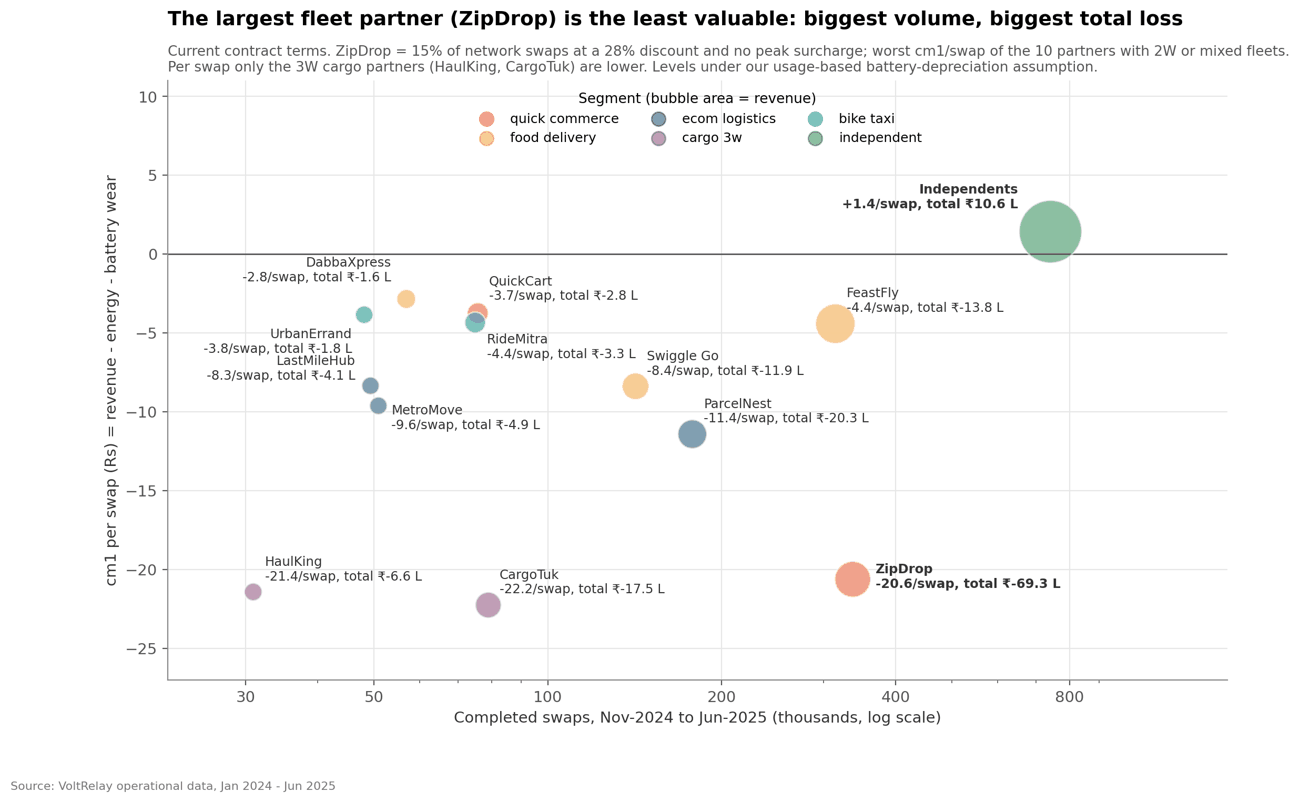

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_04_partner_value_bubble.png')

In [133]:
SEG_COL = {"quick_commerce": SERIES[1], "food_delivery": SERIES[3], "ecom_logistics": SERIES[0], "cargo_3w": SERIES[4],
           "bike_taxi": SERIES[5], "independent": SERIES[2]}
bt = PT_CUR.to_pandas()
fig, ax = plt.subplots(figsize=(13, 7.4))
smax = bt["revenue"].max()
OFFS = {"IND": (-22, 16, "right"), ZIPDROP_ID: (16, -6, "left"), "FP-07": (8, 9, "left"), "FP-06": (8, -24, "left"),
        "FP-08": (-10, 12, "right"), "FP-12": (-8, -26, "right"), "FP-11": (-10, 4, "right"), "FP-10": (9, -16, "left")}
for _, r in bt.iterrows():
    ax.scatter(r["swaps"] / 1e3, r["cm1_ps"], s=1800 * r["revenue"] / smax + 40, color=SEG_COL[r["partner_segment"]], alpha=0.55,
               edgecolor="white", lw=1.2, zorder=3)
    lbl = f"{r['partner_name']}\n{r['cm1_ps']:+.1f}/swap, total {money(r['cm1'])}"
    dx, dy, ha = OFFS.get(r["pid"], (8, 8, "left"))
    ax.annotate(lbl, (r["swaps"] / 1e3, r["cm1_ps"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.8,
                ha=ha, color="#333333", fontweight="bold" if r["pid"] in (ZIPDROP_ID, "IND") else "normal")
ax.axhline(0, color="#555555", lw=1)
for segname, colr in SEG_COL.items():
    ax.scatter([], [], s=90, color=colr, alpha=0.6, label=segname.replace("_", " "))
ax.legend(title="Segment (bubble area = revenue)", loc="upper center", ncol=3, fontsize=9, title_fontsize=9.5)
ax.set_xscale("log")
ax.set_xlim(22, 1500); ax.set_ylim(-27, 11)
ax.set_xticks([30, 50, 100, 200, 400, 800]); ax.set_xticklabels(["30", "50", "100", "200", "400", "800"])
ax.set_xlabel("Completed swaps, Nov-2024 to Jun-2025 (thousands, log scale)")
ax.set_ylabel("cm1 per swap (Rs) = revenue - energy - battery wear")
zrow = bt[bt["pid"] == ZIPDROP_ID].iloc[0]
ax.set_title("The largest fleet partner (ZipDrop) is the least valuable: biggest volume, biggest total loss", fontsize=13.5, pad=38)
ax.text(0.0, 1.015, f"Current contract terms. ZipDrop = {100*zrow['share_network_swaps']:.0f}% of network swaps at a {100*zrow['discount_pct_realised']:.0f}% discount and no peak surcharge; "
        f"worst cm1/swap of the {ZD_RANK['cm1_ps']['n_2w']} partners with 2W or mixed fleets.\nPer swap only the 3W cargo partners ({', '.join(ZD_RANK['cm1_ps']['lower'])}) are lower. "
        "Levels under our usage-based battery-depreciation assumption.", transform=ax.transAxes, fontsize=9.5, color="#555555")
save_fig(fig, f"{QID}_04_partner_value_bubble")

### Figure: per-swap unit economics by partner (revenue vs cost stack)

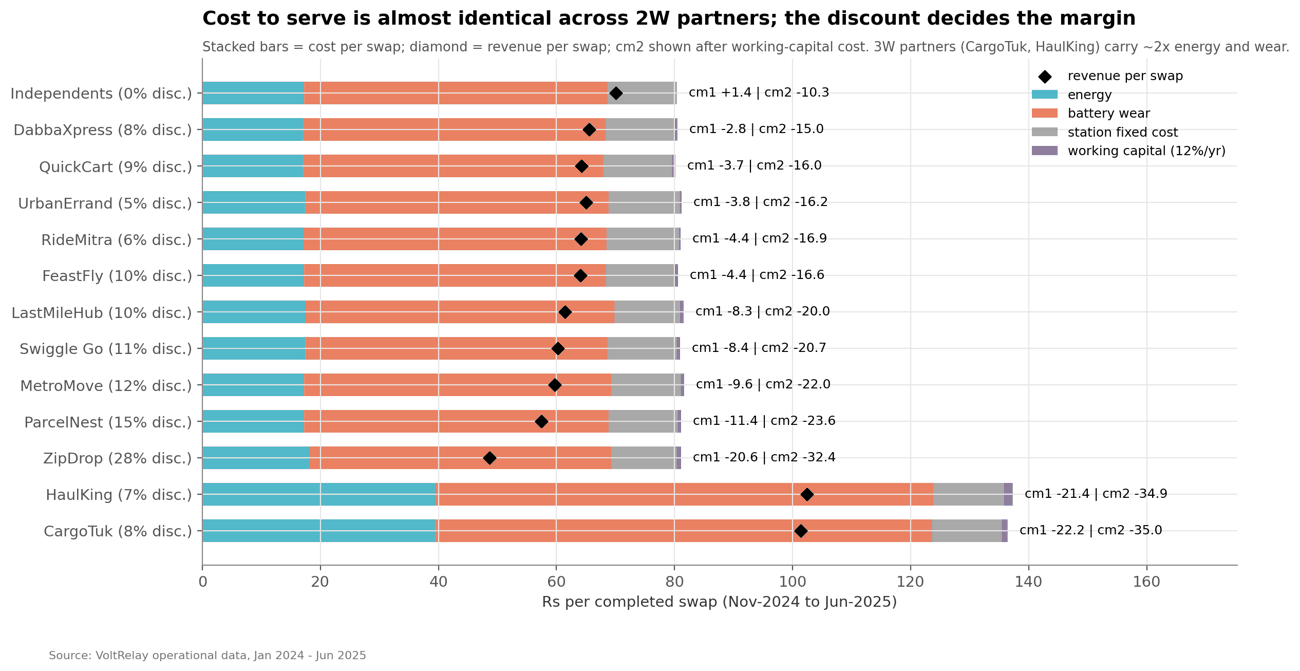

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_05_partner_unit_economics.png')

In [134]:
bt2 = bt.sort_values("cm1_ps")
fig, ax = plt.subplots(figsize=(13, 6.4))
y = np.arange(len(bt2))
left = np.zeros(len(bt2))
for k, colr, lab in (("energy_ps", SERIES[5], "energy"), ("wear_ps", SERIES[1], "battery wear"), ("fixed_ps", PALETTE["muted"], "station fixed cost"),
                     ("wc_ps", SERIES[4], "working capital (12%/yr)")):
    ax.barh(y, bt2[k], left=left, color=colr, alpha=0.75, label=lab, height=0.62)
    left += bt2[k].values
ax.scatter(bt2["revenue_ps"], y, marker="D", color="black", zorder=4, s=36, label="revenue per swap")
for yy, (_, r) in zip(y, bt2.iterrows()):
    ax.text(max(r["revenue_ps"], left[yy]) + 2, yy, f"cm1 {r['cm1_ps']:+.1f} | cm2 {r['cm2_after_wc_ps']:+.1f}", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([f"{n} ({100*d:.0f}% disc.)" for n, d in zip(bt2["partner_name"], bt2["discount_pct_realised"])])
ax.set_xlabel("Rs per completed swap (Nov-2024 to Jun-2025)")
ax.set_xlim(0, max(left.max(), bt2["revenue_ps"].max()) + 38)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Cost to serve is almost identical across 2W partners; the discount decides the margin", fontsize=13.5, pad=24)
ax.text(0.0, 1.015, "Stacked bars = cost per swap; diamond = revenue per swap; cm2 shown after working-capital cost. 3W partners (CargoTuk, HaulKing) carry ~2x energy and wear.",
        transform=ax.transAxes, fontsize=9.3, color="#555555")
save_fig(fig, f"{QID}_05_partner_unit_economics")

## 7. ZipDrop amendment (2024-11-01: discount 12% -> 28%, peak surcharge not billable)
Before/after for ZipDrop 2W swaps vs other partners' 2W swaps (difference-in-differences removes the network-wide
Kyron wear shock that started in Sep-2024). Pre = Jul-Oct 2024 (new list price already in force); post = Nov-24..Jun-25.

**Concurrent-treatment trap.** From Oct-2024 the surcharge-billable partners in Bengaluru and Pune started paying the
pilot's +Rs15 / -Rs8, which lifts the comparison group's revenue per swap in the post period. The price and margin DiD is
therefore estimated in the **four non-pilot cities only** (both groups), where nobody pays a surcharge; the all-city
version is printed for comparison. Volume and the Rs-per-month cost of the amendment use all cities.

In [135]:
def zip_monthly(cities=None):
    c = CELLS.filter((pl.col("pid") != "IND") & (pl.col("vehicle_class") == "2W") & (pl.col("month") >= M(2024, 1)))
    if cities is not None:
        c = c.filter(pl.col("city").is_in(cities))
    return (c.with_columns(pl.when(pl.col("pid") == ZIPDROP_ID).then(pl.lit("ZipDrop")).otherwise(pl.lit("Other partners")).alias("who"))
            .group_by("who", "month").agg(pl.col("swaps").sum(), pl.col("revenue").sum(), pl.col("list_rev").sum(), pl.col("disc").sum(),
                                          pl.col("cm1").sum(), pl.col("cm2").sum(), pl.col("energy").sum(), pl.col("wear").sum())
            .with_columns((pl.col("revenue") / pl.col("swaps")).alias("rev_ps"), (pl.col("cm1") / pl.col("swaps")).alias("cm1_ps"),
                          (pl.col("disc") / pl.col("list_rev")).alias("disc_pct"),
                          ((pl.col("energy") + pl.col("wear")) / pl.col("swaps")).alias("var_cost_ps"))
            .sort("who", "month"))


def zd_prepost(zm_):
    zp_ = zm_.to_pandas()
    zp_["month"] = pd.to_datetime(zp_["month"]).dt.date
    zp_["post"] = zp_["month"] >= ZIPDROP_AMEND
    pre_, post_ = zp_[(zp_["month"] >= M(2024, 7)) & (~zp_["post"])], zp_[zp_["post"]]
    res = {}
    for who in ("ZipDrop", "Other partners"):
        for per, d in (("pre", pre_), ("post", post_)):
            dd = d[d["who"] == who]
            res[(who, per)] = dict(rev_ps=dd["revenue"].sum() / dd["swaps"].sum(), cm1_ps=dd["cm1"].sum() / dd["swaps"].sum(),
                                   var_cost_ps=(dd["energy"].sum() + dd["wear"].sum()) / dd["swaps"].sum(),
                                   disc_pct=dd["disc"].sum() / dd["list_rev"].sum(), swaps_pm=dd["swaps"].mean())
    dlt = lambda k: (res[("ZipDrop", "post")][k] - res[("ZipDrop", "pre")][k]) - (res[("Other partners", "post")][k] - res[("Other partners", "pre")][k])  # noqa: E731
    return zp_, res, dlt("rev_ps"), dlt("cm1_ps")


zm = zip_monthly()                     # all cities (volume, cost of the amendment)
zm_np = zip_monthly(CONTROL_CITIES)    # four non-pilot cities: nobody pays a pilot surcharge (price / margin DiD)
pl.concat([zm.with_columns(pl.lit("all cities").alias("scope")),
           zm_np.with_columns(pl.lit("4 non-pilot cities").alias("scope"))]).write_csv(TAB / f"{QID}_zipdrop_monthly.csv")
zp, ZD, did_rev_all, did_cm1_all = zd_prepost(zm)
zp_np, ZD_NP, did_rev, did_cm1 = zd_prepost(zm_np)
zd_all = CELLS.filter((pl.col("pid") == ZIPDROP_ID) & (pl.col("month") >= ZIPDROP_AMEND))
zd_months = zd_all["month"].n_unique()
zd_list_pm = zd_all["list_rev"].sum() / zd_months
zd_disc_pm = zd_all["disc"].sum() / zd_months
monthly_cost = zd_list_pm * (0.28 - 0.12)
zd_post_swaps_pm = zd_all["swaps"].sum() / zd_months
growth = {who: ZD[(who, "post")]["swaps_pm"] / ZD[(who, "pre")]["swaps_pm"] - 1 for who in ("ZipDrop", "Other partners")}
share_pre = ZD[("ZipDrop", "pre")]["swaps_pm"] / (ZD[("ZipDrop", "pre")]["swaps_pm"] + ZD[("Other partners", "pre")]["swaps_pm"])
share_post = ZD[("ZipDrop", "post")]["swaps_pm"] / (ZD[("ZipDrop", "post")]["swaps_pm"] + ZD[("Other partners", "post")]["swaps_pm"])
p(f"\nZipDrop 2W: realised discount {100*ZD[('ZipDrop','pre')]['disc_pct']:.1f}% -> {100*ZD[('ZipDrop','post')]['disc_pct']:.1f}%; "
  f"revenue/swap Rs{ZD[('ZipDrop','pre')]['rev_ps']:.2f} -> Rs{ZD[('ZipDrop','post')]['rev_ps']:.2f}; cm1/swap Rs{ZD[('ZipDrop','pre')]['cm1_ps']:.2f} -> Rs{ZD[('ZipDrop','post')]['cm1_ps']:.2f}")
p(f"Other partners 2W (all cities): revenue/swap Rs{ZD[('Other partners','pre')]['rev_ps']:.2f} -> Rs{ZD[('Other partners','post')]['rev_ps']:.2f} "
  f"({ZD[('Other partners','post')]['rev_ps'] - ZD[('Other partners','pre')]['rev_ps']:+.2f}: pilot surcharge paid by billable partners in Bengaluru/Pune); "
  f"cm1/swap Rs{ZD[('Other partners','pre')]['cm1_ps']:.2f} -> Rs{ZD[('Other partners','post')]['cm1_ps']:.2f}; var cost/swap ZipDrop "
  f"Rs{ZD[('ZipDrop','pre')]['var_cost_ps']:.2f}->{ZD[('ZipDrop','post')]['var_cost_ps']:.2f}, others Rs{ZD[('Other partners','pre')]['var_cost_ps']:.2f}->{ZD[('Other partners','post')]['var_cost_ps']:.2f}")
p(f"4 non-pilot cities: ZipDrop 2W revenue/swap Rs{ZD_NP[('ZipDrop','pre')]['rev_ps']:.2f} -> Rs{ZD_NP[('ZipDrop','post')]['rev_ps']:.2f}, cm1 "
  f"Rs{ZD_NP[('ZipDrop','pre')]['cm1_ps']:.2f} -> Rs{ZD_NP[('ZipDrop','post')]['cm1_ps']:.2f}; other partners revenue/swap "
  f"Rs{ZD_NP[('Other partners','pre')]['rev_ps']:.2f} -> Rs{ZD_NP[('Other partners','post')]['rev_ps']:.2f}, cm1 "
  f"Rs{ZD_NP[('Other partners','pre')]['cm1_ps']:.2f} -> Rs{ZD_NP[('Other partners','post')]['cm1_ps']:.2f}")
p(f"Aggregate DiD ZipDrop vs other partners: 4 non-pilot cities revenue/swap {did_rev:+.2f}, cm1/swap {did_cm1:+.2f} Rs | "
  f"all cities (comparison group moved by the pilot surcharge) revenue/swap {did_rev_all:+.2f}, cm1/swap {did_cm1_all:+.2f} Rs")
p(f"Monthly cost of the amendment (all ZipDrop swaps, Nov-24..Jun-25): list revenue {money(zd_list_pm)}/month x 16 pp = {money(monthly_cost)}/month "
  f"({money(monthly_cost*12)}/yr); ZipDrop swaps {zd_post_swaps_pm:,.0f}/month")
p(f"Volume: ZipDrop 2W swaps/month {ZD[('ZipDrop','pre')]['swaps_pm']:,.0f} -> {ZD[('ZipDrop','post')]['swaps_pm']:,.0f} ({100*growth['ZipDrop']:+.1f}%) vs other partners "
  f"{100*growth['Other partners']:+.1f}%; ZipDrop share of partner 2W swaps {100*share_pre:.1f}% -> {100*share_post:.1f}%")
growth_np = {who: ZD_NP[(who, "post")]["swaps_pm"] / ZD_NP[(who, "pre")]["swaps_pm"] - 1 for who in ("ZipDrop", "Other partners")}
p(f"Volume robustness, 4 non-pilot cities only: ZipDrop {100*growth_np['ZipDrop']:+.1f}% vs other partners {100*growth_np['Other partners']:+.1f}%")
# swaps-weighted DiD on the rider panel with CIs: main = 4 non-pilot cities; all cities shown for comparison
zr = RM[(RM["grp"] != GRP_ORDER[0]) & (RM["vc"] == "2W") & (RM["month"] >= M(2024, 7))].copy()
zr["zp"] = ((zr["pid"] == ZIPDROP_ID) & (zr["month"] >= ZIPDROP_AMEND)).astype(float)
ZD_REG = {k: coef(twfe(zr[~zr["treated"]], k, ["zp"], w="swaps"), "zp") for k in ("rev_ps", "cm1_ps")}
ZD_REG_ALL = {k: coef(twfe(zr, k, ["zp"], w="swaps"), "zp") for k in ("rev_ps", "cm1_ps")}
p(f"Rider-level DiD (rider-city + month FE), 4 non-pilot cities [MAIN]: revenue/swap {ZD_REG['rev_ps']['est']:+.2f} "
  f"(CI {ZD_REG['rev_ps']['lo']:+.2f} to {ZD_REG['rev_ps']['hi']:+.2f}); cm1/swap {ZD_REG['cm1_ps']['est']:+.2f} "
  f"(CI {ZD_REG['cm1_ps']['lo']:+.2f} to {ZD_REG['cm1_ps']['hi']:+.2f}); mechanical 16 pp x Rs65 list = Rs{0.16*65:.2f}")
p(f"Rider-level DiD, all cities (inflated by the pilot surcharge in the comparison group): revenue/swap {ZD_REG_ALL['rev_ps']['est']:+.2f} "
  f"(CI {ZD_REG_ALL['rev_ps']['lo']:+.2f} to {ZD_REG_ALL['rev_ps']['hi']:+.2f}); cm1/swap {ZD_REG_ALL['cm1_ps']['est']:+.2f} "
  f"(CI {ZD_REG_ALL['cm1_ps']['lo']:+.2f} to {ZD_REG_ALL['cm1_ps']['hi']:+.2f}); inflation revenue "
  f"{ZD_REG_ALL['rev_ps']['est'] - ZD_REG['rev_ps']['est']:+.2f}, cm1 {ZD_REG_ALL['cm1_ps']['est'] - ZD_REG['cm1_ps']['est']:+.2f} Rs/swap")
# volume per rider response (did the deeper discount buy more swaps per rider?)
zr["swaps_f"] = zr["swaps"].astype(float)
ZD_VOL = coef(twfe(zr, "swaps_f", ["zp", "ky_share"]), "zp")
zpre_spr = zr[(zr["pid"] == ZIPDROP_ID) & (zr["month"] < ZIPDROP_AMEND)]["swaps"].mean()
p(f"Swaps per active ZipDrop rider-month DiD: {ZD_VOL['est']:+.2f} (CI {ZD_VOL['lo']:+.2f} to {ZD_VOL['hi']:+.2f}) on a base of {zpre_spr:.1f}")


ZipDrop 2W: realised discount 12.0% -> 28.0%; revenue/swap Rs57.20 -> Rs46.80; cm1/swap Rs-2.23 -> Rs-19.05


Other partners 2W (all cities): revenue/swap Rs58.75 -> Rs59.97 (+1.22: pilot surcharge paid by billable partners in Bengaluru/Pune); cm1/swap Rs0.24 -> Rs-5.55; var cost/swap ZipDrop Rs59.43->65.85, others Rs58.51->65.52


4 non-pilot cities: ZipDrop 2W revenue/swap Rs57.20 -> Rs46.80, cm1 Rs-6.11 -> Rs-25.02; other partners revenue/swap Rs58.20 -> Rs58.24, cm1 Rs-4.08 -> Rs-13.22


Aggregate DiD ZipDrop vs other partners: 4 non-pilot cities revenue/swap -10.44, cm1/swap -9.75 Rs | all cities (comparison group moved by the pilot surcharge) revenue/swap -11.62, cm1/swap -11.03 Rs


Monthly cost of the amendment (all ZipDrop swaps, Nov-24..Jun-25): list revenue ₹28.4 L/month x 16 pp = ₹4.5 L/month (₹54.5 L/yr); ZipDrop swaps 42,053/month


Volume: ZipDrop 2W swaps/month 25,350 -> 39,661 (+56.5%) vs other partners +53.2%; ZipDrop share of partner 2W swaps 24.9% -> 25.3%


Volume robustness, 4 non-pilot cities only: ZipDrop +60.4% vs other partners +60.2%


Rider-level DiD (rider-city + month FE), 4 non-pilot cities [MAIN]: revenue/swap -10.40 (CI -10.41 to -10.40); cm1/swap -9.77 (CI -10.45 to -9.09); mechanical 16 pp x Rs65 list = Rs10.40


Rider-level DiD, all cities (inflated by the pilot surcharge in the comparison group): revenue/swap -11.66 (CI -11.77 to -11.56); cm1/swap -11.19 (CI -11.78 to -10.60); inflation revenue -1.26, cm1 -1.42 Rs/swap


Swaps per active ZipDrop rider-month DiD: +0.57 (CI -0.03 to +1.16) on a base of 34.7


### Figure: ZipDrop before/after (hero)

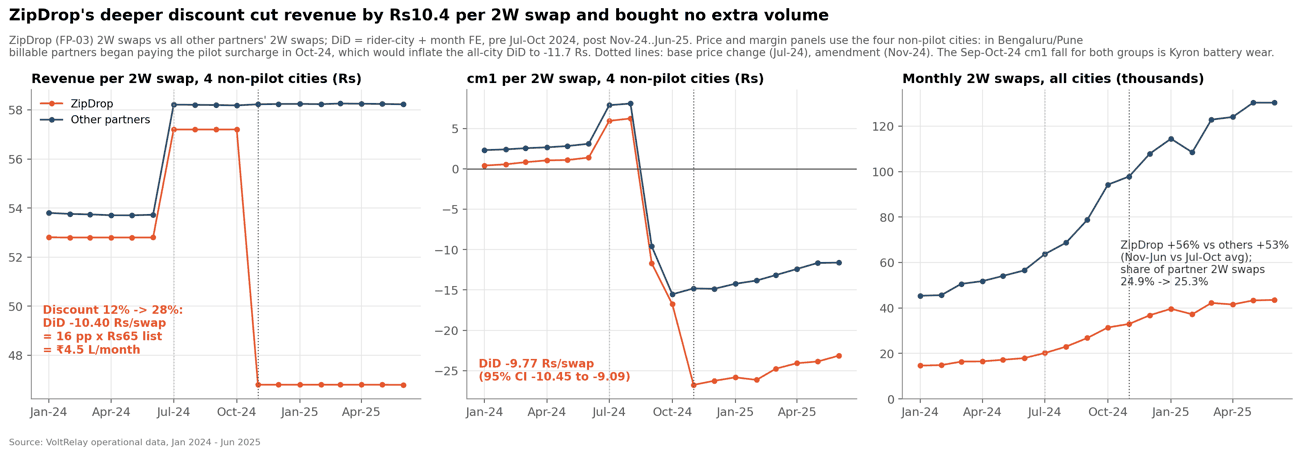

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_06_zipdrop_amendment.png')

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9))
for who, colr in (("ZipDrop", PALETTE["accent"]), ("Other partners", PALETTE["primary"])):
    d = zp_np[zp_np["who"] == who]          # price / margin: four non-pilot cities
    x = pd.to_datetime(d["month"])
    axes[0].plot(x, d["rev_ps"], "o-", ms=4, color=colr, label=who)
    axes[1].plot(x, d["cm1_ps"], "o-", ms=4, color=colr, label=who)
    d = zp[zp["who"] == who]                # volume: all cities
    axes[2].plot(pd.to_datetime(d["month"]), d["swaps"] / 1e3, "o-", ms=4, color=colr, label=f"{who} 2W swaps")
for ax in axes:
    ax.axvline(pd.Timestamp(ZIPDROP_AMEND), color="#555555", lw=1, ls=":")
    ax.axvline(pd.Timestamp(BASE_PRICE_CHANGE), color="#BBBBBB", lw=1, ls=":")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[1].axhline(0, color="#555555", lw=1)
axes[0].set_title("Revenue per 2W swap, 4 non-pilot cities (Rs)", fontsize=11.5)
axes[1].set_title("cm1 per 2W swap, 4 non-pilot cities (Rs)", fontsize=11.5)
axes[2].set_title("Monthly 2W swaps, all cities (thousands)", fontsize=11.5)
axes[0].legend(loc="upper left")
axes[0].annotate(f"Discount 12% -> 28%:\nDiD {ZD_REG['rev_ps']['est']:+.2f} Rs/swap\n= 16 pp x Rs65 list\n= {money(monthly_cost)}/month",
                 xy=(0.03, 0.14), xycoords="axes fraction", va="bottom", fontsize=10, color=PALETTE["accent"], fontweight="bold")
axes[1].annotate(f"DiD {ZD_REG['cm1_ps']['est']:+.2f} Rs/swap\n(95% CI {ZD_REG['cm1_ps']['lo']:+.2f} to {ZD_REG['cm1_ps']['hi']:+.2f})",
                 xy=(0.03, 0.06), xycoords="axes fraction", fontsize=10, color=PALETTE["accent"], fontweight="bold")
axes[2].annotate(f"ZipDrop {100*growth['ZipDrop']:+.0f}% vs others {100*growth['Other partners']:+.0f}%\n(Nov-Jun vs Jul-Oct avg);\nshare of partner 2W swaps\n{100*share_pre:.1f}% -> {100*share_post:.1f}%",
                 xy=(0.56, 0.36), xycoords="axes fraction", va="bottom", fontsize=9.5, color="#333333")
axes[2].set_ylim(bottom=0)
fig.suptitle(f"ZipDrop's deeper discount cut revenue by Rs{-ZD_REG['rev_ps']['est']:.1f} per 2W swap and bought no extra volume",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.06)
fig.text(0.01, 0.94, "ZipDrop (FP-03) 2W swaps vs all other partners' 2W swaps; DiD = rider-city + month FE, pre Jul-Oct 2024, post Nov-24..Jun-25. "
         "Price and margin panels use the four non-pilot cities: in Bengaluru/Pune\nbillable partners began paying the pilot surcharge in Oct-24, "
         f"which would inflate the all-city DiD to {ZD_REG_ALL['rev_ps']['est']:+.1f} Rs. Dotted lines: base price change (Jul-24), amendment (Nov-24). "
         "The Sep-Oct-24 cm1 fall for both groups is Kyron battery wear.", fontsize=9.5, color="#555555", ha="left")
fig.tight_layout()
save_fig(fig, f"{QID}_06_zipdrop_amendment")

## 8. Budget proposals
**(c) Network-wide pricing rollout.** Apply the pilot DiD estimates (Oct-24..Mar-25) to the four control cities'
Jan-Jun 2025 monthly volumes. Revenue effect = DiD revenue/swap x swaps for independents and billable-Y partners
(non-billable partners pay nothing extra); cost per swap does not change with price, so cm1 moves one-for-one,
plus the (statistically null) volume response. Congestion = DiD on peak stockout rate x peak attempts. The surcharge not
collected from non-billable partners is shown **net** of the -Rs8 off-peak credit the same tariff would give them. We also
price the option of dropping the (uncongested) 12-13h window from the surcharge.
**(d) Long-term exclusive with the largest partner** = what ZipDrop's current terms lock in, annualised. A contract signed
now should be judged at **steady state** (non-Kyron energy and wear; all Kyron packs were retired on 2025-06-15); the
Nov-24..Jun-25 run-rate is shown as history. cm2 includes allocated station cost that an exclusive does not avoid, so cm1
is the marginal test. FeastFly (largest partner by revenue and riders) is shown for comparison.

In [137]:
base = (CELLS.filter(pl.col("city").is_in(CONTROL_CITIES) & pl.col("month").is_between(M(2025, 1), M(2025, 6)))
        .join(PINFO.select("pid", "peak_surcharge_billable"), on="pid", how="left")
        .with_columns(pl.when(pl.col("pid") == "IND").then(pl.lit(GRP_ORDER[0]))
                      .when(pl.col("peak_surcharge_billable") == "Y").then(pl.lit(GRP_ORDER[1])).otherwise(pl.lit(GRP_ORDER[2])).alias("grp"))
        .group_by("grp").agg((pl.col("swaps").sum() / 6).alias("swaps_pm"), (pl.col("cm1").sum() / pl.col("swaps").sum()).alias("cm1_ps"),
                             (pl.col("swaps").filter(pl.col("band") == "peak").sum() / 6).alias("peak_swaps_pm"),
                             (pl.col("swaps").filter(pl.col("band") == "offpeak").sum() / 6).alias("off_swaps_pm"))
        .sort("grp").to_pandas().set_index("grp"))
peak_att_pm = SMP[SMP["city"].isin(CONTROL_CITIES) & (SMP["month"] >= M(2025, 1))]["att"].sum() / 6
ROLL = []
for g in GRP_ORDER[:2]:
    r = did_get(g, "rev_per_swap")
    n = base.loc[g, "swaps_pm"]
    ROLL.append(dict(item=f"Revenue/cm1: {g}", swaps_pm=n, did_rs_per_swap=r["est"], lo=r["lo"], hi=r["hi"],
                     monthly_rs=n * r["est"], monthly_lo=n * r["lo"], monthly_hi=n * r["hi"]))
vol = did_get(GRP_ORDER[0], "log_swaps", spec="DDD vs Partner-N riders (+Kyron)")
vol_pct = vol["est"] / 100
ROLL.append(dict(item="Volume response (independents) x cm1/swap", swaps_pm=base.loc[GRP_ORDER[0], "swaps_pm"], did_rs_per_swap=np.nan,
                 lo=np.nan, hi=np.nan, monthly_rs=base.loc[GRP_ORDER[0], "swaps_pm"] * vol_pct * base.loc[GRP_ORDER[0], "cm1_ps"],
                 monthly_lo=base.loc[GRP_ORDER[0], "swaps_pm"] * (vol["lo"] / 100) * base.loc[GRP_ORDER[0], "cm1_ps"],
                 monthly_hi=base.loc[GRP_ORDER[0], "swaps_pm"] * (vol["hi"] / 100) * base.loc[GRP_ORDER[0], "cm1_ps"]))
ROLL[-1]["monthly_lo"], ROLL[-1]["monthly_hi"] = sorted([ROLL[-1]["monthly_lo"], ROLL[-1]["monthly_hi"]])
nb_peak = base.loc[GRP_ORDER[2], "peak_swaps_pm"]
nb_off = base.loc[GRP_ORDER[2], "off_swaps_pm"]
nb_gross = nb_peak * 15.0
nb_net = nb_gross - nb_off * 8.0     # the same tariff gives billable partners the -Rs8 off-peak credit
ROLL.append(dict(item="Not collected: ZipDrop + Swiggle Go peak swaps x Rs15 net of off-peak swaps x Rs8 (if made billable)",
                 swaps_pm=nb_peak, did_rs_per_swap=np.nan, lo=np.nan, hi=np.nan, monthly_rs=nb_net, monthly_lo=np.nan, monthly_hi=np.nan))
ROLL = pd.DataFrame(ROLL)
so_m = DID[(DID["outcome"] == "peak_stockout_rate_pp") & (DID["post_window"] == "Oct24-Mar25") & (DID["spec"] == "station + month FE")].iloc[0]
pk_m = did_get(GRP_ORDER[0], "peak_share")
roll_rev = ROLL.iloc[:2]["monthly_rs"].sum(); roll_lo = ROLL.iloc[:2]["monthly_lo"].sum(); roll_hi = ROLL.iloc[:2]["monthly_hi"].sum()
roll_cm1 = roll_rev + ROLL.iloc[2]["monthly_rs"]
p("\n(c) Network-wide pricing rollout to Delhi NCR, Hyderabad, Mumbai, Jaipur (Jan-Jun 2025 base volumes):")
p(ROLL.round(2).to_string(index=False))
p(f"Projected revenue uplift {money(roll_rev)}/month (CI {money(roll_lo)} to {money(roll_hi)}) = {money(12*roll_rev)}/yr; "
  f"cm1 uplift incl. volume response {money(roll_cm1)}/month")
p(f"Projected peak congestion change: stockout rate {so_m['est']:+.2f} pp (CI {so_m['lo']:+.2f} to {so_m['hi']:+.2f}) x {peak_att_pm:,.0f} peak attempts/month "
  f"= {so_m['est']/100*peak_att_pm:+,.0f} stockouts/month (CI {so_m['lo']/100*peak_att_pm:+,.0f} to {so_m['hi']/100*peak_att_pm:+,.0f}); "
  f"independents' peak share {pk_m['est']:+.1f} pp shifts {abs(pk_m['est'])/100*base.loc[GRP_ORDER[0],'swaps_pm']:,.0f} swaps/month out of peak")
p(f"Not collected from non-billable partners (ZipDrop + Swiggle Go, 4 control cities): {nb_peak:,.0f} peak swaps/month x Rs15 = "
  f"Rs{nb_gross/1e5:.2f} L gross; net of {nb_off:,.0f} off-peak swaps/month x Rs8 credit = Rs{nb_net/1e5:.2f} L/month")

# Cross-check: re-price the control cities' OWN timing mix mechanically (after the pilot's timing shift) instead of
# transferring the pilot cities' Rs/swap.
mix_ctrl = (LF.filter(pl.col("is_completed") & pl.col("city").is_in(CONTROL_CITIES) & pl.col("month").is_between(M(2025, 1), M(2025, 6))
                      & pl.col("grp").is_in(GRP_ORDER[:2]))
            .group_by("grp").agg((pl.len() / 6).alias("swaps_pm"), pl.col("hour").is_in(MID_H).mean().alias("mid_share"),
                                 (pl.col("band") == "peak").mean().alias("peak_share"), (pl.col("band") == "offpeak").mean().alias("off_share"))
            .collect().to_pandas().set_index("grp"))
mech_roll = sum(mix_ctrl.loc[g, "swaps_pm"] * (15 * (mix_ctrl.loc[g, "peak_share"] + did_get(g, "peak_share")["est"] / 100)
                                               - 8 * (mix_ctrl.loc[g, "off_share"] + did_get(g, "off_share")["est"] / 100)) for g in GRP_ORDER[:2])
p(f"Mechanical rollout cross-check (control cities' own timing mix after the pilot's shift): {money(mech_roll)}/month "
  f"({100*(mech_roll/roll_rev - 1):+.1f}% vs the DiD-based {money(roll_rev)})")

# What would dropping the 12-13h window from the surcharge give up? (12-13h is the least congested PEAK window)
mid_i = did_get(GRP_ORDER[0], "mid_share")
mid_post_ind = (mid_i["pre_treated_mean"] + mid_i["est"]) / 100
drop_mid_ps = 15 * mid_post_ind
drop_mid_pm = sum(mix_ctrl.loc[g, "swaps_pm"] * 15 * (mix_ctrl.loc[g, "mid_share"] + did_get(g, "mid_share")["est"] / 100) for g in GRP_ORDER[:2])
p(f"Dropping 12-13h from the surcharge: pilot-city independents' 12-13h share after the pilot = {100*mid_post_ind:.1f}% "
  f"(pre {mid_i['pre_treated_mean']:.1f}% {mid_i['est']:+.2f} pp) x Rs15 = Rs{drop_mid_ps:.2f} of the Rs{rv['est']:.2f}/swap; "
  f"in the rollout it gives up {money(drop_mid_pm)}/month of the {money(roll_rev)}/month "
  f"(control-city 12-13h shares IND {100*mix_ctrl.loc[GRP_ORDER[0], 'mid_share']:.1f}%, billable partners {100*mix_ctrl.loc[GRP_ORDER[1], 'mid_share']:.1f}%, "
  f"less the pilot's 12-13h shift)")
so_eve = DID[(DID["outcome"] == "peak_stockout_rate_pp") & (DID["spec"] == "evening 19-22h only")].iloc[0]
p(f"Pilot DiD on evening-only (19-22h) stockouts: {so_eve['est']:+.2f} pp (95% CI {so_eve['lo']:+.2f} to {so_eve['hi']:+.2f}); "
  f"base {so_eve['pre_treated_mean']:.2f}%")

z = PT_CUR.filter(pl.col("pid") == ZIPDROP_ID).to_dicts()[0]
others = PT_CUR.filter((pl.col("pid") != "IND") & (pl.col("pid") != ZIPDROP_ID))
oth_2w = (CELLS.filter((pl.col("pid") != "IND") & (pl.col("pid") != ZIPDROP_ID) & (pl.col("vehicle_class") == "2W") & pl.col("month").is_between(*CUR)))
zd2w = CELLS.filter((pl.col("pid") == ZIPDROP_ID) & (pl.col("vehicle_class") == "2W") & pl.col("month").is_between(*CUR))
steady_cost_2w = ((zd2w["energy_nonky"].sum() + zd2w["wear_nonky"].sum()) / (zd2w["swaps"].sum() - zd2w["ky_swaps"].sum()))
fixed_2w = zd2w["fixed"].sum() / zd2w["swaps"].sum()
list_2w = zd2w["list_rev"].sum() / zd2w["swaps"].sum()
be_cm1 = 1 - steady_cost_2w / list_2w
be_cm2 = 1 - (steady_cost_2w + fixed_2w) / (list_2w * (1 - COC * 45 / 365))
annual = 12 / z["n_months"]
ff = PT_CUR.filter(pl.col("partner_name") == "FeastFly").to_dicts()[0]   # largest partner by revenue and riders
EXCL = pd.DataFrame([
    dict(metric="ZipDrop swaps per year (current run-rate)", value=z["swaps"] * annual),
    dict(metric="share of network swaps", value=z["share_network_swaps"]),
    dict(metric="revenue per year (Rs)", value=z["revenue"] * annual),
    dict(metric="realised discount", value=z["discount_pct_realised"]),
    dict(metric="STEADY STATE (non-Kyron energy + wear; all Kyron packs retired 2025-06-15): cm1 per swap (Rs)", value=z["cm1_ps_steady"]),
    dict(metric="steady-state cm1 per year (Rs)", value=z["cm1_ps_steady"] * z["swaps"] * annual),
    dict(metric="steady-state cm2 after WC per swap (Rs; cm2 includes allocated station cost an exclusive does not avoid)", value=z["cm2wc_ps_steady"]),
    dict(metric="steady-state cm2 after WC per year (Rs)", value=z["cm2wc_ps_steady"] * z["swaps"] * annual),
    dict(metric="HISTORICAL Nov-24..Jun-25 run-rate (incl. wear on retired Kyron packs): cm1 per swap (Rs)", value=z["cm1_ps"]),
    dict(metric="historical cm2 after working capital per swap (Rs)", value=z["cm2_after_wc_ps"]),
    dict(metric="historical cm1 per year (Rs)", value=z["cm1"] * annual),
    dict(metric="historical cm2 after working capital per year (Rs)", value=z["cm2_after_wc"] * annual),
    dict(metric="working-capital cost per year (45-day terms, Rs)", value=z["wc_cost"] * annual),
    dict(metric="peak-hour share of swaps", value=z["peak_share"]),
    dict(metric="amendment revenue given up per year (16 pp of list, Rs)", value=monthly_cost * 12),
    dict(metric="break-even discount for steady-state cm1 = 0 (2W)", value=be_cm1),
    dict(metric="break-even discount for steady-state cm2 after WC = 0 (2W)", value=be_cm2),
    dict(metric="other partners' cm1 per swap (avg, Rs)", value=others["cm1"].sum() / others["swaps"].sum()),
    dict(metric="other partners' steady-state cm1 per swap (avg, Rs)",
         value=(others["revenue"].sum() - (others["energy_nonky"].sum() + others["wear_nonky"].sum()) / (others["swaps"].sum() - others["ky_swaps"].sum()) * others["swaps"].sum()) / others["swaps"].sum()),
    dict(metric="FeastFly (largest by revenue and riders) share of network swaps", value=ff["share_network_swaps"]),
    dict(metric="FeastFly revenue per year (Rs)", value=ff["revenue"] * annual),
    dict(metric="FeastFly steady-state cm1 per swap (Rs)", value=ff["cm1_ps_steady"]),
    dict(metric="FeastFly steady-state cm1 per year (Rs)", value=ff["cm1_ps_steady"] * ff["swaps"] * annual),
    dict(metric="FeastFly steady-state cm2 after WC per swap (Rs)", value=ff["cm2wc_ps_steady"]),
    dict(metric="FeastFly historical cm1 per swap, Nov-24..Jun-25 (Rs)", value=ff["cm1_ps"]),
])
EXCL.to_csv(TAB / f"{QID}_budget_exclusive_zipdrop.csv", index=False)
ROLL.to_csv(TAB / f"{QID}_budget_pricing_rollout.csv", index=False)
p("\n(d) Long-term exclusive with the largest partner (ZipDrop) - what current terms lock in:")
p(EXCL.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
zd_peak_hours_share = (CELLS.filter(pl.col("month").is_between(*CUR) & (pl.col("band") == "peak"))
                       .select((pl.col("swaps").filter(pl.col("pid") == ZIPDROP_ID).sum() / pl.col("swaps").sum())).item())
p(f"ZipDrop share of all PEAK-hour swaps (current terms) = {100*zd_peak_hours_share:.1f}%")
zd_ss_yr = z["cm1_ps_steady"] * z["swaps"] * annual
zd_ss2_yr = z["cm2wc_ps_steady"] * z["swaps"] * annual
p(f"(d) ZipDrop exclusive, STEADY STATE: cm1 Rs{z['cm1_ps_steady']:.2f}/swap = {money(zd_ss_yr)}/yr; cm2 after WC Rs{z['cm2wc_ps_steady']:.2f}/swap = "
  f"{money(zd_ss2_yr)}/yr. HISTORICAL Nov-24..Jun-25 run-rate (incl. Kyron wear): cm1 {money(z['cm1'] * annual)}/yr, cm2 after WC "
  f"{money(z['cm2_after_wc'] * annual)}/yr (historical cm1 is {z['cm1'] * annual / zd_ss_yr:.1f}x the steady-state loss)")
p(f"FeastFly (largest by revenue and riders): steady-state cm1 Rs{ff['cm1_ps_steady']:+.2f}/swap = {money(ff['cm1_ps_steady'] * ff['swaps'] * annual)}/yr; "
  f"steady-state cm2 after WC Rs{ff['cm2wc_ps_steady']:+.2f}/swap; historical cm1 Rs{ff['cm1_ps']:+.2f}/swap; "
  f"{ff['payment_terms_days']}-day terms, {100*ff['discount_pct_realised']:.0f}% discount, peak surcharge billable = {ff['peak_surcharge_billable']}")


(c) Network-wide pricing rollout to Delhi NCR, Hyderabad, Mumbai, Jaipur (Jan-Jun 2025 base volumes):


                                                                                                item   swaps_pm  did_rs_per_swap    lo    hi  monthly_rs  monthly_lo  monthly_hi
                                                                            Revenue/cm1: Independent 63,745.330            7.900 7.840 7.950 503,388.610 499,879.430 506,897.790
                                                         Revenue/cm1: Partner Y (surcharge billable) 81,850.830            5.430 5.150 5.710 444,631.460 421,859.610 467,403.300
                                                           Volume response (independents) x cm1/swap 63,745.330              NaN   NaN   NaN -20,414.180 -45,624.390   4,796.030
Not collected: ZipDrop + Swiggle Go peak swaps x Rs15 net of off-peak swaps x Rs8 (if made billable) 29,898.000              NaN   NaN   NaN 413,272.670         NaN         NaN


Projected revenue uplift ₹9.5 L/month (CI ₹9.2 L to ₹9.7 L) = ₹1.14 Cr/yr; cm1 uplift incl. volume response ₹9.3 L/month


Projected peak congestion change: stockout rate +0.05 pp (CI -0.09 to +0.18) x 116,384 peak attempts/month = +57 stockouts/month (CI -100 to +214); independents' peak share -2.5 pp shifts 1,586 swaps/month out of peak


Not collected from non-billable partners (ZipDrop + Swiggle Go, 4 control cities): 29,898 peak swaps/month x Rs15 = Rs4.48 L gross; net of 4,400 off-peak swaps/month x Rs8 credit = Rs4.13 L/month


Mechanical rollout cross-check (control cities' own timing mix after the pilot's shift): ₹9.2 L/month (-3.3% vs the DiD-based ₹9.5 L)


... (3 outputs left out)

                                                                                                  metric           value
                                                               ZipDrop swaps per year (current run-rate)     504,633.000
                                                                                  share of network swaps           0.155
                                                                                   revenue per year (Rs)  24,546,639.149
                                                                                       realised discount           0.280
           STEADY STATE (non-Kyron energy + wear; all Kyron packs retired 2025-06-15): cm1 per swap (Rs)          -4.181
                                                                          steady-state cm1 per year (Rs)  -2,109,890.286
steady-state cm2 after WC per swap (Rs; cm2 includes allocated station cost an exclusive does not avoid)         -16.001
                                

ZipDrop share of all PEAK-hour swaps (current terms) = 19.7%


(d) ZipDrop exclusive, STEADY STATE: cm1 Rs-4.18/swap = ₹-21.1 L/yr; cm2 after WC Rs-16.00/swap = ₹-80.7 L/yr. HISTORICAL Nov-24..Jun-25 run-rate (incl. Kyron wear): cm1 ₹-1.04 Cr/yr, cm2 after WC ₹-1.64 Cr/yr (historical cm1 is 4.9x the steady-state loss)


FeastFly (largest by revenue and riders): steady-state cm1 Rs+12.22/swap = ₹57.5 L/yr; steady-state cm2 after WC Rs+0.03/swap; historical cm1 Rs-4.40/swap; 30-day terms, 10% discount, peak surcharge billable = Y


### Figure: the two pricing-related budget proposals side by side

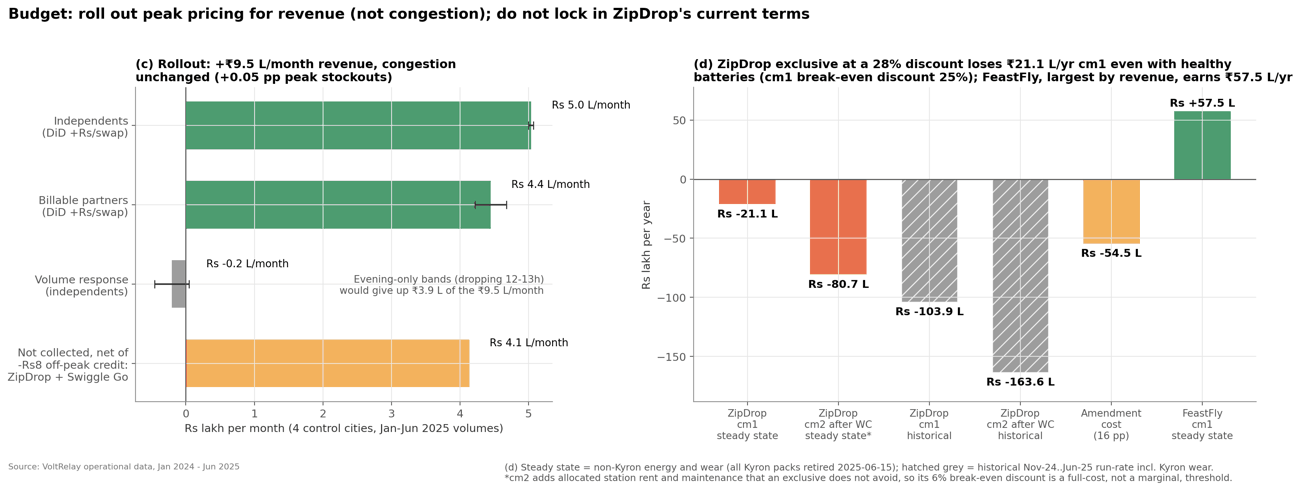

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q5_07_budget_pricing_partner.png')

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw=dict(width_ratios=[1, 1.35]))
items = ["Independents\n(DiD +Rs/swap)", "Billable partners\n(DiD +Rs/swap)", "Volume response\n(independents)",
         "Not collected, net of\n-Rs8 off-peak credit:\nZipDrop + Swiggle Go"]
vals = ROLL["monthly_rs"].values / 1e5
lo = ROLL["monthly_lo"].values / 1e5; hi = ROLL["monthly_hi"].values / 1e5
cols = [PALETTE["good"], PALETTE["good"], PALETTE["muted"], PALETTE["warn"]]
yy = np.arange(len(items))[::-1]
axes[0].barh(yy, vals, color=cols, alpha=0.85, height=0.6)
for i in range(3):
    if not np.isnan(lo[i]) and lo[i] <= vals[i] <= hi[i]:
        axes[0].errorbar(vals[i], yy[i], xerr=[[vals[i] - lo[i]], [hi[i] - vals[i]]], color="#333333", capsize=4)
for i, v in enumerate(vals):
    axes[0].text(max(v, 0) + 0.3, yy[i] + 0.22, f"Rs {v:.1f} L/month", fontsize=10)
axes[0].axvline(0, color="#555555", lw=1)
axes[0].set_yticks(yy); axes[0].set_yticklabels(items)
axes[0].set_xlabel("Rs lakh per month (4 control cities, Jan-Jun 2025 volumes)")
axes[0].set_title(f"(c) Rollout: +{money(roll_rev)}/month revenue, congestion\nunchanged ({so_m['est']:+.2f} pp peak stockouts)", fontsize=11.5)
axes[0].text(0.98, 0.37, f"Evening-only bands (dropping 12-13h)\nwould give up {money(drop_mid_pm)} of the {money(roll_rev)}/month",
             transform=axes[0].transAxes, ha="right", va="center", fontsize=9.5, color="#555555")
ff_ss_yr = ff["cm1_ps_steady"] * ff["swaps"] * annual
ex_items = ["ZipDrop\ncm1\nsteady state", "ZipDrop\ncm2 after WC\nsteady state*", "ZipDrop\ncm1\nhistorical",
            "ZipDrop\ncm2 after WC\nhistorical", "Amendment\ncost\n(16 pp)", "FeastFly\ncm1\nsteady state"]
ex_vals = np.array([zd_ss_yr, zd_ss2_yr, z["cm1"] * annual, z["cm2_after_wc"] * annual, -monthly_cost * 12, ff_ss_yr]) / 1e5
ex_cols = [PALETTE["accent"], PALETTE["accent"], PALETTE["muted"], PALETTE["muted"], PALETTE["warn"], PALETTE["good"]]
bars = axes[1].bar(np.arange(len(ex_vals)), ex_vals, color=ex_cols, alpha=0.85, width=0.62)
for b_ in (bars[2], bars[3]):
    b_.set_hatch("//"); b_.set_edgecolor("white")
for i, v in enumerate(ex_vals):
    axes[1].text(i, v - 4 if v < 0 else v + 2, f"Rs {v:+.1f} L", ha="center", va="top" if v < 0 else "bottom", fontsize=10.5, fontweight="bold")
axes[1].axhline(0, color="#555555", lw=1)
axes[1].set_ylim(min(ex_vals.min() * 1.15, -10), max(ex_vals.max() * 1.35, 10))
axes[1].set_xticks(np.arange(len(ex_vals))); axes[1].set_xticklabels(ex_items, fontsize=9.5)
axes[1].set_ylabel("Rs lakh per year")
axes[1].set_title(f"(d) ZipDrop exclusive at a {100*z['discount_pct_realised']:.0f}% discount loses {money(-zd_ss_yr)}/yr cm1 even with healthy\n"
                  f"batteries (cm1 break-even discount {100*be_cm1:.0f}%); FeastFly, largest by revenue, earns {money(ff_ss_yr)}/yr", fontsize=11.5)
fig.text(0.40, -0.02, "(d) Steady state = non-Kyron energy and wear (all Kyron packs retired 2025-06-15); hatched grey = historical Nov-24..Jun-25 run-rate incl. Kyron wear.\n"
         f"*cm2 adds allocated station rent and maintenance that an exclusive does not avoid, so its {100*be_cm2:.0f}% break-even discount is a full-cost, not a marginal, threshold.",
         fontsize=9, color="#555555", ha="left", va="top")
fig.suptitle("Budget: roll out peak pricing for revenue (not congestion); do not lock in ZipDrop's current terms",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
fig.tight_layout()
save_fig(fig, f"{QID}_07_budget_pricing_partner")

## 9. Key numbers for the findings file

In [139]:
p("\n===== KEY NUMBERS =====")
for out in ("peak_share", "off_share", "rev_per_swap", "swaps_per_rider", "log_swaps", "cm1_per_swap"):
    for spec_ in ("rider-city + month FE", "+ Kyron-share control", "Mumbai-only control", "long pre (Jan-Sep 2024)", "DDD vs Partner-N riders (+Kyron)"):
        rr = DID[(DID["segment"] == GRP_ORDER[0]) & (DID["outcome"] == out) & (DID["spec"] == spec_)]
        for _, r in rr.iterrows():
            extra = f"; city-permutation p={r['perm_p_city']:.3f}" if pd.notna(r.get("perm_p_city", np.nan)) else ""
            p(f"IND {out:16s} [{r['post_window']}, {spec_}]: {r['est']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f}; p={r['p']:.4f}{extra}); "
              f"pre treated mean {r['pre_treated_mean']:.3f}")
for _, r in DID[DID["segment"].str.startswith("All riders")].iterrows():
    perm_txt = f"; perm p={r['perm_p_city']:.3f}" if pd.notna(r.get("perm_p_city", np.nan)) else ""
    p(f"Congestion {r['outcome']:24s} [{r['post_window']}, {r['spec']}]: {r['est']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f}; "
      f"p={r['p']:.3f}{perm_txt}); pre {r['pre_treated_mean']:.3f}")
for g in GRP_ORDER[:2]:
    p(f"{g} timing-shift decomposition (pp, Oct-24..Mar-25): " + ", ".join(
        f"{o} {did_get(g, o)['est']:+.2f} (CI {did_get(g, o)['lo']:+.2f} to {did_get(g, o)['hi']:+.2f}; base {did_get(g, o)['pre_treated_mean']:.1f}%)" for o in SUB_OUTS))
fade = ES[(ES["outcome"] == "peak_share") & ES["month"].isin([M(2025, 5), M(2025, 6)])]["est"]
p(f"Independents' peak-share gap fades to {fade.iloc[0]:+.2f} / {fade.iloc[1]:+.2f} pp in May/Jun-25 (Oct-Mar mean "
  f"{ES[(ES['outcome'] == 'peak_share') & ES['month'].isin(POST_MAIN)]['est'].mean():+.2f} pp)")
for s_ in segs[1:]:
    for out in ("peak_share", "off_share", "rev_per_swap", "log_swaps"):
        r = did_get(s_, out)
        p(f"{s_:32s} {out:16s}: {r['est']:+.3f} (95% CI {r['lo']:+.3f} to {r['hi']:+.3f}); pre treated mean {r['pre_treated_mean']:.3f}")
rel_shift = -pk_m["est"] / pk_m["pre_treated_mean"]
p(f"Relative reduction of independents' peak-hour swaps share: {100*rel_shift:.1f}%")
cm_naive = did_get(GRP_ORDER[0], "cm1_per_swap"); cm_ky = did_get(GRP_ORDER[0], "cm1_per_swap", spec="+ Kyron-share control")
p(f"Naive cm1 DiD / Kyron-adjusted cm1 DiD = {cm_naive['est']:.2f} / {cm_ky['est']:.2f} = {cm_naive['est']/cm_ky['est']:.1f}x")
p(f"Attempts analysed for congestion bands: {band_kpi['attempts'].sum():,}")
rv_y = did_get(GRP_ORDER[1], "rev_per_swap")
p(f"Pilot revenue uplift: independents {100*rv['est']/rv['pre_treated_mean']:.1f}% of pre Rs{rv['pre_treated_mean']:.2f}/swap; "
  f"billable partners {100*rv_y['est']/rv_y['pre_treated_mean']:.1f}% of pre Rs{rv_y['pre_treated_mean']:.2f}/swap")
p(f"Mechanical check: Rs15 x {pk_m['pre_treated_mean'] + pk_m['est']:.1f}% peak - Rs8 x {did_get(GRP_ORDER[0], 'off_share')['pre_treated_mean'] + did_get(GRP_ORDER[0], 'off_share')['est']:.1f}% off-peak = "
  f"Rs{0.15*(pk_m['pre_treated_mean'] + pk_m['est']) - 0.08*(did_get(GRP_ORDER[0], 'off_share')['pre_treated_mean'] + did_get(GRP_ORDER[0], 'off_share')['est']):.2f}/swap; "
  f"at pre-pilot timing it would be Rs{0.15*pk_m['pre_treated_mean'] - 0.08*did_get(GRP_ORDER[0], 'off_share')['pre_treated_mean']:.2f}/swap")
p("done.")


===== KEY NUMBERS =====


IND peak_share       [Oct24-Mar25, rider-city + month FE]: -2.488 (95% CI -3.113 to -1.862; p=0.0000; city-permutation p=0.067); pre treated mean 61.900


IND peak_share       [Oct24-Jun25, rider-city + month FE]: -2.325 (95% CI -2.917 to -1.733; p=0.0000; city-permutation p=0.067); pre treated mean 61.900


IND peak_share       [Oct24-Mar25, Mumbai-only control]: -1.980 (95% CI -2.940 to -1.020; p=0.0001); pre treated mean 61.900


IND peak_share       [Oct24-Mar25, long pre (Jan-Sep 2024)]: -2.690 (95% CI -3.211 to -2.170; p=0.0000); pre treated mean 61.900


IND peak_share       [Oct24-Mar25, DDD vs Partner-N riders (+Kyron)]: -2.118 (95% CI -3.077 to -1.159; p=0.0000); pre treated mean 61.900


... (70 outputs left out)

Attempts analysed for congestion bands: 3,814,982


Pilot revenue uplift: independents 11.7% of pre Rs67.45/swap; billable partners 8.4% of pre Rs65.02/swap


Mechanical check: Rs15 x 59.4% peak - Rs8 x 12.4% off-peak = Rs7.92/swap; at pre-pilot timing it would be Rs8.49/swap


done.


In [140]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 150 objects


## 10. Q6 · Root-cause analysis of new-rider retention

# Q6 - Root cause of new-rider retention
**Question.** Which factors are most strongly associated with new riders not returning? Which drivers are
**primary** and which are **secondary**?

**Design (set before looking at results).**
* **New rider** = signed up on or after 2024-01-01 and made at least 1 attempt. Day 0 = first attempt.
* **Primary outcome**: *not retained* = **no completed swap in days 31-60** after the first attempt. We use it
  because riders swap almost daily (median gap 1 day, 99th pct 4 days), so a month with no swap is a clear
  sign the rider has left. The window also starts after the 14-day feature window. Only riders with at least
  60 days of follow-up count (first attempt before 2025-05-01). That avoids the censoring trap where recent
  signups look "lost" only because we have not watched them long enough.
* **Robustness checks**: activity in days 15-28 (R14), activity in days 91-120 (R90), and survival analysis,
  where churn = the last active day before 30 or more days without a swap. Each rider's follow-up stops
  30 days before the data ends (administrative censoring), so a churn event is never counted before it can
  be observed.
* **Early experience** is measured only in days 0-13, so it always comes before the outcome window.

Per-rider aggregates are built in polars from projected lazy scans, so the full event table is never loaded.

**Revised after independent verification** (`outputs/findings/q6_verification.md`): km per swap and log
attempts are centred within vehicle class (fixes an inflated 3W effect), the hero counterfactual now removes the
modelled failure effect from *observed* retention, the "tolerated first failure" reading is tested against
exposure (Simpson's paradox), the season-mixed comparison is replaced by a season-matched one, and the share of
the summer dip explained by early failures is bracketed by four methods.

In [141]:
import sys
import datetime as dt
import warnings
from pathlib import Path

ROOT = PROJECT_ROOT if "PROJECT_ROOT" in globals() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import polars as pl  # noqa: E402
import statsmodels.api as sm  # noqa: E402
import statsmodels.formula.api as smf  # noqa: E402
from scipy import stats  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import matplotlib.dates as mdates  # noqa: E402

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_rows(40)
RNG = np.random.default_rng(59500)

DATA_END = dt.datetime(2025, 7, 1)          # exclusive end of the event log (last day 2025-06-30)
EARLY_DAYS = 14                             # early-experience window: days 0-13 after first attempt
OUT_LO, OUT_HI = 30, 60                     # outcome window: day index 30..59 (= days 31-60)
ELIG_CUTOFF = dt.datetime(2025, 5, 1)       # first attempt before this -> >= 60 days follow-up
CHURN_GAP = 30                              # survival: churn = last active day before >= 30 idle days


def wilson(k, n, z=1.96):
    k = np.asarray(k, float)
    n = np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def title_sub(ax, title, sub=None):
    """Insight title plus a grey method/subtitle line that never collides with the title."""
    ax.set_title(title, pad=(26 + 13 * sub.count("\n")) if sub else 8)
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, fontsize=9.5, color="#555555", va="bottom", ha="left")


def no_minor_labels(ax):
    ax.xaxis.set_minor_formatter(plt.NullFormatter())

## 1. Build the new-rider base, outcomes and survival times

In [142]:
rid = riders()
base = rid.filter(pl.col("signup_date") >= dt.date(2024, 1, 1))
n_signups = base.height
t0 = (events(["rider_id", "event_ts"]).group_by("rider_id").agg(t0=pl.col("event_ts").min())
      .collect(engine="streaming"))
base = base.join(t0, on="rider_id", how="inner")
B = base.select("rider_id", "t0").lazy()
EV_COLS = ["rider_id", "event_ts", "date", "hour", "station_id", "event_type", "is_completed", "is_stockout",
           "is_abandoned", "is_system_error", "is_cancelled", "is_service_failure", "queue_wait_sec",
           "supplier_out", "soh_out_pct", "km_since_last_swap", "tariff_code", "amount_charged_inr",
           "competitor_active", "city"]
E = events(EV_COLS).join(B, on="rider_id", how="inner").with_columns(
    d=(pl.col("event_ts") - pl.col("t0")).dt.total_seconds() / 86400.0)
early = E.filter(pl.col("d") < EARLY_DAYS).collect(engine="streaming")
act = (E.filter(pl.col("is_completed")).select("rider_id", day=pl.col("d").floor().cast(pl.Int32))
       .unique().collect(engine="streaming").sort(["rider_id", "day"]))

end_day = base.select("rider_id", end_day=(pl.lit(DATA_END) - pl.col("t0")).dt.total_seconds() / 86400.0)
outc = act.group_by("rider_id").agg(
    r17=pl.col("day").is_between(1, 7).any(),
    r14=pl.col("day").is_between(14, 27).any(),
    r3060=pl.col("day").is_between(OUT_LO, OUT_HI - 1).any(),
    r90=pl.col("day").is_between(90, 119).any(),
    any_after30=(pl.col("day") >= 30).any(),
    n_active_days=pl.len())
# survival: first active day followed by >= 30 idle days (gap to next active day, or to data end)
a = act.join(end_day, on="rider_id").with_columns(nxt=pl.col("day").shift(-1).over("rider_id"))
a = a.with_columns(gap=pl.when(pl.col("nxt").is_null()).then(pl.col("end_day") - pl.col("day"))
                   .otherwise(pl.col("nxt") - pl.col("day")))
churn = (a.filter((pl.col("gap") >= CHURN_GAP) & (pl.col("day") <= pl.col("end_day") - CHURN_GAP))
         .group_by("rider_id").agg(churn_day=pl.col("day").min(),
                                   came_back=pl.col("nxt").sort_by("day").first().is_not_null()))
base = (base.join(outc, on="rider_id", how="left").join(churn, on="rider_id", how="left")
        .join(end_day, on="rider_id", how="left")
        .with_columns(pl.col("r17", "r14", "r3060", "r90", "any_after30").fill_null(False),
                      coh=pl.col("t0").dt.truncate("1mo").dt.date())
        .with_columns(surv_E=pl.col("churn_day").is_not_null(),
                      surv_T=pl.coalesce(pl.col("churn_day").cast(pl.Float64), pl.col("end_day") - CHURN_GAP)))
n_with_attempt = base.height
n_elig = base.filter(pl.col("t0") < ELIG_CUTOFF).height
print(f"New riders (signup >= 2024-01-01): {n_signups:,}; with >= 1 attempt: {n_with_attempt:,}; "
      f"with >= 60 days follow-up (first attempt < 2025-05-01): {n_elig:,}")
gaps = a.filter(pl.col("nxt").is_not_null()).select((pl.col("nxt") - pl.col("day")).alias("g"))["g"]
print(f"Gap between consecutive active days: median {gaps.median():.0f} d, p99 {gaps.quantile(0.99):.0f} d")
n_churn_ev = int(base["surv_E"].sum())
n_came_back = int(base["came_back"].fill_null(False).sum())
print(f"Survival: {n_churn_ev:,} riders had a 30-day churn event; {n_came_back:,} "
      f"({pct(n_came_back / n_churn_ev)}) of them came back later (win-back exists, so churn is not always final)")

New riders (signup >= 2024-01-01): 16,400; with >= 1 attempt: 16,341; with >= 60 days follow-up (first attempt < 2025-05-01): 13,797
Gap between consecutive active days: median 1 d, p99 4 d
Survival: 7,437 riders had a 30-day churn event; 2,169 (29.2%) of them came back later (win-back exists, so churn is not always final)


## 2. Early-experience features (days 0-13 only)
Includes service failures by type, queue waits, the pack received (supplier, SoH, km range), price paid and
peak-tariff exposure, competitor presence, support tickets, main-station attributes and rider profile.

In [143]:
QLONG = 600  # a "long wait" = more than 10 minutes in the queue
feat = early.group_by("rider_id").agg(
    e_att=pl.len(), e_comp=pl.col("is_completed").sum(), e_days=pl.col("date").n_unique(),
    e_fail=pl.col("is_service_failure").sum(), e_stockout=pl.col("is_stockout").sum(),
    e_abandon=pl.col("is_abandoned").sum(), e_syserr=pl.col("is_system_error").sum(),
    e_cancel=pl.col("is_cancelled").sum(),
    first_fail=pl.col("is_service_failure").sort_by("event_ts").first(),
    q_mean=pl.col("queue_wait_sec").filter(pl.col("is_completed")).mean() / 60.0,
    q_long_n=(pl.col("queue_wait_sec") > QLONG).sum(),
    kyron_share=(pl.col("supplier_out") == "Kyron").filter(pl.col("is_completed")).mean(),
    soh_out=pl.col("soh_out_pct").filter(pl.col("is_completed")).mean(),
    km_mean=pl.col("km_since_last_swap").mean(),
    price_mean=pl.col("amount_charged_inr").filter(pl.col("is_completed")).mean(),
    peak_share=(pl.col("tariff_code") == "PEAK").filter(pl.col("is_completed")).mean(),
    comp_share=pl.col("competitor_active").cast(pl.Float64).mean(),
    main_station=pl.col("station_id").mode().sort().first(),
    n_stations=pl.col("station_id").n_unique(),
    eve_share=pl.col("hour").is_between(17, 21).mean(),
)
# tickets raised in the first 14 days
tk = tickets().filter(~pl.col("is_test")).join(base.select("rider_id", "t0"), on="rider_id", how="inner")
tk = tk.filter((pl.col("created_ts") >= pl.col("t0")) &
               (pl.col("created_ts") < pl.col("t0") + pl.duration(days=EARLY_DAYS)))
tkf = tk.group_by("rider_id").agg(tk_n=pl.len(), tk_unres=(pl.col("resolution_status") == "unresolved").sum(),
                                  tk_battery=pl.col("category").is_in(["no_battery_available", "low_range"]).sum())
st = stations().select("station_id", main_wave="expansion_wave", main_gen="charger_generation",
                       main_city="city", main_conn="connectivity_tier", main_loc="location_type",
                       comp_since="competitor_within_1_5km_since")
df = (base.join(feat, on="rider_id", how="left").join(tkf, on="rider_id", how="left")
      .join(st, left_on="main_station", right_on="station_id", how="left")
      .with_columns(pl.col("tk_n", "tk_unres", "tk_battery").fill_null(0)))
df = df.to_pandas().sort_values("rider_id").reset_index(drop=True)   # deterministic row order
df["y"] = (~df["r3060"]).astype(int)                       # 1 = NOT retained (primary outcome)
df["elig"] = df["t0"] < ELIG_CUTOFF
df["coh"] = pd.to_datetime(df["coh"])
df["coh_s"] = df["coh"].dt.strftime("%Y-%m")
df["coh_q"] = df["coh"].dt.to_period("Q").astype(str)
df["coh_idx"] = (df["coh"].dt.year - 2024) * 12 + df["coh"].dt.month - 1
df["fail_grp"] = pd.cut(df["e_fail"].fillna(0), [-1, 0, 1, 2, 999], labels=["0", "1", "2", "3+"]).astype(str)
df["fail2p"] = (df["e_fail"] >= 2).astype(int)
# stockouts + abandoned queues only (the failure types that drive exits; excludes kiosk errors)
df["sa2p"] = ((df["e_stockout"] + df["e_abandon"]) >= 2).astype(int)
# exposure-free dose: share of early attempts that failed
df["fail_rate"] = df["e_fail"] / df["e_att"]
df["frate_bin"] = pd.cut(df["fail_rate"], [-0.01, 0, 0.05, 0.10, 0.20, 1.01],
                         labels=["0", "0-5%", "5-10%", "10-20%", ">20%"]).astype(str)
df["first_fail"] = df["first_fail"].fillna(False).astype(int)
df["comp_any"] = (df["comp_share"].fillna(0) > 0).astype(int)
df["tk_any"] = (df["tk_n"] > 0).astype(int)
df["tk_unres_any"] = (df["tk_unres"] > 0).astype(int)
df["kyron_share"] = df["kyron_share"].fillna(0)
df["peak_share"] = df["peak_share"].fillna(0)
n_km_missing = int(df["km_mean"].isna().sum())
df["km_mean"] = df["km_mean"].fillna(df["km_mean"].median())
df["q_mean"] = df["q_mean"].fillna(df["q_mean"].median())
df["soh_out"] = df["soh_out"].fillna(df["soh_out"].median())
df["price_mean"] = df["price_mean"].fillna(df["price_mean"].median())
df["q_long_any"] = (df["q_long_n"] > 0).astype(int)
df["w3"] = (df["vehicle_class"] == "3W").astype(int)
# km per swap mostly reflects pack size (3W packs are 4.8 kWh vs 2.1 kWh for 2W), so raw km would make 3W riders
# look like "high-range" riders and the 3W dummy would then be read at a 2W-typical km. Centring km within vehicle
# class is an exact reparameterisation whenever w3 is in the model: every other coefficient is unchanged and the
# 3W term becomes the total 3W effect at the class-typical km per swap. Same for log early attempts (3W riders
# swap less often because their packs are bigger).
km_cls = df.groupby("vehicle_class")["km_mean"].transform("mean")
df["km10c"] = (df["km_mean"] - km_cls) / 10
df["log_att"] = np.log(df["e_att"])
df["log_att_c"] = df["log_att"] - df.groupby("vehicle_class")["log_att"].transform("mean")
df["segment"] = np.where(df["partner_id"].isna(), np.where(df["plan_type"] == "prepaid_pack", "Indep-prepaid", "Indep-PAYG"),
                         np.where(df["partner_id"] == ZIPDROP_ID, "ZipDrop", "Other partner"))
df["indep"] = df["partner_id"].isna().astype(int)
df["partner"] = df["partner_id"].fillna("Independent")
df["age_band"] = df["age_band"].fillna("unknown")
df["declared_shift"] = df["declared_shift"].fillna("unknown")
df["kyc_no"] = (~df["kyc_verified"].astype(bool)).astype(int)
df["pilot_city"] = df["main_city"].isin(PILOT_CITIES).astype(int)
for c in ["main_wave", "main_gen", "main_conn", "main_loc", "main_city"]:
    df[c] = df[c].fillna("unknown")
D = df[df["elig"]].copy()
overall_nr = D["y"].mean()
print(f"\nEligible riders: {len(D):,}; NOT retained (no swap in days 31-60): {int(D['y'].sum()):,} "
      f"= {pct(overall_nr)}; retained {pct(1 - overall_nr)}")
print(f"Early window (days 0-13): median {D['e_att'].median():.0f} attempts, mean service failures/rider "
      f"{D['e_fail'].mean():.2f}; riders with >=2 failures: {int(D['fail2p'].sum()):,} ({pct(D['fail2p'].mean())})")
print(f"Mean km per swap in first 14 days: 2W {D.loc[D['w3'] == 0, 'km_mean'].mean():.1f} km vs 3W "
      f"{D.loc[D['w3'] == 1, 'km_mean'].mean():.1f} km (pack size); riders with no valid km reading (median-filled): {n_km_missing}")


Eligible riders: 13,797; NOT retained (no swap in days 31-60): 2,017 = 14.6%; retained 85.4%


Early window (days 0-13): median 14 attempts, mean service failures/rider 0.71; riders with >=2 failures: 2,246 (16.3%)
Mean km per swap in first 14 days: 2W 61.3 km vs 3W 92.0 km (pack size); riders with no valid km reading (median-filled): 0


## 3. Did new-rider retention fall? Cohort trend, same-season comparison and the censoring trap

In [144]:
coh = (df.groupby("coh").agg(n=("y", "size"), n_elig=("elig", "sum"),
                             naive=("any_after30", "mean"),
                             fail_per_att=("e_fail", "sum"), att=("e_att", "sum")).reset_index())
coh["fail_per_att"] = coh["fail_per_att"] / coh["att"]
ce = D.groupby("coh").agg(n=("y", "size"), k_ret=("r3060", "sum"), r14=("r14", "mean"),
                          fail_mean=("e_fail", "mean"), fail2p=("fail2p", "mean")).reset_index()
ce["ret"] = ce["k_ret"] / ce["n"]
ce["lo"], ce["hi"] = wilson(ce["k_ret"], ce["n"])
coh = coh.merge(ce[["coh", "k_ret", "ret", "lo", "hi", "r14", "fail_mean", "fail2p"]], on="coh", how="left")
# R90 among cohorts with >= 120 days of follow-up
r90 = df[df["t0"] < DATA_END - dt.timedelta(days=120)].groupby("coh")["r90"].mean().rename("r90")
coh = coh.merge(r90, on="coh", how="left")
print(coh[["coh", "n", "n_elig", "ret", "lo", "hi", "r14", "r90", "naive", "fail_per_att", "fail_mean"]]
      .round(3).to_string(index=False))


def two_prop(mask_a, mask_b, col="r3060", frame=D):
    a_, b_ = frame.loc[mask_a, col], frame.loc[mask_b, col]
    ka, na, kb, nb = a_.sum(), len(a_), b_.sum(), len(b_)
    p = (ka + kb) / (na + nb)
    z = (kb / nb - ka / na) / np.sqrt(p * (1 - p) * (1 / na + 1 / nb))
    return ka / na, na, kb / nb, nb, 2 * (1 - stats.norm.cdf(abs(z)))


per = D["coh"]
cmp_rows = []
for lab, ma, mb in [
        ("Same season: Jan-Mar 2024 vs Jan-Mar 2025", per.between("2024-01-01", "2024-03-01"), per.between("2025-01-01", "2025-03-01")),
        ("Same season: Apr 2024 vs Apr 2025", per == "2024-04-01", per == "2025-04-01"),
        ("Naive: Jan-Mar 2024 vs latest (Apr 2025)", per.between("2024-01-01", "2024-03-01"), per == "2025-04-01"),
        ("Summer dip 2024: Jan-Mar vs Apr-Jun 2024", per.between("2024-01-01", "2024-03-01"), per.between("2024-04-01", "2024-06-01")),
        ("Same season: Jan-Apr 2024 vs Jan-Apr 2025", per.between("2024-01-01", "2024-04-01"), per.between("2025-01-01", "2025-04-01")),
        ("Season-MIXED, not a valid trend test: H1-2024 vs Oct 2024-Apr 2025", per.between("2024-01-01", "2024-06-01"), per.between("2024-10-01", "2025-04-01"))]:
    pa, na, pb, nb, p = two_prop(ma, mb)
    cmp_rows.append(dict(comparison=lab, ret_a=pa, n_a=na, ret_b=pb, n_b=nb, diff_pp=100 * (pb - pa), p_value=p))
cmp_tab = pd.DataFrame(cmp_rows)
print("\nRetention (D31-60) comparisons:")
print(cmp_tab.round(4).to_string(index=False))
summer_m = per.dt.month.isin([4, 5, 6])
print(f"Why the season-mixed row is invalid: summer-entry (Apr-Jun) share of riders is "
      f"{pct(summer_m[per.between('2024-01-01', '2024-06-01')].mean())} in H1-2024 vs "
      f"{pct(summer_m[per.between('2024-10-01', '2025-04-01')].mean())} in Oct 2024-Apr 2025")

# May/Jun 2025 cohorts cannot be scored on D31-60 yet. Shorter outcomes give a same-season year-on-year check
# for them: R14 = completed swap in days 15-28 (needs 28 days of follow-up), D1-7 = completed swap in days 2-8.
ss_rows = []
for lab, col, cutoff in [("R14 (swap in days 15-28)", "r14", DATA_END - dt.timedelta(days=28)),
                         ("D1-7 (swap in days 2-8)", "r17", DATA_END - dt.timedelta(days=8))]:
    Dx_ = df[df["t0"] < cutoff]
    for mo in range(1, 7):
        a_ = Dx_[(Dx_["coh"].dt.year == 2024) & (Dx_["coh"].dt.month == mo)]
        b_ = Dx_[(Dx_["coh"].dt.year == 2025) & (Dx_["coh"].dt.month == mo)]
        if len(b_) < 50:
            continue
        ka, kb = a_[col].sum(), b_[col].sum()
        na, nb = len(a_), len(b_)
        pp = (ka + kb) / (na + nb)
        z = (kb / nb - ka / na) / np.sqrt(pp * (1 - pp) * (1 / na + 1 / nb))
        ss_rows.append(dict(outcome=lab, month=mo, ret_2024=ka / na, n_2024=na, ret_2025=kb / nb, n_2025=nb,
                            diff_pp=100 * (kb / nb - ka / na), p_value=2 * (1 - stats.norm.cdf(abs(z)))))
ss_tab = pd.DataFrame(ss_rows)
print("Same-calendar-month cohorts, 2024 vs 2025, on shorter outcomes (covers the May/Jun cohorts):")
print(ss_tab.round(4).to_string(index=False))
ss_tab.to_csv(TAB / "q6_same_season_short_outcomes.csv", index=False)
mix = D.groupby("coh_q").agg(n=("y", "size"), share_3w=("w3", "mean"), share_indep=("indep", "mean"),
                             share_zipdrop=("partner", lambda s: (s == ZIPDROP_ID).mean())).reset_index()
print("Cohort mix by quarter (eligible riders) - composition is stable, so mix shift cannot explain dips:")
print(mix.round(3).to_string(index=False))
r_corr = stats.pearsonr(ce["fail_mean"], ce["ret"])
print(f"Across {len(ce)} monthly cohorts, corr(mean early failures, D31-60 retention) = {r_corr[0]:.2f} (p={r_corr[1]:.4f})")
# ecological and mostly seasonal: repeat after removing quarter-of-year means from both series
ce["qoy"] = (ce["coh"].dt.month - 1) // 3
r_corr_w = stats.pearsonr(ce["fail_mean"] - ce.groupby("qoy")["fail_mean"].transform("mean"),
                          ce["ret"] - ce.groupby("qoy")["ret"].transform("mean"))
print(f"Within quarter-of-year (season demeaned) correlation = {r_corr_w[0]:.2f} (p={r_corr_w[1]:.3f})")
naive_last = coh.set_index("coh")["naive"]
print(f"Naive 'any swap after day 30' metric (ignores follow-up): Jan-24 {pct(naive_last.iloc[0])}, "
      f"May-25 {pct(naive_last.loc['2025-05-01'])}, Jun-25 {pct(naive_last.loc['2025-06-01'])} -> a censoring artefact")
coh.to_csv(TAB / "q6_cohort_retention.csv", index=False)
cmp_tab.to_csv(TAB / "q6_retention_comparisons.csv", index=False)

       coh    n  n_elig   ret    lo    hi   r14   r90  naive  fail_per_att  fail_mean
2024-01-01  583     583 0.851 0.820 0.877 0.921 0.774  0.897         0.040      0.532
2024-02-01  567     567 0.852 0.820 0.879 0.931 0.772  0.903         0.042      0.556
2024-03-01  600     600 0.885 0.857 0.908 0.923 0.782  0.920         0.048      0.630
2024-04-01  660     660 0.824 0.793 0.851 0.926 0.724  0.888         0.076      1.026
2024-05-01  717     717 0.791 0.760 0.819 0.894 0.703  0.856         0.111      1.503
2024-06-01  717     717 0.837 0.808 0.862 0.915 0.768  0.898         0.086      1.132
2024-07-01  804     804 0.879 0.855 0.900 0.938 0.765  0.925         0.038      0.504
2024-08-01  856     856 0.875 0.851 0.895 0.940 0.790  0.918         0.039      0.525
2024-09-01  869     869 0.857 0.832 0.879 0.931 0.768  0.913         0.042      0.617
2024-10-01 1187    1187 0.855 0.834 0.874 0.921 0.781  0.912         0.040      0.597
2024-11-01 1019    1019 0.871 0.849 0.891 0.950 0.775 

### Survival by quarterly cohort (Kaplan-Meier, churn = 30+ idle days, administrative censoring)

cohort    n   S30   S60   S90  S180  S270
2024Q1 1734 0.862 0.785 0.725 0.543 0.422
2024Q2 2075 0.817 0.732 0.662 0.503 0.384
2024Q3 2513 0.868 0.791 0.720 0.555 0.416
2024Q4 3246 0.866 0.800 0.730 0.550   NaN
2025Q1 3024 0.862 0.787 0.705   NaN   NaN
2025Q2 2393 0.811 0.741   NaN   NaN   NaN
Log-rank 2024Q1 vs 2025Q1: chi2=0.68, p=0.4083
Log-rank 2024Q1 vs 2024Q2: chi2=13.72, p=0.0002
Log-rank 2024Q2 vs 2025Q2: chi2=0.00, p=0.9646


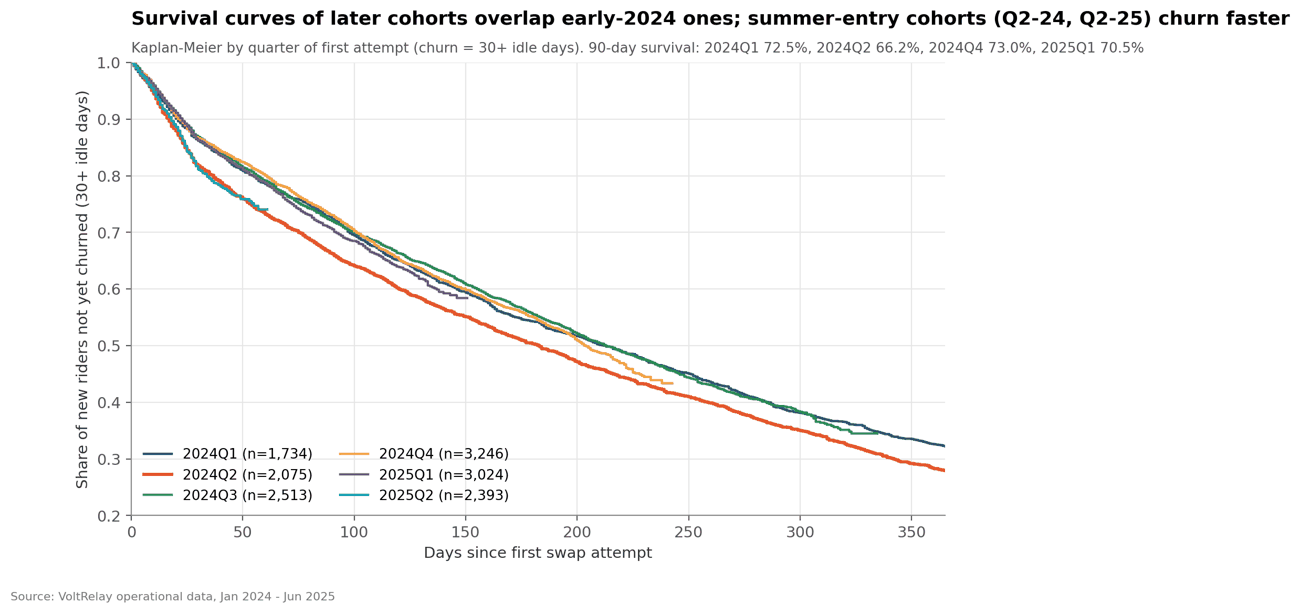

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q6_02_cohort_survival_curves.png')

In [145]:
from lifelines import KaplanMeierFitter, CoxPHFitter  # noqa: E402
from lifelines.statistics import multivariate_logrank_test  # noqa: E402

S = df[df["surv_T"] > 0].copy()
km_rows = []
fig, ax = plt.subplots(figsize=(10, 5.6))
qcols = dict(zip(sorted(S["coh_q"].unique()), SERIES))
for q, g in S.groupby("coh_q"):
    kmf = KaplanMeierFitter().fit(g["surv_T"], g["surv_E"], label=f"{q} (n={len(g):,})")
    tmax = g["surv_T"].max()
    kmf.plot_survival_function(ax=ax, ci_show=False, color=qcols[q], lw=2.2 if q in ("2024Q2",) else 1.6)
    row = {"cohort": q, "n": len(g)}
    for h in (30, 60, 90, 180, 270):
        row[f"S{h}"] = float(kmf.survival_function_at_times(h).iloc[0]) if tmax >= h else np.nan
    km_rows.append(row)
km_tab = pd.DataFrame(km_rows)
print(km_tab.round(3).to_string(index=False))
km_tab.to_csv(TAB / "q6_cohort_km.csv", index=False)
from lifelines.statistics import logrank_test  # noqa: E402
for qa, qb in [("2024Q1", "2025Q1"), ("2024Q1", "2024Q2"), ("2024Q2", "2025Q2")]:
    ga, gb = S[S["coh_q"] == qa], S[S["coh_q"] == qb]
    lt = logrank_test(ga["surv_T"], gb["surv_T"], ga["surv_E"], gb["surv_E"])
    print(f"Log-rank {qa} vs {qb}: chi2={lt.test_statistic:.2f}, p={lt.p_value:.4f}")
ax.set_xlim(0, 365)
ax.set_ylim(0.2, 1.0)
ax.set_xlabel("Days since first swap attempt")
ax.set_ylabel("Share of new riders not yet churned (30+ idle days)")
s2q2 = km_tab.set_index("cohort")
title_sub(ax, "Survival curves of later cohorts overlap early-2024 ones; summer-entry cohorts (Q2-24, Q2-25) churn faster",
          f"Kaplan-Meier by quarter of first attempt (churn = 30+ idle days). 90-day survival: 2024Q1 {pct(s2q2.loc['2024Q1','S90'])}, "
          f"2024Q2 {pct(s2q2.loc['2024Q2','S90'])}, 2024Q4 {pct(s2q2.loc['2024Q4','S90'])}, 2025Q1 {pct(s2q2.loc['2025Q1','S90'])}")
ax.legend(loc="lower left", ncol=2)
save_fig(fig, "q6_02_cohort_survival_curves")

## 4. Univariate lift tables (eligible riders, primary outcome)

In [146]:
D["q_mean_bin"] = pd.qcut(D["q_mean"], 5, labels=["Q1 shortest", "Q2", "Q3", "Q4", "Q5 longest"]).astype(str)
D["kyron_bin"] = pd.cut(D["kyron_share"], [-0.01, 0, 0.25, 0.5, 1.01], labels=["0%", "1-25%", "26-50%", ">50%"]).astype(str)
D["km_bin"] = pd.qcut(D["km_mean"], 5, labels=["Q1 lowest km", "Q2", "Q3", "Q4", "Q5 highest km"]).astype(str)
D["peak_bin"] = np.where(D["peak_share"] == 0, "no PEAK swaps", np.where(D["peak_share"] < 0.4, "1-39% PEAK", "40%+ PEAK"))
D["comp_bin"] = np.where(D["comp_any"] == 1, "competitor active", "no competitor")
D["att_bin"] = pd.cut(D["e_att"], [0, 5, 9, 14, 999], labels=["1-5", "6-9", "10-14", "15+"]).astype(str)
lift_feats = ["fail_grp", "first_fail", "e_stockout", "e_abandon", "e_syserr", "e_cancel", "q_long_any", "q_mean_bin",
              "kyron_bin", "km_bin", "peak_bin", "comp_bin", "tk_any", "tk_unres_any", "segment", "partner",
              "vehicle_class", "vehicle_model", "signup_channel", "kyc_verified", "age_band", "declared_shift",
              "main_city", "main_wave", "main_gen", "main_conn", "main_loc", "att_bin"]
lrows = []
for f_ in lift_feats:
    col = D[f_].clip(upper=2) if f_ in ("e_stockout", "e_abandon", "e_syserr", "e_cancel") else D[f_]
    g = D.groupby(col)["y"].agg(["sum", "size"]).reset_index()
    for _, rr in g.iterrows():
        lo, hi = wilson(rr["sum"], rr["size"])
        lrows.append(dict(feature=f_, level=str(rr.iloc[0]) + ("+" if f_.startswith("e_") and rr.iloc[0] == 2 else ""),
                          n=int(rr["size"]), not_retained=rr["sum"] / rr["size"], ci_lo=float(lo), ci_hi=float(hi),
                          lift=(rr["sum"] / rr["size"]) / overall_nr))
lift = pd.DataFrame(lrows)
lift.to_csv(TAB / "q6_univariate_lift.csv", index=False)
show = lift[lift["n"] >= 100].copy()
show["spread"] = show.groupby("feature")["not_retained"].transform(lambda s: s.max() - s.min())
print("Univariate non-retention spread (max - min across levels with n>=100), top features:")
print(show.groupby("feature")["spread"].first().sort_values(ascending=False).round(3).head(16).to_string())
print(lift[lift["feature"].isin(["fail_grp", "e_stockout", "e_abandon", "e_syserr", "comp_bin", "kyron_bin", "segment", "vehicle_class", "att_bin"])]
      .round(3).to_string(index=False))

# declared shift vs actual activity hours
shift_tab = (early.join(base.select("rider_id", "declared_shift"), on="rider_id")
             .with_columns(band=pl.when(pl.col("hour").is_between(6, 11)).then(pl.lit("06-11"))
                           .when(pl.col("hour").is_between(12, 16)).then(pl.lit("12-16"))
                           .when(pl.col("hour").is_between(17, 21)).then(pl.lit("17-21")).otherwise(pl.lit("22-05")))
             .group_by(["declared_shift", "band"]).len()
             .with_columns(share=pl.col("len") / pl.col("len").sum().over("declared_shift"))
             .pivot(on="band", index="declared_shift", values="share").sort("declared_shift").to_pandas())
shift_tab = shift_tab[["declared_shift", "06-11", "12-16", "17-21", "22-05"]]
print("\nShare of early attempts by hour band, by DECLARED shift (identical rows => declaration is uninformative):")
print(shift_tab.round(3).to_string(index=False))
shift_tab.to_csv(TAB / "q6_declared_shift_vs_activity.csv", index=False)

# vehicle model is a proxy for fleet affiliation / vehicle class
vm = pd.crosstab(D["vehicle_model"], D["segment"], normalize="index").round(3)
vm["vehicle_class"] = D.groupby("vehicle_model")["vehicle_class"].agg(lambda s: s.mode()[0])
vm["not_retained"] = D.groupby("vehicle_model")["y"].mean().round(3)
vm["n"] = D.groupby("vehicle_model").size()
chi2, pchi, _, _ = stats.chi2_contingency(pd.crosstab(D["vehicle_model"], D["partner"]))
cramer_v = np.sqrt(chi2 / (len(D) * (min(D["vehicle_model"].nunique(), D["partner"].nunique()) - 1)))
print("\nVehicle model vs segment (row shares):")
print(vm.to_string())
print(f"Cramer's V(vehicle_model, partner) = {cramer_v:.2f}; Zipp E2 riders that are ZipDrop: "
      f"{pct((D.loc[D['vehicle_model']=='Zipp E2','partner']==ZIPDROP_ID).mean())}; "
      f"ZipDrop riders on Zipp E2: {pct((D.loc[D['partner']==ZIPDROP_ID,'vehicle_model']=='Zipp E2').mean())}")
vm.to_csv(TAB / "q6_vehicle_model_confounding.csv")

Univariate non-retention spread (max - min across levels with n>=100), top features:
feature
att_bin          0.546
e_stockout       0.110
e_abandon        0.105
fail_grp         0.098
first_fail       0.076
q_mean_bin       0.060
partner          0.048
vehicle_model    0.046
kyron_bin        0.037
main_city        0.036
main_loc         0.035
segment          0.033
e_syserr         0.030
vehicle_class    0.030
signup_channel   0.029
km_bin           0.027
      feature             level     n  not_retained  ci_lo  ci_hi  lift
     fail_grp                 0  7350         0.133  0.125  0.140 0.906
     fail_grp                 1  4201         0.128  0.118  0.138 0.873
     fail_grp                 2  1497         0.226  0.205  0.248 1.544
     fail_grp                3+   749         0.226  0.197  0.257 1.543
   e_stockout                 0  9275         0.134  0.127  0.141 0.915
   e_stockout                 1  3361         0.147  0.135  0.159 1.005
   e_stockout                2+  11

## 5. Multivariable logistic regression (odds of NOT being retained)
Fixed effects for cohort month and city absorb seasonality, network maturity and city mix. Standard errors are
clustered by main station. Model A puts early failures in dose groups. Model B splits failures by type.
Activity volume (early attempts) is left out because it is partly the outcome itself: early churners make few
attempts. A sensitivity check adds it back.

In [147]:
D["kyron25"] = D["kyron_share"] / 0.25
D["peak25"] = D["peak_share"] / 0.25
D["km10"] = D["km_mean"] / 10          # raw km (old spec, kept only to document the 3W change)
D["soh10"] = D["soh_out"] / 10
D["e_stockout_c"] = D["e_stockout"].clip(upper=4)
D["e_abandon_c"] = D["e_abandon"].clip(upper=4)
D["e_syserr_c"] = D["e_syserr"].clip(upper=2)
D["e_cancel_c"] = D["e_cancel"].clip(upper=2)
D["station_code"] = D["main_station"].astype("category").cat.codes
COMMON = ("first_fail + q_mean + kyron25 + km10c + peak25 + comp_any + tk_any + tk_unres_any + w3 "
          "+ C(segment, Treatment('Other partner')) + C(signup_channel, Treatment('partner_onboarding')) + kyc_no "
          "+ C(age_band, Treatment('25-34')) + C(main_wave, Treatment('Launch')) + C(main_gen, Treatment('Gen2')) "
          "+ C(main_conn, Treatment('good'))")
FE = " + C(coh_s) + C(main_city)"
fA = "y ~ C(fail_grp, Treatment('0')) + " + COMMON + FE
fB = "y ~ e_stockout_c + e_abandon_c + e_syserr_c + e_cancel_c + " + COMMON + FE


def fit_logit(formula, data):
    return smf.logit(formula, data=data).fit(disp=0, maxiter=200, cov_type="cluster",
                                             cov_kwds={"groups": data["station_code"]})


mA = fit_logit(fA, D)
mB = fit_logit(fB, D)
mA_att = fit_logit(fA + " + log_att_c", D)


def or_table(m, model_name):
    ci = m.conf_int()
    t = pd.DataFrame({"term": m.params.index, "coef": m.params.values, "OR": np.exp(m.params.values),
                      "lo": np.exp(ci[0].values), "hi": np.exp(ci[1].values), "p": m.pvalues.values})
    t["model"] = model_name
    return t[~t["term"].str.startswith(("C(coh_s)", "C(main_city)", "Intercept"))]


orA, orB, orA2 = or_table(mA, "A_dose"), or_table(mB, "B_types"), or_table(mA_att, "A_plus_log_attempts")
ors = pd.concat([orA, orB, orA2])
ors.to_csv(TAB / "q6_logit_odds_ratios.csv", index=False)
print(f"Model A: n={int(mA.nobs):,}, pseudo-R2={mA.prsquared:.3f}; Model B pseudo-R2={mB.prsquared:.3f}")
print(orA.round(3).to_string(index=False))
print(orB[orB["term"].str.startswith("e_")].round(3).to_string(index=False))
print("Sensitivity (adds log early attempts, centred within vehicle class):")
print(orA2[orA2["term"].str.contains("fail_grp|log_att|comp_any|w3|first_fail|segment")].round(3).to_string(index=False))


def or_txt(m, term):
    ci_ = m.conf_int().loc[term]
    return f"OR {np.exp(m.params[term]):.2f} [{np.exp(ci_[0]):.2f}-{np.exp(ci_[1]):.2f}], p={m.pvalues[term]:.3g}"


# Headline exposure, stated consistently: 2+ vs 0-1 service failures (and 2+ vs 0-1 stockouts/abandoned queues)
m2p = fit_logit("y ~ fail2p + " + COMMON + FE, D)
msa = fit_logit("y ~ sa2p + " + COMMON + FE, D)
print(f"\nHEADLINE EXPOSURE. 2+ service failures in days 0-13: n={int(D['fail2p'].sum()):,}, not retained "
      f"{pct(D.loc[D['fail2p'] == 1, 'y'].mean())} vs {pct(D.loc[D['fail2p'] == 0, 'y'].mean())} for 0-1; "
      f"adjusted (2+ vs 0-1, Model A controls) {or_txt(m2p, 'fail2p')}")
print(f"2+ stockouts or abandoned queues only: n={int(D['sa2p'].sum()):,}, not retained "
      f"{pct(D.loc[D['sa2p'] == 1, 'y'].mean())} vs {pct(D.loc[D['sa2p'] == 0, 'y'].mean())}; adjusted {or_txt(msa, 'sa2p')}")

# 3W: the old spec used raw km per swap (km10), which read the 3W dummy at a 2W-typical km
mA_rawkm = fit_logit(fA.replace("km10c", "km10"), D)
mA_nokm = fit_logit(fA.replace("km10c + ", ""), D)
T2 = "C(fail_grp, Treatment('0'))[T.2]"
T3 = "C(fail_grp, Treatment('0'))[T.3+]"
print(f"3W raw non-retention {pct(D.loc[D['w3'] == 1, 'y'].mean())} (n={int(D['w3'].sum()):,}) vs 2W "
      f"{pct(D.loc[D['w3'] == 0, 'y'].mean())}. 3W in Model A: km centred within class {or_txt(mA, 'w3')}; "
      f"km dropped {or_txt(mA_nokm, 'w3')}; old spec with raw km {or_txt(mA_rawkm, 'w3')}; failure ORs identical "
      f"({np.exp(mA.params[T2]):.3f} vs {np.exp(mA_rawkm.params[T2]):.3f})")

# Is there a "tolerated first failure"? Pooled rates show 0 > 1 failures; check within early-activity bands
D["att_band"] = pd.cut(D["e_att"], [0, 5, 9, 14, 19, 999], labels=["1-5", "6-9", "10-14", "15-19", "20+"]).astype(str)
band_rate = pd.crosstab(D["att_band"], D["fail_grp"], values=D["y"], aggfunc="mean")
band_n = pd.crosstab(D["att_band"], D["fail_grp"])
print("\nNon-retention by early failures WITHIN early-activity bands (rows = attempts in days 0-13):")
print(band_rate.round(3).to_string())
print(band_n.to_string())
low = D[D["att_band"] == "1-5"]
print(f"Simpson's paradox: {len(low):,} riders made only 1-5 early attempts ({pct(low['y'].mean())} not retained) and "
      f"{int((low['fail_grp'] == '0').sum()):,} of them had 0 failures, which inflates the pooled 0-failure rate")
for g_ in ["1", "2", "3+"]:
    term_ = "C(fail_grp, Treatment('0'))[T." + g_ + "]"
    print(f"  {g_} failure(s) vs 0: activity-adjusted {or_txt(mA_att, term_)} | Model A {or_txt(mA, term_)}")
print(f"  First attempt failed: activity-adjusted {or_txt(mA_att, 'first_fail')} | Model A {or_txt(mA, 'first_fail')}")
print(f"  3W, activity-adjusted (km and attempts centred within class): {or_txt(mA_att, 'w3')}")
# exposure-free dose: failure RATE in days 0-13, with and without the activity control
fR = "y ~ C(frate_bin, Treatment('0')) + " + COMMON + FE
mR = fit_logit(fR + " + log_att_c", D)
mR0 = fit_logit(fR, D)
frate_tab = D.groupby("frate_bin")["y"].agg(["mean", "size"]).reindex(["0", "0-5%", "5-10%", "10-20%", ">20%"])
print("Non-retention by early failure RATE (share of attempts failed):")
print(frate_tab.round(3).to_string())
thr_rows = []
for b_ in ["0-5%", "5-10%", "10-20%", ">20%"]:
    term = f"C(frate_bin, Treatment('0'))[T.{b_}]"
    print(f"  failure rate {b_} vs 0: with log attempts {or_txt(mR, term)} | without {or_txt(mR0, term)}")
    for lab_, m_ in [("failure-rate model + log attempts", mR), ("failure-rate model", mR0)]:
        ci_ = m_.conf_int().loc[term]
        thr_rows.append(dict(model=lab_, level=b_, OR=np.exp(m_.params[term]), lo=np.exp(ci_[0]), hi=np.exp(ci_[1]), p=m_.pvalues[term]))
for g_ in ["1", "2", "3+"]:
    term = f"C(fail_grp, Treatment('0'))[T.{g_}]"
    for lab_, m_ in [("count model + log attempts", mA_att), ("count model (Model A)", mA)]:
        ci_ = m_.conf_int().loc[term]
        thr_rows.append(dict(model=lab_, level=f"{g_} failures", OR=np.exp(m_.params[term]), lo=np.exp(ci_[0]), hi=np.exp(ci_[1]), p=m_.pvalues[term]))
band_long = band_rate.stack().rename("not_retained").reset_index().merge(
    band_n.stack().rename("n").reset_index(), on=["att_band", "fail_grp"])
pd.DataFrame(thr_rows).to_csv(TAB / "q6_dose_gradient_models.csv", index=False)
band_long.to_csv(TAB / "q6_dose_within_activity_band.csv", index=False)

# Battery channel as a natural test: packs got worse for later cohorts (Kyron, degradation) but retention did not
mS = fit_logit(fA + " + soh10", D)
bat_coh = D.groupby("coh_s")[["soh_out", "km_mean", "kyron_share"]].mean()
print(f"\nBattery channel: SoH of packs received {or_txt(mS, 'soh10')} per +10 SoH points (Model A + SoH). "
      f"Mean SoH received Jan-24 cohort {bat_coh['soh_out'].iloc[0]:.1f} -> Apr-25 {bat_coh['soh_out'].iloc[-1]:.1f}; "
      f"km per swap {bat_coh['km_mean'].iloc[0]:.1f} -> {bat_coh['km_mean'].iloc[-1]:.1f}; Kyron share "
      f"{pct(bat_coh['kyron_share'].iloc[0])} -> {pct(bat_coh['kyron_share'].iloc[-1])}")

# robustness: full partner dummies and vehicle model (proxy) on top of segment controls
mP = fit_logit("y ~ C(fail_grp, Treatment('0')) + " + COMMON.replace("C(segment, Treatment('Other partner'))", "C(partner, Treatment('FP-01'))") + FE, D)
mV = fit_logit(fA + " + C(vehicle_model, Treatment('Zipp E2'))", D)
lr_vm = 2 * (mV.llf - mA.llf)
df_vm = mV.df_model - mA.df_model
p_vm = 1 - stats.chi2.cdf(lr_vm, df_vm)
print(f"Adding vehicle_model to Model A: LR chi2={lr_vm:.1f}, df={df_vm:.0f}, p={p_vm:.3f} (no independent effect if p>0.05)")
orP = or_table(mP, "partners")
print(orP[orP["term"].str.contains("partner")].round(3).to_string(index=False))
pd.concat([orP.assign(model="partners"), or_table(mV, "vehicle_model")]).to_csv(TAB / "q6_logit_robustness.csv", index=False)

# robustness on alternative outcomes (same Model A spec)
alt_rows = []
for lab, ycol, mask in [("R14 (no swap days 15-28)", "r14", df["t0"] < DATA_END - dt.timedelta(days=28)),
                        ("R90 (no swap days 91-120)", "r90", df["t0"] < DATA_END - dt.timedelta(days=120))]:
    Dx = df[mask].copy()
    Dx["y"] = (~Dx[ycol]).astype(int)
    Dx["kyron25"], Dx["peak25"] = Dx["kyron_share"] / 0.25, Dx["peak_share"] / 0.25
    Dx["station_code"] = Dx["main_station"].astype("category").cat.codes
    mx = fit_logit(fA, Dx)
    t = or_table(mx, lab)
    t = t[t["term"].str.contains("fail_grp|comp_any|w3|kyron25|first_fail")]
    t["n"] = int(mx.nobs)
    t["base_rate"] = Dx["y"].mean()
    alt_rows.append(t)
alt = pd.concat(alt_rows)
print(alt.round(3).to_string(index=False))
alt.to_csv(TAB / "q6_logit_alt_outcomes.csv", index=False)

Model A: n=13,797, pseudo-R2=0.018; Model B pseudo-R2=0.016
                                                             term   coef    OR    lo    hi     p  model
                                 C(fail_grp, Treatment('0'))[T.1] -0.105 0.901 0.796 1.019 0.097 A_dose
                                 C(fail_grp, Treatment('0'))[T.2]  0.511 1.666 1.373 2.022 0.000 A_dose
                                C(fail_grp, Treatment('0'))[T.3+]  0.345 1.412 1.141 1.747 0.001 A_dose
             C(segment, Treatment('Other partner'))[T.Indep-PAYG] -0.137 0.872 0.670 1.134 0.307 A_dose
          C(segment, Treatment('Other partner'))[T.Indep-prepaid] -0.065 0.937 0.707 1.242 0.651 A_dose
                C(segment, Treatment('Other partner'))[T.ZipDrop]  0.056 1.058 0.906 1.235 0.475 A_dose
  C(signup_channel, Treatment('partner_onboarding'))[T.app_store] -0.086 0.918 0.685 1.230 0.566 A_dose
C(signup_channel, Treatment('partner_onboarding'))[T.field_agent]  0.050 1.051 0.912 1.212 0.491 A_dose
   C


HEADLINE EXPOSURE. 2+ service failures in days 0-13: n=2,246, not retained 22.6% vs 13.1% for 0-1; adjusted (2+ vs 0-1, Model A controls) OR 1.67 [1.43-1.94], p=4.2e-11
2+ stockouts or abandoned queues only: n=2,067, not retained 23.5% vs 13.1%; adjusted OR 1.76 [1.51-2.06], p=7.97e-13


3W raw non-retention 17.2% (n=1,998) vs 2W 14.2%. 3W in Model A: km centred within class OR 1.18 [1.01-1.37], p=0.0372; km dropped OR 1.16 [1.00-1.36], p=0.0511; old spec with raw km OR 1.52 [1.08-2.15], p=0.017; failure ORs identical (1.666 vs 1.666)

Non-retention by early failures WITHIN early-activity bands (rows = attempts in days 0-13):
fail_grp     0     1     2    3+
att_band                        
1-5      0.638 0.759 0.765 1.000
10-14    0.091 0.115 0.222 0.226
15-19    0.086 0.110 0.179 0.182
20+      0.082 0.082 0.175 0.246
6-9      0.267 0.253 0.495 0.475
fail_grp     0     1    2   3+
att_band                      
1-5        400    54   17    1
10-14     3478  1803  607  252
15-19     2285  1529  553  314
20+        587   503  211  142
6-9        600   312  109   40
Simpson's paradox: 472 riders made only 1-5 early attempts (65.7% not retained) and 400 of them had 0 failures, which inflates the pooled 0-failure rate
  1 failure(s) vs 0: activity-adjusted OR 1.23 [1.08-1

Non-retention by early failure RATE (share of attempts failed):
           mean  size
frate_bin            
0         0.133  7350
0-5%      0.082   503
5-10%     0.117  3547
10-20%    0.212  1810
>20%      0.346   587
  failure rate 0-5% vs 0: with log attempts OR 0.94 [0.66-1.33], p=0.715 | without OR 0.48 [0.34-0.67], p=1.21e-05
  failure rate 5-10% vs 0: with log attempts OR 1.21 [1.05-1.40], p=0.0099 | without OR 0.84 [0.73-0.97], p=0.0154
  failure rate 10-20% vs 0: with log attempts OR 2.10 [1.76-2.51], p=1.52e-16 | without OR 1.65 [1.39-1.96], p=1.53e-08
  failure rate >20% vs 0: with log attempts OR 2.93 [2.30-3.72], p=1.48e-18 | without OR 3.13 [2.51-3.91], p=6.34e-24



Battery channel: SoH of packs received OR 1.07 [0.70-1.63], p=0.766 per +10 SoH points (Model A + SoH). Mean SoH received Jan-24 cohort 98.7 -> Apr-25 82.0; km per swap 74.7 -> 56.4; Kyron share 3.7% -> 23.5%


Adding vehicle_model to Model A: LR chi2=3.7, df=6, p=0.713 (no independent effect if p>0.05)
                                                             term   coef    OR    lo    hi     p    model
                          C(partner, Treatment('FP-01'))[T.FP-02] -0.075 0.927 0.750 1.147 0.487 partners
                          C(partner, Treatment('FP-01'))[T.FP-03]  0.074 1.076 0.882 1.314 0.469 partners
                          C(partner, Treatment('FP-01'))[T.FP-04] -0.158 0.854 0.616 1.182 0.341 partners
                          C(partner, Treatment('FP-01'))[T.FP-05]  0.154 1.167 0.899 1.515 0.247 partners
                          C(partner, Treatment('FP-01'))[T.FP-06] -0.023 0.977 0.709 1.346 0.887 partners
                          C(partner, Treatment('FP-01'))[T.FP-07]  0.202 1.224 0.922 1.624 0.162 partners
                          C(partner, Treatment('FP-01'))[T.FP-08]  0.035 1.036 0.713 1.505 0.853 partners
                          C(partner, Treatment('FP-01'))[T

                             term   coef    OR    lo    hi     p                     model     n  base_rate
 C(fail_grp, Treatment('0'))[T.1] -0.527 0.590 0.509 0.685 0.000  R14 (no swap days 15-28) 15174      0.072
 C(fail_grp, Treatment('0'))[T.2]  0.119 1.126 0.914 1.387 0.265  R14 (no swap days 15-28) 15174      0.072
C(fail_grp, Treatment('0'))[T.3+] -0.239 0.787 0.590 1.052 0.106  R14 (no swap days 15-28) 15174      0.072
                       first_fail  0.451 1.569 1.206 2.042 0.001  R14 (no swap days 15-28) 15174      0.072
                          kyron25  0.005 1.005 0.875 1.156 0.939  R14 (no swap days 15-28) 15174      0.072
                         comp_any -0.232 0.793 0.608 1.033 0.086  R14 (no swap days 15-28) 15174      0.072
                               w3  0.171 1.186 0.998 1.410 0.052  R14 (no swap days 15-28) 15174      0.072
 C(fail_grp, Treatment('0'))[T.1] -0.111 0.895 0.815 0.982 0.019 R90 (no swap days 91-120) 11805      0.233
 C(fail_grp, Treatment('0'))

## 6. Trigger analysis: churn probability right after each attempt (all new-rider attempts)
For each attempt, did the rider leave (no further attempt for 30 or more days)? Comparing what *just
happened* to the rider tests whether failures **trigger** exits. The grouped binomial GLM is a **pooled**
design (no rider fixed effect): it adjusts for tenure, calendar month, vehicle class, segment, competitor and
pack supplier. A truly **within-rider** check follows: Mantel-Haenszel ORs with each rider (and each
rider x month) as its own stratum, so every rider is compared only with themselves.

In [148]:
AT = (events(["rider_id", "event_ts", "event_type", "is_service_failure", "supplier_out", "competitor_active",
              "vehicle_class", "is_independent", "month"])
      .join(B, on="rider_id", how="inner").sort(["rider_id", "event_ts"])
      .with_columns(nxt=pl.col("event_ts").shift(-1).over("rider_id"),
                    f7=pl.col("is_service_failure").cast(pl.Int32).rolling_sum_by("event_ts", window_size="7d").over("rider_id"))
      .filter(pl.col("event_ts") < DATA_END - dt.timedelta(days=CHURN_GAP))
      .with_columns(churn=((pl.coalesce("nxt", pl.lit(DATA_END)) - pl.col("event_ts")).dt.total_seconds() / 86400 >= CHURN_GAP),
                    prior_f7=(pl.col("f7") - pl.col("is_service_failure").cast(pl.Int32)).clip(0, 3),
                    tenure=((pl.col("event_ts") - pl.col("t0")).dt.total_seconds() / 86400))
      .with_columns(ten_band=pl.when(pl.col("tenure") < 14).then(pl.lit("a_0-13d")).when(pl.col("tenure") < 60).then(pl.lit("b_14-59d"))
                    .when(pl.col("tenure") < 180).then(pl.lit("c_60-179d")).otherwise(pl.lit("d_180d+")),
                    kyron=(pl.col("supplier_out") == "Kyron").fill_null(False).cast(pl.Int8))
      .group_by(["event_type", "prior_f7", "ten_band", "month", "vehicle_class", "is_independent", "competitor_active", "kyron"])
      .agg(n=pl.len(), k=pl.col("churn").sum())
      .collect(engine="streaming").to_pandas())
AT["prop"] = AT["k"] / AT["n"]
AT["month_s"] = AT["month"].astype(str)
AT["prior_f7"] = AT["prior_f7"].astype(str).replace({"3": "3+"})
AT["etype"] = AT["event_type"].map({"swap_completed": "completed", "failed_no_charged_battery": "stockout",
                                    "abandoned_queue": "abandoned", "failed_system_error": "system_error",
                                    "cancelled_by_rider": "cancelled"})
raw_at = AT.groupby("etype")[["k", "n"]].sum()
raw_at["churn_rate"] = raw_at["k"] / raw_at["n"]
raw_pf = AT.groupby("prior_f7")[["k", "n"]].sum()
raw_pf["churn_rate"] = raw_pf["k"] / raw_pf["n"]
print(f"Attempts analysed: {int(AT['n'].sum()):,}; exits: {int(AT['k'].sum()):,}")
print(raw_at.round(5).to_string())
print(raw_pf.round(5).to_string())
mH = smf.glm("prop ~ C(etype, Treatment('completed')) + C(prior_f7, Treatment('0')) + C(ten_band) + C(month_s) "
             "+ C(vehicle_class) + C(is_independent) + C(competitor_active) + kyron",
             data=AT, family=sm.families.Binomial(), var_weights=AT["n"]).fit()
hz = or_table(mH, "attempt_exit_glm")
print(hz[~hz["term"].str.contains("month_s")].round(4).to_string(index=False))
hz.to_csv(TAB / "q6_attempt_exit_glm.csv", index=False)
raw_at.to_csv(TAB / "q6_attempt_exit_raw_by_outcome.csv")

# Within-rider Mantel-Haenszel OR: exit right after a stockout/abandoned queue vs after any other attempt
A2 = (events(["rider_id", "event_ts", "event_type", "month"]).join(B.select("rider_id"), on="rider_id", how="semi")
      .sort(["rider_id", "event_ts"])
      .with_columns(nxt=pl.col("event_ts").shift(-1).over("rider_id"))
      .filter(pl.col("event_ts") < DATA_END - dt.timedelta(days=CHURN_GAP))
      .with_columns(Y=((pl.coalesce("nxt", pl.lit(DATA_END)) - pl.col("event_ts")).dt.total_seconds() / 86400 >= CHURN_GAP),
                    X=pl.col("event_type").is_in(["failed_no_charged_battery", "abandoned_queue"])))
mh_rows = []
for lab, keys in [("rider", ["rider_id"]), ("rider x month", ["rider_id", "month"])]:
    s_ = (A2.group_by(keys).agg(a=(pl.col("X") & pl.col("Y")).sum(), b=(~pl.col("X") & pl.col("Y")).sum(),
                                c=(pl.col("X") & ~pl.col("Y")).sum(), d=(~pl.col("X") & ~pl.col("Y")).sum(), n=pl.len())
          .filter((pl.col("a") + pl.col("b")) > 0).select("a", "b", "c", "d", "n")
          .collect(engine="streaming").to_pandas().astype(float))
    Ri, Si = s_["a"] * s_["d"] / s_["n"], s_["b"] * s_["c"] / s_["n"]
    Pi, Qi = (s_["a"] + s_["d"]) / s_["n"], (s_["b"] + s_["c"]) / s_["n"]
    Rs, Ss = Ri.sum(), Si.sum()
    var_ = (Pi * Ri).sum() / (2 * Rs ** 2) + (Pi * Si + Qi * Ri).sum() / (2 * Rs * Ss) + (Qi * Si).sum() / (2 * Ss ** 2)
    or_mh = Rs / Ss
    mh_rows.append(dict(strata=lab, OR_MH=or_mh, lo=or_mh * np.exp(-1.96 * var_ ** 0.5), hi=or_mh * np.exp(1.96 * var_ ** 0.5),
                        n_strata_with_exit=len(s_)))
mh = pd.DataFrame(mh_rows)
print("Within-rider Mantel-Haenszel OR of exiting right after a stockout/abandoned queue (vs other attempts):")
print(mh.round(3).to_string(index=False))
mh.to_csv(TAB / "q6_attempt_exit_within_rider_mh.csv", index=False)
del A2

Attempts analysed: 2,350,544; exits: 8,117
                 k        n  churn_rate
etype                                  
abandoned      243    39850       0.006
cancelled       28    10052       0.003
completed     7392  2215929       0.003
stockout       432    77736       0.006
system_error    22     6977       0.003
             k        n  churn_rate
prior_f7                           
0         5201  1684812       0.003
1         2101   523361       0.004
2          608   110094       0.006
3+         207    32277       0.006
                                            term   coef    OR    lo    hi     p            model
   C(etype, Treatment('completed'))[T.abandoned]  0.507 1.661 1.459 1.891 0.000 attempt_exit_glm
   C(etype, Treatment('completed'))[T.cancelled] -0.190 0.827 0.570 1.200 0.317 attempt_exit_glm
    C(etype, Treatment('completed'))[T.stockout]  0.406 1.501 1.359 1.657 0.000 attempt_exit_glm
C(etype, Treatment('completed'))[T.system_error] -0.068 0.934 0.614 1.421

Within-rider Mantel-Haenszel OR of exiting right after a stockout/abandoned queue (vs other attempts):
       strata  OR_MH    lo    hi  n_strata_with_exit
        rider  1.525 1.406 1.655                7372
rider x month  1.252 1.146 1.367                8117


## 7. Gradient boosting + SHAP (non-linear importance, interactions)

In [149]:
import lightgbm as lgb  # noqa: E402
import shap  # noqa: E402
from sklearn.model_selection import StratifiedKFold  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402

GB_NUM = ["e_stockout", "e_abandon", "e_syserr", "e_cancel", "first_fail", "q_mean", "q_long_n", "kyron_share",
          "soh_out", "km_mean", "price_mean", "peak_share", "comp_share", "tk_n", "tk_unres", "w3", "kyc_no", "coh_idx"]
GB_CAT = ["segment", "signup_channel", "age_band", "main_city", "main_wave", "main_gen", "main_conn", "declared_shift"]
X = D[GB_NUM].astype(float).copy()
for c in GB_CAT:
    X[c] = D[c].astype("category")
yv = D["y"].values
params = dict(objective="binary", learning_rate=0.03, num_leaves=15, min_child_samples=80, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, n_estimators=400, verbose=-1, random_state=1)
aucs = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=7).split(X, yv):
    gbm = lgb.LGBMClassifier(**params).fit(X.iloc[tr], yv[tr])
    aucs.append(roc_auc_score(yv[te], gbm.predict_proba(X.iloc[te])[:, 1]))
gbm = lgb.LGBMClassifier(**params).fit(X, yv)
sv = shap.TreeExplainer(gbm).shap_values(X)
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.DataFrame({"feature": X.columns, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
imp["share"] = imp["mean_abs_shap"] / imp["mean_abs_shap"].sum()
print(f"LightGBM (drivers only) 5-fold CV AUC = {np.mean(aucs):.3f} (+/- {np.std(aucs):.3f})")
print(imp.round(4).head(10).to_string(index=False))
# Shares such as Kyron share and mean queue wait are noisy for riders with only a few early swaps, and those
# riders are exactly the early leavers. So model 2 adds early activity volume as an exposure control (a
# symptom, not a driver), which keeps the trees from reading denominator noise as a "driver".
X2 = X.copy()
X2["e_att"] = D["e_att"].astype(float)
aucs2 = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=7).split(X2, yv):
    g2 = lgb.LGBMClassifier(**params).fit(X2.iloc[tr], yv[tr])
    aucs2.append(roc_auc_score(yv[te], g2.predict_proba(X2.iloc[te])[:, 1]))
gbm2 = lgb.LGBMClassifier(**params).fit(X2, yv)
sv2 = shap.TreeExplainer(gbm2).shap_values(X2)
sv2 = sv2[1] if isinstance(sv2, list) else sv2
imp2 = pd.DataFrame({"feature": X2.columns, "mean_abs_shap": np.abs(sv2).mean(0)}).sort_values("mean_abs_shap", ascending=False)
imp2["share_excl_activity"] = imp2["mean_abs_shap"] / imp2.loc[imp2["feature"] != "e_att", "mean_abs_shap"].sum()
imp2.loc[imp2["feature"] == "e_att", "share_excl_activity"] = np.nan
print(f"LightGBM (drivers + early activity control) 5-fold CV AUC = {np.mean(aucs2):.3f} (+/- {np.std(aucs2):.3f})")
print(imp2.round(4).to_string(index=False))
# direction of the SHAP effect for the failure counts: mean SHAP when count >= 2 vs 0
for c in ["e_stockout", "e_abandon"]:
    i = list(X2.columns).index(c)
    print(f"  mean SHAP of {c}: count>=2 {sv2[X2[c] >= 2, i].mean():+.3f} vs 0 {sv2[X2[c] == 0, i].mean():+.3f} (log-odds)")
imp.merge(imp2, on="feature", how="outer", suffixes=("_drivers_only", "_with_activity")).to_csv(TAB / "q6_shap_importance.csv", index=False)
# logistic (no FE) AUC for comparison
auc_logit = roc_auc_score(yv, mA.predict(D))
print(f"Logistic Model A in-sample AUC = {auc_logit:.3f}")

LightGBM (drivers only) 5-fold CV AUC = 0.599 (+/- 0.016)
    feature  mean_abs_shap  share
kyron_share          0.172  0.129
     q_mean          0.171  0.129
   q_long_n          0.122  0.091
  main_city          0.090  0.068
 e_stockout          0.089  0.067
    soh_out          0.084  0.063
 price_mean          0.084  0.063
  e_abandon          0.082  0.062
    km_mean          0.078  0.059
    coh_idx          0.078  0.058


LightGBM (drivers + early activity control) 5-fold CV AUC = 0.684 (+/- 0.016)
       feature  mean_abs_shap  share_excl_activity
         e_att          0.454                  NaN
    e_stockout          0.181                0.146
       km_mean          0.177                0.143
       segment          0.127                0.103
     main_city          0.117                0.094
     e_abandon          0.113                0.091
       soh_out          0.101                0.081
        q_mean          0.070                0.057
    price_mean          0.057                0.046
   kyron_share          0.050                0.040
       coh_idx          0.048                0.039
      age_band          0.043                0.035
signup_channel          0.038                0.031
declared_shift          0.022                0.018
          tk_n          0.015                0.013
     main_conn          0.014                0.011
      q_long_n          0.014                0.011
    

## 8. Dose-response and stability across segments and cohorts

In [150]:
seg_defs = {"All": D.index == D.index, "Independent": D["indep"] == 1, "Partner": D["indep"] == 0,
            "2W": D["w3"] == 0, "3W": D["w3"] == 1}
for c in CITIES:
    seg_defs[c] = D["main_city"] == c
seg_defs["Cohorts H1-2024"] = D["coh"] < "2024-07-01"
seg_defs["Cohorts H2-2024"] = (D["coh"] >= "2024-07-01") & (D["coh"] < "2025-01-01")
seg_defs["Cohorts 2025"] = D["coh"] >= "2025-01-01"
seg_defs["Winter-entry cohorts (Nov-Feb)"] = D["coh"].dt.month.isin([11, 12, 1, 2])
seg_defs["ZipDrop"] = D["partner"] == ZIPDROP_ID
dose_rows, stab_rows = [], []
for s_, m_ in seg_defs.items():
    sub = D[m_]
    for g_ in ["0", "1", "2", "3+"]:
        gg = sub[sub["fail_grp"] == g_]
        lo, hi = wilson(gg["y"].sum(), len(gg))
        dose_rows.append(dict(segment=s_, fail_grp=g_, n=len(gg), not_retained=gg["y"].mean(), lo=float(lo), hi=float(hi)))
    # adjusted OR of 2+ early failures within the segment (cohort-quarter FE + city FE where they vary)
    covs = [c for c in ["first_fail", "w3", "indep", "comp_any"] if sub[c].nunique() > 1]
    fe = " + C(coh_q)" + (" + C(main_city)" if sub["main_city"].nunique() > 1 else "")
    try:
        ms = smf.logit("y ~ fail2p + " + " + ".join(covs) + fe, data=sub).fit(disp=0, maxiter=200)
        ci = ms.conf_int().loc["fail2p"]
        stab_rows.append(dict(segment=s_, n=len(sub), base_not_retained=sub["y"].mean(),
                              nr_0_1=sub.loc[sub["fail2p"] == 0, "y"].mean(), nr_2p=sub.loc[sub["fail2p"] == 1, "y"].mean(),
                              OR_2plus=np.exp(ms.params["fail2p"]), lo=np.exp(ci[0]), hi=np.exp(ci[1]), p=ms.pvalues["fail2p"]))
    except Exception as ex:  # noqa: BLE001
        print("segment model failed", s_, ex)
dose = pd.DataFrame(dose_rows)
stab = pd.DataFrame(stab_rows)
dose.to_csv(TAB / "q6_dose_response.csv", index=False)
stab.to_csv(TAB / "q6_segment_stability.csv", index=False)
print(dose[dose["segment"].isin(["All", "Independent", "Partner", "3W"])].round(3).to_string(index=False))
print(stab.round(3).to_string(index=False))
sub_stab = stab[stab["segment"] != "All"]          # the pooled "All" row is not a subgroup
n_sub = len(sub_stab)
n_stab_sig = int(((sub_stab["OR_2plus"] > 1) & (sub_stab["p"] < 0.05)).sum())
n_stab_pos = int((sub_stab["OR_2plus"] > 1).sum())
st_all = stab.set_index("segment").loc["All"]
print(f"2+ vs 0-1 early failures: OR>1 in {n_stab_pos}/{n_sub} subgroups, significant (p<0.05) in {n_stab_sig}/{n_sub}; "
      f"pooled (All) OR {st_all['OR_2plus']:.2f} [{st_all['lo']:.2f}-{st_all['hi']:.2f}]")
fail_city = D.groupby("main_city")["e_fail"].mean()
print(f"Mean early (day 0-13) service failures per rider by main-station city: {fail_city.round(2).to_dict()}")
# Kyron share dose-response within post-Sep-2024 cohorts only (Kyron packs did not exist before)
ky = D[D["coh"] >= "2024-09-01"].groupby("kyron_bin")["y"].agg(["mean", "size"])
print("Kyron share in first 14 days (cohorts Sep-24+), non-retention:")
print(ky.round(3).to_string())

    segment fail_grp    n  not_retained    lo    hi
        All        0 7350         0.133 0.125 0.140
        All        1 4201         0.128 0.118 0.138
        All        2 1497         0.226 0.205 0.248
        All       3+  749         0.226 0.197 0.257
Independent        0 3118         0.124 0.113 0.136
Independent        1 1590         0.123 0.108 0.140
Independent        2  449         0.209 0.174 0.249
Independent       3+  181         0.138 0.095 0.196
    Partner        0 4232         0.139 0.129 0.150
    Partner        1 2611         0.130 0.118 0.144
    Partner        2 1048         0.233 0.208 0.259
    Partner       3+  568         0.254 0.219 0.291
         3W        0  716         0.155 0.130 0.183
         3W        1  689         0.123 0.101 0.150
         3W        2  380         0.266 0.224 0.312
         3W       3+  213         0.216 0.166 0.276
                       segment     n  base_not_retained  nr_0_1  nr_2p  OR_2plus    lo    hi     p
                 

## 9. Kaplan-Meier and Cox PH by the top driver (landmark at day 14)
Riders must still be active at day 14, and the clock starts there. Early failures are counted in days 0-13,
so riders who stayed longer could not collect more failures simply by being around longer (no immortal-time bias).

In [151]:
L = df[(df["surv_T"] >= EARLY_DAYS) & (df["end_day"] >= EARLY_DAYS + CHURN_GAP + 1)].copy()
L["T"] = L["surv_T"] - EARLY_DAYS
L["E"] = L["surv_E"].astype(int)
L["kyron25"], L["peak25"] = L["kyron_share"] / 0.25, L["peak_share"] / 0.25
lr = multivariate_logrank_test(L["T"], L["fail_grp"], L["E"])
km_fail = {}
for g_ in ["0", "1", "2", "3+"]:
    gg = L[L["fail_grp"] == g_]
    kmf = KaplanMeierFitter().fit(gg["T"], gg["E"], label=g_)
    km_fail[g_] = (kmf, len(gg))
    print(f"fail_grp {g_}: n={len(gg):,}, S(60d after landmark)={float(kmf.survival_function_at_times(60).iloc[0]):.3f}, "
          f"S(180d)={float(kmf.survival_function_at_times(180).iloc[0]):.3f}")
print(f"Log-rank test across early-failure groups: chi2={lr.test_statistic:.1f}, p={lr.p_value:.2e}")
L["f1"] = (L["fail_grp"] == "1").astype(int)
L["f2"] = (L["fail_grp"] == "2").astype(int)
L["f3p"] = (L["fail_grp"] == "3+").astype(int)
cox_cols = ["f1", "f2", "f3p", "first_fail", "comp_any", "w3", "indep", "kyron25", "km10c", "peak25", "tk_unres_any", "q_mean"]
L["entry_season"] = L["coh"].dt.month.map(SEASON_OF_MONTH)
cph = CoxPHFitter(penalizer=0.001).fit(L[cox_cols + ["T", "E", "entry_season", "main_city"]], "T", "E",
                                        strata=["entry_season", "main_city"])
cox = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(
    columns={"exp(coef)": "HR", "exp(coef) lower 95%": "lo", "exp(coef) upper 95%": "hi"})
print(f"Cox PH (landmark day 14, strata = entry season x city), n={len(L):,}, events={int(L['E'].sum()):,}")
print(cox.round(3).to_string())
cox.to_csv(TAB / "q6_cox_hr.csv")
L["km10"] = L["km_mean"] / 10
cph_raw = CoxPHFitter(penalizer=0.001).fit(L[[c for c in cox_cols if c != "km10c"] + ["km10", "T", "E", "entry_season", "main_city"]],
                                           "T", "E", strata=["entry_season", "main_city"])
print(f"3W Cox HR, old spec with raw km per swap: {cph_raw.summary.loc['w3', 'exp(coef)']:.2f} "
      f"[{cph_raw.summary.loc['w3', 'exp(coef) lower 95%']:.2f}-{cph_raw.summary.loc['w3', 'exp(coef) upper 95%']:.2f}] "
      f"-> km centred within class: {cox.loc['w3', 'HR']:.2f} [{cox.loc['w3', 'lo']:.2f}-{cox.loc['w3', 'hi']:.2f}], p={cox.loc['w3', 'p']:.3f}")

fail_grp 0: n=7,014, S(60d after landmark)=0.812, S(180d)=0.568
fail_grp 1: n=4,183, S(60d after landmark)=0.796, S(180d)=0.546
fail_grp 2: n=1,454, S(60d after landmark)=0.716, S(180d)=0.484
fail_grp 3+: n=796, S(60d after landmark)=0.737, S(180d)=0.483
Log-rank test across early-failure groups: chi2=59.9, p=6.28e-13


Cox PH (landmark day 14, strata = entry season x city), n=13,447, events=6,394
                HR    lo    hi     p
covariate                           
f1           1.041 0.983 1.102 0.169
f2           1.236 1.137 1.343 0.000
f3p          1.217 1.087 1.362 0.001
first_fail   1.017 0.905 1.143 0.777
comp_any     1.201 1.009 1.430 0.039
w3           1.110 1.029 1.197 0.007
indep        0.954 0.904 1.007 0.088
kyron25      0.982 0.936 1.030 0.455
km10c        0.981 0.942 1.022 0.356
peak25       0.994 0.940 1.051 0.832
tk_unres_any 1.131 0.934 1.369 0.207
q_mean       0.999 0.964 1.035 0.956


3W Cox HR, old spec with raw km per swap: 1.18 [1.01-1.37] -> km centred within class: 1.11 [1.03-1.20], p=0.007


## 10. Policy events: base price (Jul-24), peak pilot (Oct-24, BLR/PUN), ZipDrop amendment (Nov-24)
Difference-in-differences on D31-60 non-retention, with cohort-month and city fixed effects:
* base price: independent riders (who pay) vs partner riders (employer pays), cohorts before vs after Jul-24;
* pilot: independent riders in pilot cities vs elsewhere, cohorts before vs after Oct-24, with partner riders
  (who never pay the peak surcharge) as a placebo;
* ZipDrop: ZipDrop riders vs other partner riders, cohorts before vs after Nov-24.

In [152]:
D["post_price"] = (D["coh"] >= "2024-07-01").astype(int)
D["post_pilot"] = (D["coh"] >= "2024-10-01").astype(int)
D["post_zip"] = (D["coh"] >= "2024-11-01").astype(int)
D["zip"] = (D["partner"] == ZIPDROP_ID).astype(int)
did_rows = []
CTRL = " + w3 + C(fail_grp) + C(coh_s) + C(main_city)"
m1 = smf.logit("y ~ indep + indep:post_price" + CTRL, data=D[D["coh"] < "2024-10-01"]).fit(disp=0)
m2 = smf.logit("y ~ pilot_city:post_pilot" + CTRL, data=D[D["indep"] == 1]).fit(disp=0)
m2p = smf.logit("y ~ pilot_city:post_pilot" + CTRL, data=D[D["indep"] == 0]).fit(disp=0)
m3 = smf.logit("y ~ zip + zip:post_zip" + CTRL, data=D[D["indep"] == 0]).fit(disp=0)
for lab, m, term in [("Base price Jul-24: independent x post (cohorts Jan-Sep 2024)", m1, "indep:post_price"),
                     ("Peak pilot Oct-24: pilot city x post, INDEPENDENT riders", m2, "pilot_city:post_pilot"),
                     ("Peak pilot placebo: pilot city x post, PARTNER riders", m2p, "pilot_city:post_pilot"),
                     ("ZipDrop amendment Nov-24: ZipDrop x post (partner riders)", m3, "zip:post_zip")]:
    ci = m.conf_int().loc[term]
    did_rows.append(dict(test=lab, OR=np.exp(m.params[term]), lo=np.exp(ci[0]), hi=np.exp(ci[1]), p=m.pvalues[term], n=int(m.nobs)))
did = pd.DataFrame(did_rows)
print(did.round(3).to_string(index=False))
did.to_csv(TAB / "q6_policy_did.csv", index=False)
# competitor: riders whose main station got a competitor, cohorts 2025 only (competitor entry Jan-25)
c25 = D[D["coh"] >= "2025-01-01"]
pa, na, pb, nb, pcmp = two_prop(c25["comp_any"] == 0, c25["comp_any"] == 1, col="y", frame=c25)
print(f"2025 cohorts: non-retention without competitor exposure {pct(pa)} (n={na:,}) vs with {pct(pb)} (n={nb:,}), p={pcmp:.3f}")

                                                        test    OR    lo    hi     p    n
Base price Jul-24: independent x post (cohorts Jan-Sep 2024) 1.369 1.011 1.852 0.042 6373
    Peak pilot Oct-24: pilot city x post, INDEPENDENT riders 1.277 0.913 1.785 0.153 5338
       Peak pilot placebo: pilot city x post, PARTNER riders 1.197 0.931 1.539 0.161 8459
   ZipDrop amendment Nov-24: ZipDrop x post (partner riders) 1.194 0.886 1.609 0.244 8459
2025 cohorts: non-retention without competitor exposure 15.0% (n=3,514) vs with 14.7% (n=640), p=0.854


## 11. Decomposing the cohort-to-cohort changes (counterfactual swaps of feature blocks)
A pooled logistic model is fitted **without** cohort fixed effects, so that measured experiences have to explain
the trend. For each block of features, we give each comparison-cohort rider the block values of a randomly
drawn reference-cohort rider (Jan-Mar 2024), keep everything else as it is, and read the change in predicted
non-retention (averaged over 30 draws). The part of the gap that no block accounts for stays unexplained.

In [153]:
fPool = ("y ~ C(fail_grp, Treatment('0')) + first_fail + q_mean + kyron25 + km10c + peak25 + comp_any + tk_any "
         "+ tk_unres_any + w3 + C(segment) + C(signup_channel) + kyc_no + C(age_band) + C(main_wave) + C(main_gen) "
         "+ C(main_conn) + C(main_city)")
mPool = smf.logit(fPool, data=D).fit(disp=0, maxiter=200)
print("Pooled model (no cohort FE) battery terms:", {k: (round(float(np.exp(mPool.params[k])), 3), round(float(mPool.pvalues[k]), 4)) for k in ["kyron25", "km10c"]})
BLOCKS = {"Early service failures": ["fail_grp", "first_fail"],
          "Queue wait": ["q_mean"],
          "Battery (Kyron share, km range)": ["kyron25", "km10c"],
          "Peak-tariff exposure": ["peak25"],
          "Competitor nearby": ["comp_any"],
          "Support tickets": ["tk_any", "tk_unres_any"],
          "Segment & vehicle mix": ["segment", "w3"],
          "City & station mix": ["main_city", "main_wave", "main_gen", "main_conn"],
          "Rider profile (channel, KYC, age)": ["signup_channel", "kyc_no", "age_band"]}
pnames = list(mPool.params.index)
block_p = {}
for b, cols in BLOCKS.items():
    idx = [i for i, n in enumerate(pnames) if any(n == c or n.startswith(f"C({c}") for c in cols)]
    R = np.zeros((len(idx), len(pnames)))
    for r_i, i in enumerate(idx):
        R[r_i, i] = 1
    block_p[b] = float(mPool.wald_test(R, scalar=True).pvalue)
print("Joint Wald p-value per block (pooled model):", {k: round(v, 4) for k, v in block_p.items()})
REF =D["coh"].between("2024-01-01", "2024-03-01")
COMPS = {"Apr-Jun 2024 (summer)": D["coh"].between("2024-04-01", "2024-06-01"),
         "Jan-Mar 2025 (same season)": D["coh"].between("2025-01-01", "2025-03-01"),
         "Apr 2025 (latest)": D["coh"] == "2025-04-01",
         "Oct 2024-Apr 2025 (post-interventions)": D["coh"].between("2024-10-01", "2025-04-01")}


def decompose(model, ref, cmp_, draws=30):
    p_cmp = model.predict(cmp_).mean()
    out = {}
    for b, cols in BLOCKS.items():
        vals = []
        for _ in range(draws):
            cf = cmp_.copy()
            idx = RNG.integers(0, len(ref), len(cmp_))
            for c in cols:
                cf[c] = ref[c].values[idx]
            vals.append(model.predict(cf).mean())
        out[b] = p_cmp - np.mean(vals)
    return out


dec_rows = []
ref_df = D[REF]
for lab, msk in COMPS.items():
    cmp_df = D[msk]
    contrib = decompose(mPool, ref_df, cmp_df)
    obs_gap = cmp_df["y"].mean() - ref_df["y"].mean()
    pred_gap = mPool.predict(cmp_df).mean() - mPool.predict(ref_df).mean()
    for b, v in contrib.items():
        dec_rows.append(dict(comparison=lab, block=b, contribution_pp=100 * v, obs_gap_pp=100 * obs_gap,
                             pred_gap_pp=100 * pred_gap, n_ref=len(ref_df), n_cmp=len(cmp_df)))
dec = pd.DataFrame(dec_rows)
dec["unexplained_pp"] = dec["obs_gap_pp"] - dec.groupby("comparison")["contribution_pp"].transform("sum")
dec.to_csv(TAB / "q6_decomposition.csv", index=False)
piv = dec.pivot(index="block", columns="comparison", values="contribution_pp")
gap_line = dec.groupby("comparison")[["obs_gap_pp", "pred_gap_pp", "unexplained_pp"]].first()
print("Change in NON-retention vs Jan-Mar 2024 cohorts (percentage points); positive = worse:")
print(gap_line.round(2).to_string())
print(piv.round(2).to_string())

# failure-neutralised counterfactual per cohort (fail block drawn from Jan-Mar 2024 riders)
cf_rows = []
for c_, g in D.groupby("coh"):
    vals = []
    for _ in range(30):
        cf = g.copy()
        idx = RNG.integers(0, len(ref_df), len(g))
        for c in BLOCKS["Early service failures"]:
            cf[c] = ref_df[c].values[idx]
        vals.append(1 - mPool.predict(cf).mean())
    cf_rows.append(dict(coh=c_, ret_obs=1 - g["y"].mean(), ret_pred=1 - mPool.predict(g).mean(), ret_cf_fail=np.mean(vals)))
cfc = pd.DataFrame(cf_rows)
# The pure-model counterfactual (ret_cf_fail) must not be plotted against observed data: the pooled model itself
# reproduces only part of the cohort-to-cohort variation. The honest series removes the modelled early-failure
# effect from the OBSERVED rate: observed + (counterfactual - model prediction).
cfc["ret_fail_neutral"] = cfc["ret_obs"] + (cfc["ret_cf_fail"] - cfc["ret_pred"])
coh = coh.merge(cfc, on="coh", how="left")
print(cfc.round(4).to_string(index=False))
sd_ = {k: 100 * cfc[k].std() for k in ["ret_obs", "ret_pred", "ret_cf_fail", "ret_fail_neutral"]}
print(f"Cohort D31-60 retention, observed: {pct(cfc['ret_obs'].min())}-{pct(cfc['ret_obs'].max())} (sd {sd_['ret_obs']:.2f} pp); "
      f"observed with the early-failure effect removed: {pct(cfc['ret_fail_neutral'].min())}-{pct(cfc['ret_fail_neutral'].max())} "
      f"(sd {sd_['ret_fail_neutral']:.2f} pp)")
print(f"Model vs model: pooled-model prediction sd {sd_['ret_pred']:.2f} pp vs pure counterfactual sd {sd_['ret_cf_fail']:.2f} pp "
      f"(the model reproduces only part of the observed spread, so the pure counterfactual is not comparable with observed data)")
dip_closed = {}
for m_ in ["2024-04-01", "2024-05-01", "2024-06-01", "2025-04-01"]:
    r_ = cfc[cfc["coh"] == m_].iloc[0]
    dip_closed[m_[:7]] = (r_["ret_fail_neutral"] - r_["ret_obs"]) / ((1 - ref_df["y"].mean()) - r_["ret_obs"])
    print(f"  {m_[:7]}: observed {pct(r_['ret_obs'])} -> early-failure effect removed {pct(r_['ret_fail_neutral'])} "
          f"(Jan-Mar 2024 reference {pct(1 - ref_df['y'].mean())}; share of the dip closed {pct(dip_closed[m_[:7]], 0)})")
coh.to_csv(TAB / "q6_cohort_retention.csv", index=False)

Pooled model (no cohort FE) battery terms: {'kyron25': (0.889, 0.0048), 'km10c': (0.909, 0.0105)}
Joint Wald p-value per block (pooled model): {'Early service failures': 0.0, 'Queue wait': 0.1366, 'Battery (Kyron share, km range)': 0.0086, 'Peak-tariff exposure': 0.2696, 'Competitor nearby': 0.6893, 'Support tickets': 0.6997, 'Segment & vehicle mix': 0.1719, 'City & station mix': 0.179, 'Rider profile (channel, KYC, age)': 0.4067}


Change in NON-retention vs Jan-Mar 2024 cohorts (percentage points); positive = worse:
                                        obs_gap_pp  pred_gap_pp  unexplained_pp
comparison                                                                     
Apr 2025 (latest)                            4.610        2.110           2.390
Apr-Jun 2024 (summer)                        4.580        2.180           2.240
Jan-Mar 2025 (same season)                  -0.020        0.540          -0.570
Oct 2024-Apr 2025 (post-interventions)       0.640        0.600           0.040
comparison                         Apr 2025 (latest)  Apr-Jun 2024 (summer)  Jan-Mar 2025 (same season)  Oct 2024-Apr 2025 (post-interventions)
block                                                                                                                                          
Battery (Kyron share, km range)                1.010                  0.430                       0.480                                   0.410
C

       coh  ret_obs  ret_pred  ret_cf_fail  ret_fail_neutral
2024-01-01    0.851     0.862        0.862             0.851
2024-02-01    0.852     0.862        0.861             0.851
2024-03-01    0.885     0.859        0.860             0.886
2024-04-01    0.824     0.846        0.858             0.837
2024-05-01    0.791     0.831        0.857             0.817
2024-06-01    0.837     0.841        0.857             0.853
2024-07-01    0.879     0.857        0.857             0.879
2024-08-01    0.875     0.857        0.857             0.875
2024-09-01    0.857     0.862        0.863             0.859
2024-10-01    0.855     0.860        0.861             0.856
2024-11-01    0.871     0.860        0.860             0.872
2024-12-01    0.866     0.858        0.859             0.867
2025-01-01    0.870     0.858        0.858             0.870
2025-02-01    0.867     0.856        0.857             0.868
2025-03-01    0.850     0.852        0.855             0.853
2025-04-01    0.817     

### 11b. How much of the summer dip do early failures explain? Four estimates
The decomposition above is one model-based estimate. Three checks with different assumptions bracket it:
(i) logit shrinkage: how much the summer coefficient (Apr-Jun vs Jan-Mar 2024 cohorts) shrinks when early
failure groups are added; (ii) direct standardisation: re-weight non-retention rates to the other period's
failure mix (no model); (iii) riders still active in days 14-29: add failures up to day 29 (still before the
outcome window), which captures summer failures the 14-day window misses.

In [154]:
SA_ = D[D["coh"].between("2024-01-01", "2024-06-01")].assign(summer=lambda x: x["coh"].dt.month.isin([4, 5, 6]).astype(int))
c0 = smf.logit("y ~ summer", SA_).fit(disp=0).params["summer"]
c1 = smf.logit("y ~ summer + C(fail_grp)", SA_).fit(disp=0).params["summer"]
c2 = smf.logit("y ~ summer + C(fail_grp) + log_att", SA_).fit(disp=0).params["summer"]   # no w3 here, so uncentred
print(f"(i) Logit shrinkage, Jan-Jun 2024 cohorts (n={len(SA_):,}): summer log-odds {c0:.3f} -> {c1:.3f} with early "
      f"failure groups ({pct(1 - c1 / c0, 0)} explained) -> {c2:.3f} adding log attempts ({pct(1 - c2 / c0, 0)})")
std_rows = []
for lab, msk in {"Apr-Jun 2024 (summer)": D["coh"].between("2024-04-01", "2024-06-01"),
                 "Apr 2025 (latest)": D["coh"] == "2025-04-01"}.items():
    c_ = D[msk]
    w_ref, w_c = ref_df["fail_grp"].value_counts(normalize=True), c_["fail_grp"].value_counts(normalize=True)
    r_ref, r_c = ref_df.groupby("fail_grp")["y"].mean(), c_.groupby("fail_grp")["y"].mean()
    obs = c_["y"].mean() - ref_df["y"].mean()
    e1 = c_["y"].mean() - (w_ref * r_c).sum()          # comparison rates, reference failure mix
    e2 = (w_c * r_ref).sum() - ref_df["y"].mean()      # reference rates, comparison failure mix
    std_rows.append(dict(comparison=lab, obs_gap_pp=100 * obs, std_cmp_rates_pp=100 * e1, std_ref_rates_pp=100 * e2,
                         share_lo=min(e1, e2) / obs, share_hi=max(e1, e2) / obs,
                         decomposition_pp=piv.loc["Early service failures", lab], decomposition_share=piv.loc["Early service failures", lab] / (100 * obs)))
    print(f"(ii) Standardisation, {lab}: observed {100*obs:+.2f} pp; failure mix explains {100*e1:+.2f} / {100*e2:+.2f} pp "
          f"({pct(min(e1, e2) / obs, 0)}-{pct(max(e1, e2) / obs, 0)}); decomposition {piv.loc['Early service failures', lab]:+.2f} pp "
          f"({pct(piv.loc['Early service failures', lab] / (100 * obs), 0)})")
mid = (E.filter((pl.col("d") >= EARLY_DAYS) & (pl.col("d") < 30)).group_by("rider_id")
       .agg(m_att=pl.len(), m_fail=pl.col("is_service_failure").sum()).collect(engine="streaming").to_pandas())
SM_ = SA_.merge(mid, on="rider_id", how="inner")
SM_["rate029"] = (SM_["e_fail"] + SM_["m_fail"]) / (SM_["e_att"] + SM_["m_att"])
SM_["r029_bin"] = pd.cut(SM_["rate029"], [-0.01, 0, 0.05, 0.10, 0.20, 1.01], labels=["0", "a", "b", "c", "d"]).astype(str)
SM_["log_att029"] = np.log(SM_["e_att"] + SM_["m_att"])
b0 = smf.logit("y ~ summer", SM_).fit(disp=0).params["summer"]
b1 = smf.logit("y ~ summer + C(fail_grp) + log_att", SM_).fit(disp=0).params["summer"]
b2 = smf.logit("y ~ summer + C(r029_bin) + log_att029", SM_).fit(disp=0).params["summer"]
print(f"(iii) Riders active in days 14-29, Jan-Jun 2024 cohorts (n={len(SM_):,}): summer log-odds {b0:.3f}; "
      f"days 0-13 failures {b1:.3f} ({pct(1 - b1 / b0, 0)} explained); failure rate in days 0-29 {b2:.3f} ({pct(1 - b2 / b0, 0)} explained)")
expl_tab = pd.DataFrame(std_rows)
expl_tab = pd.concat([expl_tab, pd.DataFrame([
    dict(comparison="Logit shrinkage, Jan-Jun 2024 (+early failure groups)", obs_gap_pp=np.nan, share_lo=1 - c1 / c0, share_hi=1 - c1 / c0),
    dict(comparison="Logit shrinkage, Jan-Jun 2024 (+failure groups, log attempts)", obs_gap_pp=np.nan, share_lo=1 - c2 / c0, share_hi=1 - c2 / c0),
    dict(comparison="Active in days 14-29: days 0-13 failures + log attempts", obs_gap_pp=np.nan, share_lo=1 - b1 / b0, share_hi=1 - b1 / b0),
    dict(comparison="Active in days 14-29: days 0-29 failure rate + log attempts", obs_gap_pp=np.nan, share_lo=1 - b2 / b0, share_hi=1 - b2 / b0)])])
expl_tab.to_csv(TAB / "q6_summer_dip_explained.csv", index=False)

(i) Logit shrinkage, Jan-Jun 2024 cohorts (n=3,844): summer log-odds 0.342 -> 0.194 with early failure groups (43% explained) -> 0.168 adding log attempts (51%)
(ii) Standardisation, Apr-Jun 2024 (summer): observed +4.58 pp; failure mix explains +2.37 / +2.11 pp (46%-52%); decomposition +1.81 pp (40%)
(ii) Standardisation, Apr 2025 (latest): observed +4.61 pp; failure mix explains +1.38 / +1.35 pp (29%-30%); decomposition +1.31 pp (28%)
(iii) Riders active in days 14-29, Jan-Jun 2024 cohorts (n=3,533): summer log-odds 0.396; days 0-13 failures 0.181 (54% explained); failure rate in days 0-29 0.133 (66% explained)


## 12. Classify drivers: primary vs secondary
Three independent designs: (i) rider-level logit (D31-60, cohort and city FE), (ii) landmark Cox PH (survival
after day 14), (iii) attempt-level exit GLM (does the rider leave right after this experience?).
**PRIMARY** = adverse and significant in all three designs, with a dose-response, the same direction in at
least 75% of subgroups, and it explains at least 25% of the OBSERVED summer-2024 cohort dip (stricter than the
share of the model-predicted dip).
**SECONDARY** = adverse and significant in at least one design but fails a primary test (segment-specific,
localised, not actionable on its own, or does not move the trend).
**NOT SUPPORTED** = no adverse significant effect in any design.

In [155]:
def get(t, term, col="OR"):
    r_ = t[t["term"] == term]
    return float(r_[col].iloc[0]) if len(r_) else np.nan


summer_lab = "Apr-Jun 2024 (summer)"
summer_gap = gap_line.loc[summer_lab, "obs_gap_pp"]
summer_pred = gap_line.loc[summer_lab, "pred_gap_pp"]
fail_expl = piv.loc["Early service failures", summer_lab]
H = lambda term, col="OR": get(hz, term, col)  # noqa: E731
CX = lambda cov, col="HR": float(cox.loc[cov, col]) if cov in cox.index else np.nan  # noqa: E731
consistent_fail = n_stab_pos / n_sub >= 0.75
drivers = [
    dict(driver="Early service failures (2 vs 0 in days 0-13; attempt level: 2 in last 7 d)", logit_OR=get(orA, T2), logit_lo=get(orA, T2, "lo"), logit_hi=get(orA, T2, "hi"), logit_p=get(orA, T2, "p"),
         cox_HR=CX("f2"), cox_lo=CX("f2", "lo"), cox_hi=CX("f2", "hi"), cox_p=CX("f2", "p"),
         exit_OR=H("C(prior_f7, Treatment('0'))[T.2]"), exit_lo=H("C(prior_f7, Treatment('0'))[T.2]", "lo"), exit_hi=H("C(prior_f7, Treatment('0'))[T.2]", "hi"), exit_p=H("C(prior_f7, Treatment('0'))[T.2]", "p"),
         dose=True, consistent=consistent_fail, trend_share=fail_expl / summer_gap),
    dict(driver="Stockout (no charged pack)", logit_OR=get(orB, "e_stockout_c"), logit_lo=get(orB, "e_stockout_c", "lo"), logit_hi=get(orB, "e_stockout_c", "hi"), logit_p=get(orB, "e_stockout_c", "p"),
         cox_HR=np.nan, cox_lo=np.nan, cox_hi=np.nan, cox_p=np.nan,
         exit_OR=H("C(etype, Treatment('completed'))[T.stockout]"), exit_lo=H("C(etype, Treatment('completed'))[T.stockout]", "lo"), exit_hi=H("C(etype, Treatment('completed'))[T.stockout]", "hi"), exit_p=H("C(etype, Treatment('completed'))[T.stockout]", "p"),
         dose=True, consistent=consistent_fail, trend_share=fail_expl / summer_gap),
    dict(driver="Abandoned queue", logit_OR=get(orB, "e_abandon_c"), logit_lo=get(orB, "e_abandon_c", "lo"), logit_hi=get(orB, "e_abandon_c", "hi"), logit_p=get(orB, "e_abandon_c", "p"),
         cox_HR=np.nan, cox_lo=np.nan, cox_hi=np.nan, cox_p=np.nan,
         exit_OR=H("C(etype, Treatment('completed'))[T.abandoned]"), exit_lo=H("C(etype, Treatment('completed'))[T.abandoned]", "lo"), exit_hi=H("C(etype, Treatment('completed'))[T.abandoned]", "hi"), exit_p=H("C(etype, Treatment('completed'))[T.abandoned]", "p"),
         dose=True, consistent=consistent_fail, trend_share=fail_expl / summer_gap),
    dict(driver="First attempt failed", logit_OR=get(orA, "first_fail"), logit_lo=get(orA, "first_fail", "lo"), logit_hi=get(orA, "first_fail", "hi"), logit_p=get(orA, "first_fail", "p"),
         cox_HR=CX("first_fail"), cox_lo=CX("first_fail", "lo"), cox_hi=CX("first_fail", "hi"), cox_p=CX("first_fail", "p"),
         exit_OR=np.nan, exit_lo=np.nan, exit_hi=np.nan, exit_p=np.nan, dose=False, consistent=False, trend_share=np.nan),
    dict(driver="Competitor within 1.5 km (active)", logit_OR=get(orA, "comp_any"), logit_lo=get(orA, "comp_any", "lo"), logit_hi=get(orA, "comp_any", "hi"), logit_p=get(orA, "comp_any", "p"),
         cox_HR=CX("comp_any"), cox_lo=CX("comp_any", "lo"), cox_hi=CX("comp_any", "hi"), cox_p=CX("comp_any", "p"),
         exit_OR=H("C(competitor_active)[T.True]"), exit_lo=H("C(competitor_active)[T.True]", "lo"), exit_hi=H("C(competitor_active)[T.True]", "hi"), exit_p=H("C(competitor_active)[T.True]", "p"),
         dose=False, consistent=False, trend_share=piv.loc["Competitor nearby", "Jan-Mar 2025 (same season)"] / max(gap_line.loc["Jan-Mar 2025 (same season)", "pred_gap_pp"], 1e-9)),
    dict(driver="3W vehicle (vs 2W)", logit_OR=get(orA, "w3"), logit_lo=get(orA, "w3", "lo"), logit_hi=get(orA, "w3", "hi"), logit_p=get(orA, "w3", "p"),
         cox_HR=CX("w3"), cox_lo=CX("w3", "lo"), cox_hi=CX("w3", "hi"), cox_p=CX("w3", "p"),
         exit_OR=H("C(vehicle_class)[T.3W]"), exit_lo=H("C(vehicle_class)[T.3W]", "lo"), exit_hi=H("C(vehicle_class)[T.3W]", "hi"), exit_p=H("C(vehicle_class)[T.3W]", "p"),
         dose=False, consistent=False, trend_share=0.0),
    dict(driver="Independent rider (pays own swaps)", logit_OR=get(orA, "C(segment, Treatment('Other partner'))[T.Indep-PAYG]"), logit_lo=get(orA, "C(segment, Treatment('Other partner'))[T.Indep-PAYG]", "lo"),
         logit_hi=get(orA, "C(segment, Treatment('Other partner'))[T.Indep-PAYG]", "hi"), logit_p=get(orA, "C(segment, Treatment('Other partner'))[T.Indep-PAYG]", "p"),
         cox_HR=CX("indep"), cox_lo=CX("indep", "lo"), cox_hi=CX("indep", "hi"), cox_p=CX("indep", "p"),
         exit_OR=H("C(is_independent)[T.True]"), exit_lo=H("C(is_independent)[T.True]", "lo"), exit_hi=H("C(is_independent)[T.True]", "hi"), exit_p=H("C(is_independent)[T.True]", "p"),
         dose=False, consistent=False, trend_share=0.0),
    dict(driver="Kyron pack received (+25 pp share)", logit_OR=get(orA, "kyron25"), logit_lo=get(orA, "kyron25", "lo"), logit_hi=get(orA, "kyron25", "hi"), logit_p=get(orA, "kyron25", "p"),
         cox_HR=CX("kyron25"), cox_lo=CX("kyron25", "lo"), cox_hi=CX("kyron25", "hi"), cox_p=CX("kyron25", "p"),
         exit_OR=H("kyron"), exit_lo=H("kyron", "lo"), exit_hi=H("kyron", "hi"), exit_p=H("kyron", "p"), dose=False, consistent=False, trend_share=np.nan),
    dict(driver="Peak-tariff share (+25 pp, pilot)", logit_OR=get(orA, "peak25"), logit_lo=get(orA, "peak25", "lo"), logit_hi=get(orA, "peak25", "hi"), logit_p=get(orA, "peak25", "p"),
         cox_HR=CX("peak25"), cox_lo=CX("peak25", "lo"), cox_hi=CX("peak25", "hi"), cox_p=CX("peak25", "p"),
         exit_OR=np.nan, exit_lo=np.nan, exit_hi=np.nan, exit_p=np.nan, dose=False, consistent=False, trend_share=np.nan),
    dict(driver="Mean queue wait (+1 min, completed swaps)", logit_OR=get(orA, "q_mean"), logit_lo=get(orA, "q_mean", "lo"), logit_hi=get(orA, "q_mean", "hi"), logit_p=get(orA, "q_mean", "p"),
         cox_HR=CX("q_mean"), cox_lo=CX("q_mean", "lo"), cox_hi=CX("q_mean", "hi"), cox_p=CX("q_mean", "p"),
         exit_OR=np.nan, exit_lo=np.nan, exit_hi=np.nan, exit_p=np.nan, dose=False, consistent=False, trend_share=np.nan),
    dict(driver="Unresolved support ticket", logit_OR=get(orA, "tk_unres_any"), logit_lo=get(orA, "tk_unres_any", "lo"), logit_hi=get(orA, "tk_unres_any", "hi"), logit_p=get(orA, "tk_unres_any", "p"),
         cox_HR=CX("tk_unres_any"), cox_lo=CX("tk_unres_any", "lo"), cox_hi=CX("tk_unres_any", "hi"), cox_p=CX("tk_unres_any", "p"),
         exit_OR=np.nan, exit_lo=np.nan, exit_hi=np.nan, exit_p=np.nan, dose=False, consistent=False, trend_share=np.nan),
    dict(driver="System error at kiosk", logit_OR=get(orB, "e_syserr_c"), logit_lo=get(orB, "e_syserr_c", "lo"), logit_hi=get(orB, "e_syserr_c", "hi"), logit_p=get(orB, "e_syserr_c", "p"),
         cox_HR=np.nan, cox_lo=np.nan, cox_hi=np.nan, cox_p=np.nan,
         exit_OR=H("C(etype, Treatment('completed'))[T.system_error]"), exit_lo=H("C(etype, Treatment('completed'))[T.system_error]", "lo"), exit_hi=H("C(etype, Treatment('completed'))[T.system_error]", "hi"), exit_p=H("C(etype, Treatment('completed'))[T.system_error]", "p"),
         dose=False, consistent=False, trend_share=np.nan),
]
drv = pd.DataFrame(drivers)


def adverse(o, p):
    return (o > 1) and (p < 0.05)


SEGMENT_ATTRS = ("3W vehicle (vs 2W)", "Independent rider (pays own swaps)")


def classify(r_):
    flags = [adverse(r_["logit_OR"], r_["logit_p"]), adverse(r_["cox_HR"], r_["cox_p"]), adverse(r_["exit_OR"], r_["exit_p"])]
    if r_["driver"] in SEGMENT_ATTRS:  # per-attempt exit rates are confounded by attempt frequency for rider attributes
        return "SECONDARY" if (flags[0] or flags[1]) else "NOT SUPPORTED"
    tested = [not np.isnan(v) for v in (r_["logit_OR"], r_["cox_HR"], r_["exit_OR"])]
    n_adv, n_test = sum(flags), sum(tested)
    if n_adv == n_test and n_test >= 2 and r_["dose"] and r_["consistent"] and (r_["trend_share"] or 0) >= 0.25:
        return "PRIMARY"
    if n_adv >= 1:
        return "SECONDARY"
    return "NOT SUPPORTED"


drv["designs_adverse"] = drv.apply(lambda r_: f"{sum([adverse(r_['logit_OR'], r_['logit_p']), adverse(r_['cox_HR'], r_['cox_p']), adverse(r_['exit_OR'], r_['exit_p'])])}"
                                   f"/{sum([not np.isnan(v) for v in (r_['logit_OR'], r_['cox_HR'], r_['exit_OR'])])}", axis=1)
drv["class"] = drv.apply(classify, axis=1)
pd.set_option("display.max_colwidth", 45)
print(drv[["driver", "logit_OR", "logit_lo", "logit_hi", "logit_p", "cox_HR", "cox_p", "exit_OR", "exit_lo", "exit_hi", "exit_p",
           "trend_share", "designs_adverse", "class"]].round(3).to_string(index=False))
drv.to_csv(TAB / "q6_driver_classification.csv", index=False)
print(f"Early failures explain {fail_expl:.2f} of the {summer_pred:.2f} pp model-predicted summer-2024 dip "
      f"({pct(fail_expl / summer_pred, 0)}), i.e. {pct(fail_expl / summer_gap, 0)} of the {summer_gap:.2f} pp observed dip")
print("Weak secondary flags: 3W is borderline in the logit (" + or_txt(mA, "w3") + "); first attempt failed is not robust "
      "to the activity control (" + or_txt(mA_att, "first_fail") + ")")

                                                                    driver  logit_OR  logit_lo  logit_hi  logit_p  cox_HR  cox_p  exit_OR  exit_lo  exit_hi  exit_p  trend_share designs_adverse         class
Early service failures (2 vs 0 in days 0-13; attempt level: 2 in last 7 d)     1.666     1.373     2.022    0.000   1.236  0.000    1.750    1.605    1.909   0.000        0.396             3/3       PRIMARY
                                                Stockout (no charged pack)     1.170     1.091     1.255    0.000     NaN    NaN    1.501    1.359    1.657   0.000        0.396             2/2       PRIMARY
                                                           Abandoned queue     1.159     1.051     1.278    0.003     NaN    NaN    1.661    1.459    1.891   0.000        0.396             2/2       PRIMARY
                                                      First attempt failed     1.284     1.037     1.590    0.022   1.017  0.777      NaN      NaN      NaN     NaN         

## 13. What would fixing early failures be worth? (model-based what-if)

In [156]:
cf = D.copy()
cf["fail_grp"] = np.where(cf["fail_grp"].isin(["2", "3+"]), "1", cf["fail_grp"])
p_now = mPool.predict(D).mean()
p_cf = mPool.predict(cf).mean()
n_2p = int(D["fail2p"].sum())
nr_2p = D.loc[D["fail2p"] == 1, "y"].mean()
nr_01 = D.loc[D["fail2p"] == 0, "y"].mean()
summer = D["coh"].dt.month.isin([4, 5, 6])
p_now_s, p_cf_s = mPool.predict(D[summer]).mean(), mPool.predict(cf[summer]).mean()
new_per_month = D.groupby("coh").size().loc["2024-10-01":"2025-04-01"].mean()
extra_ret_per_month = (p_now - p_cf) * new_per_month
ret_ids = base.filter(pl.col("r3060") & (pl.col("t0") < ELIG_CUTOFF)).select("rider_id")
sw_ret, rev_ret = (E.join(ret_ids.lazy(), on="rider_id", how="semi")
                   .filter(pl.col("is_completed") & (pl.col("d") >= OUT_LO) & (pl.col("d") < OUT_HI))
                   .select(pl.len(), pl.col("amount_charged_inr").sum()).collect(engine="streaming").row(0))
swaps_per_ret = sw_ret / ret_ids.height
rev_per_swap = rev_ret / sw_ret
print(f"Riders with 2+ early failures: {n_2p:,} ({pct(n_2p / len(D))}); non-retention {pct(nr_2p)} vs {pct(nr_01)} for 0-1 "
      f"({nr_2p / nr_01:.2f}x)")
print(f"What-if (cap early failures at 1): predicted non-retention {pct(p_now, 2)} -> {pct(p_cf, 2)} "
      f"({100 * (p_now - p_cf):.2f} pp); summer-entry cohorts (Apr-Jun) {pct(p_now_s, 2)} -> {pct(p_cf_s, 2)} "
      f"({100 * (p_now_s - p_cf_s):.2f} pp); at {new_per_month:.0f} new riders/month = {extra_ret_per_month:.0f} more retained/month")
print(f"A retained new rider makes {swaps_per_ret:.1f} completed swaps in days 31-60 -> "
      f"~{extra_ret_per_month * swaps_per_ret:,.0f} extra swaps per monthly cohort in its second month")
print(f"Revenue per completed swap of retained new riders in days 31-60: Rs {rev_per_swap:.1f} -> about Rs "
      f"{extra_ret_per_month * swaps_per_ret * rev_per_swap:,.0f} per monthly cohort in its second month, "
      f"Rs {12 * extra_ret_per_month * swaps_per_ret * rev_per_swap:,.0f} a year across 12 cohorts (second month only; "
      f"retained riders keep swapping for months, see the landmark KM)")
fail_events_month = (early.filter(pl.col("is_stockout") | pl.col("is_abandoned"))
                     .group_by(pl.col("date").dt.truncate("1mo")).len().sort("date").to_pandas())
fail_events_month["m"] = pd.to_datetime(fail_events_month["date"]).dt.month
fe_summer = fail_events_month.loc[fail_events_month["m"].isin([4, 5, 6]), "len"].mean()
fe_other = fail_events_month.loc[~fail_events_month["m"].isin([4, 5, 6]), "len"].mean()
print(f"Stockout+abandon events hitting riders in their first 14 days: mean {fe_summer:.0f}/month in Apr-Jun vs "
      f"{fe_other:.0f}/month in other months (Jan-24..Jun-25); May-25 = {int(fail_events_month.loc[fail_events_month['date'].astype(str).str.startswith('2025-05'), 'len'].iloc[0]):,}")
second_fail = (early.filter(pl.col("is_service_failure")).sort(["rider_id", "event_ts"])
               .with_columns(k=pl.col("event_ts").rank("ordinal").over("rider_id")).filter(pl.col("k") == 2))
sa_ev = (early.filter(pl.col("is_stockout") | pl.col("is_abandoned")).sort(["rider_id", "event_ts"])
         .with_columns(k=pl.col("event_ts").rank("ordinal").over("rider_id")))
second_sa, first_sa = sa_ev.filter(pl.col("k") == 2), sa_ev.filter(pl.col("k") == 1)
print(f"Riders reaching a 2nd service failure of any type inside their first 14 days (all cohorts): {second_fail.height:,} "
      f"(includes kiosk system errors)")
print(f"TRIGGER VOLUME (stockouts/abandoned queues only, all cohorts Jan-24..Jun-25): 1st event {first_sa.height:,} riders "
      f"(median day {first_sa['d'].median():.1f}); 2nd event {second_sa.height:,} riders (median day {second_sa['d'].median():.1f})")
fail_events_month.to_csv(TAB / "q6_newrider_failure_events_month.csv", index=False)

Riders with 2+ early failures: 2,246 (16.3%); non-retention 22.6% vs 13.1% for 0-1 (1.73x)
What-if (cap early failures at 1): predicted non-retention 14.62% -> 13.17% (1.45 pp); summer-entry cohorts (Apr-Jun) 16.08% -> 13.36% (2.72 pp); at 1061 new riders/month = 15 more retained/month
A retained new rider makes 27.1 completed swaps in days 31-60 -> ~418 extra swaps per monthly cohort in its second month
Revenue per completed swap of retained new riders in days 31-60: Rs 64.0 -> about Rs 26,762 per monthly cohort in its second month, Rs 321,149 a year across 12 cohorts (second month only; retained riders keep swapping for months, see the landmark KM)
Stockout+abandon events hitting riders in their first 14 days: mean 1119/month in Apr-Jun vs 449/month in other months (Jan-24..Jun-25); May-25 = 1,730
Riders reaching a 2nd service failure of any type inside their first 14 days (all cohorts): 3,022 (includes kiosk system errors)
TRIGGER VOLUME (stockouts/abandoned queues only, all cohorts

## 14. Figures

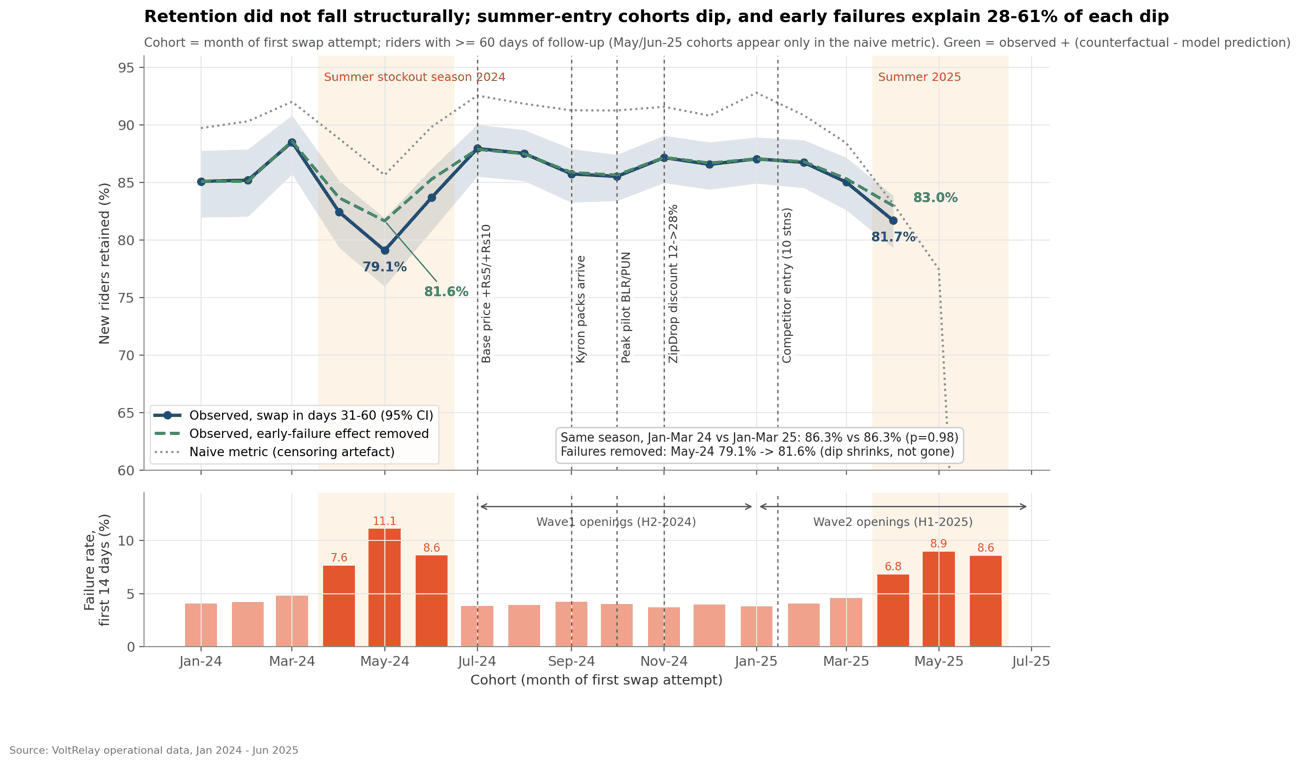

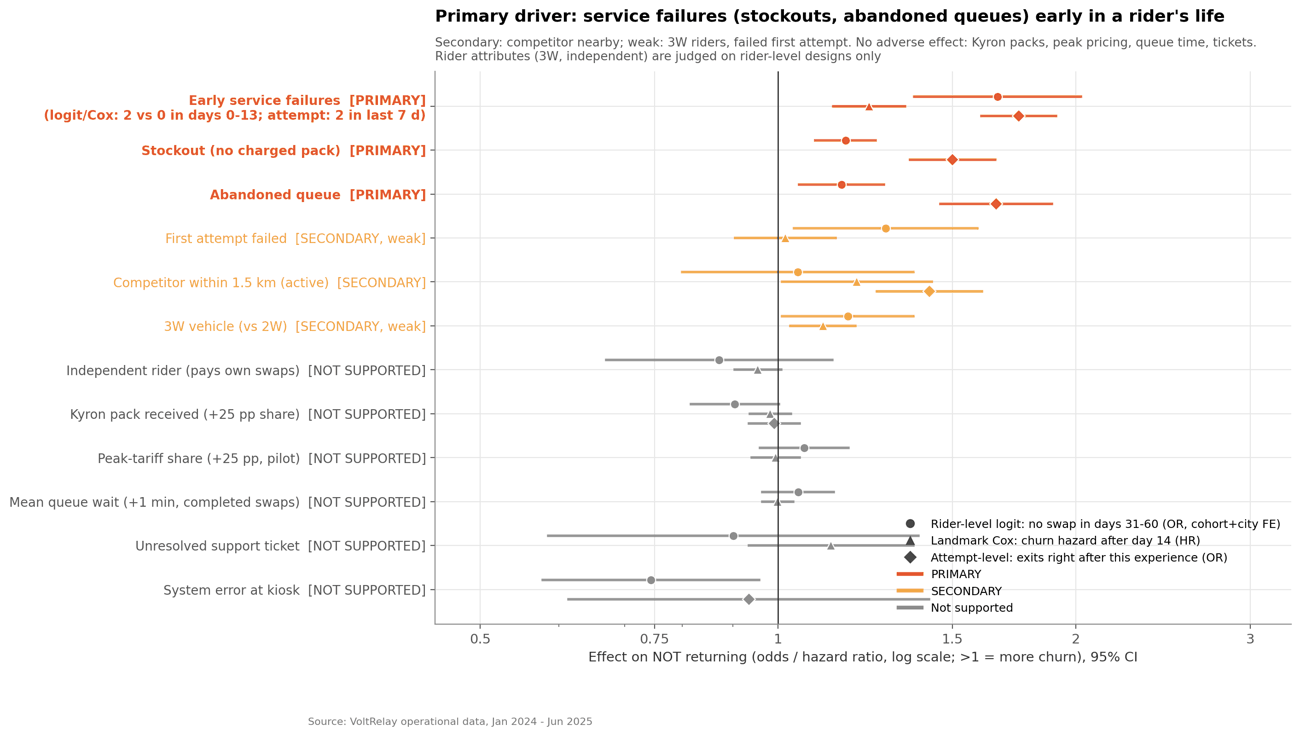

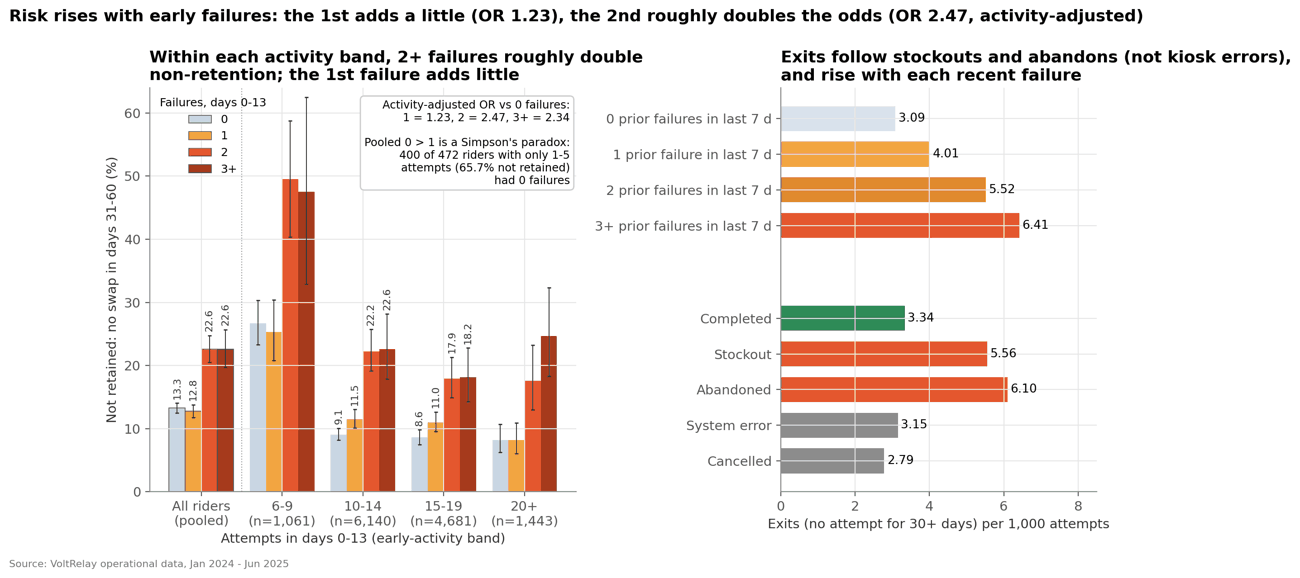

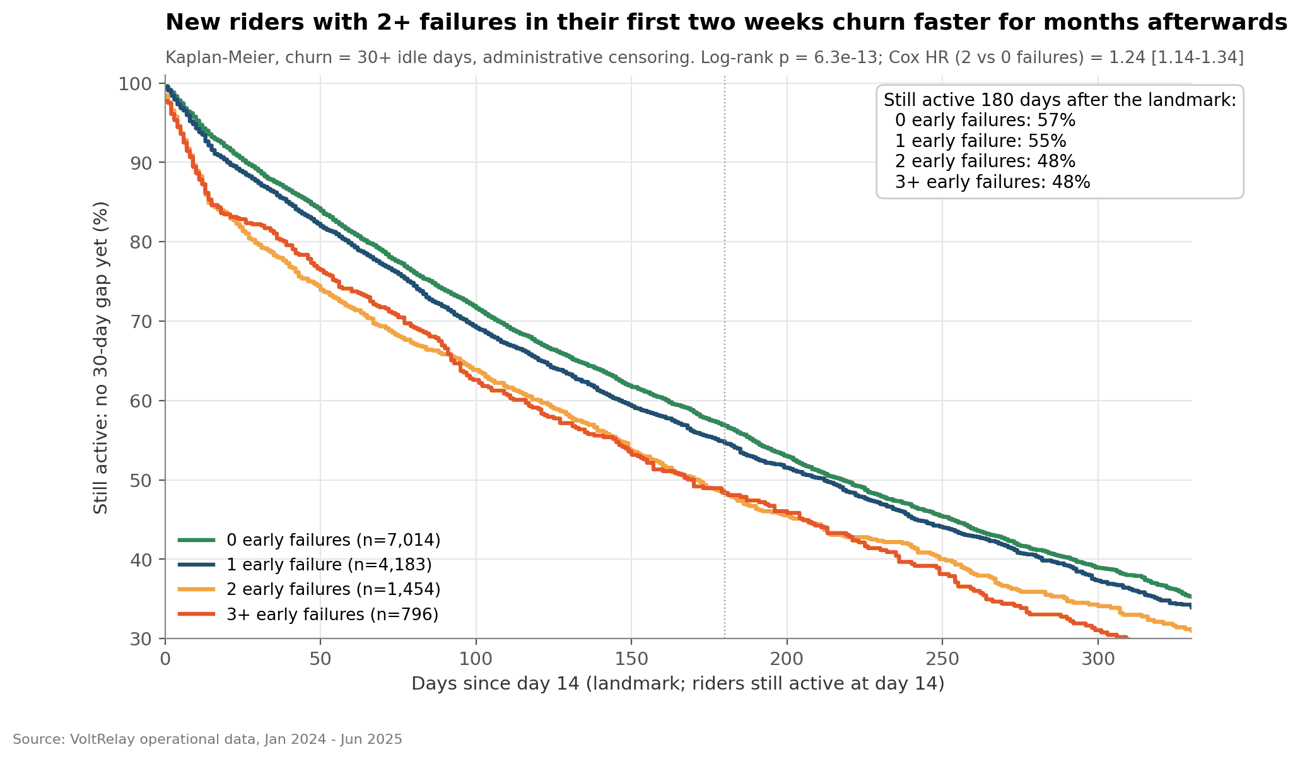

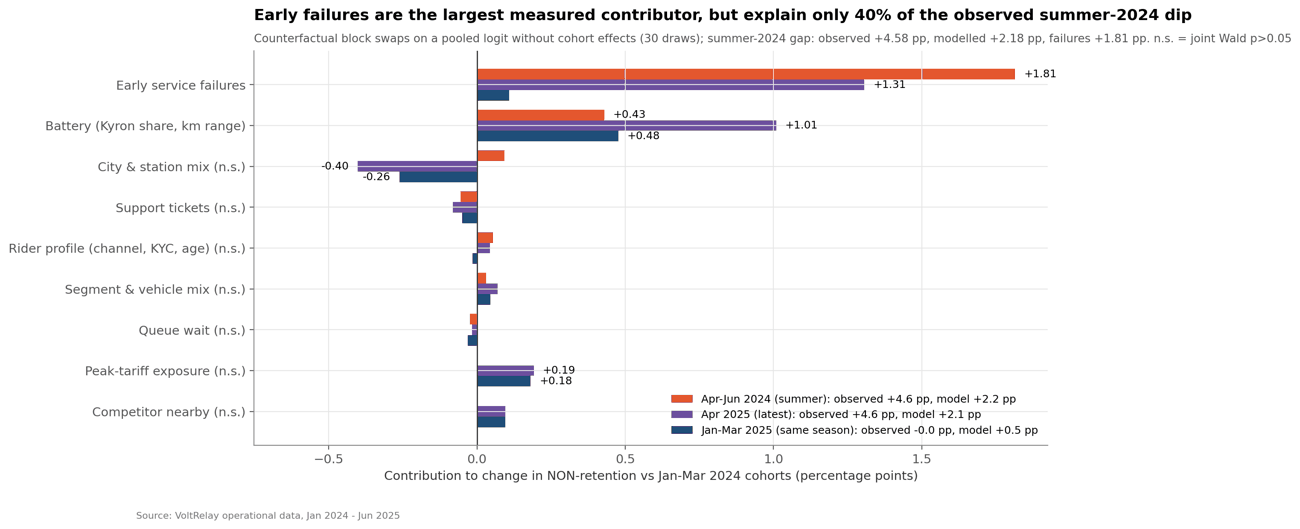

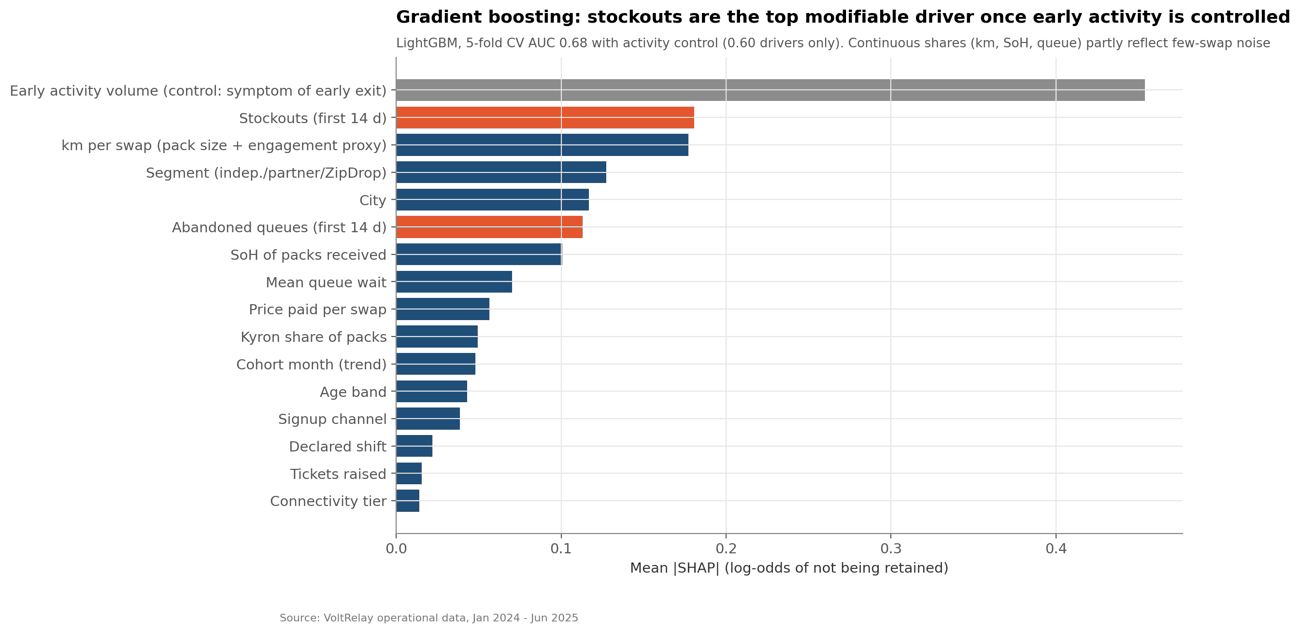

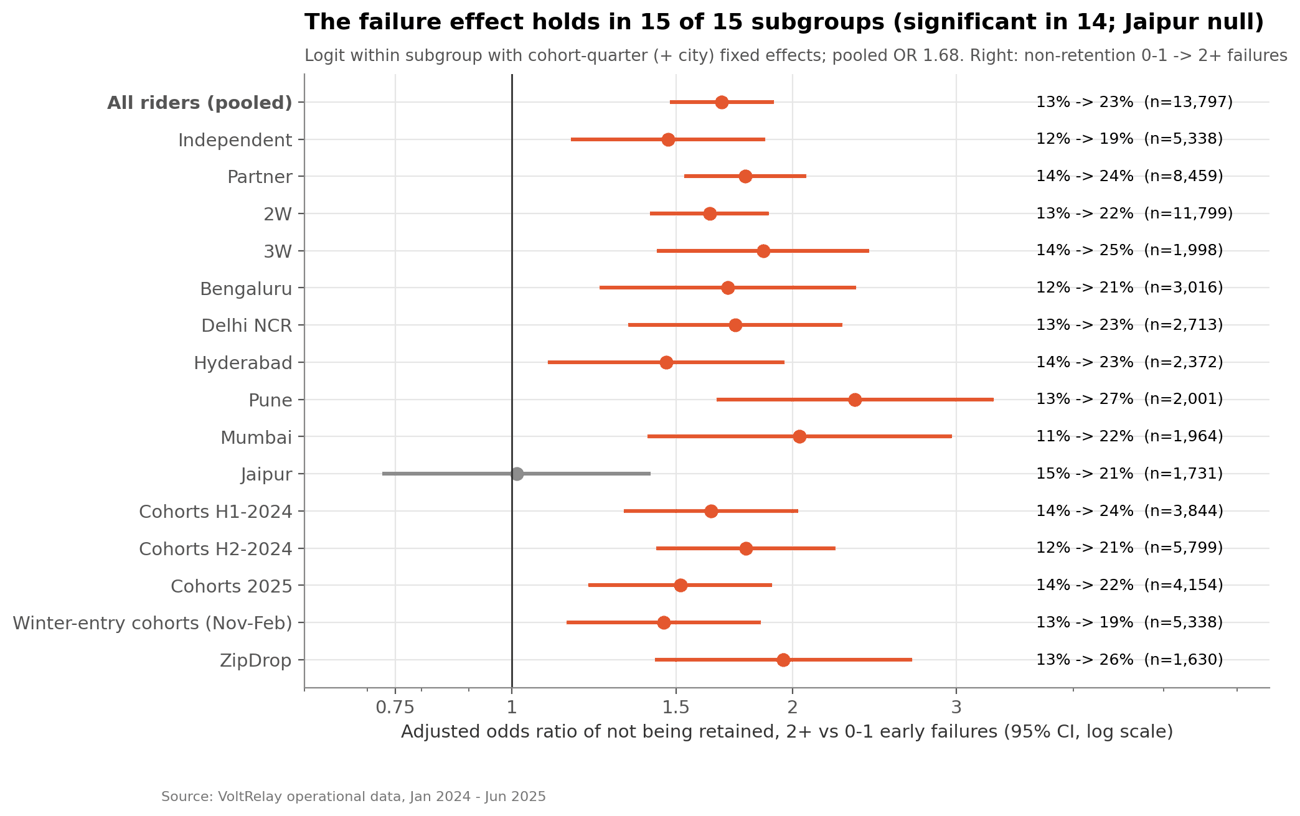

Figures saved: ['q6_01_cohort_retention_trend.png', 'q6_02_cohort_survival_curves.png', 'q6_03_driver_effects.png', 'q6_04_dose_response.png', 'q6_05_km_by_early_failures.png', 'q6_06_decline_decomposition.png', 'q6_07_shap_importance.png', 'q6_08_segment_stability.png']


In [157]:
# ---- Figure 1 (HERO): cohort retention trend with interventions
cp = coh.copy()
cp["coh"] = pd.to_datetime(cp["coh"])
ce_ = cp[cp["ret"].notna()]
fig, (ax, axf) = plt.subplots(2, 1, figsize=(12.5, 8.2), sharex=True, gridspec_kw={"height_ratios": [3.1, 1.15], "hspace": 0.08})
ax.fill_between(ce_["coh"], 100 * ce_["lo"], 100 * ce_["hi"], color=PALETTE["primary"], alpha=0.15, lw=0)
ax.plot(ce_["coh"], 100 * ce_["ret"], "-o", color=PALETTE["primary"], lw=2.6, ms=5.5, label="Observed, swap in days 31-60 (95% CI)")
ax.plot(ce_["coh"], 100 * ce_["ret_fail_neutral"], "--", color=PALETTE["good"], lw=2.2,
        label="Observed, early-failure effect removed")
ax.plot(cp["coh"], 100 * cp["naive"], ":", color=PALETTE["muted"], lw=1.6, label="Naive metric (censoring artefact)")
for i_ in ce_.index:
    if ce_.loc[i_, "coh"].month in (5,) or ce_.loc[i_, "coh"] == pd.Timestamp("2025-04-01"):
        ax.annotate(f"{100*ce_.loc[i_, 'ret']:.1f}%", (ce_.loc[i_, "coh"], 100 * ce_.loc[i_, "ret"]), textcoords="offset points",
                    xytext=(0, -16), ha="center", fontsize=10, color=PALETTE["primary"], fontweight="bold")
        is_may = ce_.loc[i_, "coh"].month == 5
        ax.annotate(f"{100*ce_.loc[i_, 'ret_fail_neutral']:.1f}%", (ce_.loc[i_, "coh"], 100 * ce_.loc[i_, "ret_fail_neutral"]),
                    textcoords="offset points", xytext=(30, -58) if is_may else (15, 3), ha="left", fontsize=10,
                    color="#2E7D4F", fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="#2E7D4F", lw=0.9) if is_may else None)
ax.set_ylim(60, 96)
ax.set_ylabel("New riders retained (%)")
events_v = [("2024-07-01", "Base price +Rs5/+Rs10"), ("2024-09-01", "Kyron packs arrive"), ("2024-10-01", "Peak pilot BLR/PUN"),
            ("2024-11-01", "ZipDrop discount 12->28%"), ("2025-01-15", "Competitor entry (10 stns)")]
for d_, lab in events_v:
    x_ = pd.Timestamp(d_)
    for a_ in (ax, axf):
        a_.axvline(x_, color="#555555", lw=0.9, ls=(0, (3, 3)))
    ax.text(x_ + pd.Timedelta(days=3), 69.3, lab, fontsize=9, color="#333333", rotation=90, va="bottom", ha="left",
            bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.8))
for s_, e_, lab in [("2024-04-01", "2024-06-30", "Summer stockout season 2024"), ("2025-04-01", "2025-06-30", "Summer 2025")]:
    for a_ in (ax, axf):
        a_.axvspan(pd.Timestamp(s_) - pd.Timedelta(days=14), pd.Timestamp(e_) - pd.Timedelta(days=14), color=PALETTE["warn"], alpha=0.12, lw=0)
    ax.text(pd.Timestamp(s_) - pd.Timedelta(days=10), 94.6, lab, fontsize=9, color="#9a6a00", va="top")
c1 = cmp_tab.iloc[0]
may24 = cfc[cfc["coh"] == "2024-05-01"].iloc[0]
ax.text(pd.Timestamp("2024-08-25"), 61.0,
        f"Same season, Jan-Mar 24 vs Jan-Mar 25: {pct(c1['ret_a'])} vs {pct(c1['ret_b'])} (p={c1['p_value']:.2f})\n"
        f"Failures removed: May-24 {pct(may24['ret_obs'])} -> {pct(may24['ret_fail_neutral'])} (dip shrinks, not gone)",
        fontsize=9.2, color="#222222", va="bottom", bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#cccccc"))
ax.legend(loc="lower left", fontsize=9.5, framealpha=0.9, frameon=True, edgecolor="#dddddd")
title_sub(ax, f"Retention did not fall structurally; summer-entry cohorts dip, and early failures explain "
              f"{100 * min(dip_closed.values()):.0f}-{100 * max(dip_closed.values()):.0f}% of each dip",
          "Cohort = month of first swap attempt; riders with >= 60 days of follow-up (May/Jun-25 cohorts appear only in the naive metric). "
          "Green = observed + (counterfactual - model prediction)")
axf.bar(cp["coh"], 100 * cp["fail_per_att"], width=21, color=[PALETTE["accent"] if v > 0.06 else "#F0A28C" for v in cp["fail_per_att"]])
for x_, v_ in zip(cp["coh"], cp["fail_per_att"]):
    if v_ > 0.06:
        axf.text(x_, 100 * v_ + 0.4, f"{100*v_:.1f}", ha="center", fontsize=8.5, color=PALETTE["accent"])
axf.set_ylim(0, 14.5)
axf.set_ylabel("Failure rate,\nfirst 14 days (%)")
for s_, e_, lab in [("2024-07-01", "2024-12-31", "Wave1 openings (H2-2024)"), ("2025-01-01", "2025-06-30", "Wave2 openings (H1-2025)")]:
    axf.annotate("", xy=(pd.Timestamp(e_), 13.2), xytext=(pd.Timestamp(s_), 13.2),
                 arrowprops=dict(arrowstyle="<->", color="#555555", lw=1))
    axf.text(pd.Timestamp(s_) + (pd.Timestamp(e_) - pd.Timestamp(s_)) / 2, 11.4, lab, ha="center", fontsize=9, color="#555555")
axf.set_xlabel("Cohort (month of first swap attempt)")
axf.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
save_fig(fig, "q6_01_cohort_retention_trend")

# ---- Figure 3 (HERO): driver effects across three designs
cls_col = {"PRIMARY": PALETTE["accent"], "SECONDARY": PALETTE["warn"], "NOT SUPPORTED": PALETTE["muted"]}
fd = drv.iloc[::-1].reset_index(drop=True)
WEAK = {"3W vehicle (vs 2W)", "First attempt failed"}
ylab = {"Early service failures (2 vs 0 in days 0-13; attempt level: 2 in last 7 d)":
        "Early service failures  [PRIMARY]\n(logit/Cox: 2 vs 0 in days 0-13; attempt: 2 in last 7 d)"}
fig, ax = plt.subplots(figsize=(12, 7.8))
for i, r_ in fd.iterrows():
    col = cls_col[r_["class"]]
    for off, (o, lo, hi, mk, lab) in zip([0.22, 0.0, -0.22], [(r_["logit_OR"], r_["logit_lo"], r_["logit_hi"], "o", "Rider-level logit: not retained D31-60 (OR)"),
                                                              (r_["cox_HR"], r_["cox_lo"], r_["cox_hi"], "^", "Landmark Cox: churn hazard after day 14 (HR)"),
                                                              (r_["exit_OR"], r_["exit_lo"], r_["exit_hi"], "D", "Attempt-level: leaves right after this experience (OR)")]):
        if np.isnan(o) or (mk == "D" and r_["driver"] in SEGMENT_ATTRS):
            continue   # attempt-level rates for rider attributes are confounded by swap frequency (not used to classify)
        ax.plot([lo, hi], [i + off] * 2, color=col, lw=2, alpha=0.9)
        ax.plot(o, i + off, mk, color=col, ms=7, mec="white", mew=0.8)
ax.axvline(1, color="#333333", lw=1)
ax.set_yticks(range(len(fd)))
ax.set_yticklabels([ylab.get(d_, f"{d_}  [{c_}{', weak' if d_ in WEAK else ''}]") for d_, c_ in zip(fd["driver"], fd["class"])], fontsize=10)
for t_, c_ in zip(ax.get_yticklabels(), fd["class"]):
    t_.set_color(cls_col[c_] if c_ != "NOT SUPPORTED" else "#555555")
    t_.set_fontweight("bold" if c_ == "PRIMARY" else "normal")
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(0.45, 3.3)
ax.set_xlabel("Effect on NOT returning (odds / hazard ratio, log scale; >1 = more churn), 95% CI")
from matplotlib.lines import Line2D  # noqa: E402
hand = [Line2D([], [], marker="o", ls="", color="#444444", label="Rider-level logit: no swap in days 31-60 (OR, cohort+city FE)"),
        Line2D([], [], marker="^", ls="", color="#444444", label="Landmark Cox: churn hazard after day 14 (HR)"),
        Line2D([], [], marker="D", ls="", color="#444444", label="Attempt-level: exits right after this experience (OR)"),
        Line2D([], [], color=PALETTE["accent"], lw=3, label="PRIMARY"), Line2D([], [], color=PALETTE["warn"], lw=3, label="SECONDARY"),
        Line2D([], [], color=PALETTE["muted"], lw=3, label="Not supported")]
ax.legend(handles=hand, loc="lower right", fontsize=9)
no_minor_labels(ax)
title_sub(ax, "Primary driver: service failures (stockouts, abandoned queues) early in a rider's life",
          "Secondary: competitor nearby; weak: 3W riders, failed first attempt. No adverse effect: Kyron packs, peak pricing, queue time, "
          "tickets.\nRider attributes (3W, independent) are judged on rider-level designs only")
save_fig(fig, "q6_03_driver_effects")

# ---- Figure 4: dose-response (rider level) + trigger (attempt level)
fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})
grp_cols = {"0": "#C9D6E3", "1": PALETTE["warn"], "2": PALETTE["accent"], "3+": "#A63A1C"}
x_groups = [("All riders\n(pooled)", None), ("6-9", "6-9"), ("10-14", "10-14"), ("15-19", "15-19"), ("20+", "20+")]
w = 0.2
for j, g_ in enumerate(["0", "1", "2", "3+"]):
    for k_, (xl, band) in enumerate(x_groups):
        sub_ = D if band is None else D[D["att_band"] == band]
        sub_ = sub_[sub_["fail_grp"] == g_]
        if len(sub_) < 40:
            axa.text(k_ + (j - 1.5) * w, 1.0, "n<40", rotation=90, fontsize=7.5, ha="center", color="#777777")
            continue
        r_, (lo_, hi_) = sub_["y"].mean(), wilson(sub_["y"].sum(), len(sub_))
        axa.bar(k_ + (j - 1.5) * w, 100 * r_, width=w, color=grp_cols[g_], label=g_ if k_ == 0 else None,
                edgecolor="#555555" if band is None else "none", lw=0.6)
        axa.errorbar(k_ + (j - 1.5) * w, 100 * r_, yerr=[[100 * (r_ - lo_)], [100 * (hi_ - r_)]], fmt="none", ecolor="#333333", lw=0.7, capsize=1.5)
        if band is None or band in ("10-14", "15-19"):
            axa.text(k_ + (j - 1.5) * w, 100 * hi_ + 0.6, f"{100*r_:.1f}", fontsize=8, ha="center", rotation=90, va="bottom", color="#333333")
axa.axvline(0.5, color="#999999", lw=0.8, ls=":")
axa.set_xticks(range(len(x_groups)))
axa.set_xticklabels([xl if band is None else f"{xl}\n(n={int((D['att_band'] == band).sum()):,})" for xl, band in x_groups])
axa.set_xlabel("Attempts in days 0-13 (early-activity band)")
axa.set_ylabel("Not retained: no swap in days 31-60 (%)")
axa.set_ylim(0, 64)
axa.legend(title="Failures, days 0-13", ncol=1, fontsize=9, title_fontsize=9, loc="upper left")
o1, o2, o3 = (np.exp(mA_att.params["C(fail_grp, Treatment('0'))[T." + g + "]"]) for g in ["1", "2", "3+"])
axa.text(0.985, 0.97, f"Activity-adjusted OR vs 0 failures:\n1 = {o1:.2f}, 2 = {o2:.2f}, 3+ = {o3:.2f}\n\n"
         f"Pooled 0 > 1 is a Simpson's paradox:\n{int((low['fail_grp'] == '0').sum())} of {len(low)} riders with only 1-5\n"
         f"attempts ({pct(low['y'].mean())} not retained)\nhad 0 failures", transform=axa.transAxes, fontsize=8.8,
         va="top", ha="right", bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc"))
axa.set_title("Within each activity band, 2+ failures roughly double\nnon-retention; the 1st failure adds little")
rate_o = raw_at.loc[["completed", "stockout", "abandoned", "system_error", "cancelled"], "churn_rate"] * 1000
rate_p = raw_pf["churn_rate"] * 1000
labels_b = ["Completed", "Stockout", "Abandoned", "System error", "Cancelled"]
cb = [PALETTE["good"], PALETTE["accent"], PALETTE["accent"], PALETTE["muted"], PALETTE["muted"]]
axb.barh(np.arange(5) + 5.6, rate_o.values, color=cb, height=0.7)
axb.barh(np.arange(4), rate_p.values, color=[PALETTE["light"], PALETTE["warn"], "#E08A2E", PALETTE["accent"]], height=0.7)
for yv_, v_ in zip(list(np.arange(5) + 5.6) + list(np.arange(4)), list(rate_o.values) + list(rate_p.values)):
    axb.text(v_ + 0.08, yv_, f"{v_:.2f}", va="center", fontsize=9.5)
axb.set_yticks(list(np.arange(5) + 5.6) + list(range(4)))
axb.set_yticklabels(labels_b + [f"{k} prior failure{'s' if k != '1' else ''} in last 7 d" for k in ["0", "1", "2", "3+"]])
axb.invert_yaxis()
axb.set_xlabel("Exits (no attempt for 30+ days) per 1,000 attempts")
axb.set_title("Exits follow stockouts and abandons (not kiosk errors),\nand rise with each recent failure")
axb.set_xlim(0, 8.5)
fig.subplots_adjust(wspace=0.55)
fig.suptitle(f"Risk rises with early failures: the 1st adds a little (OR {o1:.2f}), the 2nd roughly doubles the odds "
             f"(OR {o2:.2f}, activity-adjusted)", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
save_fig(fig, "q6_04_dose_response")

# ---- Figure 5 (HERO): KM by early failures, landmark day 14
fig, ax = plt.subplots(figsize=(10.5, 5.8))
kcol = {"0": PALETTE["good"], "1": PALETTE["primary"], "2": PALETTE["warn"], "3+": PALETTE["accent"]}
for g_, (kmf, n_) in km_fail.items():
    sf = kmf.survival_function_
    ax.step(sf.index, 100 * sf.iloc[:, 0], where="post", color=kcol[g_], lw=2.3,
            label=f"{g_} early failure{'' if g_ == '1' else 's'} (n={n_:,})")
s180_txt = "Still active 180 days after the landmark:\n" + "\n".join(
    f"  {g_} early failure{'' if g_ == '1' else 's'}: {100*float(k_.survival_function_at_times(180).iloc[0]):.0f}%" for g_, (k_, _) in km_fail.items())
ax.text(0.70, 0.97, s180_txt, transform=ax.transAxes, va="top", fontsize=10, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#cccccc"))
ax.axvline(180, color="#999999", lw=0.8, ls=":")
ax.set_xlim(0, 330)
ax.set_ylim(30, 101)
ax.set_xlabel("Days since day 14 (landmark; riders still active at day 14)")
ax.set_ylabel("Still active: no 30-day gap yet (%)")
title_sub(ax, "New riders with 2+ failures in their first two weeks churn faster for months afterwards",
          f"Kaplan-Meier, churn = 30+ idle days, administrative censoring. Log-rank p = {lr.p_value:.1e}; "
          f"Cox HR (2 vs 0 failures) = {CX('f2'):.2f} [{CX('f2','lo'):.2f}-{CX('f2','hi'):.2f}]")
ax.legend(loc="lower left")
save_fig(fig, "q6_05_km_by_early_failures")

# ---- Figure 6: decomposition
show_c = ["Apr-Jun 2024 (summer)", "Apr 2025 (latest)", "Jan-Mar 2025 (same season)"]
blocks_order = piv[show_c[0]].abs().sort_values(ascending=True).index.tolist()
fig, ax = plt.subplots(figsize=(12, 6))
hb = 0.26
for j, (c_, colr) in enumerate(zip(show_c, [PALETTE["accent"], SERIES[4], PALETTE["primary"]])):
    vals = piv.loc[blocks_order, c_]
    ys = np.arange(len(blocks_order)) + (1 - j) * hb
    ax.barh(ys, vals, height=hb, color=colr,
            label=f"{c_}: observed {gap_line.loc[c_, 'obs_gap_pp']:+.1f} pp, model {gap_line.loc[c_, 'pred_gap_pp']:+.1f} pp")
    for y_, v_ in zip(ys, vals):
        if abs(v_) >= 0.15:
            ax.text(v_ + (0.03 if v_ >= 0 else -0.03), y_, f"{v_:+.2f}", va="center", ha="left" if v_ >= 0 else "right", fontsize=9)
ax.axvline(0, color="#333333", lw=1)
ax.set_yticks(range(len(blocks_order)))
ax.set_yticklabels([b + ("" if block_p[b] < 0.05 else " (n.s.)") for b in blocks_order])
xl_ = ax.get_xlim()
ax.set_xlim(min(xl_[0], piv.loc[:, show_c].min().min() - 0.35), xl_[1])   # room for negative value labels
ax.set_xlabel("Contribution to change in NON-retention vs Jan-Mar 2024 cohorts (percentage points)")
title_sub(ax, f"Early failures are the largest measured contributor, but explain only {pct(fail_expl / summer_gap, 0)} "
              f"of the observed summer-2024 dip",
          f"Counterfactual block swaps on a pooled logit without cohort effects (30 draws); summer-2024 gap: observed "
          f"{summer_gap:+.2f} pp, modelled {summer_pred:+.2f} pp, failures {fail_expl:+.2f} pp. n.s. = joint Wald p>0.05")
ax.legend(loc="lower right", fontsize=9)
save_fig(fig, "q6_06_decline_decomposition")

# ---- Figure 7: SHAP importance (with activity control)
lab_map = {"e_att": "Early activity volume (control: symptom of early exit)", "e_stockout": "Stockouts (first 14 d)",
           "e_abandon": "Abandoned queues (first 14 d)", "e_syserr": "System errors", "e_cancel": "Cancellations",
           "first_fail": "First attempt failed", "q_mean": "Mean queue wait", "q_long_n": "Waits > 10 min",
           "kyron_share": "Kyron share of packs", "soh_out": "SoH of packs received",
           "km_mean": "km per swap (pack size + engagement proxy)",
           "price_mean": "Price paid per swap", "peak_share": "PEAK-tariff share", "comp_share": "Competitor-active share",
           "tk_n": "Tickets raised", "tk_unres": "Unresolved tickets", "w3": "3W vehicle", "kyc_no": "KYC not verified",
           "coh_idx": "Cohort month (trend)", "segment": "Segment (indep./partner/ZipDrop)", "signup_channel": "Signup channel",
           "age_band": "Age band", "main_city": "City", "main_wave": "Station wave", "main_gen": "Charger generation",
           "main_conn": "Connectivity tier", "declared_shift": "Declared shift"}
top = imp2.head(16).iloc[::-1]
fig, ax = plt.subplots(figsize=(10.5, 6.4))
cols_ = [PALETTE["muted"] if f == "e_att" else (PALETTE["accent"] if f in ("e_stockout", "e_abandon", "first_fail") else PALETTE["primary"]) for f in top["feature"]]
ax.barh([lab_map.get(f, f) for f in top["feature"]], top["mean_abs_shap"], color=cols_)
ax.set_xlabel("Mean |SHAP| (log-odds of not being retained)")
title_sub(ax, "Gradient boosting: stockouts are the top modifiable driver once early activity is controlled",
          f"LightGBM, 5-fold CV AUC {np.mean(aucs2):.2f} with activity control ({np.mean(aucs):.2f} drivers only). "
          "Continuous shares (km, SoH, queue) partly reflect few-swap noise")
save_fig(fig, "q6_07_shap_importance")

# ---- Figure 8: stability of the failure effect across segments
sb = stab.dropna(subset=["lo"]).iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 6.4))
for i, r_ in sb.iterrows():
    c_ = PALETTE["accent"] if r_["p"] < 0.05 else PALETTE["muted"]
    ax.plot([r_["lo"], r_["hi"]], [i, i], color=c_, lw=2.2)
    ax.plot(r_["OR_2plus"], i, "o", color=c_, ms=7)
    ax.text(3.65, i, f"{100*r_['nr_0_1']:.0f}% -> {100*r_['nr_2p']:.0f}%  (n={int(r_['n']):,})", va="center", fontsize=9)
ax.axvline(1, color="#333333", lw=1)
ax.set_yticks(range(len(sb)))
ax.set_yticklabels(["All riders (pooled)" if s_ == "All" else s_ for s_ in sb["segment"]])
for t_ in ax.get_yticklabels():
    if t_.get_text().startswith("All riders"):
        t_.set_fontweight("bold")
ax.set_xscale("log")
ax.set_xticks([0.75, 1, 1.5, 2, 3])
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(0.6, 6.5)
ax.set_xlabel("Adjusted odds ratio of not being retained, 2+ vs 0-1 early failures (95% CI, log scale)")
no_minor_labels(ax)
null_subs = sub_stab.loc[sub_stab["p"] >= 0.05, "segment"].tolist()
title_sub(ax, f"The failure effect holds in {n_stab_pos} of {n_sub} subgroups (significant in {n_stab_sig}"
              + (f"; {', '.join(null_subs)} null)" if null_subs else ")"),
          f"Logit within subgroup with cohort-quarter (+ city) fixed effects; pooled OR {st_all['OR_2plus']:.2f}. "
          "Right: non-retention 0-1 -> 2+ failures")
save_fig(fig, "q6_08_segment_stability")
print("Figures saved:", sorted(p.name for p in FIG.glob("q6_*.png")))

In [158]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 211 objects


## 11. Deep dive · Support-ticket text

# Q8 · Support-ticket text: does the free text add to the category and resolution fields?

**Question.** All 44,000 support tickets carry a rider comment (English + Hinglish). Does that text tell us anything
the agent-assigned `category`, `priority` and resolution fields do not? The data documentation warns that categories
are agent-assigned and unverified, that battery range problems are sometimes filed as `other` or `app_issue`, and
that comments sometimes blame the vehicle rather than the battery.

**Approach.**
1. Only 89 distinct comment strings exist, so every template is labelled with transparent keyword rules (after
   normalising three recurring typos) and reviewed one by one -> `outputs/tables/q8_comment_taxonomy.csv`.
2. Agent category vs text-derived issue (confusion matrix).
3. Validate labels against independent structured evidence that the text cannot influence: the rider's vehicle
   class, timing relative to Kyron's arrival (Sep-2024), a city-level Kyron dose test with placebo categories, the
   ticket's `battery_id` (the pack the rider inserted at a recent attempt) -> supplier, SoH and attempt outcome,
   and the rider's own logged events.
4. Quantify what the text adds: hidden battery complaints, rider-reported range (km), pricing words around the
   pilot, urgency/repeat claims, competitor mentions -> churn. Correct CSAT non-response with inverse-probability
   weighting (IPW) and bound what IPW cannot fix.

In [159]:
import sys
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def _find_root() -> Path:
    cands = [PROJECT_ROOT] if "PROJECT_ROOT" in globals() else []
    cands += [Path.cwd(), Path.cwd().parent]
    for c in cands:
        if (c / "src" / "common.py").exists():
            return c
    raise FileNotFoundError("project root with src/common.py not found")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401,F403

set_style()
warnings.filterwarnings("ignore")
T0 = time.time()
pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(230)
pl.Config.set_fmt_str_lengths(60)
RNG = np.random.default_rng(59500)
INK, INK2 = "#222222", "#555555"


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def show(title, df):
    print(f"\n=== {title} ===")
    print(df)


def headline(fig, title, subtitle=None):
    """Left-aligned insight title + grey subtitle; returns the `top` to pass to tight_layout(rect=...)."""
    H = fig.get_figheight()
    # fig.text (not suptitle) so tight_layout does not reserve the title space twice
    fig.text(0.012, 1 - 0.10 / H, title, ha="left", va="top", fontsize=14, fontweight="bold", color=INK)
    n_sub = 0
    if subtitle:
        n_sub = subtitle.count("\n") + 1
        fig.text(0.012, 1 - 0.46 / H, subtitle, ha="left", va="top", fontsize=10.5, color=INK2)
    return 1 - (0.55 + 0.21 * n_sub) / H

## 1 · Scope
Tickets outside Jan-2024..Jun-2025 (86) and tickets raised at the two internal test stations (535) are excluded,
consistent with the network KPIs. Every ticket has a comment, so "tickets with a comment" = the scoped table.

In [160]:
tk_all = tickets()
tk = tk_all.filter(pl.col("in_window") & ~pl.col("is_test"))
N = tk.height
print(f"tickets raw {tk_all.height:,} | out-of-window {int((~tk_all['in_window']).sum()):,} | at test stations "
      f"{int(tk_all['is_test'].sum()):,} | scoped {N:,} | scoped with a comment {int(tk['rider_comment'].is_not_null().sum()):,} "
      f"| distinct comment strings (all tickets) {tk_all['rider_comment'].n_unique()}")

tickets raw 44,000 | out-of-window 86 | at test stations 535 | scoped 43,380 | scoped with a comment 43,380 | distinct comment strings (all tickets) 89


## 2 · Comment taxonomy: keyword rules + template-level review
Rules run on a normalised comment (lower case; typos `staion`->station, `battry`->battery, `rnage`->range).
**First matching rule wins.** The order puts station-level stock-out phrases ("sab batteries discharge the" = *all
batteries were discharged*) ahead of the generic battery/range rule, and range words ahead of vehicle words, so
"vehicle not giving proper range" is a range complaint while "scooter weak lag raha hai" is vehicle-phrased.
Competitor/switching and praise rules are included on purpose: a zero count is then a finding, not an omission.

In [161]:
TYPO_FIX = [(r"staion", "station"), (r"battry", "battery"), (r"rnage", "range")]
RULES = [  # (text_issue, regex) - evaluated in order on the normalised comment
    ("competitor_switching", r"competitor|switch(ing)? to|other (company|app|network)|dusri company|chhod|band kar|uninstall|leave"),
    ("other_praise", r"thank|great service|good service|accha|badhiya|shukriya|well done"),
    ("no_battery_stockout", r"no battery available|charged battery nahi|empty station|batteries discharge the|no charged"),
    ("long_queue", r"queue|lambi line|lamba|line thi|waited \d+ min"),
    ("billing_wrong_amount", r"galat|wrong amount|double charge|refund"),
    ("pricing_surcharge", r"surcharge|extra amount|charged extra|price|mehenga|costly"),
    ("station_hw_system", r"\bqr\b|scan|cabinet|door|slot|machine"),
    ("app_tech", r"\bapp\b|crash|login|otp"),
    ("battery_range_health", r"range|discharge fast|dying at -?\d+ ?km|battery"),
    ("vehicle_phrased", r"vehicle|scooter|bike|gaadi|motor"),
]
ISSUE_LABEL = {
    "battery_range_health": "Battery range / health",
    "vehicle_phrased": "Vehicle-phrased\n(battery-likely)",
    "no_battery_stockout": "No battery /\nstock-out",
    "long_queue": "Long queue",
    "billing_wrong_amount": "Billing:\nwrong amount",
    "pricing_surcharge": "Pricing:\nsurcharge / extra",
    "app_tech": "App / tech",
    "station_hw_system": "Station hardware\n(QR scan)",
    "competitor_switching": "Competitor /\nswitching",
    "other_praise": "Other /\npraise",
}
ISSUE_ORDER = list(ISSUE_LABEL)
HINDI = r"\b(hai|nahi|ho|gaya|raha|lag|lagti|mein|ki|bahut|bohot|kal|sab|laga|diya|bina|bataye|kata|galat|koi|mila|thi|tha|ke|liye|aaj|aajkal|pe|itna|lamba|lambi|dikkat|gaadi|se|ka)\b"


def normalise(s: str) -> str:
    s = s.lower().strip()
    for a, b in TYPO_FIX:
        s = re.sub(a, b, s)
    return s


def classify(norm: str):
    for lab, rx in RULES:
        if re.search(rx, norm):
            return lab, rx
    return "unmatched", ""


REVIEW = {  # template-level review of each rule outcome
    "battery_range_health": ("battery_range_health", "Range/discharge words or 'dying at X km'; correctly filed as low_range by agents."),
    "vehicle_phrased": ("battery_range_health", "Blames the vehicle with no battery or range word; filed as 'other'. Battery label rests on "
                        "the structured fingerprint in section 4 (2W-only, same-season step-up, responds to the Kyron city dose like low_range)."),
    "no_battery_stockout": ("no_battery_stockout", "Station had no charged pack; validated against the rider's logged stock-outs (section 7)."),
    "long_queue": ("long_queue", "Queue/wait wording."),
    "billing_wrong_amount": ("billing_pricing", "Wrong deduction."),
    "pricing_surcharge": ("billing_pricing", "Price level / surcharge wording; tested against the base-price change and the peak pilot (section 6)."),
    "station_hw_system": ("station_hw_system", "QR scan at cabinet: ambiguous between app and cabinet hardware; tested against station "
                          "system-error rates (section 9). Ticket population carries the battery fingerprint (section 4)."),
    "app_tech": ("app_tech", "Text agrees with app_issue, but the ticket population carries the battery fingerprint (section 4; ~97% "
                 "battery-like by 3W mix) and no logged app failure; counted in the central battery estimate, not in the wording floor."),
}

tpl = (tk_all.group_by("rider_comment").agg(pl.len().alias("n_tickets_all"), pl.col("category").n_unique().alias("n_categories"),
                                            pl.col("category").mode().first().alias("agent_category"))
       .join(tk.group_by("rider_comment").agg(pl.len().alias("n_tickets_scoped")), on="rider_comment", how="left")
       .with_columns(pl.col("n_tickets_scoped").fill_null(0))
       .sort(["n_tickets_all", "rider_comment"], descending=[True, False]))
rows = []
for i, r in enumerate(tpl.iter_rows(named=True), 1):
    norm = normalise(r["rider_comment"])
    lab, rx = classify(norm)
    km = re.search(r"dying at (-?\d+) ?km", norm)
    rev, note = REVIEW.get(lab, (lab, ""))
    rows.append(dict(
        template_id=f"T{i:02d}", rider_comment=r["rider_comment"], n_tickets_all=r["n_tickets_all"], n_tickets_scoped=r["n_tickets_scoped"],
        agent_category=r["agent_category"], categories_per_template=r["n_categories"], normalised_text=norm,
        language="Hinglish" if re.search(HINDI, norm) else "English",
        has_typo=bool(re.search(r"staion|battry|rnage", r["rider_comment"].lower())),
        text_issue=lab, rule_matched=rx,
        mentions_vehicle=bool(re.search(r"vehicle|scooter|bike|gaadi", norm)),
        mentions_battery_or_range=bool(re.search(r"battery|batteries|range|discharge|dying at", norm)),
        urgency_repeat=bool(re.search(r"again|third time|roz|har baar|phir se", norm)),
        urgency_business_impact=bool(re.search(r"\blate\b|delivery|order|customer", norm)),
        persistence_marker=bool(re.search(r"since morning|kal se|aajkal|\baaj\b|this week|\d+ min", norm)),
        km_reported=int(km.group(1)) if km else None,
        reviewed_true_issue=rev, review_note=note))
tax = pl.DataFrame(rows)
tax.write_csv(TAB / "q8_comment_taxonomy.csv")
assert tax.height == 89 and (tax["categories_per_template"] == 1).all() and (tax["text_issue"] != "unmatched").all()
print(f"templates: {tax.height} | each template filed under exactly one agent category: {bool((tax['categories_per_template'] == 1).all())}")
show("templates per text issue (all tickets)", tax.group_by("text_issue").agg(pl.len().alias("templates"), pl.col("n_tickets_scoped").sum().alias("tickets"))
     .sort("tickets", descending=True))
show("language / typo / vehicle-blame shares (scoped tickets)", tax.select(
    (pl.col("n_tickets_scoped").filter(pl.col("language") == "Hinglish").sum() / pl.col("n_tickets_scoped").sum()).alias("hinglish_share"),
    (pl.col("n_tickets_scoped").filter(pl.col("has_typo")).sum() / pl.col("n_tickets_scoped").sum()).alias("typo_share"),
    pl.col("n_tickets_scoped").filter(pl.col("text_issue") == "competitor_switching").sum().alias("competitor_mentions"),
    pl.col("n_tickets_scoped").filter(pl.col("text_issue") == "other_praise").sum().alias("praise_mentions")))
show("first 25 rows of the 89-template taxonomy", tax.select("template_id", "n_tickets_scoped", "agent_category", "language", "text_issue", "rider_comment").head(25))

templates: 89 | each template filed under exactly one agent category: True

=== templates per text issue (all tickets) ===
shape: (8, 3)
┌──────────────────────┬───────────┬─────────┐
│ text_issue           ┆ templates ┆ tickets │
│ ---                  ┆ ---       ┆ ---     │
│ str                  ┆ u32       ┆ i64     │
╞══════════════════════╪═══════════╪═════════╡
│ no_battery_stockout  ┆ 8         ┆ 11486   │
│ vehicle_phrased      ┆ 3         ┆ 9361    │
│ battery_range_health ┆ 66        ┆ 6551    │
│ long_queue           ┆ 4         ┆ 5648    │
│ app_tech             ┆ 3         ┆ 3800    │
│ pricing_surcharge    ┆ 2         ┆ 3076    │
│ station_hw_system    ┆ 2         ┆ 1917    │
│ billing_wrong_amount ┆ 1         ┆ 1541    │
└──────────────────────┴───────────┴─────────┘

=== language / typo / vehicle-blame shares (scoped tickets) ===
shape: (1, 4)
┌────────────────┬────────────┬─────────────────────┬─────────────────┐
│ hinglish_share ┆ typo_share ┆ competitor_mentions ┆ 

## 3 · Agent category vs text-derived issue
Because every template is filed under exactly one category, disagreement is systematic (whole templates), not
random agent error.

In [162]:
tk = tk.join(tax.select("rider_comment", "template_id", "text_issue", "reviewed_true_issue", "language", "mentions_vehicle",
                        "urgency_repeat", "urgency_business_impact", "km_reported"), on="rider_comment", how="left")
CATS = ["low_range", "other", "app_issue", "no_battery_available", "long_queue", "billing_dispute"]
NATURAL = {"low_range": {"battery_range_health"}, "no_battery_available": {"no_battery_stockout"}, "long_queue": {"long_queue"},
           "billing_dispute": {"billing_wrong_amount", "pricing_surcharge"}, "app_issue": {"app_tech"}, "other": {"other_praise"}}
cm = (tk.group_by("category", "text_issue").agg(pl.len().alias("n")).to_pandas()
      .pivot(index="category", columns="text_issue", values="n").reindex(index=CATS, columns=ISSUE_ORDER).fillna(0).astype(int))
cm_row = cm.div(cm.sum(axis=1), axis=0)
cm.to_csv(TAB / "q8_confusion_category_vs_text.csv")
agree = tk.with_columns(pl.struct("category", "text_issue").map_elements(lambda s: s["text_issue"] in NATURAL[s["category"]],
                                                                          return_dtype=pl.Boolean).alias("agree"))
n_dis = int((~agree["agree"]).sum())
n_other = int((tk["category"] == "other").sum())
n_qr = int((tk["text_issue"] == "station_hw_system").sum())
n_app = int((tk["category"] == "app_issue").sum())
n_lr = int((tk["category"] == "low_range").sum())
bat_text = tk.filter(pl.col("text_issue").is_in(["battery_range_health", "vehicle_phrased"]))
veh_blame_share = float(bat_text["mentions_vehicle"].mean())
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(cm)
print(f"\ntext disagrees with agent category: {n_dis:,}/{N:,} = {pct(n_dis / N)} | of which 'other' (all vehicle-phrased) "
      f"{n_other:,} = {pct(n_other / N)} of tickets; QR-scan inside app_issue {n_qr:,} = {pct(n_qr / N)}")
print(f"'other' bucket: {pct(cm_row.loc['other', 'vehicle_phrased'])} vehicle-phrased; app_issue: {pct(cm_row.loc['app_issue', 'app_tech'])} app text, "
      f"{pct(cm_row.loc['app_issue', 'station_hw_system'])} QR-scan text")
print(f"battery-group wording (range words or vehicle-phrased) that blames the vehicle: {int(bat_text['mentions_vehicle'].sum()):,} = "
      f"{pct(veh_blame_share)} of {bat_text.height:,}")
rank_off = tk.group_by("category").agg(pl.len().alias("n")).with_columns((pl.col("n") / N).alias("share")).sort("n", descending=True)
show("official ranking of complaint drivers (agent category)", rank_off)
Q2_25 = pl.col("month") >= pl.date(2025, 4, 1)
grp_txt = pl.col("text_issue").replace_strict({"battery_range_health": "battery: range wording + vehicle-phrased",
                                               "vehicle_phrased": "battery: range wording + vehicle-phrased",
                                               "billing_wrong_amount": "billing/pricing", "pricing_surcharge": "billing/pricing",
                                               "app_tech": "app/QR", "station_hw_system": "app/QR"}, default=None)
rank_txt = (tk.with_columns(pl.coalesce(grp_txt, pl.col("text_issue")).alias("g")).group_by("g")
            .agg(pl.len().alias("n"), Q2_25.sum().alias("n_q2_25")).with_columns((pl.col("n") / N).alias("share"))
            .sort("n", descending=True))
n_q2 = int(tk.filter(Q2_25).height)
rank_txt = rank_txt.with_columns((pl.col("n_q2_25") / n_q2).alias("share_q2_25"))
show(f"text-derived ranking (full window and Apr-Jun 2025, n={n_q2:,})", rank_txt)

text_issue            battery_range_health  vehicle_phrased  no_battery_stockout  long_queue  billing_wrong_amount  pricing_surcharge  app_tech  station_hw_system  competitor_switching  other_praise
category                                                                                                                                                                                              
low_range                             6551                0                    0           0                     0                  0         0                  0                     0             0
other                                    0             9361                    0           0                     0                  0         0                  0                     0             0
app_issue                                0                0                    0           0                     0                  0      3800               1917                     0             0
no_ba

## 4 · Validation: do 'other' and 'app_issue' tickets look like battery complaints?
Fingerprints that the comment text cannot influence:
* **Vehicle class** - range loss is a 2W phenomenon (Kyron 2W packs degrade ~3x faster; Kyron 3W behaves normally).
  3W riders make 10% of swaps and use app chat as much as 2W riders, so genuine app/queue/billing problems should
  reach them too. A two-group mixing model on the 3W share estimates how much of `app_issue` is battery-like.
* **Timing** - same-season step change (H1-2025 vs H1-2024) in tickets per 1K 2W swaps: Kyron's share of issued 2W
  packs went from 0% (to Aug-24) to ~24-25% (Oct-24 onwards).
* **Kyron dose by city, outside summer** - Delhi NCR, Hyderabad and Jaipur received ~39% Kyron packs vs ~8.5%
  elsewhere. Change from Jul-Aug-24 (no Kyron) to Oct-Dec-24 (Kyron live, before summer), each category on its own,
  with stock-out, queue and billing tickets as placebos.
* **The ticket's own pack** - a ticket's `battery_id` is the pack the rider *inserted* at their last attempt before
  the ticket (section 4b), so the expected Kyron share must come from inserted packs (`supplier_in`), not issued
  packs (Kyron is a larger share of inserted than of issued 2W packs). The linked attempt also gives a ticket-level
  check of the category, and the pack's SoH at insertion vs same supplier, city and month.

In [163]:
ev_c = events(["is_completed", "month", "city", "vehicle_class", "supplier_out", "soh_out_pct"]).filter(pl.col("is_completed"))
sw_cmvs = (ev_c.group_by("city", "month", "vehicle_class", "supplier_out")
           .agg(pl.len().alias("swaps"), pl.col("soh_out_pct").sum().alias("soh_sum"), pl.col("soh_out_pct").count().alias("soh_n"),
                (pl.col("soh_out_pct") < 80).sum().alias("lt80"))
           .collect(engine="streaming"))
sw_mvs = sw_cmvs.group_by("month", "vehicle_class", "supplier_out").agg(pl.col("swaps", "soh_sum", "soh_n", "lt80").sum())
sw_cmv = sw_cmvs.group_by("city", "month", "vehicle_class").agg(pl.col("swaps").sum())
KY_OUT = pl.col("swaps").filter(pl.col("supplier_out") == "Kyron").sum() / pl.col("swaps").sum()
# Kyron share of ISSUED 2W packs by city-month (kept only to show how much the wrong denominator inflates O/E)
ky_out_cm = sw_cmvs.filter(pl.col("vehicle_class") == "2W").group_by("city", "month").agg(KY_OUT.alias("p_ky_out_city"))
# packs riders INSERT at 2W attempts (any attempt type with a battery_in_id): the right reference for a ticket's battery_id.
# Kyron was not spread evenly across cities, so the expectation uses the ticket's city-month (Simpson-type trap).
ins_cms = (events(["vehicle_class", "battery_in_id", "supplier_in", "soh_in_pct", "city", "month"])
           .filter((pl.col("vehicle_class") == "2W") & pl.col("battery_in_id").is_not_null())
           .group_by("city", "month", "supplier_in").agg(pl.len().alias("att"), pl.col("soh_in_pct").mean().alias("ref_soh_in"))
           .collect(engine="streaming"))
KY_IN = pl.col("att").filter(pl.col("supplier_in") == "Kyron").sum() / pl.col("att").sum()
ky_in_cm = ins_cms.group_by("city", "month").agg(KY_IN.alias("p_ky_in_city"))
ky_in_m = ins_cms.group_by("month").agg(KY_IN.alias("p_ky_in"))
pack_month = (events(["is_completed", "battery_out_id", "month", "soh_out_pct"]).filter(pl.col("is_completed"))
              .group_by("battery_out_id", "month").agg(pl.col("soh_out_pct").mean().alias("pack_soh"))
              .collect(engine="streaming").rename({"battery_out_id": "battery_id"}))
m2w = (sw_mvs.filter(pl.col("vehicle_class") == "2W").group_by("month")
       .agg(pl.col("swaps").sum().alias("swaps_2w"), KY_OUT.alias("p_kyron"),
            (pl.col("soh_sum").sum() / pl.col("soh_n").sum()).alias("soh_2w"),
            (pl.col("lt80").sum() / pl.col("soh_n").sum()).alias("share_lt80"))
       .sort("month"))
msw = sw_mvs.group_by("month").agg(pl.col("swaps").sum().alias("swaps_all")).sort("month")
share_3w_swaps = float(sw_mvs.filter(pl.col("vehicle_class") == "3W")["swaps"].sum() / sw_mvs["swaps"].sum())
show("2W issued packs by month: Kyron share, mean SoH, share below 80% SoH", m2w)
_pi = ins_cms.filter(pl.col("month") >= pl.date(2024, 9, 1))
_po = sw_mvs.filter((pl.col("vehicle_class") == "2W") & (pl.col("month") >= pl.date(2024, 9, 1)))
p_in_post = float(_pi.filter(pl.col("supplier_in") == "Kyron")["att"].sum() / _pi["att"].sum())
p_out_post = float(_po.filter(pl.col("supplier_out") == "Kyron")["swaps"].sum() / _po["swaps"].sum())
print(f"Kyron share of 2W packs, Sep-24..Jun-25: {pct(p_in_post)} of packs riders INSERTED at attempts vs {pct(p_out_post)} of packs ISSUED "
      f"at completed swaps")

bat = batteries().select("battery_id", pl.col("supplier").alias("pack_supplier"), pl.col("vehicle_class").alias("pack_vc"))
rd = riders().select("rider_id", pl.col("vehicle_class").alias("rider_vc"), "home_city_clean", "partner_id", "plan_type", "first_swap_ts", "last_swap_ts")
tk = (tk.join(bat, on="battery_id", how="left").join(rd, on="rider_id", how="left")
      .join(pack_month, on=["battery_id", "month"], how="left")
      .with_columns(pl.coalesce("station_city", "home_city_clean").alias("city_any"), (pl.col("pack_supplier") == "Kyron").alias("is_kyron"))
      .join(m2w.select("month", "p_kyron"), on="month", how="left")
      .join(ky_in_m, on="month", how="left")
      .join(ky_out_cm.rename({"city": "city_any"}), on=["city_any", "month"], how="left")
      .join(ky_in_cm.rename({"city": "city_any"}), on=["city_any", "month"], how="left")
      .with_columns(pl.coalesce("p_ky_out_city", "p_kyron").alias("p_ky_out_city"), pl.coalesce("p_ky_in_city", "p_ky_in").alias("p_ky_in_city")))


=== 2W issued packs by month: Kyron share, mean SoH, share below 80% SoH ===
shape: (18, 5)
┌────────────┬──────────┬─────────┬─────────┬────────────┐
│ month      ┆ swaps_2w ┆ p_kyron ┆ soh_2w  ┆ share_lt80 │
│ ---        ┆ ---      ┆ ---     ┆ ---     ┆ ---        │
│ date       ┆ u32      ┆ f64     ┆ f64     ┆ f64        │
╞════════════╪══════════╪═════════╪═════════╪════════════╡
│ 2024-01-01 ┆ 91987    ┆ 0.0000  ┆ 98.8421 ┆ 0.0000     │
│ 2024-02-01 ┆ 92729    ┆ 0.0000  ┆ 98.1808 ┆ 0.0000     │
│ 2024-03-01 ┆ 103331   ┆ 0.0000  ┆ 97.4882 ┆ 0.0000     │
│ 2024-04-01 ┆ 106618   ┆ 0.0000  ┆ 96.6860 ┆ 0.0000     │
│ 2024-05-01 ┆ 111676   ┆ 0.0000  ┆ 95.7202 ┆ 0.0000     │
│ 2024-06-01 ┆ 116855   ┆ 0.0000  ┆ 94.6769 ┆ 0.0000     │
│ 2024-07-01 ┆ 132419   ┆ 0.0000  ┆ 93.6976 ┆ 0.0000     │
│ 2024-08-01 ┆ 144173   ┆ 0.0000  ┆ 92.7025 ┆ 0.0000     │
│ 2024-09-01 ┆ 165453   ┆ 0.1809  ┆ 92.8864 ┆ 0.0000     │
│ 2024-10-01 ┆ 195050   ┆ 0.2457  ┆ 91.9769 ┆ 0.0000     │
│ 2024-11-01 ┆ 202416 

Kyron share of 2W packs, Sep-24..Jun-25: 30.9% of packs riders INSERTED at attempts vs 24.0% of packs ISSUED at completed swaps


### 4b · What a ticket's `battery_id` points to, and what happened at that attempt
For each ticket with a battery_id, take the attempts at which this rider inserted that pack and keep the one closest
in time to the ticket; separately, check whether it is the rider's last inserted pack before the ticket. The linked
attempt's outcome is a ticket-level check of the agent category (a stock-out ticket should follow a failed
no-charged-battery attempt), and the pack's SoH at insertion is compared with same-supplier packs inserted in the
same city and month. Finally, app/QR tickets are checked against the rider's own logged system errors and
cancellations in the 7 days before the ticket.

In [164]:
pairs = tk.filter(pl.col("battery_id").is_not_null()).select("ticket_id", "rider_id", "battery_id", "created_ts")
ev_in = (events(["rider_id", "event_ts", "battery_in_id", "soh_in_pct", "event_type", "month", "city"])
         .filter(pl.col("battery_in_id").is_not_null())
         .join(pairs.lazy().select("rider_id", "battery_id").unique(), left_on=["rider_id", "battery_in_id"],
               right_on=["rider_id", "battery_id"], how="semi")
         .collect(engine="streaming").rename({"battery_in_id": "battery_id", "month": "ev_month", "city": "ev_city"}))
link = (pairs.join(ev_in, on=["rider_id", "battery_id"], how="inner")
        .with_columns(((pl.col("event_ts") - pl.col("created_ts")).dt.total_seconds() / 3600).alias("dt_h"))
        .with_columns(pl.col("dt_h").abs().alias("adt")).sort("adt").group_by("ticket_id").first()
        .select("ticket_id", "dt_h", pl.col("event_type").alias("link_event"), "soh_in_pct", "ev_month", "ev_city"))
ins_all = (events(["rider_id", "event_ts", "battery_in_id"]).filter(pl.col("battery_in_id").is_not_null())
           .join(pairs.lazy().select("rider_id").unique(), on="rider_id", how="semi").collect(engine="streaming").sort("event_ts")
           .rename({"event_ts": "last_in_ts", "battery_in_id": "last_in_id"}))
_la = pairs.sort("created_ts").join_asof(ins_all, left_on="created_ts", right_on="last_in_ts", by="rider_id", strategy="backward")
# the insertion before the last one (did the rider swap again between the ticket's attempt and the ticket?)
_lb = (_la.filter(pl.col("last_in_ts").is_not_null()).with_columns((pl.col("last_in_ts") - pl.duration(microseconds=1)).alias("prev_key")).sort("prev_key")
       .join_asof(ins_all.rename({"last_in_ts": "prev_in_ts", "last_in_id": "prev_in_id"}), left_on="prev_key", right_on="prev_in_ts", by="rider_id",
                  strategy="backward"))
share_last_in = float((_la["last_in_id"] == _la["battery_id"]).fill_null(False).mean())
share_prev_in = float(((_lb["prev_in_id"] == _lb["battery_id"]) & (_lb["last_in_id"] != _lb["battery_id"])).fill_null(False).sum() / _la.height)
del ins_all, _la, _lb, ev_in
n_pairs, n_link = pairs.height, link.height
dt_med, dt_48 = float(link["dt_h"].median()), float(link["dt_h"].is_between(-48, 0).mean())
print(f"tickets with a battery_id: {n_pairs:,} ({pct(n_pairs / N)}). battery_id is a pack this rider inserted: {n_link:,} = {pct(n_link / n_pairs, 2)}; "
      f"closest such insertion: median {dt_med:+.1f} h relative to the ticket, {pct(dt_48)} within the 48 h before it. It is the rider's last "
      f"inserted pack before the ticket in {pct(share_last_in)} and the one before that in {pct(share_prev_in)} (rider swapped again before "
      f"raising the ticket) -> the battery_id traces the attempt the ticket is about")
tk = (tk.join(link, on="ticket_id", how="left")
      .join(ins_cms.select(pl.col("supplier_in").alias("pack_supplier"), pl.col("city").alias("ev_city"), pl.col("month").alias("ev_month"), "ref_soh_in"),
            on=["pack_supplier", "ev_city", "ev_month"], how="left")
      .with_columns(pl.when(pl.col("dt_h").abs() <= 72).then(pl.col("soh_in_pct")).alias("soh_in_72"))
      .with_columns((pl.col("soh_in_72") - pl.col("ref_soh_in")).alias("soh_gap_in")))
# ticket-level validation: outcome of the linked attempt (insertion within the 48 h before the ticket)
tv = (tk.filter(pl.col("dt_h").is_between(-48, 0)).group_by("category")
      .agg(pl.len().alias("linked_48h"), (pl.col("link_event") == "swap_completed").mean().alias("completed"),
           (pl.col("link_event") == "failed_no_charged_battery").mean().alias("failed_no_charged_battery"),
           (pl.col("link_event") == "abandoned_queue").mean().alias("abandoned_queue"), pl.col("dt_h").median().alias("median_h_before"))
      .to_pandas().set_index("category").reindex(CATS))
tv.to_csv(TAB / "q8_ticket_linked_attempt_validation.csv")
with pd.option_context("display.width", 200, "display.float_format", "{:.3f}".format):
    print("\n=== outcome of the attempt each ticket links to (rider inserted the ticket pack within the 48 h before the ticket) ===\n", tv)
# rider-level app/QR check: did the rider log a system error or a cancellation in the 7 days before the ticket?
se_ev = (events(["rider_id", "event_ts", "event_type"]).filter(pl.col("event_type").is_in(["failed_system_error", "cancelled_by_rider"]))
         .collect(engine="streaming"))
_j9 = (tk.select("ticket_id", "rider_id", "created_ts").join(se_ev, on="rider_id")
       .filter((pl.col("event_ts") <= pl.col("created_ts")) & (pl.col("event_ts") > pl.col("created_ts") - pl.duration(days=7)))
       .group_by("ticket_id").agg((pl.col("event_type") == "failed_system_error").sum().alias("se7"),
                                  (pl.col("event_type") == "cancelled_by_rider").sum().alias("cx7")))
app_chk = (tk.select("ticket_id", "text_issue").join(_j9, on="ticket_id", how="left").with_columns(pl.col("se7", "cx7").fill_null(0))
           .group_by("text_issue").agg(pl.len().alias("n"), (pl.col("se7") >= 1).mean().alias("sys_error_7d"),
                                       (pl.col("cx7") >= 1).mean().alias("cancel_7d"))
           .sort("sys_error_7d"))
show("share of tickets whose rider logged a system error / a cancellation in the 7 days before the ticket, by text issue", app_chk)
del se_ev, _j9
ch = tk.filter(pl.col("rider_vc").is_not_null()).group_by("rider_vc").agg((pl.col("channel") == "app_chat").mean().alias("app_chat_share")).sort("rider_vc")
print("share of each vehicle class's tickets raised via app_chat: " + ", ".join(f"{r['rider_vc']} {pct(r['app_chat_share'])}" for r in ch.iter_rows(named=True)))
print(f"tickets with battery_id {pct(tk['battery_id'].is_not_null().mean())}; pack vehicle class = rider vehicle class in "
      f"{pct(tk.filter(pl.col('pack_vc').is_not_null()).select((pl.col('pack_vc') == pl.col('rider_vc')).mean()).item())} of linked tickets; "
      f"3W share of completed swaps {pct(share_3w_swaps)}")

H1_24 = (pl.col("month") >= pl.date(2024, 1, 1)) & (pl.col("month") <= pl.date(2024, 6, 1))
H1_25 = (pl.col("month") >= pl.date(2025, 1, 1)) & (pl.col("month") <= pl.date(2025, 6, 1))
POST_KY = pl.col("month") >= pl.date(2024, 9, 1)
sw2w_h1_24 = float(m2w.filter(H1_24)["swaps_2w"].sum())
sw2w_h1_25 = float(m2w.filter(H1_25)["swaps_2w"].sum())


def fingerprint(key: str) -> pd.DataFrame:
    out = []
    for g, d in tk.group_by(key):
        g = g[0]
        d2 = d.filter(pl.col("rider_vc") == "2W")
        r24 = d2.filter(H1_24).height / sw2w_h1_24 * 1000
        r25 = d2.filter(H1_25).height / sw2w_h1_25 * 1000
        lk = d.filter(POST_KY & (pl.col("pack_vc") == "2W"))
        O = int(lk["is_kyron"].sum())
        E, E_net, E_out, E_out_net = (float(lk[c].sum()) for c in ["p_ky_in_city", "p_ky_in", "p_ky_out_city", "p_kyron"])
        lo = stats.chi2.ppf(0.025, 2 * O) / 2 / E if O > 0 else 0.0  # exact Poisson CI on O, divided by the city-month expectation
        hi = stats.chi2.ppf(0.975, 2 * O + 2) / 2 / E
        gp = d.filter(pl.col("pack_vc") == "2W")["soh_gap_in"].drop_nulls().to_numpy()  # all months: gap is within supplier-city-month
        out.append(dict(group=g, tickets=d.height, share_3w_riders=float((d["rider_vc"] == "3W").mean()),
                        rate_h1_24=r24, rate_h1_25=r25, step_ratio=r25 / r24 if r24 > 0 else np.nan,
                        linked_2w_post=lk.height, kyron_share=O / max(lk.height, 1), kyron_expected=E / max(lk.height, 1),
                        kyron_OE=O / E if E > 0 else np.nan, OE_lo=lo, OE_hi=hi,
                        OE_inserted_network=O / E_net if E_net > 0 else np.nan,
                        OE_issued_city_superseded=O / E_out if E_out > 0 else np.nan, OE_issued_network_superseded=O / E_out_net if E_out_net > 0 else np.nan,
                        soh_at_insertion=float(d.filter(pl.col("pack_vc") == "2W")["soh_in_72"].mean()),
                        soh_gap_in=float(gp.mean()) if len(gp) else np.nan,
                        soh_gap_se=float(gp.std(ddof=1) / np.sqrt(len(gp))) if len(gp) > 1 else np.nan, soh_gap_n=len(gp)))
    return pd.DataFrame(out)


fp_cat = fingerprint("category").set_index("group").reindex(CATS)
fp_txt = fingerprint("text_issue").set_index("group").reindex([i for i in ISSUE_ORDER if i in tk["text_issue"].unique().to_list()])
# monthly correlation of 2W-rider ticket rate with Kyron share / mean issued SoH
mon = (tk.filter(pl.col("rider_vc") == "2W").group_by("month", "category").agg(pl.len().alias("n"))
       .join(m2w, on="month").with_columns((pl.col("n") / pl.col("swaps_2w") * 1000).alias("rate")).sort("month"))
for c in CATS:
    d = mon.filter(pl.col("category") == c)
    fp_cat.loc[c, "r_rate_vs_kyron_share"] = np.corrcoef(d["rate"], d["p_kyron"])[0, 1]
    fp_cat.loc[c, "r_rate_vs_mean_soh"] = np.corrcoef(d["rate"], d["soh_2w"])[0, 1]
fp_cat["battery_fingerprint"] = (fp_cat["share_3w_riders"] < 0.03) & (fp_cat["step_ratio"] > 2.5)

# Kyron dose by city, outside summer: Jul-Aug-24 (no Kyron) -> Oct-Dec-24 (Kyron live). Each category alone, 2W riders per
# 1K 2W swaps; stock-out, queue and billing are placebos (they should not respond to battery quality).
ky_city = (sw_cmvs.filter((pl.col("vehicle_class") == "2W") & H1_25).group_by("city").agg(KY_OUT.alias("kyron_share_2w"))
           .sort("kyron_share_2w", descending=True))
KY_CITIES = ky_city["city"].head(3).to_list()
ky_hi, ky_lo = float(ky_city.head(3)["kyron_share_2w"].mean()), float(ky_city.tail(3)["kyron_share_2w"].mean())
JA24 = pl.col("month").is_between(pl.date(2024, 7, 1), pl.date(2024, 8, 1))
OD24 = pl.col("month").is_between(pl.date(2024, 10, 1), pl.date(2024, 12, 1))
BATT, SVC = ["low_range", "other", "app_issue"], ["no_battery_available", "long_queue"]


def dose(cats, vc="2W"):
    t = tk.filter(pl.col("category").is_in(cats) & pl.col("station_city").is_not_null())
    s = sw_cmv
    if vc:
        t, s = t.filter(pl.col("rider_vc") == vc), s.filter(pl.col("vehicle_class") == vc)
    r = {}
    for nm, per in [("ja", JA24), ("od", OD24)]:
        n_ = t.filter(per).group_by(pl.col("station_city").is_in(KY_CITIES).alias("ky")).agg(pl.len().alias("n"))
        s_ = s.filter(per).group_by(pl.col("city").is_in(KY_CITIES).alias("ky")).agg(pl.col("swaps").sum().alias("sw"))
        j = n_.join(s_, on="ky")
        for ky in (True, False):
            row = j.filter(pl.col("ky") == ky)
            r[(nm, ky)] = (float(row["n"].item()), float(row["sw"].item()))
    rate = {k: v[0] / v[1] * 1000 for k, v in r.items()}
    cf = rate[("ja", True)] * rate[("od", False)] / rate[("ja", False)]  # Kyron cities had they moved like the other cities
    return dict(kyron_cities_JulAug24=rate[("ja", True)], kyron_cities_OctDec24=rate[("od", True)], other_cities_JulAug24=rate[("ja", False)],
                other_cities_OctDec24=rate[("od", False)], kyron_change=rate[("od", True)] / rate[("ja", True)],
                other_change=rate[("od", False)] / rate[("ja", False)],
                ratio_of_ratios=(rate[("od", True)] / rate[("ja", True)]) / (rate[("od", False)] / rate[("ja", False)]),
                tickets_kyron_cities_OctDec24=r[("od", True)][0], swaps_kyron_cities_OctDec24=r[("od", True)][1],
                excess_tickets_OctDec24=(rate[("od", True)] - cf) / 1000 * r[("od", True)][1])


DOSE_SETS = [(c, [c], "2W") for c in CATS] + [("battery group", BATT, "2W"), ("stock-out+queue", SVC, "2W"),
                                              ("stock-out+queue (all riders, all swaps)", SVC, None), ("billing (all riders, all swaps)", ["billing_dispute"], None)]
dose_tab = pd.DataFrame([dict(set=k, **dose(c, v)) for k, c, v in DOSE_SETS]).set_index("set")
dose_tab.to_csv(TAB / "q8_kyron_dose_test.csv")
fp_cat["kyron_dose_ratio_of_ratios"] = dose_tab.loc[CATS, "ratio_of_ratios"].values
fp_cat.to_csv(TAB / "q8_battery_fingerprint_by_category.csv")
fp_txt.to_csv(TAB / "q8_battery_fingerprint_by_text_issue.csv")
with pd.option_context("display.width", 250, "display.max_columns", 40, "display.float_format", "{:.3f}".format):
    print("\n=== battery fingerprint by agent category (Kyron O/E vs inserted packs; *_superseded = issued-pack basis) ===\n", fp_cat)
    print("\n=== battery fingerprint by text-derived issue ===\n", fp_txt)
    print(f"\n=== Kyron dose test, tickets per 1K swaps, Kyron cities {KY_CITIES} ({pct(ky_hi)} Kyron) vs others ({pct(ky_lo)}) ===\n",
          dose_tab[["kyron_cities_JulAug24", "kyron_cities_OctDec24", "kyron_change", "other_cities_JulAug24", "other_cities_OctDec24",
                    "other_change", "ratio_of_ratios", "excess_tickets_OctDec24"]])
dz_b, dz_s = dose_tab.loc["battery group"], dose_tab.loc["stock-out+queue"]
print(f"battery group: Kyron cities {dz_b['kyron_cities_JulAug24']:.2f} -> {dz_b['kyron_cities_OctDec24']:.2f} ({dz_b['kyron_change']:.2f}x) vs others "
      f"{dz_b['other_cities_JulAug24']:.2f} -> {dz_b['other_cities_OctDec24']:.2f} ({dz_b['other_change']:.2f}x), ratio of ratios {dz_b['ratio_of_ratios']:.2f}; "
      f"excess Oct-Dec-24 in the Kyron cities {dz_b['excess_tickets_OctDec24']:,.0f} tickets ({dz_b['excess_tickets_OctDec24'] / 3:,.0f}/month) = "
      f"{pct(dz_b['excess_tickets_OctDec24'] / dz_b['tickets_kyron_cities_OctDec24'])} of the {dz_b['tickets_kyron_cities_OctDec24']:,.0f} battery-group "
      f"tickets there; same calculation on stock-out+queue (placebo) {dz_s['excess_tickets_OctDec24']:,.0f}")

# Kyron share of the ticket's own (inserted) 2W pack, Sep-24..Jun-25, every category
mis = tk.filter(POST_KY & (pl.col("pack_vc") == "2W"))
b = mis.filter(pl.col("category") == "low_range")
mf_rows = []
for c in CATS:
    d = mis.filter(pl.col("category") == c)
    z_, p_ = proportions_ztest([int(d["is_kyron"].sum()), int(b["is_kyron"].sum())], [d.height, b.height]) if c != "low_range" else (np.nan, np.nan)
    mf_rows.append(dict(category=c, linked_2w_tickets=d.height, kyron_share=float(d["is_kyron"].mean()),
                        expected_kyron_inserted_city=float(d["p_ky_in_city"].mean()), p_vs_low_range=p_,
                        soh_at_insertion=fp_cat.loc[c, "soh_at_insertion"], soh_gap_in=fp_cat.loc[c, "soh_gap_in"], soh_gap_se=fp_cat.loc[c, "soh_gap_se"]))
mf = pd.DataFrame(mf_rows)
mf.to_csv(TAB / "q8_misfiled_vs_correct_battery_check.csv", index=False)
print("\n", mf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# 3W mixing model: app_issue as a mix of battery-like tickets (3W share of low_range+other) and service-like tickets (3W share of
# stock-out+queue+billing). Parametric bootstrap CI; sensitivity: genuine app tickets follow the swap mix (3W = 10.4%).
n3 = {r["category"]: (r["n"], r["n3w"]) for r in tk.group_by("category").agg(pl.len().alias("n"), (pl.col("rider_vc") == "3W").sum().alias("n3w"))
      .iter_rows(named=True)}
nb, kb = n3["low_range"][0] + n3["other"][0], n3["low_range"][1] + n3["other"][1]
ns, ks = sum(n3[c][0] for c in SVC + ["billing_dispute"]), sum(n3[c][1] for c in SVC + ["billing_dispute"])
na, ka = n3["app_issue"]
s_b, s_s, s_a = kb / nb, ks / ns, ka / na
f_app = (s_s - s_a) / (s_s - s_b)
f_app_swapmix = (share_3w_swaps - s_a) / (share_3w_swaps - s_b)
RNG_MIX = np.random.default_rng(7)  # separate stream so the CSAT bootstrap below is unchanged
_bb, _bs, _ba = (RNG_MIX.binomial(n_, p_, 4000) / n_ for n_, p_ in [(nb, s_b), (ns, s_s), (na, s_a)])
f_ci = np.percentile((_bs - _ba) / (_bs - _bb), [2.5, 97.5])
print(f"3W mixing model: 3W share battery-like (low_range+other) {pct(s_b, 2)}, service-like (stock-out+queue+billing) {pct(s_s, 1)}, "
      f"app_issue {pct(s_a, 2)} -> battery-like share of app_issue {pct(f_app, 1)} (95% CI {pct(f_ci[0], 1)}-{pct(f_ci[1], 1)}); "
      f"{pct(f_app_swapmix, 1)} if genuine app tickets followed the swap mix")

tickets with a battery_id: 30,330 (69.9%). battery_id is a pack this rider inserted: 30,313 = 99.94%; closest such insertion: median -4.8 h relative to the ticket, 97.7% within the 48 h before it. It is the rider's last inserted pack before the ticket in 82.9% and the one before that in 13.9% (rider swapped again before raising the ticket) -> the battery_id traces the attempt the ticket is about

=== outcome of the attempt each ticket links to (rider inserted the ticket pack within the 48 h before the ticket) ===
                       linked_48h  completed  failed_no_charged_battery  abandoned_queue  median_h_before
category                                                                                                
low_range                   4462      0.948                      0.039            0.012           -4.917
other                       6281      0.965                      0.024            0.011           -4.800
app_issue                   3881      0.943                 


=== battery fingerprint by agent category (Kyron O/E vs inserted packs; *_superseded = issued-pack basis) ===
                       tickets  share_3w_riders  rate_h1_24  rate_h1_25  step_ratio  linked_2w_post  kyron_share  kyron_expected  kyron_OE  OE_lo  OE_hi  OE_inserted_network  OE_issued_city_superseded  OE_issued_network_superseded  soh_at_insertion  \
group                                                                                                                                                                                                                                                     
low_range                6551            0.015       0.637       2.863       4.494            4122        0.379           0.350     1.083  1.030  1.138                1.218                      1.381                         1.568            83.958   
other                    9361            0.010       0.929       4.112       4.426            5804        0.374           0.352     1.0

**Reading.** `other` and `app_issue` match `low_range` on the fingerprints that discriminate - ~1% 3W riders, a
4-4.5x same-season step-up, and a ~1.7x response to the Kyron city dose outside summer - while stock-out, queue and
billing tickets do not (dose 0.69-0.87). The ticket's own pack is a weak signal: against the packs riders actually
insert, Kyron is only 6-8% over-represented on battery tickets and 4% on queue tickets, so supplier mix of ticket
packs does not separate battery from service complaints. Within supplier, city and month the pack's SoH at
insertion is at most ~0.07 points lower: the link identifies the supplier cohort and time, not an individual bad pack.

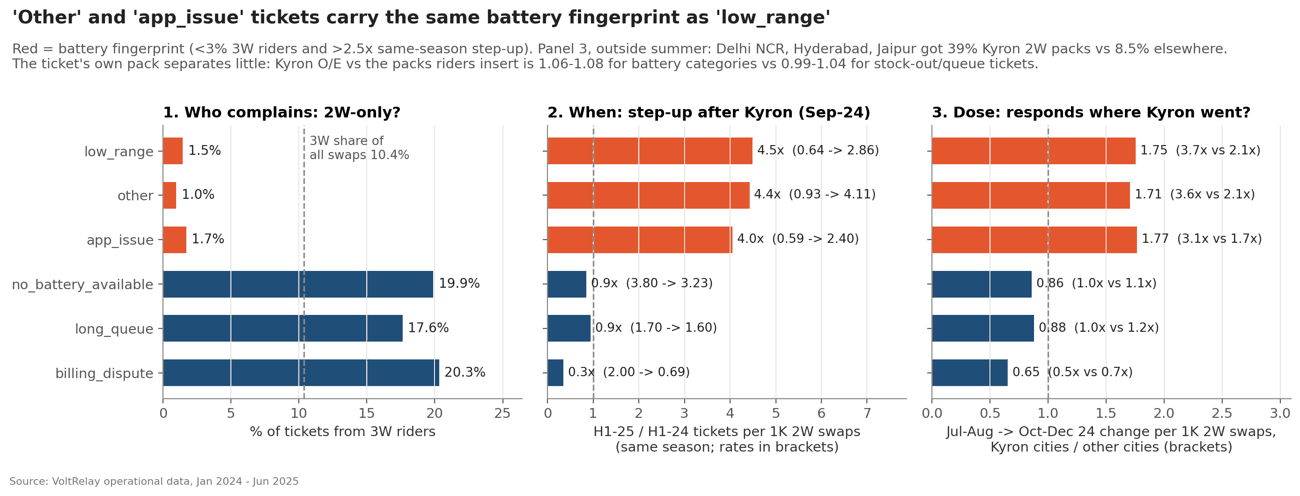

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_02_battery_fingerprint.png')

In [165]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5.0), sharey=True)
ylab = {"low_range": "low_range", "other": "other", "app_issue": "app_issue", "no_battery_available": "no_battery_available",
        "long_queue": "long_queue", "billing_dispute": "billing_dispute"}
yy = np.arange(len(CATS))[::-1]
colr = [PALETTE["accent"] if fp_cat.loc[c, "battery_fingerprint"] else PALETTE["primary"] for c in CATS]
ax = axes[0]
v = fp_cat["share_3w_riders"].values * 100
ax.barh(yy, v, color=colr, height=0.6)
ax.axvline(share_3w_swaps * 100, color=PALETTE["muted"], ls="--", lw=1.2)
ax.text(share_3w_swaps * 100 + 0.4, yy[0] + 0.05, f"3W share of\nall swaps {share_3w_swaps * 100:.1f}%", fontsize=9.5, color=INK2, va="center")
for y_, x_ in zip(yy, v):
    ax.text(x_ + 0.4, y_, f"{x_:.1f}%", va="center", fontsize=10, color=INK)
ax.set_yticks(yy, [ylab[c] for c in CATS])
ax.set_xlabel("% of tickets from 3W riders")
ax.set_title("1. Who complains: 2W-only?", fontsize=11.5)
ax.set_xlim(0, max(v) * 1.3)
ax = axes[1]
v = fp_cat["step_ratio"].values
ax.barh(yy, v, color=colr, height=0.6)
ax.axvline(1, color=PALETTE["muted"], ls="--", lw=1.2)
for y_, x_, c in zip(yy, v, CATS):
    ax.text(x_ + 0.1, y_, f"{x_:.1f}x  ({fp_cat.loc[c, 'rate_h1_24']:.2f} -> {fp_cat.loc[c, 'rate_h1_25']:.2f})", va="center", fontsize=9.5, color=INK)
ax.set_xlabel("H1-25 / H1-24 tickets per 1K 2W swaps\n(same season; rates in brackets)")
ax.set_title("2. When: step-up after Kyron (Sep-24)", fontsize=11.5)
ax.set_xlim(0, max(v) * 1.75)
ax = axes[2]
v = fp_cat["kyron_dose_ratio_of_ratios"].values
ax.barh(yy, v, color=colr, height=0.6)
ax.axvline(1, color=PALETTE["muted"], ls="--", lw=1.2)
for y_, x_, c in zip(yy, v, CATS):
    ax.text(x_ + 0.04, y_, f"{x_:.2f}  ({dose_tab.loc[c, 'kyron_change']:.1f}x vs {dose_tab.loc[c, 'other_change']:.1f}x)", va="center", fontsize=9.5, color=INK)
ax.set_xlabel("Jul-Aug -> Oct-Dec 24 change per 1K 2W swaps,\nKyron cities / other cities (brackets)")
ax.set_title("3. Dose: responds where Kyron went?", fontsize=11.5)
ax.set_xlim(0, max(v) * 1.75)
for a_ in axes:
    a_.grid(axis="y", visible=False)
top = headline(fig, "'Other' and 'app_issue' tickets carry the same battery fingerprint as 'low_range'",
               f"Red = battery fingerprint (<3% 3W riders and >2.5x same-season step-up). Panel 3, outside summer: {', '.join(KY_CITIES)} got "
               f"{ky_hi * 100:.0f}% Kyron 2W packs vs {ky_lo * 100:.1f}% elsewhere.\nThe ticket's own pack separates little: Kyron O/E vs the packs riders "
               f"insert is {fp_cat.loc[BATT, 'kyron_OE'].min():.2f}-{fp_cat.loc[BATT, 'kyron_OE'].max():.2f} for battery categories vs "
               f"{fp_cat.loc[SVC, 'kyron_OE'].min():.2f}-{fp_cat.loc[SVC, 'kyron_OE'].max():.2f} for stock-out/queue tickets.")
fig.tight_layout(rect=[0, 0, 1, top])
save_fig(fig, "q8_02_battery_fingerprint")

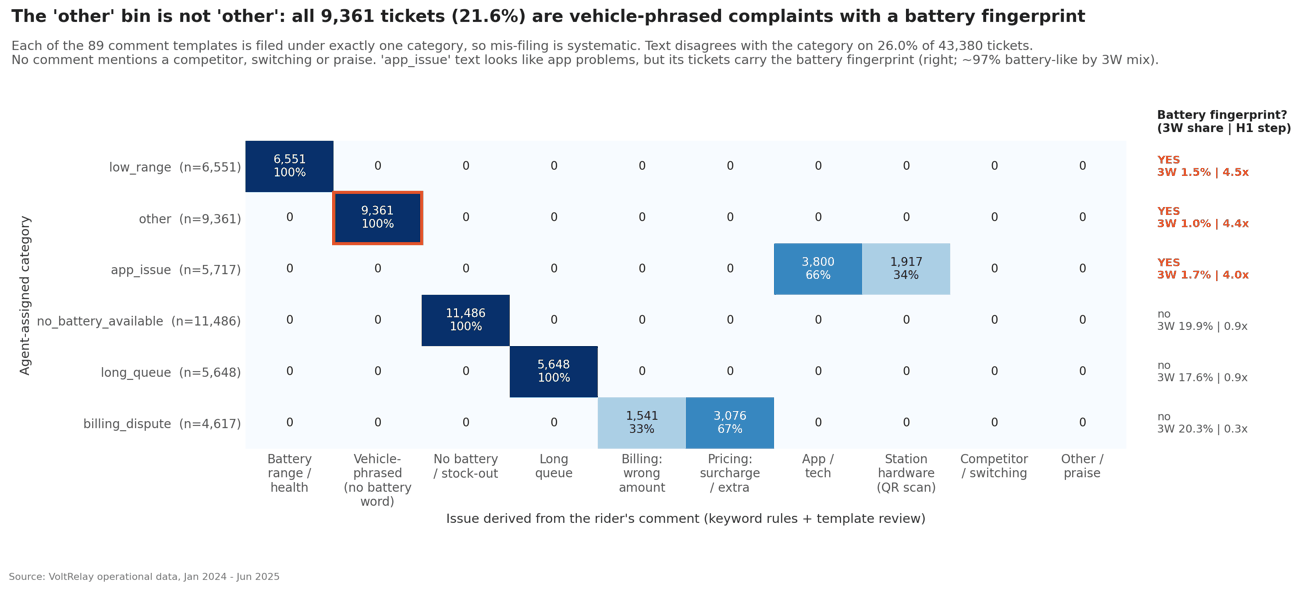

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_01_category_vs_text_heatmap.png')

In [166]:
# HERO 1: agent category vs text-derived issue
fig, ax = plt.subplots(figsize=(15, 6.4))
mat = cm_row.values
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        n_ = cm.values[i, j]
        txt = "0" if n_ == 0 else f"{n_:,}\n{mat[i, j] * 100:.0f}%"
        ax.text(j, i, txt, ha="center", va="center", fontsize=9.5, color="white" if mat[i, j] > 0.55 else INK)
HM_LABEL = {"battery_range_health": "Battery\nrange /\nhealth", "vehicle_phrased": "Vehicle-\nphrased\n(no battery\nword)",
            "no_battery_stockout": "No battery\n/ stock-out", "long_queue": "Long\nqueue", "billing_wrong_amount": "Billing:\nwrong\namount",
            "pricing_surcharge": "Pricing:\nsurcharge\n/ extra", "app_tech": "App /\ntech", "station_hw_system": "Station\nhardware\n(QR scan)",
            "competitor_switching": "Competitor\n/ switching", "other_praise": "Other /\npraise"}
ax.set_xticks(range(len(ISSUE_ORDER)), [HM_LABEL[c] for c in ISSUE_ORDER], fontsize=10)
ax.set_yticks(range(len(CATS)), [f"{c}  (n={int(cm.loc[c].sum()):,})" for c in CATS], fontsize=10)
ax.set_xlabel("Issue derived from the rider's comment (keyword rules + template review)")
ax.set_ylabel("Agent-assigned category")
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.add_patch(plt.Rectangle((0.5, 0.5), 1, 1, fill=False, ec=PALETTE["accent"], lw=2.5))
fpx = len(ISSUE_ORDER) - 0.5 + 0.35
ax.text(fpx, -0.62, "Battery fingerprint?\n(3W share | H1 step)", fontsize=9.5, color=INK, ha="left", va="bottom", fontweight="bold")
for i, c in enumerate(CATS):
    yes = bool(fp_cat.loc[c, "battery_fingerprint"])
    ax.text(fpx, i, ("YES" if yes else "no") + f"\n3W {fp_cat.loc[c, 'share_3w_riders'] * 100:.1f}% | {fp_cat.loc[c, 'step_ratio']:.1f}x",
            fontsize=9, color=PALETTE["accent"] if yes else INK2, ha="left", va="center", fontweight="bold" if yes else "normal")
ax.set_xlim(-0.5, len(ISSUE_ORDER) - 0.5)
top = headline(fig, f"The 'other' bin is not 'other': all {n_other:,} tickets ({pct(n_other / N)}) are vehicle-phrased complaints with a battery fingerprint",
               f"Each of the 89 comment templates is filed under exactly one category, so mis-filing is systematic. Text disagrees with the category on "
               f"{pct(n_dis / N)} of {N:,} tickets.\nNo comment mentions a competitor, switching or praise. 'app_issue' text looks like app problems, "
               f"but its tickets carry the battery fingerprint (right; ~{f_app * 100:.0f}% battery-like by 3W mix).")
fig.subplots_adjust(left=0.19, right=0.86, top=top - 0.10, bottom=0.2)
save_fig(fig, "q8_01_category_vs_text_heatmap")

## 5 · What the text adds (1): the true volume of battery-health complaints
* **Floor** = `low_range` (range wording) + `other` (vehicle-phrased: no battery or range word; the battery label
  rests on the section 4 fingerprint, not on the wording).
* **Central** = floor + the battery-like share of `app_issue` from the 3W mixing model (~97%).
* **Upper** = floor + all of `app_issue`.
The comparison that matters is with station availability: stock-outs and queues combined.
Rates are tickets from 2W riders per 1K completed 2W swaps.

In [167]:
mon_w = mon.to_pandas().pivot(index="month", columns="category", values="rate").reindex(columns=CATS).fillna(0)
m2w_pd = m2w.to_pandas().set_index("month")
tot_lr = n_lr
tot_lb = n_lr + n_other
tot_ub = tot_lb + n_app
tot_c = tot_lb + f_app * n_app
n_so, n_qu = int((tk["category"] == "no_battery_available").sum()), int((tk["category"] == "long_queue").sum())
print(f"battery-health complaints, full window: official low_range {tot_lr:,} ({pct(tot_lr / N)}) | floor (+ vehicle-phrased other) {tot_lb:,} = "
      f"{tot_lb / tot_lr:.2f}x ({pct(tot_lb / N)}) | central (+{pct(f_app, 0)} of app_issue) {tot_c:,.0f} ({pct(tot_c / N)}) | upper (+ all app_issue) "
      f"{tot_ub:,} = {tot_ub / tot_lr:.2f}x ({pct(tot_ub / N)})")
print(f"station availability, full window: stock-outs {pct(n_so / N)} + queues {pct(n_qu / N)} = {pct((n_so + n_qu) / N)} of tickets")
q2c = tk.filter(Q2_25).group_by("category").agg(pl.len().alias("n"))
q2c = {r["category"]: r["n"] / n_q2 for r in q2c.iter_rows(named=True)}
q2_floor, q2_app, q2_svc = q2c["low_range"] + q2c["other"], q2c["app_issue"], q2c["no_battery_available"] + q2c["long_queue"]
print(f"Apr-Jun-25 (n={n_q2:,}): battery floor {pct(q2_floor)} | central {pct(q2_floor + f_app * q2_app)} | upper {pct(q2_floor + q2_app)} vs "
      f"stock-outs {pct(q2c['no_battery_available'])} + queues {pct(q2c['long_queue'])} = {pct(q2_svc)}")
first, last = mon_w.index.min(), mon_w.index.max()
for m_ in [first, pd.Timestamp("2024-08-01"), pd.Timestamp("2024-09-01"), last]:
    r_ = mon_w.loc[m_]
    print(f"{m_:%b-%y}: per 1K 2W swaps low_range {r_['low_range']:.2f} | +other {r_['low_range'] + r_['other']:.2f} | +app {r_['low_range'] + r_['other'] + r_['app_issue']:.2f} "
          f"| Kyron share {m2w_pd.loc[m_, 'p_kyron'] * 100:.1f}% | packs <80% SoH {m2w_pd.loc[m_, 'share_lt80'] * 100:.1f}%")
batt_rate = mon_w["low_range"] + mon_w["other"] + mon_w["app_issue"]
oth_ratio = mon_w["other"] / mon_w["low_range"]
print(f"'other' / 'low_range' monthly ratio: min {oth_ratio.min():.2f}, median {oth_ratio.median():.2f}, max {oth_ratio.max():.2f} "
      f"(full window {n_other / n_lr:.2f}) -> the text changes the level, not the trend")
r_k = np.corrcoef(batt_rate, m2w_pd.loc[mon_w.index, "p_kyron"])[0, 1]
r_s = np.corrcoef(batt_rate, m2w_pd.loc[mon_w.index, "share_lt80"])[0, 1]
post_ix = [m for m in mon_w.index if m >= pd.Timestamp("2024-10-01")]
r_s_post = np.corrcoef(batt_rate.loc[post_ix], m2w_pd.loc[post_ix, "share_lt80"])[0, 1]
r_k_post = np.corrcoef(batt_rate.loc[post_ix], m2w_pd.loc[post_ix, "p_kyron"])[0, 1]
print(f"monthly battery-complaint rate vs Kyron share r={r_k:.2f} (Oct-24..Jun-25 r={r_k_post:.2f}); vs share of issued packs <80% SoH "
      f"r={r_s:.2f} (Oct-24..Jun-25 r={r_s_post:.2f})")
# Is the post-plateau 'tracks pack ageing' correlation specific? Placebo: stock-out+queue rate vs the same <80% series; detrended
# version: first differences. Both trending series correlate whatever drives them.
svc_rate = mon_w["no_battery_available"] + mon_w["long_queue"]
r_s_plc = np.corrcoef(svc_rate.loc[post_ix], m2w_pd.loc[post_ix, "share_lt80"])[0, 1]
r_s_fd = np.corrcoef(np.diff(batt_rate.loc[post_ix].values), np.diff(m2w_pd.loc[post_ix, "share_lt80"].values))[0, 1]
oct24, jan25 = pd.Timestamp("2024-10-01"), pd.Timestamp("2025-01-01")
print(f"ageing test, Oct-24..Jun-25: battery rate vs <80% SoH share r={r_s_post:.2f}, but stock-out+queue (placebo) r={r_s_plc:.2f} and first "
      f"differences r={r_s_fd:.2f} (n={len(post_ix) - 1}); battery rate rose {batt_rate.loc[oct24]:.2f} (Oct-24) -> {batt_rate.loc[jan25]:.2f} (Jan-25) "
      f"while packs <80% SoH were {m2w_pd.loc[oct24, 'share_lt80'] * 100:.1f}% -> {m2w_pd.loc[jan25, 'share_lt80'] * 100:.1f}% "
      f"-> not specific; monthly correlations cannot separate ageing from trend")
mon_w.assign(kyron_share=m2w_pd["p_kyron"], share_packs_lt80=m2w_pd["share_lt80"], mean_soh_2w=m2w_pd["soh_2w"]).to_csv(TAB / "q8_monthly_battery_complaints.csv")

battery-health complaints, full window: official low_range 6,551 (15.1%) | floor (+ vehicle-phrased other) 15,912 = 2.43x (36.7%) | central (+97% of app_issue) 21,458 (49.5%) | upper (+ all app_issue) 21,629 = 3.30x (49.9%)
station availability, full window: stock-outs 26.5% + queues 13.0% = 39.5% of tickets
Apr-Jun-25 (n=15,290): battery floor 39.9% | central 53.5% | upper 54.0% vs stock-outs 28.4% + queues 12.7% = 41.1%
Jan-24: per 1K 2W swaps low_range 0.38 | +other 0.93 | +app 1.32 | Kyron share 0.0% | packs <80% SoH 0.0%
Aug-24: per 1K 2W swaps low_range 0.74 | +other 1.73 | +app 2.46 | Kyron share 0.0% | packs <80% SoH 0.0%
Sep-24: per 1K 2W swaps low_range 1.60 | +other 3.84 | +app 5.17 | Kyron share 18.1% | packs <80% SoH 0.0%
Jun-25: per 1K 2W swaps low_range 3.24 | +other 7.87 | +app 10.58 | Kyron share 24.1% | packs <80% SoH 41.7%
'other' / 'low_range' monthly ratio: min 1.33, median 1.43, max 1.60 (full window 1.43) -> the text changes the level, not the trend
monthly batte

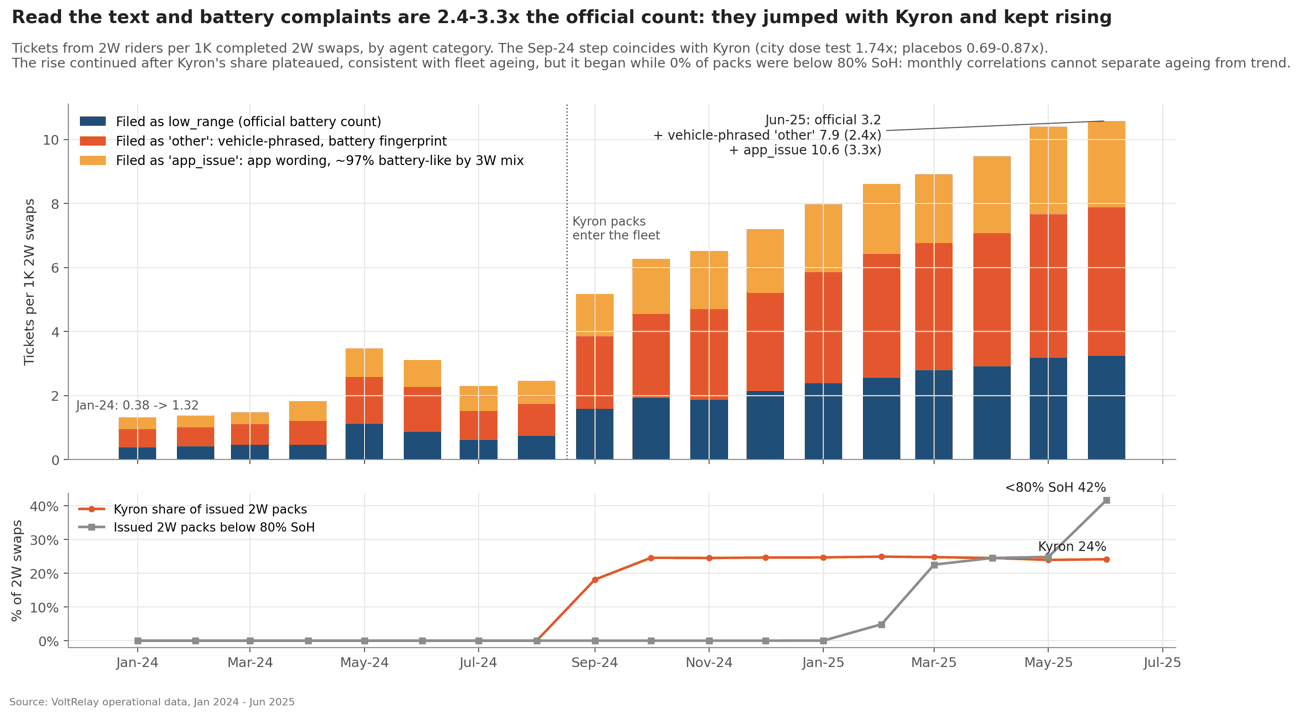

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_03_hidden_battery_complaints_kyron.png')

In [168]:
# HERO 2: hidden battery complaints over time + Kyron share (aligned panel, shared time axis; no dual axis)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
x = pd.to_datetime(mon_w.index)
w_ = 20
b1 = ax.bar(x, mon_w["low_range"], width=w_, color=PALETTE["primary"], label="Filed as low_range (official battery count)")
b2 = ax.bar(x, mon_w["other"], width=w_, bottom=mon_w["low_range"], color=PALETTE["accent"],
            label="Filed as 'other': vehicle-phrased, battery fingerprint")
b3 = ax.bar(x, mon_w["app_issue"], width=w_, bottom=mon_w["low_range"] + mon_w["other"], color=PALETTE["warn"],
            label=f"Filed as 'app_issue': app wording, ~{f_app * 100:.0f}% battery-like by 3W mix")
ax.set_ylabel("Tickets per 1K 2W swaps")
ax.legend(loc="upper left", fontsize=10)
lr_last, tot_last = mon_w["low_range"].iloc[-1], batt_rate.iloc[-1]
lb_last = mon_w["low_range"].iloc[-1] + mon_w["other"].iloc[-1]
ax.annotate(f"Jun-25: official {lr_last:.1f}\n+ vehicle-phrased 'other' {lb_last:.1f} ({lb_last / lr_last:.1f}x)\n+ app_issue {tot_last:.1f} ({tot_last / lr_last:.1f}x)",
            xy=(x[-1], tot_last), xytext=(x[-5], tot_last * 1.02), fontsize=10, color=INK, ha="right", va="top",
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
lr0, tot0 = mon_w["low_range"].iloc[0], batt_rate.iloc[0]
ax.text(x[0], tot0 + 0.25, f"Jan-24: {lr0:.2f} -> {tot0:.2f}", fontsize=9.5, color=INK2, ha="center")
ax.axvline(pd.Timestamp("2024-08-17"), color=INK2, lw=1, ls=":")
ax.text(pd.Timestamp("2024-08-20"), ax.get_ylim()[1] * 0.62, "Kyron packs\nenter the fleet", fontsize=9.5, color=INK2)
ax2.plot(x, m2w_pd.loc[mon_w.index, "p_kyron"] * 100, color=SUPPLIER_COLORS["Kyron"], lw=2, marker="o", ms=4, label="Kyron share of issued 2W packs")
ax2.plot(x, m2w_pd.loc[mon_w.index, "share_lt80"] * 100, color=PALETTE["muted"], lw=2, marker="s", ms=4, label="Issued 2W packs below 80% SoH")
ax2.set_ylabel("% of 2W swaps")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.text(x[-1], m2w_pd["p_kyron"].iloc[-1] * 100 + 2.5, f"Kyron {m2w_pd['p_kyron'].iloc[-1] * 100:.0f}%", color=INK, fontsize=10, ha="right")
ax2.text(x[-1], m2w_pd["share_lt80"].iloc[-1] * 100 + 2.5, f"<80% SoH {m2w_pd['share_lt80'].iloc[-1] * 100:.0f}%", color=INK, fontsize=10, ha="right")
ax2.legend(loc="upper left", fontsize=9.5)
ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
top = headline(fig, f"Read the text and battery complaints are {tot_lb / tot_lr:.1f}-{tot_ub / tot_lr:.1f}x the official count: "
                    f"they jumped with Kyron and kept rising",
               f"Tickets from 2W riders per 1K completed 2W swaps, by agent category. The Sep-24 step coincides with Kyron (city dose test "
               f"{dz_b['ratio_of_ratios']:.2f}x; placebos {dose_tab.loc['billing (all riders, all swaps)', 'ratio_of_ratios']:.2f}-"
               f"{dz_s['ratio_of_ratios']:.2f}x).\nThe rise continued after Kyron's share plateaued, consistent with fleet ageing, but it began "
               f"while 0% of packs were below 80% SoH: monthly correlations cannot separate ageing from trend.")
fig.tight_layout(rect=[0, 0, 1, top])
save_fig(fig, "q8_03_hidden_battery_complaints_kyron")

## 5b · What the text adds (2): rider-reported range in "scooter dying at X km"
About 1,350 low_range tickets carry a number. If it is real signal, it should track the linked pack's SoH and
supplier and move with the event log's km-per-swap.

'dying at X km' tickets 1,349 (1 implausible <0 or >150 km dropped); 2W valid 1,330; values above 60 km: 26 (2.0%) -> truncated near 60 km (only complainers report), so medians describe complainers, not the fleet
km vs linked-pack SoH within month (month fixed effects): 0.73 km per SoH point (p=7.8e-79, n=945)

=== reported km by linked-pack supplier (2W) ===
shape: (4, 5)
┌───────────────┬─────┬───────────┬─────────┬───────────────┐
│ pack_supplier ┆ n   ┆ median_km ┆ mean_km ┆ mean_pack_soh │
│ ---           ┆ --- ┆ ---       ┆ ---     ┆ ---           │
│ str           ┆ u32 ┆ f64       ┆ f64     ┆ f32           │
╞═══════════════╪═════╪═══════════╪═════════╪═══════════════╡
│ null          ┆ 385 ┆ 52.0000   ┆ 50.6961 ┆ null          │
│ Amptek        ┆ 172 ┆ 54.0000   ┆ 53.4012 ┆ 87.4058       │
│ Cellora       ┆ 459 ┆ 54.0000   ┆ 53.0109 ┆ 86.7319       │
│ Kyron         ┆ 314 ┆ 45.0000   ┆ 45.2134 ┆ 77.3930       │
└───────────────┴─────┴───────────┴─────────┴───────────────┘
Kyro

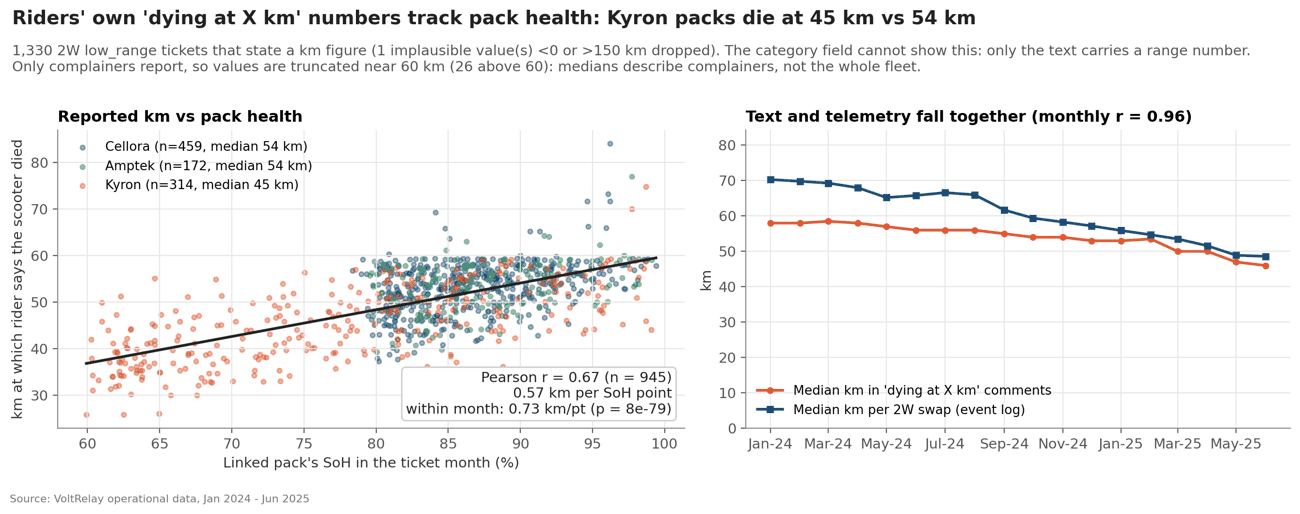

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_04_reported_range_km.png')

In [169]:
km_ev = (events(["is_completed", "month", "vehicle_class", "km_since_last_swap"])
         .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W"))
         .group_by("month").agg(pl.col("km_since_last_swap").median().alias("km_log_median")).collect(engine="streaming").sort("month"))
kmr = tk.filter(pl.col("km_reported").is_not_null())
n_km, n_km_bad = kmr.height, kmr.filter(~pl.col("km_reported").is_between(0, 150)).height
k2 = kmr.filter(pl.col("km_reported").is_between(0, 150) & (pl.col("rider_vc") == "2W"))
ks = k2.group_by("pack_supplier").agg(pl.len().alias("n"), pl.col("km_reported").median().alias("median_km"),
                                      pl.col("km_reported").mean().alias("mean_km"), pl.col("pack_soh").mean().alias("mean_pack_soh")).sort("pack_supplier")
ky_km = k2.filter(pl.col("pack_supplier") == "Kyron")["km_reported"].to_numpy()
nk_km = k2.filter(pl.col("pack_supplier").is_in(["Cellora", "Amptek"]))["km_reported"].to_numpy()
mw = stats.mannwhitneyu(ky_km, nk_km)
kk = k2.filter(pl.col("pack_soh").is_not_null())
r_km = stats.pearsonr(kk["km_reported"], kk["pack_soh"])
rho_km = stats.spearmanr(kk["km_reported"], kk["pack_soh"])
ols = np.polyfit(kk["pack_soh"].to_numpy(), kk["km_reported"].to_numpy(), 1)
km_m = k2.group_by("month").agg(pl.len().alias("n"), pl.col("km_reported").median().alias("km_text_median")).join(km_ev, on="month").sort("month")
r_km_month = np.corrcoef(km_m["km_text_median"], km_m["km_log_median"])[0, 1]
# the monthly r is two trending series; the within-month slope (month fixed effects) shows the km-SoH link is not just shared trend
ols_fe = smf.ols("km ~ soh + C(m)", data=pd.DataFrame({"km": kk["km_reported"].to_numpy(), "soh": kk["pack_soh"].to_numpy(),
                                                        "m": kk["month"].cast(pl.Utf8).to_numpy()})).fit()
km_fe_slope, km_fe_p = float(ols_fe.params["soh"]), float(ols_fe.pvalues["soh"])
n_km_gt60 = int((k2["km_reported"] > 60).sum())
print(f"'dying at X km' tickets {n_km:,} ({n_km_bad} implausible <0 or >150 km dropped); 2W valid {k2.height:,}; values above 60 km: {n_km_gt60} "
      f"({pct(n_km_gt60 / k2.height)}) -> truncated near 60 km (only complainers report), so medians describe complainers, not the fleet")
print(f"km vs linked-pack SoH within month (month fixed effects): {km_fe_slope:.2f} km per SoH point (p={km_fe_p:.1e}, n={kk.height:,})")
show("reported km by linked-pack supplier (2W)", ks)
print(f"Kyron vs Cellora+Amptek reported km: median {np.median(ky_km):.0f} vs {np.median(nk_km):.0f} km, Mann-Whitney p={mw.pvalue:.1e}; "
      f"km vs linked-pack SoH Pearson r={r_km.statistic:.2f} (p={r_km.pvalue:.1e}), Spearman rho={rho_km.statistic:.2f}, n={kk.height:,}; "
      f"slope {ols[0]:.2f} km per SoH point")
km_oct24 = float(km_m.filter(pl.col("month") == pl.date(2024, 10, 1))["km_text_median"].item())
print(f"monthly median reported km {km_m['km_text_median'][0]:.0f} (Jan-24) -> {km_oct24:.0f} (Oct-24, Kyron plateau) -> "
      f"{km_m['km_text_median'][-1]:.0f} (Jun-25); event-log 2W median km/swap "
      f"{km_m['km_log_median'][0]:.1f} -> {km_m['km_log_median'][-1]:.1f}; monthly r={r_km_month:.2f}")
km_m.write_csv(TAB / "q8_reported_km_monthly.csv")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 5.0), gridspec_kw={"width_ratios": [1.15, 1]})
for s in ["Cellora", "Amptek", "Kyron"]:
    d = kk.filter(pl.col("pack_supplier") == s)
    axa.scatter(d["pack_soh"], d["km_reported"] + RNG.uniform(-0.35, 0.35, d.height), s=12, alpha=0.45, color=SUPPLIER_COLORS[s],
                label=f"{s} (n={d.height}, median {float(d['km_reported'].median()):.0f} km)")
xs = np.linspace(float(kk["pack_soh"].min()), float(kk["pack_soh"].max()), 50)
axa.plot(xs, np.polyval(ols, xs), color=INK, lw=2)
axa.text(0.98, 0.04, f"Pearson r = {r_km.statistic:.2f} (n = {kk.height:,})\n{ols[0]:.2f} km per SoH point\nwithin month: {km_fe_slope:.2f} km/pt "
         f"(p = {km_fe_p:.0e})", fontsize=10.5, color=INK,
         ha="right", va="bottom", transform=axa.transAxes, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#CCCCCC"))
axa.set_xlabel("Linked pack's SoH in the ticket month (%)")
axa.set_ylabel("km at which rider says the scooter died")
axa.legend(loc="upper left", fontsize=9.5)
axa.set_title("Reported km vs pack health", fontsize=11.5)
xm = pd.to_datetime(km_m["month"].to_pandas())
axb.plot(xm, km_m["km_text_median"], color=PALETTE["accent"], lw=2, marker="o", ms=4, label="Median km in 'dying at X km' comments")
axb.plot(xm, km_m["km_log_median"], color=PALETTE["primary"], lw=2, marker="s", ms=4, label="Median km per 2W swap (event log)")
axb.set_ylabel("km")
axb.set_ylim(0, max(km_m["km_log_median"].max(), km_m["km_text_median"].max()) * 1.2)
axb.legend(loc="lower left", fontsize=9.5)
axb.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
axb.set_title(f"Text and telemetry fall together (monthly r = {r_km_month:.2f})", fontsize=11.5)
top = headline(fig, f"Riders' own 'dying at X km' numbers track pack health: Kyron packs die at {np.median(ky_km):.0f} km vs {np.median(nk_km):.0f} km",
               f"{k2.height:,} 2W low_range tickets that state a km figure ({n_km_bad} implausible value(s) <0 or >150 km dropped). "
               f"The category field cannot show this: only the text carries a range number.\nOnly complainers report, so values are "
               f"truncated near 60 km ({n_km_gt60} above 60): medians describe complainers, not the whole fleet.")
fig.tight_layout(rect=[0, 0, 1, top])
save_fig(fig, "q8_04_reported_range_km")

## 6 · What the text adds (3): price complaints vs the base-price change and the peak/off-peak pilot
Billing tickets per 1K completed swaps by station city. Pilot = Bengaluru + Pune from 2024-10-01 (peak = list + ₹15).
DiD: Poisson GLM, city-month counts, offset log(swaps), city + month fixed effects, Pearson-scaled SEs.

**Control-group trap.** Three of the four control cities (Delhi NCR, Hyderabad, Jaipur) received ~39% Kyron packs from
Sep-24. Shorter range raised swaps per rider there, which deflates any per-swap ticket rate (and battery complaints
may crowd out others). Mumbai is the only control city with a Kyron share like the pilot cities (~8.5%), so the pilot
is also compared with Mumbai alone, and the Kyron cities are tested against Mumbai inside the control group.

                            n    swaps  per_1k
grp     phase                                 
control 1 Jan-Jun 24      828   446469   1.855
        2 Jul-Sep 24      466   313216   1.488
        3 Oct 24-Jun 25  1238  1573096   0.787
pilot   1 Jan-Jun 24      514   254075   2.023
        2 Jul-Sep 24      339   181134   1.872
        3 Oct 24-Jun 25   961   818685   1.174
pilot DiD on billing tickets per swap, all four control cities: IRR 1.29 (95% CI 1.13-1.48), p=0.000
                                                                IRR    lo    hi     p
spec                                                                                 
main: all 4 control cities, swaps offset, city+month FE       1.293 1.127 1.483 0.000
placebo: 'pilot' at Jul-24, Jan-Sep 24 only                   1.143 0.946 1.382 0.167
+ city-specific linear trends                                 1.339 1.040 1.724 0.023
active-riders offset, city+month FE                           1.184 1.041 1.347 0.010
(a) Mum

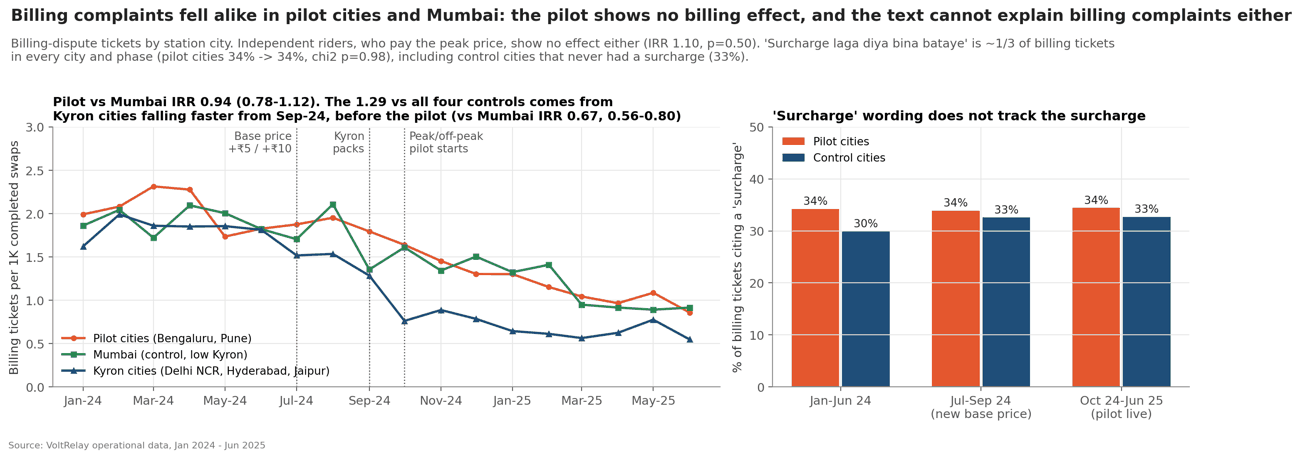

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_05_price_complaints_pilot.png')

In [170]:
swc = sw_cmv.group_by("city", "month").agg(pl.col("swaps").sum())
act = (events(["is_completed", "city", "month", "rider_id"]).filter(pl.col("is_completed"))
       .group_by("city", "month").agg(pl.col("rider_id").n_unique().alias("riders")).collect(engine="streaming"))
bill = tk.filter((pl.col("category") == "billing_dispute") & pl.col("station_city").is_not_null())
PHASES = ["1 Jan-Jun 24", "2 Jul-Sep 24", "3 Oct 24-Jun 25"]


def bill_panel(tickets):
    p = (swc.join(tickets.group_by("station_city", "month").agg(pl.len().alias("n")), left_on=["city", "month"], right_on=["station_city", "month"],
                  how="left").join(act, on=["city", "month"], how="left")
         .with_columns(pl.col("n").fill_null(0), pl.col("city").is_in(PILOT_CITIES).alias("pilot"), (pl.col("month") >= PILOT_START).alias("post_pilot"))
         .to_pandas())
    p["treat"] = (p["pilot"] & p["post_pilot"]).astype(int)
    p["month_s"] = p["month"].astype(str)
    p["t"] = (p["month"].dt.year - 2024) * 12 + p["month"].dt.month
    p["phase"] = np.select([p["month"] < pd.Timestamp(BASE_PRICE_CHANGE), p["month"] < pd.Timestamp(PILOT_START)], PHASES[:2], PHASES[2])
    return p


def pois(data, formula="n ~ treat + C(city) + C(month_s)", off="swaps"):
    return smf.glm(formula, data=data, family=sm.families.Poisson(), offset=np.log(data[off])).fit(scale="X2")


pan = bill_panel(bill)
did = pois(pan)
irr, irr_lo, irr_hi = np.exp(did.params["treat"]), *np.exp(did.conf_int().loc["treat"])
grp_rate = pan.assign(grp=np.where(pan["pilot"], "pilot", "control")).groupby(["grp", "phase"]).agg(n=("n", "sum"), swaps=("swaps", "sum"))
grp_rate["per_1k"] = grp_rate["n"] / grp_rate["swaps"] * 1000
print(grp_rate)
print(f"pilot DiD on billing tickets per swap, all four control cities: IRR {irr:.2f} (95% CI {irr_lo:.2f}-{irr_hi:.2f}), p={did.pvalues['treat']:.3f}")
# Robustness: placebo 'pilot' at the base-price change (pre-pilot months only); city-specific linear trends; active riders as
# offset. Control-group checks: (a) Mumbai as the only control; (b) inside the controls, Kyron cities after Sep-24 vs Mumbai;
# (c) billing tickets of independent riders only (they pay the PEAK price).
pre_p = pan[pan["month"] < pd.Timestamp(PILOT_START)].copy()
pre_p["treat_pl"] = (pre_p["pilot"] & (pre_p["month"] >= pd.Timestamp(BASE_PRICE_CHANGE))).astype(int)
pan_mum = pan[pan["pilot"] | (pan["city"] == "Mumbai")]
pan_ctl = pan[~pan["pilot"]].copy()
pan_ctl["kyc"] = (pan_ctl["city"].isin(KY_CITIES) & (pan_ctl["month"] >= pd.Timestamp("2024-09-01"))).astype(int)
pan_ind = bill_panel(bill.filter(pl.col("partner_id").is_null()))
fits = {
    "main: all 4 control cities, swaps offset, city+month FE": (did, "treat"),
    "placebo: 'pilot' at Jul-24, Jan-Sep 24 only": (pois(pre_p, "n ~ treat_pl + C(city) + C(month_s)"), "treat_pl"),
    "+ city-specific linear trends": (pois(pan, "n ~ treat + C(city) + C(month_s) + C(city):t"), "treat"),
    "active-riders offset, city+month FE": (pois(pan, off="riders"), "treat"),
    "(a) Mumbai-only control (pilot cities + Mumbai), swaps offset": (pois(pan_mum), "treat"),
    "(a) Mumbai-only control, active-riders offset": (pois(pan_mum, off="riders"), "treat"),
    "(b) control cities only: Kyron city x post-Sep-24 vs Mumbai": (pois(pan_ctl, "n ~ kyc + C(city) + C(month_s)"), "kyc"),
    "(c) independent riders' billing tickets, all 4 controls": (pois(pan_ind), "treat"),
}
rob = pd.DataFrame([dict(spec=k, IRR=np.exp(f.params[v]), lo=np.exp(f.conf_int().loc[v, 0]), hi=np.exp(f.conf_int().loc[v, 1]), p=f.pvalues[v])
                    for k, (f, v) in fits.items()]).set_index("spec")
with pd.option_context("display.width", 200):
    print(rob.to_string(float_format=lambda v: f"{v:.3f}"))
rob.to_csv(TAB / "q8_pricing_did_robustness.csv")
R_MUM, R_KYC, R_IND = rob.iloc[4], rob.iloc[6], rob.iloc[7]
grow = pan.groupby("pilot").apply(lambda d: d.loc[d["month"] == d["month"].max(), "swaps"].sum() / d.loc[d["month"] == d["month"].min(), "swaps"].sum())
print(f"swap growth Jan-24 -> Jun-25: pilot cities {grow[True]:.2f}x, control cities {grow[False]:.2f}x")
# (d) billing tickets per 1K swaps by city and phase
cty = pan.groupby(["city", "phase"]).agg(n=("n", "sum"), swaps=("swaps", "sum"))
cty_w = (cty["n"] / cty["swaps"] * 1000).unstack("phase")[PHASES].reindex(CITIES)
cty_w["post_vs_pre"] = cty_w[PHASES[2]] / cty_w[PHASES[0]]
cty_w["group"] = np.where(cty_w.index.isin(PILOT_CITIES), "pilot", np.where(cty_w.index.isin(KY_CITIES), "control: Kyron city", "control: Mumbai"))
cty_w.to_csv(TAB / "q8_billing_rate_by_city.csv")
print("billing tickets per 1K swaps by city, Jan-Jun-24 -> Oct-24..Jun-25: " + "; ".join(
    f"{c} {r[PHASES[0]]:.2f} -> {r[PHASES[2]]:.2f} ({r['post_vs_pre']:.2f}x)" for c, r in cty_w.iterrows()))
# why the Kyron cities' per-swap rates fall faster: shorter range -> more swaps per 2W rider (deflates every per-swap rate)
spr = (events(["is_completed", "city", "month", "rider_id", "vehicle_class"])
       .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W") & (JA24 | OD24))
       .group_by(pl.col("city").is_in(KY_CITIES).alias("ky"), "month").agg(pl.len().alias("sw"), pl.col("rider_id").n_unique().alias("riders"))
       .collect(engine="streaming").with_columns((pl.col("sw") / pl.col("riders")).alias("spr"), JA24.alias("ja")))
spr_t = {(r["ky"], r["ja"]): r["spr"] for r in spr.group_by("ky", "ja").agg(pl.col("spr").mean()).iter_rows(named=True)}
print(f"completed swaps per active 2W rider per month, Jul-Aug-24 -> Oct-Dec-24: Kyron cities {spr_t[(True, True)]:.1f} -> {spr_t[(True, False)]:.1f}; "
      f"other cities {spr_t[(False, True)]:.1f} -> {spr_t[(False, False)]:.1f}")
bt = bill.with_columns(pl.col("station_city").is_in(PILOT_CITIES).alias("pilot"),
                       pl.when(pl.col("month") < BASE_PRICE_CHANGE).then(pl.lit("1 Jan-Jun 24")).when(pl.col("month") < PILOT_START)
                       .then(pl.lit("2 Jul-Sep 24")).otherwise(pl.lit("3 Oct 24-Jun 25")).alias("phase"),
                       (pl.col("rider_comment") == "surcharge laga diya bina bataye").alias("surcharge_txt"))
sur = bt.group_by("pilot", "phase").agg(pl.len().alias("n"), pl.col("surcharge_txt").mean().alias("surcharge_share")).sort("pilot", "phase")
show("share of billing tickets saying 'surcharge laga diya bina bataye' (surcharge applied without notice)", sur)
ct = pd.crosstab(bt.filter(pl.col("pilot"))["phase"].to_pandas(), bt.filter(pl.col("pilot"))["surcharge_txt"].to_pandas())
chi_s = stats.chi2_contingency(ct)
print(f"pilot cities: surcharge-template share by phase chi2 p={chi_s[1]:.2f}")
sur_tab = sur.to_pandas()
s_pil_pre = float(sur_tab.query("pilot and phase == '2 Jul-Sep 24'")["surcharge_share"].iloc[0])
s_pil_post = float(sur_tab.query("pilot and phase == '3 Oct 24-Jun 25'")["surcharge_share"].iloc[0])
s_con_post = float(sur_tab.query("not pilot and phase == '3 Oct 24-Jun 25'")["surcharge_share"].iloc[0])
s_con_pre0 = float(sur_tab.query("not pilot and phase == '1 Jan-Jun 24'")["surcharge_share"].iloc[0])
# base price change, all cities (no same-season baseline exists: caveat)
b_pre = grp_rate.xs("1 Jan-Jun 24", level="phase")[["n", "swaps"]].sum()
b_mid = grp_rate.xs("2 Jul-Sep 24", level="phase")[["n", "swaps"]].sum()
print(f"all cities billing per 1K swaps: Jan-Jun-24 {b_pre['n'] / b_pre['swaps'] * 1000:.2f} -> Jul-Sep-24 {b_mid['n'] / b_mid['swaps'] * 1000:.2f}")
billvc = (tk.filter(pl.col("category") == "billing_dispute").group_by("rider_vc", "month").agg(pl.len().alias("n"))
          .join(sw_mvs.group_by("vehicle_class", "month").agg(pl.col("swaps").sum()), left_on=["rider_vc", "month"], right_on=["vehicle_class", "month"])
          .with_columns(pl.when(pl.col("month") < BASE_PRICE_CHANGE).then(pl.lit("1 Jan-Jun 24")).when(pl.col("month") < PILOT_START)
                        .then(pl.lit("2 Jul-Sep 24")).otherwise(pl.lit("3 Oct 24-Jun 25")).alias("phase"))
          .group_by("rider_vc", "phase").agg((pl.col("n").sum() / pl.col("swaps").sum() * 1000).alias("billing_per_1k")).sort("rider_vc", "phase"))
show("billing tickets per 1K swaps by vehicle class and pricing phase", billvc)

G3 = {"pilot": "Pilot cities (Bengaluru, Pune)", "mum": "Mumbai (control, low Kyron)", "ky": f"Kyron cities ({', '.join(KY_CITIES)})"}
pan["grp3"] = np.where(pan["pilot"], G3["pilot"], np.where(pan["city"] == "Mumbai", G3["mum"], G3["ky"]))
mp = pan.groupby(["grp3", "month"]).agg(n=("n", "sum"), swaps=("swaps", "sum"))
mp["per_1k"] = mp["n"] / mp["swaps"] * 1000
fig, (axa, axb) = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
for g, col, mk in [(G3["pilot"], PALETTE["accent"], "o"), (G3["mum"], PALETTE["good"], "s"), (G3["ky"], PALETTE["primary"], "^")]:
    d = mp.xs(g, level="grp3")
    axa.plot(pd.to_datetime(d.index), d["per_1k"], color=col, lw=2, marker=mk, ms=4, label=g)
axa.set_ylim(0, 3.0)
for dte, lab, ha_, dx in [(BASE_PRICE_CHANGE, "Base price\n+₹5 / +₹10", "right", -4), ("2024-09-01", "Kyron\npacks", "right", -4),
                          (PILOT_START, "Peak/off-peak\npilot starts", "left", 4)]:
    axa.axvline(pd.Timestamp(dte), color=INK2, ls=":", lw=1)
    axa.text(pd.Timestamp(dte) + pd.Timedelta(days=dx), 2.95, lab, fontsize=9.5, color=INK2, va="top", ha=ha_)
axa.set_ylabel("Billing tickets per 1K completed swaps")
axa.legend(loc="lower left", fontsize=9.5)
axa.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
axa.set_title(f"Pilot vs Mumbai IRR {R_MUM['IRR']:.2f} ({R_MUM['lo']:.2f}-{R_MUM['hi']:.2f}). The {irr:.2f} vs all four controls comes from\n"
              f"Kyron cities falling faster from Sep-24, before the pilot (vs Mumbai IRR {R_KYC['IRR']:.2f}, {R_KYC['lo']:.2f}-{R_KYC['hi']:.2f})", fontsize=11)
phases = ["1 Jan-Jun 24", "2 Jul-Sep 24", "3 Oct 24-Jun 25"]
xx = np.arange(3)
for k_, (flag, col, lab) in enumerate([(True, PALETTE["accent"], "Pilot cities"), (False, PALETTE["primary"], "Control cities")]):
    vals = [float(sur_tab.query(f"pilot == {flag} and phase == '{p}'")["surcharge_share"].iloc[0]) * 100 for p in phases]
    axb.bar(xx + (k_ - 0.5) * 0.36, vals, width=0.34, color=col, label=lab)
    for xi, v_ in zip(xx + (k_ - 0.5) * 0.36, vals):
        axb.text(xi, v_ + 0.8, f"{v_:.0f}%", ha="center", fontsize=9.5, color=INK)
axb.set_xticks(xx, ["Jan-Jun 24", "Jul-Sep 24\n(new base price)", "Oct 24-Jun 25\n(pilot live)"])
axb.set_ylabel("% of billing tickets citing a 'surcharge'")
axb.set_ylim(0, 50)
axb.legend(loc="upper left", fontsize=9.5)
axb.set_title("'Surcharge' wording does not track the surcharge", fontsize=11.5)
top = headline(fig, "Billing complaints fell alike in pilot cities and Mumbai: the pilot shows no billing effect, and the text cannot explain "
                    "billing complaints either",
               f"Billing-dispute tickets by station city. Independent riders, who pay the peak price, show no effect either (IRR {R_IND['IRR']:.2f}, "
               f"p={R_IND['p']:.2f}). 'Surcharge laga diya bina bataye' is ~1/3 of billing tickets\nin every city and phase (pilot cities "
               f"{s_pil_pre * 100:.0f}% -> {s_pil_post * 100:.0f}%, chi2 p={chi_s[1]:.2f}), including control cities that never had a surcharge "
               f"({s_con_post * 100:.0f}%).")
fig.tight_layout(rect=[0, 0, 1, top])
save_fig(fig, "q8_05_price_complaints_pilot")

## 7 · What the text adds (4): urgency, repeat-failure claims, competitor mentions and churn
* Does agent `priority` reflect the text or change handling?
* Is "empty station again, this is the third time this week" borne out by the rider's logged stock-outs?
* Lapse = rider's last completed swap falls within 30 days after the ticket (tickets before 2025-06-01 so a full
  30-day window is observed). Logit with month, city, vehicle class, fleet affiliation and tenure controls;
  rider-clustered SEs. Association, not causation: riders who complain may already be disengaging.

In [171]:
ct_p = pd.crosstab(tk["template_id"].to_pandas(), tk["priority"].to_pandas())
chi_p = stats.chi2_contingency(ct_p)
cramer = np.sqrt(chi_p[0] / (ct_p.values.sum() * (min(ct_p.shape) - 1)))
pr = tk.group_by("priority").agg(pl.len().alias("n"), pl.col("resolution_hours").median().alias("median_res_h"),
                                 (pl.col("resolution_status") == "unresolved").mean().alias("unresolved"), pl.col("has_csat").mean().alias("csat_response")).sort("priority")
kw = stats.kruskal(*[tk.filter((pl.col("priority") == p) & pl.col("resolution_hours").is_not_null())["resolution_hours"].to_numpy() for p in ["low", "medium", "high"]])
hi_urg = tk.group_by("urgency_business_impact").agg((pl.col("priority") == "high").mean().alias("high_share"), pl.len().alias("n"))
show("priority vs handling", pr)
print(f"template x priority chi2 p={chi_p[1]:.2f}, Cramer's V={cramer:.3f}; resolution hours by priority Kruskal-Wallis p={kw.pvalue:.2f}")
show("high-priority share by business-impact wording ('late ... delivery')", hi_urg)

so_ev = events(["rider_id", "event_ts", "is_stockout"]).filter(pl.col("is_stockout")).select("rider_id", "event_ts").collect(engine="streaming")


def stockouts_prior_7d(df):
    j = (df.select("ticket_id", "rider_id", "created_ts").join(so_ev, on="rider_id", how="inner")
         .filter((pl.col("event_ts") <= pl.col("created_ts")) & (pl.col("event_ts") > pl.col("created_ts") - pl.duration(days=7)))
         .group_by("ticket_id").agg(pl.len().alias("so7")))
    return df.join(j, on="ticket_id", how="left").with_columns(pl.col("so7").fill_null(0))


st = stockouts_prior_7d(tk.filter(pl.col("category") == "no_battery_available"))
st_sum = st.group_by("urgency_repeat").agg(pl.len().alias("n"), pl.col("so7").mean().alias("mean_stockouts_7d"),
                                           (pl.col("so7") >= 1).mean().alias("ge1"), (pl.col("so7") >= 3).mean().alias("ge3"))
pl_b = stockouts_prior_7d(tk.filter(pl.col("category") == "billing_dispute"))
show("stock-out tickets: logged stock-outs in prior 7 days, 'third time this week' vs other stock-out wording", st_sum)
print(f"placebo - billing tickets with >=1 logged stock-out in prior 7 days: {pct(float((pl_b['so7'] >= 1).mean()))}")

ISSUE5 = {"battery_range_health": "Battery (range or vehicle wording)", "vehicle_phrased": "Battery (range or vehicle wording)",
          "app_tech": "App / QR (battery fingerprint)", "station_hw_system": "App / QR (battery fingerprint)",
          "no_battery_stockout": "Stock-out", "long_queue": "Long queue", "billing_wrong_amount": "Billing / pricing", "pricing_surcharge": "Billing / pricing"}
I5_ORDER = ["Battery (range or vehicle wording)", "App / QR (battery fingerprint)", "Stock-out", "Long queue", "Billing / pricing"]
tk = tk.with_columns(pl.col("text_issue").replace_strict(ISSUE5, default="Other").alias("issue5"))
lp = (tk.filter((pl.col("created_ts") < pl.datetime(2025, 6, 1)) & pl.col("last_swap_ts").is_not_null() & pl.col("rider_vc").is_not_null())
      .with_columns((pl.col("last_swap_ts") < pl.col("created_ts") + pl.duration(days=30)).alias("lapse30"),
                    ((pl.col("created_ts") - pl.col("first_swap_ts")).dt.total_hours() / 24).clip(0, None).alias("tenure_days"),
                    pl.col("station_city").fill_null("unknown").alias("city_f"), pl.col("partner_id").is_not_null().alias("fleet"),
                    pl.col("month").cast(pl.Utf8).alias("month_s"))
      .to_pandas())
lp["lapse30"] = lp["lapse30"].astype(int)
lp_rate = lp.groupby("issue5").agg(n=("lapse30", "size"), lapse30=("lapse30", "mean")).reindex(I5_ORDER)
lg = smf.logit("lapse30 ~ C(issue5, Treatment('Billing / pricing')) + C(month_s) + C(city_f) + C(rider_vc) + fleet + np.log1p(tenure_days)",
               data=lp).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(lp["rider_id"])[0]})
orr = pd.DataFrame({"OR": np.exp(lg.params), "lo": np.exp(lg.conf_int()[0]), "hi": np.exp(lg.conf_int()[1]), "p": lg.pvalues})
orr = orr[orr.index.str.startswith("C(issue5")]
orr.index = orr.index.str.extract(r"\[T\.(.*)\]")[0].values
lp_rate = lp_rate.join(orr)
print(f"\nlapse-30 sample {len(lp):,} tickets; overall lapse {lp['lapse30'].mean():.3f}")
print(lp_rate.to_string(float_format=lambda v: f"{v:.3f}"))
# Right-censoring: 'last swap < ticket + 30 d' needs time after the window to tell a lapse from a pause. Data end 30-Jun-25, so
# Apr/May-25 tickets have <= 60 days of follow-up and their lapse rates are inflated. Month FE absorb this in the ORs; the level
# is reported on tickets before Apr-25, and the logit is refit on that sample as a check.
lp_m = lp.groupby(lp["month"].dt.strftime("%b-%y"), sort=False)["lapse30"].mean()
lp_ok = lp[lp["created_ts"] < pd.Timestamp("2025-04-01")]
lg_ok = smf.logit("lapse30 ~ C(issue5, Treatment('Billing / pricing')) + C(month_s) + C(city_f) + C(rider_vc) + fleet + np.log1p(tenure_days)",
                  data=lp_ok).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(lp_ok["rider_id"])[0]})
or_ok = np.exp(lg_ok.params[lg_ok.params.index.str.startswith("C(issue5")])
p_ok = lg_ok.pvalues[lg_ok.pvalues.index.str.startswith("C(issue5")]
lp_rate["lapse30_pre_apr25"] = lp_ok.groupby("issue5")["lapse30"].mean().reindex(I5_ORDER)
lp_rate["OR_pre_apr25"] = pd.Series(or_ok.values, index=or_ok.index.str.extract(r"\[T\.(.*)\]")[0].values).reindex(I5_ORDER)
print(f"lapse by ticket month (right-censored at the end): {', '.join(f'{k} {v:.3f}' for k, v in lp_m.tail(5).items())}")
print(f"tickets before Apr-25: n={len(lp_ok):,}, lapse30 {lp_ok['lapse30'].mean():.3f}; issue-group ORs vs billing {or_ok.min():.2f}-{or_ok.max():.2f} "
      f"(min p={p_ok.min():.2f}) vs full sample {lp_rate['OR'].min():.2f}-{lp_rate['OR'].max():.2f} (min p={lp_rate['p'].min():.2f})")
lp_rate.to_csv(TAB / "q8_lapse_after_ticket_by_issue.csv")


def two_prop(mask_a, mask_b, label):
    a_, b_ = lp[mask_a]["lapse30"], lp[mask_b]["lapse30"]
    z, p = proportions_ztest([a_.sum(), b_.sum()], [len(a_), len(b_)])
    print(f"{label}: {a_.mean():.3f} (n={len(a_):,}) vs {b_.mean():.3f} (n={len(b_):,}), z={z:.2f}, p={p:.2f}")
    return a_.mean(), b_.mean(), p


lap_third = two_prop((lp["category"] == "no_battery_available") & lp["urgency_repeat"], (lp["category"] == "no_battery_available") & ~lp["urgency_repeat"],
                     "lapse: 'third time this week' vs other stock-out wording")
lap_late = two_prop((lp["category"] == "long_queue") & lp["urgency_business_impact"], (lp["category"] == "long_queue") & ~lp["urgency_business_impact"],
                    "lapse: 'late ho gaya delivery mein' vs other queue wording")
n_comp = int((tk["text_issue"] == "competitor_switching").sum())
print(f"competitor / switching-intent mentions: {n_comp} tickets, {int((tax['text_issue'] == 'competitor_switching').sum())} of 89 templates")


=== priority vs handling ===
shape: (3, 5)
┌──────────┬───────┬──────────────┬────────────┬───────────────┐
│ priority ┆ n     ┆ median_res_h ┆ unresolved ┆ csat_response │
│ ---      ┆ ---   ┆ ---          ┆ ---        ┆ ---           │
│ str      ┆ u32   ┆ f64          ┆ f64        ┆ f64           │
╞══════════╪═══════╪══════════════╪════════════╪═══════════════╡
│ high     ┆ 6366  ┆ 13.4000      ┆ 0.1208     ┆ 0.3498        │
│ low      ┆ 17396 ┆ 13.0000      ┆ 0.1168     ┆ 0.3426        │
│ medium   ┆ 19618 ┆ 13.2000      ┆ 0.1176     ┆ 0.3431        │
└──────────┴───────┴──────────────┴────────────┴───────────────┘
template x priority chi2 p=0.56, Cramer's V=0.045; resolution hours by priority Kruskal-Wallis p=0.12

=== high-priority share by business-impact wording ('late ... delivery') ===
shape: (2, 3)
┌─────────────────────────┬────────────┬───────┐
│ urgency_business_impact ┆ high_share ┆ n     │
│ ---                     ┆ ---        ┆ ---   │
│ bool                    ┆ f6


lapse-30 sample 38,001 tickets; overall lapse 0.081
                                        n  lapse30    OR    lo    hi     p
issue5                                                                    
Battery (range or vehicle wording)  13757    0.078 0.918 0.798 1.055 0.227
App / QR (battery fingerprint)       4969    0.075 0.885 0.751 1.042 0.143
Stock-out                            9926    0.085 0.984 0.857 1.130 0.818
Long queue                           4957    0.094 1.131 0.973 1.315 0.108
Billing / pricing                    4392    0.072   NaN   NaN   NaN   NaN


lapse by ticket month (right-censored at the end): Jan-25 0.060, Feb-25 0.068, Mar-25 0.073, Apr-25 0.101, May-25 0.137
tickets before Apr-25: n=28,090, lapse30 0.066; issue-group ORs vs billing 0.95-1.06 (min p=0.52) vs full sample 0.88-1.13 (min p=0.11)
lapse: 'third time this week' vs other stock-out wording: 0.090 (n=2,463) vs 0.083 (n=7,463), z=1.07, p=0.29
lapse: 'late ho gaya delivery mein' vs other queue wording: 0.102 (n=1,665) vs 0.090 (n=3,292), z=1.42, p=0.15
competitor / switching-intent mentions: 0 tickets, 0 of 89 templates


## 8 · CSAT: who answers, and does reweighting change the score?
CSAT exists only for resolved tickets (0% for unresolved and duplicate), so those are outside any reweighting
(no overlap) and are bounded with scenarios instead. For resolved tickets we model P(has CSAT) with a logistic
regression on resolution-time decile, category, channel, priority, month and city, then weight respondents by
P(respond)/p_hat (stabilised IPW). IPW fixes bias from *observed* drivers of response only; if unhappy riders skip
the survey for reasons not in the model (true MNAR), the delta-adjustment rows show how far the mean could move.

In [172]:
res = tk.filter(pl.col("resolution_status") == "resolved").with_columns(pl.col("station_city").fill_null("unknown").alias("city_f"),
                                                                       pl.col("month").cast(pl.Utf8).alias("month_s")).to_pandas()
res["res_dec"] = pd.qcut(res["resolution_hours"], 10, labels=False, duplicates="drop")
res["res_q"] = pd.qcut(res["resolution_hours"], 4, labels=["Q1 fastest", "Q2", "Q3", "Q4 slowest"])
FEATS = ["res_dec", "category", "channel", "priority", "month_s", "city_f"]
Xd = pd.get_dummies(res[FEATS].astype(str), drop_first=True).astype(float).values
yv = res["has_csat"].astype(int).values
sv = res["csat_score"].values


def ipw_fit(idx):
    m = LogisticRegression(C=1e4, max_iter=3000)
    m.fit(Xd[idx], yv[idx])
    p = m.predict_proba(Xd[idx])[:, 1]
    return p


p_hat = ipw_fit(np.arange(len(res)))
auc = roc_auc_score(yv, p_hat)
r_rate = yv.mean()
wts = np.where(yv == 1, r_rate / p_hat, 0.0)
resp = yv == 1
naive = float(np.mean(sv[resp]))
ipw = float(np.average(sv[resp], weights=wts[resp]))
ess = wts[resp].sum() ** 2 / (wts[resp] ** 2).sum()
boot = []
for _ in range(40):
    idx = RNG.integers(0, len(res), len(res))
    p_b = ipw_fit(idx)
    y_b, s_b = yv[idx], sv[idx]
    w_b = np.where(y_b == 1, y_b.mean() / p_b, 0.0)
    boot.append((np.mean(s_b[y_b == 1]), np.average(s_b[y_b == 1], weights=w_b[y_b == 1])))
boot = np.array(boot)
ci_naive, ci_ipw, ci_diff = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5]), np.percentile(boot[:, 1] - boot[:, 0], [2.5, 97.5])
print(f"resolved {len(res):,}; response {r_rate:.3f}; response-model AUC {auc:.3f}; weights min {wts[resp].min():.2f} max {wts[resp].max():.2f}; ESS {ess:,.0f} of {resp.sum():,}")
print(f"CSAT naive {naive:.3f} (95% CI {ci_naive[0]:.3f}-{ci_naive[1]:.3f}) | IPW {ipw:.3f} ({ci_ipw[0]:.3f}-{ci_ipw[1]:.3f}) | "
      f"IPW - naive {ipw - naive:+.3f} ({ci_diff[0]:+.3f} to {ci_diff[1]:+.3f}); 40 bootstrap refits")
rq = res.groupby("res_q", observed=True).agg(n=("has_csat", "size"), response=("has_csat", "mean"), csat_mean=("csat_score", "mean"),
                                             hours_min=("resolution_hours", "min"), hours_max=("resolution_hours", "max"))
print(rq.to_string(float_format=lambda v: f"{v:.3f}"))
rqc = res.pivot_table(index="category", columns="res_q", values="has_csat", aggfunc="mean", observed=True).reindex(CATS)
rqc.to_csv(TAB / "q8_csat_response_by_speed_category.csv")
print("response rate by category x speed quartile\n", rqc.to_string(float_format=lambda v: f"{v:.3f}"))
dec = res.groupby("res_dec").agg(hours_med=("resolution_hours", "median"), response=("has_csat", "mean"), csat=("csat_score", "mean"),
                                 csat_sd=("csat_score", "std"), n_resp=("has_csat", "sum"))
rho_speed = stats.spearmanr(res.loc[resp, "resolution_hours"], sv[resp])
print(f"among respondents, CSAT vs resolution hours Spearman rho={rho_speed.statistic:.3f} (p={rho_speed.pvalue:.2f})")
# by issue group
res["w"] = wts
res["issue5"] = res["text_issue"].map(ISSUE5)
cs_issue = []
for g in I5_ORDER:
    d = res[(res["issue5"] == g) & (res["has_csat"])]
    cs_issue.append(dict(issue=g, respondents=len(d), naive=d["csat_score"].mean(), ipw=np.average(d["csat_score"], weights=d["w"])))
cs_issue = pd.DataFrame(cs_issue).set_index("issue")
print(cs_issue.to_string(float_format=lambda v: f"{v:.3f}"))
# what IPW cannot fix
n_res_, n_unres = len(res), int((tk["resolution_status"] == "unresolved").sum())
n_dup = int((tk["resolution_status"] == "duplicate").sum())
scen = {"Naive (respondents only)": naive, "IPW (resolved tickets)": ipw}
for dlt in [0.5, 1.0]:
    scen[f"Non-respondents {dlt:.1f} pt lower (MNAR)"] = ipw - (1 - r_rate) * dlt
for s_ in [2.0, 1.0]:
    scen[f"+ unresolved tickets scored {s_:.0f}"] = (n_res_ * ipw + n_unres * s_) / (n_res_ + n_unres)
scen = pd.Series(scen)
print(f"never surveyed: unresolved {n_unres:,} + duplicate {n_dup:,} = {pct((n_unres + n_dup) / N)} of tickets")
print(scen.to_string(float_format=lambda v: f"{v:.3f}"))
scen.to_csv(TAB / "q8_csat_naive_ipw_scenarios.csv")

resolved 37,350; response 0.399; response-model AUC 0.580; weights min 0.82 max 2.26; ESS 14,018 of 14,918
CSAT naive 3.557 (95% CI 3.544-3.578) | IPW 3.559 (3.546-3.584) | IPW - naive +0.002 (-0.001 to +0.007); 40 bootstrap refits
               n  response  csat_mean  hours_min  hours_max
res_q                                                      
Q1 fastest  9401     0.437      3.539      0.900      8.500
Q2          9424     0.442      3.538      8.600     13.200
Q3          9193     0.435      3.562     13.300     20.100
Q4 slowest  9332     0.283      3.607     20.200    155.800
response rate by category x speed quartile
 res_q                 Q1 fastest    Q2    Q3  Q4 slowest
category                                                
low_range                  0.437 0.447 0.449       0.299
other                      0.430 0.440 0.439       0.287
app_issue                  0.431 0.426 0.424       0.274
no_battery_available       0.448 0.441 0.438       0.276
long_queue            

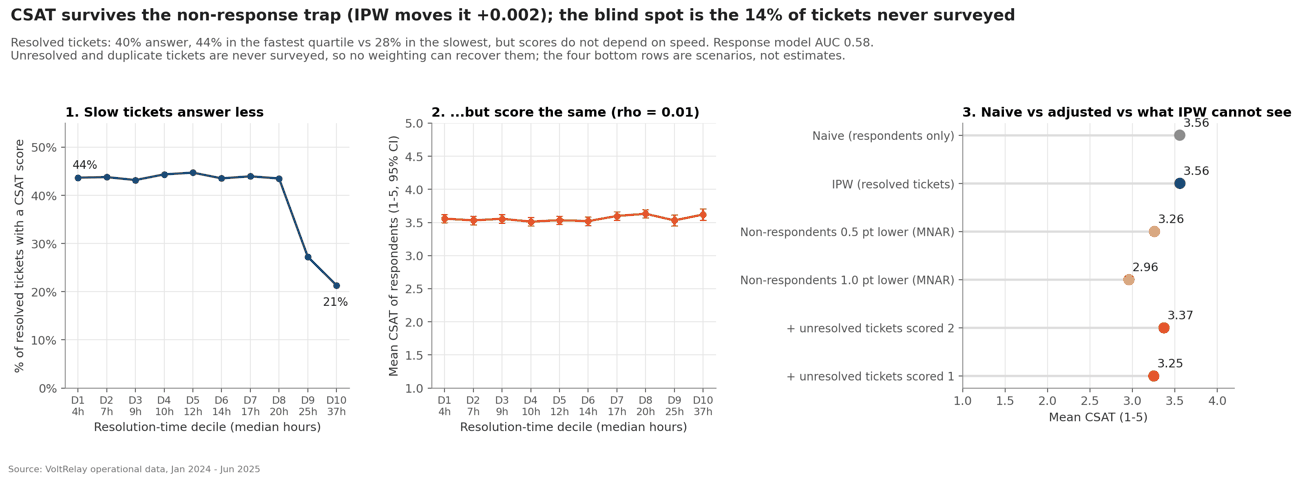

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_06_csat_naive_vs_ipw.png')

In [173]:
# HERO 3: CSAT naive vs adjusted
fig = plt.figure(figsize=(15.5, 5.6))
axs = [fig.add_axes([0.055, 0.15, 0.225, 0.58]), fig.add_axes([0.345, 0.15, 0.225, 0.58]), fig.add_axes([0.765, 0.15, 0.215, 0.58])]
xd = np.arange(1, len(dec) + 1)
xt = [f"D{i}\n{h:.0f}h" for i, h in zip(xd, dec["hours_med"].values)]
axs[0].plot(xd, dec["response"] * 100, color=PALETTE["primary"], lw=2, marker="o", ms=5)
axs[0].set_xticks(xd, xt, fontsize=9)
axs[0].set_xlabel("Resolution-time decile (median hours)")
axs[0].set_ylabel("% of resolved tickets with a CSAT score")
axs[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axs[0].set_ylim(0, 55)
axs[0].set_title("1. Slow tickets answer less", fontsize=11.5)
axs[0].annotate(f"{dec['response'].iloc[-1] * 100:.0f}%", (xd[-1], dec["response"].iloc[-1] * 100), xytext=(-12, -18), textcoords="offset points", fontsize=10, color=INK)
axs[0].annotate(f"{dec['response'].iloc[0] * 100:.0f}%", (xd[0], dec["response"].iloc[0] * 100), xytext=(-5, 8), textcoords="offset points", fontsize=10, color=INK)
se = dec["csat_sd"] / np.sqrt(dec["n_resp"])
axs[1].errorbar(xd, dec["csat"], yerr=1.96 * se, color=PALETTE["accent"], lw=2, marker="o", ms=5, capsize=3)
axs[1].set_xticks(xd, xt, fontsize=9)
axs[1].set_xlabel("Resolution-time decile (median hours)")
axs[1].set_ylabel("Mean CSAT of respondents (1-5, 95% CI)")
axs[1].set_ylim(1, 5)
axs[1].set_title(f"2. ...but score the same (rho = {rho_speed.statistic:.2f})", fontsize=11.5)
labels = list(scen.index)
yy = np.arange(len(labels))[::-1]
cols = [PALETTE["muted"], PALETTE["primary"], PALETTE["warn"], PALETTE["warn"], PALETTE["accent"], PALETTE["accent"]]
axs[2].hlines(yy, 1, scen.values, color="#DDDDDD", lw=2)
axs[2].scatter(scen.values, yy, c=cols, s=80, zorder=3)
axs[2].errorbar([naive, ipw], yy[:2], xerr=[[naive - ci_naive[0], ipw - ci_ipw[0]], [ci_naive[1] - naive, ci_ipw[1] - ipw]], fmt="none", ecolor=INK, capsize=3)
for y_, v_ in zip(yy, scen.values):
    axs[2].text(v_ + 0.04, y_ + 0.18, f"{v_:.2f}", fontsize=10.5, color=INK)
axs[2].set_yticks(yy, labels, fontsize=10)
axs[2].set_xlim(1, 4.2)
axs[2].set_xlabel("Mean CSAT (1-5)")
axs[2].set_title("3. Naive vs adjusted vs what IPW cannot see", fontsize=11.5)
axs[2].grid(axis="y", visible=False)
top = headline(fig, f"CSAT survives the non-response trap (IPW moves it {ipw - naive:+.3f}); the blind spot is the "
                    f"{pct((n_unres + n_dup) / N, 0)} of tickets never surveyed",
               f"Resolved tickets: {pct(r_rate, 0)} answer, {rq['response'].iloc[0] * 100:.0f}% in the fastest quartile vs {rq['response'].iloc[-1] * 100:.0f}% in the slowest, "
               f"but scores do not depend on speed. Response model AUC {auc:.2f}.\nUnresolved and duplicate tickets are never surveyed, so no "
               f"weighting can recover them; the four bottom rows are scenarios, not estimates.")
save_fig(fig, "q8_06_csat_naive_vs_ipw")

## 9 · Resolution by true issue, and ticket rates per 1K swaps by city, station and supplier

                                    tickets  unresolved  duplicate  median_res_h  p90_res_h  csat_response  csat_naive  csat_ipw  lapse30
issue5                                                                                                                                   
Battery (range or vehicle wording)    15912       0.118      0.023        13.100     29.800          0.346       3.551     3.550    0.078
App / QR (battery fingerprint)         5717       0.118      0.020        13.000     29.600          0.335       3.533     3.541    0.075
Stock-out                             11486       0.119      0.022        13.400     29.300          0.344       3.601     3.609    0.085
Long queue                             5648       0.118      0.016        13.100     28.700          0.348       3.503     3.507    0.094
Billing / pricing                      4617       0.113      0.021        13.300     29.400          0.344       3.565     3.558    0.072
unresolved share differs by issue?

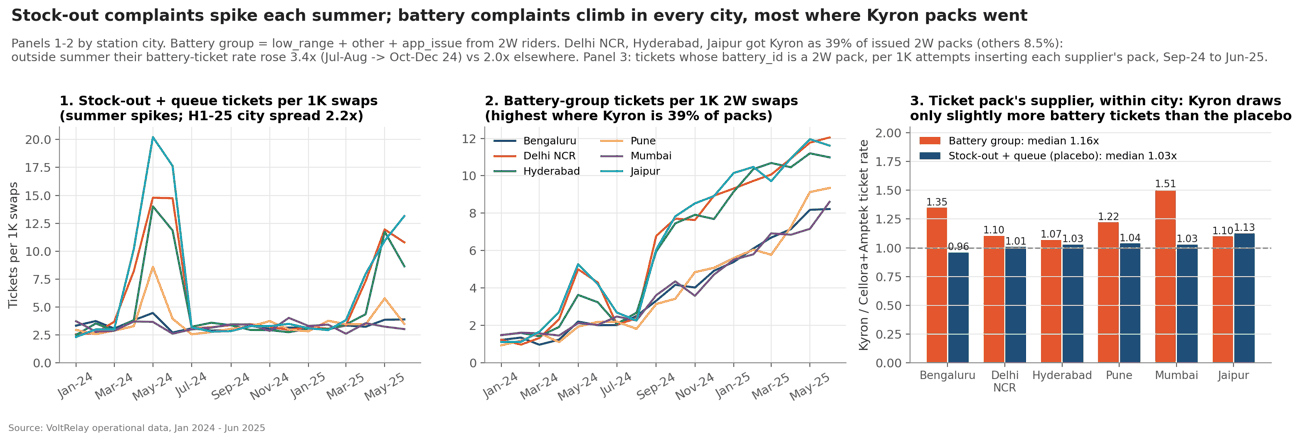

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q8_07_ticket_rates_city_supplier.png')

In [174]:
rb = (tk.group_by("issue5").agg(pl.len().alias("tickets"), (pl.col("resolution_status") == "unresolved").mean().alias("unresolved"),
                                (pl.col("resolution_status") == "duplicate").mean().alias("duplicate"),
                                pl.col("resolution_hours").median().alias("median_res_h"), pl.col("resolution_hours").quantile(0.9).alias("p90_res_h"),
                                pl.col("has_csat").mean().alias("csat_response"))
      .to_pandas().set_index("issue5").reindex(I5_ORDER))
rb = rb.join(cs_issue[["naive", "ipw"]].rename(columns={"naive": "csat_naive", "ipw": "csat_ipw"})).join(lp_rate[["lapse30"]])
print(rb.to_string(float_format=lambda v: f"{v:.3f}"))
rb.to_csv(TAB / "q8_resolution_by_true_issue.csv")
chi_u = stats.chi2_contingency(pd.crosstab(tk["issue5"].to_pandas(), (tk["resolution_status"] == "unresolved").to_pandas()))
print(f"unresolved share differs by issue? chi2 p={chi_u[1]:.2f}")

# city-month rates
svc = (tk.filter(pl.col("category").is_in(["no_battery_available", "long_queue"]) & pl.col("station_city").is_not_null())
       .group_by("station_city", "month").agg(pl.len().alias("n"))
       .join(swc, left_on=["station_city", "month"], right_on=["city", "month"]).with_columns((pl.col("n") / pl.col("swaps") * 1000).alias("rate")))
sw2c = sw_cmv.filter(pl.col("vehicle_class") == "2W").select("city", "month", pl.col("swaps").alias("swaps_2w"))
btc = (tk.filter(pl.col("category").is_in(["low_range", "other", "app_issue"]) & pl.col("station_city").is_not_null() & (pl.col("rider_vc") == "2W"))
       .group_by("station_city", "month").agg(pl.len().alias("n"))
       .join(sw2c, left_on=["station_city", "month"], right_on=["city", "month"]).with_columns((pl.col("n") / pl.col("swaps_2w") * 1000).alias("rate")))
# pooled H1-2025 city rates (large counts) + what differs between cities: Kyron share, pack SoH, heat
heat = (city_daily().filter(pl.col("date").is_between(pl.date(2025, 1, 1), pl.date(2025, 6, 30)))
        .group_by("city").agg(pl.col("max_temp_c").mean().alias("mean_max_temp_h1_25")))
kyc = (events(["is_completed", "city", "month", "vehicle_class", "supplier_out", "soh_out_pct"])
       .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W") & (pl.col("month") >= pl.date(2025, 1, 1)))
       .group_by("city").agg((pl.col("supplier_out") == "Kyron").mean().alias("kyron_share_2w"), pl.col("soh_out_pct").mean().alias("mean_issued_soh"))
       .collect(engine="streaming"))
city_h1 = (svc.filter(H1_25).group_by("station_city").agg((pl.col("n").sum() / pl.col("swaps").sum() * 1000).alias("svc_per_1k"))
           .join(btc.filter(H1_25).group_by("station_city").agg((pl.col("n").sum() / pl.col("swaps_2w").sum() * 1000).alias("batt_per_1k_2w")), on="station_city")
           .join(kyc, left_on="station_city", right_on="city").join(heat, left_on="station_city", right_on="city").sort("batt_per_1k_2w", descending=True))
show("H1-2025 by city: service and battery ticket rates vs Kyron share, issued SoH and heat", city_h1)
city_h1.write_csv(TAB / "q8_city_ticket_rates_h1_2025.csv")
spread_svc = float(city_h1["svc_per_1k"].max() / city_h1["svc_per_1k"].min())
spread_bat = float(city_h1["batt_per_1k_2w"].max() / city_h1["batt_per_1k_2w"].min())
r_heat = np.corrcoef(city_h1["batt_per_1k_2w"], city_h1["mean_max_temp_h1_25"])[0, 1]
r_kyc = np.corrcoef(city_h1["batt_per_1k_2w"], city_h1["kyron_share_2w"])[0, 1]
print(f"H1-25 max/min city ratio: stock-out+queue tickets {spread_svc:.1f}x vs battery tickets {spread_bat:.1f}x; across 6 cities battery rate vs "
      f"mean max temp r={r_heat:.2f}, vs Kyron share r={r_kyc:.2f} (n=6, descriptive only)")
# heat and Kyron coincide across cities; separate them in time: before Kyron (H1-24) the city gap is heat (and anything else) only.
# KY_CITIES, ky_hi, ky_lo and the non-summer dose test (Jul-Aug-24 -> Oct-Dec-24, with placebos) come from section 4.


def ky_city_ratio(period):
    g = (btc.filter(period).with_columns(pl.col("station_city").is_in(KY_CITIES).alias("ky"))
         .group_by("ky").agg((pl.col("n").sum() / pl.col("swaps_2w").sum() * 1000).alias("r")))
    return float(g.filter(pl.col("ky"))["r"].item()), float(g.filter(~pl.col("ky"))["r"].item())


(h24, m24), (h25, m25) = ky_city_ratio(H1_24), ky_city_ratio(H1_25)
print(f"high-Kyron cities {KY_CITIES} (Kyron {ky_hi * 100:.0f}% of issued 2W packs in H1-25) vs others ({ky_lo * 100:.1f}%): battery tickets per 1K 2W swaps "
      f"H1-24 {h24:.2f} vs {m24:.2f} (ratio {h24 / m24:.2f}, pre-Kyron, includes the hot-city summer spike) -> H1-25 {h25:.2f} vs {m25:.2f} "
      f"(ratio {h25 / m25:.2f}); increase {h25 - h24:+.2f} vs {m25 - m24:+.2f}")
print(f"non-summer dose test (section 4), battery group per 1K 2W swaps: high-Kyron cities {dz_b['kyron_cities_JulAug24']:.2f} -> "
      f"{dz_b['kyron_cities_OctDec24']:.2f} ({dz_b['kyron_change']:.2f}x); other cities {dz_b['other_cities_JulAug24']:.2f} -> "
      f"{dz_b['other_cities_OctDec24']:.2f} ({dz_b['other_change']:.2f}x); ratio of ratios {dz_b['ratio_of_ratios']:.2f}")
peak = svc.filter(pl.col("month") == pl.date(2025, 5, 1)).sort("rate", descending=True)
show("May-25 stock-out+queue tickets per 1K swaps by city", peak.select("station_city", "n", "swaps", "rate"))
show("Jun-25 battery-group tickets per 1K 2W swaps by city", btc.filter(pl.col("month") == pl.date(2025, 6, 1)).sort("rate", descending=True).select("station_city", "n", "swaps_2w", "rate"))
# Supplier attribution per ticket pack, within city, Sep-24..Jun-25: tickets whose battery_id is a Kyron (vs Cellora+Amptek) 2W
# pack, per 1K 2W attempts at which riders INSERTED a Kyron (vs Cellora+Amptek) pack - the ticket pack is the inserted pack.
# Placebo: stock-out+queue tickets. The issued-pack denominator used originally is kept below, labelled superseded.
att_city = (ins_cms.filter(pl.col("month") >= pl.date(2024, 9, 1)).group_by("city", (pl.col("supplier_in") == "Kyron").alias("ky"))
            .agg(pl.col("att").sum().alias("den")))
sup_city_sw = (sw_cmvs.filter((pl.col("vehicle_class") == "2W") & (pl.col("month") >= pl.date(2024, 9, 1)))
               .group_by("city", (pl.col("supplier_out") == "Kyron").alias("ky")).agg(pl.col("swaps").sum().alias("den")))


def within_city(cats, denom):
    t = (tk.filter((pl.col("pack_vc") == "2W") & POST_KY & pl.col("category").is_in(cats) & pl.col("station_city").is_not_null())
         .group_by(pl.col("station_city").alias("city"), pl.col("is_kyron").alias("ky")).agg(pl.len().alias("n")))
    w = denom.join(t, on=["city", "ky"], how="left").with_columns(pl.col("n").fill_null(0)).pivot(on="ky", index="city", values=["n", "den"])
    w = w.rename({c: c.replace("_true", "_ky").replace("_false", "_ca") for c in w.columns})
    return (w.with_columns(((pl.col("n_ky") / pl.col("den_ky")) / (pl.col("n_ca") / pl.col("den_ca"))).alias("ratio"),
                           (pl.col("n_ky") - pl.col("n_ca") / pl.col("den_ca") * pl.col("den_ky")).alias("excess"))
            .sort(pl.col("city").replace_strict({c: i for i, c in enumerate(CITIES)})))


wc_in = {k: within_city(c, att_city) for k, c in [("battery group", BATT), ("stock-out+queue", SVC), ("billing", ["billing_dispute"])]}
wc_iss = {k: within_city(c, sup_city_sw) for k, c in [("battery group", BATT), ("stock-out+queue", SVC)]}
n_bat_linked_post = int(wc_in["battery group"]["n_ky"].sum() + wc_in["battery group"]["n_ca"].sum())
for basis, dd in [("SUPERSEDED, per 1K swaps ISSUING the supplier's pack", wc_iss), ("per 1K attempts INSERTING the supplier's pack", wc_in)]:
    for k, w in dd.items():
        print(f"{basis} | {k}: within-city Kyron / Cellora+Amptek ticket-rate ratio {w['ratio'].min():.2f}-{w['ratio'].max():.2f} "
              f"(median {w['ratio'].median():.2f}); excess {w['excess'].sum():,.0f} of {int(w['n_ky'].sum() + w['n_ca'].sum()):,} linked tickets "
              f"({pct(w['excess'].sum() / (w['n_ky'].sum() + w['n_ca'].sum()))})")
wcb, wcs = wc_in["battery group"], wc_in["stock-out+queue"]
wc_tab = (wcb.select("city", pl.col("ratio").alias("battery_group_ratio"), pl.col("excess").alias("battery_group_excess"),
                     pl.col("n_ky").alias("battery_tickets_kyron"), pl.col("den_ky").alias("kyron_inserted_attempts"))
          .join(wcs.select("city", pl.col("ratio").alias("stockout_queue_ratio")), on="city")
          .join(wc_in["billing"].select("city", pl.col("ratio").alias("billing_ratio")), on="city")
          .join(wc_iss["battery group"].select("city", pl.col("ratio").alias("battery_group_ratio_issued_superseded")), on="city"))
wc_tab.write_csv(TAB / "q8_kyron_within_city_inserted.csv")
show("within-city Kyron / Cellora+Amptek ticket-rate ratios per inserted-pack attempt (Sep-24..Jun-25)", wc_tab)
print(f"Kyron 2W swaps Sep-24..Jun-25 (issued): {int(wc_iss['battery group']['den_ky'].sum()):,}; Kyron 2W inserted-pack attempts: "
      f"{int(wcb['den_ky'].sum()):,}; battery-group tickets with a linked 2W pack and a station city: {n_bat_linked_post:,}")

# station level: do text labels line up with station telemetry?
smo = station_month().group_by("station_id").agg(pl.col("attempts").sum(), pl.col("completed").sum(), pl.col("system_errors").sum(),
                                                 (pl.col("stockouts").sum() + pl.col("abandoned").sum() + pl.col("system_errors").sum()).alias("failures"),
                                                 pl.col("city").first())
stt = tk.filter(pl.col("station_id").is_not_null()).group_by("station_id").agg(
    pl.len().alias("tickets"),
    pl.col("category").is_in(["no_battery_available", "long_queue"]).sum().alias("svc"),
    pl.col("category").is_in(["low_range", "other", "app_issue"]).sum().alias("batt"),
    (pl.col("text_issue") == "station_hw_system").sum().alias("qr"),
    (pl.col("rider_comment") == "app crash ho gaya swap ke time").sum().alias("crash"),
    pl.col("category").is_in(["billing_dispute"]).sum().alias("bill"))
stt = smo.join(stt, on="station_id", how="left").fill_null(0).filter(pl.col("completed") >= 5000).with_columns(
    (pl.col("failures") / pl.col("attempts")).alias("fail_rate"), (pl.col("system_errors") / pl.col("attempts")).alias("syserr_rate"),
    *[(pl.col(c) / pl.col("attempts") * 1000).alias(f"{c}_per_1k") for c in ["tickets", "svc", "batt", "qr", "crash", "bill"]])
sp = lambda a_, b_: stats.spearmanr(stt[a_], stt[b_])
s1, s2, s3, s4, s5 = sp("svc_per_1k", "fail_rate"), sp("batt_per_1k", "fail_rate"), sp("qr_per_1k", "syserr_rate"), sp("crash_per_1k", "syserr_rate"), sp("bill_per_1k", "fail_rate")
print(f"stations with >=5K swaps: {stt.height}. Spearman: stock-out+queue tickets vs failure rate {s1.statistic:.2f} (p={s1.pvalue:.1e}); "
      f"battery-group tickets vs failure rate {s2.statistic:.2f} (p={s2.pvalue:.2f}); billing vs failure rate {s5.statistic:.2f} (p={s5.pvalue:.2f}); "
      f"QR-scan tickets vs system-error rate {s3.statistic:.2f} (p={s3.pvalue:.2f}); app-crash vs system-error rate {s4.statistic:.2f} (p={s4.pvalue:.2f})")
top10 = stt.sort("tickets_per_1k", descending=True).head(10).select("station_id", "city", "attempts", "tickets", "tickets_per_1k", "svc_per_1k", "batt_per_1k", "fail_rate")
show("top-10 stations by tickets per 1K attempts (>=5K swaps)", top10)
stt.sort("tickets_per_1k", descending=True).write_csv(TAB / "q8_station_ticket_rates.csv")
net = tk.group_by("month").agg(pl.len().alias("tickets")).join(msw, on="month").with_columns((pl.col("tickets") / pl.col("swaps_all") * 1000).alias("per_1k")).sort("month")
print(f"network tickets per 1K swaps: Jan-24 {net['per_1k'][0]:.2f} -> Jun-25 {net['per_1k'][-1]:.2f}; H1-24 "
      f"{net.filter(H1_24)['tickets'].sum() / net.filter(H1_24)['swaps_all'].sum() * 1000:.2f} vs H1-25 {net.filter(H1_25)['tickets'].sum() / net.filter(H1_25)['swaps_all'].sum() * 1000:.2f}")

fig, axs = plt.subplots(1, 3, figsize=(15.5, 5.0), sharex=False)
for c in CITIES:
    d = svc.filter(pl.col("station_city") == c).sort("month")
    axs[0].plot(pd.to_datetime(d["month"].to_pandas()), d["rate"], color=CITY_COLORS[c], lw=1.8, label=c)
    d = btc.filter(pl.col("station_city") == c).sort("month")
    axs[1].plot(pd.to_datetime(d["month"].to_pandas()), d["rate"], color=CITY_COLORS[c], lw=1.8, label=c)
axs[0].set_title(f"1. Stock-out + queue tickets per 1K swaps\n(summer spikes; H1-25 city spread {spread_svc:.1f}x)", fontsize=11.5)
axs[1].set_title(f"2. Battery-group tickets per 1K 2W swaps\n(highest where Kyron is {ky_hi * 100:.0f}% of packs)", fontsize=11.5)
axs[1].legend(fontsize=9, ncol=2, loc="upper left")
xc = np.arange(len(CITIES))
for k_, (wdf, col, lab) in enumerate([(wcb, PALETTE["accent"], "Battery group"), (wcs, PALETTE["primary"], "Stock-out + queue (placebo)")]):
    vals = wdf["ratio"].to_numpy()
    axs[2].bar(xc + (k_ - 0.5) * 0.38, vals, width=0.36, color=col, label=f"{lab}: median {np.median(vals):.2f}x")
    for xi, v_ in zip(xc + (k_ - 0.5) * 0.38, vals):
        axs[2].text(xi, v_ + 0.02, f"{v_:.2f}", ha="center", fontsize=8.5, color=INK)
axs[2].axhline(1, color=PALETTE["muted"], ls="--", lw=1.2)
axs[2].set_xticks(xc, [c.replace("Delhi NCR", "Delhi\nNCR") for c in wcb["city"].to_list()], fontsize=9.5)
axs[2].set_ylabel("Kyron / Cellora+Amptek ticket rate")
axs[2].set_ylim(0, 2.05)
axs[2].legend(loc="upper left", fontsize=9)
axs[2].set_title("3. Ticket pack's supplier, within city: Kyron draws\nonly slightly more battery tickets than the placebo", fontsize=11.5)
axs[2].grid(axis="x", visible=False)
for a_ in axs[:2]:
    a_.set_ylim(0, None)
    a_.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
    a_.tick_params(axis="x", labelrotation=30)
axs[0].set_ylabel("Tickets per 1K swaps")
top = headline(fig, "Stock-out complaints spike each summer; battery complaints climb in every city, most where Kyron packs went",
               f"Panels 1-2 by station city. Battery group = low_range + other + app_issue from 2W riders. {', '.join(KY_CITIES)} got Kyron as "
               f"{ky_hi * 100:.0f}% of issued 2W packs (others {ky_lo * 100:.1f}%):\noutside summer their battery-ticket rate rose "
               f"{dz_b['kyron_change']:.1f}x (Jul-Aug -> Oct-Dec 24) vs {dz_b['other_change']:.1f}x elsewhere. Panel 3: tickets whose battery_id is a "
               f"2W pack, per 1K attempts inserting each supplier's pack, Sep-24 to Jun-25.")
fig.tight_layout(rect=[0, 0, 1, top])
save_fig(fig, "q8_07_ticket_rates_city_supplier")

In [175]:
print(f"\nfigures: {sorted(p.name for p in FIG.glob('q8_*.png'))}")
print(f"tables: {sorted(p.name for p in TAB.glob('q8_*.csv'))}")
print(f"runtime {time.time() - T0:.1f}s")


figures: ['q8_01_category_vs_text_heatmap.png', 'q8_02_battery_fingerprint.png', 'q8_03_hidden_battery_complaints_kyron.png', 'q8_04_reported_range_km.png', 'q8_05_price_complaints_pilot.png', 'q8_06_csat_naive_vs_ipw.png', 'q8_07_ticket_rates_city_supplier.png']
tables: ['q8_battery_fingerprint_by_category.csv', 'q8_battery_fingerprint_by_text_issue.csv', 'q8_billing_rate_by_city.csv', 'q8_city_ticket_rates_h1_2025.csv', 'q8_comment_taxonomy.csv', 'q8_confusion_category_vs_text.csv', 'q8_csat_naive_ipw_scenarios.csv', 'q8_csat_response_by_speed_category.csv', 'q8_kyron_dose_test.csv', 'q8_kyron_within_city_inserted.csv', 'q8_lapse_after_ticket_by_issue.csv', 'q8_misfiled_vs_correct_battery_check.csv', 'q8_monthly_battery_complaints.csv', 'q8_pricing_did_robustness.csv', 'q8_reported_km_monthly.csv', 'q8_resolution_by_true_issue.csv', 'q8_station_ticket_rates.csv', 'q8_ticket_linked_attempt_validation.csv']
runtime 7.0s


In [176]:
# free memory between independent sections (each analysis re-reads what it needs from data/clean)
import gc, matplotlib.pyplot as plt
_big = [k for k, v in list(globals().items()) if not k.startswith('_') and type(v).__module__.split('.')[0] in ('polars', 'pandas', 'numpy', 'lightgbm', 'shap', 'sklearn', 'statsmodels', 'lifelines', 'scipy')]
for _k in _big:
    del globals()[_k]
gc.collect(); plt.close('all')
from common import *  # restore shared helpers in case a section shadowed a name
print(f'freed {len(_big)} objects')

freed 206 objects


## 12. Synthesis · drivers, budget decision, recommendations

# Q9 - Synthesis and budget decision (lead analyst)
**Question.** What is actually driving VoltRelay's service failures, new-rider churn and margin erosion, where does
performance vary most, and which of the four budget proposals - (a) more stations, (b) more batteries,
(c) network-wide pricing rollout, (d) long-term exclusive with the largest fleet partner - does the evidence support?

**Approach.**
1. Re-derive, with fresh code on the clean data, the headline numbers the integrated story rests on (scale, same-season
   failures, cm1 per swap under three wear conventions, failure concentration), so every analysis is quoted from one
   consistent base.
2. Re-test the points where the eight analyses disagreed (inventory/pre-charging as a heat lever, the heat trigger,
   the date the non-Kyron fleet reaches end of life, the margin level in 2025).
3. Size every budget option in the same units with the shared cost model: Apr-Jun failure-rate points, new-rider
   non-retention points, cm1 per swap, Rs lakh per month (H1-2025 run-rate volume) and one-off cost.
4. Save the key-number table and two synthesis figures (causal chain, budget scorecard).

Margin levels are *under our usage-based battery-depreciation assumption* (no salvage, 70% SoH end of life); trends and
differences are the robust part. Numbers marked "cited" come from the verified q1-q8 analyses and are printed here
so that every number in the synthesis is printed by this script.

In [177]:
import sys
import datetime as dt
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

try:
    ROOT = PROJECT_ROOT
except NameError:  # running inside a notebook
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import *  # noqa: E402,F401

set_style()
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(24); pl.Config.set_tbl_width_chars(220); pl.Config.set_fmt_str_lengths(60)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

QID = "q9"
HOT = ["Delhi NCR", "Jaipur", "Hyderabad"]
M = lambda y, m: dt.date(y, m, 1)  # noqa: E731
LAKH = 1e5
CRORE = 1e7
WIN = {
    "H1-24": [M(2024, m) for m in range(1, 7)],
    "Q1-24": [M(2024, m) for m in (1, 2, 3)],
    "Q2-24": [M(2024, m) for m in (4, 5, 6)],
    "Jul-Aug-24": [M(2024, 7), M(2024, 8)],
    "Oct-24..Mar-25": [M(2024, m) for m in (10, 11, 12)] + [M(2025, m) for m in (1, 2, 3)],
    "Q1-25": [M(2025, m) for m in (1, 2, 3)],
    "Q2-25": [M(2025, m) for m in (4, 5, 6)],
    "H1-25": [M(2025, m) for m in range(1, 7)],
}
CUR_TERMS = [M(2024, 11), M(2024, 12)] + [M(2025, m) for m in range(1, 7)]  # after the ZipDrop amendment (q5 window)
PEAK_H = [12, 13, 19, 20, 21, 22]                 # data-verified pilot bands (q5, q7)
OFF_H = [23, 0, 1, 2, 3, 4, 5, 14, 15, 16]


def show(title, df):
    print(f"\n--- {title}")
    print(df)

## 1. How the network performed: one consistent set of headline numbers
Monthly panel by vehicle class from the clean events (test stations excluded, firmware timestamps fixed). For every
window we compute cm1 per swap three ways: the shared per-cycle wear model (base); wear stopped at 70% EOL (cap);
and post-EOL issues charged at the Cellora class wear (the better economic comparator, q1). The Kyron gap replaces each
Kyron-issued swap's wear with the Cellora wear per swap of the same class (q1's counterfactual).

In [178]:
ev_cols = ["month", "vehicle_class", "supplier_out", "is_completed", "is_service_failure", "revenue", "energy_cost",
           "wear_cost", "fixed_cost", "soh_out_pct", "expansion_wave"]
mon = (events(ev_cols)
       .with_columns(pe=pl.col("is_completed") & (pl.col("soh_out_pct") < EOL_SOH),
                     ky=pl.col("is_completed") & (pl.col("supplier_out") == "Kyron"),
                     cel=pl.col("is_completed") & (pl.col("supplier_out") == "Cellora"),
                     launch=pl.col("expansion_wave") == "Launch")
       .group_by(["month", "vehicle_class"])
       .agg(attempts=pl.len(), swaps=pl.col("is_completed").sum(), failures=pl.col("is_service_failure").sum(),
            revenue=pl.col("revenue").sum(), energy=pl.col("energy_cost").sum(), wear=pl.col("wear_cost").sum(),
            fixed=pl.col("fixed_cost").sum(),
            pe_swaps=pl.col("pe").sum(), pe_wear=pl.col("wear_cost").filter(pl.col("pe")).sum(),
            ky_swaps=pl.col("ky").sum(), ky_wear=pl.col("wear_cost").filter(pl.col("ky")).sum(),
            cel_swaps=pl.col("cel").sum(), cel_wear=pl.col("wear_cost").filter(pl.col("cel")).sum(),
            l_att=pl.col("launch").sum(), l_fail=(pl.col("launch") & pl.col("is_service_failure")).sum())
       .sort(["month", "vehicle_class"])
       .collect(engine="streaming"))
REF = {r["vehicle_class"]: r["cel_wear"] / r["cel_swaps"]
       for r in mon.group_by("vehicle_class").agg(pl.col("cel_wear").sum(), pl.col("cel_swaps").sum()).iter_rows(named=True)}
print("Cellora reference wear per swap (full window, Rs):", {k: round(v, 2) for k, v in REF.items()})


def window(months):
    d = mon.filter(pl.col("month").is_in(months))
    s = d.select(pl.exclude("month", "vehicle_class").sum()).row(0, named=True)
    by = {r["vehicle_class"]: r for r in d.group_by("vehicle_class").agg(pl.col("pe_swaps").sum(), pl.col("ky_swaps").sum()).iter_rows(named=True)}
    n, sw = len(months), s["swaps"]
    cm1 = (s["revenue"] - s["energy"] - s["wear"]) / sw
    pe_ref = sum(by.get(c, {}).get("pe_swaps", 0) * REF[c] for c in REF)
    ky_ref = sum(by.get(c, {}).get("ky_swaps", 0) * REF[c] for c in REF)
    gap = (s["ky_wear"] - ky_ref) / sw
    return dict(months=n, attempts=s["attempts"], swaps=sw, swaps_pm=sw / n, failures=s["failures"],
                fail_rate=s["failures"] / s["attempts"], launch_fail_rate=s["l_fail"] / s["l_att"],
                revenue_pm=s["revenue"] / n, rev_ps=s["revenue"] / sw, energy_ps=s["energy"] / sw, wear_ps=s["wear"] / sw,
                fixed_ps=s["fixed"] / sw, cm1_ps=cm1, cm2_ps=cm1 - s["fixed"] / sw,
                cm1_cap_ps=cm1 + s["pe_wear"] / sw, cm1_celwear_ps=cm1 + (s["pe_wear"] - pe_ref) / sw,
                post_eol_swaps=s["pe_swaps"], post_eol_wear=s["pe_wear"],
                kyron_gap_ps=gap, cm1_allcellora_ps=cm1 + gap, cm2_allcellora_ps=cm1 - s["fixed"] / sw + gap)


W = {k: window(v) for k, v in WIN.items()}
wtab = pd.DataFrame(W).T
show("Window KPIs (per swap in Rs; rates as shares)", wtab[["swaps_pm", "fail_rate", "launch_fail_rate", "rev_ps", "cm1_ps",
                                                           "cm1_cap_ps", "cm1_celwear_ps", "cm2_ps", "kyron_gap_ps",
                                                           "cm1_allcellora_ps", "cm2_allcellora_ps", "post_eol_swaps"]].round(3))
wtab.to_csv(TAB / f"{QID}_window_kpis.csv")

h24, h25 = W["H1-24"], W["H1-25"]
mult = {k: h25[k] / h24[k] for k in ("attempts", "swaps", "failures", "revenue_pm")}
print("\nH1-25 vs H1-24 multiples:", {k: round(v, 2) for k, v in mult.items()})
m_all = mon.group_by("month").agg(pl.col("attempts", "swaps", "failures", "revenue").sum()).sort("month")
jan24 = m_all.filter(pl.col("month") == M(2024, 1)).row(0, named=True)
jun25 = m_all.filter(pl.col("month") == M(2025, 6)).row(0, named=True)
naive_fail_x, naive_swap_x = jun25["failures"] / jan24["failures"], jun25["swaps"] / jan24["swaps"]
print(f"Jun-25: {jun25['swaps']:,} completed swaps, revenue Rs{jun25['revenue']/1e6:.2f}M (Jan-24: {jan24['swaps']:,}, Rs{jan24['revenue']/1e6:.2f}M)")
print(f"Naive Jan-24 -> Jun-25: failures x{naive_fail_x:.2f}, swaps x{naive_swap_x:.2f} "
      f"({jan24['failures']/jan24['attempts']:.2%} -> {jun25['failures']/jun25['attempts']:.2%})")
print(f"Same season Apr-Jun: network {W['Q2-24']['fail_rate']:.2%} -> {W['Q2-25']['fail_rate']:.2%}; "
      f"Launch panel {W['Q2-24']['launch_fail_rate']:.2%} -> {W['Q2-25']['launch_fail_rate']:.2%}; "
      f"failed attempts {W['Q2-24']['failures']:,} -> {W['Q2-25']['failures']:,} "
      f"(+{W['Q2-25']['failures']/W['Q2-24']['failures']-1:.1%}); swaps x{W['Q2-25']['swaps']/W['Q2-24']['swaps']:.2f}")
print(f"cm1/swap same season Q1-24 {W['Q1-24']['cm1_ps']:+.2f} -> Q1-25 {W['Q1-25']['cm1_ps']:+.2f}; "
      f"Kyron gap Q1-25 {W['Q1-25']['kyron_gap_ps']:+.2f}/swap; Q1-25 with Cellora-grade packs: cm1 "
      f"{W['Q1-25']['cm1_allcellora_ps']:+.2f}, cm2 {W['Q1-25']['cm2_allcellora_ps']:+.2f}")
print(f"H1-25 cm1/swap: per-cycle model {h25['cm1_ps']:+.2f} | post-EOL at Cellora wear {h25['cm1_celwear_ps']:+.2f} | "
      f"wear stops at EOL {h25['cm1_cap_ps']:+.2f}; post-EOL swaps {h25['post_eol_swaps']:,}, wear charged on them "
      f"Rs{h25['post_eol_wear']/1e6:.2f}M")

Cellora reference wear per swap (full window, Rs): {'2W': 31.85, '3W': 76.19}

--- Window KPIs (per swap in Rs; rates as shares)
                  swaps_pm  fail_rate  launch_fail_rate  rev_ps  cm1_ps  cm1_cap_ps  cm1_celwear_ps  cm2_ps  kyron_gap_ps  cm1_allcellora_ps  cm2_allcellora_ps  post_eol_swaps
H1-24          116,757.333      0.070             0.070  59.887   0.637       0.637           0.637 -17.427         0.896              1.533            -16.531           0.000
Q1-24          108,031.000      0.040             0.040  59.884   0.273       0.273           0.273 -19.250         0.910              1.183            -18.340           0.000
Q2-24          125,483.667      0.095             0.095  59.889   0.951       0.951           0.951 -15.857         0.884              1.835            -14.973           0.000
Jul-Aug-24     155,149.500      0.039             0.039  65.020   6.747       6.747           6.747  -7.151         0.861              7.608             -6.290        

## 2. Where failures concentrate (Apr-Jun) and what a Gen1 fix is worth
Excess = failures above the Jul-Mar network rate. The Gen1 counterfactual applies the same-city, same-month Gen3
(or Gen2) failure rate to the 36 hot-city Gen1 stations' Apr-Jun 2025 attempts (a naive like-for-like check that
agrees with q2's Mantel-Haenszel and q3's model estimates). Generation is confounded with site age, so this is an
upper-end association, to be validated by a matched pilot.

In [179]:
st = stations().filter(~pl.col("is_test"))
hot_g1 = st.filter(pl.col("city").is_in(HOT) & (pl.col("charger_generation") == "Gen1"))["station_id"].to_list()
print("hot-city Gen1 stations:", len(hot_g1), st.filter(pl.col("station_id").is_in(hot_g1)).group_by("city").len().sort("city").rows())
offseason = mon.filter(~pl.col("month").dt.month().is_in([4, 5, 6])).select(pl.col("failures").sum() / pl.col("attempts").sum()).item()
print(f"Jul-Mar baseline failure rate: {offseason:.2%}")

aj = (events(["month", "city", "charger_generation", "is_service_failure", "is_completed", "revenue"])
      .filter(pl.col("month").dt.month().is_in([4, 5, 6]))
      .with_columns(year=pl.col("month").dt.year(),
                    seg=pl.when(pl.col("city").is_in(HOT)).then(pl.lit("Hot city ") + pl.col("charger_generation"))
                    .otherwise(pl.lit("Other cities")))
      .group_by(["year", "month", "city", "charger_generation", "seg"])
      .agg(att=pl.len(), fail=pl.col("is_service_failure").sum(), swaps=pl.col("is_completed").sum(), rev=pl.col("revenue").sum())
      .collect(engine="streaming"))
seg = (aj.group_by(["year", "seg"]).agg(pl.col("att", "fail", "swaps", "rev").sum())
       .with_columns(excess=pl.col("fail") - pl.col("att") * offseason)
       .with_columns(rate=pl.col("fail") / pl.col("att"),
                     sh_att=pl.col("att") / pl.col("att").sum().over("year"),
                     sh_fail=pl.col("fail") / pl.col("fail").sum().over("year"),
                     sh_excess=pl.col("excess") / pl.col("excess").clip(lower_bound=0).sum().over("year"))
       .sort(["year", "seg"]))
show("Apr-Jun failure concentration by segment", seg)
seg.write_csv(TAB / f"{QID}_concentration_aprjun.csv")
hg25 = seg.filter((pl.col("year") == 2025) & (pl.col("seg") == "Hot city Gen1")).row(0, named=True)
both = seg.group_by("seg").agg(pl.col("att", "fail", "excess").sum()).with_columns(
    sh_att=pl.col("att") / pl.col("att").sum(), sh_excess=pl.col("excess") / pl.col("excess").clip(lower_bound=0).sum())
hg_both = both.filter(pl.col("seg") == "Hot city Gen1").row(0, named=True)
print(f"Hot-city Gen1, Apr-Jun 2025: {hg25['sh_att']:.1%} of attempts, {hg25['sh_fail']:.1%} of failures, "
      f"{hg25['sh_excess']:.1%} of excess, rate {hg25['rate']:.2%}; both summers: {hg_both['sh_att']:.1%} of Apr-Jun attempts, "
      f"{hg_both['sh_excess']:.1%} of excess")

a25 = aj.filter((pl.col("year") == 2025) & pl.col("city").is_in(HOT))
rate_cm = a25.select("month", "city", "charger_generation", (pl.col("fail") / pl.col("att")).alias("r"))
g1 = a25.filter(pl.col("charger_generation") == "Gen1")
for g in ("Gen2", "Gen3"):
    g1 = g1.join(rate_cm.filter(pl.col("charger_generation") == g).select("month", "city", pl.col("r").alias(f"r_{g}")),
                 on=["month", "city"], how="left")
cf = g1.with_columns(avoid_g2=pl.col("fail") - pl.col("att") * pl.col("r_Gen2"),
                     avoid_g3=pl.col("fail") - pl.col("att") * pl.col("r_Gen3"))
show("Gen1 counterfactual by city-month (Apr-Jun 2025)", cf.select("month", "city", "att", "fail", "r_Gen2", "r_Gen3", "avoid_g2", "avoid_g3"))
cf.write_csv(TAB / f"{QID}_gen1_counterfactual.csv")
AV2, AV3 = cf["avoid_g2"].sum(), cf["avoid_g3"].sum()
G1F = cf["fail"].sum()
A_G2, A_G3 = AV2 / G1F, AV3 / G1F                      # share of hot-city Gen1 failures avoided
aj25 = aj.filter(pl.col("year") == 2025).select(pl.col("att", "fail", "swaps", "rev").sum()).row(0, named=True)
NET_AJ25 = aj25["fail"] / aj25["att"]
rate_after2, rate_after3 = (aj25["fail"] - AV2) / aj25["att"], (aj25["fail"] - AV3) / aj25["att"]
REV_PS_HG1 = hg25["rev"] / hg25["swaps"]
print(f"Avoided failed attempts, Apr-Jun 2025: Gen2-like {AV2:,.0f} ({AV2/aj25['fail']:.1%} of network failures), "
      f"Gen3-like {AV3:,.0f} ({AV3/aj25['fail']:.1%}); network Apr-Jun rate {NET_AJ25:.2%} -> {rate_after2:.2%} / {rate_after3:.2%}")
print(f"Share of hot-city Gen1 failures avoided: Gen2-like {A_G2:.1%}, Gen3-like {A_G3:.1%}; revenue per swap at these "
      f"stations Rs{REV_PS_HG1:.2f}; revenue recovered per summer if each failure is a lost swap: Rs{AV2*REV_PS_HG1/1e6:.2f}M-"
      f"Rs{AV3*REV_PS_HG1/1e6:.2f}M")
TICKETS_PER_FAIL = 1 / 9.9                      # cited, q3: about one ticket per 9.9 extra failed attempts
print(f"Tickets avoided per summer (q3 slope, cited): {AV2*TICKETS_PER_FAIL:,.0f}-{AV3*TICKETS_PER_FAIL:,.0f}")

hot-city Gen1 stations: 36 [('Delhi NCR', 13), ('Hyderabad', 13), ('Jaipur', 10)]
Jul-Mar baseline failure rate: 3.91%

--- Apr-Jun failure concentration by segment
shape: (7, 11)
┌──────┬───────────────┬────────┬───────┬────────┬───────────────┬────────────┬────────┬────────┬─────────┬───────────┐
│ year ┆ seg           ┆ att    ┆ fail  ┆ swaps  ┆ rev           ┆ excess     ┆ rate   ┆ sh_att ┆ sh_fail ┆ sh_excess │
│ ---  ┆ ---           ┆ ---    ┆ ---   ┆ ---    ┆ ---           ┆ ---        ┆ ---    ┆ ---    ┆ ---     ┆ ---       │
│ i32  ┆ str           ┆ u32    ┆ u32   ┆ u32    ┆ f32           ┆ f64        ┆ f64    ┆ f64    ┆ f64     ┆ f64       │
╞══════╪═══════════════╪════════╪═══════╪════════╪═══════════════╪════════════╪════════╪════════╪═════════╪═══════════╡
│ 2024 ┆ Hot city Gen1 ┆ 172800 ┆ 26746 ┆ 145328 ┆ 8705631.0000  ┆ 19989.3939 ┆ 0.1548 ┆ 0.4133 ┆ 0.6717  ┆ 0.8516    │
│ 2024 ┆ Hot city Gen2 ┆ 36078  ┆ 2864  ┆ 33060  ┆ 1967683.3750  ┆ 1453.3239  ┆ 0.0794 ┆ 0.0863 ┆ 0.

## 3. Contradictions between analyses, re-tested
**C1. Is hourly inventory (pre-charging, more packs) a heat lever?** q3 and q6 recommend pre-charging and
pre-positioning packs; q2 (verified) says hourly stock does not predict failing hours. We re-test at the 36 hot-city
Gen1 stations, Apr-Jun, on station-hours with telemetry ok and at least one 2W attempt: 2W stockout rate by the
hour's minimum charged-2W stock, within day type (hot day = the day's peak cabinet temperature >= 45 C) and window.

In [180]:
evh = (events(["station_id", "date", "hour", "month", "vehicle_class", "is_stockout"])
       .filter(pl.col("station_id").is_in(hot_g1) & pl.col("month").dt.month().is_in([4, 5, 6]) & (pl.col("vehicle_class") == "2W"))
       .group_by(["station_id", "date", "hour"]).agg(att=pl.len(), so=pl.col("is_stockout").sum())
       .collect(engine="streaming"))
hh = (hourly(["station_id", "date", "hour", "charged_2w_min", "cabinet_temp_c", "telemetry_status"])
      .filter(pl.col("station_id").is_in(hot_g1) & pl.col("date").dt.month().is_in([4, 5, 6]))
      .collect())
peak = hh.group_by(["station_id", "date"]).agg(peak_cab=pl.col("cabinet_temp_c").max())
inv = (evh.join(hh.filter((pl.col("telemetry_status") == "ok") & pl.col("charged_2w_min").is_not_null()),
                on=["station_id", "date", "hour"], how="inner")
       .join(peak, on=["station_id", "date"], how="left")
       .with_columns(day=pl.when(pl.col("peak_cab") >= 45).then(pl.lit("hot day (peak cabinet >=45C)")).otherwise(pl.lit("other Apr-Jun day")),
                     win=pl.when(pl.col("hour").is_between(19, 22)).then(pl.lit("19-22h")).otherwise(pl.lit("other hours")),
                     stock=pl.when(pl.col("charged_2w_min") <= 0).then(pl.lit("0"))
                     .when(pl.col("charged_2w_min") <= 2).then(pl.lit("1-2"))
                     .when(pl.col("charged_2w_min") <= 5).then(pl.lit("3-5")).otherwise(pl.lit("6+"))))
crude = inv.group_by(pl.col("stock") == "0").agg(pl.col("att", "so").sum()).with_columns(rate=pl.col("so") / pl.col("att"))
show("C1 pooled (crude): stockout rate, zero-stock hour vs stocked", crude)
inv_tab = (inv.group_by(["day", "win", "stock"]).agg(pl.col("att", "so").sum(), hours=pl.len())
           .with_columns(rate=pl.col("so") / pl.col("att")).sort(["day", "win", "stock"]))
show("C1 within day type x window: 2W stockout rate by charged-2W stock", inv_tab)
inv_tab.write_csv(TAB / f"{QID}_inventory_check.csv")
hot_eve = inv_tab.filter((pl.col("day").str.starts_with("hot")) & (pl.col("win") == "19-22h"))
hot_oth = inv_tab.filter((pl.col("day").str.starts_with("hot")) & (pl.col("win") == "other hours"))
print(f"Hot days, 19-22h: stockout rate across stock buckets {hot_eve['rate'].min():.1%}-{hot_eve['rate'].max():.1%}; "
      f"other hours {hot_oth['rate'].min():.1%}-{hot_oth['rate'].max():.1%}")


--- C1 pooled (crude): stockout rate, zero-stock hour vs stocked
shape: (2, 4)
┌───────┬────────┬───────┬────────┐
│ stock ┆ att    ┆ so    ┆ rate   │
│ ---   ┆ ---    ┆ ---   ┆ ---    │
│ bool  ┆ u32    ┆ u32   ┆ f64    │
╞═══════╪════════╪═══════╪════════╡
│ false ┆ 347395 ┆ 34783 ┆ 0.1001 │
│ true  ┆ 32805  ┆ 3025  ┆ 0.0922 │
└───────┴────────┴───────┴────────┘

--- C1 within day type x window: 2W stockout rate by charged-2W stock
shape: (16, 7)
┌──────────────────────────────┬─────────────┬───────┬───────┬───────┬───────┬────────┐
│ day                          ┆ win         ┆ stock ┆ att   ┆ so    ┆ hours ┆ rate   │
│ ---                          ┆ ---         ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---    │
│ str                          ┆ str         ┆ str   ┆ u32   ┆ u32   ┆ u32   ┆ f64    │
╞══════════════════════════════╪═════════════╪═══════╪═══════╪═══════╪═══════╪════════╡
│ hot day (peak cabinet >=45C) ┆ 19-22h      ┆ 0     ┆ 1652  ┆ 291   ┆ 238   ┆ 0.1762 │
│ hot day (peak ca

**C2. Which heat trigger?** q3 suggests acting on forecast heat-alert days; q2 says the alert fires only around 42 C.
City-day failure rate by daily maximum temperature, with the share of days carrying an official heat alert.

In [181]:
cdy = (events(["city", "date", "is_service_failure"]).group_by(["city", "date"])
       .agg(att=pl.len(), fail=pl.col("is_service_failure").sum()).collect(engine="streaming")
       .join(city_daily().select("city", pl.col("date").cast(pl.Date), "max_temp_c", pl.col("heat_alert").cast(pl.Float64)),
             on=["city", "date"], how="left"))
heat = (cdy.with_columns(tbin=pl.col("max_temp_c").cut([34, 36, 38, 42], labels=["<34C", "34-36C", "36-38C", "38-42C", ">=42C"], left_closed=True))
        .group_by("tbin").agg(days=pl.len(), att=pl.col("att").sum(), fail=pl.col("fail").sum(), alert_share=pl.col("heat_alert").mean())
        .with_columns(rate=pl.col("fail") / pl.col("att")).sort("tbin"))
show("C2 failure rate by city-day max temperature", heat)
heat.write_csv(TAB / f"{QID}_heat_threshold.csv")
HEAT = {r["tbin"]: r for r in heat.iter_rows(named=True)}


--- C2 failure rate by city-day max temperature
shape: (5, 6)
┌────────┬──────┬─────────┬────────┬─────────────┬────────┐
│ tbin   ┆ days ┆ att     ┆ fail   ┆ alert_share ┆ rate   │
│ ---    ┆ ---  ┆ ---     ┆ ---    ┆ ---         ┆ ---    │
│ enum   ┆ u32  ┆ u32     ┆ u32    ┆ f64         ┆ f64    │
╞════════╪══════╪═════════╪════════╪═════════════╪════════╡
│ <34C   ┆ 2620 ┆ 2941016 ┆ 115265 ┆ 0.0000      ┆ 0.0392 │
│ 34-36C ┆ 149  ┆ 202049  ┆ 9687   ┆ 0.0000      ┆ 0.0479 │
│ 36-38C ┆ 156  ┆ 209264  ┆ 20960  ┆ 0.0000      ┆ 0.1002 │
│ 38-42C ┆ 206  ┆ 271529  ┆ 38194  ┆ 0.0000      ┆ 0.1407 │
│ >=42C  ┆ 151  ┆ 191124  ┆ 27743  ┆ 0.9934      ┆ 0.1452 │
└────────┴──────┴─────────┴────────┴─────────────┴────────┘


**C3. When does the non-Kyron fleet reach end of life?** q1 extrapolated returned-pack SoH (about Feb-2026); q4
projected Cellora/Amptek life at about 832 days (about Apr-2026). We project each pack from its own calendar fade
(initial SoH minus SoH on 30-Jun-2025, over days since first seen; q4 shows fade is calendar-driven) and, as a second
method, extrapolate the last six months of issued-pack SoH for non-Kyron 2W packs.

In [182]:
ASOF = dt.datetime(2025, 6, 30)
BAD_LOTS = ["KY-2407", "KY-2408", "KY-2409"]
bt = (batteries()
      .with_columns(days=(pl.lit(ASOF) - pl.col("first_seen")).dt.total_seconds() / 86400,
                    grp=pl.when(pl.col("manufacturing_lot").is_in(BAD_LOTS)).then(pl.lit("Kyron bad lots"))
                    .when(pl.col("supplier") == "Kyron").then(pl.lit("Kyron later lots")).otherwise(pl.lit("Cellora/Amptek")))
      .with_columns(fade_pd=(pl.col("initial_soh_pct") - pl.col("current_soh_pct")) / pl.col("days"))
      .with_columns(days_to_eol=(pl.col("current_soh_pct") - EOL_SOH) / pl.col("fade_pd"),
                    life_days=(pl.col("initial_soh_pct") - EOL_SOH) / pl.col("fade_pd")))
btp = bt.to_pandas()
btp["eol_date"] = pd.Timestamp(ASOF) + pd.to_timedelta(btp["days_to_eol"], unit="D")
fleet = (btp.groupby(["grp", "vehicle_class"])
         .agg(packs=("battery_id", "size"), cost_mean=("purchase_cost_inr", "mean"), cost_total=("purchase_cost_inr", "sum"),
              soh_now=("current_soh_pct", "mean"), fade_pd_median=("fade_pd", "median"), life_days_median=("life_days", "median"),
              eol_p10=("eol_date", lambda s: s.quantile(0.10)), eol_p50=("eol_date", lambda s: s.quantile(0.50)),
              eol_p90=("eol_date", lambda s: s.quantile(0.90)),
              share_eol_by_apr26=("eol_date", lambda s: (s < pd.Timestamp("2026-04-01")).mean()))
         .reset_index())
show("C3 fleet end-of-life projection (per-pack calendar fade)", fleet)
fleet.to_csv(TAB / f"{QID}_fleet_eol_projection.csv", index=False)
nk2 = fleet[(fleet.grp == "Cellora/Amptek") & (fleet.vehicle_class == "2W")].iloc[0]
nk3 = fleet[(fleet.grp == "Cellora/Amptek") & (fleet.vehicle_class == "3W")].iloc[0]
bad = fleet[fleet.grp == "Kyron bad lots"]
bad_capex = float(bad.cost_total.sum())
soh_trend = (events(["month", "vehicle_class", "supplier_out", "is_completed", "soh_out_pct"])
             .filter(pl.col("is_completed") & (pl.col("vehicle_class") == "2W") & (pl.col("supplier_out") != "Kyron")
                     & pl.col("month").is_in(WIN["H1-25"]))
             .group_by("month").agg(soh=pl.col("soh_out_pct").mean()).sort("month").collect(engine="streaming"))
x = np.arange(len(soh_trend)); slope, icpt = np.polyfit(x, soh_trend["soh"].to_numpy(), 1)
months_to_70 = (soh_trend["soh"][-1] - EOL_SOH) / -slope
trend_date = pd.Timestamp("2025-06-15") + pd.DateOffset(months=int(np.floor(months_to_70)))
print(f"Issued non-Kyron 2W SoH Jan-Jun 2025: {soh_trend['soh'][0]:.1f} -> {soh_trend['soh'][-1]:.1f} "
      f"({slope:+.2f} pts/month) -> 70% in {months_to_70:.1f} months (about {trend_date:%b-%Y})")
print(f"Per-pack calendar fade: non-Kyron 2W median EOL {nk2.eol_p50:%b-%Y} (p10 {nk2.eol_p10:%b-%Y}, p90 {nk2.eol_p90:%b-%Y}); "
      f"{nk2.share_eol_by_apr26:.0%} before Apr-2026; renewal capex Rs{nk2.cost_total/CRORE:.2f} Cr for {nk2.packs:,} packs; "
      f"3W non-Kyron median EOL {nk3.eol_p50:%b-%Y}, Rs{nk3.cost_total/CRORE:.2f} Cr for {nk3.packs:,} packs")
print(f"Kyron bad-lot replacement capex (1:1): Rs{bad_capex/CRORE:.2f} Cr for {int(bad.packs.sum()):,} packs")


--- C3 fleet end-of-life projection (per-pack calendar fade)
                grp vehicle_class  packs  cost_mean  cost_total  soh_now  fade_pd_median  life_days_median                       eol_p10                       eol_p50                       eol_p90  share_eol_by_apr26
0    Cellora/Amptek            2W   4133 31,986.487   132200150   79.967           0.035           827.237 2026-02-24 13:29:27.073170944 2026-04-08 10:19:37.202072576 2026-05-27 06:29:22.635260416               0.414
1    Cellora/Amptek            3W    729 67,918.649    49512695   86.520           0.023         1,252.833 2027-03-19 18:50:53.627242240 2027-06-08 15:19:26.701612800 2027-09-12 21:50:22.122856960               0.000
2    Kyron bad lots            2W   1385 31,981.684    44294633   60.532           0.132           220.774 2025-04-06 20:03:33.395963136 2025-04-19 11:03:45.773195776 2025-05-03 08:42:04.128048384               1.000
3    Kyron bad lots            3W     76 68,237.803     5186073   69.2

**C4. Kyron margin: q1's +Rs16.8/swap vs q4's "no cm1 gain from replacement".** Both hold; they answer different
questions. q1 compares buying Kyron-grade vs Cellora-grade packs (a procurement choice, clean window Q1-25). q4
compares replacing packs that are already past end of life vs running them on, which under book depreciation look free
(wear stops at EOL) but deliver about 26% less range. The forward budget question is q1's: packs must be replaced at EOL
anyway, and the grade bought decides about Rs16.8 of cm1 per swap at a 25% share of issues.

In [183]:
print(f"Kyron-grade vs Cellora-grade wear gap, Q1-25 (clean window): {W['Q1-25']['kyron_gap_ps']:+.2f} Rs/swap; "
      f"Oct-24..Mar-25 {W['Oct-24..Mar-25']['kyron_gap_ps']:+.2f}; at H1-25 volume Rs"
      f"{W['Q1-25']['kyron_gap_ps']*h25['swaps_pm']/LAKH:.1f} L/month")

Kyron-grade vs Cellora-grade wear gap, Q1-25 (clean window): +16.82 Rs/swap; Oct-24..Mar-25 +16.79; at H1-25 volume Rs47.7 L/month


## 4. New-rider retention: how much would the Gen1 fix move it?
New riders = signed up from 2024-01-01; day 0 = first clean attempt; early failures = service failures in days 0-13;
retained = a completed swap in days 31-60 (q6's outcome; eligible = first attempt before 2025-05-01). For each rider we
compute the probability of still having 2+ early failures if failures at the 36 hot-city Gen1 stations in Apr-Jun were
avoided at the Gen3-like (or Gen2-like) share from section 2, then convert the drop in riders with 2+ early failures
into retention points with q6's adjusted effect (2+ vs 0-1 OR 1.67 [1.43-1.94]).

In [184]:
first = events(["rider_id", "event_ts"]).group_by("rider_id").agg(first_ts=pl.col("event_ts").min())
newr = riders().filter(pl.col("signup_date") >= dt.date(2024, 1, 1)).select("rider_id")
rid = (events(["rider_id", "event_ts", "station_id", "is_service_failure", "is_completed"])
       .join(newr.lazy(), on="rider_id", how="semi")
       .join(first, on="rider_id", how="inner")
       .with_columns(day=((pl.col("event_ts") - pl.col("first_ts")).dt.total_seconds() / 86400).floor().cast(pl.Int32),
                     hotg1=pl.col("station_id").is_in(hot_g1) & pl.col("event_ts").dt.month().is_in([4, 5, 6]))
       .filter(pl.col("day") <= 60)
       .group_by("rider_id")
       .agg(first_ts=pl.col("first_ts").first(), n_early=(pl.col("day") <= 13).sum(),
            k=((pl.col("day") <= 13) & pl.col("is_service_failure")).sum(),
            h=((pl.col("day") <= 13) & pl.col("is_service_failure") & pl.col("hotg1")).sum(),
            ret=((pl.col("day") >= 31) & pl.col("is_completed")).any(),
            sw3160=((pl.col("day") >= 31) & pl.col("is_completed")).sum())
       .collect(engine="streaming"))
elig = rid.filter(pl.col("first_ts") < dt.datetime(2025, 5, 1))
e = elig.with_columns(two=pl.col("k") >= 2, notret=~pl.col("ret"))
grp_rates = e.group_by("two").agg(n=pl.len(), nonret=pl.col("notret").mean()).sort("two")
show("q6 cross-check: D31-60 non-retention by early failures (0-1 vs 2+)", grp_rates)
P0 = grp_rates.filter(~pl.col("two"))["nonret"].item()
P2 = grp_rates.filter(pl.col("two"))["nonret"].item()
print(f"eligible new riders {e.height:,}; overall non-retention {e['notret'].mean():.1%}; 2+ early failures: "
      f"{e['two'].sum():,} riders ({e['two'].mean():.1%}); non-retention {P2:.1%} vs {P0:.1%}")


def or_to_pp(orv, p0):
    o = p0 / (1 - p0) * orv
    return o / (1 + o) - p0


EFF = {lab: or_to_pp(v, P0) for lab, v in (("central", 1.67), ("lo", 1.43), ("hi", 1.94))}   # cited ORs from q6
print("Effect of moving a rider from 2+ to 0-1 early failures (pp of non-retention):", {k: round(v * 100, 2) for k, v in EFF.items()})


def p2plus_after(k, h, a):
    """Probability of 2+ early failures when each hot-city Gen1 Apr-Jun failure is avoided with probability a."""
    o = k - h
    p0 = np.where(o == 0, a ** h, 0.0)
    p1 = np.where(o == 1, a ** h, 0.0) + np.where(o == 0, h * (1 - a) * a ** np.maximum(h - 1, 0), 0.0)
    return 1 - p0 - p1


def ret_effect(df, label):
    k, h = df["k"].to_numpy().astype(float), df["h"].to_numpy().astype(float)
    before = (k >= 2).mean()
    out = dict(cohort=label, riders=df.height, share_2plus=before, hot_share_of_early_failures=h.sum() / max(k.sum(), 1))
    for tag, a in (("gen2", A_G2), ("gen3", A_G3)):
        d = before - p2plus_after(k, h, a).mean()
        out[f"drop_2plus_{tag}"] = d
        for lab, eff in EFF.items():
            out[f"nonret_pp_{tag}_{lab}"] = -d * eff * 100
    return out


rid = rid.with_columns(m=pl.col("first_ts").dt.month(), y=pl.col("first_ts").dt.year())
cohorts = [ret_effect(elig, "All eligible new riders (Jan-24..Apr-25 entry)"),
           ret_effect(elig.filter(pl.col("first_ts").dt.month().is_in([4, 5, 6])), "Summer-entry, eligible (Apr-Jun 2024, Apr 2025)"),
           ret_effect(rid.filter((pl.col("y") == 2025) & pl.col("m").is_in([4, 5, 6]) & (pl.col("first_ts") < dt.datetime(2025, 6, 17))),
                      "Summer-2025 entry (Apr 1 - Jun 16, full 14-day window)")]
rtab = pd.DataFrame(cohorts)
show("Retention effect of a Gen1 fix (negative = fewer riders lost)", rtab.round(4))
rtab.to_csv(TAB / f"{QID}_retention_counterfactual.csv", index=False)
S25 = rtab.iloc[2]
n_summer25 = rid.filter((pl.col("y") == 2025) & pl.col("m").is_in([4, 5, 6])).height
ret_g3, ret_g2 = -S25["nonret_pp_gen3_central"] / 100 * n_summer25, -S25["nonret_pp_gen2_central"] / 100 * n_summer25
sw_per_ret = e.filter(pl.col("ret"))["sw3160"].mean()
print(f"Summer-2025 new riders: {n_summer25:,}; riders kept per summer by the fix: {ret_g2:.0f} (Gen2-like) to "
      f"{ret_g3:.0f} (Gen3-like); swaps per retained rider in days 31-60: {sw_per_ret:.1f}")


--- q6 cross-check: D31-60 non-retention by early failures (0-1 vs 2+)
shape: (2, 3)
┌───────┬───────┬────────┐
│ two   ┆ n     ┆ nonret │
│ ---   ┆ ---   ┆ ---    │
│ bool  ┆ u32   ┆ f64    │
╞═══════╪═══════╪════════╡
│ false ┆ 11551 ┆ 0.1334 │
│ true  ┆ 2246  ┆ 0.2271 │
└───────┴───────┴────────┘


eligible new riders 13,797; overall non-retention 14.9%; 2+ early failures: 2,246 riders (16.3%); non-retention 22.7% vs 13.3%
Effect of moving a rider from 2+ to 0-1 early failures (pp of non-retention): {'central': 7.11, 'lo': 4.7, 'hi': 9.66}

--- Retention effect of a Gen1 fix (negative = fewer riders lost)
                                         cohort  riders  share_2plus  hot_share_of_early_failures  drop_2plus_gen2  nonret_pp_gen2_central  nonret_pp_gen2_lo  nonret_pp_gen2_hi  drop_2plus_gen3  nonret_pp_gen3_central  \
0  All eligible new riders (Jan-24..Apr-25 e...   13797        0.163                        0.243            0.025                  -0.178             -0.118             -0.242            0.037                  -0.264   
1  Summer-entry, eligible (Apr-Jun 2024, Apr...    3202        0.306                        0.592            0.097                  -0.692             -0.458             -0.940            0.145                  -1.032   
2  Summer-2025 entry (Ap

## 5. Budget levers in common units (shared cost model, H1-2025 run-rate volume)
**5a. Pricing rollout (proposal c).** q5's difference-in-differences effects per swap (independents +Rs7.90, billable
partners +Rs5.43) applied to our own H1-2025 volumes in the four non-pilot cities, plus the surcharge that
non-billable partners (ZipDrop, Swiggle Go) would pay if billable (+Rs15 peak, -Rs8 off-peak, data-verified bands).

In [185]:
q5r = pd.read_csv(TAB / "q5_budget_pricing_rollout.csv")
DID_I = float(q5r.loc[q5r["item"].str.startswith("Revenue/cm1: Independent"), "did_rs_per_swap"].iloc[0])
DID_Y = float(q5r.loc[q5r["item"].str.startswith("Revenue/cm1: Partner Y"), "did_rs_per_swap"].iloc[0])
pf = partners().select("partner_id", "partner_name", "peak_surcharge_billable", "vehicle_class")
pv = (events(["month", "city", "partner_id", "hour", "is_completed", "list_price_inr"])
      .filter(pl.col("is_completed") & pl.col("month").is_in(WIN["H1-25"]))
      .join(pf.lazy().select("partner_id", "peak_surcharge_billable"), on="partner_id", how="left")
      .with_columns(segm=pl.when(pl.col("partner_id").is_null()).then(pl.lit("Independent"))
                    .when(pl.col("peak_surcharge_billable") == "Y").then(pl.lit("Partner Y")).otherwise(pl.lit("Partner N")),
                    band=pl.when(pl.col("hour").is_in(PEAK_H)).then(pl.lit("PEAK"))
                    .when(pl.col("hour").is_in(OFF_H)).then(pl.lit("OFFPEAK")).otherwise(pl.lit("STD")),
                    pilot=pl.col("city").is_in(PILOT_CITIES))
      .group_by(["pilot", "segm", "band", "partner_id"]).agg(n=pl.len(), list_sum=pl.col("list_price_inr").sum())
      .collect(engine="streaming"))
ctl = pv.filter(~pl.col("pilot"))
indep_pm = ctl.filter(pl.col("segm") == "Independent")["n"].sum() / 6
y_pm = ctl.filter(pl.col("segm") == "Partner Y")["n"].sum() / 6
n_peak_ctl = ctl.filter((pl.col("segm") == "Partner N") & (pl.col("band") == "PEAK"))["n"].sum() / 6
n_off_ctl = ctl.filter((pl.col("segm") == "Partner N") & (pl.col("band") == "OFFPEAK"))["n"].sum() / 6
ROLL_PM = indep_pm * DID_I + y_pm * DID_Y
BILL_PM = n_peak_ctl * 15 - n_off_ctl * 8
n_peak_all = pv.filter((pl.col("segm") == "Partner N") & (pl.col("band") == "PEAK"))["n"].sum() / 6
n_off_all = pv.filter((pl.col("segm") == "Partner N") & (pl.col("band") == "OFFPEAK"))["n"].sum() / 6
BILL_ALL_PM = n_peak_all * 15 - n_off_all * 8
print(f"Rollout (four non-pilot cities, H1-25 volume): independents {indep_pm:,.0f}/month x Rs{DID_I:.2f} + billable partners "
      f"{y_pm:,.0f}/month x Rs{DID_Y:.2f} = Rs{ROLL_PM/LAKH:.1f} L/month (= cm1; costs do not change with price), "
      f"Rs{ROLL_PM/h25['swaps_pm']:.2f} per network swap")
print(f"Surcharge not collected from non-billable partners: four cities Rs{BILL_PM/LAKH:.2f} L/month "
      f"({n_peak_ctl:,.0f} peak, {n_off_ctl:,.0f} off-peak swaps/month); all six cities Rs{BILL_ALL_PM/LAKH:.2f} L/month")
all_peak = pv.filter(pl.col("band") == "PEAK")["n"].sum()
zd = pv.filter(pl.col("partner_id") == ZIPDROP_ID)
ZD_PM = zd["n"].sum() / 6
ZD_PEAK_SHARE_NET = zd.filter(pl.col("band") == "PEAK")["n"].sum() / all_peak
ZD_PEAK_SHARE_OWN = zd.filter(pl.col("band") == "PEAK")["n"].sum() / zd["n"].sum()
print(f"ZipDrop: {ZD_PM:,.0f} swaps/month ({ZD_PM/h25['swaps_pm']:.1%} of network); {ZD_PEAK_SHARE_OWN:.1%} of its swaps in "
      f"PEAK bands = {ZD_PEAK_SHARE_NET:.1%} of all network PEAK-band swaps (H1-25)")

Rollout (four non-pilot cities, H1-25 volume): independents 63,745/month x Rs7.90 + billable partners 81,851/month x Rs5.43 = Rs9.5 L/month (= cm1; costs do not change with price), Rs3.34 per network swap
Surcharge not collected from non-billable partners: four cities Rs4.13 L/month (29,898 peak, 4,400 off-peak swaps/month); all six cities Rs6.31 L/month
ZipDrop: 43,733 swaps/month (15.4% of network); 72.6% of its swaps in PEAK bands = 19.6% of all network PEAK-band swaps (H1-25)


**5b. Partner terms (proposal d) and 3W pricing.** Steady-state cm1 replaces the energy and wear of Kyron-issued swaps
with the non-Kyron averages of the same vehicle class (Nov-24..Jun-25, after the ZipDrop amendment; q5's definition).

In [186]:
pe = (events(["month", "partner_id", "vehicle_class", "supplier_out", "is_completed", "revenue", "energy_cost", "wear_cost",
              "fixed_cost", "list_price_inr"])
      .filter(pl.col("is_completed") & pl.col("month").is_in(CUR_TERMS))
      .with_columns(kyr=pl.col("supplier_out") == "Kyron"))
nkavg = pe.filter(~pl.col("kyr")).group_by("vehicle_class").agg(e_nk=pl.col("energy_cost").mean(), w_nk=pl.col("wear_cost").mean()).collect()
pss = (pe.join(nkavg.lazy(), on="vehicle_class")
       .with_columns(e_ss=pl.when(pl.col("kyr")).then(pl.col("e_nk")).otherwise(pl.col("energy_cost")),
                     w_ss=pl.when(pl.col("kyr")).then(pl.col("w_nk")).otherwise(pl.col("wear_cost")))
       .group_by("partner_id")
       .agg(swaps=pl.len(), rev=pl.col("revenue").sum(), cm1=(pl.col("revenue") - pl.col("energy_cost") - pl.col("wear_cost")).sum(),
            cm1_ss=(pl.col("revenue") - pl.col("e_ss") - pl.col("w_ss")).sum(), list_sum=pl.col("list_price_inr").sum())
       .with_columns(cm1_ps=pl.col("cm1") / pl.col("swaps"), cm1_ss_ps=pl.col("cm1_ss") / pl.col("swaps"),
                     disc=1 - pl.col("rev") / pl.col("list_sum"))
       .collect(engine="streaming")
       .join(pf.select("partner_id", "partner_name"), on="partner_id", how="left")
       .sort("cm1_ss_ps"))
show("Partner steady-state cm1 per swap, Nov-24..Jun-25 (null partner = independents)", pss)
pss.write_csv(TAB / f"{QID}_partner_steady_state.csv")
zdr = pss.filter(pl.col("partner_id") == ZIPDROP_ID).row(0, named=True)
ffr = pss.filter(pl.col("partner_id") == "FP-01").row(0, named=True)
zd_list_ps = zdr["list_sum"] / zdr["swaps"]
ZD_SS_PM = zdr["cm1_ss_ps"] * ZD_PM
ZD_TO15_PM = (0.28 - 0.15) * zd_list_ps * ZD_PM
ZD_TO12_PM = (0.28 - 0.12) * zd_list_ps * ZD_PM
zd_band = {r["band"]: r["n"] / 6 for r in zd.group_by("band").agg(pl.col("n").sum()).iter_rows(named=True)}
ZD_BILL_PM = zd_band.get("PEAK", 0) * 15 - zd_band.get("OFFPEAK", 0) * 8
print(f"ZipDrop steady-state cm1 {zdr['cm1_ss_ps']:+.2f}/swap (actual {zdr['cm1_ps']:+.2f}; realised discount {zdr['disc']:.1%}) -> "
      f"exclusive on current terms Rs{ZD_SS_PM/LAKH:+.2f} L/month cm1; discount 28%->15% +Rs{ZD_TO15_PM/LAKH:.2f} L/month, "
      f"->12% +Rs{ZD_TO12_PM/LAKH:.2f} L/month; billable surcharge (network-wide bands) +Rs{ZD_BILL_PM/LAKH:.2f} L/month")
print(f"FeastFly steady-state cm1 {ffr['cm1_ss_ps']:+.2f}/swap; realised discount {ffr['disc']:.1%}")
BE_DISC = 1 - (zdr["rev"] / zdr["swaps"] - zdr["cm1_ss_ps"]) / zd_list_ps
print(f"ZipDrop break-even discount at steady-state cm1 = 0: {BE_DISC:.1%}")

w3 = (pe.filter(pl.col("vehicle_class") == "3W").join(nkavg.lazy(), on="vehicle_class")
      .select(pl.len().alias("swaps"), pl.col("revenue").sum().alias("rev"), pl.col("list_price_inr").sum().alias("lst"),
              pl.col("e_nk").first(), pl.col("w_nk").first()).collect().row(0, named=True))
ratio3 = w3["rev"] / w3["lst"]
cm1_3w_ss = w3["rev"] / w3["swaps"] - w3["e_nk"] - w3["w_nk"]
be_list_3w = (w3["e_nk"] + w3["w_nk"]) / ratio3
sw3_pm = mon.filter(pl.col("month").is_in(WIN["H1-25"]) & (pl.col("vehicle_class") == "3W"))["swaps"].sum() / 6
P3_PM = -cm1_3w_ss * sw3_pm
print(f"3W steady state: revenue {w3['rev']/w3['swaps']:.2f}, energy {w3['e_nk']:.2f}, wear {w3['w_nk']:.2f} -> cm1 {cm1_3w_ss:+.2f}/swap; "
      f"realised/list {ratio3:.3f}; break-even list Rs{be_list_3w:.0f}; {sw3_pm:,.0f} 3W swaps/month; pricing to break-even "
      f"+Rs{P3_PM/LAKH:.1f} L/month (if demand holds; 3W elasticity n.s. in q5)")


--- Partner steady-state cm1 per swap, Nov-24..Jun-25 (null partner = independents)
shape: (13, 10)
┌────────────┬────────┬───────────────┬───────────────┬───────────────┬───────────────┬──────────┬───────────┬─────────┬──────────────┐
│ partner_id ┆ swaps  ┆ rev           ┆ cm1           ┆ cm1_ss        ┆ list_sum      ┆ cm1_ps   ┆ cm1_ss_ps ┆ disc    ┆ partner_name │
│ ---        ┆ ---    ┆ ---           ┆ ---           ┆ ---           ┆ ---           ┆ ---      ┆ ---       ┆ ---     ┆ ---          │
│ str        ┆ u32    ┆ f32           ┆ f64           ┆ f64           ┆ f32           ┆ f64      ┆ f64       ┆ f32     ┆ str          │
╞════════════╪════════╪═══════════════╪═══════════════╪═══════════════╪═══════════════╪══════════╪═══════════╪═════════╪══════════════╡
│ FP-04      ┆ 78750  ┆ 7984086.5000  ┆ -1751787.0764 ┆ -1160244.9079 ┆ 8662500.0000  ┆ -22.2449 ┆ -14.7333  ┆ 0.0783  ┆ CargoTuk     │
│ FP-09      ┆ 30913  ┆ 3166447.5000  ┆ -662145.9713  ┆ -423826.5597  ┆ 3400430.000

**5c. Stations (proposal a).** Fixed cost and swaps per station-month by wave (Apr-Jun 2025); the swaps a station needs
to cover its fixed cost at the steady-state cm1 per swap (Q1-25 with Cellora-grade packs).

In [187]:
SS_CM1 = W["Q1-25"]["cm1_allcellora_ps"]
smq = (station_month().filter(pl.col("month").is_in(WIN["Q2-25"]))
       .group_by("expansion_wave").agg(stations=pl.col("station_id").n_unique(), fixed=pl.col("fixed_cost").sum(),
                                        swaps=pl.col("completed").sum(), sm=pl.len())
       .with_columns(fixed_pm=pl.col("fixed") / pl.col("sm"), swaps_pm=pl.col("swaps") / pl.col("sm"),
                     fixed_ps=pl.col("fixed") / pl.col("swaps"))
       .with_columns(breakeven_swaps_pm=pl.col("fixed_pm") / SS_CM1,
                     cm2_pm_at_ss=pl.col("swaps_pm") * SS_CM1 - pl.col("fixed_pm"))
       .sort("expansion_wave"))
show(f"Station economics by wave, Apr-Jun 2025 (steady-state cm1 Rs{SS_CM1:.2f}/swap)", smq)
smq.write_csv(TAB / f"{QID}_station_economics.csv")
w1 = smq.filter(pl.col("expansion_wave") == "Wave1_2024H2").row(0, named=True)
lg = smq.filter(pl.col("expansion_wave") == "Launch").row(0, named=True)
WAVE_FIXED_PM = 30 * w1["fixed_pm"]
WAVE_CM2_PM = 30 * w1["cm2_pm_at_ss"]
print(f"Another wave of 30 Wave-1-like sites: +Rs{WAVE_FIXED_PM/LAKH:.2f} L/month fixed cost; at Wave-1 utilisation and "
      f"steady-state cm1 the wave contributes Rs{WAVE_CM2_PM/LAKH:+.2f} L/month cm2 if every swap is incremental, "
      f"-Rs{WAVE_FIXED_PM/LAKH:.2f} L/month if swaps are only redistributed")


--- Station economics by wave, Apr-Jun 2025 (steady-state cm1 Rs9.51/swap)
shape: (3, 10)
┌────────────────┬──────────┬──────────────┬────────┬─────┬────────────┬───────────┬──────────┬────────────────────┬──────────────┐
│ expansion_wave ┆ stations ┆ fixed        ┆ swaps  ┆ sm  ┆ fixed_pm   ┆ swaps_pm  ┆ fixed_ps ┆ breakeven_swaps_pm ┆ cm2_pm_at_ss │
│ ---            ┆ ---      ┆ ---          ┆ ---    ┆ --- ┆ ---        ┆ ---       ┆ ---      ┆ ---                ┆ ---          │
│ str            ┆ u32      ┆ f64          ┆ u32    ┆ u32 ┆ f64        ┆ f64       ┆ f64      ┆ f64                ┆ f64          │
╞════════════════╪══════════╪══════════════╪════════╪═════╪════════════╪═══════════╪══════════╪════════════════════╪══════════════╡
│ Launch         ┆ 90       ┆ 6327288.0000 ┆ 558437 ┆ 270 ┆ 23434.4000 ┆ 2068.2852 ┆ 11.3304  ┆ 2464.8230          ┆ -3770.0986   │
│ Wave1_2024H2   ┆ 30       ┆ 2187625.2581 ┆ 148486 ┆ 89  ┆ 24580.0591 ┆ 1668.3820 ┆ 14.7329  ┆ 2585.3231          ┆ 

**5d. Batteries (proposal b).** Fleet expansion of +10% 2W packs vs the evidence that pack count does not move stockouts
(q4: +1,385 packs, +33.5% of the 2W fleet, changed stockouts by -0.00 pp). Fade is calendar-driven (q4), so idle extra
packs depreciate without adding swaps.

In [188]:
n2w_ids = int(bt.filter(pl.col("vehicle_class") == "2W").height)
ADD = round(0.10 * n2w_ids)
cost2w = float(nk2.cost_mean)
EXP_CAPEX = ADD * cost2w
life_m = float(nk2.life_days_median) / 30.44
EXP_DEP_PM = EXP_CAPEX / life_m
print(f"+10% 2W packs = {ADD:,} packs x Rs{cost2w:,.0f} = Rs{EXP_CAPEX/CRORE:.2f} Cr; calendar life {life_m:.1f} months -> "
      f"Rs{EXP_DEP_PM/LAKH:.2f} L/month depreciation with no measured stockout benefit")
KY_GAP_PM = W["Q1-25"]["kyron_gap_ps"] * h25["swaps_pm"]
print(f"Quality-gated replacement (Cellora-grade vs Kyron-grade at ~25% of issues): +Rs{W['Q1-25']['kyron_gap_ps']:.2f}/swap, "
      f"Rs{KY_GAP_PM/LAKH:.1f} L/month at H1-25 volume")

+10% 2W packs = 552 packs x Rs31,986 = Rs1.77 Cr; calendar life 27.2 months -> Rs6.50 L/month depreciation with no measured stockout benefit
Quality-gated replacement (Cellora-grade vs Kyron-grade at ~25% of issues): +Rs16.82/swap, Rs47.7 L/month at H1-25 volume


## 6. Cited results from the verified analyses (printed so the synthesis quotes only printed numbers)

In [189]:
CITED = {
    "q2: hot-city Gen1 station-days stockout rate, peak cabinet >=45C vs <40C": "12.00% vs 2.34%",
    "q2: completed queue wait, lightest vs busiest station-hours (s)": "244.0 vs 243.8",
    "q2: Gen1 vs Gen3 risk ratio, hot cities, Apr-Jun 2025": "3.05 (2.97-3.12)",
    "q3: Gen1 charge time at <40C vs 50C cabinet (min)": "88 -> ~168 (Gen3 42 -> 44)",
    "q3: heat x generation lifts station-month R2": "0.552 -> 0.945",
    "q3: within-Gen1 load effect on failure rate (pp per log-unit)": "-0.03 (CI -0.70 to +0.65, p=0.94)",
    "q3: hotspot attempts Apr-Jun 2024 -> 2025 at flat 16.7% -> 16.6% rate": "+50.9%",
    "q3: new-slot DiD on legacy failure rate at median intensity (pp)": "-0.16",
    "q3: fixed cost per swap Wave-1 vs legacy, Apr-Jun 2025 (Rs)": "14.73 vs 11.33",
    "q3: 3 unserved-zone sites vs 16 served-zone fuel pumps (swaps/slot-day)": "11.56 vs 3.05",
    "q4: Kyron bad-lot fade vs Cellora/Amptek, per day": "3.8x (3.26x per issue)",
    "q4: adding 1,385 packs (+33.5% 2W fleet): change in stockouts / charged packs per station-hour": "-0.00 pp / +0.004",
    "q4: Kyron vs Cellora/Amptek median km per returned 2W pack, Q2-25": "39.5 vs 53.4 (-26%)",
    "q4: June-25 Kyron 2W issues below 70% SoH": "99.94% (65,504 of 65,543)",
    "q4: warranty/claim basis, lost-life value (2W + 3W)": "Rs3.37-3.56 Cr",
    "q5: pilot revenue per independent swap": "+Rs7.90 (+11.7%)",
    "q5: pilot effect on peak stockouts (pp)": "+0.05 (CI -0.09 to +0.18)",
    "q5: ZipDrop amendment revenue effect per 2W swap / bought volume": "-Rs10.40 / none (+56.5% vs +53.2%)",
    "q6: same-season D31-60 retention, Jan-Mar 2024 vs 2025 cohorts": "86.3% vs 86.3% (p=0.98)",
    "q6: 2+ vs 0-1 early failures, adjusted OR": "1.67 (1.43-1.94)",
    "q6: D31-60 non-retention with 2+ vs 0-1 early failures (n=2,246 with 2+)": "22.6% vs 13.1%",
    "q6: share of summer-2024 retention dip explained by early failures": "40-50%",
    "q6: what-if early failures capped at 1 (non-retention pp, overall / summer-entry)": "-1.45 / -2.72",
    "q6: pilot DiD on independent new-rider non-retention": "OR 1.28 (0.91-1.79), p=0.15",
    "q7: wear charged on post-EOL swaps": "Rs12.9M",
    "q7: test stations excluded (paid swaps / revenue)": "59,134 / Rs3.93M",
    "q7: 1-Jul-24 failure drop in hot cities vs cool cities (pts)": "-8 to -15 vs within +/-0.8 (heat, not price)",
    "q8: battery-health share of tickets (central; official low_range)": "49.5% (15.1%)",
    "q1: 2W price per km H1-24 -> H1-25": "Rs0.819 -> Rs1.165 (+42.3%)",
    "q1: km per 2W swap Jan-24 -> Jun-25": "70.5 -> 48.0",
    "q1: cm1 bridge Q1-24 -> Q1-25 (Rs/swap)": "Kyron -16.04, price +5.12, kWh +2.80, ZipDrop -1.70, pilot +1.68, mix +0.46",
    "q1: cm1 bridge Jul-Aug-24 -> Oct-24..Mar-25 (Rs/swap)": "Kyron -16.00, ZipDrop -1.45, pilot +1.69, kWh +1.31",
    "q2: Apr-Jun failure rate by city (Jaipur / Delhi NCR / Hyderabad / Mumbai)": "13.60% / 12.20% / 10.36% / 4.03%",
    "q2: avoidable failures per Gen1 site per summer (Delhi / Jaipur / Hyderabad / Pune)": "~835 / ~810 / ~644 / ~208",
    "q2: 3W vs 2W stockout risk ratio within station-month": "2.08 (2.06-2.11)",
    "q2: completed queue wait mean, every month (min)": "4.05-4.07",
    "q3: competitor entry effect on completed swaps": "-3.9% (CI -10.7% to +3.3%), MDE ~10%",
    "q5: cm1 per swap by segment, current terms (quick commerce / cargo 3W / independents)": "-17.51 / -22.01 / +1.43",
    "q5: ZipDrop steady-state cm2 after working capital": "-Rs16.00/swap = -Rs80.7 L/yr",
    "q5: ZipDrop 2W break-even discount at steady-state cm1": "24.6%",
    "q6: competitor exposure, attempt-level exit OR / landmark Cox HR": "1.42 / 1.20",
    "q7: system-error rate in every connectivity tier": "0.29-0.30%",
    "q8: stock-out + queue share of tickets": "39.5%",
    "q4: Kyron share of 2W packs issued from Oct-24": "~24-25%",
    "q1: monthly active riders H1-25 vs H1-24 / real stations Jun-25": "x2.18 / 149",
    "q1: Q2-25 attempts per slot-day, new vs Launch stations": "4.8 vs 5.0",
    "q2: Gen1 vs Gen3 RR in Mumbai / Pune, Apr-Jun 2025": "1.00 / 1.72",
    "q2: O/E of all 36 hot-city Gen1 sites vs their city x month x class rate": "0.95-1.05 (no rogue stations)",
    "q2: Jul-Mar failure rate range across cities": "3.85-4.00%",
    "q3: excess stockouts per hot hour within Gen1 station": "+0.81 pp (0.78-0.85)",
    "q3: tickets per extra failed attempt": "~1 per 9.9",
    "q4: wear per swap, Kyron 2W vs Cellora 2W": "Rs103.84 vs Rs31.85",
    "q4: battery value destroyed by the bad lots, capped vs per-swap model": "Rs2.94 Cr vs Rs4.31 Cr",
    "q4: H1-25 cm1 with depreciation capped at purchase price": "+Rs1.64/swap",
    "q4: early-warning back-test, bad lots' fade ratio by week 8": "2.47-4.50x (others <=1.37x)",
    "q4: sub-EOL swaps in Jun-25 / extra swaps per rider-day in Kyron-heavy cities": "66,473 / +9.8%",
    "q5: pilot peak-share shift / city-permutation p (floor of the design)": "-2.49 pp / 0.067",
    "q5: partner cost-to-serve gaps vs peers (Rs/swap)": "-0.71 to +0.80",
    "q6: within-rider exit OR after stockout/abandon / subgroups adverse": "1.525 / 15 of 15",
    "q6: competitor-exposed eligible riders / 3W OR": "640 / 1.18 (1.01-1.37)",
    "q6: SoH OR per +10 pts / Kyron share OR / peak share OR": "1.07 / 0.90 / 1.06",
    "q6: pilot placebo on partner riders / churn model AUC": "OR 1.20 / 0.60-0.68",
    "q6: share of each summer dip closed by removing early failures (q6_01)": "28-61%",
    "q7: cm1/swap May/Jun-25 without wear past EOL / tariff_code share of pilot pricing hidden": "+12.4 / +18.0; 54.0%",
    "q7: hot-city temperature fall across 1-Jul-24": "11-17C",
    "q8: battery-complaint floor / Kyron dose ratio / hidden vs official multiple": "36.7% / 1.74 / 2.4-3.3x",
    "q8: pilot billing-complaint IRR vs Mumbai": "0.94 (0.78-1.12)",
    "q3: competitor DiD treated stations": "8",
    "q2: load at hot-city Gen3 vs Gen1 sites, Apr-Jun (attempts per station-day)": "84.1 vs 81.8",
}
for k_, v_ in CITED.items():
    print(f"CITED | {k_}: {v_}")

CITED | q2: hot-city Gen1 station-days stockout rate, peak cabinet >=45C vs <40C: 12.00% vs 2.34%
CITED | q2: completed queue wait, lightest vs busiest station-hours (s): 244.0 vs 243.8
CITED | q2: Gen1 vs Gen3 risk ratio, hot cities, Apr-Jun 2025: 3.05 (2.97-3.12)
CITED | q3: Gen1 charge time at <40C vs 50C cabinet (min): 88 -> ~168 (Gen3 42 -> 44)
CITED | q3: heat x generation lifts station-month R2: 0.552 -> 0.945
CITED | q3: within-Gen1 load effect on failure rate (pp per log-unit): -0.03 (CI -0.70 to +0.65, p=0.94)
CITED | q3: hotspot attempts Apr-Jun 2024 -> 2025 at flat 16.7% -> 16.6% rate: +50.9%
CITED | q3: new-slot DiD on legacy failure rate at median intensity (pp): -0.16
CITED | q3: fixed cost per swap Wave-1 vs legacy, Apr-Jun 2025 (Rs): 14.73 vs 11.33
CITED | q3: 3 unserved-zone sites vs 16 served-zone fuel pumps (swaps/slot-day): 11.56 vs 3.05
CITED | q4: Kyron bad-lot fade vs Cellora/Amptek, per day: 3.8x (3.26x per issue)
CITED | q4: adding 1,385 packs (+33.5% 2W fleet

## 7. Budget scorecard (all options in the same units)
Units: Apr-Jun network failure rate (pp, 2025 volumes); new-rider D31-60 non-retention (pp; negative = better);
cm1 in Rs lakh per month at H1-2025 run-rate (summer-only effects averaged over 12 months); one-off cost.

In [190]:
gen1_rev_annual_pm = (AV2 * REV_PS_HG1 / 12, AV3 * REV_PS_HG1 / 12)
rev_ret_pm = (ret_g2 * sw_per_ret * h25["rev_ps"] / 12, ret_g3 * sw_per_ret * h25["rev_ps"] / 12)
score = [
    dict(option="(a) More stations (another 30-site wave)", verdict="REJECT; demand-led sites only",
         fail_pp="~0 (-0.16 pp at existing sites; hotspot load effect -0.03 pp)", ret_pp="~0 (wave n.s.)",
         cm1_lakh_pm=f"{WAVE_CM2_PM/LAKH:+.1f} to {-WAVE_FIXED_PM/LAKH:+.1f} (cm2)", oneoff="site capex not in data",
         why="Hotspot rates are set by heat x Gen1, not load: +51% attempts at a flat 16.6%. Only demand-led sites pay."),
    dict(option="(b) More batteries (+10% 2W packs)", verdict="REJECT; replace instead",
         fail_pp="~0 (+33.5% packs moved stockouts -0.00 pp)", ret_pp="~0 (SoH not a churn driver)",
         cm1_lakh_pm=f"{-EXP_DEP_PM/LAKH:+.1f} (depreciation)", oneoff=f"Rs{EXP_CAPEX/CRORE:.1f} Cr",
         why="Hourly stock does not predict stockouts; hot-day stockouts occur with full cabinets."),
    dict(option="(c) Network-wide peak/off-peak pricing", verdict="SUPPORT with changes",
         fail_pp="~0 (+0.05 pp, CI -0.09 to +0.18)", ret_pp="n.s. (OR 1.28, p=0.15)",
         cm1_lakh_pm=f"{ROLL_PM/LAKH:+.1f} (+{BILL_ALL_PM/LAKH:.1f} if partners billed)", oneoff="~0",
         why="A revenue lever, not a congestion lever: +Rs7.90 per independent swap, timing barely moves."),
    dict(option="(d) Long-term exclusive with ZipDrop (largest by swaps)", verdict="REJECT on current terms",
         fail_pp=f"locks {ZD_PEAK_SHARE_NET:.0%} of peak swaps", ret_pp="~0 (OR 1.06)",
         cm1_lakh_pm=f"{ZD_SS_PM/LAKH:+.1f} (steady state)", oneoff="-",
         why=f"28% discount, no billable surcharge: cm1 {zdr['cm1_ss_ps']:+.1f}/swap even with healthy packs; amendment bought no volume."),
    dict(option="ALT 1: Gen1 thermal fix at 36 hot-city sites", verdict="FUND as pilot, then scale",
         fail_pp=f"{(rate_after2-NET_AJ25)*100:+.1f} to {(rate_after3-NET_AJ25)*100:+.1f} pp ({NET_AJ25:.2%} -> {rate_after3:.2%})",
         ret_pp=f"{S25['nonret_pp_gen2_central']:+.2f} to {S25['nonret_pp_gen3_central']:+.2f} (summer entrants)",
         cm1_lakh_pm=f"+{(gen1_rev_annual_pm[0]+rev_ret_pm[0])/LAKH:.1f} to +{(gen1_rev_annual_pm[1]+rev_ret_pm[1])/LAKH:.1f} (revenue)",
         oneoff="capex not in data: pilot sets ceiling",
         why=f"{hg25['sh_excess']:.0%} of Apr-Jun-25 excess failures; same-city Gen3 sites at similar load fail 3x less."),
    dict(option="ALT 2: EOL lockout + quality-gated pack replacement", verdict="FUND (replace, not expand)",
         fail_pp="~0", ret_pp="~0", cm1_lakh_pm=f"+{KY_GAP_PM/LAKH:.0f} vs Kyron-grade packs",
         oneoff=f"Rs{bad_capex/CRORE:.1f} Cr now; Rs{nk2.cost_total/CRORE:.1f} Cr 2W renewal Jan-May 2026",
         why=f"Kyron lots fade 3.8x/day; 122K sub-EOL swaps; non-Kyron 2W fleet reaches 70% ~{nk2.eol_p50:%b-%Y}."),
    dict(option="ALT 3: Contract and price re-terms", verdict="DO (no capex)",
         fail_pp="~0", ret_pp="monitor", cm1_lakh_pm=f"+{(ZD_TO15_PM+BILL_ALL_PM+P3_PM)/LAKH:.1f}",
         oneoff="~0",
         why=f"ZipDrop to 15% (+{ZD_TO15_PM/LAKH:.1f} L), billable surcharge (+{BILL_ALL_PM/LAKH:.1f} L), 3W list to ~Rs{be_list_3w:.0f} (+{P3_PM/LAKH:.1f} L)."),
    dict(option="ALT 4: New-rider failure recovery (A/B)", verdict="TEST (low cost)",
         fail_pp="~0", ret_pp="up to -1.45 (cap at 1 failure)", cm1_lakh_pm="small (volume)", oneoff="credits only",
         why="2+ early failures: 22.6% vs 13.1% not retained; stockout/abandon exits OR 1.5-1.7."),
]
score_df = pd.DataFrame(score)
show("Budget scorecard", score_df)
score_df.to_csv(TAB / f"{QID}_budget_scorecard.csv", index=False)
print(f"Gen1 fix revenue (12-month average): lost swaps recovered Rs{gen1_rev_annual_pm[0]/LAKH:.2f}-{gen1_rev_annual_pm[1]/LAKH:.2f} L/month; "
      f"retained new riders (second month only) Rs{rev_ret_pm[0]/LAKH:.2f}-{rev_ret_pm[1]/LAKH:.2f} L/month")
SUMMER_DIP_PP = 4.58   # cited, q6: Apr-Jun 2024 vs Jan-Mar 2024 cohorts
print(f"Gen1 fix value per site per summer (revenue, 2025 volume): Rs{AV2*REV_PS_HG1/36/1e3:.1f}K-{AV3*REV_PS_HG1/36/1e3:.1f}K; "
      f"share of the {SUMMER_DIP_PP} pp summer retention dip closed: {-S25['nonret_pp_gen2_central']/SUMMER_DIP_PP:.0%}-"
      f"{-S25['nonret_pp_gen3_central']/SUMMER_DIP_PP:.0%}; Gen1 sites' Apr-Jun attempts 2024 -> 2025: "
      f"{seg.filter((pl.col('year') == 2024) & (pl.col('seg') == 'Hot city Gen1'))['att'].item():,} -> {hg25['att']:,}")
cm2_path = dict(start=W["Q1-25"]["cm2_ps"], kyron=W["Q1-25"]["kyron_gap_ps"], rollout=ROLL_PM / h25["swaps_pm"],
                partner=(ZD_TO15_PM + BILL_ALL_PM) / h25["swaps_pm"], three_w=P3_PM / h25["swaps_pm"])
cm2_path["end"] = sum(cm2_path.values())
COMM_PM = ROLL_PM + BILL_ALL_PM + ZD_TO15_PM + P3_PM
print(f"Commercial levers total: rollout {ROLL_PM/LAKH:.2f} + billable surcharge {BILL_ALL_PM/LAKH:.2f} + ZipDrop 15% "
      f"{ZD_TO15_PM/LAKH:.2f} + 3W {P3_PM/LAKH:.2f} = Rs{COMM_PM/LAKH:.1f} L/month cm1; re-terms excl. rollout "
      f"Rs{(COMM_PM-ROLL_PM)/LAKH:.1f} L/month")
print("cm2 per swap path (Rs): " + ", ".join(f"{k_} {v_:+.2f}" for k_, v_ in cm2_path.items()))


--- Budget scorecard
                                         option                        verdict                                       fail_pp                            ret_pp                     cm1_lakh_pm  \
0      (a) More stations (another 30-site wave)  REJECT; demand-led sites only  ~0 (-0.16 pp at existing sites; hotspot l...                    ~0 (wave n.s.)              -2.6 to -7.4 (cm2)   
1            (b) More batteries (+10% 2W packs)        REJECT; replace instead    ~0 (+33.5% packs moved stockouts -0.00 pp)       ~0 (SoH not a churn driver)             -6.5 (depreciation)   
2        (c) Network-wide peak/off-peak pricing           SUPPORT with changes              ~0 (+0.05 pp, CI -0.09 to +0.18)            n.s. (OR 1.28, p=0.15)  +9.5 (+6.3 if partners billed)   
3  (d) Long-term exclusive with ZipDrop (lar...        REJECT on current terms                       locks 20% of peak swaps                      ~0 (OR 1.06)             -1.8 (steady state)   
4  ALT 1

## 8. Key numbers for the report, deck and video

In [191]:
KEY = []


def key(metric, value, period, source):
    KEY.append(dict(metric=metric, value=value, period=period, source_analysis=source))
    print(f"KEY | {metric} = {value} | {period} | {source}")


key("Completed swaps growth (x)", round(mult["swaps"], 2), "H1-25 vs H1-24", "q1, q9 recomputed")
key("Revenue growth (x)", round(mult["revenue_pm"], 2), "H1-25 vs H1-24", "q1, q9 recomputed")
key("Service-failure rate (%)", f"{h24['fail_rate']*100:.2f} -> {h25['fail_rate']*100:.2f}", "H1-24 -> H1-25", "q1, q9 recomputed")
key("Naive failures vs swaps growth (x)", f"{naive_fail_x:.2f} vs {naive_swap_x:.2f}", "Jan-24 -> Jun-25 (winter vs summer)", "q1, q9 recomputed")
key("Apr-Jun failure rate, same 90 Launch stations (%)", f"{W['Q2-24']['launch_fail_rate']*100:.2f} -> {W['Q2-25']['launch_fail_rate']*100:.2f}", "Apr-Jun 2024 -> 2025", "q1/q3, q9 recomputed")
key("Apr-Jun failure rate, whole network (%)", f"{W['Q2-24']['fail_rate']*100:.2f} -> {W['Q2-25']['fail_rate']*100:.2f}", "Apr-Jun 2024 -> 2025 (dilution by new sites)", "q1/q3, q9 recomputed")
key("Failed attempts, Apr-Jun", f"{W['Q2-24']['failures']:,} -> {W['Q2-25']['failures']:,}", "Apr-Jun 2024 -> 2025", "q3, q9 recomputed")
key("Off-season (Jul-Mar) failure-rate baseline (%)", round(offseason * 100, 2), "Jul-24..Mar-25 and Jul-Mar months", "q2, q9 recomputed")
key("36 hot-city Gen1 stations: share of attempts / failures / excess failures (%)",
    f"{hg25['sh_att']*100:.1f} / {hg25['sh_fail']*100:.1f} / {hg25['sh_excess']*100:.1f}", "Apr-Jun 2025", "q2/q3, q9 recomputed")
key("Hot-city failure rate Gen1 vs Gen3 (%)",
    f"{hg25['rate']*100:.1f} vs {seg.filter((pl.col('year') == 2025) & (pl.col('seg') == 'Hot city Gen3'))['rate'].item()*100:.1f}", "Apr-Jun 2025", "q2, q9 recomputed")
key("City-day failure rate below 34C vs at 36-38C vs 38-42C (%)",
    f"{HEAT['<34C']['rate']*100:.1f} / {HEAT['36-38C']['rate']*100:.1f} / {HEAT['38-42C']['rate']*100:.1f}", "Jan-24..Jun-25", "q2, q9 recomputed")
alert_below42 = heat.filter(pl.col("tbin") != ">=42C").select((pl.col("alert_share") * pl.col("days")).sum() / pl.col("days").sum()).item()
key("Share of city-days with an official heat alert, below 42C vs at/above 42C (%)",
    f"{alert_below42*100:.1f} vs {HEAT['>=42C']['alert_share']*100:.0f}", "Jan-24..Jun-25", "q2, q9 recomputed")
key("Gen1 charge time, cabinet <40C vs 50C (min)", "88 -> ~168", "Jan-24..Jun-25", "q3 (cited)")
key("Stockout rate on hot vs cool days at hot-city Gen1 stations (%)", "12.0 vs 2.3", "Apr-Jun, station-days", "q2 (cited)")
key("Hot-day 19-22h 2W stockout rate across charged-stock buckets 0 / 1-2 / 3-5 / 6+ (%)",
    " / ".join(f"{r*100:.1f}" for r in hot_eve.sort("stock")["rate"].to_list()), "Apr-Jun, hot-city Gen1", "q2, q9 recomputed")
key("Gen1 fix: failed attempts avoided per summer (Gen2-like to Gen3-like)", f"{AV2:,.0f} to {AV3:,.0f}", "Apr-Jun 2025 volume", "q1/q2/q3, q9 recomputed")
key("Gen1 fix: network Apr-Jun failure rate (%)", f"{NET_AJ25*100:.2f} -> {rate_after2*100:.2f} to {rate_after3*100:.2f}", "Apr-Jun 2025 volume", "q9")
key("Gen1 fix: summer-entry new-rider non-retention (pp)",
    f"{S25['nonret_pp_gen2_central']:+.2f} to {S25['nonret_pp_gen3_central']:+.2f}", "Apr-Jun 2025 entrants", "q9 (q6 effect size)")
key("Same-season new-rider D31-60 retention (%)", "86.3 vs 86.3 (p=0.98)", "Jan-Mar 2024 vs Jan-Mar 2025 cohorts", "q6 (cited)")
key("Non-retention with 2+ vs 0-1 early failures (%)", f"22.6 vs 13.1 (q9 re-derivation {P2*100:.1f} vs {P0*100:.1f})",
    "cohorts Jan-24..Apr-25", "q6 (cited), q9 recomputed")
key("Adjusted odds ratio, 2+ vs 0-1 early failures", "1.67 (1.43-1.94)", "cohorts Jan-24..Apr-25", "q6 (cited)")
key("Share of summer retention dip explained by early failures (%)", "40-50", "Apr-Jun 2024 vs Jan-Mar 2024", "q6 (cited)")
key("cm1 per swap, same season (Rs)", f"{W['Q1-24']['cm1_ps']:+.2f} -> {W['Q1-25']['cm1_ps']:+.2f}", "Q1-24 -> Q1-25", "q1, q9 recomputed")
key("cm1 per swap H1-25 under three wear conventions (Rs)",
    f"{h25['cm1_ps']:+.2f} / {h25['cm1_celwear_ps']:+.2f} / {h25['cm1_cap_ps']:+.2f}", "H1-25 (per-cycle / post-EOL at Cellora wear / wear stops at EOL)", "q1/q4/q7, q9 recomputed")
key("Kyron-grade vs Cellora-grade wear gap (Rs per swap; Rs lakh per month)",
    f"{W['Q1-25']['kyron_gap_ps']:.2f}; {KY_GAP_PM/LAKH:.1f}", "Q1-25 per-swap gap (clean window) x H1-25 volume", "q1, q9 recomputed")
key("Gen1 fix: revenue recovered per summer if each failure is a lost swap (Rs M)",
    f"{AV2*REV_PS_HG1/1e6:.2f} to {AV3*REV_PS_HG1/1e6:.2f}", "Apr-Jun 2025 volume (upper bound)", "q9")
key("Kyron bad-lot fade vs other lots (per day)", "3.8x", "Sep-24..Jun-25", "q4 (cited)")
key("Swaps that issued a pack below 70% SoH", f"{h25['post_eol_swaps']:,}", "Apr-Jun 2025", "q1/q4/q7, q9 recomputed")
key("Median km per returned 2W pack, Kyron vs others", "39.5 vs 53.4", "Q2-25", "q4 (cited)")
key("Non-Kyron 2W fleet: median projected date at 70% SoH", f"{nk2.eol_p50:%b-%Y} (trend method {trend_date:%b-%Y})", "projection from 30-Jun-25", "q1/q4, q9 recomputed")
key("Pack capex: Kyron bad lots now / non-Kyron 2W renewal Jan-May 2026 / non-Kyron 3W renewal 2027 (Rs Cr)",
    f"{bad_capex/CRORE:.2f} / {nk2.cost_total/CRORE:.2f} / {nk3.cost_total/CRORE:.2f}", "purchase cost, batteries master", "q9")
key("Pricing rollout cm1 uplift (Rs lakh per month)", round(ROLL_PM / LAKH, 1), "four non-pilot cities, H1-25 volume", "q5 effect, q9 volumes")
key("Pilot effect on peak stockouts (pp)", "+0.05 (CI -0.09 to +0.18)", "Oct-24..Mar-25", "q5 (cited)")
key("ZipDrop share of network swaps (%)", round(ZD_PM / h25["swaps_pm"] * 100, 1), "H1-25", "q5, q9 recomputed")
key("ZipDrop steady-state cm1 per swap (Rs)", round(zdr["cm1_ss_ps"], 2), "Nov-24..Jun-25 terms", "q5, q9 recomputed")
key("FeastFly steady-state cm1 per swap (Rs)", round(ffr["cm1_ss_ps"], 2), "Nov-24..Jun-25 terms", "q5, q9 recomputed")
key("3W steady-state cm1 per swap (Rs) / break-even list price (Rs)", f"{cm1_3w_ss:+.2f} / {be_list_3w:.0f}", "Nov-24..Jun-25", "q5, q9 recomputed")
key("Wave-1 vs legacy fixed cost per swap (Rs)", f"{w1['fixed_ps']:.2f} vs {lg['fixed_ps']:.2f}", "Apr-Jun 2025", "q3, q9 recomputed")
key("Battery-health share of support tickets (%)", "49.5 (official 15.1)", "Jan-24..Jun-25", "q8 (cited)")
key("cm2 per swap: Q1-25 actual -> with recommended levers (Rs)", f"{cm2_path['start']:+.2f} -> {cm2_path['end']:+.2f}", "Q1-25 unit costs, H1-25 volume", "q9")
kdf = pd.DataFrame(KEY)
kdf.to_csv(TAB / "key_numbers.csv", index=False)
print(f"\nkey_numbers.csv: {len(kdf)} rows")

KEY | Completed swaps growth (x) = 2.43 | H1-25 vs H1-24 | q1, q9 recomputed
KEY | Revenue growth (x) = 2.63 | H1-25 vs H1-24 | q1, q9 recomputed
KEY | Service-failure rate (%) = 7.04 -> 6.06 | H1-24 -> H1-25 | q1, q9 recomputed
KEY | Naive failures vs swaps growth (x) = 6.26 vs 2.93 | Jan-24 -> Jun-25 (winter vs summer) | q1, q9 recomputed
KEY | Apr-Jun failure rate, same 90 Launch stations (%) = 9.52 -> 9.55 | Apr-Jun 2024 -> 2025 | q1/q3, q9 recomputed
KEY | Apr-Jun failure rate, whole network (%) = 9.52 -> 7.92 | Apr-Jun 2024 -> 2025 (dilution by new sites) | q1/q3, q9 recomputed
KEY | Failed attempts, Apr-Jun = 39,820 -> 77,445 | Apr-Jun 2024 -> 2025 | q3, q9 recomputed
KEY | Off-season (Jul-Mar) failure-rate baseline (%) = 3.91 | Jul-24..Mar-25 and Jul-Mar months | q2, q9 recomputed
KEY | 36 hot-city Gen1 stations: share of attempts / failures / excess failures (%) = 27.4 / 52.6 / 77.1 | Apr-Jun 2025 | q2/q3, q9 recomputed
KEY | Hot-city failure rate Gen1 vs Gen3 (%) = 15.2 vs 5.

## 9. Figure 1 - causal chain (drivers -> mechanisms -> outcomes)

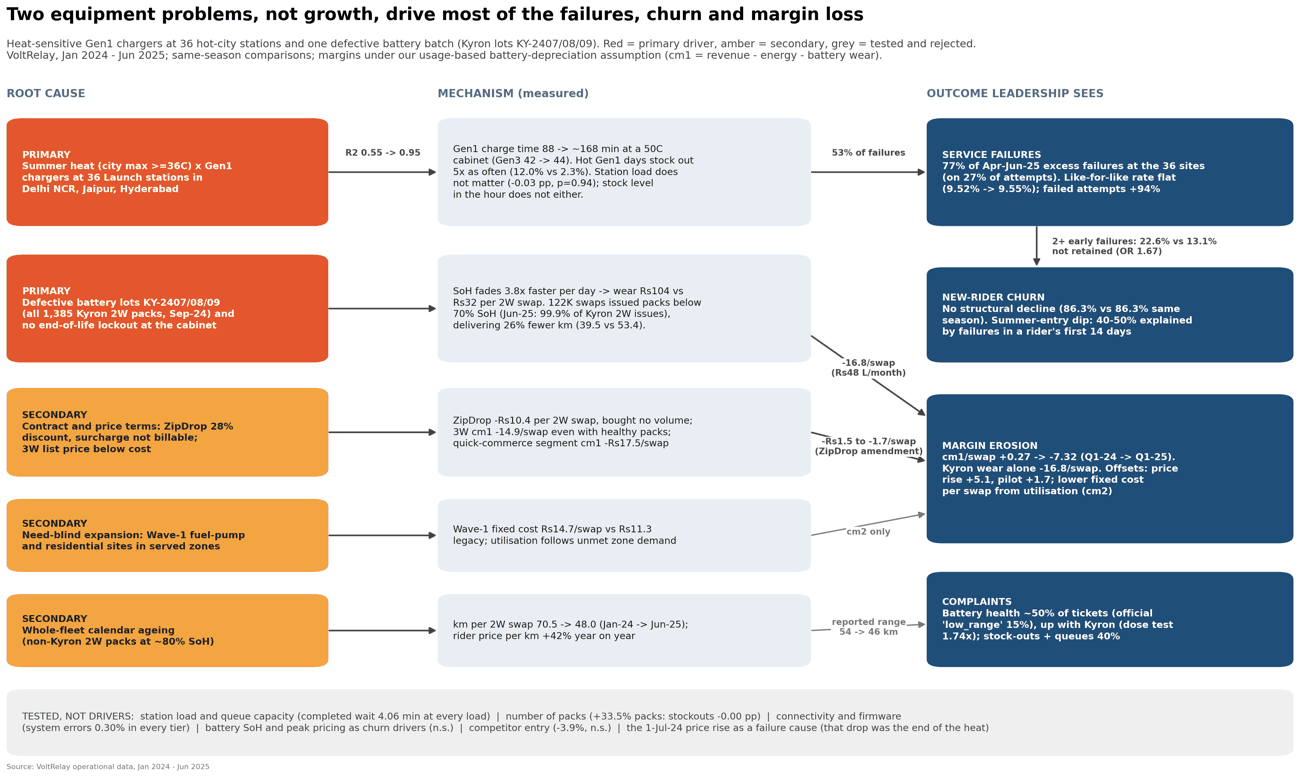

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q9_01_causal_chain.png')

In [192]:
C_PRI, C_SEC, C_MECH, C_OUT, C_NOT = PALETTE["accent"], PALETTE["warn"], "#E8EEF4", PALETTE["primary"], "#EFEFEF"


def box(ax, x, y, w, h, text, fc, tc="white", fs=10.5, weight="normal", ec="none"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.0,rounding_size=0.012", fc=fc, ec=ec, lw=1.0,
                                transform=ax.transAxes, clip_on=False))
    ax.text(x + 0.012, y + h / 2, text, ha="left", va="center", fontsize=fs, color=tc, weight=weight,
            transform=ax.transAxes, linespacing=1.3)
    return (x, y, w, h)


def link(ax, b1, b2, label=None, color="#4A4A4A", lw=1.8, ls="-", start="r", end="l", f1=0.5, f2=0.5,
         lab_dx=0.0, lab_dy=0.0, fs=9.5, ha="center"):
    """Arrow from side `start` of box b1 to side `end` of b2; f1/f2 = position along that side (0-1)."""
    pts = {"r": lambda b, f: (b[0] + b[2], b[1] + b[3] * f), "l": lambda b, f: (b[0], b[1] + b[3] * f),
           "b": lambda b, f: (b[0] + b[2] * f, b[1]), "t": lambda b, f: (b[0] + b[2] * f, b[1] + b[3])}
    (x1, y1), (x2, y2) = pts[start](b1, f1), pts[end](b2, f2)
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls, shrinkA=1, shrinkB=1, mutation_scale=15))
    if label:
        ax.text((x1 + x2) / 2 + lab_dx, (y1 + y2) / 2 + lab_dy, label, fontsize=fs, color=color, ha=ha, va="center",
                transform=ax.transAxes, bbox=dict(fc="white", ec="none", pad=1.0), weight="bold")


fig = plt.figure(figsize=(20, 11.5))
ax = fig.add_axes([0.01, 0.02, 0.98, 0.84]); ax.axis("off")
fig.text(0.01, 0.965, "Two equipment problems, not growth, drive most of the failures, churn and margin loss",
         fontsize=19, weight="bold", ha="left")
fig.text(0.01, 0.925, "Heat-sensitive Gen1 chargers at 36 hot-city stations and one defective battery batch (Kyron lots KY-2407/08/09). "
         "Red = primary driver, amber = secondary, grey = tested and rejected.\nVoltRelay, Jan 2024 - Jun 2025; same-season comparisons; "
         "margins under our usage-based battery-depreciation assumption (cm1 = revenue - energy - battery wear).",
         fontsize=11.5, color="#444444", ha="left", va="center")
for xh, txt in ((0.0, "ROOT CAUSE"), (0.335, "MECHANISM (measured)"), (0.715, "OUTCOME LEADERSHIP SEES")):
    ax.text(xh, 1.0, txt, fontsize=12, weight="bold", color="#5A6B7B", transform=ax.transAxes, va="bottom")
XD, WD, XM, WM, XO, WO = 0.0, 0.25, 0.335, 0.29, 0.715, 0.285
D1 = box(ax, XD, 0.80, WD, 0.17, "PRIMARY\nSummer heat (city max >=36C) x Gen1\nchargers at 36 Launch stations in\nDelhi NCR, Jaipur, Hyderabad", C_PRI, weight="bold")
D2 = box(ax, XD, 0.585, WD, 0.17, "PRIMARY\nDefective battery lots KY-2407/08/09\n(all 1,385 Kyron 2W packs, Sep-24) and\nno end-of-life lockout at the cabinet", C_PRI, weight="bold")
D3 = box(ax, XD, 0.405, WD, 0.14, "SECONDARY\nContract and price terms: ZipDrop 28%\ndiscount, surcharge not billable;\n3W list price below cost", C_SEC, tc="#222222", weight="bold")
D4 = box(ax, XD, 0.255, WD, 0.115, "SECONDARY\nNeed-blind expansion: Wave-1 fuel-pump\nand residential sites in served zones", C_SEC, tc="#222222", weight="bold")
D5 = box(ax, XD, 0.105, WD, 0.115, "SECONDARY\nWhole-fleet calendar ageing\n(non-Kyron 2W packs at ~80% SoH)", C_SEC, tc="#222222", weight="bold")
M1 = box(ax, XM, 0.80, WM, 0.17, "Gen1 charge time 88 -> ~168 min at a 50C\ncabinet (Gen3 42 -> 44). Hot Gen1 days stock out\n"
         "5x as often (12.0% vs 2.3%). Station load does\nnot matter (-0.03 pp, p=0.94); stock level\nin the hour does not either.", C_MECH, tc="#1B1B1B")
M2 = box(ax, XM, 0.585, WM, 0.17, "SoH fades 3.8x faster per day -> wear Rs104 vs\nRs32 per 2W swap. "
         f"{h25['post_eol_swaps']/1e3:.0f}K swaps issued packs below\n70% SoH (Jun-25: 99.9% of Kyron 2W issues),\n"
         "delivering 26% fewer km (39.5 vs 53.4).", C_MECH, tc="#1B1B1B")
M3 = box(ax, XM, 0.405, WM, 0.14, "ZipDrop -Rs10.4 per 2W swap, bought no volume;\n"
         f"3W cm1 {cm1_3w_ss:+.1f}/swap even with healthy packs;\nquick-commerce segment cm1 -Rs17.5/swap", C_MECH, tc="#1B1B1B")
M4 = box(ax, XM, 0.255, WM, 0.115, f"Wave-1 fixed cost Rs{w1['fixed_ps']:.1f}/swap vs Rs{lg['fixed_ps']:.1f}\nlegacy; "
         "utilisation follows unmet zone demand", C_MECH, tc="#1B1B1B")
M5 = box(ax, XM, 0.105, WM, 0.115, "km per 2W swap 70.5 -> 48.0 (Jan-24 -> Jun-25);\nrider price per km +42% year on year", C_MECH, tc="#1B1B1B")
O1 = box(ax, XO, 0.80, WO, 0.17, "SERVICE FAILURES\n"
         f"{hg25['sh_excess']:.0%} of Apr-Jun-25 excess failures at the 36 sites\n(on {hg25['sh_att']:.0%} of attempts). Like-for-like rate flat\n"
         f"({W['Q2-24']['launch_fail_rate']:.2%} -> {W['Q2-25']['launch_fail_rate']:.2%}); failed attempts "
         f"+{W['Q2-25']['failures']/W['Q2-24']['failures']-1:.0%}", C_OUT, weight="bold")
O2 = box(ax, XO, 0.585, WO, 0.15, "NEW-RIDER CHURN\nNo structural decline (86.3% vs 86.3% same\nseason). Summer-entry dip: 40-50% explained\nby failures in a rider's first 14 days", C_OUT, weight="bold")
O3 = box(ax, XO, 0.30, WO, 0.235, "MARGIN EROSION\n"
         f"cm1/swap {W['Q1-24']['cm1_ps']:+.2f} -> {W['Q1-25']['cm1_ps']:+.2f} (Q1-24 -> Q1-25).\n"
         f"Kyron wear alone {-W['Q1-25']['kyron_gap_ps']:+.1f}/swap. Offsets: price\nrise +5.1, pilot +1.7; lower fixed cost\nper swap from utilisation (cm2)", C_OUT, weight="bold")
O4 = box(ax, XO, 0.105, WO, 0.15, "COMPLAINTS\nBattery health ~50% of tickets (official\n'low_range' 15%), up with Kyron (dose test\n1.74x); stock-outs + queues 40%", C_OUT, weight="bold")
link(ax, D1, M1, "R2 0.55 -> 0.95", lab_dy=0.03)
link(ax, M1, O1, f"{hg25['sh_fail']:.0%} of failures", lab_dy=0.03)
link(ax, O1, O2, "2+ early failures: 22.6% vs 13.1%\nnot retained (OR 1.67)", start="b", end="t", f1=0.3, f2=0.3,
     lab_dx=0.012, fs=9.5, ha="left")
link(ax, D2, M2)
link(ax, M2, O3, f"{-W['Q1-25']['kyron_gap_ps']:+.1f}/swap\n(Rs{KY_GAP_PM/LAKH:.0f} L/month)", f1=0.25, f2=0.85, lab_dy=0.012)
link(ax, D3, M3)
link(ax, M3, O3, "-Rs1.5 to -1.7/swap\n(ZipDrop amendment)", f1=0.5, f2=0.55, lab_dy=0.0)
link(ax, D4, M4)
link(ax, M4, O3, "cm2 only", color="#7A7A7A", lw=1.4, f1=0.5, f2=0.2, lab_dy=-0.012)
link(ax, D5, M5)
link(ax, M5, O4, "reported range\n54 -> 46 km", color="#7A7A7A", lw=1.4, f1=0.5, f2=0.45, lab_dy=0.0)
box(ax, 0.0, -0.035, 1.0, 0.105,
    "TESTED, NOT DRIVERS:  station load and queue capacity (completed wait 4.06 min at every load)  |  number of packs (+33.5% packs: "
    "stockouts -0.00 pp)  |  connectivity and firmware\n(system errors 0.30% in every tier)  |  battery SoH and peak pricing as churn drivers "
    "(n.s.)  |  competitor entry (-3.9%, n.s.)  |  the 1-Jul-24 price rise as a failure cause (that drop was the end of the heat)",
    C_NOT, tc="#444444", fs=10.5)
save_fig(fig, f"{QID}_01_causal_chain")

## 10. Figure 2 - budget scorecard

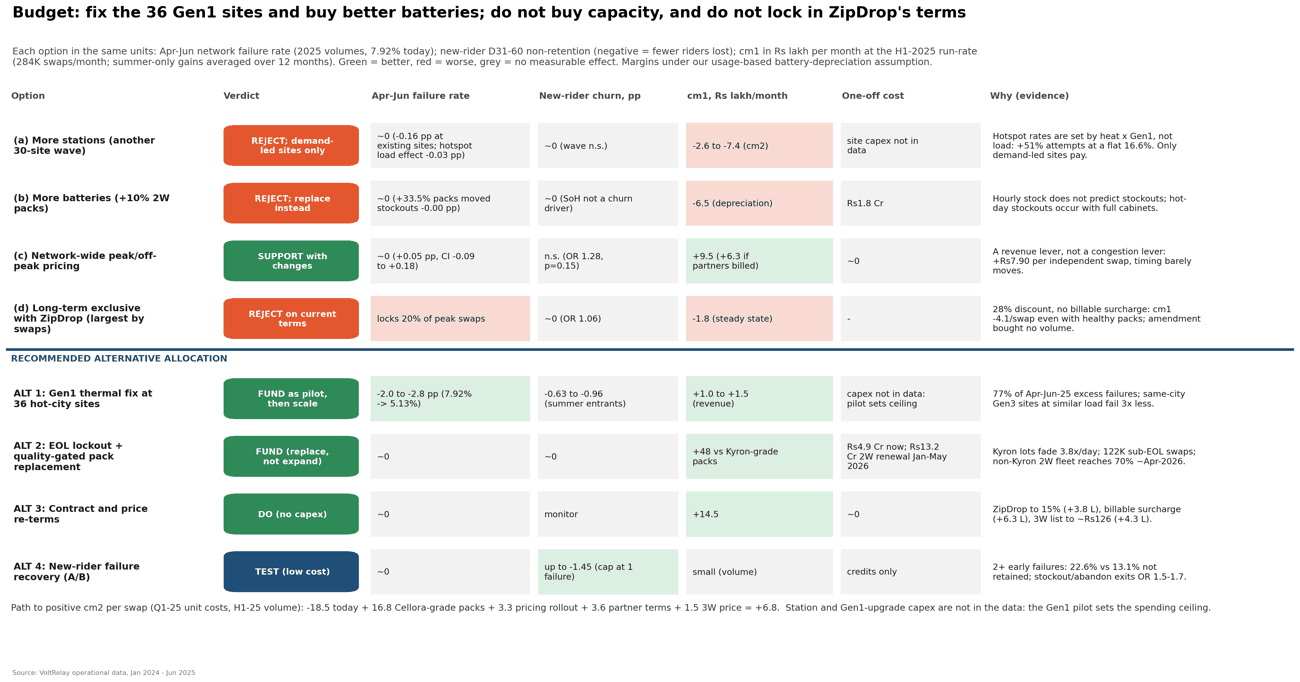

figures saved: q9_01_causal_chain.png q9_02_budget_decision.png


In [193]:
VERDICT_COL = {"REJECT": PALETTE["accent"], "SUPPORT": PALETTE["good"], "FUND": PALETTE["good"], "DO": PALETTE["good"],
               "TEST": PALETTE["primary"]}
GOOD, BAD, NEU = "#DCEFE3", "#F8DAD3", "#F2F2F2"


def tone(s):
    s = str(s).strip()
    if s.startswith("~0") or s in ("-", "monitor", "small (volume)", "~0 (wave n.s.)") or s.startswith("n.s") or s.startswith("locks") or s.startswith("site capex"):
        return NEU if not s.startswith("locks") else BAD
    if s.startswith("+") or s.startswith("up to -") or (s.startswith("-") and "pp" in s and "ALT" not in s):
        return GOOD
    return NEU


cols = [("option", "Option", 0.165), ("verdict", "Verdict", 0.115), ("fail_pp", "Apr-Jun failure rate", 0.13),
        ("ret_pp", "New-rider churn, pp", 0.115), ("cm1_lakh_pm", "cm1, Rs lakh/month", 0.12),
        ("oneoff", "One-off cost", 0.115), ("why", "Why (evidence)", 0.24)]
fig = plt.figure(figsize=(22, 11.2))
ax = fig.add_axes([0.005, 0.02, 0.99, 0.845]); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.text(0.01, 0.965, "Budget: fix the 36 Gen1 sites and buy better batteries; do not buy capacity, and do not lock in ZipDrop's terms",
         fontsize=18.5, weight="bold", ha="left")
fig.text(0.01, 0.905, f"Each option in the same units: Apr-Jun network failure rate (2025 volumes, {NET_AJ25:.2%} today); new-rider D31-60 "
         "non-retention (negative = fewer riders lost); cm1 in Rs lakh per month at the H1-2025 run-rate\n"
         f"({h25['swaps_pm']/1e3:.0f}K swaps/month; summer-only gains averaged over 12 months). Green = better, red = worse, grey = no measurable effect. "
         "Margins under our usage-based battery-depreciation assumption.", fontsize=11.5, color="#444444", ha="left", va="center")
y = 0.985
xs = np.cumsum([0] + [c[2] for c in cols])
for (k_, lab, w_), x0 in zip(cols, xs):
    ax.text(x0 + 0.004, y, lab, fontsize=11, weight="bold", color="#3A4A5A", va="top")
y -= 0.045
row_h = 0.103
for i, r in score_df.iterrows():
    if i == 4:
        ax.add_patch(Rectangle((0, y - 0.004), 1, 0.003, color="#1F4E79", transform=ax.transAxes))
        ax.text(0.004, y - 0.012, "RECOMMENDED ALTERNATIVE ALLOCATION", fontsize=11, weight="bold", color=PALETTE["primary"], va="top")
        y -= 0.04
    top = y
    for (k_, lab, w_), x0 in zip(cols, xs):
        val = str(r[k_])
        if k_ == "verdict":
            vc = next((c for kk, c in VERDICT_COL.items() if val.startswith(kk)), PALETTE["warn"])
            ax.add_patch(FancyBboxPatch((x0 + 0.004, top - row_h + 0.016), w_ - 0.01, row_h - 0.03,
                                        boxstyle="round,pad=0,rounding_size=0.01", fc=vc, ec="none", transform=ax.transAxes))
            ax.text(x0 + w_ / 2, top - row_h / 2, textwrap.fill(val, 17), fontsize=10.5, weight="bold", color="white",
                    ha="center", va="center")
        elif k_ in ("fail_pp", "ret_pp", "cm1_lakh_pm", "oneoff"):
            fc = tone(val) if k_ != "oneoff" else NEU
            if k_ == "cm1_lakh_pm" and val.startswith("-"):
                fc = BAD
            ax.add_patch(Rectangle((x0 + 0.003, top - row_h + 0.012), w_ - 0.006, row_h - 0.022, fc=fc, ec="none", transform=ax.transAxes))
            ax.text(x0 + 0.008, top - row_h / 2, textwrap.fill(val, 23 if w_ >= 0.125 else 21), fontsize=10.5, va="center", color="#1B1B1B")
        else:
            wrapw = 27 if k_ == "option" else 46
            ax.text(x0 + 0.006, top - row_h / 2, textwrap.fill(val, wrapw), fontsize=10.5 if k_ == "why" else 11.5,
                    weight="bold" if k_ == "option" else "normal", va="center", color="#1B1B1B")
    y -= row_h
ax.text(0.004, y - 0.005, f"Path to positive cm2 per swap (Q1-25 unit costs, H1-25 volume): {cm2_path['start']:+.1f} today "
        f"+ {cm2_path['kyron']:.1f} Cellora-grade packs + {cm2_path['rollout']:.1f} pricing rollout + {cm2_path['partner']:.1f} partner terms "
        f"+ {cm2_path['three_w']:.1f} 3W price = {cm2_path['end']:+.1f}.  Station and Gen1-upgrade capex are not in the data: "
        "the Gen1 pilot sets the spending ceiling.", fontsize=11, color="#333333", va="top")
save_fig(fig, f"{QID}_02_budget_decision")
print("figures saved:", f"{QID}_01_causal_chain.png", f"{QID}_02_budget_decision.png")

### Two closing visuals for the budget discussion
1. **Path to a positive cm2 per swap**: the margin effect of the recommended levers, in rupees per swap (values printed by
   the synthesis script above, at Q1-2025 unit costs and H1-2025 volume).
2. **Fleet end-of-life timeline**: when each battery pack is projected to cross 70% state of health, from its own calendar
   fade. This is why the battery budget is about *replacement*, not expansion.

path: start -18.48 | kyron 16.82 | rollout 3.34 | partner 3.58 | 3W 1.52 | end 6.79


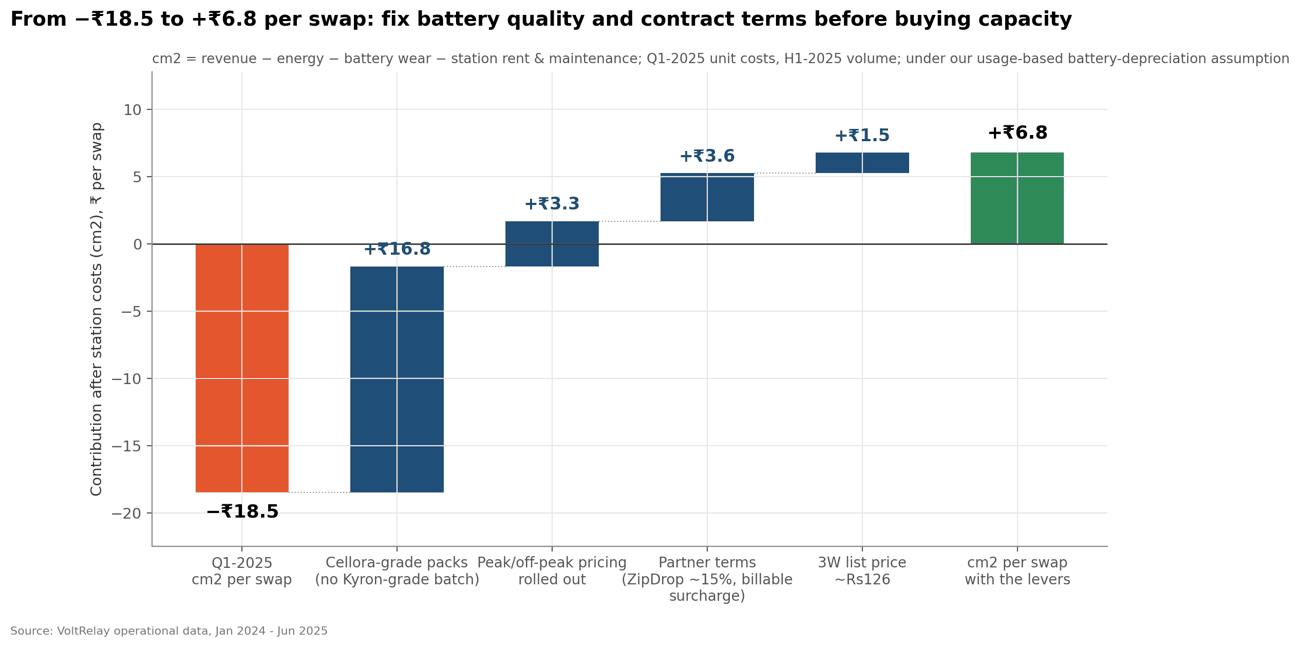

WindowsPath('F:/Data Analytics Gradient Learning/outputs/figures/q10_01_path_to_positive_cm2.png')

In [194]:
import re, sys, datetime as dt
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
try:
    from common import batteries, set_style, save_fig, PALETTE, TAB, EOL_SOH
except ImportError:
    sys.path.insert(0, str(Path.cwd() / "src")); from common import batteries, set_style, save_fig, PALETTE, TAB, EOL_SOH

set_style()
log = (TAB / "q9_run_log.txt").read_text(encoding="utf-8")
m = re.search(r"cm2 per swap path \(Rs\): start ([-+\d.]+), kyron ([-+\d.]+), rollout ([-+\d.]+), partner ([-+\d.]+), three_w ([-+\d.]+), end ([-+\d.]+)", log)
start, kyron, rollout, partner, three_w, end = map(float, m.groups())
print(f"path: start {start} | kyron {kyron} | rollout {rollout} | partner {partner} | 3W {three_w} | end {end}")

steps = [("Q1-2025\ncm2 per swap", start, "total"),
         ("Cellora-grade packs\n(no Kyron-grade batch)", kyron, "step"),
         ("Peak/off-peak pricing\nrolled out", rollout, "step"),
         ("Partner terms\n(ZipDrop ~15%, billable\nsurcharge)", partner, "step"),
         ("3W list price\n~Rs126", three_w, "step"),
         ("cm2 per swap\nwith the levers", end, "total")]
fig, ax = plt.subplots(figsize=(12, 6))
level = 0.0
for i, (lab, val, kind) in enumerate(steps):
    if kind == "total":
        color = PALETTE["accent"] if val < 0 else PALETTE["good"]
        ax.bar(i, val, color=color, width=0.6)
        ax.text(i, val + (0.8 if val >= 0 else -0.8), f"{'+' if val > 0 else '−'}₹{abs(val):.1f}", ha="center",
                va="bottom" if val >= 0 else "top", fontsize=13, fontweight="bold")
        level = val
    else:
        ax.bar(i, val, bottom=level, color=PALETTE["primary"], width=0.6)
        ax.text(i, level + val + 0.6, f"+₹{val:.1f}", ha="center", va="bottom", fontsize=12, fontweight="bold", color=PALETTE["primary"])
        ax.plot([i - 0.7, i - 0.3], [level, level], color="#999", lw=0.8, ls=":")
        level += val
ax.axhline(0, color="#333", lw=1)
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=10)
ax.set_ylabel("Contribution after station costs (cm2), ₹ per swap")
ax.set_ylim(min(start, 0) - 4, max(end, 0) + 6)
fig.suptitle(f"From −₹{abs(start):.1f} to +₹{end:.1f} per swap: fix battery quality and contract terms before buying capacity",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
ax.set_title("cm2 = revenue − energy − battery wear − station rent & maintenance; Q1-2025 unit costs, H1-2025 volume; "
             "under our usage-based battery-depreciation assumption", fontsize=9.5, color="#555", loc="left", fontweight="normal")
save_fig(fig, "q10_01_path_to_positive_cm2")

shape: (3, 5)
┌──────────────────────────┬───────┬─────────┬─────────────────────┬──────────────────┐
│ grp                      ┆ packs ┆ cost_cr ┆ median_eol          ┆ already_below_70 │
│ ---                      ┆ ---   ┆ ---     ┆ ---                 ┆ ---              │
│ str                      ┆ u32   ┆ f64     ┆ datetime[μs]        ┆ u32              │
╞══════════════════════════╪═══════╪═════════╪═════════════════════╪══════════════════╡
│ Cellora/Amptek/other 2W  ┆ 4133  ┆ 13.2200 ┆ 2026-04-01 00:00:00 ┆ 0                │
│ Cellora/Amptek/other 3W  ┆ 906   ┆ 6.1500  ┆ 2027-06-01 00:00:00 ┆ 0                │
│ Kyron lots KY-2407/08/09 ┆ 1461  ┆ 4.9500  ┆ 2025-06-01 00:00:00 ┆ 1439             │
└──────────────────────────┴───────┴─────────┴─────────────────────┴──────────────────┘


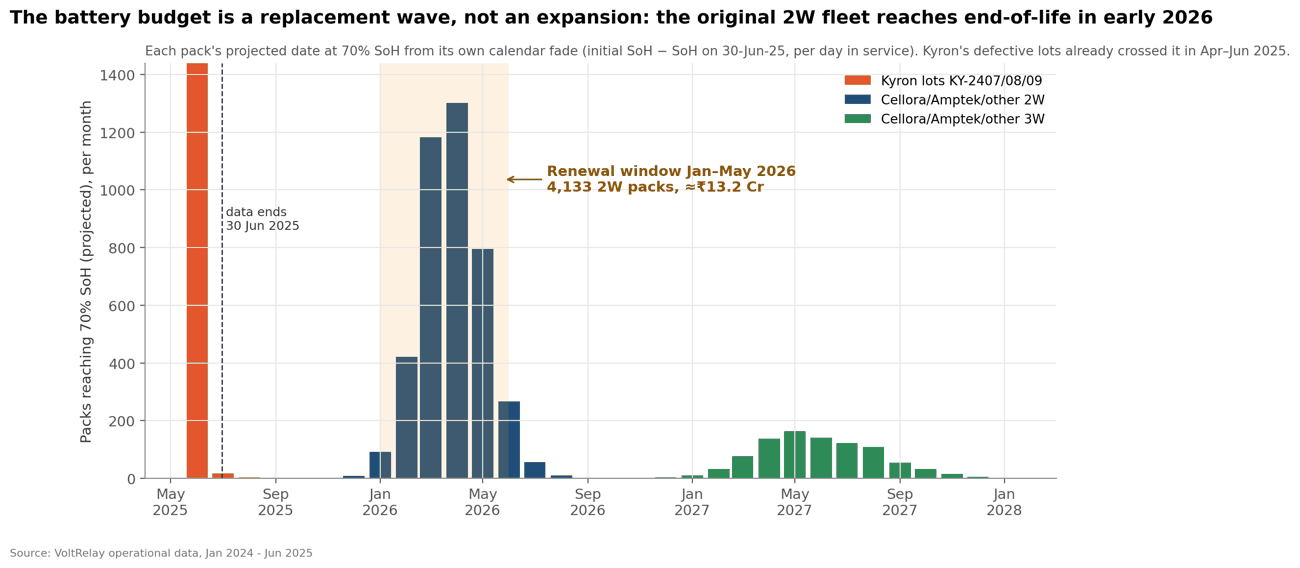

extra visuals done


In [195]:
bt = batteries()
asof = dt.datetime(2025, 6, 30)
b = (bt.with_columns(((pl.lit(asof) - pl.col("first_seen")).dt.total_days()).alias("days_in_service"))
     .with_columns(((pl.col("initial_soh_pct") - pl.col("current_soh_pct")) / pl.col("days_in_service")).alias("fade_pd"))
     .with_columns(pl.when(pl.col("current_soh_pct") <= EOL_SOH).then(0.0)
                   .otherwise((pl.col("current_soh_pct") - EOL_SOH) / pl.col("fade_pd")).alias("days_to_eol"))
     .with_columns(pl.when(pl.col("manufacturing_lot").is_in(["KY-2407", "KY-2408", "KY-2409"])).then(pl.lit("Kyron lots KY-2407/08/09"))
                   .otherwise(pl.concat_str([pl.lit("Cellora/Amptek/other "), pl.col("vehicle_class")])).alias("grp")))
b = b.with_columns((pl.lit(asof) + pl.duration(days=pl.col("days_to_eol").round(0).cast(pl.Int64))).dt.truncate("1mo").alias("eol_month"))
summary = (b.group_by("grp").agg(pl.len().alias("packs"), (pl.col("purchase_cost_inr").sum() / 1e7).round(2).alias("cost_cr"),
                                 pl.col("eol_month").quantile(0.5, "nearest").alias("median_eol"),
                                 (pl.col("current_soh_pct") <= EOL_SOH).sum().alias("already_below_70")).sort("grp"))
print(summary)
monthly = b.group_by("grp", "eol_month").len().sort("eol_month")
fig, ax = plt.subplots(figsize=(12, 5.5))
colors = {"Kyron lots KY-2407/08/09": PALETTE["accent"], "Cellora/Amptek/other 2W": PALETTE["primary"], "Cellora/Amptek/other 3W": PALETTE["good"]}
months = sorted(set(monthly["eol_month"].to_list()))
bottom = np.zeros(len(months))
for g, col in colors.items():
    s = monthly.filter(pl.col("grp") == g)
    lookup = dict(zip(s["eol_month"].to_list(), s["len"].to_list()))
    vals = np.array([lookup.get(mm, 0) for mm in months])
    ax.bar(months, vals, bottom=bottom, width=25, color=col, label=g)
    bottom += vals
ax.axvspan(dt.datetime(2026, 1, 1), dt.datetime(2026, 5, 31), color=PALETTE["warn"], alpha=0.15, lw=0)
r2w = summary.filter(pl.col("grp") == "Cellora/Amptek/other 2W")
ax.annotate(f"Renewal window Jan–May 2026\n{int(r2w['packs'][0]):,} 2W packs, ≈₹{float(r2w['cost_cr'][0]):.1f} Cr",
            xy=(dt.datetime(2026, 5, 25), ax.get_ylim()[1] * 0.72), xytext=(dt.datetime(2026, 7, 15), ax.get_ylim()[1] * 0.72),
            ha="left", va="center", fontsize=10.5, color="#8a5a00", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#8a5a00", lw=1.2))
ax.axvline(asof, color="#333", ls="--", lw=1)
ax.text(asof, ax.get_ylim()[1] * 0.6, " data ends\n 30 Jun 2025", fontsize=9, color="#333")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylabel("Packs reaching 70% SoH (projected), per month")
ax.legend(loc="upper right")
fig.suptitle("The battery budget is a replacement wave, not an expansion: the original 2W fleet reaches end-of-life in early 2026",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
ax.set_title("Each pack's projected date at 70% SoH from its own calendar fade (initial SoH − SoH on 30-Jun-25, per day in service). "
             "Kyron's defective lots already crossed it in Apr–Jun 2025.", fontsize=9.5, color="#555", loc="left", fontweight="normal")
save_fig(fig, "q10_02_fleet_eol_timeline")
print("extra visuals done")

## 13. Conclusions and recommendations

**How the network is performing.** Volume and revenue grew strongly (2.43× and 2.63× year on year). Reliability is stable
like-for-like but swings with the summer heat, and unit margin turned negative from September 2024.

**What drives the outcomes, primary first**
| Outcome | Primary driver | Secondary | Not a driver |
|---|---|---|---|
| Service failures | Summer heat × Gen1 chargers (36 hot-city stations) | 3W riders; Gen2 heat sensitivity | Load, queue capacity, pack count, connectivity, firmware |
| New-rider churn | 2+ early stockouts / abandons (OR 1.67) | Competitor nearby; 3W; a failed first attempt | Battery health, price, queue time, tickets, channel, KYC |
| Margin erosion | Defective battery lots KY-2407/08/09 | ZipDrop 28% discount; 3W priced below cost; Wave-1 fixed cost | Energy and fixed cost (both fell), pricing (added revenue) |

**Recommendations, in priority order**
1. **Battery quality reset**: end-of-life lockout in cabinet firmware, pull and replace the defective lots, file a ₹3.4–3.6 Cr warranty
   claim, gate each new lot on its first 6–8 weeks of fade, and plan the 2026 fleet renewal (≈ ₹13 Cr).
2. **Gen1 thermal fix** at the 36 hot-city stations before April 2026 (pilot, then scale): 19,000–27,000 fewer failed attempts per summer.
3. **Summer heat playbook** triggered by a forecast maximum of 36 °C, focused on 19:00–22:00 at hot-city Gen1 sites.
4. **New-rider failure recovery** A/B test: up to −1.45 pp non-retention.
5. **Contract and price re-terms**: ZipDrop to ~15%, billable surcharge for all partners, 3W towards ₹126 (≈ +₹14.5 lakh a month).
6. **Roll out peak/off-peak pricing** for revenue (≈ +₹9.5 lakh a month); do **not** sign the ZipDrop exclusive on current terms.
7. **Fix the instruments**: same-station and same-season KPIs, D31–60 retention, a battery ticket category, and wear that stops
   at end-of-life in the cost model.

*Limitations*: observational data (designs chosen to get close to cause, but not experiments); margin levels depend on the
battery-depreciation assumption, though trends hold under every variant; charger generation is confounded with site age, so the
Gen1 fix should be piloted first.

**Team Praise**: Shubham Suman, Durgesh Kumar
